# Deep Hedging under Classical and Lifted-Heston Volatility Models

This notebook is the empirical research pipeline for the dissertation. It compares classical Heston, lifted Heston, analytic hedging rules, no-trade-band benchmarks and neural hedging policies under a common stock-only SPX hedging design. The purpose is not to prove that one volatility model is universally superior. The purpose is narrower and more defensible: to test whether volatility-memory information represented by lifted-Heston factors improves implementable terminal hedging performance after calibration quality, transaction costs, maturity dependence, tail risk and model-transfer behaviour are all made visible.

The notebook separates two objects that are often blurred in volatility-model work. A calibration problem asks whether a parameter vector $\Theta$ makes model implied volatilities close to market implied volatilities on a chosen option panel. A hedging problem asks whether a trading policy $\pi$ reduces pathwise terminal risk after costs. These are related, but not equivalent. A model can fit a smile well and still produce poor hedge dynamics; a policy can hedge well on a near-ATM liquid panel even when its model is not a global SPX surface model.

The three empirical questions are:

1. **Calibration evidence:** do Heston and lifted Heston fit the option-market objects that matter for this study, especially near-ATM smiles, short maturities and ATM skew?
2. **Hedging evidence:** do analytic and neural policies reduce terminal net hedging error once proportional trading costs are included?
3. **Mechanism evidence:** do lifted factors add information beyond scalar variance and beyond memory learned by recurrent networks?

The notebook should be read as a data-driven dissertation chapter in executable form. Each section states the methodological role of the outputs, saves dissertation artefacts, and records limitations where the cached data do not support a requested diagnostic. No synthetic prices, fake IVs, or unsupported empirical charts are used.


# 0. Research Overview and Empirical Design

The research design is built around a controlled comparison of **state representation** rather than a loose tournament between models. Classical Heston supplies a one-dimensional variance state $V_t$. Lifted Heston supplies a finite vector of factors $(U_t^1,\ldots,U_t^N)$ whose weighted sum gives the aggregate variance. Neural policies are then evaluated under different information sets: scalar variance, lifted aggregate variance, raw lifted factors, compressed lifted features and recurrent hidden states.

The empirical design therefore has two layers. The first layer constructs calibrated market states from SPX option data. This layer asks whether the models are credible enough as simulators and state generators. The second layer evaluates hedging policies using terminal net hedging error under proportional transaction costs. This layer asks whether the information embedded in those states is useful for trading.

The distinction matters because the dissertation does **not** claim that lifted Heston is the best global model of SPX option prices. The global surface diagnostic is retained as a stress test and limitation. The headline experiment is the hedging-focused near-ATM panel, where the traded objects are liquid and closer to the option exposures used in the policy evaluation.

The governing empirical logic is:

$$
\text{market surface} \rightarrow \text{calibrated model state} \rightarrow \text{simulated hedging paths} \rightarrow \text{terminal net hedging error}.
$$

The notebook outputs should support this chain. Calibration charts explain the quality and limits of the state construction. Hedging charts explain realised risk-cost trade-offs. Mechanism diagnostics explain whether lifted factors appear to contain information beyond scalar variance.


## 0.1 Notebook Structure Audit and Refactoring Decision

This section records the structural decision behind the refactor. The notebook previously contained several audit-like and diagnostic-like cells that overlapped in purpose: some checked calibration readiness, some checked artefact existence, and some repeated final evidence gates. That made the notebook look safer than it was. Repeating similar checks is not methodology; it can obscure the actual evidential role of each check.

The refactored structure keeps a single coherent research pipeline and one final evidence gate. Diagnostics are placed where they are methodologically useful. Surface coverage belongs in the data section. Forward-variance checks belong near model initialisation. Calibration residuals, ATM skew and smile plots belong in the calibration-diagnostics section. Hedging error distributions, confidence intervals, turnover and transaction costs belong in evaluation. Lifted-factor composition and future-variance tests belong in mechanism diagnostics.

Section 5.4 is retained because it answers a core calibration question: whether lifted Heston improves the market objects it is theoretically supposed to improve, especially short-end skew and near-ATM smile shape. It is no longer treated as a generic catch-all section. It is reframed as **Skew, Smile and Calibration Model-Selection Diagnostics**. Its role is to connect the theory of rough/lifted volatility to observable option-surface evidence, while explicitly separating static fit from hedging value.

The decision rule is simple. A section remains only if it supports one of the three dissertation questions: calibration evidence, hedging evidence, or mechanism evidence. Outputs that are merely technically interesting but not argument-relevant are removed, merged, or marked as appendix diagnostics.


A later visualisation refactor adds a single Matplotlib dissertation theme, a save-and-show contract for every figure, a 3D volatility-surface section, and a final figure inventory. This is intentionally separate from model methodology, because aesthetics should not smuggle in new empirical claims.

# 1. Imports, Configuration, and Reproducibility

This section defines the execution environment and the central configuration object. The configuration is intentionally treated as part of the methodology rather than as boilerplate. Values such as maturity windows, moneyness filters, transaction-cost levels, number of paths, calibration flags and cache policy determine the empirical claim. They should be visible, centralised and auditable.

The key reproducibility principle is that expensive upstream artefacts are loaded rather than rebuilt during cached evaluation. Surface construction, hedging-panel construction, Heston calibration, lifted-Heston calibration, tensor banks and trained-policy outputs are different methodological stages. Evaluation should not secretly recalibrate models or rebuild panels just because a downstream plot is requested. If a cache is missing or stale, the notebook should fail clearly and tell the reader which prior stage must be run.

The configuration also separates **research design parameters** from **runtime switches**. Design parameters define the experiment, for example the near-ATM window, maturity buckets and transaction-cost grid. Runtime switches determine whether to rebuild or load artefacts. This distinction prevents accidental changes to the empirical design when the user only wants to regenerate figures.

The expected cached-evaluation flow is:

$$
\text{load surface} \rightarrow \text{load hedging panel} \rightarrow \text{load calibrations} \rightarrow \text{load policies/evaluation outputs} \rightarrow \text{produce dissertation tables and figures}.
$$

This section therefore acts as the notebook's contract with the dissertation reader: the reported results depend on explicit settings, deterministic splits and named artefacts rather than invisible state.


In [1]:
from __future__ import annotations

import gc
import hashlib
import json
import math
import os
import random
import re
import shutil
import time
import warnings
from functools import lru_cache
from datetime import datetime, timezone
from dataclasses import asdict, dataclass, field, replace
from pathlib import Path
from typing import Any, Callable, Iterable, Literal

import numpy as np
import pandas as pd
from IPython.display import display

try:
    import pyarrow.dataset as ds
    import pyarrow.parquet as pq
    PYARROW_AVAILABLE = True
except ImportError as exc:  # optional dependency
    PYARROW_AVAILABLE = False
    ds = None
    pq = None
    warnings.warn(f"PyArrow unavailable; memory-safe parquet streaming is disabled: {exc}")

try:
    import scipy
    from scipy.integrate import quad
    from scipy.optimize import brentq, minimize, lsq_linear
    from scipy.special import gamma
    SCIPY_AVAILABLE = True
except ImportError as exc:  # optional dependency
    SCIPY_AVAILABLE = False
    warnings.warn(f"SciPy unavailable: {exc}")

try:
    import matplotlib.pyplot as plt
    MATPLOTLIB_AVAILABLE = True
except ImportError as exc:  # optional dependency
    MATPLOTLIB_AVAILABLE = False
    warnings.warn(f"Matplotlib unavailable: {exc}")

try:
    from sklearn.decomposition import PCA
    from sklearn.linear_model import Ridge
    from sklearn.metrics import r2_score
    SKLEARN_AVAILABLE = True
except ImportError as exc:  # optional dependency
    SKLEARN_AVAILABLE = False
    warnings.warn(f"scikit-learn unavailable: {exc}")

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    TORCH_AVAILABLE = True
except ImportError as exc:  # optional dependency
    TORCH_AVAILABLE = False
    torch = None
    nn = None
    F = None
    warnings.warn(f"PyTorch unavailable: {exc}")

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)
warnings.filterwarnings("default")

try:
    from tqdm.auto import tqdm
except ImportError:  # optional progress display
    def tqdm(iterable=None, **kwargs):
        return iterable if iterable is not None else []


c:\Users\lhkke\OneDrive - Queen Mary, University of London\Documents\Dissertation\Deep-Hedging-under-Lifted-Heston-MSc-Dissertation-\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# ============================================================
# Dissertation-wide Matplotlib theme, visual grammar, and save/show contract
# ============================================================

# The theme is deliberately print-oriented: thin lines, small legends, high-contrast
# colour-blind-safe model colours and explicit line styles. It is not grayscale, because
# apparently dissertation figures should not resemble security-camera footage of a spreadsheet.
DISSERTATION_MPL_STYLE = {
    "figure.figsize": (7.2, 4.2),
    "figure.dpi": 130,
    "savefig.dpi": 320,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.06,
    "font.size": 9.0,
    "axes.titlesize": 10.0,
    "axes.labelsize": 9.0,
    "xtick.labelsize": 8.0,
    "ytick.labelsize": 8.0,
    "legend.fontsize": 6.8,
    "legend.title_fontsize": 7.2,
    "legend.frameon": True,
    "legend.framealpha": 0.88,
    "legend.edgecolor": "#cbd5e1",
    "legend.borderpad": 0.25,
    "legend.handlelength": 1.65,
    "legend.handletextpad": 0.45,
    "legend.labelspacing": 0.28,
    "legend.columnspacing": 0.75,
    "lines.linewidth": 1.05,
    "lines.markersize": 3.2,
    "lines.markeredgewidth": 0.55,
    "patch.linewidth": 0.55,
    "axes.linewidth": 0.65,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "grid.linewidth": 0.42,
    "grid.color": "#94a3b8",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.axisbelow": True,
    "axes.facecolor": "white",
    "figure.facecolor": "white",
    "axes.titlepad": 6.0,
    "axes.labelpad": 4.0,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 3.0,
    "ytick.major.size": 3.0,
}

# Okabe-Ito-inspired palette, extended for policy families. Only no-hedge stays neutral.
MODEL_ALPHA = 0.80
BAR_ALPHA = 0.78
SCATTER_ALPHA = 0.72

# Light dissertation palette reused consistently throughout the notebook.
MODEL_COLORS = {
    "market": "#5B6472",
    "observed": "#5B6472",
    "heston": "#7BB6E6",
    "lifted": "#F3A26D",
    "lifted_heston": "#F3A26D",
    "black_scholes": "#7CCBA2",
    "bs_delta": "#7CCBA2",
    "neural_scalar": "#C8A2D8",
    "neural_factors": "#F4C06A",
    "gru": "#79C8C2",
    "lstm": "#9DB4E0",
    "no_hedge": "#B5BDC8",
    "no_trade_band": "#D8B07C",
    "model_delta": "#74B8B0",
    "residual_negative": "#6FA8DC",
    "residual_positive": "#F4A261",
}

MODEL_MARKERS = {
    "market": "o",
    "observed": "o",
    "heston": "s",
    "lifted": "^",
    "lifted_heston": "^",
    "black_scholes": "D",
    "bs_delta": "D",
    "neural_scalar": "P",
    "neural_factors": "X",
    "gru": "v",
    "lstm": "<",
    "no_hedge": "x",
    "no_trade_band": "h",
    "model_delta": "d",
}

MODEL_LINESTYLES = {
    "market": "None",
    "observed": "None",
    "heston": "-",
    "lifted": "-",
    "lifted_heston": "-",
    "black_scholes": "-",
    "bs_delta": "-",
    "neural_scalar": "-",
    "neural_factors": "-",
    "gru": "-",
    "lstm": "-",
    "no_hedge": "-",
    "no_trade_band": "-",
    "model_delta": "-",
}

POLICY_DISPLAY_ORDER = [
    "no_hedge",
    "black_scholes",
    "bs_delta",
    "model_delta",
    "no_trade_band",
    "heston",
    "lifted_heston",
    "neural_scalar",
    "neural_factors",
    "gru",
    "lstm",
]

MODEL_DISPLAY = globals().get("MODEL_DISPLAY", {}) | {
    "market": "Market",
    "observed": "Observed market",
    "heston": "Heston",
    "lifted": "Lifted Heston",
    "lifted_heston": "Lifted Heston",
    "black_scholes": "Black-Scholes",
    "bs_delta": "Black-Scholes delta",
    "neural_scalar": "Neural scalar",
    "neural_factors": "Neural factors",
    "gru": "GRU",
    "lstm": "LSTM",
    "no_hedge": "No hedge",
    "no_trade_band": "No-trade band",
    "model_delta": "Model delta",
}

try:
    from matplotlib.colors import LinearSegmentedColormap
except Exception:
    LinearSegmentedColormap = None

if LinearSegmentedColormap is not None:
    BLUE_ORANGE_SEQ = LinearSegmentedColormap.from_list("blue_orange_seq", ["#EAF2FB", "#BFD7EE", "#7BB6E6", "#F5CBA7", "#F3A26D"])
    BLUE_ORANGE_DIVERGING = LinearSegmentedColormap.from_list("blue_orange_div", ["#7BB6E6", "#EAF2FB", "#FFF7ED", "#F8C7A4", "#F3A26D"])
else:
    BLUE_ORANGE_SEQ = "coolwarm"
    BLUE_ORANGE_DIVERGING = "coolwarm"

SEQUENTIAL_CMAP = BLUE_ORANGE_SEQ
SIGNED_RESIDUAL_CMAP = BLUE_ORANGE_DIVERGING
COUNT_CMAP = BLUE_ORANGE_SEQ
ERROR_CMAP = BLUE_ORANGE_SEQ
WINRATE_CMAP = BLUE_ORANGE_DIVERGING


def _normalise_style_key(name: object) -> str:
    s = str(name).strip().lower().replace("-", "_").replace(" ", "_")
    if "lifted" in s:
        return "lifted_heston"
    if "heston" in s:
        return "heston"
    if "black" in s or s in {"bs", "bs_delta"}:
        return "black_scholes"
    if "no_trade" in s or "band" in s:
        return "no_trade_band"
    if "no_hedge" in s or s == "none":
        return "no_hedge"
    if "gru" in s:
        return "gru"
    if "lstm" in s:
        return "lstm"
    if "factor" in s:
        return "neural_factors"
    if "neural" in s or "scalar" in s:
        return "neural_scalar"
    if "market" in s or "observed" in s:
        return "market"
    if "delta" in s:
        return "model_delta"
    return s


def model_color(name: object, default: str = "#4b5563") -> str:
    return MODEL_COLORS.get(_normalise_style_key(name), default)


def model_marker(name: object, default: str = "o") -> str:
    return MODEL_MARKERS.get(_normalise_style_key(name), default)


def model_linestyle(name: object, default: str = "-") -> str | tuple:
    return MODEL_LINESTYLES.get(_normalise_style_key(name), default)


def set_dissertation_plot_theme() -> None:
    """Apply the notebook-wide academic Matplotlib style."""
    if not MATPLOTLIB_AVAILABLE:
        return
    plt.rcParams.update(DISSERTATION_MPL_STYLE)
    try:
        from cycler import cycler
        cycle = [
            MODEL_COLORS["market"],
            MODEL_COLORS["heston"],
            MODEL_COLORS["lifted_heston"],
            MODEL_COLORS["black_scholes"],
            MODEL_COLORS["neural_scalar"],
            MODEL_COLORS["neural_factors"],
            MODEL_COLORS["gru"],
            MODEL_COLORS["lstm"],
            MODEL_COLORS["no_trade_band"],
        ]
        plt.rcParams["axes.prop_cycle"] = cycler(color=cycle)
    except Exception:
        pass



try:
    from matplotlib.colors import TwoSlopeNorm, Normalize
except Exception:
    TwoSlopeNorm = None
    Normalize = None

FIGURE_ARTIFACT_REGISTRY: list[dict[str, Any]] = []


def register_figure_artifact(
    path: Path | str,
    *,
    figure_id: str | None = None,
    description: str = "",
    notebook_section: str = "",
    source_data: str = "",
    displayed_in_notebook: bool = True,
    recommendation: str = "main/appendix",
    notes: str = "",
) -> Path:
    p = Path(path)
    row = {
        "figure_id": figure_id or p.stem,
        "description": description or p.stem.replace("_", " "),
        "notebook_section": notebook_section,
        "source_data_table_cache": source_data,
        "saved_filename": str(p),
        "displayed_in_notebook": "yes" if displayed_in_notebook else "no",
        "main_text_or_appendix": recommendation,
        "notes": notes,
    }
    FIGURE_ARTIFACT_REGISTRY.append(row)
    return p


def save_and_show_figure(
    fig,
    path: Path | str,
    *,
    dpi: int = 320,
    bbox_inches: str = "tight",
    close: bool = False,
    figure_id: str | None = None,
    description: str = "",
    notebook_section: str = "",
    source_data: str = "",
    recommendation: str = "main/appendix",
    notes: str = "",
) -> Path:
    """Save a figure and display it in the notebook output. Default: do not close it."""
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    try:
        fig.tight_layout()
    except Exception:
        pass
    fig.savefig(p, dpi=dpi, bbox_inches=bbox_inches)
    plt.show()
    register_figure_artifact(
        p,
        figure_id=figure_id,
        description=description,
        notebook_section=notebook_section,
        source_data=source_data,
        displayed_in_notebook=True,
        recommendation=recommendation,
        notes=notes,
    )
    if close and MATPLOTLIB_AVAILABLE:
        # Explicit exception only; the dissertation notebook should normally show figures.
        plt.close(fig)
    return p


def compact_legend(ax, *, ncol: int | None = None, loc: str = "best", title: str | None = None):
    """Small, print-safe legend used across dissertation figures."""
    handles, labels = ax.get_legend_handles_labels()
    labels = [lab for lab in labels if lab and not lab.startswith("_")]
    if not labels:
        return None
    if ncol is None:
        ncol = 2 if len(labels) > 4 else 1
    return ax.legend(
        loc=loc,
        ncol=ncol,
        title=title,
        fontsize=DISSERTATION_MPL_STYLE["legend.fontsize"],
        title_fontsize=DISSERTATION_MPL_STYLE["legend.title_fontsize"],
        frameon=True,
        framealpha=DISSERTATION_MPL_STYLE["legend.framealpha"],
        borderpad=DISSERTATION_MPL_STYLE["legend.borderpad"],
        handlelength=DISSERTATION_MPL_STYLE["legend.handlelength"],
        handletextpad=DISSERTATION_MPL_STYLE["legend.handletextpad"],
        labelspacing=DISSERTATION_MPL_STYLE["legend.labelspacing"],
        columnspacing=DISSERTATION_MPL_STYLE["legend.columnspacing"],
    )


def standardise_axis(ax, *, title: str | None = None, xlabel: str | None = None, ylabel: str | None = None, legend: bool = False, ncol: int | None = None) -> None:
    if title:
        ax.set_title(title)
    if xlabel:
        ax.set_xlabel(xlabel)
    if ylabel:
        ax.set_ylabel(ylabel)
    ax.grid(True, alpha=float(DISSERTATION_MPL_STYLE.get("grid.alpha", 0.18)))
    if legend:
        compact_legend(ax, ncol=ncol)


def sort_policy_labels(labels: Iterable[object]) -> list[str]:
    labels = [str(x) for x in labels]
    order = {name: i for i, name in enumerate(POLICY_DISPLAY_ORDER)}
    return sorted(labels, key=lambda x: (order.get(_normalise_style_key(x), 999), x))


def _format_heatmap_value(value: float, fmt: str | None = None) -> str:
    if not np.isfinite(value):
        return ""
    if fmt is not None:
        return format(value, fmt)
    if abs(value - round(value)) < 1e-9 and abs(value) < 10000:
        return f"{value:.0f}"
    if abs(value) >= 100:
        return f"{value:.0f}"
    if abs(value) >= 10:
        return f"{value:.1f}"
    if abs(value) >= 1:
        return f"{value:.2f}"
    if abs(value) >= 0.01:
        return f"{value:.3f}"
    return f"{value:.2g}"


def annotate_heatmap_values(
    ax,
    im,
    values: pd.DataFrame | np.ndarray,
    *,
    color_reference: pd.DataFrame | np.ndarray | None = None,
    fmt: str | None = None,
    fontsize: float | None = None,
    min_alpha: float = 0.95,
) -> None:
    """Annotate every heatmap cell with its numeric value."""
    label_arr = values.to_numpy(float) if isinstance(values, pd.DataFrame) else np.asarray(values, dtype=float)
    if color_reference is None:
        color_arr = label_arr
    else:
        color_arr = color_reference.to_numpy(float) if isinstance(color_reference, pd.DataFrame) else np.asarray(color_reference, dtype=float)
    nrows, ncols = label_arr.shape
    if fontsize is None:
        fontsize = max(4.2, min(6.6, 34.0 / max(nrows, ncols, 1)))
    cmap = im.cmap
    norm = im.norm
    for i in range(nrows):
        for j in range(ncols):
            value = label_arr[i, j]
            if not np.isfinite(value):
                continue
            try:
                colour_value = color_arr[i, j]
                rgba = cmap(norm(colour_value))
                luminance = 0.299 * rgba[0] + 0.587 * rgba[1] + 0.114 * rgba[2]
                color = "white" if luminance < 0.45 else "#111827"
            except Exception:
                color = "#111827"
            ax.text(
                j,
                i,
                _format_heatmap_value(float(value), fmt),
                ha="center",
                va="center",
                fontsize=fontsize,
                color=color,
                alpha=min_alpha,
            )


def plot_annotated_heatmap(
    matrix: pd.DataFrame,
    *,
    ax=None,
    fig=None,
    title: str = "",
    xlabel: str = "",
    ylabel: str = "",
    cbar_label: str = "",
    cmap: str = SEQUENTIAL_CMAP,
    norm=None,
    vmin: float | None = None,
    vmax: float | None = None,
    color_values: pd.DataFrame | np.ndarray | None = None,
    text_values: pd.DataFrame | np.ndarray | None = None,
    fmt: str | None = None,
    rotation: int = 35,
):
    """Draw a heatmap with explicit cell values. Colour values and text values may differ."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(7.0, 4.2))
    elif fig is None:
        fig = ax.figure
    color_matrix = color_values if color_values is not None else matrix
    color_arr = color_matrix.to_numpy(float) if isinstance(color_matrix, pd.DataFrame) else np.asarray(color_matrix, dtype=float)
    im = ax.imshow(color_arr, aspect="auto", cmap=cmap, norm=norm, vmin=vmin, vmax=vmax)
    ax.set_xticks(np.arange(len(matrix.columns)))
    ax.set_xticklabels(matrix.columns.astype(str), rotation=rotation, ha="right")
    ax.set_yticks(np.arange(len(matrix.index)))
    ax.set_yticklabels(matrix.index.astype(str))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    annotate_heatmap_values(ax, im, text_values if text_values is not None else matrix, color_reference=color_matrix, fmt=fmt)
    cbar = fig.colorbar(im, ax=ax, label=cbar_label) if cbar_label else fig.colorbar(im, ax=ax)
    cbar.ax.tick_params(labelsize=DISSERTATION_MPL_STYLE["ytick.labelsize"])
    return im




def bar_colors_from_labels(labels: Iterable[object]) -> list[str]:
    labels = [str(x) for x in labels]
    return [model_color(lbl) for lbl in labels]
def plot_confidence_interval_bars(
    data: pd.DataFrame,
    *,
    x_col: str,
    y_col: str,
    lower_col: str | None = None,
    upper_col: str | None = None,
    title: str = "",
    ylabel: str = "",
    output_path: Path | str | None = None,
):
    if not MATPLOTLIB_AVAILABLE or data is None or data.empty:
        return None
    p = data.copy()
    p[x_col] = p[x_col].astype(str)
    ordered = [x for x in sort_policy_labels(p[x_col].unique()) if x in set(p[x_col])]
    if ordered:
        p["_order"] = p[x_col].map({v: i for i, v in enumerate(ordered)})
        p = p.sort_values(["_order", x_col]).drop(columns="_order")
    fig, ax = plt.subplots(figsize=(max(6.2, 0.40 * len(p)), 3.8))
    x = np.arange(len(p))
    y = pd.to_numeric(p[y_col], errors="coerce")
    colors = [model_color(v) for v in p[x_col]]
    if lower_col and upper_col and {lower_col, upper_col}.issubset(p.columns):
        yerr = np.vstack([y - pd.to_numeric(p[lower_col], errors="coerce"), pd.to_numeric(p[upper_col], errors="coerce") - y])
        ax.errorbar(x, y, yerr=yerr, fmt="none", capsize=2.5, color="#111827", linewidth=0.75)
    ax.bar(x, y, color=colors, alpha=0.82, edgecolor="white", linewidth=0.45)
    ax.set_xticks(x)
    ax.set_xticklabels(p[x_col], rotation=45, ha="right")
    standardise_axis(ax, title=title, xlabel=x_col.replace("_", " "), ylabel=ylabel or y_col.replace("_", " "))
    if output_path is not None:
        return save_and_show_figure(fig, output_path, dpi=320, description=title, notes="Confidence intervals use available lower/upper columns where present.")
    return fig


set_dissertation_plot_theme()


In [3]:
# Configuration: run flags
@dataclass(frozen=True)
class RunFlags:
    """Explicit research-run switches. No substitute data/model branches are used."""

    REBUILD_SURFACE: bool = False
    REBUILD_HEDGING_PANEL: bool = False
    RUN_HESTON_CALIBRATION: bool = False
    RUN_LIFTED_CALIBRATION: bool = False
    RUN_TRAINING: bool = False
    RUN_EVALUATION: bool = False
    FREEZE_CALIBRATION_ARTIFACTS: bool = True
    ALLOW_CALIBRATION_REBUILD_FROM_DOWNSTREAM: bool = False
    RUN_SIMULATION_FEASIBILITY_SCAN: bool = True
    USE_DETERMINISTIC_STRATIFIED_PANEL: bool = True
    REUSE_SIMULATION_FEASIBILITY_MANIFEST: bool = True
    REBUILD_SIMULATION_FEASIBILITY_MANIFEST: bool = False
    BUILD_RAW_TENSOR_BANKS: bool = False
    REUSE_RAW_TENSOR_BANKS: bool = True
    REBUILD_RAW_TENSOR_BANKS: bool = False
    TRAINING_REQUIRES_PREBUILT_TENSOR_BANKS: bool = True
    ALLOW_LAZY_TENSOR_BUILD_IN_TRAINING: bool = False
    BUILD_TEST_RAW_TENSOR_BANKS: bool = False
    # Slow benchmark switches. Default core runs must not silently launch multi-hour benchmark rebuilds.
    RUN_STRICT_MODEL_DELTA_VALIDATION: bool = True
    RUN_NO_TRADE_BAND_VALIDATION: bool = True
    RUN_SLOW_MODEL_DELTA_BENCHMARKS: bool = True
    RUN_MECHANISM_DIAGNOSTICS: bool = True
    RUN_ROBUSTNESS: bool = True
    RUN_FINAL_REPORTING: bool = True
    DEBUG_OUTPUT: bool = False

    @property
    def run_data_build(self) -> bool:
        return bool(self.REBUILD_SURFACE)

    @property
    def run_calibration(self) -> bool:
        return bool(self.RUN_HESTON_CALIBRATION or self.RUN_LIFTED_CALIBRATION)

    @property
    def run_deep_hedging_training(self) -> bool:
        return bool(self.RUN_TRAINING)

    @property
    def run_evaluation(self) -> bool:
        return bool(self.RUN_EVALUATION)

    @property
    def rebuild_caches(self) -> bool:
        return bool(
            self.REBUILD_SURFACE
            or self.REBUILD_HEDGING_PANEL
            or self.REBUILD_SIMULATION_FEASIBILITY_MANIFEST
            or self.REBUILD_RAW_TENSOR_BANKS
        )

    @property
    def strict_methodology_gates(self) -> bool:
        return True



In [4]:
# Configuration: paths
@dataclass(frozen=True)
class PathConfig:
    project_root: Path = Path(".")
    data_dir: Path = Path("")
    cache_dir: Path = Path("cache_final")
    output_dir: Path = Path("outputs_final")
    raw_option_file: str = "OptionMetrics ATM IV 2010 - 2025.parquet"
    raw_crsp_file: str = "CRSP S&P 2010 - 2024.parquet"
    surface_cache_file: str = "full_surface_panel_partA_surface_discipline.parquet"
    heston_calibration_file: str = "heston_hedging_panel_calibration.parquet"
    lifted_calibration_file: str = "lifted_heston_hedging_panel_calibration.parquet"
    lifted_fit_file: str = "lifted_heston_hedging_panel_fit_table.parquet"
    lifted_history_file: str = "lifted_heston_hedging_panel_history.parquet"
    lifted_timing_file: str = "lifted_heston_hedging_panel_timing.parquet"
    heston_fit_residuals_file: str = "heston_hedging_panel_fit_residuals.parquet"
    heston_bucket_summary_file: str = "heston_hedging_residual_bucket_summary.parquet"
    calibration_comparison_file: str = "heston_vs_lifted_hedging_panel_calibration_comparison.parquet"
    forward_variance_file: str = "hedging_panel_forward_variance_curve_regularised.parquet"
    no_trade_band_file: str = "no_trade_band_validation.parquet"
    factor_panel_file: str = "factor_diagnostic_panel.parquet"
    factor_pca_file: str = "factor_pca_meta.parquet"
    factor_regression_file: str = "factor_information_regression.parquet"
    lifted_validation_file: str = "lifted_riccati_fourier_validation.parquet"
    model_delta_validation_file: str = "model_delta_validation.parquet"
    seed_panel_file: str = "near_atm_straddle_seed_panel.parquet"
    candidate_seed_panel_file: str = "candidate_near_atm_straddle_seed_panel.parquet"
    final_feasible_seed_panel_file: str = "final_feasible_near_atm_straddle_seed_panel.parquet"
    panel_selection_dir_name: str = "panel_selection"
    seed_candidate_universe_file: str = "seed_candidate_universe.parquet"
    seed_panel_exclusion_manifest_file: str = "seed_panel_exclusion_manifest.parquet"
    deterministic_stratified_seed_panel_file: str = "deterministic_stratified_seed_panel.parquet"
    simulation_feasibility_manifest_file: str = "simulation_feasibility_manifest.parquet"
    raw_tensor_bank_manifest_file: str = "raw_tensor_bank_manifest.parquet"
    simulation_path_cache_dir_name: str = "simulation_path_cache"
    evaluation_file: str = "hedging_evaluation_results.parquet"
    training_history_file: str = "neural_training_history.parquet"
    paired_inference_file: str = "paired_date_clustered_inference.parquet"
    simulation_validation_file: str = "simulation_validation.parquet"
    calibration_quality_file: str = "calibration_quality_gate.parquet"
    h_sensitivity_file: str = "lifted_h_sensitivity.parquet"
    full_methodology_audit_file: str = "full_methodology_audit.csv"
    bug_sweep_file: str = "bug_sweep_report.csv"
    readiness_file: str = "readiness_table.csv"
    methodology_insert_panel_file: str = "methodology_insert_deterministic_panel.md"
    preprocessing_temp_dir_name: str = "_preprocessing_parts_partA_surface_discipline"
    surface_year_dir_name: str = "surface_year_parts_partA_surface_discipline"
    heston_parts_dir_name: str = "heston_hedging_panel_date_parts"
    lifted_parts_dir_name: str = "lifted_heston_hedging_panel_date_parts"

    @property
    def raw_option_path(self) -> Path:
        return self.project_root / self.data_dir / self.raw_option_file

    @property
    def raw_crsp_path(self) -> Path:
        return self.project_root / self.data_dir / self.raw_crsp_file

    @property
    def surface_cache_path(self) -> Path:
        return self.project_root / self.cache_dir / self.surface_cache_file

    @property
    def preprocessing_tmp_dir(self) -> Path:
        return self.project_root / self.cache_dir / self.preprocessing_temp_dir_name

    @property
    def surface_year_dir(self) -> Path:
        return self.project_root / self.cache_dir / self.surface_year_dir_name

    @property
    def heston_calibration_path(self) -> Path:
        return self.project_root / self.cache_dir / self.heston_calibration_file

    @property
    def heston_calibration_parts_dir(self) -> Path:
        return self.project_root / self.cache_dir / self.heston_parts_dir_name

    @property
    def lifted_calibration_path(self) -> Path:
        return self.project_root / self.cache_dir / self.lifted_calibration_file

    @property
    def lifted_fit_path(self) -> Path:
        return self.project_root / self.cache_dir / self.lifted_fit_file

    @property
    def lifted_history_path(self) -> Path:
        return self.project_root / self.cache_dir / self.lifted_history_file

    @property
    def lifted_timing_path(self) -> Path:
        return self.project_root / self.cache_dir / self.lifted_timing_file

    @property
    def lifted_calibration_parts_dir(self) -> Path:
        return self.project_root / self.cache_dir / self.lifted_parts_dir_name

    @property
    def seed_panel_path(self) -> Path:
        return self.project_root / self.cache_dir / self.seed_panel_file

    @property
    def candidate_seed_panel_path(self) -> Path:
        return self.project_root / self.cache_dir / self.candidate_seed_panel_file

    @property
    def final_feasible_seed_panel_path(self) -> Path:
        return self.project_root / self.cache_dir / self.final_feasible_seed_panel_file

    @property
    def panel_selection_dir(self) -> Path:
        return self.project_root / self.cache_dir / self.panel_selection_dir_name

    @property
    def seed_candidate_universe_path(self) -> Path:
        return self.panel_selection_dir / self.seed_candidate_universe_file

    @property
    def seed_panel_exclusion_manifest_path(self) -> Path:
        return self.panel_selection_dir / self.seed_panel_exclusion_manifest_file

    @property
    def deterministic_stratified_seed_panel_path(self) -> Path:
        return self.panel_selection_dir / self.deterministic_stratified_seed_panel_file

    @property
    def methodology_insert_deterministic_panel_path(self) -> Path:
        return self.project_root / self.output_dir / self.methodology_insert_panel_file

    @property
    def simulation_feasibility_manifest_path(self) -> Path:
        return self.project_root / self.cache_dir / self.simulation_feasibility_manifest_file

    @property
    def raw_tensor_bank_manifest_path(self) -> Path:
        return self.project_root / self.cache_dir / self.raw_tensor_bank_manifest_file

    @property
    def simulation_path_cache_dir(self) -> Path:
        return self.project_root / self.cache_dir / self.simulation_path_cache_dir_name

    @property
    def heston_fit_residuals_path(self) -> Path:
        return self.project_root / self.cache_dir / self.heston_fit_residuals_file

    @property
    def heston_bucket_summary_path(self) -> Path:
        return self.project_root / self.cache_dir / self.heston_bucket_summary_file

    @property
    def calibration_comparison_path(self) -> Path:
        return self.project_root / self.cache_dir / self.calibration_comparison_file

    @property
    def forward_variance_path(self) -> Path:
        return self.project_root / self.cache_dir / self.forward_variance_file

    @property
    def no_trade_band_path(self) -> Path:
        return self.project_root / self.cache_dir / self.no_trade_band_file

    @property
    def factor_panel_path(self) -> Path:
        return self.project_root / self.cache_dir / self.factor_panel_file

    @property
    def factor_pca_path(self) -> Path:
        return self.project_root / self.cache_dir / self.factor_pca_file

    @property
    def factor_regression_path(self) -> Path:
        return self.project_root / self.cache_dir / self.factor_regression_file

    @property
    def lifted_validation_path(self) -> Path:
        return self.project_root / self.cache_dir / self.lifted_validation_file

    @property
    def model_delta_validation_path(self) -> Path:
        return self.project_root / self.cache_dir / self.model_delta_validation_file

    @property
    def evaluation_path(self) -> Path:
        return self.project_root / self.output_dir / self.evaluation_file

    @property
    def training_history_path(self) -> Path:
        return self.project_root / self.output_dir / self.training_history_file

    @property
    def paired_inference_path(self) -> Path:
        return self.project_root / self.output_dir / self.paired_inference_file

    @property
    def simulation_validation_path(self) -> Path:
        return self.project_root / self.cache_dir / self.simulation_validation_file

    @property
    def calibration_quality_path(self) -> Path:
        return self.project_root / self.cache_dir / self.calibration_quality_file

    @property
    def h_sensitivity_path(self) -> Path:
        return self.project_root / self.output_dir / self.h_sensitivity_file

    @property
    def figure_dir(self) -> Path:
        return self.project_root / self.output_dir / "figures"

    @property
    def table_dir(self) -> Path:
        return self.project_root / self.output_dir / "tables"

    @property
    def checkpoint_dir(self) -> Path:
        return self.project_root / self.output_dir / "checkpoints"



In [5]:
# Configuration: methodology parameters
@dataclass(frozen=True)
class MarketConfig:
    calendar_days_per_year: float = 365.25
    trading_days_per_year: int = 252
    optionmetrics_strike_scale: float = 1000.0
    auto_rescale_large_strikes: bool = True
    use_memory_safe_preprocessing: bool = True
    raw_batch_rows: int = 500_000
    keep_preprocessing_parts: bool = False
    preprocessing_start_date: str | None = None
    preprocessing_end_date: str | None = None
    min_dte: int = 7
    max_dte: int = 365
    # Headline hedging-focused SPX panel filters.
    hedging_min_dte: int = 21
    hedging_max_dte: int = 365
    hedging_max_abs_log_moneyness: float = 0.10
    hedging_primary_atm_abs_log_moneyness: float = 0.05
    hedging_min_volume: int | None = None
    hedging_min_open_interest: int | None = None
    hedging_max_abs_spread: float | None = None
    hedging_max_rel_spread: float | None = 0.25
    hedging_stress_vix_threshold: float = 25.0
    hedging_stress_realised_vol_quantile: float = 0.80
    min_mid_price: float = 0.05
    min_best_bid: float = 0.05
    min_open_interest: int = 1
    # Strict spread discipline: zero/missing relative spreads imply infinite/undefined quote-quality weight.
    # Such rows are excluded rather than assigned an artificial unit/infinite weight.
    min_bid_ask_spread_frac: float = 1e-8
    max_bid_ask_spread_frac: float = 0.25
    min_iv: float = 0.02
    max_iv: float = 3.00
    max_abs_log_moneyness: float = 0.35
    max_abs_forward_basis: float = 0.25
    min_forward_pairs: int = 5
    max_forward_iqr_rel: float | None = None
    use_otm_quotes: bool = True
    collapse_to_strike_grid: bool = True
    drop_static_arb_violating_expiries: bool = True
    fit_weight_floor: float = 0.25
    fit_weight_cap: float = 4.0
    maturity_balance_power: float = 0.5
    moneyness_balance_power: float = 0.5
    moneyness_balance_bins: tuple[float, ...] = (-0.35, -0.20, -0.10, -0.03, 0.03, 0.10, 0.20, 0.35)
    vega_floor: float = 1e-4
    static_arb_tolerance: float = 1e-6
    # Lifted calibration uses a regularised initial forward-variance curve.
    # The curve is inferred from near-ATM implied total variance and used to initialise
    # and shape the deterministic input curve for the 5-parameter lifted-Heston calibration.
    forward_variance_estimator_version: str = "regularised_near_atm_total_variance_v1"
    forward_variance_smoothness: float = 2e-3
    forward_variance_curvature_smoothness: float = 2e-2
    forward_variance_min: float = 1e-8
    forward_variance_max: float = 3.0
    forward_variance_atm_kernel_bandwidth: float = 0.025
    forward_variance_min_maturities: int = 2
    forward_variance_use_fit_weights: bool = True
    forward_variance_max_relative_total_variance_adjustment: float = 0.75
    max_atm_forward_moneyness: float = 0.05
    # Risk-free-rate handling is explicit, not silent imputation.
    # The OptionMetrics quote extract used here may not contain rates. In that case,
    # use the configured constant-rate convention inherited from the validated Part A
    # pipeline. Set risk_free_rate_source="raw_column" only when the raw option table
    # genuinely contains a risk-free rate column/alias.
    risk_free_rate_source: Literal["configured_constant", "raw_column"] = "configured_constant"
    configured_risk_free_rate: float = 0.01

    # CRSP spot coverage policy. This is not spot imputation. When the option file
    # extends beyond the CRSP index-level file, uncovered option dates are excluded
    # and audited so that every retained row still uses verified CRSP spindx. Set
    # require_full_coverage to fail instead.
    crsp_spot_coverage_policy: Literal["drop_uncovered_dates", "require_full_coverage"] = "drop_uncovered_dates"
    # Default 0.0 because memory-safe streaming may encounter entire late batches
    # outside CRSP coverage, e.g. an option file extending into 2025 while the CRSP
    # spot file ends in 2024. Those rows are excluded, not imputed. Set a positive
    # value only when enforcing batch-level coverage deliberately.
    min_crsp_spot_coverage_fraction: float = 0.0


@dataclass(frozen=True)
class CalibrationConfig:
    heston_bounds: dict[str, tuple[float, float]] = field(default_factory=lambda: {
        "kappa": (0.02, 15.0),
        "theta": (1e-4, 2.0),
        "xi": (0.01, 5.0),
        "rho": (-0.999, 0.999),
        "v0": (1e-4, 2.0),
    })
    heston_initial: dict[str, float] = field(default_factory=lambda: {
        "kappa": 2.0,
        "theta": 0.04,
        "xi": 0.60,
        "rho": -0.70,
        "v0": 0.04,
    })
    max_options_per_surface: int | None = None
    optimizer_maxiter: int = 100
    pricing_integration_limit: int = 120
    pricing_integration_upper: float = 100.0
    heston_pricing_nodes: int = 64
    heston_checkpoint_by_date: bool = True
    heston_resume_date_parts: bool = True
    heston_warm_start_previous_date: bool = True
    heston_retry_failed_dates: bool = True
    heston_quality_warn_rmse: float = 0.50
    heston_quality_bad_rmse: float = 2.00
    vega_floor: float = 1.0


@dataclass(frozen=True)
class LiftedHestonConfig:
    """Final lifted-Heston configuration: N=20 with 5-parameter calibration and a smoothed forward-variance input curve."""

    H: float = 0.35  # fixed roughness exponent used for the final empirical lifted-Heston specification.
    n_factors: int = 20
    rn_scale: float = 2.5
    factor_grid_method: Literal["abi_zaugg_rn"] = "abi_zaugg_rn"
    kernel_t_min: float = 1 / 365.25
    kernel_t_max: float = 2.0
    kernel_grid_size: int = 500
    n_steps_per_year: int = 252
    variance_floor: float = 1e-10
    # Strict methodology: lifted calibration is Riccati ODE + Fourier inversion, not MC substitution.
    pricing_nodes: int = 64
    riccati_steps: int = 160
    optimizer_max_nfev: int = 120
    calibration_vega_floor: float = 1.0
    calibration_parameterization: Literal["full_5p_forward_curve_init"] = "full_5p_forward_curve_init"
    calibration_checkpoint_by_date: bool = True
    calibration_resume_date_parts: bool = True
    calibration_max_dates: int | None = None
    fit_vega_rmse_warn: float = 0.50
    fit_vega_rmse_bad: float = 2.00
    delta_bump_frac: float = 1e-4  # used only for independent validation against probability delta
    delta_validation_bump_fracs: tuple[float, ...] = (5e-5, 1e-4, 2e-4)
    delta_validation_rows: int = 6
    delta_coefficient_cache_size: int = 4096
    delta_probability_tolerance: float = 2e-3
    initial_curve_ridge: float = 1e-6
    initial_curve_max_rmse: float = 0.05
    pricing_validation_rows: int = 24
    pricing_validation_dates: int = 6
    no_trade_band_candidates: tuple[float, ...] = (0.0, 0.01, 0.025, 0.05, 0.075, 0.10)
    conditional_projection_steps: int = 64
    heston_limit_price_tolerance: float = 2e-3
    simulation_mean_variance_tolerance: float = 0.005
    h_sensitivity_values: tuple[float, ...] = (0.10, 0.20, 0.25, 0.30, 0.35, 0.40, 0.45)
    robustness_max_dates: int = 6
    validation_paths: int = 20_000
    # Lifted simulation does not clip/project invalid states.
    # Invalid proposals are rejected and resampled; if acceptance fails, the notebook stops.
    valid_state_tolerance: float = 1e-9
    max_valid_state_resamples: int = 256
    martingale_relative_tolerance: float = 0.02
    delta_no_arbitrage_tolerance: float = 5e-3
    timestep_convergence_relative_tolerance: float = 0.10
    # Explicit lifted valid-state checks. These are validation tolerances, not simulator repairs.
    cumulant_convexity_bump: float = 1e-3
    cumulant_convexity_exponents: tuple[float, ...] = (-0.5, 0.0, 0.5, 1.0)
    cumulant_convexity_tolerance: float = 2e-4
    cumulant_validation_paths: int = 128
    cumulant_validation_time_points: int = 5
    delta_finite_difference_tolerance: float = 5e-2
    path_delta_validation_paths: int = 96
    path_delta_validation_time_points: int = 4
    one_factor_limit_paths: int = 2_000
    one_factor_limit_steps: int = 8
    one_factor_limit_mean_variance_tolerance: float = 0.01
    integrated_variance_min_tolerance: float = 0.0
    # C-LP simulator numerical refinement. This is same-model timestep refinement,
    # not a fallback simulator and not a projection/clipping repair. Daily hedge nodes
    # remain unchanged; only the internal simulation grid is refined if the C-LP
    # coefficient positivity constraints become numerically infeasible.
    simulation_internal_substeps_per_hedge_step: int = 1
    simulation_max_internal_substeps_per_hedge_step: int = 16


@dataclass(frozen=True)
class PanelSelectionConfig:
    """Deterministic maturity-stratified seed-panel rule.

    The notebook uses the internal split label ``val`` for validation because the
    training/evaluation code already expects it. Exported tables include the
    canonical label ``validation``.
    """

    deterministic_panel_version: str = "deterministic_stratified_chrono_hash_panel_v1"
    panel_selection_seed: int = 20260702
    panel_selection_mode: Literal["chrono_stratified_hash"] = "chrono_stratified_hash"
    strata_per_bucket: int = 10
    role_sequence: tuple[str, ...] = (
        "train", "test", "train", "val", "test",
        "train", "test", "val", "train", "test",
    )
    quota_per_bucket: dict[str, int] = field(default_factory=lambda: {"train": 4, "val": 2, "test": 4})
    simulation_feasibility_required_worlds: tuple[str, ...] = ("heston", "lifted")
    headline_evaluation_mode: str = "production_10000_test_paths"
    paired_bootstrap_reps: int = 10_000
    paired_bootstrap_seed: int = 20260702

@dataclass(frozen=True)
class HedgingConfig:
    maturity_buckets: dict[str, tuple[int, int, int]] = field(default_factory=lambda: {
        # "1W": (7, 5, 10),
        # "2W": (14, 11, 21),
        "1M": (30, 22, 45),
        "2M": (60, 46, 75),
        "3M": (90, 76, 120),
    })
    transaction_cost_bps: tuple[float, ...] = (1.0, 5.0, 10.0)
    primary_transaction_cost_bps: float = 1.0
    hedge_steps_per_day: float = 1.0
    n_paths_train: int = 2_048
    n_paths_val: int = 4_096
    n_paths_test: int = 10_000
    train_val_test_split: tuple[float, float, float] = (0.60, 0.20, 0.20)
    max_training_seeds: int | None = None
    max_evaluation_seeds: int | None = None
    training_seeds: tuple[int, ...] = (17_181_926, 17_181_927, 17_181_928)
    diagnostic_paths: int = 1_024
    max_diagnostic_seeds: int = 24
    diagnostic_time_points: int = 12
    validation_seeds_per_bucket: int = 2
    candidate_train_per_bucket: int = 40
    candidate_val_per_bucket: int = 20
    candidate_test_per_bucket: int = 40
    final_train_per_bucket: int = 8
    final_val_per_bucket: int = 4
    final_test_per_bucket: int = 8
    # Optional production override. Do not enable casually; dates and path counts should not both increase in one patch.
    production_train_per_bucket: int = 10
    production_val_per_bucket: int = 5
    production_test_per_bucket: int = 10
    feasibility_scan_paths: int = 512
    cluster_bootstrap_reps: int = 10_000
    cross_world_evaluation: bool = True


@dataclass(frozen=True)
class ModelConfig:
    hidden_size: int = 64
    mlp_depth: int = 2
    gru_layers: int = 1
    dropout: float = 0.00
    hedge_limit: float = 2.0
    learning_rate: float = 3e-4
    weight_decay: float = 1e-5
    batch_paths: int = 512
    training_steps: int = 2_000
    early_stopping_patience: int = 5
    validation_interval: int = 100
    cvar_tail_probability: float = 0.05
    cvar_weight: float = 0.0
    cost_weight: float = 0.0
    use_mixed_precision: bool = True
    gradient_clip_norm: float = 1.0



@dataclass(frozen=True)
class DiagnosticsConfig:
    """Switches and numerical settings for dissertation-ready calibration diagnostics."""

    compute_global_iv_rmse: bool = True
    compute_atm_skew_fit: bool = True
    compute_near_atm_skew: bool = True
    compute_finite_difference_skew: bool = True
    representative_fit_dates: int = 6
    near_atm_skew_window: float = 0.05
    finite_difference_skew_bump: float = 0.01

@dataclass(frozen=True)
class ExperimentConfig:
    methodology_version: str = "final_methodology_hedging_focused_spx_panel_v2_polished_active_models"
    empirical_mode: Literal["hedging_focused", "global_surface_diagnostic"] = "hedging_focused"
    random_seed: int = 17_181_926
    paths: PathConfig = field(default_factory=PathConfig)
    flags: RunFlags = field(default_factory=RunFlags)
    market: MarketConfig = field(default_factory=MarketConfig)
    calibration: CalibrationConfig = field(default_factory=CalibrationConfig)
    lifted: LiftedHestonConfig = field(default_factory=LiftedHestonConfig)
    hedging: HedgingConfig = field(default_factory=HedgingConfig)
    panel: PanelSelectionConfig = field(default_factory=PanelSelectionConfig)
    diagnostics: DiagnosticsConfig = field(default_factory=DiagnosticsConfig)
    model: ModelConfig = field(default_factory=ModelConfig)



In [6]:
# Configuration: run mode
CFG = ExperimentConfig()

# ============================================================
# Deterministic-panel run modes
# ============================================================
# Available modes:
#   deterministic_panel_tier1      -> build deterministic panel, rebuild dependent tensors/checkpoints as needed, production evaluate, write Tier 1 robustness.
#   deterministic_panel_tier2      -> Tier 1 plus neural-seed and placebo/expanded-test scaffolds where enabled.
#   deterministic_panel_tier3      -> Tier 2 plus mechanism/regime robustness where enabled.
#   deterministic_panel_audit_only -> build candidate universe, exclusion manifest and deterministic panel preview only.
# Legacy aliases are retained for older cached runs but are no longer the recommended path.
RUN_MODE = os.environ.get("DEEP_HEDGING_RUN_MODE", "cached_evaluation").strip().lower()


def apply_run_mode(cfg: ExperimentConfig, run_mode: str) -> ExperimentConfig:
    base = cfg.flags
    aliases = {
        "completion_benchmarks": "benchmark_completion_fast",
        "benchmark_completion": "benchmark_completion_fast",
        "factor_memory_diagnostic": "factor_memory_extensions",
    }
    run_mode = aliases.get(run_mode, run_mode)


    if run_mode == "cached_evaluation":
        flags = replace(
            base,
            REBUILD_SURFACE=False,
            REBUILD_HEDGING_PANEL=False,
            RUN_HESTON_CALIBRATION=False,
            RUN_LIFTED_CALIBRATION=False,
            FREEZE_CALIBRATION_ARTIFACTS=True,
            ALLOW_CALIBRATION_REBUILD_FROM_DOWNSTREAM=False,
            RUN_SIMULATION_FEASIBILITY_SCAN=False,
            REUSE_SIMULATION_FEASIBILITY_MANIFEST=True,
            REBUILD_SIMULATION_FEASIBILITY_MANIFEST=False,
            BUILD_RAW_TENSOR_BANKS=False,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            TRAINING_REQUIRES_PREBUILT_TENSOR_BANKS=True,
            ALLOW_LAZY_TENSOR_BUILD_IN_TRAINING=False,
            RUN_TRAINING=False,
            RUN_EVALUATION=False,
            BUILD_TEST_RAW_TENSOR_BANKS=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=False,
            RUN_NO_TRADE_BAND_VALIDATION=False,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            RUN_MECHANISM_DIAGNOSTICS=False,
            RUN_ROBUSTNESS=True,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "deterministic_panel_tier1":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_SIMULATION_FEASIBILITY_SCAN=True,
            REUSE_SIMULATION_FEASIBILITY_MANIFEST=True,
            REBUILD_SIMULATION_FEASIBILITY_MANIFEST=False,
            BUILD_RAW_TENSOR_BANKS=True,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            RUN_TRAINING=False,
            RUN_EVALUATION=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=True,
            RUN_NO_TRADE_BAND_VALIDATION=True,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=True,
            RUN_MECHANISM_DIAGNOSTICS=True,
            RUN_ROBUSTNESS=True,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "deterministic_panel_tier2":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_SIMULATION_FEASIBILITY_SCAN=True,
            REUSE_SIMULATION_FEASIBILITY_MANIFEST=True,
            BUILD_RAW_TENSOR_BANKS=True,
            REUSE_RAW_TENSOR_BANKS=True,
            RUN_TRAINING=True,
            RUN_EVALUATION=True,
            RUN_STRICT_MODEL_DELTA_VALIDATION=True,
            RUN_NO_TRADE_BAND_VALIDATION=True,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            RUN_MECHANISM_DIAGNOSTICS=False,
            RUN_ROBUSTNESS=True,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "deterministic_panel_tier3":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_SIMULATION_FEASIBILITY_SCAN=True,
            REUSE_SIMULATION_FEASIBILITY_MANIFEST=True,
            BUILD_RAW_TENSOR_BANKS=True,
            REUSE_RAW_TENSOR_BANKS=True,
            RUN_TRAINING=True,
            RUN_EVALUATION=True,
            RUN_STRICT_MODEL_DELTA_VALIDATION=True,
            RUN_NO_TRADE_BAND_VALIDATION=True,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            RUN_MECHANISM_DIAGNOSTICS=True,
            RUN_ROBUSTNESS=True,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "deterministic_panel_audit_only":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_SIMULATION_FEASIBILITY_SCAN=False,
            REUSE_SIMULATION_FEASIBILITY_MANIFEST=False,
            BUILD_RAW_TENSOR_BANKS=False,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            RUN_TRAINING=False,
            RUN_EVALUATION=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=False,
            RUN_NO_TRADE_BAND_VALIDATION=False,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            RUN_MECHANISM_DIAGNOSTICS=False,
            RUN_ROBUSTNESS=False,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "factor_memory_production":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_TRAINING=False,
            RUN_EVALUATION=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=False,
            RUN_NO_TRADE_BAND_VALIDATION=False,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            RUN_SIMULATION_FEASIBILITY_SCAN=False,
            BUILD_RAW_TENSOR_BANKS=False,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            RUN_MECHANISM_DIAGNOSTICS=False,
            RUN_ROBUSTNESS=False,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "project_completion":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_TRAINING=False,
            RUN_EVALUATION=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=False,
            RUN_NO_TRADE_BAND_VALIDATION=False,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            RUN_SIMULATION_FEASIBILITY_SCAN=False,
            BUILD_RAW_TENSOR_BANKS=False,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            RUN_MECHANISM_DIAGNOSTICS=False,
            RUN_ROBUSTNESS=False,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "train_core":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_TRAINING=True,
            RUN_EVALUATION=False,
            BUILD_TEST_RAW_TENSOR_BANKS=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=False,
            RUN_NO_TRADE_BAND_VALIDATION=False,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            BUILD_RAW_TENSOR_BANKS=True,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "benchmark_completion_fast":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_TRAINING=False,
            RUN_EVALUATION=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=False,
            RUN_NO_TRADE_BAND_VALIDATION=True,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            BUILD_RAW_TENSOR_BANKS=False,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            RUN_MECHANISM_DIAGNOSTICS=False,
            RUN_ROBUSTNESS=False,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "benchmark_completion_full":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_TRAINING=False,
            RUN_EVALUATION=True,
            RUN_STRICT_MODEL_DELTA_VALIDATION=True,
            RUN_NO_TRADE_BAND_VALIDATION=True,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=True,
            BUILD_RAW_TENSOR_BANKS=False,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "final_reporting":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_TRAINING=False,
            RUN_EVALUATION=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=False,
            RUN_NO_TRADE_BAND_VALIDATION=False,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            BUILD_RAW_TENSOR_BANKS=False,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "factor_memory_extensions":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_TRAINING=False,
            RUN_EVALUATION=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=False,
            RUN_NO_TRADE_BAND_VALIDATION=False,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            BUILD_RAW_TENSOR_BANKS=False,
            REUSE_RAW_TENSOR_BANKS=True,
            REBUILD_RAW_TENSOR_BANKS=False,
            RUN_MECHANISM_DIAGNOSTICS=False,
            RUN_ROBUSTNESS=False,
            RUN_FINAL_REPORTING=True,
        )
    elif run_mode == "smoke":
        flags = replace(
            base,
            USE_DETERMINISTIC_STRATIFIED_PANEL=True,
            RUN_TRAINING=False,
            RUN_EVALUATION=False,
            RUN_STRICT_MODEL_DELTA_VALIDATION=False,
            RUN_NO_TRADE_BAND_VALIDATION=False,
            RUN_SLOW_MODEL_DELTA_BENCHMARKS=False,
            RUN_SIMULATION_FEASIBILITY_SCAN=False,
            BUILD_RAW_TENSOR_BANKS=False,
            RUN_FINAL_REPORTING=True,
        )
    else:
        raise ValueError(
            f"Unknown RUN_MODE={run_mode!r}. Use cached_evaluation, deterministic_panel_tier1, deterministic_panel_tier2, "
            "deterministic_panel_tier3, deterministic_panel_audit_only, final_reporting, train_core, "
            "factor_memory_production, factor_memory_extensions, benchmark_completion_fast, benchmark_completion_full or smoke."
        )
    return replace(cfg, flags=flags)


CFG = apply_run_mode(CFG, RUN_MODE)
print(f"Research run mode: {RUN_MODE}")
print("Research run flags:")
print(asdict(CFG.flags))

Research run mode: cached_evaluation
Research run flags:
{'REBUILD_SURFACE': False, 'REBUILD_HEDGING_PANEL': False, 'RUN_HESTON_CALIBRATION': False, 'RUN_LIFTED_CALIBRATION': False, 'RUN_TRAINING': False, 'RUN_EVALUATION': False, 'FREEZE_CALIBRATION_ARTIFACTS': True, 'ALLOW_CALIBRATION_REBUILD_FROM_DOWNSTREAM': False, 'RUN_SIMULATION_FEASIBILITY_SCAN': False, 'USE_DETERMINISTIC_STRATIFIED_PANEL': True, 'REUSE_SIMULATION_FEASIBILITY_MANIFEST': True, 'REBUILD_SIMULATION_FEASIBILITY_MANIFEST': False, 'BUILD_RAW_TENSOR_BANKS': False, 'REUSE_RAW_TENSOR_BANKS': True, 'REBUILD_RAW_TENSOR_BANKS': False, 'TRAINING_REQUIRES_PREBUILT_TENSOR_BANKS': True, 'ALLOW_LAZY_TENSOR_BUILD_IN_TRAINING': False, 'BUILD_TEST_RAW_TENSOR_BANKS': False, 'RUN_STRICT_MODEL_DELTA_VALIDATION': False, 'RUN_NO_TRADE_BAND_VALIDATION': False, 'RUN_SLOW_MODEL_DELTA_BENCHMARKS': False, 'RUN_MECHANISM_DIAGNOSTICS': False, 'RUN_ROBUSTNESS': True, 'RUN_FINAL_REPORTING': True, 'DEBUG_OUTPUT': False}


In [7]:

# ============================================================
# Cache provenance and stale-cache policy
# ============================================================

METHODOLOGY_VERSION = "final_methodology_hedging_focused_spx_panel_v2_polished_active_models"
CACHE_SCHEMA_VERSION = "strict-cache-hedging-focused-spx-panel-v2"
SURFACE_CACHE_VERSION = "partA_surface_discipline_v1"


# These upstream artefacts are expensive deterministic inputs. They are validated by
# artefact bytes, dependency fingerprints, required columns, and semantic version columns
# checked after loading. Notebook reporting edits must not invalidate them.
CONTENT_VALIDATED_CACHE_SCOPES = frozenset({
    "surface",
    "forward_variance",
    "heston",
    "lifted",
    "seed_panel_candidate",
    "seed_panel",
    "simulation_feasibility",
    "simulation_validation",
    "no_trade_band",
})


def cache_scope_is_content_validated(scope: str) -> bool:
    return scope in CONTENT_VALIDATED_CACHE_SCOPES


def calibration_rebuild_allowed(cfg: ExperimentConfig) -> bool:
    return bool(
        cfg.flags.RUN_HESTON_CALIBRATION
        or cfg.flags.RUN_LIFTED_CALIBRATION
        or cfg.flags.ALLOW_CALIBRATION_REBUILD_FROM_DOWNSTREAM
    )


# These fields affect runtime mechanics rather than the fitted lifted-Heston calibration panel.
# They do not force recalibration when changed.
LIFTED_CALIBRATION_CONFIG_FIELDS = (
    "H",
    "n_factors",
    "rn_scale",
    "factor_grid_method",
    "kernel_t_min",
    "kernel_t_max",
    "kernel_grid_size",
    "variance_floor",
    "pricing_nodes",
    "riccati_steps",
    "optimizer_max_nfev",
    "calibration_vega_floor",
    "calibration_parameterization",
    "calibration_max_dates",
    "fit_vega_rmse_warn",
    "fit_vega_rmse_bad",
    "initial_curve_ridge",
    "initial_curve_max_rmse",
)

# Fields introduced after the original lifted-calibration cache was written. A manifest
# produced by the old hash logic is still valid if it matches the old payload with only
# these runtime fields absent. Calibration-relevant changes are still rejected.
LIFTED_RUNTIME_ONLY_HASH_COMPAT_FIELDS = frozenset({
    "simulation_internal_substeps_per_hedge_step",
    "simulation_max_internal_substeps_per_hedge_step",
})


# Older lifted-Heston artefacts were sometimes written with a full lifted-config hash.
# Diagnostic-only fields such as H-sensitivity grids and reporting switches do not change
# fitted lifted calibrations. These artefacts may pass the config-hash gate only if the
# semantic validation below still matches H, N, r_N, backend, parameterisation, calibrated
# parameter names and forward-variance regularisation.
LIFTED_SEMANTICALLY_VALIDATED_CACHE_ARTIFACTS = frozenset({
    "lifted_calibration",
    "lifted_hedging_panel_calibration",
    "lifted_fit_table",
    "lifted_history",
    "lifted_timing",
})


def _allow_lifted_semantic_cache_compatibility(artifact_name: str, scope: str) -> bool:
    return scope == "lifted" and artifact_name in LIFTED_SEMANTICALLY_VALIDATED_CACHE_ARTIFACTS


def _jsonable(value: Any) -> Any:
    if isinstance(value, Path):
        return str(value)
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, (np.integer, np.floating)):
        return value.item()
    if isinstance(value, dict):
        return {str(k): _jsonable(v) for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))}
    if isinstance(value, (list, tuple)):
        return [_jsonable(v) for v in value]
    return value


def _scope_payload(cfg: ExperimentConfig, scope: str) -> dict[str, Any]:
    sections_by_scope = {
        "surface": ("market",),
        "forward_variance": ("market",),
        "heston": ("market", "calibration"),
        "lifted": ("market", "calibration", "lifted_calibration"),
        "seed_panel_candidate": ("market", "calibration", "lifted", "hedging", "panel"),
        "seed_panel": ("market", "calibration", "lifted", "hedging", "panel"),
        "simulation_feasibility": ("lifted", "hedging", "panel"),
        "simulation_validation": ("lifted", "hedging", "panel"),
        "raw_tensor_bank": ("market", "calibration", "lifted", "hedging", "panel", "model"),
        "no_trade_band": ("market", "calibration", "lifted", "hedging", "panel"),
        "training": ("market", "calibration", "lifted", "hedging", "panel", "model"),
        "factor_diagnostics": ("lifted", "hedging", "panel"),
        "evaluation": ("market", "calibration", "lifted", "hedging", "panel", "model"),
        "inference": ("hedging", "panel", "model"),
        "robustness": ("market", "calibration", "lifted", "hedging", "panel", "model"),
    }
    if scope not in sections_by_scope:
        raise KeyError(f"Unknown cache scope: {scope}")
    payload = {
        "methodology_version": METHODOLOGY_VERSION,
        "cache_schema_version": CACHE_SCHEMA_VERSION,
        "scope": scope,
    }
    stochastic_scopes = {
        "seed_panel_candidate",
        "seed_panel",
        "simulation_feasibility",
        "simulation_validation",
        "raw_tensor_bank",
        "no_trade_band",
        "training",
        "factor_diagnostics",
        "evaluation",
        "inference",
    }
    if scope in stochastic_scopes:
        payload["random_seed"] = int(cfg.random_seed)
    for name in sections_by_scope[scope]:
        if name == "lifted_calibration":
            lifted_dict = asdict(cfg.lifted)
            payload["lifted"] = _jsonable({k: lifted_dict[k] for k in LIFTED_CALIBRATION_CONFIG_FIELDS})
        else:
            payload[name] = _jsonable(asdict(getattr(cfg, name)))
    return payload


def _legacy_scope_payload_full_lifted_without_runtime_refinement(cfg: ExperimentConfig, scope: str) -> dict[str, Any]:
    """Hash payload used before C-LP internal-timestep fields existed.

    This exists only to read already-built calibration caches. It does not allow
    calibration-method changes through the gate: every old calibration, market and lifted
    field must still match exactly, apart from the newly added runtime-only simulator knobs.
    """
    sections_by_scope = {
        "surface": ("market",),
        "forward_variance": ("market",),
        "heston": ("market", "calibration"),
        "lifted": ("market", "calibration", "lifted"),
        "seed_panel_candidate": ("market", "calibration", "lifted", "hedging", "panel"),
        "seed_panel": ("market", "calibration", "lifted", "hedging", "panel"),
        "simulation_feasibility": ("lifted", "hedging", "panel"),
        "simulation_validation": ("lifted", "hedging", "panel"),
        "raw_tensor_bank": ("market", "calibration", "lifted", "hedging", "panel", "model"),
        "no_trade_band": ("market", "calibration", "lifted", "hedging", "panel"),
        "training": ("market", "calibration", "lifted", "hedging", "panel", "model"),
        "factor_diagnostics": ("lifted", "hedging", "panel"),
        "evaluation": ("market", "calibration", "lifted", "hedging", "panel", "model"),
        "inference": ("hedging", "panel", "model"),
        "robustness": ("market", "calibration", "lifted", "hedging", "panel", "model"),
    }
    if scope not in sections_by_scope:
        raise KeyError(f"Unknown cache scope: {scope}")
    payload = {
        "methodology_version": METHODOLOGY_VERSION,
        "cache_schema_version": CACHE_SCHEMA_VERSION,
        "scope": scope,
    }
    stochastic_scopes = {
        "seed_panel_candidate",
        "seed_panel",
        "simulation_feasibility",
        "simulation_validation",
        "raw_tensor_bank",
        "no_trade_band",
        "training",
        "factor_diagnostics",
        "evaluation",
        "inference",
    }
    if scope in stochastic_scopes:
        payload["random_seed"] = int(cfg.random_seed)
    for name in sections_by_scope[scope]:
        section_payload = asdict(getattr(cfg, name))
        if name == "lifted":
            for runtime_key in LIFTED_RUNTIME_ONLY_HASH_COMPAT_FIELDS:
                section_payload.pop(runtime_key, None)
        payload[name] = _jsonable(section_payload)
    return payload


def _hash_payload(payload: dict[str, Any]) -> str:
    raw = json.dumps(payload, sort_keys=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()


def cache_config_hash(cfg: ExperimentConfig, scope: str) -> str:
    return _hash_payload(_scope_payload(cfg, scope))


def compatible_cache_config_hashes(cfg: ExperimentConfig, scope: str) -> set[str]:
    hashes = {cache_config_hash(cfg, scope)}
    if scope == "lifted":
        hashes.add(_hash_payload(_legacy_scope_payload_full_lifted_without_runtime_refinement(cfg, scope)))
    return hashes


def cache_manifest_path(path: Path) -> Path:
    return Path(str(path) + ".manifest.json")


def _sha256_file(path: Path, chunk_bytes: int = 8 * 1024 * 1024) -> str:
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for chunk in iter(lambda: f.read(chunk_bytes), b""):
            h.update(chunk)
    return h.hexdigest()


def _fingerprint_cache_path(path: Path, cfg: ExperimentConfig) -> Path:
    key = hashlib.sha256(str(Path(path).resolve()).encode("utf-8")).hexdigest()
    return cfg.paths.project_root / cfg.paths.cache_dir / "_source_hashes" / f"{key}.json"


def file_fingerprint(path: Path, cfg: ExperimentConfig) -> dict[str, Any]:
    """Return a cached content fingerprint, with progress for expensive hash builds.

    Several downstream benchmark cache checks depend on large parquet files. If the sidecar
    fingerprint is absent or stale, hashing can take long enough that the notebook appears
    frozen. That is not a methodology event; it is just Python silently chewing bytes like
    a bored termite. We therefore print before/after any real hash computation.
    """
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    st = path.stat()
    fp_path = _fingerprint_cache_path(path, cfg)
    if fp_path.exists():
        try:
            cached = json.loads(fp_path.read_text())
            if cached.get("size") == st.st_size and cached.get("mtime_ns") == st.st_mtime_ns:
                return cached
        except json.JSONDecodeError as exc:
            warnings.warn(f"Ignoring corrupt fingerprint sidecar {fp_path}: {exc}")
    size_mb = st.st_size / (1024.0 * 1024.0)
    t0 = time.perf_counter()
    print(f"[cache fingerprint] hashing {path.name} ({size_mb:.1f} MB); sidecar={fp_path.name}", flush=True)
    record = {
        "path": str(path.resolve()),
        "size": int(st.st_size),
        "mtime_ns": int(st.st_mtime_ns),
        "sha256": _sha256_file(path),
    }
    fp_path.parent.mkdir(parents=True, exist_ok=True)
    fp_path.write_text(json.dumps(record, indent=2, sort_keys=True))
    print(f"[cache fingerprint] complete {path.name} in {time.perf_counter() - t0:.2f}s", flush=True)
    return record

def dependency_fingerprints(paths: Iterable[Path], cfg: ExperimentConfig) -> list[dict[str, Any]]:
    return [file_fingerprint(Path(p), cfg) for p in paths]


def _stable_fingerprint_signature(fingerprint: dict[str, Any] | None) -> dict[str, Any] | None:
    """Return the content identity of a cache artefact.

    The full sidecar fingerprint intentionally records path and mtime for debugging, but
    those fields are not semantic cache identity. A copied cache can have a different
    absolute path or modification time while containing identical bytes. Rejecting that
    is not reproducibility, it is bureaucracy wearing a lab coat.
    """
    if not isinstance(fingerprint, dict):
        return None
    try:
        return {
            "size": int(fingerprint["size"]),
            "sha256": str(fingerprint["sha256"]),
        }
    except (KeyError, TypeError, ValueError):
        return None


def _fingerprints_match(current: dict[str, Any], recorded: dict[str, Any] | None) -> bool:
    return _stable_fingerprint_signature(current) == _stable_fingerprint_signature(recorded)


def _dependency_fingerprints_match(current: list[dict[str, Any]], recorded: list[dict[str, Any]] | None) -> bool:
    if recorded is None:
        recorded = []
    if len(current) != len(recorded):
        return False
    return all(_fingerprints_match(c, r) for c, r in zip(current, recorded))


def write_cache_manifest(path: Path, artifact_name: str, scope: str, cfg: ExperimentConfig, *, dependencies: Iterable[Path] = (), row_count: int | None = None, columns: Iterable[str] = (), extra: dict[str, Any] | None = None) -> None:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"Cannot manifest missing artefact: {path}")
    manifest = {
        "artifact_name": artifact_name,
        "artifact_path": str(path.resolve()),
        "methodology_version": METHODOLOGY_VERSION,
        "cache_schema_version": CACHE_SCHEMA_VERSION,
        "scope": scope,
        "config_hash": cache_config_hash(cfg, scope),
        "created_at_utc": datetime.now(timezone.utc).isoformat(),
        "artifact_fingerprint": file_fingerprint(path, cfg),
        "dependencies": dependency_fingerprints(dependencies, cfg),
        "row_count": None if row_count is None else int(row_count),
        "columns": sorted(map(str, columns)),
        "extra": _jsonable(extra or {}),
    }
    mp = cache_manifest_path(path)
    mp.parent.mkdir(parents=True, exist_ok=True)
    mp.write_text(json.dumps(manifest, indent=2, sort_keys=True))


def write_dataframe_cache(df: pd.DataFrame, path: Path, artifact_name: str, scope: str, cfg: ExperimentConfig, *, dependencies: Iterable[Path] = (), extra: dict[str, Any] | None = None) -> None:
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(path, index=False)
    write_cache_manifest(path, artifact_name, scope, cfg, dependencies=dependencies, row_count=len(df), columns=df.columns, extra=extra)


def validate_cache_manifest(path: Path, artifact_name: str, scope: str, cfg: ExperimentConfig, *, dependencies: Iterable[Path] = ()) -> dict[str, Any]:
    path = Path(path)
    mp = cache_manifest_path(path)
    if not path.exists() or not mp.exists():
        raise FileNotFoundError(f"Cache or manifest missing for {artifact_name}: {path}")
    manifest = json.loads(mp.read_text())
    if manifest.get("artifact_name") != artifact_name:
        raise ValueError(f"Wrong artifact manifest for {path}: {manifest.get('artifact_name')!r}")

    current_artifact_fp = file_fingerprint(path, cfg)
    if not _fingerprints_match(current_artifact_fp, manifest.get("artifact_fingerprint")):
        raise ValueError(f"Artefact content fingerprint mismatch for {artifact_name}.")

    current_dependency_fps = dependency_fingerprints(dependencies, cfg)
    if not _dependency_fingerprints_match(current_dependency_fps, manifest.get("dependencies", [])):
        raise ValueError(f"Dependency content fingerprint mismatch for {artifact_name}; rebuild required.")

    if cache_scope_is_content_validated(scope):
        return manifest

    if manifest.get("methodology_version") != METHODOLOGY_VERSION:
        raise ValueError(f"Methodology version mismatch for {artifact_name}.")
    if manifest.get("cache_schema_version") != CACHE_SCHEMA_VERSION:
        raise ValueError(f"Cache schema mismatch for {artifact_name}.")
    if manifest.get("config_hash") not in compatible_cache_config_hashes(cfg, scope):
        if _allow_lifted_semantic_cache_compatibility(artifact_name, scope):
            warnings.warn(
                f"{artifact_name} has a legacy lifted config hash. Accepting it only through "
                "semantic lifted-cache validation; calibration-relevant fields are checked after load.",
                RuntimeWarning,
            )
        else:
            raise ValueError(f"Configuration hash mismatch for {artifact_name}; rebuild required.")
    return manifest

def load_dataframe_cache(path: Path, artifact_name: str, scope: str, cfg: ExperimentConfig, *, required_columns: Iterable[str] = (), dependencies: Iterable[Path] = ()) -> pd.DataFrame:
    manifest = validate_cache_manifest(path, artifact_name, scope, cfg, dependencies=dependencies)
    df = pd.read_parquet(path)
    missing = set(required_columns) - set(df.columns)
    if missing:
        raise ValueError(f"{artifact_name} cache missing required columns: {sorted(missing)}")
    if manifest.get("row_count") is not None and len(df) != int(manifest["row_count"]):
        raise ValueError(f"{artifact_name} row-count mismatch against manifest.")
    return df


def cache_valid(path: Path, artifact_name: str, scope: str, cfg: ExperimentConfig, *, dependencies: Iterable[Path] = ()) -> bool:
    try:
        validate_cache_manifest(path, artifact_name, scope, cfg, dependencies=dependencies)
        return True
    except (FileNotFoundError, ValueError, json.JSONDecodeError):
        return False


def prepare_checkpoint_directory(directory: Path, artifact_name: str, scope: str, cfg: ExperimentConfig, dependencies: Iterable[Path]) -> None:
    directory = Path(directory)
    marker = directory / "_checkpoint_manifest.json"
    expected = {
        "artifact_name": artifact_name,
        "methodology_version": METHODOLOGY_VERSION,
        "cache_schema_version": CACHE_SCHEMA_VERSION,
        "config_hash": cache_config_hash(cfg, scope),
        "dependencies": dependency_fingerprints(dependencies, cfg),
    }
    existing = None
    if marker.exists():
        try:
            existing = json.loads(marker.read_text())
        except json.JSONDecodeError as exc:
            warnings.warn(f"Ignoring corrupt checkpoint manifest {marker}: {exc}")
    if directory.exists() and any(directory.iterdir()) and existing != expected:
        shutil.rmtree(directory, ignore_errors=True)
    directory.mkdir(parents=True, exist_ok=True)
    marker.write_text(json.dumps(expected, indent=2, sort_keys=True))


def checkpoint_dependency_payload(paths: Iterable[Path], cfg: ExperimentConfig) -> list[dict[str, Any]]:
    return dependency_fingerprints(paths, cfg)


def require_columns(df: pd.DataFrame, columns: Iterable[str], label: str) -> None:
    missing = set(columns) - set(df.columns)
    if missing:
        raise ValueError(f"{label} missing required columns: {sorted(missing)}")


In [8]:

# ============================================================
# Central output-path helpers and configuration summary
# ============================================================

def _rooted(path: Path, cfg: ExperimentConfig | None = None) -> Path:
    cfg = CFG if cfg is None else cfg
    path = Path(path)
    return path if path.is_absolute() else cfg.paths.project_root / path


def table_path(name: str, cfg: ExperimentConfig | None = None) -> Path:
    cfg = CFG if cfg is None else cfg
    return _rooted(cfg.paths.table_dir, cfg) / name


def figure_path(name: str, cfg: ExperimentConfig | None = None) -> Path:
    cfg = CFG if cfg is None else cfg
    return _rooted(cfg.paths.figure_dir, cfg) / name


def cache_path(name: str, cfg: ExperimentConfig | None = None) -> Path:
    cfg = CFG if cfg is None else cfg
    return _rooted(cfg.paths.cache_dir, cfg) / name


def ensure_output_dirs(cfg: ExperimentConfig) -> None:
    for path in [
        cfg.paths.cache_dir,
        cfg.paths.output_dir,
        cfg.paths.figure_dir,
        cfg.paths.table_dir,
        cfg.paths.checkpoint_dir,
    ]:
        _rooted(path, cfg).mkdir(parents=True, exist_ok=True)


def print_experiment_config_summary(cfg: ExperimentConfig) -> pd.DataFrame:
    """Readable methodology summary for the notebook header."""

    rows = [
        ("methodology_version", cfg.methodology_version),
        ("empirical_mode", cfg.empirical_mode),
        ("raw_option_path", str(cfg.paths.raw_option_path)),
        ("raw_crsp_path", str(cfg.paths.raw_crsp_path)),
        ("output_dir", str(_rooted(cfg.paths.output_dir, cfg))),
        ("figure_dir", str(_rooted(cfg.paths.figure_dir, cfg))),
        ("table_dir", str(_rooted(cfg.paths.table_dir, cfg))),
        ("cache_dir", str(_rooted(cfg.paths.cache_dir, cfg))),
        ("hedging_dte_range", f"{cfg.market.hedging_min_dte}-{cfg.market.hedging_max_dte} days"),
        ("hedging_abs_log_moneyness", cfg.market.hedging_max_abs_log_moneyness),
        ("primary_atm_abs_log_moneyness", cfg.market.hedging_primary_atm_abs_log_moneyness),
        ("heston_enabled", cfg.flags.RUN_HESTON_CALIBRATION or cfg.paths.heston_calibration_path.exists()),
        ("lifted_heston_enabled", cfg.flags.RUN_LIFTED_CALIBRATION or cfg.paths.lifted_calibration_path.exists()),
        ("force_recalibration", cfg.flags.RUN_HESTON_CALIBRATION or cfg.flags.RUN_LIFTED_CALIBRATION),
        ("candidate_seed_days_per_bucket", f"train={cfg.hedging.candidate_train_per_bucket}, val={cfg.hedging.candidate_val_per_bucket}, test={cfg.hedging.candidate_test_per_bucket}"),
        ("final_seed_days_per_bucket", f"train={cfg.hedging.final_train_per_bucket}, val={cfg.hedging.final_val_per_bucket}, test={cfg.hedging.final_test_per_bucket}"),
        ("paths_per_seed", f"train={cfg.hedging.n_paths_train}, val={cfg.hedging.n_paths_val}, test={cfg.hedging.n_paths_test}"),
        ("transaction_cost_bps", tuple(cfg.hedging.transaction_cost_bps)),
        ("diagnostics_enabled", asdict(cfg.diagnostics)),
        ("cache_policy", "cached-evaluation mode loads frozen surface/calibration artefacts; rebuilds require explicit flags"),
    ]
    summary = pd.DataFrame(rows, columns=["setting", "value"])
    display(summary)
    return summary


def cache_policy_summary(cfg: ExperimentConfig) -> pd.DataFrame:
    rows = [
        {
            "scope": "surface/global_diagnostic",
            "reusable_when": "artefact bytes, required columns and raw-data dependency fingerprints match",
            "must_rebuild_when": "raw files, preprocessing code, or explicit REBUILD_SURFACE=True change",
            "headline_allowed": False,
        },
        {
            "scope": "hedging_panel_calibration",
            "reusable_when": "hedging-panel dependency fingerprints and semantic model/version columns match",
            "must_rebuild_when": "hedging panel rows, calibration model specification, or explicit calibration rebuild flags change",
            "headline_allowed": True,
        },
        {
            "scope": "tensor_banks/training",
            "reusable_when": "seed panel, model information set, path counts, and methodology_version match",
            "must_rebuild_when": "seed panel expands, feature set changes, path counts change, or stale manifest is detected",
            "headline_allowed": True,
        },
        {
            "scope": "evaluation",
            "reusable_when": "evaluation cache manifest matches methodology_version, policy set, path counts, and seed panel",
            "must_rebuild_when": "methodology_version changed, panel fingerprint changed, or production/diagnostic scope changes",
            "headline_allowed": True,
        },
    ]
    out = pd.DataFrame(rows)
    out.to_csv(table_path("cache_policy_summary.csv", cfg), index=False)
    return out



def set_global_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    if TORCH_AVAILABLE:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
        # Reproducibility is prioritised for dissertation runs. Switch benchmark=True only
        # after results are frozen if you want speed at the cost of exact determinism.
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True


def get_device(cfg: ExperimentConfig) -> Any:
    if TORCH_AVAILABLE and torch.cuda.is_available():
        return torch.device("cuda")
    if TORCH_AVAILABLE:
        return torch.device("cpu")
    return "cpu"


def describe_torch_device(device: Any, cfg: ExperimentConfig) -> None:
    if not TORCH_AVAILABLE:
        print("PyTorch unavailable. Neural training/evaluation cannot run.")
        return
    print(f"PyTorch device: {device}")
    if isinstance(device, torch.device) and device.type == "cuda":
        idx = torch.cuda.current_device()
        props = torch.cuda.get_device_properties(idx)
        print({
            "cuda_available": True,
            "gpu_name": torch.cuda.get_device_name(idx),
            "gpu_memory_gb": round(props.total_memory / 1024**3, 2),
            "mixed_precision_enabled": bool(cfg.model.use_mixed_precision),
        })
    else:
        print({"cuda_available": False, "note": "PyTorch sections will run on CPU."})


def ensure_directories(cfg: ExperimentConfig) -> None:
    ensure_output_dirs(cfg)


def save_json(path: Path, payload: dict[str, Any]) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    def default(obj: Any) -> Any:
        if isinstance(obj, Path):
            return str(obj)
        if isinstance(obj, (np.integer, np.floating)):
            return obj.item()
        return str(obj)
    path.write_text(json.dumps(payload, indent=2, default=default))


set_global_seed(CFG.random_seed)
ensure_directories(CFG)
DEVICE = get_device(CFG)
DTYPE = torch.float32 if TORCH_AVAILABLE else None
AMP_ENABLED = bool(TORCH_AVAILABLE and isinstance(DEVICE, torch.device) and DEVICE.type == "cuda" and CFG.model.use_mixed_precision)

print(f"Random seed: {CFG.random_seed}")
CFG_SUMMARY = print_experiment_config_summary(CFG)
CACHE_POLICY_SUMMARY = cache_policy_summary(CFG)
describe_torch_device(DEVICE, CFG)
print("Lifted-Heston methodology configuration:")
print(asdict(CFG.lifted))

assert CFG.lifted.n_factors == 20, "Methodology drift: final lifted factor count must be N=20."
assert abs(CFG.lifted.rn_scale - 2.5) < 1e-12, "Methodology drift: final lifted grid ratio must be r_20=2.5."

save_json(CFG.paths.output_dir / "final_methodology_config.json", asdict(CFG))


def cache_status_table(cfg: ExperimentConfig) -> pd.DataFrame:
    """Compact visibility over important research artefacts. Validation occurs at load time."""
    entries = [
        ("surface", cfg.paths.surface_cache_path),
        ("heston", cfg.paths.heston_calibration_path),
        ("forward_variance", cfg.paths.forward_variance_path),
        ("lifted", cfg.paths.lifted_calibration_path),
        ("seed_panel", cfg.paths.seed_panel_path),
        ("training_history", cfg.paths.training_history_path),
        ("evaluation", cfg.paths.evaluation_path),
        ("factor_diagnostics", cfg.paths.factor_panel_path),
    ]
    rows = []
    for name, path in entries:
        path = Path(path)
        rows.append({
            "artefact": name,
            "file": str(path),
            "exists": path.exists(),
            "manifest": cache_manifest_path(path).exists(),
        })
    return pd.DataFrame(rows)


display(cache_status_table(CFG))


Random seed: 17181926


,setting,value
0,methodology_version,final_methodology_hedging_focused_spx_panel_v2...
1,empirical_mode,hedging_focused
2,raw_option_path,OptionMetrics ATM IV 2010 - 2025.parquet
3,raw_crsp_path,CRSP S&P 2010 - 2024.parquet
4,output_dir,outputs_final
5,figure_dir,outputs_final\figures
6,table_dir,outputs_final\tables
7,cache_dir,cache_final
8,hedging_dte_range,21-365 days
9,hedging_abs_log_moneyness,0.1


PyTorch device: cuda
{'cuda_available': True, 'gpu_name': 'NVIDIA GeForce RTX 5070', 'gpu_memory_gb': 11.94, 'mixed_precision_enabled': True}
Lifted-Heston methodology configuration:
{'H': 0.35, 'n_factors': 20, 'rn_scale': 2.5, 'factor_grid_method': 'abi_zaugg_rn', 'kernel_t_min': 0.0027378507871321013, 'kernel_t_max': 2.0, 'kernel_grid_size': 500, 'n_steps_per_year': 252, 'variance_floor': 1e-10, 'pricing_nodes': 64, 'riccati_steps': 160, 'optimizer_max_nfev': 120, 'calibration_vega_floor': 1.0, 'calibration_parameterization': 'full_5p_forward_curve_init', 'calibration_checkpoint_by_date': True, 'calibration_resume_date_parts': True, 'calibration_max_dates': None, 'fit_vega_rmse_warn': 0.5, 'fit_vega_rmse_bad': 2.0, 'delta_bump_frac': 0.0001, 'delta_validation_bump_fracs': (5e-05, 0.0001, 0.0002), 'delta_validation_rows': 6, 'delta_coefficient_cache_size': 4096, 'delta_probability_tolerance': 0.002, 'initial_curve_ridge': 1e-06, 'initial_curve_max_rmse': 0.05, 'pricing_validation_row

,artefact,file,exists,manifest
0,surface,cache_final\full_surface_panel_partA_surface_d...,True,True
1,heston,cache_final\heston_hedging_panel_calibration.p...,True,True
2,forward_variance,cache_final\hedging_panel_forward_variance_cur...,True,True
3,lifted,cache_final\lifted_heston_hedging_panel_calibr...,True,True
4,seed_panel,cache_final\near_atm_straddle_seed_panel.parquet,True,True
5,training_history,outputs_final\neural_training_history.parquet,True,True
6,evaluation,outputs_final\hedging_evaluation_results.parquet,True,True
7,factor_diagnostics,cache_final\factor_diagnostic_panel.parquet,False,False


# 2. Mathematical Background

This section gives the mathematical spine of the notebook. The goal is not to reproduce a full stochastic-calculus textbook, mercifully, but to define the objects used later in calibration, simulation and hedging. The notation is kept close to the implementation: $S_t$ is the index level, $V_t$ is variance, $k=\log(K/F)$ is forward log-moneyness, $T$ is time to maturity, and $\sigma_{\mathrm{imp}}(k,T)$ is implied volatility.

The theory is organised around three links. First, Heston and lifted Heston define alternative risk-neutral state dynamics. Second, option-surface calibration maps market prices into model parameters and model states. Third, deep hedging maps state information into trading policies and evaluates terminal risk under transaction costs.

A recurring distinction is between **pricing measure calibration** and **hedging evaluation**. Calibration is performed under a risk-neutral modelling convention because option prices encode risk-neutral expectations. Hedging evaluation is pathwise: it asks what happens to a self-financing stock-and-cash strategy over simulated or evaluated paths. The notebook uses calibrated models to generate market scenarios, but the final empirical object is the distribution of terminal hedging error.

This section also explains why lifted Heston is relevant. Rough-volatility evidence motivates long-memory or multi-timescale volatility dynamics. Lifted Heston approximates rough kernels using finite exponential factors, preserving Markovian simulation and tractability. The empirical question is then whether those extra factors are useful for hedging, not whether roughness is a slogan with a volatility chart attached.


## 2.1 Heston and Lifted-Heston State Dynamics

Under the risk-neutral measure, the classical Heston model writes

$$
\frac{dS_t}{S_t} = (r-q)dt + \sqrt{V_t}\,dW_t^S,
$$

$$
dV_t = \kappa(\theta - V_t)dt + \xi\sqrt{V_t}\,dW_t^V,
\qquad d\langle W^S,W^V\rangle_t = \rho\,dt.
$$

Here $\kappa$ controls mean reversion, $\theta$ is the long-run variance level, $\xi$ is volatility-of-variance, $\rho$ is the return-variance correlation and $V_0$ is initial variance. Heston is the scalar Markovian benchmark: conditional on $(S_t,V_t)$, the future distribution is determined by a small parameter vector.

Lifted Heston replaces the single variance factor with a weighted sum of factors:

$$
V_t = \sum_{i=1}^{N} c_i U_t^i.
$$

Each factor mean-reverts at a different speed, so the model can represent fast, medium and slow volatility components. The rough-kernel intuition is that a singular kernel can be approximated by exponentials,

$$
K(t) \approx \sum_{i=1}^{N} c_i e^{-x_i t},
$$

which converts non-Markovian rough-volatility memory into a finite-dimensional Markovian state. Abi Jaber's lifted-Heston construction is useful here because it sits between classical Heston and rough Heston: it keeps tractable finite-dimensional simulation while importing multi-timescale volatility behaviour.

For the dissertation, this matters because the information set changes. A scalar Heston policy observes aggregate variance. A lifted-factor policy can observe the composition of that variance across timescales. The empirical test is whether the richer state improves terminal hedging performance after costs.


## 2.2 Factor-Composition Non-Redundancy

The central lifted-factor hypothesis is that aggregate variance may not be a sufficient description of volatility state for hedging. The mapping

$$
(U_t^1,\ldots,U_t^N) \mapsto V_t = \sum_{i=1}^{N} c_i U_t^i
$$

is many-to-one. Two paths can have the same current variance $V_t$ but very different factor composition. One state may be dominated by fast factors, implying rapidly decaying variance pressure; another may be dominated by slow factors, implying more persistent volatility. A scalar policy sees both states as identical. A factor-aware policy can, in principle, distinguish them.

This is why the notebook reports lifted bucket diagnostics, factor concentration and effective-number measures. They make the lifted state interpretable rather than treating the factor vector as a black-box feature dump. If the factor composition barely varies, then raw factors are unlikely to add much. If composition varies but policies fail to use it, the issue may be representation, regularisation, architecture or transaction-cost sensitivity.

The dissertation should therefore avoid the unsupported claim that more factors automatically mean more useful information. The right claim is conditional:

$$
\text{factor usefulness} = \text{state variation} + \text{policy ability to exploit it} - \text{cost of extra trading}.
$$

This section motivates later tests comparing lifted scalar MLPs, lifted factor MLPs, compressed factor features and recurrent policies. It also explains why a failure of raw factor features is still informative: it shows that lifted memory is not mechanically converted into better stock-only hedging.


## 2.3 Forward-Variance Proxy and Calibration Loss

Lifted-Heston calibration needs an initial variance or forward-variance structure. In an ideal setting, a variance-swap curve would provide a direct forward-variance input. In the current notebook, the proxy is constructed from near-ATM implied volatility. The theoretical approximation is

$$
\xi_0(T) \approx \partial_T\left[T\sigma_{\mathrm{ATM}}^2(T)\right].
$$

This proxy is useful but imperfect. ATM implied volatility is a smoothed option-price object, not an observed instantaneous variance curve. The notebook therefore checks smoothness, positivity and date-level behaviour of the forward-variance proxy. This matters because unstable forward curves can contaminate lifted initialisation and make calibration artefacts look more precise than they are.

The calibration objective compares model and market implied volatilities on a filtered option panel:

$$
\mathcal{L}(\Theta)=\sum_{j=1}^{M}w_j
\left(\sigma_{\mathrm{model}}(K_j,T_j;\Theta)-\sigma_{\mathrm{mkt}}(K_j,T_j)\right)^2.
$$

The weights $w_j$ encode methodological choices: vega scaling reduces the dominance of high-price options, maturity weights reduce concentration in dense regions, and moneyness filters align the fitted surface with the hedging task. The loss is evaluated on common Heston/lifted rows wherever model comparison is made. That prevents the classic statistical sin of comparing one model on an easier panel and calling it insight.

Calibration diagnostics later report both global and hedging-focused fits. The global fit is a diagnostic stress test. The hedging-panel fit is the relevant state-construction check for the headline experiment.


## 2.4 ATM-Skew Diagnostics and Log-Skew Error

ATM skew is central because lifted and rough volatility are often motivated by their ability to generate stronger short-maturity skew than classical one-factor Markovian models. Let

$$
k = \log(K/F)
$$

be forward log-moneyness. The market near-ATM skew is estimated from the local slope of the implied-volatility smile,

$$
\partial_k\sigma_{\mathrm{imp}}(0,T)
\approx
\frac{\sigma_{\mathrm{imp}}(h,T)-\sigma_{\mathrm{imp}}(-h,T)}{2h}.
$$

For models, the same object can be approximated by finite-differencing model-implied volatilities around $k=0$. The notebook keeps these estimators separate: the market-grid slope uses available near-ATM quotes, while the model finite difference asks what the fitted model itself implies at symmetric bumps.

Raw skew errors can be dominated by the short end because short-maturity skew often has larger scale. Therefore the notebook also reports log-skew error:

$$
e_{\log\text{-skew}}(T)=
\log\left|\partial_k\sigma_{\mathrm{model}}(0,T)\right|-
\log\left|\partial_k\sigma_{\mathrm{mkt}}(0,T)\right|.
$$

This is a scale transformation rather than a separate model assumption. It is a scale diagnostic. It helps assess whether the term-structure shape is plausible rather than merely asking whether one large short-end number dominates the entire error table.

The interpretation rule is conservative. A better skew fit supports the model as a volatility-state generator; it does not automatically prove better hedging. The hedging sections test that separately through terminal risk and cost metrics.


## 2.5 Hedging Error, Transaction Costs and Risk Metrics

The hedger is evaluated by terminal performance, not by whether a hedge ratio resembles a textbook delta at one time step. If $V_T^{\pi}$ is the terminal value of policy $\pi$ and $\Phi(S_T)$ is the payoff, terminal hedging error is

$$
\varepsilon_T^{\pi}=V_T^{\pi}-\Phi(S_T).
$$

A positive value means the hedge finishes above the payoff liability under the notebook's sign convention. A negative value is a loss relative to the option payoff. The primary RMSE metric is

$$
\mathrm{RMSE}(\pi)=\sqrt{\mathbb{E}\left[(\varepsilon_T^{\pi})^2\right]}.
$$

Gross and net errors are separated because transaction costs can turn a visually accurate hedge into an expensive one. With proportional cost rate $\lambda$ and stock position $\Delta_t^{\pi}$, realised cost is

$$
C^{\pi}=\sum_{t=1}^{N}\lambda S_t\left|\Delta_t^{\pi}-\Delta_{t-1}^{\pi}\right|.
$$

Tail metrics are reported because hedging is a risk-management problem, not a beauty contest for means. If $L^{\pi}=-\varepsilon_T^{\pi}$ is terminal loss, then

$$
\mathrm{CVaR}_{\alpha}(L^{\pi})=
\mathbb{E}\left[L^{\pi}\mid L^{\pi}\geq \mathrm{VaR}_{\alpha}(L^{\pi})\right].
$$

The notebook reports RMSE, bias, standard deviation, VaR, CVaR, turnover and realised cost where the required artefacts exist. Distribution plots are especially important because a single CVaR number is easier to interpret when the left tail is visible.


## 2.6 No-Trade Bands and the Calibration-versus-Hedging Distinction

A no-trade-band benchmark is the transaction-cost-aware counterpart to a raw model-delta hedge. Let $\Delta_t^*$ be the target model delta and $b$ the band width. The previous hedge is retained when

$$
\left|\Delta_{t-1}-\Delta_t^*\right|\leq b,
$$

and otherwise the strategy trades back toward the target. The economic logic is simple: when transaction costs are positive, small improvements in local replication may not justify trading. If the selected band is $b=0$, the no-trade-band strategy collapses back to raw model delta. That is not a failure of code; it is evidence that the validation setting did not find a meaningful cost-saving band.

This benchmark is important because neural policies should not receive unearned credit merely for trading less. They should be compared against analytic rules that already understand the basic cost-risk trade-off.

The broader methodological distinction is:

$$
\min_{\Theta}\sum_j w_j
\left(\sigma_{\mathrm{model},j}-\sigma_{\mathrm{mkt},j}\right)^2
\neq
\min_{\pi}\rho(\varepsilon_T^{\pi}).
$$

Calibration minimises cross-sectional pricing errors at a date. Hedging minimises pathwise terminal risk across simulated trajectories, costs and rebalancing decisions. This is why the notebook reports calibration diagnostics as necessary context but reserves headline claims for terminal net hedging performance.


# 3. Data Loading and Market Preprocessing

This section constructs the option-market object that the rest of the notebook depends on. Raw option data are not directly suitable for calibration or hedging analysis. Quotes must be aligned by date, expiry and strike; forwards must be constructed; moneyness and maturity must be computed; and noisy or economically implausible observations must be filtered.

The key market coordinate is forward log-moneyness,

$$
k=\log(K/F_{t,T}),
$$

where $F_{t,T}$ is the forward level for date $t$ and maturity $T$. Forward moneyness is preferred to spot moneyness because it adjusts for interest rates and dividends, making strikes more comparable across maturities.

The preprocessing stage has two dissertation roles. First, it makes the calibration target defensible: models are not fitted to raw spreadsheet noise. Second, it makes the evaluation panel auditable: the reader can see how many quotes, dates, maturities and strikes survive filtering. Surface coverage diagnostics matter because empirical conclusions are only as broad as the data support. If short maturities or stress periods are sparse, that limitation must be visible before the results section tries to sound confident.

This section saves reusable surface artefacts. In cached-evaluation mode these artefacts should be loaded, not rebuilt. If the surface cache is stale or missing, the correct response is an explicit cache error, not a silent rebuild that changes the empirical basis of downstream figures.


In [9]:
def norm_cdf(x: np.ndarray | float) -> np.ndarray | float:
    if SCIPY_AVAILABLE:
        from scipy.stats import norm
        return norm.cdf(x)
    return 0.5 * (1.0 + np.vectorize(math.erf)(np.asarray(x) / math.sqrt(2.0)))


def norm_pdf(x: np.ndarray | float) -> np.ndarray | float:
    return np.exp(-0.5 * np.asarray(x) ** 2) / math.sqrt(2.0 * math.pi)


def bs_d1_d2(S: np.ndarray | float, K: np.ndarray | float, r: float, q: float, T: np.ndarray | float, sigma: np.ndarray | float) -> tuple[np.ndarray, np.ndarray]:
    S = np.asarray(S, dtype=float)
    K = np.asarray(K, dtype=float)
    T = np.maximum(np.asarray(T, dtype=float), 1e-12)
    sigma = np.maximum(np.asarray(sigma, dtype=float), 1e-12)
    d1 = (np.log(S / K) + (r - q + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return d1, d2


def bs_price(S: float | np.ndarray, K: float | np.ndarray, r: float, q: float, T: float | np.ndarray, sigma: float | np.ndarray, option_type: str = "call") -> np.ndarray:
    d1, d2 = bs_d1_d2(S, K, r, q, T, sigma)
    S = np.asarray(S, dtype=float)
    K = np.asarray(K, dtype=float)
    T = np.asarray(T, dtype=float)
    call = S * np.exp(-q * T) * norm_cdf(d1) - K * np.exp(-r * T) * norm_cdf(d2)
    if option_type.lower().startswith("c"):
        return np.asarray(call)
    put = call - S * np.exp(-q * T) + K * np.exp(-r * T)
    return np.asarray(put)


def bs_delta(S: float | np.ndarray, K: float | np.ndarray, r: float, q: float, T: float | np.ndarray, sigma: float | np.ndarray, option_type: str = "call") -> np.ndarray:
    d1, _ = bs_d1_d2(S, K, r, q, T, sigma)
    call_delta = np.exp(-q * np.asarray(T, dtype=float)) * norm_cdf(d1)
    if option_type.lower().startswith("c"):
        return np.asarray(call_delta)
    return np.asarray(call_delta - np.exp(-q * np.asarray(T, dtype=float)))


def bs_vega(S: float | np.ndarray, K: float | np.ndarray, r: float, q: float, T: float | np.ndarray, sigma: float | np.ndarray) -> np.ndarray:
    d1, _ = bs_d1_d2(S, K, r, q, T, sigma)
    S = np.asarray(S, dtype=float)
    T = np.asarray(T, dtype=float)
    return S * np.exp(-q * T) * np.sqrt(np.maximum(T, 1e-12)) * norm_pdf(d1)


def implied_vol_single(price: float, S: float, K: float, r: float, q: float, T: float, option_type: str = "call", low: float = 1e-4, high: float = 5.0) -> float:
    if not SCIPY_AVAILABLE or not np.isfinite(price) or price <= 0 or T <= 0:
        return np.nan
    def objective(sig: float) -> float:
        return float(bs_price(S, K, r, q, T, sig, option_type=option_type) - price)
    try:
        f_low, f_high = objective(low), objective(high)
        if f_low * f_high > 0:
            return np.nan
        return float(brentq(objective, low, high, maxiter=100))
    except (ValueError, RuntimeError, FloatingPointError, OverflowError):
        return np.nan


def implied_vol_vectorised(df: pd.DataFrame, price_col: str, option_col: str = "option_type") -> np.ndarray:
    vols = []
    for row in df.itertuples(index=False):
        vols.append(implied_vol_single(
            price=float(getattr(row, price_col)),
            S=float(getattr(row, "spot")),
            K=float(getattr(row, "strike")),
            r=float(getattr(row, "r")),
            q=float(getattr(row, "q")),
            T=float(getattr(row, "T")),
            option_type=str(getattr(row, option_col)),
        ))
    return np.asarray(vols, dtype=float)

In [10]:

REQUIRED_OPTION_COLUMNS = {
    "date", "exdate", "strike", "option_type", "bid", "ask"
}

RISK_FREE_RATE_ALIASES = {
    "risk_free_rate": "r",
    "riskfree_rate": "r",
    "risk_free": "r",
    "interest_rate": "r",
    "zero_rate": "r",
    "rf_rate": "r",
    "rf": "r",
    "rate": "r",
}

CRSP_SPOT_ALIASES = {
    "caldt": "date",
    "spindx": "spot",
    "spx": "spot",
    "index_level": "spot",
    "close": "spot",
    "close_price": "spot",
}

OPTION_COLUMN_ALIASES = {
    "cp_flag": "option_type",
    "type": "option_type",
    "expiry": "exdate",
    "expiration": "exdate",
    "best_bid": "bid",
    "best_offer": "ask",
    "impl_volatility": "iv",
    "implied_volatility": "iv",
    "forward_price": "vendor_forward",
    **RISK_FREE_RATE_ALIASES,
}

RAW_OPTION_CANDIDATE_COLUMNS = [
    "secid", "ticker", "date", "exdate", "cp_flag", "option_type", "type",
    "strike_price", "strike", "best_bid", "best_offer", "bid", "ask",
    "impl_volatility", "implied_volatility", "iv",
    "delta", "gamma", "vega", "volume", "open_interest", "optionid",
    "forward_price", "vendor_forward", "r", "risk_free_rate", "riskfree_rate", "risk_free",
    "interest_rate", "zero_rate", "rf_rate", "rf", "rate", "q",
    "underlying_price", "underlying_close", "S0",
]

MINIMAL_CLEAN_COLUMNS = [
    "date", "exdate", "option_type", "strike", "bid", "ask", "mid", "spread", "spread_frac",
    "dte", "T", "spot", "spot_source", "r", "r_source", "iv", "volume", "open_interest",
    "vendor_forward", "delta", "gamma", "vega", "optionid", "quote_quality_weight",
]

FINAL_SURFACE_COLUMNS = [
    "date", "exdate", "strike", "call_equiv_mid", "call_mid", "iv_market", "iv_proxy",
    "bs_vega", "fit_weight", "raw_fit_weight", "quote_quality_weight", "median_rel_spread",
    "dte", "T", "maturity_bucket", "spot_ref", "forward_ref", "forward_source",
    "vendor_forward_ref", "vendor_forward_rel_diff", "q", "q_proxy", "r", "r_source", "log_moneyness",
    "n_quotes", "put_via_parity_share", "quote_source_mix", "open_interest", "volume",
    "vertical_violations", "slope_lower_violations", "slope_upper_violations",
    "butterfly_violations", "has_static_arb_violation",
]


def table_columns(path: Path) -> list[str]:
    """Return available columns without loading the full table."""
    suffix = path.suffix.lower()
    if suffix in {".parquet", ".pq"} and PYARROW_AVAILABLE:
        return list(pq.read_schema(path).names)
    if suffix in {".csv", ".gz"}:
        return list(pd.read_csv(path, nrows=0).columns)
    return list(pd.read_parquet(path, engine="pyarrow").columns)


def existing_columns(path: Path, candidates: list[str]) -> list[str]:
    available = set(table_columns(path))
    cols = [c for c in candidates if c in available]
    if not cols:
        raise ValueError(f"None of the candidate columns were found in {path}.")
    return cols


def load_table(path: Path, columns: list[str] | None = None) -> pd.DataFrame:
    """Load a parquet/csv table from disk, optionally with a column projection."""
    if not path.exists():
        raise FileNotFoundError(f"File not found: {path}")
    suffix = path.suffix.lower()
    if suffix in {".parquet", ".pq"}:
        return pd.read_parquet(path, columns=columns)
    if suffix in {".csv", ".gz"}:
        return pd.read_csv(path, usecols=columns)
    raise ValueError(f"Unsupported file extension for {path}: {path.suffix}")


def load_raw_option_data(path: Path, columns: list[str] | None = None) -> pd.DataFrame:
    """Load raw OptionMetrics option data from parquet or CSV."""
    return load_table(path, columns=columns)


def iter_raw_option_batches(path: Path, cfg: MarketConfig) -> Iterable[pd.DataFrame]:
    """
    Stream raw OptionMetrics rows in batches with only the required columns.

    This preserves the memory-safe behaviour of the new notebook while avoiding the
    giant full-table copies that previously turned pandas into a space heater.
    """
    columns = existing_columns(path, RAW_OPTION_CANDIDATE_COLUMNS)
    suffix = path.suffix.lower()
    if suffix in {".parquet", ".pq"} and PYARROW_AVAILABLE:
        dataset = ds.dataset(str(path), format="parquet")
        scanner = dataset.scanner(columns=columns, batch_size=cfg.raw_batch_rows)
        for batch in scanner.to_batches():
            if batch.num_rows:
                yield batch.to_pandas()
        return
    if suffix in {".csv", ".gz"}:
        for chunk in pd.read_csv(path, usecols=columns, chunksize=cfg.raw_batch_rows):
            yield chunk
        return
    yield load_raw_option_data(path, columns=columns)


def load_crsp_spx(path: Path) -> pd.DataFrame:
    """
    Load the CRSP S&P index-level file used as the daily SPX spot source.

    Expected old-notebook convention:
    - caldt  -> date
    - spindx -> spot
    """
    crsp = load_table(path)
    crsp = crsp.rename(columns={k: v for k, v in CRSP_SPOT_ALIASES.items() if k in crsp.columns})
    missing = {"date", "spot"} - set(crsp.columns)
    if missing:
        raise ValueError(
            "CRSP spot file must contain date/spot fields. "
            "Expected columns like caldt and spindx. "
            f"Missing after aliasing: {sorted(missing)}"
        )
    crsp = crsp[["date", "spot"]].copy()
    crsp["date"] = pd.to_datetime(crsp["date"])
    crsp["spot"] = pd.to_numeric(crsp["spot"], errors="coerce")
    crsp = (
        crsp.dropna()
        .query("spot > 0")
        .drop_duplicates("date")
        .sort_values("date")
        .reset_index(drop=True)
    )
    if crsp.empty:
        raise ValueError("CRSP spot file loaded but produced no positive spot rows.")
    return crsp


def _finite_median_or_nan(values: pd.Series | np.ndarray) -> float:
    """Finite median without NumPy all-NaN runtime warnings."""
    arr = pd.to_numeric(pd.Series(values), errors="coerce").to_numpy(dtype=float)
    arr = arr[np.isfinite(arr)]
    if arr.size == 0:
        return float("nan")
    return float(np.median(arr))


def _apply_optionmetrics_strike_scaling(df: pd.DataFrame, cfg: MarketConfig) -> pd.DataFrame:
    """Handle OptionMetrics strike_price, usually stored as strike * 1000."""
    out = df
    if "strike" not in out.columns and "strike_price" in out.columns:
        out["strike"] = pd.to_numeric(out["strike_price"], errors="coerce") / cfg.optionmetrics_strike_scale
    elif "strike" in out.columns:
        out["strike"] = pd.to_numeric(out["strike"], errors="coerce")
        if cfg.auto_rescale_large_strikes:
            med = _finite_median_or_nan(out["strike"])
            if np.isfinite(med) and med > 100_000:
                print(f"Large strike scale detected; dividing strike by {cfg.optionmetrics_strike_scale:g}.")
                out["strike"] = out["strike"] / cfg.optionmetrics_strike_scale
    return out


def standardise_option_schema(raw: pd.DataFrame, cfg: MarketConfig, crsp_spot: pd.DataFrame | None = None) -> pd.DataFrame:
    """Standardise OptionMetrics-style option data and merge CRSP SPX spot."""
    df = raw.rename(columns={k: v for k, v in OPTION_COLUMN_ALIASES.items() if k in raw.columns}, copy=False)
    df = _apply_optionmetrics_strike_scaling(df, cfg)

    missing = REQUIRED_OPTION_COLUMNS - set(df.columns)
    if missing:
        raise ValueError(f"Raw option data missing required option columns after aliasing/scaling: {sorted(missing)}")

    df["date"] = pd.to_datetime(df["date"])
    df["exdate"] = pd.to_datetime(df["exdate"])
    df["option_type"] = df["option_type"].astype(str).str.lower().str[0].map({"c": "call", "p": "put"})

    if crsp_spot is None:
        raise ValueError(
            "CRSP spot table is required. Provide CFG.paths.raw_crsp_file with CRSP S&P columns caldt and spindx."
        )
    if "spot" in df.columns:
        df = df.drop(columns=["spot"])
    df = df.merge(crsp_spot, on="date", how="left", validate="many_to_one")
    df["spot_source"] = "CRSP spindx"
    missing_spot_mask = df["spot"].isna()
    if missing_spot_mask.any():
        missing_rows = int(missing_spot_mask.sum())
        total_rows = int(len(df))
        missing_dates = df.loc[missing_spot_mask, "date"].drop_duplicates().sort_values()
        example_missing_dates = missing_dates.head(5).dt.strftime("%Y-%m-%d").tolist()
        coverage_fraction = 1.0 - (missing_rows / max(total_rows, 1))
        if cfg.crsp_spot_coverage_policy == "require_full_coverage":
            raise ValueError(
                "CRSP spot is missing for at least one option date under "
                "crsp_spot_coverage_policy='require_full_coverage'. "
                f"Missing rows={missing_rows:,}/{total_rows:,}; "
                f"missing_dates={len(missing_dates):,}; examples={example_missing_dates}."
            )
        if cfg.crsp_spot_coverage_policy != "drop_uncovered_dates":
            raise ValueError(f"Unknown crsp_spot_coverage_policy={cfg.crsp_spot_coverage_policy!r}")
        if coverage_fraction < float(cfg.min_crsp_spot_coverage_fraction):
            raise ValueError(
                "CRSP spot coverage is too low to continue without changing the explicit coverage policy. "
                f"Coverage={coverage_fraction:.4%}, required>={cfg.min_crsp_spot_coverage_fraction:.4%}; "
                f"missing rows={missing_rows:,}/{total_rows:,}; examples={example_missing_dates}."
            )
        print(
            "Dropping option rows whose trade dates are outside CRSP spindx coverage: "
            f"rows={missing_rows:,}/{total_rows:,}, dates={len(missing_dates):,}, examples={example_missing_dates}."
        )
        df = df.loc[~missing_spot_mask].copy()
        # If this streaming batch sits entirely outside CRSP coverage, return an
        # empty batch after adding the expected schema below. This is strict data
        # intersection, not spot imputation.

    if cfg.risk_free_rate_source == "raw_column":
        if "r" not in df.columns:
            raise ValueError(
                "CFG.market.risk_free_rate_source='raw_column' but the raw option data contains no recognised "
                "risk-free-rate column. Recognised aliases are: "
                f"{sorted(RISK_FREE_RATE_ALIASES)} plus 'r'."
            )
        df["r"] = pd.to_numeric(df["r"], errors="coerce")
        if df["r"].isna().any():
            raise ValueError("Raw risk-free-rate column `r` contains non-numeric or missing values; strict preprocessing will not impute rates.")
        df["r_source"] = "raw_column"
    elif cfg.risk_free_rate_source == "configured_constant":
        r_value = float(cfg.configured_risk_free_rate)
        if not np.isfinite(r_value):
            raise ValueError("CFG.market.configured_risk_free_rate must be finite.")
        df["r"] = r_value
        df["r_source"] = "configured_constant"
    else:
        raise ValueError(f"Unknown risk_free_rate_source={cfg.risk_free_rate_source!r}")

    for col, default in (("volume", np.nan), ("open_interest", np.nan), ("iv", np.nan), ("vendor_forward", np.nan), ("optionid", np.nan)):
        if col not in df.columns:
            df[col] = default

    for col in ["r", "vendor_forward", "volume", "open_interest", "iv", "delta", "gamma", "vega", "optionid"]:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors="coerce")

    if cfg.auto_rescale_large_strikes and "vendor_forward" in df.columns:
        vf_med = _finite_median_or_nan(df["vendor_forward"])
        k_med = _finite_median_or_nan(df["strike"])
        if np.isfinite(vf_med) and np.isfinite(k_med) and vf_med > 100_000 and k_med < 100_000:
            print(f"Large vendor forward scale detected; dividing vendor_forward by {cfg.optionmetrics_strike_scale:g}.")
            df["vendor_forward"] = df["vendor_forward"] / cfg.optionmetrics_strike_scale
    return df


def _downcast_surface_frame(df: pd.DataFrame) -> pd.DataFrame:
    """Reduce memory footprint for cached surface panels."""
    float_cols = df.select_dtypes(include=["float64"]).columns
    int_cols = df.select_dtypes(include=["int64"]).columns
    for col in float_cols:
        df[col] = pd.to_numeric(df[col], downcast="float")
    for col in int_cols:
        if col not in {"optionid"}:
            df[col] = pd.to_numeric(df[col], downcast="integer")
    return df


def clean_option_quotes(raw: pd.DataFrame, cfg: MarketConfig, crsp_spot: pd.DataFrame | None = None) -> pd.DataFrame:
    """
    Part-A-style quote cleaning, adapted to the memory-safe batch path.

    Important differences from the earlier fresh notebook:
    - use best-bid and open-interest filters;
    - keep stricter spread control;
    - require vendor IV to exist and be positive before the surface stage;
    - use CRSP spot only;
    - use put-call parity forwards only for the primary surface.
    """
    df = standardise_option_schema(raw, cfg, crsp_spot=crsp_spot)
    df["bid"] = pd.to_numeric(df["bid"], errors="coerce")
    df["ask"] = pd.to_numeric(df["ask"], errors="coerce")
    df["strike"] = pd.to_numeric(df["strike"], errors="coerce")
    df["spot"] = pd.to_numeric(df["spot"], errors="coerce")
    df["r"] = pd.to_numeric(df["r"], errors="coerce")
    df["iv"] = pd.to_numeric(df["iv"], errors="coerce")
    df["open_interest"] = pd.to_numeric(df["open_interest"], errors="coerce")

    df["mid"] = 0.5 * (df["bid"] + df["ask"])
    df["spread"] = df["ask"] - df["bid"]
    df["spread_frac"] = df["spread"] / df["mid"].replace(0.0, np.nan)
    df["dte"] = (df["exdate"] - df["date"]).dt.days
    df["T"] = df["dte"] / cfg.calendar_days_per_year

    if cfg.preprocessing_start_date is not None:
        df = df[df["date"].ge(pd.Timestamp(cfg.preprocessing_start_date))]
    if cfg.preprocessing_end_date is not None:
        df = df[df["date"].le(pd.Timestamp(cfg.preprocessing_end_date))]

    mask = (
        df["option_type"].isin(["call", "put"])
        & np.isfinite(df["bid"])
        & np.isfinite(df["ask"])
        & np.isfinite(df["mid"])
        & np.isfinite(df["spread"])
        & np.isfinite(df["spread_frac"])
        & (df["ask"] >= df["bid"])
        & (df["bid"] >= cfg.min_best_bid)
        & (df["mid"] >= cfg.min_mid_price)
        & (df["spread"] > 0)
        & (df["spread_frac"] > cfg.min_bid_ask_spread_frac)
        & (df["spread_frac"] <= cfg.max_bid_ask_spread_frac)
        & (df["strike"] > 0)
        & (df["spot"] > 0)
        & df["r"].notna() & np.isfinite(df["r"])
        & (df["open_interest"].fillna(0) >= cfg.min_open_interest)
        & (df["iv"].notna() & (df["iv"] > 0))
        & (df["dte"].between(cfg.min_dte, cfg.max_dte))
    )
    keep_cols = [c for c in MINIMAL_CLEAN_COLUMNS if c in df.columns]
    cleaned = df.loc[mask, keep_cols].copy()
    cleaned["quote_quality_weight"] = 1.0 / cleaned["spread_frac"].clip(lower=1e-6)
    return _downcast_surface_frame(cleaned.reset_index(drop=True))


def _select_option_side(quotes: pd.DataFrame, option_type: str, price_name: str, spread_name: str) -> pd.DataFrame:
    """Aggregate duplicate quotes on one option side for parity matching."""
    side = quotes.loc[quotes["option_type"].eq(option_type)]
    if side.empty:
        return pd.DataFrame(columns=["date", "exdate", "strike", price_name, spread_name])
    return (
        side.groupby(["date", "exdate", "strike"], as_index=False)
        .agg(**{
            price_name: ("mid", "median"),
            spread_name: ("spread_frac", "median"),
        })
    )


def infer_forwards_put_call_parity(cleaned: pd.DataFrame, cfg: MarketConfig) -> pd.DataFrame:
    """
    Infer date-expiry forwards from matched call-put pairs using put-call parity.

    The primary methodology surface is parity-only. Expiries without enough valid matched call-put pairs are excluded.
    """
    key_cols = ["date", "exdate", "strike"]
    calls = _select_option_side(cleaned, "call", "call_mid", "call_rel_spread")
    puts = _select_option_side(cleaned, "put", "put_mid", "put_rel_spread")
    pairs = calls.merge(puts, on=key_cols, how="inner")

    if not pairs.empty:
        refs = (
            cleaned.groupby(key_cols, as_index=False)
            .agg(
                spot=("spot", "median"),
                T=("T", "median"),
                r=("r", "median"),
                r_source=("r_source", lambda x: ";".join(sorted(set(map(str, x.dropna()))))),
                n_raw_quotes=("option_type", "size"),
            )
        )
        pairs = pairs.merge(refs, on=key_cols, how="left")
        pairs["forward_pair"] = pairs["strike"] + np.exp(pairs["r"] * pairs["T"]) * (pairs["call_mid"] - pairs["put_mid"])
        pairs["forward_basis"] = pairs["forward_pair"] / pairs["spot"] - 1.0
        if pairs[["call_rel_spread", "put_rel_spread"]].isna().any().any():
            raise ValueError("Matched parity pairs contain missing bid-ask spreads; strict preprocessing does not impute them.")
        pairs["pair_rel_spread"] = pairs["call_rel_spread"] + pairs["put_rel_spread"]
        valid = (
            pairs["call_mid"].notna()
            & pairs["put_mid"].notna()
            & pairs["spot"].gt(0)
            & pairs["T"].gt(0)
            & pairs["forward_pair"].gt(0)
            & pairs["forward_basis"].between(-cfg.max_abs_forward_basis, cfg.max_abs_forward_basis)
        )
        pairs = pairs.loc[valid].reset_index(drop=True)

    if pairs.empty:
        forward_curve = pd.DataFrame(columns=[
            "date", "exdate", "spot_ref", "forward_ref", "T_ref", "r", "r_source", "q_proxy", "forward_pairs",
            "forward_basis", "forward_iqr", "forward_iqr_rel", "median_pair_rel_spread",
        ])
    else:
        forward_curve = (
            pairs.groupby(["date", "exdate"], as_index=False)
            .agg(
                spot_ref=("spot", "median"),
                forward_ref=("forward_pair", "median"),
                T_ref=("T", "median"),
                r=("r", "median"),
                r_source=("r_source", lambda x: ";".join(sorted(set(map(str, x.dropna()))))),
                forward_pairs=("forward_pair", "count"),
                forward_pair_p25=("forward_pair", lambda x: x.quantile(0.25)),
                forward_pair_p75=("forward_pair", lambda x: x.quantile(0.75)),
                median_pair_rel_spread=("pair_rel_spread", "median"),
            )
        )
        valid = forward_curve["spot_ref"].gt(0) & forward_curve["forward_ref"].gt(0) & forward_curve["T_ref"].gt(0)
        forward_curve["q_proxy"] = np.nan
        forward_curve.loc[valid, "q_proxy"] = (
            forward_curve.loc[valid, "r"]
            - np.log(forward_curve.loc[valid, "forward_ref"] / forward_curve.loc[valid, "spot_ref"])
            / forward_curve.loc[valid, "T_ref"]
        )
        forward_curve["forward_basis"] = forward_curve["forward_ref"] / forward_curve["spot_ref"] - 1.0
        forward_curve["forward_iqr"] = forward_curve["forward_pair_p75"] - forward_curve["forward_pair_p25"]
        forward_curve["forward_iqr_rel"] = forward_curve["forward_iqr"] / forward_curve["spot_ref"]
        keep = forward_curve["forward_pairs"] >= cfg.min_forward_pairs
        if cfg.max_forward_iqr_rel is not None:
            keep = keep & (forward_curve["forward_iqr_rel"] <= cfg.max_forward_iqr_rel)
        forward_curve = forward_curve.loc[keep].reset_index(drop=True)

    out = cleaned.merge(
        forward_curve[["date", "exdate", "spot_ref", "forward_ref", "T_ref", "r", "r_source", "q_proxy", "forward_pairs", "forward_basis", "forward_iqr", "median_pair_rel_spread"]],
        on=["date", "exdate"],
        how="inner",
        suffixes=("", "_curve"),
    )
    out["forward_source"] = "put_call_parity"

    out["vendor_forward_ref"] = np.nan
    out["vendor_forward_rel_diff"] = np.nan
    return _downcast_surface_frame(out)


def convert_to_call_equivalent(with_forwards: pd.DataFrame, cfg: MarketConfig) -> pd.DataFrame:
    """Apply OTM-side selection and convert puts to call-equivalent prices."""
    df = with_forwards.copy()
    df["log_moneyness"] = np.log(df["strike"] / df["forward_ref"])
    df["is_otm"] = (
        (df["option_type"].eq("call") & (df["strike"] >= df["forward_ref"]))
        | (df["option_type"].eq("put") & (df["strike"] <= df["forward_ref"]))
    )
    keep = df["log_moneyness"].abs().le(cfg.max_abs_log_moneyness)
    if cfg.use_otm_quotes:
        keep = keep & df["is_otm"]
    df = df.loc[keep].copy()

    discount = np.exp(-df["r"] * df["T"])
    df["parity_adjustment"] = discount * (df["forward_ref"] - df["strike"])
    df["call_equiv_mid"] = np.where(
        df["option_type"].eq("call"),
        df["mid"],
        df["mid"] + df["parity_adjustment"],
    )
    df["quote_source"] = np.where(df["option_type"].eq("call"), "direct_call", "put_via_parity")
    df["call_equiv_iv_proxy"] = df["iv"]
    return _downcast_surface_frame(df.reset_index(drop=True))


def collapse_to_strike_grid(quotes: pd.DataFrame) -> pd.DataFrame:
    """Collapse quote-level rows to one call-equivalent point per date-expiry-strike, as in Part A."""
    if quotes.empty:
        return pd.DataFrame(columns=FINAL_SURFACE_COLUMNS)

    out = (
        quotes.groupby(["date", "exdate", "strike"], as_index=False)
        .agg(
            call_equiv_mid=("call_equiv_mid", "median"),
            iv_market=("call_equiv_iv_proxy", "median"),
            spot_ref=("spot_ref", "median"),
            forward_ref=("forward_ref", "median"),
            T=("T", "median"),
            dte=("dte", "median"),
            r=("r", "median"),
            r_source=("r_source", lambda x: ";".join(sorted(set(map(str, x.dropna()))))),
            q_proxy=("q_proxy", "median"),
            log_moneyness=("log_moneyness", "median"),
            n_quotes=("quote_source", "size"),
            put_via_parity_share=("quote_source", lambda x: float((x == "put_via_parity").mean())),
            quote_source_mix=("quote_source", lambda x: ",".join(sorted(pd.Series(x).dropna().astype(str).unique()))),
            median_rel_spread=("spread_frac", "median"),
            quote_quality_weight=("quote_quality_weight", "median"),
            open_interest=("open_interest", "median"),
            volume=("volume", "median"),
            forward_source=("forward_source", "first"),
            vendor_forward_ref=("vendor_forward_ref", "median"),
            vendor_forward_rel_diff=("vendor_forward_rel_diff", "median"),
        )
    )
    out["q"] = out["q_proxy"]
    out["call_mid"] = out["call_equiv_mid"]
    out["iv_proxy"] = out["iv_market"]
    return _downcast_surface_frame(out)


def static_arbitrage_expiry_audit(surface: pd.DataFrame, cfg: MarketConfig) -> pd.DataFrame:
    """Part-A-style vertical, slope and butterfly diagnostics on the collapsed call surface."""
    rows = []
    for (date, exdate), group in surface.groupby(["date", "exdate"], sort=False):
        g = group.sort_values("strike")
        n = len(g)
        if n < 3:
            rows.append({
                "date": date, "exdate": exdate, "n_strikes": n,
                "vertical_violations": np.nan,
                "slope_lower_violations": np.nan,
                "slope_upper_violations": np.nan,
                "butterfly_violations": np.nan,
                "has_static_arb_violation": np.nan,
            })
            continue
        K = g["strike"].to_numpy(dtype=float)
        C = g["call_equiv_mid"].to_numpy(dtype=float)
        T = float(np.nanmedian(g["T"]))
        r = float(np.nanmedian(g["r"]))
        discount = np.exp(-r * T)
        dK = np.diff(K)
        dC = np.diff(C)
        valid = dK > 0
        if not valid.any():
            slopes = np.array([], dtype=float)
        else:
            slopes = dC[valid] / dK[valid]
        tol = cfg.static_arb_tolerance
        vertical = int((dC[valid] > tol).sum()) if len(slopes) else 0
        slope_lower = int((slopes < -discount - tol).sum()) if len(slopes) else 0
        slope_upper = int((slopes > tol).sum()) if len(slopes) else 0
        butterfly = int((np.diff(slopes) < -tol).sum()) if len(slopes) >= 2 else 0
        rows.append({
            "date": date,
            "exdate": exdate,
            "n_strikes": n,
            "vertical_violations": vertical,
            "slope_lower_violations": slope_lower,
            "slope_upper_violations": slope_upper,
            "butterfly_violations": butterfly,
            "has_static_arb_violation": bool(vertical + slope_lower + slope_upper + butterfly),
        })
    return pd.DataFrame(rows)



def add_part_a_style_fit_weights(surface: pd.DataFrame, cfg: MarketConfig) -> pd.DataFrame:
    """Balance quote quality, maturity density and moneyness density.

    Vega scaling is applied in the calibration residual, not here. Rows with
    missing/non-positive relative spreads are invalid calibration observations and
    are excluded with an explicit audit count, never assigned a substitute weight.
    """
    out = surface.copy()
    require_columns(out, {"date", "T", "log_moneyness", "median_rel_spread"}, "Calibration surface")

    spread = pd.to_numeric(out["median_rel_spread"], errors="coerce")
    finite_spread = np.isfinite(spread.to_numpy(float))
    valid_spread = finite_spread & (spread.to_numpy(float) > float(cfg.min_bid_ask_spread_frac))
    invalid_count = int((~valid_spread).sum())
    if invalid_count:
        print(
            f"Excluding {invalid_count:,}/{len(out):,} collapsed surface rows with "
            "missing/non-positive relative spreads before calibration weighting."
        )
        out = out.loc[valid_spread].copy()
        spread = pd.to_numeric(out["median_rel_spread"], errors="coerce")
    if out.empty:
        raise ValueError("All collapsed calibration rows have invalid relative spreads; cannot build strict weighted surface.")

    out["maturity_weight_bucket"] = pd.cut(
        out["T"], bins=[0, 14/365.25, 30/365.25, 60/365.25, 120/365.25, 365/365.25, np.inf],
        labels=False, include_lowest=True,
    )
    out["moneyness_weight_bucket"] = pd.cut(
        out["log_moneyness"], bins=list(cfg.moneyness_balance_bins), labels=False, include_lowest=True,
    )
    if out[["maturity_weight_bucket", "moneyness_weight_bucket"]].isna().any().any():
        bad = out.loc[out[["maturity_weight_bucket", "moneyness_weight_bucket"]].isna().any(axis=1)]
        raise ValueError(
            "Maturity/moneyness weighting buckets do not cover the calibration surface. "
            f"Bad rows={len(bad):,}; max_abs_log_moneyness={bad['log_moneyness'].abs().max() if len(bad) else np.nan}."
        )
    maturity_count = out.groupby(["date", "maturity_weight_bucket"], observed=True)["strike"].transform("size").astype(float)
    moneyness_count = out.groupby(["date", "moneyness_weight_bucket"], observed=True)["strike"].transform("size").astype(float)
    quality = 1.0 / spread.clip(lower=float(cfg.min_bid_ask_spread_frac))
    density = maturity_count.pow(-float(cfg.maturity_balance_power)) * moneyness_count.pow(-float(cfg.moneyness_balance_power))
    out["raw_fit_weight"] = quality * density
    if out["raw_fit_weight"].isna().any() or (~np.isfinite(out["raw_fit_weight"].to_numpy(float))).any() or out["raw_fit_weight"].le(0).any():
        raise ValueError("Raw calibration weights are missing/non-finite/non-positive after strict spread filtering.")
    scale = out.groupby("date")["raw_fit_weight"].transform("median")
    if scale.isna().any() or (scale <= 0).any() or (~np.isfinite(scale.to_numpy(float))).any():
        raise ValueError("Cannot normalise calibration weights by date.")
    out["fit_weight"] = (out["raw_fit_weight"] / scale).clip(lower=cfg.fit_weight_floor, upper=cfg.fit_weight_cap)
    if out["fit_weight"].isna().any() or (~np.isfinite(out["fit_weight"].to_numpy(float))).any() or out["fit_weight"].le(0).any():
        raise ValueError("Calibration fit weights are missing/non-finite/non-positive.")
    return out

def print_market_data_validation(surface: pd.DataFrame) -> None:
    print("Market data validation")
    validation = {
        "rows": int(len(surface)),
        "dates": int(surface["date"].nunique()) if "date" in surface and len(surface) else 0,
        "forward_sources": surface["forward_source"].value_counts(dropna=False).to_dict() if "forward_source" in surface else {},
        "median_spot": float(surface["spot_ref"].median()) if "spot_ref" in surface and len(surface) else np.nan,
        "median_forward_ref": float(surface["forward_ref"].median()) if "forward_ref" in surface and len(surface) else np.nan,
        "median_strike": float(surface["strike"].median()) if "strike" in surface and len(surface) else np.nan,
        "median_abs_log_moneyness": float(surface["log_moneyness"].abs().median()) if "log_moneyness" in surface and len(surface) else np.nan,
        "median_fit_weight": float(surface["fit_weight"].median()) if "fit_weight" in surface and len(surface) else np.nan,
        "duplicate_date_expiry_strike_rows": int(surface.duplicated(["date", "exdate", "strike"]).sum()) if all(c in surface.columns for c in ["date", "exdate", "strike"]) else np.nan,
        "static_arb_violation_share": float(surface["has_static_arb_violation"].fillna(False).mean()) if "has_static_arb_violation" in surface and len(surface) else np.nan,
    }
    print(validation)
    cols = [c for c in ["date", "exdate", "strike", "spot_ref", "forward_ref", "forward_source", "log_moneyness", "call_equiv_mid", "iv_market", "fit_weight"] if c in surface.columns]
    display(surface[cols].head())


def build_calibration_surface_from_cleaned(cleaned: pd.DataFrame, cfg: MarketConfig, *, validate: bool = True) -> pd.DataFrame:
    """
    Build the final full-surface calibration panel from already-cleaned quote rows.

    This is the intended hybrid:
    - current notebook: memory-safe streaming and full-surface methodology;
    - Part A: quote discipline, parity-only forwards, OTM call-equivalent quotes, collapsed strike grid, and spread-based weights.
    """
    with_forwards = infer_forwards_put_call_parity(cleaned, cfg)
    if with_forwards.empty:
        return pd.DataFrame(columns=FINAL_SURFACE_COLUMNS)

    call_equiv_quotes = convert_to_call_equivalent(with_forwards, cfg)
    surface = collapse_to_strike_grid(call_equiv_quotes) if cfg.collapse_to_strike_grid else call_equiv_quotes
    if surface.empty:
        return pd.DataFrame(columns=FINAL_SURFACE_COLUMNS)

    # After collapse, these aliases keep the surface compatible with the Part A calibration engine.
    if "iv_market" not in surface.columns and "iv_proxy" in surface.columns:
        surface["iv_market"] = surface["iv_proxy"]
    if "iv_proxy" not in surface.columns and "iv_market" in surface.columns:
        surface["iv_proxy"] = surface["iv_market"]
    if "q" not in surface.columns:
        if "q_proxy" not in surface.columns:
            raise KeyError("Surface must contain q or q_proxy inferred from put-call parity; no substitute dividend yield is used.")
        surface["q"] = surface["q_proxy"]

    need_iv = surface["iv_market"].isna() if "iv_market" in surface.columns else pd.Series(False, index=surface.index)
    if bool(need_iv.any()):
        iv_df = surface.loc[need_iv].copy()
        iv_df["option_type"] = "call"
        iv_df["spot"] = iv_df["spot_ref"].astype(float)
        surface.loc[need_iv, "iv_market"] = implied_vol_vectorised(iv_df, "call_equiv_mid", option_col="option_type")
        surface["iv_proxy"] = surface["iv_market"]
        del iv_df

    for required_col in ["r", "q", "iv_market"]:
        values = pd.to_numeric(surface[required_col], errors="coerce")
        if values.isna().any() or (~np.isfinite(values.to_numpy(float))).any():
            raise ValueError(f"Surface contains non-finite {required_col}; strict methodology does not use a substitute value.")
        surface[required_col] = values

    surface["bs_vega"] = bs_vega(
        surface["spot_ref"],
        surface["strike"],
        surface["r"],
        surface["q"],
        surface["T"],
        surface["iv_market"],
    )
    surface = add_part_a_style_fit_weights(surface, cfg)

    expiry_audit = static_arbitrage_expiry_audit(surface, cfg)
    if not expiry_audit.empty:
        surface = surface.merge(
            expiry_audit[["date", "exdate", "vertical_violations", "slope_lower_violations", "slope_upper_violations", "butterfly_violations", "has_static_arb_violation"]],
            on=["date", "exdate"],
            how="left",
        )
        if cfg.drop_static_arb_violating_expiries:
            surface = surface.loc[~surface["has_static_arb_violation"].fillna(False)].copy()

    surface["maturity_bucket"] = pd.cut(
        surface["dte"],
        bins=[0, 10, 21, 45, 75, 120, 10_000],
        labels=["1W", "2W", "1M", "2M", "3M", "LONG"],
        right=True,
    ).astype(str)

    mask = (
        surface["call_equiv_mid"].gt(0)
        & surface["iv_market"].between(cfg.min_iv, cfg.max_iv)
        & surface["log_moneyness"].abs().le(cfg.max_abs_log_moneyness)
        & np.isfinite(surface["fit_weight"])
        & surface["fit_weight"].gt(0)
        & surface["bs_vega"].gt(cfg.vega_floor)
        & surface["forward_ref"].gt(0)
        & surface["spot_ref"].gt(0)
        & surface["forward_source"].eq("put_call_parity")
    )
    keep_cols = [c for c in FINAL_SURFACE_COLUMNS if c in surface.columns]
    out = surface.loc[mask, keep_cols].reset_index(drop=True)
    out = _downcast_surface_frame(out)
    if validate:
        print_market_data_validation(out)
    return out


def build_calibration_surface(raw: pd.DataFrame, cfg: MarketConfig, crsp_spot: pd.DataFrame | None = None) -> pd.DataFrame:
    cleaned = clean_option_quotes(raw, cfg, crsp_spot=crsp_spot)
    return build_calibration_surface_from_cleaned(cleaned, cfg, validate=True)


def _write_cleaned_parts_by_year(option_path: Path, cfg: MarketConfig, crsp_spot: pd.DataFrame | None, tmp_dir: Path) -> list[int]:
    """Stream raw data once and write cleaned minimal rows to yearly parquet parts."""
    if tmp_dir.exists():
        shutil.rmtree(tmp_dir)
    tmp_dir.mkdir(parents=True, exist_ok=True)
    part_counters: dict[int, int] = {}
    total_in = 0
    total_cleaned = 0
    for batch_idx, raw_batch in enumerate(iter_raw_option_batches(option_path, cfg), start=1):
        total_in += len(raw_batch)
        cleaned = clean_option_quotes(raw_batch, cfg, crsp_spot=crsp_spot)
        if cleaned.empty:
            print(f"Batch {batch_idx:04d}: raw={len(raw_batch):,}, cleaned=0")
            continue
        cleaned["year"] = cleaned["date"].dt.year.astype(int)
        total_cleaned += len(cleaned)
        for year, group in cleaned.groupby("year", sort=True):
            year = int(year)
            part_id = part_counters.get(year, 0)
            out_dir = tmp_dir / f"year={year}"
            out_dir.mkdir(parents=True, exist_ok=True)
            out_path = out_dir / f"part_{part_id:05d}.parquet"
            group.drop(columns=["year"]).to_parquet(out_path, index=False)
            part_counters[year] = part_id + 1
        if batch_idx == 1 or batch_idx % 10 == 0:
            print(f"Batch {batch_idx:04d}: raw_seen={total_in:,}, cleaned_seen={total_cleaned:,}, years={sorted(part_counters)}")
        del raw_batch, cleaned
        gc.collect()
    print(f"Finished streaming raw options: raw_seen={total_in:,}, cleaned_written={total_cleaned:,}")
    return sorted(part_counters)


def build_calibration_surface_chunked(option_path: Path, cfg: MarketConfig, paths: PathConfig, crsp_spot: pd.DataFrame | None = None) -> pd.DataFrame:
    """
    Memory-safe full-surface construction.

    Workflow:
    1. Stream raw OptionMetrics in batches and clean with Part-A-style filters.
    2. Write cleaned rows to yearly parquet parts.
    3. Load one year at a time, infer parity forwards, build collapsed call-equivalent surfaces, and save yearly surfaces.
    4. Concatenate yearly surface files into the final full-surface panel cache.
    """
    tmp_dir = paths.preprocessing_tmp_dir
    surface_year_dir = paths.surface_year_dir
    if surface_year_dir.exists():
        shutil.rmtree(surface_year_dir)
    surface_year_dir.mkdir(parents=True, exist_ok=True)

    years = _write_cleaned_parts_by_year(option_path, cfg, crsp_spot, tmp_dir)
    year_surface_files: list[Path] = []
    for year in years:
        part_files = sorted((tmp_dir / f"year={year}").glob("part_*.parquet"))
        if not part_files:
            continue
        print(f"Building final Part-A-disciplined full surface for {year} from {len(part_files)} cleaned parts...")
        cleaned_year = pd.concat((pd.read_parquet(p) for p in part_files), ignore_index=True)
        surface_year = build_calibration_surface_from_cleaned(cleaned_year, cfg, validate=False)
        if surface_year.empty:
            print(f"Warning: no final calibration surface rows for {year} after parity/OTM/collapse filters.")
            continue
        out_path = surface_year_dir / f"surface_{year}.parquet"
        surface_year.to_parquet(out_path, index=False)
        print(f"Saved {year}: {len(surface_year):,} rows -> {out_path}")
        year_surface_files.append(out_path)
        del cleaned_year, surface_year
        gc.collect()

    if not year_surface_files:
        raise ValueError("No yearly surface files were produced. Check filters, dates and input data.")

    print("Combining yearly surface files into final cached surface panel...")
    surface = pd.concat((pd.read_parquet(p) for p in year_surface_files), ignore_index=True)
    surface = _downcast_surface_frame(surface)
    print_market_data_validation(surface)
    paths.surface_cache_path.parent.mkdir(parents=True, exist_ok=True)
    surface.to_parquet(paths.surface_cache_path, index=False)

    if not cfg.keep_preprocessing_parts and tmp_dir.exists():
        shutil.rmtree(tmp_dir)
    return surface


In [11]:

def static_arbitrage_diagnostics(surface: pd.DataFrame, cfg: MarketConfig) -> pd.DataFrame:
    """Run Part-A-style static-arbitrage diagnostics on the collapsed full surface."""
    if "call_equiv_mid" in surface.columns:
        audit = static_arbitrage_expiry_audit(surface, cfg)
    elif "call_mid" in surface.columns:
        temp = surface.rename(columns={"call_mid": "call_equiv_mid"})
        audit = static_arbitrage_expiry_audit(temp, cfg)
    else:
        raise ValueError("Surface must contain call_equiv_mid or call_mid for static-arbitrage diagnostics.")
    return audit


def summarise_static_arbitrage(audit: pd.DataFrame) -> pd.DataFrame:
    clean = audit.dropna(subset=["has_static_arb_violation"]).copy()
    if clean.empty:
        return pd.DataFrame({"metric": ["expiry_slices_checked"], "value": [0]})
    return pd.DataFrame({
        "metric": [
            "expiry_slices_checked",
            "median_strikes_per_expiry",
            "share_expiry_slices_with_any_violation",
            "total_vertical_violations",
            "total_slope_lower_violations",
            "total_slope_upper_violations",
            "total_butterfly_violations",
        ],
        "value": [
            len(clean),
            clean["n_strikes"].median(),
            clean["has_static_arb_violation"].mean(),
            clean["vertical_violations"].sum(),
            clean["slope_lower_violations"].sum(),
            clean["slope_upper_violations"].sum(),
            clean["butterfly_violations"].sum(),
        ],
    })


def build_or_load_surface_panel(cfg: ExperimentConfig) -> pd.DataFrame:
    deps = [cfg.paths.raw_option_path, cfg.paths.raw_crsp_path]
    required = {"date", "exdate", "strike", "spot_ref", "forward_ref", "r", "q", "call_equiv_mid", "iv_market", "bs_vega", "fit_weight"}
    if not cfg.flags.REBUILD_SURFACE:
        try:
            surface = load_dataframe_cache(
                cfg.paths.surface_cache_path, "full_surface_panel", "surface", cfg,
                required_columns=required, dependencies=deps,
            )
            print(f"Loading validated research surface panel: {cfg.paths.surface_cache_path}")
            return surface
        except (FileNotFoundError, ValueError) as exc:
            raise RuntimeError(
                "full_surface_panel cache is missing or stale. Cached-evaluation mode will not rebuild the raw surface. "
                "Set CFG.flags.REBUILD_SURFACE=True only for an explicit data-panel rebuild."
            ) from exc

    print("[surface rebuild] REBUILD_SURFACE=True; rebuilding full_surface_panel from raw data.", flush=True)
    if not cfg.paths.raw_crsp_path.exists():
        raise FileNotFoundError(f"CRSP spot file not found: {cfg.paths.raw_crsp_path}")
    if not cfg.paths.raw_option_path.exists():
        raise FileNotFoundError(f"OptionMetrics option file not found: {cfg.paths.raw_option_path}")

    crsp_spot = load_crsp_spx(cfg.paths.raw_crsp_path)
    if cfg.market.use_memory_safe_preprocessing:
        surface = build_calibration_surface_chunked(cfg.paths.raw_option_path, cfg.market, cfg.paths, crsp_spot=crsp_spot)
        # The chunked builder writes the parquet. Re-write only if its path contract was not honoured.
        if not cfg.paths.surface_cache_path.exists():
            cfg.paths.surface_cache_path.parent.mkdir(parents=True, exist_ok=True)
            surface.to_parquet(cfg.paths.surface_cache_path, index=False)
        write_cache_manifest(
            cfg.paths.surface_cache_path, "full_surface_panel", "surface", cfg,
            dependencies=deps, row_count=len(surface), columns=surface.columns,
            extra={
            "forward_source": "put_call_parity",
            "spot_source": "CRSP spindx",
            "risk_free_rate_source": cfg.market.risk_free_rate_source,
            "configured_risk_free_rate": cfg.market.configured_risk_free_rate,
        },
        )
        return surface

    raw_cols = existing_columns(cfg.paths.raw_option_path, RAW_OPTION_CANDIDATE_COLUMNS)
    raw = load_raw_option_data(cfg.paths.raw_option_path, columns=raw_cols)
    surface = build_calibration_surface(raw, cfg.market, crsp_spot=crsp_spot)
    write_dataframe_cache(
        surface, cfg.paths.surface_cache_path, "full_surface_panel", "surface", cfg,
        dependencies=deps,
        extra={
            "forward_source": "put_call_parity",
            "spot_source": "CRSP spindx",
            "risk_free_rate_source": cfg.market.risk_free_rate_source,
            "configured_risk_free_rate": cfg.market.configured_risk_free_rate,
        },
    )
    return surface


surface_panel = build_or_load_surface_panel(CFG)
print(surface_panel.shape)
display(surface_panel.head())

audit_static_arb = static_arbitrage_diagnostics(surface_panel, CFG.market)
display(audit_static_arb.head())
display(summarise_static_arbitrage(audit_static_arb))


Loading validated research surface panel: cache_final\full_surface_panel_partA_surface_discipline.parquet
(254081, 35)


,date,exdate,strike,call_equiv_mid,call_mid,iv_market,iv_proxy,bs_vega,fit_weight,raw_fit_weight,quote_quality_weight,median_rel_spread,dte,T,maturity_bucket,spot_ref,forward_ref,forward_source,vendor_forward_ref,vendor_forward_rel_diff,q,q_proxy,r,r_source,log_moneyness,n_quotes,put_via_parity_share,quote_source_mix,open_interest,volume,vertical_violations,slope_lower_violations,slope_upper_violations,butterfly_violations,has_static_arb_violation
0,2010-01-04,2010-03-31,850.0,280.279633,280.279633,0.338953,0.338953,42.853626,0.401260,0.073879,4.666667,0.214286,86.0,0.235455,3M,1132.98999,1128.133789,put_call_parity,NaN,NaN,0.028243,0.028243,0.01,configured_constant,-0.283084,1,1.0,put_via_parity,17.0,0.0,0,0,0,0,False
1,2010-01-04,2010-03-31,900.0,232.197250,232.197250,0.312688,0.312688,64.038483,0.494409,0.091029,5.750000,0.173913,86.0,0.235455,3M,1132.98999,1128.133789,put_call_parity,NaN,NaN,0.028243,0.028243,0.01,configured_constant,-0.225925,1,1.0,put_via_parity,3.0,1.0,0,0,0,0,False
2,2010-01-04,2010-03-31,950.0,185.314850,185.314850,0.287530,0.287530,93.401573,0.515774,0.094963,7.600000,0.131579,86.0,0.235455,3M,1132.98999,1128.133789,put_call_parity,NaN,NaN,0.028243,0.028243,0.01,configured_constant,-0.171858,1,1.0,put_via_parity,1824.0,4.0,0,0,0,0,False
3,2010-01-04,2010-03-31,1000.0,140.182434,140.182434,0.261464,0.261464,130.333069,0.644717,0.118704,9.500000,0.105263,86.0,0.235455,3M,1132.98999,1128.133789,put_call_parity,NaN,NaN,0.028243,0.028243,0.01,configured_constant,-0.120565,1,1.0,put_via_parity,125.0,0.0,0,0,0,0,False
4,2010-01-04,2010-03-31,1050.0,98.100029,98.100029,0.235975,0.235975,172.418503,1.139306,0.209766,15.500000,0.064516,86.0,0.235455,3M,1132.98999,1128.133789,put_call_parity,NaN,NaN,0.028243,0.028243,0.01,configured_constant,-0.071775,1,1.0,put_via_parity,8.0,0.0,0,0,0,0,False


,date,exdate,n_strikes,vertical_violations,slope_lower_violations,slope_upper_violations,butterfly_violations,has_static_arb_violation
0,2010-01-04,2010-03-31,9,0,0,0,0,False
1,2010-01-04,2010-04-17,19,0,0,0,0,False
2,2010-01-05,2010-03-31,10,0,0,0,0,False
3,2010-01-05,2010-12-18,31,0,0,0,0,False
4,2010-01-06,2010-03-31,11,0,0,0,0,False


,metric,value
0,expiry_slices_checked,8451.0
1,median_strikes_per_expiry,29.0
2,share_expiry_slices_with_any_violation,0.0
3,total_vertical_violations,0.0
4,total_slope_lower_violations,0.0
5,total_slope_upper_violations,0.0
6,total_butterfly_violations,0.0


In [12]:
# Enforce final surface naming used by calibration, seed selection and diagnostics.
if surface_panel.empty:
    raise ValueError("surface_panel is empty after construction/loading.")
if "log_forward_moneyness" not in surface_panel.columns:
    if "log_moneyness" not in surface_panel.columns:
        raise ValueError("surface_panel must contain log_moneyness or log_forward_moneyness.")
    surface_panel["log_forward_moneyness"] = surface_panel["log_moneyness"].astype(float)
if "log_moneyness" not in surface_panel.columns:
    surface_panel["log_moneyness"] = surface_panel["log_forward_moneyness"].astype(float)
required_surface = {"spot_ref", "forward_ref", "strike", "call_equiv_mid", "bs_vega", "fit_weight", "log_forward_moneyness"}
missing_surface = required_surface - set(surface_panel.columns)
if missing_surface:
    raise ValueError(f"surface_panel missing required research columns: {sorted(missing_surface)}")


## 3b. SPX Hedging-Focused Empirical Panel

The hedging-focused panel is the headline empirical object. It is deliberately narrower than the full SPX surface. The purpose is to evaluate implementable stock-only hedging under liquid near-ATM option conditions, not to force lifted Heston to explain every wing, maturity and stale quote in the market.

The panel is built around near-ATM options and maturity buckets that correspond to the traded hedging experiments. This aligns calibration diagnostics with the risk exposures actually used in policy evaluation. The design avoids a common methodological trap: calibrating a model to a broad surface, finding poor global fit, and then declaring the model useless for a narrower hedging task without checking the relevant slice.

The distinction is:

$$
\text{global surface diagnostic} \neq \text{headline hedging panel}.
$$

The global panel remains useful as a stress test and limitation. The hedging-focused panel is used for the main calibration and policy-evaluation claims. This hierarchy also matches the dissertation's cautious claim: lifted Heston is assessed as a state representation for hedging, not as a universal SPX smile machine.

This section should produce coverage tables by date, maturity bucket and moneyness. Those tables tell the reader whether the panel is balanced enough for inference. If the seed panel is thin in some maturity/regime cells, later confidence intervals and robustness claims must be interpreted accordingly.


In [13]:

# ============================================================
# SPX Hedging-Focused Empirical Panel
# ============================================================

SPX_HEDGING_PANEL_VERSION = "spx_hedging_focused_panel_v1"
HEADLINE_EMPIRICAL_MODE = "HEDGING_FOCUSED_PANEL"
GLOBAL_DIAGNOSTIC_MODE = "GLOBAL_SURFACE_DIAGNOSTIC"

# Named, pre-specified quote filters. Do not hand-edit these after inspecting results.
SPX_HEDGING_UNDERLYING = "SPX"
SPX_HEDGING_MIN_DTE = int(CFG.market.hedging_min_dte)
SPX_HEDGING_MAX_DTE = int(CFG.market.hedging_max_dte)
SPX_HEDGING_MAX_ABS_LOG_MONEYNESS = float(CFG.market.hedging_max_abs_log_moneyness)
SPX_HEDGING_PRIMARY_ATM_ABS_LOG_MONEYNESS = float(CFG.market.hedging_primary_atm_abs_log_moneyness)
SPX_HEDGING_MIN_IV = 1e-8
SPX_HEDGING_MIN_MID = 1e-8
SPX_HEDGING_MIN_BID = 0.0
SPX_HEDGING_MIN_VOLUME = 0 if CFG.market.hedging_min_volume is None else int(CFG.market.hedging_min_volume)
SPX_HEDGING_MIN_OPEN_INTEREST = 0 if CFG.market.hedging_min_open_interest is None else int(CFG.market.hedging_min_open_interest)
SPX_HEDGING_MAX_ABS_SPREAD = np.inf if CFG.market.hedging_max_abs_spread is None else float(CFG.market.hedging_max_abs_spread)
SPX_HEDGING_MAX_REL_SPREAD = np.inf if CFG.market.hedging_max_rel_spread is None else float(CFG.market.hedging_max_rel_spread)
SPX_HEDGING_MIN_DATES = 20
SPX_HEDGING_SPLIT_RULE = "chronological_by_date_60_20_20"
SPX_HEDGING_STRESS_REALIZED_VOL_QUANTILE = float(CFG.market.hedging_stress_realised_vol_quantile)
SPX_HEDGING_VIX_STRESS_THRESHOLD = float(CFG.market.hedging_stress_vix_threshold)
SPX_HEDGING_MANUAL_DATE_DELETIONS_ALLOWED = False
SPX_HEDGING_REQUIRE_RAW_BID_ASK_FOR_HEADLINE = False  # final collapsed Part-A surface usually no longer carries raw bid/ask.

SPX_HEDGING_OUTPUTS = {
    "global_diagnostic_panel": table_path("spx_global_diagnostic_panel.parquet"),
    "hedging_calibration_panel": table_path("spx_hedging_calibration_panel.parquet"),
    "hedging_seed_panel": table_path("spx_hedging_seed_panel.parquet"),
    "hedging_calm_panel": table_path("spx_hedging_calm_panel.parquet"),
    "hedging_stress_panel": table_path("spx_hedging_stress_panel.parquet"),
    "exclusion_manifest": table_path("spx_hedging_panel_exclusion_manifest.csv"),
    "regime_labels": table_path("spx_regime_labels.csv"),
    "split_manifest": table_path("spx_hedging_train_val_test_manifest.csv"),
    "methodology_audit": table_path("spx_hedging_panel_methodology_audit.csv"),
    "row_identity_audit": table_path("spx_hedging_row_identity_audit.csv"),
    "calibration_metrics": table_path("spx_hedging_calibration_metrics.csv"),
    "hedging_metrics": table_path("spx_hedging_policy_metrics_by_regime.csv"),
    "final_audit": table_path("spx_hedging_final_methodology_audit.csv"),
}
for _path in SPX_HEDGING_OUTPUTS.values():
    _path.parent.mkdir(parents=True, exist_ok=True)
SPX_HEDGING_CALIBRATION_PANEL_PATH = SPX_HEDGING_OUTPUTS["hedging_calibration_panel"]
HEADLINE_CALIBRATION_CACHE_KIND = "hedging_focused_near_atm_spx_panel"


def _safe_unique_count(frame: pd.DataFrame, col: str) -> int:
    return int(frame[col].nunique()) if col in frame.columns and not frame.empty else 0


def _filter_audit_row(name: str, before: pd.DataFrame, after: pd.DataFrame, reason: str) -> dict[str, Any]:
    rows_before = int(len(before))
    rows_after = int(len(after))
    removed = rows_before - rows_after
    return {
        "filter_name": name,
        "rows_before": rows_before,
        "rows_after": rows_after,
        "rows_removed": int(removed),
        "pct_removed": float(removed / rows_before) if rows_before else 0.0,
        "unique_dates_before": _safe_unique_count(before, "date"),
        "unique_dates_after": _safe_unique_count(after, "date"),
        "unique_expiries_before": _safe_unique_count(before, "exdate"),
        "unique_expiries_after": _safe_unique_count(after, "exdate"),
        "reason": reason,
    }


def _apply_panel_filter(frame: pd.DataFrame, mask: pd.Series | np.ndarray, name: str, reason: str, audit_rows: list[dict[str, Any]]) -> pd.DataFrame:
    before = frame.copy()
    mask = pd.Series(mask, index=frame.index).fillna(False).astype(bool)
    after = frame.loc[mask].copy()
    audit_rows.append(_filter_audit_row(name, before, after, reason))
    return after


def _first_present(columns: Iterable[str], frame: pd.DataFrame) -> str | None:
    for c in columns:
        if c in frame.columns:
            return c
    return None


def _require_any(frame: pd.DataFrame, candidates: Iterable[str], label: str) -> str:
    found = _first_present(candidates, frame)
    if found is None:
        raise ValueError(f"SPX hedging panel requires {label}; none of {list(candidates)} found. No substitute data is fabricated.")
    return found


def _prepare_surface_for_spx_hedging(raw_surface: pd.DataFrame) -> pd.DataFrame:
    if raw_surface.empty:
        raise ValueError("Cannot build hedging-focused SPX panel from an empty global diagnostic surface.")
    frame = raw_surface.copy()
    frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()
    frame["exdate"] = pd.to_datetime(frame["exdate"]).dt.normalize()
    if "dte" not in frame.columns:
        if "T" not in frame.columns:
            raise ValueError("SPX hedging panel requires either dte or T to enforce 1M-to-1Y maturities.")
        frame["dte"] = np.round(pd.to_numeric(frame["T"], errors="coerce") * CFG.market.calendar_days_per_year).astype("float")
    if "T" not in frame.columns:
        frame["T"] = pd.to_numeric(frame["dte"], errors="coerce") / float(CFG.market.calendar_days_per_year)
    if "log_forward_moneyness" not in frame.columns:
        if "log_moneyness" in frame.columns:
            frame["log_forward_moneyness"] = pd.to_numeric(frame["log_moneyness"], errors="coerce")
        else:
            strike_col = _require_any(frame, ["strike"], "strike")
            fwd_col = _require_any(frame, ["forward_ref", "forward", "F"], "forward")
            frame["log_forward_moneyness"] = np.log(pd.to_numeric(frame[strike_col], errors="coerce") / pd.to_numeric(frame[fwd_col], errors="coerce"))
    if "log_moneyness" not in frame.columns:
        frame["log_moneyness"] = frame["log_forward_moneyness"]
    if "mid_price" not in frame.columns:
        mid_col = _require_any(frame, ["mid", "call_equiv_mid", "call_mid"], "mid/call-equivalent mid price")
        frame["mid_price"] = pd.to_numeric(frame[mid_col], errors="coerce")
        frame["mid_price_source"] = mid_col
    iv_col = _require_any(frame, ["iv_market", "iv_proxy", "impl_volatility", "implied_volatility", "iv"], "implied volatility")
    frame["iv_for_filter"] = pd.to_numeric(frame[iv_col], errors="coerce")
    if "iv_market" not in frame.columns:
        frame["iv_market"] = frame["iv_for_filter"]
    if "call_equiv_mid" not in frame.columns:
        if "mid_price" in frame.columns:
            frame["call_equiv_mid"] = frame["mid_price"]
        else:
            raise ValueError("Hedging calibration requires call_equiv_mid or a genuine mid_price column.")
    if "spot_ref" not in frame.columns:
        _require_any(frame, ["spot", "underlying_price", "S0"], "spot/index level")
    if "forward_ref" not in frame.columns:
        _require_any(frame, ["forward", "forward_price", "vendor_forward"], "forward price")
    for col in ["strike", "spot_ref", "forward_ref", "call_equiv_mid", "mid_price", "T", "dte", "r", "q", "bs_vega", "fit_weight"]:
        if col in frame.columns:
            frame[col] = pd.to_numeric(frame[col], errors="coerce")
    frame["abs_log_forward_moneyness"] = pd.to_numeric(frame["log_forward_moneyness"], errors="coerce").abs()
    frame["headline_empirical_mode"] = HEADLINE_EMPIRICAL_MODE
    frame["spx_hedging_panel_version"] = SPX_HEDGING_PANEL_VERSION
    frame["manual_date_deletion"] = False
    frame["crisis_window_excluded"] = False
    return frame


def _underlying_spx_mask(frame: pd.DataFrame) -> tuple[pd.Series, str]:
    if "ticker" in frame.columns:
        return frame["ticker"].astype(str).str.upper().eq(SPX_HEDGING_UNDERLYING), "ticker == SPX"
    if "secid" in frame.columns:
        # OptionMetrics SPX index option extracts commonly arrive pre-filtered. Do not guess a secid.
        return pd.Series(True, index=frame.index), "secid present but no SPX mapping supplied; upstream file is treated as the SPX extract and not remapped"
    return pd.Series(True, index=frame.index), "no underlying identifier in collapsed surface; upstream surface is treated as the SPX-only extract"


def _standard_contract_mask(frame: pd.DataFrame) -> tuple[pd.Series, str]:
    nonstandard_cols = [c for c in ["am_settlement", "exercise_style", "contract_size", "nonstandard", "special_settlement"] if c in frame.columns]
    if "nonstandard" in frame.columns:
        return ~frame["nonstandard"].fillna(False).astype(bool), "exclude rows flagged nonstandard"
    if "contract_size" in frame.columns:
        return pd.to_numeric(frame["contract_size"], errors="coerce").isin([100, np.nan]) | frame["contract_size"].isna(), "standard 100 multiplier or missing multiplier"
    return pd.Series(True, index=frame.index), "no non-standard contract flag in collapsed surface; no synthetic standardness filter applied"


def _liquidity_mask(frame: pd.DataFrame) -> tuple[pd.Series, str]:
    masks = []
    notes = []
    if "open_interest" in frame.columns:
        masks.append(pd.to_numeric(frame["open_interest"], errors="coerce").fillna(0).ge(SPX_HEDGING_MIN_OPEN_INTEREST))
        notes.append(f"open_interest >= {SPX_HEDGING_MIN_OPEN_INTEREST}")
    if "volume" in frame.columns:
        masks.append(pd.to_numeric(frame["volume"], errors="coerce").fillna(0).ge(SPX_HEDGING_MIN_VOLUME))
        notes.append(f"volume >= {SPX_HEDGING_MIN_VOLUME}")
    if not masks:
        return pd.Series(True, index=frame.index), "volume/open_interest unavailable; no liquidity count filter applied"
    combined = masks[0]
    for m in masks[1:]:
        combined = combined | m
    return combined, " or ".join(notes)


def _spread_mask(frame: pd.DataFrame) -> tuple[pd.Series, str]:
    rel_col = _first_present(["spread_frac", "median_rel_spread", "relative_spread"], frame)
    abs_col = _first_present(["spread", "median_abs_spread", "absolute_spread"], frame)
    mask = pd.Series(True, index=frame.index)
    notes = []
    if rel_col is not None:
        rel = pd.to_numeric(frame[rel_col], errors="coerce")
        mask &= rel.gt(0) & rel.le(SPX_HEDGING_MAX_REL_SPREAD)
        notes.append(f"0 < {rel_col} <= {SPX_HEDGING_MAX_REL_SPREAD}")
    if abs_col is not None and np.isfinite(SPX_HEDGING_MAX_ABS_SPREAD):
        abs_spread = pd.to_numeric(frame[abs_col], errors="coerce")
        mask &= abs_spread.gt(0) & abs_spread.le(SPX_HEDGING_MAX_ABS_SPREAD)
        notes.append(f"0 < {abs_col} <= {SPX_HEDGING_MAX_ABS_SPREAD}")
    if not notes:
        return mask, "bid-ask spread columns unavailable in collapsed surface; no synthetic spread filter applied"
    return mask, "; ".join(notes)


def build_spx_hedging_panels(surface: pd.DataFrame, cfg: ExperimentConfig) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    audit_rows: list[dict[str, Any]] = []
    global_diag = surface.copy()
    global_diag["empirical_mode"] = GLOBAL_DIAGNOSTIC_MODE
    global_diag["headline_use"] = False
    global_diag["diagnostic_note"] = "GLOBAL SURFACE DIAGNOSTIC: not used for headline hedging results"

    panel = _prepare_surface_for_spx_hedging(surface)

    underlying_mask, underlying_reason = _underlying_spx_mask(panel)
    panel = _apply_panel_filter(panel, underlying_mask, "underlying_spx_only", underlying_reason, audit_rows)

    standard_mask, standard_reason = _standard_contract_mask(panel)
    panel = _apply_panel_filter(panel, standard_mask, "standard_listed_options", standard_reason, audit_rows)

    required_nonmissing = ["date", "exdate", "strike", "dte", "T", "forward_ref", "spot_ref", "call_equiv_mid", "mid_price", "iv_for_filter", "log_forward_moneyness"]
    panel = _apply_panel_filter(
        panel,
        panel[required_nonmissing].replace([np.inf, -np.inf], np.nan).notna().all(axis=1),
        "required_fields_present",
        "remove rows missing date, expiry, strike, maturity, forward/spot, mid/call-equivalent mid, IV or log-moneyness",
        audit_rows,
    )

    panel = _apply_panel_filter(
        panel,
        pd.to_numeric(panel["dte"], errors="coerce").between(SPX_HEDGING_MIN_DTE, SPX_HEDGING_MAX_DTE),
        "maturity_1m_to_1y",
        f"{SPX_HEDGING_MIN_DTE} <= calendar days to expiry <= {SPX_HEDGING_MAX_DTE}",
        audit_rows,
    )

    panel = _apply_panel_filter(
        panel,
        pd.to_numeric(panel["abs_log_forward_moneyness"], errors="coerce").le(SPX_HEDGING_MAX_ABS_LOG_MONEYNESS),
        "near_atm_window_abs_log_moneyness_le_010",
        f"abs(log(K/F)) <= {SPX_HEDGING_MAX_ABS_LOG_MONEYNESS}",
        audit_rows,
    )

    panel = _apply_panel_filter(
        panel,
        np.isfinite(pd.to_numeric(panel["iv_for_filter"], errors="coerce")) & pd.to_numeric(panel["iv_for_filter"], errors="coerce").gt(SPX_HEDGING_MIN_IV),
        "positive_finite_iv",
        "implied volatility must be finite and positive; no fake IVs",
        audit_rows,
    )

    panel = _apply_panel_filter(
        panel,
        np.isfinite(pd.to_numeric(panel["mid_price"], errors="coerce")) & pd.to_numeric(panel["mid_price"], errors="coerce").gt(SPX_HEDGING_MIN_MID),
        "positive_mid_price",
        "mid or call-equivalent mid price must be finite and positive",
        audit_rows,
    )

    if {"bid", "ask"}.issubset(panel.columns):
        bid = pd.to_numeric(panel["bid"], errors="coerce")
        ask = pd.to_numeric(panel["ask"], errors="coerce")
        panel = _apply_panel_filter(
            panel,
            bid.gt(SPX_HEDGING_MIN_BID) & ask.gt(bid),
            "raw_bid_ask_valid",
            f"bid > {SPX_HEDGING_MIN_BID} and ask > bid",
            audit_rows,
        )
        panel["raw_bid_ask_available"] = True
    else:
        if SPX_HEDGING_REQUIRE_RAW_BID_ASK_FOR_HEADLINE:
            raise ValueError("Raw bid/ask columns are absent from the collapsed surface and SPX_HEDGING_REQUIRE_RAW_BID_ASK_FOR_HEADLINE=True.")
        before = panel.copy()
        panel["raw_bid_ask_available"] = False
        audit_rows.append(_filter_audit_row(
            "raw_bid_ask_valid_unavailable",
            before,
            panel,
            "raw bid/ask not present in collapsed call-equivalent surface; no bid/ask values are synthesized, and headline wording must not claim raw bid/ask filtering",
        ))

    liq_mask, liq_reason = _liquidity_mask(panel)
    panel = _apply_panel_filter(panel, liq_mask, "volume_open_interest_liquidity", liq_reason, audit_rows)

    spread_mask, spread_reason = _spread_mask(panel)
    panel = _apply_panel_filter(panel, spread_mask, "bid_ask_spread_discipline", spread_reason, audit_rows)

    if "has_static_arb_violation" in panel.columns:
        panel = _apply_panel_filter(
            panel,
            ~panel["has_static_arb_violation"].fillna(False).astype(bool),
            "static_arbitrage_clean_expiries",
            "exclude rows from expiry slices flagged by static-arbitrage diagnostics",
            audit_rows,
        )

    if panel.empty:
        raise ValueError("Hedging-focused SPX calibration panel is empty after pre-specified filters.")
    if panel["date"].nunique() < SPX_HEDGING_MIN_DATES:
        raise ValueError(f"Hedging-focused SPX panel has only {panel['date'].nunique()} dates; minimum required is {SPX_HEDGING_MIN_DATES}.")
    if panel.get("manual_date_deletion", pd.Series(False, index=panel.index)).astype(bool).any():
        raise RuntimeError("Manual date deletion detected in the hedging-focused panel; headline results are blocked.")

    panel = panel.sort_values(["date", "exdate", "abs_log_forward_moneyness", "strike"]).reset_index(drop=True)
    panel["headline_use"] = True
    panel["empirical_mode"] = HEADLINE_EMPIRICAL_MODE
    panel["calibration_panel_label"] = "HEDGING-FOCUSED PANEL: used for headline calibration and policy evaluation"

    regime_labels = build_spx_regime_labels(global_diag, panel)
    panel = panel.merge(regime_labels[["date", "regime_label", "regime_variable", "regime_threshold", "source"]], on="date", how="left")
    if panel["regime_label"].isna().any():
        raise ValueError("Some hedging panel dates did not receive calm/stress regime labels.")

    split_manifest = build_spx_chronological_split(panel)
    date_to_split = split_manifest.set_index("date")["split"].to_dict()
    panel["split"] = panel["date"].map(date_to_split)
    panel["split_rule"] = SPX_HEDGING_SPLIT_RULE
    if panel["split"].isna().any():
        raise ValueError("Some hedging panel rows did not receive deterministic train/validation/test labels.")

    seed_panel = build_spx_hedging_seed_panel(panel)
    calm_panel = panel.loc[panel["regime_label"].eq("calm")].copy()
    stress_panel = panel.loc[panel["regime_label"].eq("stress")].copy()
    if calm_panel.empty or stress_panel.empty:
        raise ValueError("Calm/stress panel split produced an empty regime. Do not silently delete crisis/calm periods.")

    manifest = pd.DataFrame(audit_rows)
    return global_diag, panel, seed_panel, calm_panel, stress_panel, regime_labels, split_manifest, manifest


def build_spx_regime_labels(global_surface: pd.DataFrame, hedging_panel: pd.DataFrame) -> pd.DataFrame:
    frame = global_surface.copy()
    frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()
    vix_col = _first_present(["vix", "VIX", "vix_close", "VIXCLS"], frame)
    dates = pd.DataFrame({"date": sorted(pd.to_datetime(hedging_panel["date"]).dt.normalize().unique())})
    if vix_col is not None:
        vix = frame.groupby("date", as_index=False)[vix_col].first().rename(columns={vix_col: "regime_variable"})
        labels = dates.merge(vix, on="date", how="left")
        if labels["regime_variable"].isna().any():
            raise ValueError("VIX column exists but is missing for some hedging dates; regime labelling refuses partial fake coverage.")
        threshold = float(SPX_HEDGING_VIX_STRESS_THRESHOLD)
        labels["regime_label"] = np.where(pd.to_numeric(labels["regime_variable"], errors="coerce").ge(threshold), "stress", "calm")
        labels["regime_threshold"] = threshold
        labels["source"] = "VIX"
        return labels[["date", "regime_label", "regime_variable", "regime_threshold", "source"]]

    spot_col = _first_present(["spot_ref", "spot", "underlying_price", "S0"], frame)
    if spot_col is None:
        raise ValueError("No VIX and no spot/index level found; cannot build deterministic calm/stress regime labels.")
    spot = (
        frame[["date", spot_col]]
        .dropna()
        .drop_duplicates("date")
        .sort_values("date")
        .rename(columns={spot_col: "spot_for_regime"})
    )
    spot["log_return"] = np.log(pd.to_numeric(spot["spot_for_regime"], errors="coerce")).diff()
    spot["realized_vol_21d"] = spot["log_return"].rolling(21, min_periods=10).std() * math.sqrt(float(CFG.market.trading_days_per_year))
    labels = dates.merge(spot[["date", "realized_vol_21d"]], on="date", how="left")
    labels["regime_variable"] = labels["realized_vol_21d"].ffill().bfill()
    if labels["regime_variable"].isna().any():
        raise ValueError("Realised-volatility regime proxy could not be computed for hedging dates.")
    threshold = float(labels["regime_variable"].quantile(SPX_HEDGING_STRESS_REALIZED_VOL_QUANTILE))
    labels["regime_label"] = np.where(labels["regime_variable"].ge(threshold), "stress", "calm")
    labels["regime_threshold"] = threshold
    labels["source"] = "realised-vol proxy: 21-trading-day SPX log-return volatility, top 20% stress"
    return labels[["date", "regime_label", "regime_variable", "regime_threshold", "source"]]


def build_spx_chronological_split(panel: pd.DataFrame) -> pd.DataFrame:
    dates = pd.Series(sorted(pd.to_datetime(panel["date"]).dt.normalize().unique()), name="date")
    n = len(dates)
    if n < SPX_HEDGING_MIN_DATES:
        raise ValueError(f"Need at least {SPX_HEDGING_MIN_DATES} unique dates for deterministic split; got {n}.")
    ranks = np.arange(n)
    q = (ranks + 0.5) / float(n)
    split = np.where(q <= 0.60, "train", np.where(q <= 0.80, "validation", "test"))
    out = pd.DataFrame({"date": dates, "chronological_rank": ranks, "chronological_quantile": q, "split": split})
    out["split_rule"] = SPX_HEDGING_SPLIT_RULE
    date_counts = panel.groupby("date").size().rename("rows_for_date").reset_index()
    out = out.merge(date_counts, on="date", how="left")
    return out


def build_spx_hedging_seed_panel(panel: pd.DataFrame) -> pd.DataFrame:
    seed = panel.loc[pd.to_numeric(panel["abs_log_forward_moneyness"], errors="coerce").le(SPX_HEDGING_PRIMARY_ATM_ABS_LOG_MONEYNESS)].copy()
    if seed.empty:
        raise ValueError("No primary near-ATM seed candidates remain after abs(log(K/F)) <= 0.05.")
    seed = seed.sort_values(["date", "exdate", "abs_log_forward_moneyness", "dte", "strike"]).copy()
    seed = seed.groupby(["date", "exdate"], as_index=False, sort=True).head(1).reset_index(drop=True)
    seed["hedging_seed_panel_version"] = SPX_HEDGING_PANEL_VERSION
    seed["seed_selection_rule"] = "one closest-to-forward near-ATM row per date-expiry from pre-filtered liquid hedging panel"
    seed["seed_id"] = [f"{pd.Timestamp(r.date).date()}_{pd.Timestamp(r.exdate).date()}_{int(round(float(r.strike)))}" for r in seed.itertuples(index=False)]
    seed["selected_after_observing_hedging_performance"] = False
    seed["manual_override"] = False
    return seed


def write_spx_hedging_panel_outputs(global_diag, panel, seed_panel, calm_panel, stress_panel, regime_labels, split_manifest, manifest) -> None:
    global_diag.to_parquet(SPX_HEDGING_OUTPUTS["global_diagnostic_panel"], index=False)
    panel.to_parquet(SPX_HEDGING_OUTPUTS["hedging_calibration_panel"], index=False)
    seed_panel.to_parquet(SPX_HEDGING_OUTPUTS["hedging_seed_panel"], index=False)
    calm_panel.to_parquet(SPX_HEDGING_OUTPUTS["hedging_calm_panel"], index=False)
    stress_panel.to_parquet(SPX_HEDGING_OUTPUTS["hedging_stress_panel"], index=False)
    regime_labels.to_csv(SPX_HEDGING_OUTPUTS["regime_labels"], index=False)
    split_manifest.to_csv(SPX_HEDGING_OUTPUTS["split_manifest"], index=False)
    manifest.to_csv(SPX_HEDGING_OUTPUTS["exclusion_manifest"], index=False)




def _read_spx_panel_output(path: Path) -> pd.DataFrame:
    path = Path(path)
    if path.suffix.lower() == ".parquet":
        return pd.read_parquet(path)
    return pd.read_csv(path)


def load_spx_hedging_panel_outputs() -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    paths = SPX_HEDGING_OUTPUTS
    required_files = [
        "global_diagnostic_panel", "hedging_calibration_panel", "hedging_seed_panel",
        "hedging_calm_panel", "hedging_stress_panel", "regime_labels", "split_manifest", "exclusion_manifest",
    ]
    missing = [name for name in required_files if not Path(paths[name]).exists()]
    if missing:
        raise FileNotFoundError(f"Missing SPX hedging-panel artefacts: {missing}")
    global_diag = _read_spx_panel_output(paths["global_diagnostic_panel"])
    panel = _read_spx_panel_output(paths["hedging_calibration_panel"])
    seed_panel = _read_spx_panel_output(paths["hedging_seed_panel"])
    calm_panel = _read_spx_panel_output(paths["hedging_calm_panel"])
    stress_panel = _read_spx_panel_output(paths["hedging_stress_panel"])
    regime_labels = _read_spx_panel_output(paths["regime_labels"])
    split_manifest = _read_spx_panel_output(paths["split_manifest"])
    manifest = _read_spx_panel_output(paths["exclusion_manifest"])

    require_columns(panel, {"date", "exdate", "strike", "T", "iv_market", "empirical_mode", "headline_use", "split", "regime_label"}, "cached SPX hedging calibration panel")
    require_columns(seed_panel, {"date", "exdate", "seed_id", "hedging_seed_panel_version"}, "cached SPX hedging seed panel")
    if set(panel["empirical_mode"].dropna().astype(str).unique()) != {HEADLINE_EMPIRICAL_MODE}:
        raise ValueError("Cached SPX hedging panel is not labelled as the headline hedging-focused panel.")
    if not panel["headline_use"].astype(bool).all():
        raise ValueError("Cached SPX hedging panel contains rows not marked for headline use.")
    if set(seed_panel["hedging_seed_panel_version"].dropna().astype(str).unique()) != {SPX_HEDGING_PANEL_VERSION}:
        raise ValueError("Cached SPX hedging seed panel has a stale version label.")
    for frame in [global_diag, panel, seed_panel, calm_panel, stress_panel, regime_labels, split_manifest]:
        if "date" in frame.columns:
            frame["date"] = pd.to_datetime(frame["date"]).dt.normalize()
    if "exdate" in panel.columns:
        panel["exdate"] = pd.to_datetime(panel["exdate"]).dt.normalize()
    if "exdate" in seed_panel.columns:
        seed_panel["exdate"] = pd.to_datetime(seed_panel["exdate"]).dt.normalize()
    return global_diag, panel, seed_panel, calm_panel, stress_panel, regime_labels, split_manifest, manifest


def make_spx_panel_methodology_audit(panel: pd.DataFrame, seed_panel: pd.DataFrame, regime_labels: pd.DataFrame, manifest: pd.DataFrame) -> pd.DataFrame:
    checks = [
        ("SPX-only panel built", not panel.empty, f"rows={len(panel):,}, dates={panel['date'].nunique():,}"),
        ("quote filters applied", not manifest.empty and (manifest["filter_name"].nunique() >= 8), f"filters={manifest['filter_name'].nunique() if not manifest.empty else 0}"),
        ("exclusion manifest saved", SPX_HEDGING_OUTPUTS["exclusion_manifest"].exists(), str(SPX_HEDGING_OUTPUTS["exclusion_manifest"])),
        ("hedging calibration panel saved", SPX_HEDGING_OUTPUTS["hedging_calibration_panel"].exists(), str(SPX_HEDGING_OUTPUTS["hedging_calibration_panel"])),
        ("hedging seed panel saved", SPX_HEDGING_OUTPUTS["hedging_seed_panel"].exists(), str(SPX_HEDGING_OUTPUTS["hedging_seed_panel"])),
        ("calm/stress labels saved", SPX_HEDGING_OUTPUTS["regime_labels"].exists() and {"calm", "stress"}.issubset(set(regime_labels["regime_label"])), str(SPX_HEDGING_OUTPUTS["regime_labels"])),
        ("train/validation/test split deterministic", set(panel["split"].dropna().unique()) == {"train", "validation", "test"}, SPX_HEDGING_SPLIT_RULE),
        ("no fake pricing detected", "placeholder_price" not in panel.columns and not panel.astype(str).apply(lambda c: c.str.contains("placeholder|fake", case=False, regex=True, na=False)).any().any(), "no placeholder/fake markers in panel"),
        ("no synthetic bid/ask data", not {"synthetic_bid", "synthetic_ask"}.intersection(panel.columns), "raw bid/ask not fabricated"),
        ("no manual date deletion detected", not panel.get("manual_date_deletion", pd.Series(False, index=panel.index)).astype(bool).any(), "manual_date_deletion=False"),
        ("no crisis-window exclusion without regime labelling", not panel.get("crisis_window_excluded", pd.Series(False, index=panel.index)).astype(bool).any() and "regime_label" in panel.columns, "regime labels attached"),
        ("global diagnostic separated from headline panel", GLOBAL_DIAGNOSTIC_MODE != HEADLINE_EMPIRICAL_MODE and "headline_use" in panel.columns and panel["headline_use"].all(), "separate artefacts and empirical_mode labels"),
    ]
    out = pd.DataFrame([{"check": c, "status": "PASS" if bool(ok) else "FAIL", "evidence": e} for c, ok, e in checks])
    out.to_csv(SPX_HEDGING_OUTPUTS["methodology_audit"], index=False)
    return out


# Preserve the original full-surface object as a diagnostic artefact, then route headline work to the cached hedging panel.
surface_panel_global_diagnostic = surface_panel.copy()
if not CFG.flags.REBUILD_HEDGING_PANEL:
    try:
        (
            spx_global_diagnostic_panel,
            spx_hedging_calibration_panel,
            spx_hedging_seed_panel,
            spx_hedging_calm_panel,
            spx_hedging_stress_panel,
            spx_regime_labels,
            spx_hedging_split_manifest,
            spx_hedging_exclusion_manifest,
        ) = load_spx_hedging_panel_outputs()
        print("[hedging panel] loaded cached SPX hedging-focused panel artefacts.", flush=True)
    except (FileNotFoundError, ValueError) as exc:
        raise RuntimeError(
            "SPX hedging-focused panel artefacts are missing or stale. Cached-evaluation mode will not rebuild them. "
            "Set CFG.flags.REBUILD_HEDGING_PANEL=True for an explicit panel rebuild."
        ) from exc
else:
    print("[hedging panel rebuild] REBUILD_HEDGING_PANEL=True; rebuilding SPX hedging-focused panel artefacts.", flush=True)
    (
        spx_global_diagnostic_panel,
        spx_hedging_calibration_panel,
        spx_hedging_seed_panel,
        spx_hedging_calm_panel,
        spx_hedging_stress_panel,
        spx_regime_labels,
        spx_hedging_split_manifest,
        spx_hedging_exclusion_manifest,
    ) = build_spx_hedging_panels(surface_panel_global_diagnostic, CFG)
    write_spx_hedging_panel_outputs(
        spx_global_diagnostic_panel,
        spx_hedging_calibration_panel,
        spx_hedging_seed_panel,
        spx_hedging_calm_panel,
        spx_hedging_stress_panel,
        spx_regime_labels,
        spx_hedging_split_manifest,
        spx_hedging_exclusion_manifest,
    )

spx_hedging_panel_methodology_audit = make_spx_panel_methodology_audit(
    spx_hedging_calibration_panel,
    spx_hedging_seed_panel,
    spx_regime_labels,
    spx_hedging_exclusion_manifest,
)

# Critical routing line: all downstream headline calibration / seed construction consumes this panel.
surface_panel = spx_hedging_calibration_panel.copy()

print("GLOBAL SURFACE DIAGNOSTIC: not used for headline hedging results")
print("HEDGING-FOCUSED PANEL: used for headline calibration and policy evaluation")
print({
    "global_diagnostic_rows": int(len(spx_global_diagnostic_panel)),
    "hedging_calibration_rows": int(len(spx_hedging_calibration_panel)),
    "hedging_calibration_dates": int(spx_hedging_calibration_panel["date"].nunique()),
    "hedging_seed_rows": int(len(spx_hedging_seed_panel)),
    "calm_rows": int(len(spx_hedging_calm_panel)),
    "stress_rows": int(len(spx_hedging_stress_panel)),
    "calibration_panel_path": str(SPX_HEDGING_OUTPUTS["hedging_calibration_panel"]),
})
display(spx_hedging_exclusion_manifest)
display(spx_regime_labels.head())
display(spx_hedging_split_manifest.groupby("split", as_index=False).agg(dates=("date", "nunique"), rows=("rows_for_date", "sum")))
display(spx_hedging_panel_methodology_audit)


[hedging panel] loaded cached SPX hedging-focused panel artefacts.
GLOBAL SURFACE DIAGNOSTIC: not used for headline hedging results
HEDGING-FOCUSED PANEL: used for headline calibration and policy evaluation
{'global_diagnostic_rows': 254081, 'hedging_calibration_rows': 127078, 'hedging_calibration_dates': 2848, 'hedging_seed_rows': 8127, 'calm_rows': 107042, 'stress_rows': 20036, 'calibration_panel_path': 'outputs_final\\tables\\spx_hedging_calibration_panel.parquet'}


,filter_name,rows_before,rows_after,rows_removed,pct_removed,unique_dates_before,unique_dates_after,unique_expiries_before,unique_expiries_after,reason
0,underlying_spx_only,254081,254081,0,0.000000,2869,2869,803,803,no underlying identifier in collapsed surface;...
1,standard_listed_options,254081,254081,0,0.000000,2869,2869,803,803,no non-standard contract flag in collapsed sur...
2,required_fields_present,254081,254081,0,0.000000,2869,2869,803,803,"remove rows missing date, expiry, strike, matu..."
3,maturity_1m_to_1y,254081,246968,7113,0.027995,2869,2848,803,710,21 <= calendar days to expiry <= 365
4,near_atm_window_abs_log_moneyness_le_010,246968,127078,119890,0.485448,2848,2848,710,710,abs(log(K/F)) <= 0.1
5,positive_finite_iv,127078,127078,0,0.000000,2848,2848,710,710,implied volatility must be finite and positive...
6,positive_mid_price,127078,127078,0,0.000000,2848,2848,710,710,mid or call-equivalent mid price must be finit...
7,raw_bid_ask_valid_unavailable,127078,127078,0,0.000000,2848,2848,710,710,raw bid/ask not present in collapsed call-equi...
8,volume_open_interest_liquidity,127078,127078,0,0.000000,2848,2848,710,710,open_interest >= 0 or volume >= 0
9,bid_ask_spread_discipline,127078,127078,0,0.000000,2848,2848,710,710,0 < median_rel_spread <= 0.25


,date,regime_label,regime_variable,regime_threshold,source
0,2010-01-04,calm,0.112328,0.212351,realised-vol proxy: 21-trading-day SPX log-ret...
1,2010-01-05,calm,0.112328,0.212351,realised-vol proxy: 21-trading-day SPX log-ret...
2,2010-01-06,calm,0.112328,0.212351,realised-vol proxy: 21-trading-day SPX log-ret...
3,2010-01-07,calm,0.112328,0.212351,realised-vol proxy: 21-trading-day SPX log-ret...
4,2010-01-08,calm,0.112328,0.212351,realised-vol proxy: 21-trading-day SPX log-ret...


,split,dates,rows
0,test,570,27310
1,train,1709,75575
2,validation,569,24193


,check,status,evidence
0,SPX-only panel built,PASS,"rows=127,078, dates=2,848"
1,quote filters applied,PASS,filters=11
2,exclusion manifest saved,PASS,outputs_final\tables\spx_hedging_panel_exclusi...
3,hedging calibration panel saved,PASS,outputs_final\tables\spx_hedging_calibration_p...
4,hedging seed panel saved,PASS,outputs_final\tables\spx_hedging_seed_panel.pa...
5,calm/stress labels saved,PASS,outputs_final\tables\spx_regime_labels.csv
6,train/validation/test split deterministic,PASS,chronological_by_date_60_20_20
7,no fake pricing detected,PASS,no placeholder/fake markers in panel
8,no synthetic bid/ask data,PASS,raw bid/ask not fabricated
9,no manual date deletion detected,PASS,manual_date_deletion=False


Loading validated regularised ATM forward-variance curve: cache_final\hedging_panel_forward_variance_curve_regularised.parquet


,date,T,atm_iv,raw_atm_total_variance,atm_total_variance,total_variance_adjustment,forward_variance,near_atm_quote_count,atm_abs_log_moneyness_min,atm_abs_log_moneyness_weighted,forward_curve_obs_weight_sum,forward_curve_adjustment_flag,curve_regularization_version,forward_curve_version,forward_curve_cost,forward_curve_optimality,forward_curve_status,forward_curve_total_variance_rmse,forward_curve_total_variance_max_abs_error,forward_curve_total_variance_max_rel_adjustment,forward_curve_d1_rmse,forward_curve_d2_rmse,forward_curve_min_xi0,forward_curve_max_xi0,forward_curve_total_variance_monotone,forward_curve_smoothness,forward_curve_curvature_smoothness
0,2010-01-04,0.235455,0.200034,0.009421,0.009655,0.000233,0.041004,2,0.019197,0.021961,0.870639,OK,regularised_near_atm_total_variance_final,regularised_near_atm_total_variance_final,1.917952e-08,1.445546e-17,3,0.000173,0.000233,0.024765,0.000004,0.000000,0.041004,0.041009,True,0.002,0.02
1,2010-01-04,0.281999,0.203152,0.011638,0.011563,-0.000075,0.041009,5,0.002178,0.017027,2.264676,OK,regularised_near_atm_total_variance_final,regularised_near_atm_total_variance_final,1.917952e-08,1.445546e-17,3,0.000173,0.000233,0.024765,0.000004,0.000000,0.041004,0.041009,True,0.002,0.02
2,2010-01-05,0.232717,0.192320,0.008607,0.011428,0.002821,0.049108,3,0.016139,0.024088,1.008976,OK,regularised_near_atm_total_variance_final,regularised_near_atm_total_variance_final,2.525288e-06,2.526191e-17,3,0.002006,0.002821,0.327707,0.000283,0.000000,0.049108,0.049390,True,0.002,0.02
3,2010-01-05,0.950034,0.222798,0.047159,0.046857,-0.000302,0.049390,5,0.004751,0.018109,2.309359,OK,regularised_near_atm_total_variance_final,regularised_near_atm_total_variance_final,2.525288e-06,2.526191e-17,3,0.002006,0.002821,0.327707,0.000283,0.000000,0.049108,0.049390,True,0.002,0.02
4,2010-01-06,0.229979,0.188804,0.008198,0.010181,0.001983,0.044269,3,0.015255,0.024142,1.109001,OK,regularised_near_atm_total_variance_final,regularised_near_atm_total_variance_final,4.041027e-06,1.519035e-15,3,0.001789,0.002189,0.241864,0.000314,0.000001,0.044269,0.044897,True,0.002,0.02


,date,maturities,min_xi0,max_xi0,max_rel_total_variance_adjustment,d1_rmse,d2_rmse,adjustment_flag
0,2010-01-04,2,0.041004,0.041009,0.024765,0.000004,0.000000,OK
1,2010-01-05,2,0.049108,0.049390,0.327707,0.000283,0.000000,OK
2,2010-01-06,3,0.044269,0.044897,0.241864,0.000314,0.000001,OK
3,2010-01-07,3,0.042361,0.042966,0.238627,0.000302,0.000002,OK
4,2010-01-08,3,0.040307,0.040880,0.245627,0.000287,0.000002,OK


{'regularised_forward_variance_dates': 2113, 'review_large_adjustment_dates': 25, 'curve_version': 'regularised_near_atm_total_variance_final'}


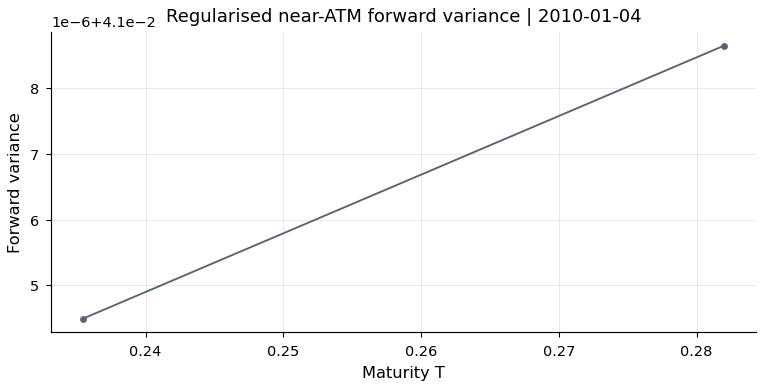

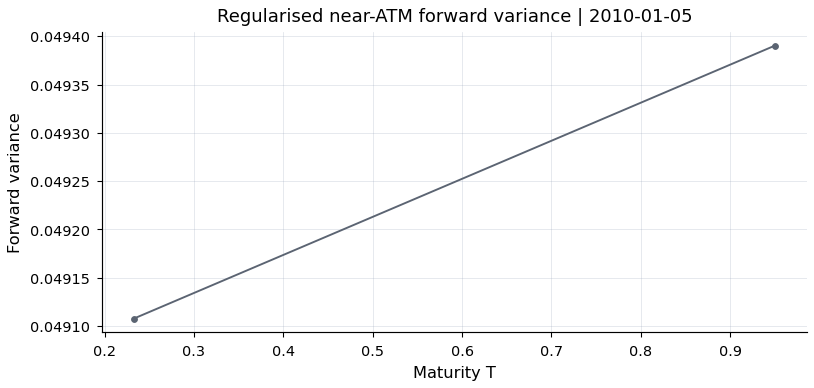

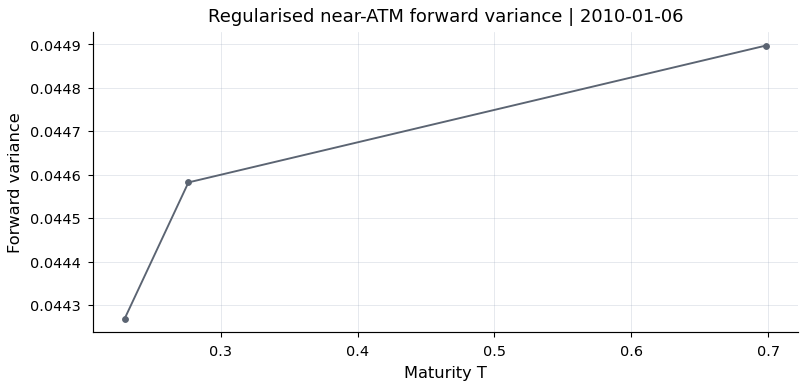

In [14]:
# ============================================================
# Regularised forward-variance approximation from near-ATM implied total variance
# ============================================================

FORWARD_VARIANCE_CURVE_VERSION = "regularised_near_atm_total_variance_final"


def _normalised_positive_weights(values: pd.Series | np.ndarray, n: int) -> np.ndarray:
    raw = np.asarray(values, dtype=float) if values is not None else np.ones(n, dtype=float)
    if raw.shape != (n,):
        raw = np.ones(n, dtype=float)
    raw = np.where(np.isfinite(raw) & (raw > 0), raw, 1.0)
    med = float(np.nanmedian(raw)) if np.any(np.isfinite(raw)) else 1.0
    med = max(med, 1e-12)
    return np.clip(raw / med, 0.25, 4.0)


def _near_atm_total_variance_points(surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    """Collapse each date/maturity to a regularised near-ATM total-variance observation.

    This deliberately does not take a single nearest-ATM quote. A single quote is too noisy for
    the initial curve that supplies v0/theta in the final 5-parameter lifted calibration. Instead,
    all quotes inside the configured near-ATM band are combined with a moneyness kernel and,
    when available, the existing surface fit weights.
    """
    required = {"date", "T", "iv_market", "log_forward_moneyness"}
    missing = required - set(surface.columns)
    if missing:
        raise ValueError(f"Forward-variance construction missing required columns: {sorted(missing)}")

    x = surface.copy()
    x["date"] = pd.to_datetime(x["date"]).dt.normalize()
    for col in ["T", "iv_market", "log_forward_moneyness"]:
        x[col] = pd.to_numeric(x[col], errors="coerce")
    bad = x[["T", "iv_market", "log_forward_moneyness"]].isna().any(axis=1) | (x["T"] <= 0) | (x["iv_market"] <= 0)
    if bad.any():
        raise ValueError(f"Forward-variance construction found {int(bad.sum())} invalid rows.")

    max_abs = float(cfg.market.max_atm_forward_moneyness)
    bandwidth = float(getattr(cfg.market, "forward_variance_atm_kernel_bandwidth", max_abs / 2.0))
    bandwidth = max(bandwidth, 1e-8)
    x = x.assign(abs_mny=x["log_forward_moneyness"].abs())
    x = x.loc[x["abs_mny"] <= max_abs].copy()
    if x.empty:
        raise ValueError("No sufficiently near-ATM observations are available for forward-variance estimation.")

    base_weight = np.ones(len(x), dtype=float)
    if bool(getattr(cfg.market, "forward_variance_use_fit_weights", True)) and "fit_weight" in x.columns:
        base_weight = _normalised_positive_weights(pd.to_numeric(x["fit_weight"], errors="coerce"), len(x))
    kernel_weight = np.exp(-0.5 * (x["abs_mny"].to_numpy(float) / bandwidth) ** 2)
    x["forward_curve_obs_weight"] = np.clip(base_weight * kernel_weight, 1e-8, np.inf)
    x["weighted_iv_variance"] = x["forward_curve_obs_weight"] * x["iv_market"].to_numpy(float) ** 2

    grouped = []
    for (date, T), g in x.groupby(["date", "T"], sort=True):
        w = g["forward_curve_obs_weight"].to_numpy(float)
        iv_var = float(np.sum(g["weighted_iv_variance"].to_numpy(float)) / max(np.sum(w), 1e-12))
        atm_iv = math.sqrt(max(iv_var, float(cfg.market.forward_variance_min)))
        grouped.append({
            "date": pd.Timestamp(date),
            "T": float(T),
            "atm_iv": float(atm_iv),
            "raw_atm_total_variance": float(float(T) * iv_var),
            "near_atm_quote_count": int(len(g)),
            "atm_abs_log_moneyness_min": float(g["abs_mny"].min()),
            "atm_abs_log_moneyness_weighted": float(np.sum(g["abs_mny"].to_numpy(float) * w) / max(np.sum(w), 1e-12)),
            "forward_curve_obs_weight_sum": float(np.sum(w)),
        })
    out = pd.DataFrame(grouped).sort_values(["date", "T"]).reset_index(drop=True)
    if out.empty:
        raise ValueError("Near-ATM total-variance aggregation returned no rows.")
    return out


def _difference_matrix(n: int, order: int) -> np.ndarray:
    eye = np.eye(n)
    if order == 1:
        return np.diff(eye, n=1, axis=0)
    if order == 2:
        return np.diff(eye, n=2, axis=0)
    raise ValueError("Only first- and second-difference regularisation is supported.")


def _fit_positive_forward_variance(
    maturities: np.ndarray,
    raw_total_variance: np.ndarray,
    observation_weights: np.ndarray,
    smoothness: float,
    curvature_smoothness: float,
    minimum: float,
    maximum: float,
) -> tuple[np.ndarray, np.ndarray, dict[str, Any]]:
    """Fit a positive piecewise-constant ξ₀ curve by constrained regularised LS.

    The fitted total variance W(T)=∫₀ᵀξ₀(s)ds is monotone by construction because ξ₀ is
    constrained positive. First- and second-difference penalties suppress jagged forward
    variance estimates caused by noisy ATM quotes.
    """
    if not SCIPY_AVAILABLE:
        raise RuntimeError("SciPy is required for constrained forward-variance estimation.")
    T = np.asarray(maturities, dtype=float)
    W = np.asarray(raw_total_variance, dtype=float)
    obs_w = _normalised_positive_weights(observation_weights, len(T))
    if len(T) == 0 or np.any(np.diff(T) <= 0) or np.any(~np.isfinite(W)) or np.any(W <= 0):
        raise ValueError("Invalid ATM total-variance term structure.")
    if not np.isfinite(maximum) or maximum <= minimum:
        maximum = np.inf

    dt = np.diff(np.concatenate([[0.0], T]))
    integration = np.tril(np.ones((len(T), len(T)), dtype=float)) * dt.reshape(1, -1)
    design_blocks = [integration * np.sqrt(obs_w).reshape(-1, 1)]
    target_blocks = [W * np.sqrt(obs_w)]

    # Penalise excessive changes in ξ₀. This is deliberately transparent: it is a
    # regularised curve estimate, not hidden endpoint recalibration.
    if len(T) > 1 and smoothness > 0:
        d1 = _difference_matrix(len(T), 1)
        scale = max(float(np.nanmedian(W / np.maximum(T, 1e-12))), minimum)
        design_blocks.append(math.sqrt(float(smoothness)) * d1 / scale)
        target_blocks.append(np.zeros(d1.shape[0], dtype=float))
    if len(T) > 2 and curvature_smoothness > 0:
        d2 = _difference_matrix(len(T), 2)
        scale = max(float(np.nanmedian(W / np.maximum(T, 1e-12))), minimum)
        design_blocks.append(math.sqrt(float(curvature_smoothness)) * d2 / scale)
        target_blocks.append(np.zeros(d2.shape[0], dtype=float))

    design = np.vstack(design_blocks)
    target = np.concatenate(target_blocks)
    result = lsq_linear(
        design,
        target,
        bounds=(float(minimum), float(maximum)),
        lsmr_tol="auto",
        max_iter=10_000,
        verbose=0,
    )
    if not result.success:
        raise RuntimeError(f"Positive forward-variance estimation failed: {result.message}")
    forward = np.asarray(result.x, dtype=float)
    fitted_total = integration @ forward
    if np.any(~np.isfinite(forward)) or np.any(forward < minimum) or np.any(fitted_total <= 0):
        raise FloatingPointError("Constrained forward-variance estimator returned invalid values.")

    total_error = fitted_total - W
    rel_adjustment = np.abs(total_error) / np.maximum(np.abs(W), 1e-12)
    d1_norm = float(np.sqrt(np.mean(np.diff(forward) ** 2))) if len(forward) > 1 else 0.0
    d2_norm = float(np.sqrt(np.mean(np.diff(forward, n=2) ** 2))) if len(forward) > 2 else 0.0
    diagnostics = {
        "forward_curve_version": FORWARD_VARIANCE_CURVE_VERSION,
        "forward_curve_cost": float(result.cost),
        "forward_curve_optimality": float(result.optimality),
        "forward_curve_status": int(result.status),
        "forward_curve_total_variance_rmse": float(np.sqrt(np.mean(total_error ** 2))),
        "forward_curve_total_variance_max_abs_error": float(np.max(np.abs(total_error))),
        "forward_curve_total_variance_max_rel_adjustment": float(np.max(rel_adjustment)),
        "forward_curve_d1_rmse": d1_norm,
        "forward_curve_d2_rmse": d2_norm,
        "forward_curve_min_xi0": float(np.min(forward)),
        "forward_curve_max_xi0": float(np.max(forward)),
        "forward_curve_total_variance_monotone": bool(np.all(np.diff(fitted_total) >= -1e-12)),
        "forward_curve_smoothness": float(smoothness),
        "forward_curve_curvature_smoothness": float(curvature_smoothness),
    }
    return forward, fitted_total, diagnostics


def build_atm_forward_variance_curve(surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    atm = _near_atm_total_variance_points(surface, cfg)
    min_maturities = int(getattr(cfg.market, "forward_variance_min_maturities", 2))
    maturity_counts = atm.groupby("date")["T"].nunique()
    eligible_dates = maturity_counts[maturity_counts >= max(min_maturities, 2)].index
    excluded_dates = maturity_counts[maturity_counts < max(min_maturities, 2)].index
    atm = atm.loc[atm["date"].isin(eligible_dates)].copy()
    if atm.empty:
        raise ValueError("No date has enough near-ATM maturities for regularised forward-variance estimation.")
    print({
        "forward_variance_dates": int(len(eligible_dates)),
        "excluded_insufficient_atm_maturities": int(len(excluded_dates)),
        "forward_curve_version": FORWARD_VARIANCE_CURVE_VERSION,
    })

    rows = []
    for date, g in atm.groupby("date", sort=True):
        g = g.sort_values("T").reset_index(drop=True)
        T = g["T"].to_numpy(float)
        raw_W = g["raw_atm_total_variance"].to_numpy(float)
        obs_w = g["forward_curve_obs_weight_sum"].to_numpy(float)
        forward, fitted_W, diag = _fit_positive_forward_variance(
            T,
            raw_W,
            observation_weights=obs_w,
            smoothness=float(cfg.market.forward_variance_smoothness),
            curvature_smoothness=float(getattr(cfg.market, "forward_variance_curvature_smoothness", 0.0)),
            minimum=float(cfg.market.forward_variance_min),
            maximum=float(getattr(cfg.market, "forward_variance_max", np.inf)),
        )
        max_rel_allowed = float(getattr(cfg.market, "forward_variance_max_relative_total_variance_adjustment", np.inf))
        adjustment_flag = "OK" if diag["forward_curve_total_variance_max_rel_adjustment"] <= max_rel_allowed else "REVIEW_LARGE_TOTAL_VARIANCE_ADJUSTMENT"
        for j, row in enumerate(g.itertuples(index=False)):
            rows.append({
                "date": pd.Timestamp(date),
                "T": float(T[j]),
                "atm_iv": float(row.atm_iv),
                "raw_atm_total_variance": float(raw_W[j]),
                "atm_total_variance": float(fitted_W[j]),
                "total_variance_adjustment": float(fitted_W[j] - raw_W[j]),
                "forward_variance": float(forward[j]),
                "near_atm_quote_count": int(row.near_atm_quote_count),
                "atm_abs_log_moneyness_min": float(row.atm_abs_log_moneyness_min),
                "atm_abs_log_moneyness_weighted": float(row.atm_abs_log_moneyness_weighted),
                "forward_curve_obs_weight_sum": float(row.forward_curve_obs_weight_sum),
                "forward_curve_adjustment_flag": adjustment_flag,
                "curve_regularization_version": FORWARD_VARIANCE_CURVE_VERSION,
                **diag,
            })
    out = pd.DataFrame(rows)
    if out.empty:
        raise ValueError("Forward-variance curve construction returned no rows.")
    if np.any(~np.isfinite(out["forward_variance"])) or np.any(out["forward_variance"] <= 0):
        raise FloatingPointError("Regularised forward-variance curve contains invalid values.")
    return out.sort_values(["date", "T"]).reset_index(drop=True)


def load_or_build_forward_variance_curve(surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    path = cfg.paths.forward_variance_path
    deps = [globals().get("SPX_HEDGING_CALIBRATION_PANEL_PATH", cfg.paths.surface_cache_path)]
    required = {
        "date", "T", "atm_total_variance", "forward_variance", "curve_regularization_version",
        "forward_curve_total_variance_max_rel_adjustment", "forward_curve_d1_rmse", "forward_curve_d2_rmse",
    }
    if not cfg.flags.REBUILD_SURFACE:
        try:
            curve = load_dataframe_cache(path, "atm_forward_variance_curve", "forward_variance", cfg, required_columns=required, dependencies=deps)
            versions = set(curve["curve_regularization_version"].dropna().astype(str).unique())
            if versions != {FORWARD_VARIANCE_CURVE_VERSION}:
                raise ValueError(f"Forward-variance cache version mismatch: {versions}")
            print(f"Loading validated regularised ATM forward-variance curve: {path}")
            return curve
        except (FileNotFoundError, ValueError) as exc:
            if not calibration_rebuild_allowed(cfg):
                raise RuntimeError(
                    "Forward-variance cache is missing or stale. Cached-evaluation mode will not rebuild calibration inputs. "
                    "Run an explicit calibration rebuild to regenerate the forward-variance curve."
                ) from exc
            print(f"[forward-variance rebuild] explicit calibration rebuild allowed. Reason: {exc}", flush=True)
    curve = build_atm_forward_variance_curve(surface, cfg)
    write_dataframe_cache(curve, path, "atm_forward_variance_curve", "forward_variance", cfg, dependencies=deps)
    print(f"Saved regularised ATM forward-variance curve: {path}")
    return curve


forward_variance_curve = load_or_build_forward_variance_curve(surface_panel, CFG)
display(forward_variance_curve.head())

forward_variance_curve_audit = (
    forward_variance_curve
    .groupby("date", as_index=False)
    .agg(
        maturities=("T", "nunique"),
        min_xi0=("forward_variance", "min"),
        max_xi0=("forward_variance", "max"),
        max_rel_total_variance_adjustment=("forward_curve_total_variance_max_rel_adjustment", "max"),
        d1_rmse=("forward_curve_d1_rmse", "max"),
        d2_rmse=("forward_curve_d2_rmse", "max"),
        adjustment_flag=("forward_curve_adjustment_flag", "first"),
    )
)
display(forward_variance_curve_audit.head())
print({
    "regularised_forward_variance_dates": int(forward_variance_curve_audit["date"].nunique()),
    "review_large_adjustment_dates": int(forward_variance_curve_audit["adjustment_flag"].ne("OK").sum()),
    "curve_version": FORWARD_VARIANCE_CURVE_VERSION,
})

if MATPLOTLIB_AVAILABLE:
    sample_dates = sorted(forward_variance_curve["date"].drop_duplicates())[:3]
    for d in sample_dates:
        g = forward_variance_curve[forward_variance_curve["date"].eq(d)].sort_values("T")
        fig, ax = plt.subplots(figsize=(7, 3))
        ax.plot(g["T"], g["forward_variance"], marker="o")
        ax.set_title(f"Regularised near-ATM forward variance | {pd.Timestamp(d).date()}")
        ax.set_xlabel("Maturity T")
        ax.set_ylabel("Forward variance")
        ax.grid(True, alpha=0.3)
        plt.show()


## 3c. Surface Coverage and Forward-Variance Diagnostics

This section checks whether the surface and forward-variance inputs are empirically usable. Surface coverage diagnostics report the number of quotes, dates, expiries, strikes, maturity buckets and moneyness regions. These are methodological coverage measures. They describe the support of the calibration problem and the extent to which Heston and lifted Heston are being compared on the same evidence.

Forward-variance diagnostics are particularly important for lifted Heston because the model uses a forward-curve-like input to initialise variance structure. The proxy

$$
\xi_0(T)\approx \partial_T\left[T\sigma_{\mathrm{ATM}}^2(T)\right]
$$

is economically meaningful only if the ATM term structure is sufficiently smooth and positive after preprocessing. If the proxy is jagged, negative or driven by sparse maturities, lifted calibration may be unstable for reasons unrelated to the underlying model.

The example forward-variance curves in this section serve two purposes. They make the model initialisation tangible for the methodology chapter, and they provide a limitation check: the dissertation can state clearly that the forward curve is an ATM-IV-based proxy rather than a directly observed variance-swap curve.

Interpretation should remain modest. A smooth forward-variance proxy supports the implementation. It does not prove that the proxy is the true expected future variance. The notebook therefore reports forward-variance diagnostics as input-quality evidence, not as a separate forecasting result.


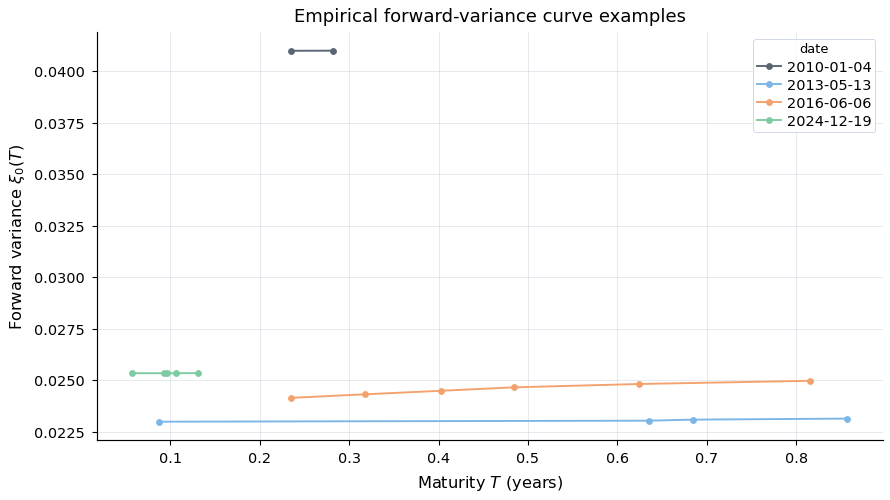

,metric,value,notes
0,surface_rows,127078,cleaned quote rows
1,dates,2848,distinct calibration dates
2,expiries,710,distinct option expiries
3,strikes,879,distinct strikes
4,near_atm_rows_abs_log_moneyness_le_0_05,71976,log_forward_moneyness
5,hedging_panel_rows_abs_log_moneyness_le_config,127078,log_forward_moneyness


,maturity_bucket,rows,dates,expiries,median_T,median_abs_log_moneyness
0,1M,23369,615,445,0.084873,0.025445
1,2M,3777,234,71,0.156057,0.037238
2,2W,503,17,17,0.057495,0.025928
3,3M,14590,962,121,0.287474,0.046653
4,LONG,84839,2348,179,0.605065,0.049014


,date,n_curve_points,min_forward_variance,median_forward_variance,max_forward_variance,second_difference_smoothness,positive_curve
0,2010-01-04,2,0.041004,0.041007,0.041009,NaN,True
1,2010-01-05,2,0.049108,0.049249,0.049390,NaN,True
2,2010-01-06,3,0.044269,0.044582,0.044897,0.000001,True
3,2010-01-07,3,0.042361,0.042663,0.042966,0.000002,True
4,2010-01-08,3,0.040307,0.040593,0.040880,0.000002,True


In [15]:

# Surface coverage and forward-variance evidence

def _choose_col(frame: pd.DataFrame, names: list[str]) -> str | None:
    return next((c for c in names if isinstance(frame, pd.DataFrame) and c in frame.columns), None)


def surface_coverage_table(surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if surface is None or surface.empty:
        return pd.DataFrame([{"metric": "surface_rows", "value": 0, "notes": "surface_panel missing or empty"}])
    s = surface.copy()
    rows = [
        {"metric": "surface_rows", "value": len(s), "notes": "cleaned quote rows"},
        {"metric": "dates", "value": pd.to_datetime(s["date"], errors="coerce").dt.normalize().nunique() if "date" in s else np.nan, "notes": "distinct calibration dates"},
        {"metric": "expiries", "value": s["exdate"].nunique() if "exdate" in s else np.nan, "notes": "distinct option expiries"},
        {"metric": "strikes", "value": s["strike"].nunique() if "strike" in s else np.nan, "notes": "distinct strikes"},
    ]
    cp_col = _choose_col(s, ["cp_flag", "option_type", "call_put"])
    if cp_col:
        cp = s[cp_col].astype(str).str.upper().str[0].value_counts(normalize=True)
        rows += [
            {"metric": "call_share", "value": float(cp.get("C", np.nan)), "notes": f"from {cp_col}"},
            {"metric": "put_share", "value": float(cp.get("P", np.nan)), "notes": f"from {cp_col}"},
        ]
    mny = _choose_col(s, ["log_forward_moneyness", "log_moneyness", "abs_log_forward_moneyness"])
    if mny:
        vals = pd.to_numeric(s[mny], errors="coerce").abs()
        rows += [
            {"metric": "near_atm_rows_abs_log_moneyness_le_0_05", "value": int(vals.le(0.05).sum()), "notes": mny},
            {"metric": "hedging_panel_rows_abs_log_moneyness_le_config", "value": int(vals.le(cfg.market.hedging_max_abs_log_moneyness).sum()), "notes": mny},
        ]
    out = pd.DataFrame(rows)
    out.to_csv(table_path("surface_coverage_diagnostics.csv", cfg), index=False)
    return out


def maturity_coverage_table(surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if surface is None or surface.empty or "maturity_bucket" not in surface.columns:
        return pd.DataFrame()
    s = surface.copy()
    s["date"] = pd.to_datetime(s.get("date"), errors="coerce").dt.normalize()
    out = s.groupby("maturity_bucket", dropna=False, as_index=False).agg(
        rows=("maturity_bucket", "size"),
        dates=("date", "nunique"),
        expiries=("exdate", "nunique") if "exdate" in s else ("maturity_bucket", "size"),
        median_T=("T", "median") if "T" in s else ("maturity_bucket", "size"),
        median_abs_log_moneyness=("log_forward_moneyness", lambda x: float(pd.to_numeric(x, errors="coerce").abs().median())) if "log_forward_moneyness" in s else ("maturity_bucket", "size"),
    )
    out.to_csv(table_path("surface_coverage_by_maturity_bucket.csv", cfg), index=False)
    return out


def forward_variance_diagnostics(curve: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if curve is None or curve.empty:
        return pd.DataFrame([{"date": pd.NaT, "status": "missing", "notes": "forward_variance_curve unavailable"}])
    c = curve.copy()
    t_col = _choose_col(c, ["T", "maturity", "tau"])
    xi_col = _choose_col(c, ["forward_variance", "xi0", "xi", "variance"])
    if not t_col or not xi_col or "date" not in c.columns:
        return pd.DataFrame([{"date": pd.NaT, "status": "missing_columns", "notes": f"T={t_col}; xi={xi_col}"}])
    c["date"] = pd.to_datetime(c["date"], errors="coerce").dt.normalize()
    c[t_col] = pd.to_numeric(c[t_col], errors="coerce")
    c[xi_col] = pd.to_numeric(c[xi_col], errors="coerce")
    rows = []
    for d, g in c.dropna(subset=[t_col, xi_col]).sort_values(["date", t_col]).groupby("date"):
        xi = g[xi_col].to_numpy(float)
        roughness = float(np.nanmean(np.abs(np.diff(xi, n=2)))) if len(xi) >= 3 else np.nan
        rows.append({
            "date": d,
            "n_curve_points": int(len(g)),
            "min_forward_variance": float(np.nanmin(xi)),
            "median_forward_variance": float(np.nanmedian(xi)),
            "max_forward_variance": float(np.nanmax(xi)),
            "second_difference_smoothness": roughness,
            "positive_curve": bool(np.nanmin(xi) > 0),
        })
    out = pd.DataFrame(rows)
    out.to_csv(table_path("forward_variance_smoothness_positivity.csv", cfg), index=False)
    return out


def plot_forward_variance_examples(curve: pd.DataFrame, cfg: ExperimentConfig, n_dates: int = 4) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or curve is None or curve.empty:
        return None
    t_col = _choose_col(curve, ["T", "maturity", "tau"])
    xi_col = _choose_col(curve, ["forward_variance", "xi0", "xi", "variance"])
    if not t_col or not xi_col or "date" not in curve.columns:
        return None
    c = curve.copy()
    c["date"] = pd.to_datetime(c["date"], errors="coerce").dt.normalize()
    dates = sorted(c["date"].dropna().unique())
    if not dates:
        return None
    pick = [dates[i] for i in np.linspace(0, len(dates) - 1, min(n_dates, len(dates))).astype(int)]
    fig, ax = plt.subplots(figsize=(7, 4))
    for d in pick:
        g = c.loc[c["date"].eq(d)].sort_values(t_col)
        ax.plot(pd.to_numeric(g[t_col], errors="coerce"), pd.to_numeric(g[xi_col], errors="coerce"), marker="o", label=pd.Timestamp(d).date())
    ax.set(title="Empirical forward-variance curve examples", xlabel="Maturity $T$ (years)", ylabel=r"Forward variance $\xi_0(T)$")
    ax.grid(True, alpha=0.3)
    ax.legend(title="date", fontsize=8)
    path = figure_path("forward_variance_curve_examples.png", cfg)
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path

surface_coverage_diagnostics = surface_coverage_table(surface_panel, CFG)
surface_coverage_by_maturity_bucket = maturity_coverage_table(surface_panel, CFG)
forward_variance_smoothness_positivity = forward_variance_diagnostics(forward_variance_curve, CFG)
forward_variance_curve_examples_path = plot_forward_variance_examples(forward_variance_curve, CFG)

display(surface_coverage_diagnostics)
display(surface_coverage_by_maturity_bucket.head())
display(forward_variance_smoothness_positivity.head())


## 3d. Panel Sufficiency and Data-Evidence Diagnostics

This section asks whether the final empirical panel is large and balanced enough to support the dissertation's claims. Panel sufficiency is not glamorous, which is probably why it is useful. A model comparison can be invalidated by lopsided coverage even when every plot looks professional.

The diagnostics summarise coverage by split, maturity bucket, regime label and moneyness. They also report date ranges and representative statistics such as median DTE and median absolute log-moneyness. The key question is whether train, validation and test data describe comparable market objects. If one policy is evaluated mostly on one maturity region while another is evaluated on another, the comparison becomes contaminated by panel composition.

The notebook uses deterministic date-based splits rather than random row-level splits. This matters because option rows from the same market date share the same volatility regime, spot level, calibration state and macro environment. Treating rows from the same date as independent evidence would inflate precision.

The interpretation rule is:

$$
\text{more paths per date} \rightarrow \text{lower Monte Carlo noise},
\qquad
\text{more dates} \rightarrow \text{more market-state evidence}.
$$

The dissertation should distinguish these two. A 10,000-path evaluation on twenty dates can be conditionally precise while still being limited in market-state diversity. This section makes that limitation explicit before the performance tables arrive looking authoritative.


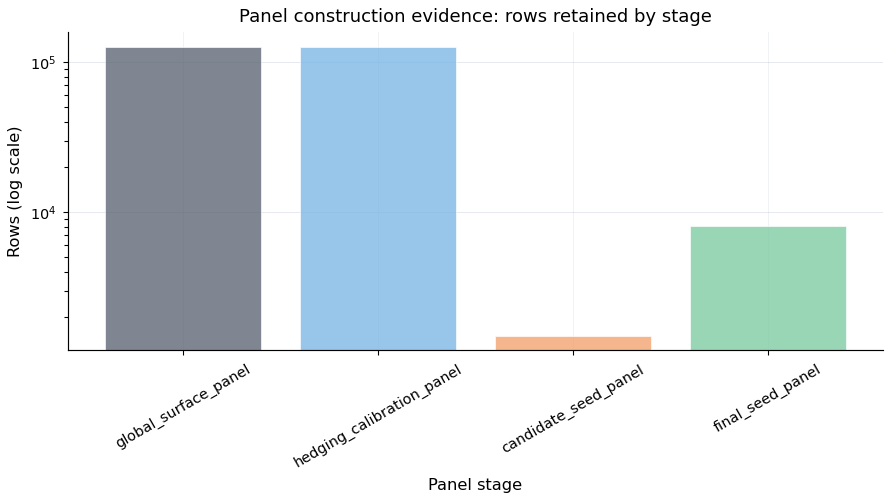

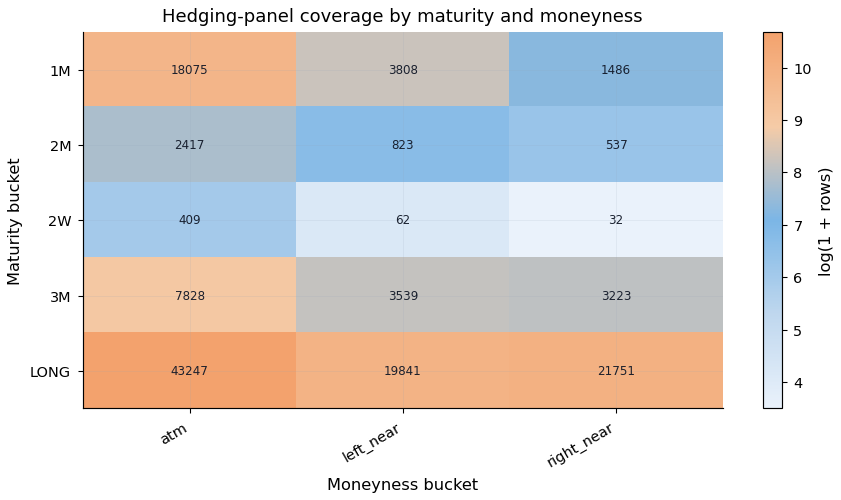

,panel,rows,n_dates,n_expiries,n_strikes,min_date,max_date,median_dte,median_abs_log_moneyness
0,global_surface_panel,127078,2848,710,879,2010-01-04,2024-12-31,163.0,0.043334
1,hedging_calibration_panel,127078,2848,710,879,2010-01-04,2024-12-31,163.0,0.043334
2,candidate_seed_panel,1498,1311,371,295,2010-01-04,2024-12-19,90.0,0.003052
3,final_seed_panel,8127,2848,710,443,2010-01-04,2024-12-31,175.0,0.003158


,maturity_bucket,moneyness_bucket,n_rows,n_dates
0,1M,atm,18075,615
1,1M,left_near,3808,613
2,1M,right_near,1486,486
3,2M,atm,2417,234
4,2M,left_near,823,233


In [16]:

# Panel sufficiency and data-evidence diagnostics

def _load_table_if_present(path: Path) -> pd.DataFrame:
    path = Path(path)
    if not path.exists() or path.stat().st_size == 0:
        return pd.DataFrame()
    return pd.read_parquet(path) if path.suffix.lower() == ".parquet" else pd.read_csv(path)


def _live_or_cached_frame(live_names: list[str], paths: list[Path]) -> pd.DataFrame:
    for name in live_names:
        obj = globals().get(name)
        if isinstance(obj, pd.DataFrame) and not obj.empty:
            return obj.copy()
    for path in paths:
        frame = _load_table_if_present(path)
        if not frame.empty:
            return frame
    return pd.DataFrame()


def _panel_summary_row(name: str, frame: pd.DataFrame) -> dict[str, Any]:
    if frame is None or frame.empty:
        return {"panel": name, "rows": 0, "n_dates": 0, "n_expiries": 0, "n_strikes": 0}
    f = frame.copy()
    date_col = _choose_col(f, ["date", "valuation_date"])
    expiry_col = _choose_col(f, ["exdate", "expiry", "expiration"])
    strike_col = _choose_col(f, ["strike", "K"])
    dte_col = _choose_col(f, ["dte", "days_to_expiry"])
    k_col = _choose_col(f, ["log_forward_moneyness", "k", "log_moneyness"])
    row = {
        "panel": name,
        "rows": int(len(f)),
        "n_dates": int(pd.to_datetime(f[date_col], errors="coerce").dt.normalize().nunique()) if date_col else 0,
        "n_expiries": int(pd.to_datetime(f[expiry_col], errors="coerce").dt.normalize().nunique()) if expiry_col else 0,
        "n_strikes": int(f[strike_col].nunique()) if strike_col else 0,
        "min_date": str(pd.to_datetime(f[date_col], errors="coerce").min().date()) if date_col and pd.to_datetime(f[date_col], errors="coerce").notna().any() else "",
        "max_date": str(pd.to_datetime(f[date_col], errors="coerce").max().date()) if date_col and pd.to_datetime(f[date_col], errors="coerce").notna().any() else "",
        "median_dte": float(pd.to_numeric(f[dte_col], errors="coerce").median()) if dte_col else np.nan,
        "median_abs_log_moneyness": float(pd.to_numeric(f[k_col], errors="coerce").abs().median()) if k_col else np.nan,
    }
    if "option_type" in f.columns:
        row["call_share"] = float(f["option_type"].astype(str).str.lower().str.startswith("c").mean())
    return row


def build_panel_sufficiency_diagnostics(cfg: ExperimentConfig) -> pd.DataFrame:
    frames = {
        "global_surface_panel": _live_or_cached_frame(["surface_panel", "global_diagnostic_panel"], [cfg.paths.surface_cache_path, SPX_HEDGING_OUTPUTS["global_diagnostic_panel"]]),
        "hedging_calibration_panel": _live_or_cached_frame(["spx_hedging_calibration_panel", "hedging_calibration_panel"], [SPX_HEDGING_OUTPUTS["hedging_calibration_panel"]]),
        "candidate_seed_panel": _live_or_cached_frame(["candidate_seed_panel"], [cfg.paths.candidate_seed_panel_path, cfg.paths.seed_candidate_universe_path]),
        "final_seed_panel": _live_or_cached_frame(["seed_panel", "spx_hedging_seed_panel"], [cfg.paths.seed_panel_path, cfg.paths.final_feasible_seed_panel_path, SPX_HEDGING_OUTPUTS["hedging_seed_panel"]]),
    }
    out = pd.DataFrame([_panel_summary_row(name, frame) for name, frame in frames.items()])
    out.to_csv(table_path("panel_sufficiency_diagnostics.csv", cfg), index=False)
    return out


def plot_panel_filter_waterfall(summary: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or summary is None or summary.empty or "rows" not in summary.columns:
        return None
    p = summary.copy()
    p = p.loc[p["rows"].fillna(0).astype(float) > 0].copy()
    if p.empty:
        return None
    fig, ax = plt.subplots(figsize=(7, 4))
    colors = [plt.rcParams["axes.prop_cycle"].by_key().get("color", [MODEL_COLORS["heston"]])[i % len(plt.rcParams["axes.prop_cycle"].by_key().get("color", [MODEL_COLORS["heston"]]))] for i in range(len(p))]
    ax.bar(p["panel"].astype(str), pd.to_numeric(p["rows"], errors="coerce"), color=colors, alpha=BAR_ALPHA, edgecolor="white", linewidth=0.45)
    ax.set_yscale("log")
    ax.set(title="Panel construction evidence: rows retained by stage", xlabel="Panel stage", ylabel="Rows (log scale)")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(True, axis="y", alpha=0.3)
    path = figure_path("panel_filter_waterfall_rows.png", cfg)
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path


def hedging_panel_bucket_coverage(cfg: ExperimentConfig) -> pd.DataFrame:
    panel = _live_or_cached_frame(["spx_hedging_calibration_panel", "hedging_calibration_panel"], [SPX_HEDGING_OUTPUTS["hedging_calibration_panel"]])
    if panel.empty:
        out = pd.DataFrame([{"status": "missing", "notes": "hedging calibration panel unavailable"}])
        out.to_csv(table_path("hedging_panel_bucket_coverage.csv", cfg), index=False)
        return out

    p = panel.copy()
    k_col = _choose_col(p, ["log_forward_moneyness", "k", "log_moneyness"])

    if "maturity_bucket" not in p.columns:
        dte_col = _choose_col(p, ["dte", "days_to_expiry"])
        if dte_col:
            bins = [0, 45, 90, 180, 365, np.inf]
            labels = ["<=45d", "46-90d", "91-180d", "181-365d", ">365d"]
            p["maturity_bucket"] = pd.cut(pd.to_numeric(p[dte_col], errors="coerce"), bins=bins, labels=labels)
        else:
            p["maturity_bucket"] = "all"

    if k_col:
        p["moneyness_bucket"] = pd.cut(
            pd.to_numeric(p[k_col], errors="coerce"),
            bins=[-np.inf, -0.10, -0.05, 0.05, 0.10, np.inf],
            labels=["left_wing", "left_near", "atm", "right_near", "right_wing"],
        )
    else:
        p["moneyness_bucket"] = "all"

    group_cols = ["maturity_bucket", "moneyness_bucket"]
    grouped = p.groupby(group_cols, dropna=False, observed=True)
    out = grouped.size().rename("n_rows").reset_index()

    if "date" in p.columns:
        date_counts = grouped["date"].apply(
            lambda x: pd.to_datetime(x, errors="coerce").dt.normalize().nunique()
        ).rename("n_dates").reset_index()
        out = out.merge(date_counts, on=group_cols, how="left")
    else:
        out["n_dates"] = out["n_rows"]

    out["maturity_bucket"] = out["maturity_bucket"].astype(str)
    out["moneyness_bucket"] = out["moneyness_bucket"].astype(str)
    out = out.sort_values(group_cols).reset_index(drop=True)
    out.to_csv(table_path("hedging_panel_bucket_coverage.csv", cfg), index=False)

    if MATPLOTLIB_AVAILABLE and not out.empty:
        heat = out.pivot_table(
            index="maturity_bucket",
            columns="moneyness_bucket",
            values="n_rows",
            aggfunc="sum",
            fill_value=0,
        )
        fig, ax = plt.subplots(figsize=(7, 4))
        plot_annotated_heatmap(
            heat,
            ax=ax,
            fig=fig,
            color_values=np.log1p(heat.astype(float)),
            text_values=heat.astype(float),
            cmap=COUNT_CMAP,
            title="Hedging-panel coverage by maturity and moneyness",
            xlabel="Moneyness bucket",
            ylabel="Maturity bucket",
            cbar_label="log(1 + rows)",
            fmt=".0f",
            rotation=30,
        )
        path = figure_path("hedging_panel_bucket_coverage_heatmap.png", cfg)
        save_and_show_figure(fig, path, dpi=260, description="Hedging-panel coverage by maturity and moneyness", notes="Cell labels show raw row counts; colour scale shows log(1 + rows).")

    return out


panel_sufficiency_diagnostics = build_panel_sufficiency_diagnostics(CFG)
panel_filter_waterfall_path = plot_panel_filter_waterfall(panel_sufficiency_diagnostics, CFG)
hedging_panel_bucket_coverage_table = hedging_panel_bucket_coverage(CFG)

display(panel_sufficiency_diagnostics)
display(hedging_panel_bucket_coverage_table.head())


# 4. Calibration Engines

This section loads or constructs the calibrated Heston and lifted-Heston model states used downstream. Calibration is the bridge between market option data and simulated hedging environments. It determines the parameter vectors, variance states and model-implied volatilities used for diagnostics and path generation.

The methodological requirement is **paired fairness**. Heston and lifted Heston should be compared on identical dates and target rows wherever possible. If one model is evaluated on a different option subset, differences in RMSE may reflect data composition rather than model performance.

The calibration engine is not part of evaluation. In cached-evaluation mode, calibrated artefacts are frozen and loaded. Recalibration should occur only when explicitly requested. This prevents a reporting run from changing the empirical state of the notebook.

The calibration output has two roles:

1. **Static fit evidence:** model IVs, residuals, RMSEs, skew errors and parameter stability.
2. **State construction:** parameters and state variables used to simulate hedging paths and compute model-delta benchmarks.

The dissertation should phrase calibration results carefully. A good calibration fit makes a model more credible as a scenario generator, especially on the relevant hedging slice. It does not by itself show that the model produces better hedges.


## 4.1 Classical Heston

In [17]:
from scipy.optimize import least_squares


@dataclass(frozen=True)
class HestonParams:
    kappa: float
    theta: float
    xi: float
    rho: float
    v0: float

    def as_array(self) -> np.ndarray:
        return np.array([self.kappa, self.theta, self.xi, self.rho, self.v0], dtype=float)

    @classmethod
    def from_array(cls, x: Iterable[float]) -> "HestonParams":
        kappa, theta, xi, rho, v0 = [float(v) for v in x]
        return cls(kappa=kappa, theta=theta, xi=xi, rho=rho, v0=v0)


@dataclass(frozen=True)
class HestonMarketTarget:
    date: pd.Timestamp
    profile: str
    frame: pd.DataFrame
    S: np.ndarray
    K: np.ndarray
    T: np.ndarray
    r: np.ndarray
    q: np.ndarray
    market_prices: np.ndarray
    iv_proxy: np.ndarray
    vegas: np.ndarray
    weights: np.ndarray


@dataclass(frozen=True)
class HestonPanelConfig:
    """Part-A-style production panel controls, adapted from profile keys to full-surface date keys.

    backend controls which proven Part A path is used:
    - "cpu": canonical SciPy least_squares for every full-surface date target.
    - "gpu_if_available": batched Torch/GPU initialisation where CUDA exists, then CPU polish for every flagged date.
    - "gpu": require CUDA for the batched Part A path.
    """

    backend: Literal["cpu", "gpu_if_available", "gpu"] = "gpu_if_available"
    gpu_chunk_size: int = 128
    gpu_max_steps: int = 1000
    gpu_lr: float = 0.03
    cpu_polish_bad_fits: bool = True
    cpu_polish_validation_dates: int = 25
    cpu_polish_max_dates: int | None = None
    fit_vega_rmse_threshold: float = 0.50
    bad_vega_rmse_threshold: float = 2.00
    common_pricer_n_quad: int = 64


HESTON_PANEL_CFG = HestonPanelConfig(
    fit_vega_rmse_threshold=CFG.calibration.heston_quality_warn_rmse,
    bad_vega_rmse_threshold=CFG.calibration.heston_quality_bad_rmse,
    common_pricer_n_quad=CFG.calibration.heston_pricing_nodes,
)


class HestonPricer:
    """Validated Part A semi-analytic Heston call pricer using Gauss-Laguerre P1/P2 quadrature."""

    def __init__(self, n_quad: int = 64):
        self.nodes, self.weights = np.polynomial.laguerre.laggauss(n_quad)

    @staticmethod
    def _cf(
        u: np.ndarray | complex,
        S: float,
        T: float,
        r: float,
        q: float,
        params: HestonParams,
    ) -> np.ndarray:
        kappa = params.kappa
        theta = params.theta
        xi = params.xi
        rho = params.rho
        v0 = params.v0

        iu = 1j * u
        a = kappa * theta
        b = kappa

        d = np.sqrt((rho * xi * iu - b) ** 2 + xi ** 2 * (iu + u ** 2))
        g = (b - rho * xi * iu - d) / (b - rho * xi * iu + d)
        exp_neg_dT = np.exp(-d * T)

        C = (
            iu * (np.log(S) + (r - q) * T)
            + (a / xi ** 2)
            * ((b - rho * xi * iu - d) * T - 2.0 * np.log((1.0 - g * exp_neg_dT) / (1.0 - g)))
        )
        D = ((b - rho * xi * iu - d) / xi ** 2) * ((1.0 - exp_neg_dT) / (1.0 - g * exp_neg_dT))
        return np.exp(C + D * v0)

    def call_price_one(self, S: float, K: float, T: float, r: float, q: float, params: HestonParams) -> float:
        if S <= 0 or K <= 0 or T <= 0:
            return np.nan

        u = self.nodes
        w = self.weights
        log_K = np.log(K)

        with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
            phi_minus_i = self._cf(-1j, S, T, r, q, params)
            if not np.all(np.isfinite(phi_minus_i)):
                return np.nan

            phi_1 = self._cf(u - 1j, S, T, r, q, params) / phi_minus_i
            phi_2 = self._cf(u, S, T, r, q, params)

            integrand_1 = np.real(np.exp(-1j * u * log_K) * phi_1 / (1j * u))
            integrand_2 = np.real(np.exp(-1j * u * log_K) * phi_2 / (1j * u))

            # Gauss-Laguerre integrates exp(-u)g(u), so multiply the original integrand by exp(u).
            integral_1 = np.sum(w * np.exp(u) * integrand_1)
            integral_2 = np.sum(w * np.exp(u) * integrand_2)

            P1 = 0.5 + integral_1 / np.pi
            P2 = 0.5 + integral_2 / np.pi

            price = S * np.exp(-q * T) * P1 - K * np.exp(-r * T) * P2

        if not np.isfinite(price):
            return np.nan
        return float(np.real(price))

    def call_probability_one(self, S: float, K: float, T: float, r: float, q: float, params: HestonParams) -> float:
        """Return Heston P1, so call delta is exp(-qT) P1."""
        if S <= 0 or K <= 0:
            raise ValueError("Heston probability requires positive S and K.")
        if T <= 1e-10:
            return 1.0 if S > K else (0.0 if S < K else 0.5)
        u, w = self.nodes, self.weights
        log_K = math.log(K)
        phi_minus_i = self._cf(-1j, S, T, r, q, params)
        if not np.all(np.isfinite(phi_minus_i)) or abs(phi_minus_i) < 1e-14:
            raise FloatingPointError("Invalid Heston P1 denominator.")
        phi_1 = self._cf(u - 1j, S, T, r, q, params) / phi_minus_i
        integrand_1 = np.real(np.exp(-1j * u * log_K) * phi_1 / (1j * u))
        P1 = 0.5 + float(np.sum(w * np.exp(u) * integrand_1) / np.pi)
        tol = 2e-3
        if not np.isfinite(P1) or P1 < -tol or P1 > 1.0 + tol:
            raise FloatingPointError(f"Heston P1 outside probability bounds: {P1}")
        return float(P1)

    def call_delta_one(self, S: float, K: float, T: float, r: float, q: float, params: HestonParams) -> float:
        P1 = self.call_probability_one(S, K, T, r, q, params)
        return float(math.exp(-q * max(T, 0.0)) * P1)

    def call_prices(self, S, K, T, r, q, params: HestonParams) -> np.ndarray:
        S = np.asarray(S, dtype=float)
        K = np.asarray(K, dtype=float)
        T = np.asarray(T, dtype=float)
        r = np.asarray(r, dtype=float)
        q = np.asarray(q, dtype=float)
        out = np.empty(len(K), dtype=float)
        for i in range(len(K)):
            out[i] = self.call_price_one(float(S[i]), float(K[i]), float(T[i]), float(r[i]), float(q[i]), params)
        return out


def prepare_surface_for_calibration(surface: pd.DataFrame, cfg: CalibrationConfig) -> pd.DataFrame:
    """Build the final full-surface target for one date.

    The dissertation methodology requires the Part-A full-surface weighting field
    ``fit_weight``. Older notebooks silently fell back to quote-quality weights or
    unit weights; that changes the calibration target and is therefore forbidden.
    """
    required = ["date", "spot_ref", "strike", "T", "r", "q", "call_equiv_mid", "bs_vega", "fit_weight"]
    missing = [c for c in required if c not in surface.columns]
    if missing:
        raise KeyError(f"Full-surface calibration target is missing required columns: {missing}")

    keep = [
        "date", "exdate", "maturity_bucket", "log_moneyness", "spot_ref", "strike", "T", "r", "q",
        "call_equiv_mid", "bs_vega", "iv_market", "impl_volatility", "fit_weight",
        "forward_ref", "dte",
    ]
    keep = [c for c in keep if c in surface.columns]
    out = surface.loc[:, keep].copy()
    out["target_weight"] = pd.to_numeric(out["fit_weight"], errors="coerce")

    if "iv_market" in out.columns:
        out["iv_proxy"] = pd.to_numeric(out["iv_market"], errors="coerce")
    elif "impl_volatility" in out.columns:
        out["iv_proxy"] = pd.to_numeric(out["impl_volatility"], errors="coerce")
    else:
        raise KeyError("Full-surface calibration requires iv_market or impl_volatility; no IV proxy is fabricated.")

    numeric_cols = ["spot_ref", "strike", "T", "r", "q", "call_equiv_mid", "bs_vega", "target_weight"]
    for col in numeric_cols + ["iv_proxy"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")

    out = out.dropna(subset=numeric_cols)
    valid = (
        np.isfinite(out["spot_ref"].to_numpy(float))
        & np.isfinite(out["strike"].to_numpy(float))
        & np.isfinite(out["T"].to_numpy(float))
        & np.isfinite(out["call_equiv_mid"].to_numpy(float))
        & np.isfinite(out["bs_vega"].to_numpy(float))
        & np.isfinite(out["target_weight"].to_numpy(float))
        & out["spot_ref"].to_numpy(float).__gt__(0.0)
        & out["strike"].to_numpy(float).__gt__(0.0)
        & out["T"].to_numpy(float).__gt__(0.0)
        & out["call_equiv_mid"].to_numpy(float).__gt__(0.0)
        & out["bs_vega"].to_numpy(float).__gt__(0.0)
        & out["target_weight"].to_numpy(float).__gt__(0.0)
    )
    out = out.loc[valid]

    if cfg.max_options_per_surface is not None and len(out) > cfg.max_options_per_surface:
        if "maturity_bucket" in out.columns and "log_moneyness" in out.columns:
            temp = out.copy()
            qbins = min(5, max(1, temp["log_moneyness"].nunique()))
            temp["_mny_bucket"] = pd.qcut(temp["log_moneyness"], q=qbins, duplicates="drop")
            n_groups = max(1, temp.groupby(["maturity_bucket", "_mny_bucket"], observed=False).ngroups)
            per_group = max(1, cfg.max_options_per_surface // n_groups)
            pieces = []
            for _, g in temp.groupby(["maturity_bucket", "_mny_bucket"], observed=False):
                pieces.append(g.sort_values("bs_vega", ascending=False).head(per_group))
            out = pd.concat(pieces, ignore_index=True).head(cfg.max_options_per_surface)
            out = out.drop(columns=["_mny_bucket"], errors="ignore")
        else:
            out = out.sort_values("bs_vega", ascending=False).head(cfg.max_options_per_surface)

    return out.sort_values([c for c in ["exdate", "strike"] if c in out.columns]).reset_index(drop=True)


def make_heston_market_target(surface_date: pd.DataFrame, cfg: CalibrationConfig, profile: str = "full_surface") -> HestonMarketTarget:
    frame = prepare_surface_for_calibration(surface_date, cfg)
    if frame.empty:
        raise ValueError("Cannot build Heston target from an empty filtered surface.")

    S = frame["spot_ref"].to_numpy(dtype=float)
    K = frame["strike"].to_numpy(dtype=float)
    T = frame["T"].to_numpy(dtype=float)
    r = frame["r"].to_numpy(dtype=float)
    q = frame["q"].to_numpy(dtype=float)
    market_prices = frame["call_equiv_mid"].to_numpy(dtype=float)
    vegas = np.maximum(frame["bs_vega"].to_numpy(dtype=float), cfg.vega_floor)
    weights = frame["target_weight"].to_numpy(dtype=float)

    iv_proxy = frame["iv_proxy"].to_numpy(dtype=float) if "iv_proxy" in frame.columns else np.full(len(frame), np.nan)
    if not np.isfinite(iv_proxy).all():
        raise ValueError("Full-surface calibration target contains non-finite implied volatility values.")

    return HestonMarketTarget(
        date=pd.Timestamp(frame["date"].iloc[0]),
        profile=profile,
        frame=frame,
        S=S,
        K=K,
        T=T,
        r=r,
        q=q,
        market_prices=market_prices,
        iv_proxy=iv_proxy,
        vegas=vegas,
        weights=weights,
    )


class HestonCalibrator:
    """Part A CPU canonical Heston calibrator using SciPy least_squares on residual vectors."""

    def __init__(self, cfg: CalibrationConfig, pricer: HestonPricer | None = None):
        self.cfg = cfg
        self.pricer = pricer if pricer is not None else HestonPricer(n_quad=cfg.heston_pricing_nodes)

    @staticmethod
    def _params_from_array(x: np.ndarray) -> HestonParams:
        return HestonParams.from_array(x)

    def _initial_guess(self, target: HestonMarketTarget, x0: np.ndarray | None = None) -> np.ndarray:
        if x0 is not None and np.all(np.isfinite(x0)):
            return np.asarray(x0, dtype=float)
        finite_iv = target.iv_proxy[np.isfinite(target.iv_proxy)]
        atm_var = float(np.nanmedian(finite_iv) ** 2) if len(finite_iv) else self.cfg.heston_initial["theta"]
        return np.array([
            self.cfg.heston_initial["kappa"],
            max(atm_var, self.cfg.heston_bounds["theta"][0]),
            self.cfg.heston_initial["xi"],
            self.cfg.heston_initial["rho"],
            max(atm_var, self.cfg.heston_bounds["v0"][0]),
        ], dtype=float)

    def _bounds(self) -> tuple[np.ndarray, np.ndarray]:
        lower = np.array([self.cfg.heston_bounds[k][0] for k in ["kappa", "theta", "xi", "rho", "v0"]], dtype=float)
        upper = np.array([self.cfg.heston_bounds[k][1] for k in ["kappa", "theta", "xi", "rho", "v0"]], dtype=float)
        return lower, upper

    def _residuals(self, x: np.ndarray, target: HestonMarketTarget) -> np.ndarray:
        params = self._params_from_array(x)
        model_prices = self.pricer.call_prices(target.S, target.K, target.T, target.r, target.q, params)
        if not np.all(np.isfinite(model_prices)):
            return np.full_like(target.market_prices, 1e6)
        residuals = (model_prices - target.market_prices) / np.maximum(np.abs(target.vegas), self.cfg.vega_floor)
        residuals = np.sqrt(target.weights) * residuals
        residuals[~np.isfinite(residuals)] = 1e6
        return residuals

    def calibrate(self, target: HestonMarketTarget, x0: np.ndarray | None = None) -> dict[str, Any]:
        lower, upper = self._bounds()
        x0_final = np.clip(self._initial_guess(target, x0=x0), lower + 1e-10, upper - 1e-10)

        result = least_squares(
            fun=lambda x: self._residuals(x, target),
            x0=x0_final,
            bounds=(lower, upper),
            max_nfev=self.cfg.optimizer_maxiter,
        )

        params = self._params_from_array(result.x)
        model_prices = self.pricer.call_prices(target.S, target.K, target.T, target.r, target.q, params)
        price_error = model_prices - target.market_prices
        vega_scaled_error = price_error / np.maximum(np.abs(target.vegas), self.cfg.vega_floor)
        weighted_vega_mse = float(np.average(vega_scaled_error ** 2, weights=target.weights))
        vega_scaled_rmse = float(np.sqrt(weighted_vega_mse))
        price_rmse = float(np.sqrt(np.average(price_error ** 2, weights=target.weights)))
        price_mae = float(np.average(np.abs(price_error), weights=target.weights))

        return {
            "date": target.date,
            "profile": target.profile,
            "success": bool(result.success),
            "message": str(result.message),
            "optimizer_cost": float(result.cost),
            "loss": weighted_vega_mse,
            "kappa": params.kappa,
            "theta": params.theta,
            "xi": params.xi,
            "rho": params.rho,
            "v0": params.v0,
            "n_options": int(len(target.K)),
            "n_points": int(len(target.K)),
            "price_rmse": price_rmse,
            "price_mae": price_mae,
            "vega_scaled_rmse": vega_scaled_rmse,
            "optimizer_nfev": int(result.nfev),
            "optimizer_nit": int(getattr(result, "nit", -1) if getattr(result, "nit", None) is not None else -1),
            "feller_margin": float(2.0 * params.kappa * params.theta - params.xi ** 2),
            "pricing_engine": "partA_cpu_gauss_laguerre_p1p2",
        }


@dataclass(frozen=True)
class BatchedHestonTargets:
    keys: pd.DataFrame
    S: torch.Tensor
    K: torch.Tensor
    T: torch.Tensor
    r: torch.Tensor
    q: torch.Tensor
    market_prices: torch.Tensor
    vegas: torch.Tensor
    weights: torch.Tensor
    mask: torch.Tensor
    iv_proxy: torch.Tensor
    device: torch.device


@dataclass(frozen=True)
class BatchedHestonGPUResult:
    params: pd.DataFrame
    fit_summary: pd.DataFrame
    history: pd.DataFrame


@dataclass(frozen=True)
class HestonPanelGPUOutput:
    params: pd.DataFrame
    fit_summary: pd.DataFrame
    history: pd.DataFrame
    timing: pd.DataFrame


HESTON_LOWER = torch.tensor([CFG.calibration.heston_bounds[k][0] for k in ["kappa", "theta", "xi", "rho", "v0"]], dtype=torch.float64) if TORCH_AVAILABLE else None
HESTON_UPPER = torch.tensor([CFG.calibration.heston_bounds[k][1] for k in ["kappa", "theta", "xi", "rho", "v0"]], dtype=torch.float64) if TORCH_AVAILABLE else None


def bounded_from_raw(raw: torch.Tensor, lower: torch.Tensor, upper: torch.Tensor) -> torch.Tensor:
    return lower + (upper - lower) * torch.sigmoid(raw)


def raw_from_bounded(params: torch.Tensor, lower: torch.Tensor, upper: torch.Tensor) -> torch.Tensor:
    scaled = (params - lower) / torch.clamp(upper - lower, min=1e-12)
    scaled = torch.clamp(scaled, 1e-6, 1.0 - 1e-6)
    return torch.log(scaled / (1.0 - scaled))


class BatchedTorchHestonPricer:
    """Part A fully batched Torch Heston pricer for GPU panel calibration."""

    def __init__(self, n_quad: int = 64, device: str = "cuda", dtype: torch.dtype = torch.float64):
        self.device = torch.device(device)
        self.real_dtype = dtype
        self.complex_dtype = torch.complex128 if dtype == torch.float64 else torch.complex64
        nodes, weights = np.polynomial.laguerre.laggauss(n_quad)
        self.u = torch.tensor(nodes, dtype=self.real_dtype, device=self.device)
        self.w = torch.tensor(weights, dtype=self.real_dtype, device=self.device)

    def _cf(self, u: torch.Tensor, S: torch.Tensor, T: torch.Tensor, r: torch.Tensor, q: torch.Tensor, params: torch.Tensor) -> torch.Tensor:
        kappa = params[:, 0].reshape(-1, 1, 1)
        theta = params[:, 1].reshape(-1, 1, 1)
        xi = params[:, 2].reshape(-1, 1, 1)
        rho = params[:, 3].reshape(-1, 1, 1)
        v0 = params[:, 4].reshape(-1, 1, 1)

        u = u.to(self.complex_dtype)
        S = S.to(self.complex_dtype)
        T = T.to(self.complex_dtype)
        r = r.to(self.complex_dtype)
        q = q.to(self.complex_dtype)
        kappa = kappa.to(self.complex_dtype)
        theta = theta.to(self.complex_dtype)
        xi = xi.to(self.complex_dtype)
        rho = rho.to(self.complex_dtype)
        v0 = v0.to(self.complex_dtype)

        iu = 1j * u
        d = torch.sqrt((rho * xi * iu - kappa) ** 2 + xi ** 2 * (iu + u ** 2))
        g = (kappa - rho * xi * iu - d) / (kappa - rho * xi * iu + d)
        exp_neg_dT = torch.exp(-d * T)
        C = (
            iu * (torch.log(S) + (r - q) * T)
            + (kappa * theta / xi ** 2)
            * ((kappa - rho * xi * iu - d) * T - 2.0 * torch.log((1.0 - g * exp_neg_dT) / (1.0 - g)))
        )
        D = ((kappa - rho * xi * iu - d) / xi ** 2) * ((1.0 - exp_neg_dT) / (1.0 - g * exp_neg_dT))
        return torch.exp(C + D * v0)

    def call_prices(self, batch: BatchedHestonTargets, params: torch.Tensor) -> torch.Tensor:
        S = torch.clamp(batch.S.unsqueeze(-1), min=1e-12)
        K = torch.clamp(batch.K.unsqueeze(-1), min=1e-12)
        T = torch.clamp(batch.T.unsqueeze(-1), min=1e-12)
        r = batch.r.unsqueeze(-1)
        q = batch.q.unsqueeze(-1)
        u = self.u.reshape(1, 1, -1)
        w = self.w.reshape(1, 1, -1)
        u_complex = u.to(self.complex_dtype)
        log_K = torch.log(K).to(self.complex_dtype)
        minus_i = torch.tensor(-1j, dtype=self.complex_dtype, device=self.device)
        phi_minus_i = self._cf(minus_i, S, T, r, q, params)
        phi_1 = self._cf(u_complex - 1j, S, T, r, q, params) / phi_minus_i
        phi_2 = self._cf(u_complex, S, T, r, q, params)
        integrand_1 = torch.real(torch.exp(-1j * u_complex * log_K) * phi_1 / (1j * u_complex))
        integrand_2 = torch.real(torch.exp(-1j * u_complex * log_K) * phi_2 / (1j * u_complex))
        integral_1 = torch.sum(w * torch.exp(u) * integrand_1, dim=-1)
        integral_2 = torch.sum(w * torch.exp(u) * integrand_2, dim=-1)
        P1 = 0.5 + integral_1 / np.pi
        P2 = 0.5 + integral_2 / np.pi
        price = batch.S * torch.exp(-batch.q * batch.T) * P1 - batch.K * torch.exp(-batch.r * batch.T) * P2
        return price * batch.mask


class BatchedHestonGPUOptimizer:
    """Part A batched GPU optimiser using bounded parameter transform and Adam."""

    def __init__(self, pricer: BatchedTorchHestonPricer, max_steps: int = 1000, lr: float = 0.03, vega_floor: float = 1.0):
        self.pricer = pricer
        self.max_steps = max_steps
        self.lr = lr
        self.vega_floor = vega_floor

    def _loss_per_target(self, batch: BatchedHestonTargets, params: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
        model_prices = self.pricer.call_prices(batch, params)
        vega_scale = torch.clamp(torch.abs(batch.vegas), min=self.vega_floor)
        residuals = (model_prices - batch.market_prices) / vega_scale
        weighted = torch.sqrt(batch.weights) * residuals * batch.mask
        loss_per_target = torch.sum(weighted ** 2, dim=1) / torch.clamp(torch.sum(batch.mask, dim=1), min=1.0)
        return loss_per_target, model_prices, residuals

    def fit(self, batch: BatchedHestonTargets, initial_params: torch.Tensor) -> BatchedHestonGPUResult:
        device = batch.device
        lower = HESTON_LOWER.to(device)
        upper = HESTON_UPPER.to(device)
        raw = torch.nn.Parameter(raw_from_bounded(initial_params, lower, upper).clone())
        optimiser = torch.optim.Adam([raw], lr=self.lr)
        history_rows = []

        for step in range(self.max_steps):
            optimiser.zero_grad()
            params = bounded_from_raw(raw, lower, upper)
            loss_per_target, _, _ = self._loss_per_target(batch, params)
            loss = torch.mean(loss_per_target)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite batched Heston loss.")
            loss.backward()
            optimiser.step()
            if step % 50 == 0 or step == self.max_steps - 1:
                history_rows.append({
                    "step": step,
                    "mean_loss": float(loss.detach().cpu()),
                    "median_loss": float(torch.median(loss_per_target).detach().cpu()),
                    "max_loss": float(torch.max(loss_per_target).detach().cpu()),
                })

        with torch.no_grad():
            final_params = bounded_from_raw(raw, lower, upper)
            loss_per_target, model_prices, residuals = self._loss_per_target(batch, final_params)

        params_np = final_params.detach().cpu().numpy()
        params_df = batch.keys.copy()
        params_df["kappa"] = params_np[:, 0]
        params_df["theta"] = params_np[:, 1]
        params_df["xi"] = params_np[:, 2]
        params_df["rho"] = params_np[:, 3]
        params_df["v0"] = params_np[:, 4]
        params_df["loss"] = loss_per_target.detach().cpu().numpy()
        params_df["feller_margin"] = 2.0 * params_df["kappa"] * params_df["theta"] - params_df["xi"] ** 2

        model_np = model_prices.detach().cpu().numpy()
        residual_np = residuals.detach().cpu().numpy()
        market_np = batch.market_prices.detach().cpu().numpy()
        mask_np = batch.mask.detach().cpu().numpy()
        fit_rows = []
        for b, key in batch.keys.iterrows():
            valid = mask_np[b] > 0
            price_error = model_np[b, valid] - market_np[b, valid]
            vega_error = residual_np[b, valid]
            fit_rows.append({
                "date": pd.Timestamp(key["date"]),
                "profile": str(key["profile"]),
                "n_points": int(valid.sum()),
                "n_options": int(valid.sum()),
                "price_rmse": float(np.sqrt(np.nanmean(price_error ** 2))),
                "price_mae": float(np.nanmean(np.abs(price_error))),
                "vega_scaled_rmse": float(np.sqrt(np.nanmean(vega_error ** 2))),
                "max_abs_price_error": float(np.nanmax(np.abs(price_error))),
            })
        return BatchedHestonGPUResult(params=params_df, fit_summary=pd.DataFrame(fit_rows), history=pd.DataFrame(history_rows))


def _date_keys(surface: pd.DataFrame) -> list[pd.Timestamp]:
    return [pd.Timestamp(d).normalize() for d in sorted(pd.to_datetime(surface["date"]).dt.normalize().unique())]


def _chunk_list(xs: list[Any], n: int) -> list[list[Any]]:
    return [xs[i:i + n] for i in range(0, len(xs), n)]


def make_batched_heston_targets(surface: pd.DataFrame, dates: list[pd.Timestamp], cfg: CalibrationConfig, device: str) -> BatchedHestonTargets:
    frames = []
    key_rows = []
    for date in dates:
        g = surface[pd.to_datetime(surface["date"]).dt.normalize().eq(pd.Timestamp(date).normalize())]
        target = make_heston_market_target(g, cfg, profile="hedging_focused_near_atm")
        frames.append(target)
        key_rows.append({"date": pd.Timestamp(date).normalize(), "profile": "hedging_focused_near_atm"})

    max_n = max(len(t.K) for t in frames)
    B = len(frames)
    arrays = {}
    for name in ["S", "K", "T", "r", "q", "market_prices", "vegas", "weights", "iv_proxy"]:
        arr = np.zeros((B, max_n), dtype=np.float64)
        for b, t in enumerate(frames):
            values = getattr(t, name)
            arr[b, :len(values)] = values
        arrays[name] = arr
    mask = np.zeros((B, max_n), dtype=np.float64)
    for b, t in enumerate(frames):
        mask[b, :len(t.K)] = 1.0

    dev = torch.device(device)
    return BatchedHestonTargets(
        keys=pd.DataFrame(key_rows),
        S=torch.tensor(arrays["S"], dtype=torch.float64, device=dev),
        K=torch.tensor(arrays["K"], dtype=torch.float64, device=dev),
        T=torch.tensor(arrays["T"], dtype=torch.float64, device=dev),
        r=torch.tensor(arrays["r"], dtype=torch.float64, device=dev),
        q=torch.tensor(arrays["q"], dtype=torch.float64, device=dev),
        market_prices=torch.tensor(arrays["market_prices"], dtype=torch.float64, device=dev),
        vegas=torch.tensor(arrays["vegas"], dtype=torch.float64, device=dev),
        weights=torch.tensor(arrays["weights"], dtype=torch.float64, device=dev),
        mask=torch.tensor(mask, dtype=torch.float64, device=dev),
        iv_proxy=torch.tensor(arrays["iv_proxy"], dtype=torch.float64, device=dev),
        device=dev,
    )


def initial_heston_params_for_batch(batch: BatchedHestonTargets, cfg: CalibrationConfig) -> torch.Tensor:
    params = []
    lower = np.array([cfg.heston_bounds[k][0] for k in ["kappa", "theta", "xi", "rho", "v0"]], dtype=float)
    upper = np.array([cfg.heston_bounds[k][1] for k in ["kappa", "theta", "xi", "rho", "v0"]], dtype=float)
    iv_np = batch.iv_proxy.detach().cpu().numpy()
    mask_np = batch.mask.detach().cpu().numpy() > 0
    for b in range(iv_np.shape[0]):
        vals = iv_np[b, mask_np[b]]
        vals = vals[np.isfinite(vals)]
        atm_var = float(np.nanmedian(vals) ** 2) if len(vals) else cfg.heston_initial["theta"]
        x = np.array([
            cfg.heston_initial["kappa"],
            max(atm_var, cfg.heston_bounds["theta"][0]),
            cfg.heston_initial["xi"],
            cfg.heston_initial["rho"],
            max(atm_var, cfg.heston_bounds["v0"][0]),
        ], dtype=float)
        params.append(np.clip(x, lower + 1e-10, upper - 1e-10))
    return torch.tensor(np.vstack(params), dtype=torch.float64, device=batch.device)


def calibrate_heston_gpu_batch(surface: pd.DataFrame, dates: list[pd.Timestamp], cfg: ExperimentConfig, panel_cfg: HestonPanelConfig, device: str) -> tuple[BatchedHestonGPUResult, float]:
    batch = make_batched_heston_targets(surface, dates, cfg.calibration, device=device)
    initial = initial_heston_params_for_batch(batch, cfg.calibration)
    pricer = BatchedTorchHestonPricer(n_quad=panel_cfg.common_pricer_n_quad, device=device)
    optimiser = BatchedHestonGPUOptimizer(pricer=pricer, max_steps=panel_cfg.gpu_max_steps, lr=panel_cfg.gpu_lr, vega_floor=cfg.calibration.vega_floor)
    if device == "cuda":
        torch.cuda.synchronize()
    t0 = time.perf_counter()
    result = optimiser.fit(batch, initial)
    if device == "cuda":
        torch.cuda.synchronize()
    return result, time.perf_counter() - t0


def combine_heston_params_and_fit(params: pd.DataFrame, fit: pd.DataFrame) -> pd.DataFrame:
    out = params.merge(fit, on=["date", "profile"], how="left", suffixes=("", "_fit"))
    out["date"] = pd.to_datetime(out["date"]).dt.normalize()
    return out


def add_heston_quality_flags(
    panel: pd.DataFrame,
    panel_cfg: HestonPanelConfig,
    calibration_cfg: CalibrationConfig,
) -> pd.DataFrame:
    out = panel.copy()
    required = ["kappa", "theta", "xi", "rho", "v0", "vega_scaled_rmse"]
    out["finite_params"] = np.isfinite(out[required]).all(axis=1)
    out["fit_ok"] = out["finite_params"] & out["vega_scaled_rmse"].lt(panel_cfg.fit_vega_rmse_threshold)
    bounds = {
        name: calibration_cfg.heston_bounds[name]
        for name in ["kappa", "theta", "xi", "rho", "v0"]
    }
    out["bound_hit_count"] = 0
    for col, (lo, hi) in bounds.items():
        out["bound_hit_count"] += np.isclose(out[col], lo, rtol=1e-4, atol=1e-6).astype(int)
        out["bound_hit_count"] += np.isclose(out[col], hi, rtol=1e-4, atol=1e-6).astype(int)
    out["feller_pass"] = out["feller_margin"] > 0
    out["quality_flag"] = np.where(
        out["vega_scaled_rmse"].gt(panel_cfg.bad_vega_rmse_threshold),
        "BADFIT",
        np.where(out["fit_ok"], "OK", "WARN"),
    )
    out["needs_cpu_polish"] = (~out["fit_ok"]) | out["bound_hit_count"].gt(0) | (~out["finite_params"])
    return out


def run_heston_gpu_panel(surface: pd.DataFrame, dates: list[pd.Timestamp], cfg: ExperimentConfig, panel_cfg: HestonPanelConfig, device: str) -> HestonPanelGPUOutput:
    chunks = _chunk_list(dates, panel_cfg.gpu_chunk_size)
    params_rows, fit_rows, history_rows, timing_rows = [], [], [], []
    for chunk_id, chunk_dates in enumerate(chunks, start=1):
        result, elapsed = calibrate_heston_gpu_batch(surface, chunk_dates, cfg, panel_cfg, device=device)
        params = result.params.copy(); params["chunk_id"] = chunk_id
        fit = result.fit_summary.copy(); fit["chunk_id"] = chunk_id
        hist = result.history.copy(); hist["chunk_id"] = chunk_id
        params_rows.append(params); fit_rows.append(fit); history_rows.append(hist)
        timing_rows.append({"chunk_id": chunk_id, "targets": len(chunk_dates), "seconds": elapsed, "seconds_per_target": elapsed / max(1, len(chunk_dates))})
        print(f"GPU Heston chunk {chunk_id}/{len(chunks)}: dates={len(chunk_dates)}, seconds={elapsed:.1f}, seconds/date={elapsed/max(1, len(chunk_dates)):.3f}")
    return HestonPanelGPUOutput(
        params=pd.concat(params_rows, ignore_index=True) if params_rows else pd.DataFrame(),
        fit_summary=pd.concat(fit_rows, ignore_index=True) if fit_rows else pd.DataFrame(),
        history=pd.concat(history_rows, ignore_index=True) if history_rows else pd.DataFrame(),
        timing=pd.DataFrame(timing_rows),
    )


def heston_date_part_path(cfg: ExperimentConfig, date: pd.Timestamp) -> Path:
    date_key = pd.Timestamp(date).normalize().strftime("%Y%m%d")
    return cfg.paths.heston_calibration_parts_dir / f"heston_full_surface_{date_key}.parquet"



def load_heston_date_part(cfg: ExperimentConfig, date: pd.Timestamp) -> pd.DataFrame | None:
    path = heston_date_part_path(cfg, date)
    if not cfg.calibration.heston_resume_date_parts:
        return None
    try:
        return load_dataframe_cache(
            path,
            f"heston_date_part_{pd.Timestamp(date):%Y%m%d}",
            "heston",
            cfg,
            required_columns={"date", "kappa", "theta", "xi", "rho", "v0", "success", "quality_flag"},
            dependencies=[cfg.paths.surface_cache_path],
        )
    except (FileNotFoundError, ValueError):
        return None


def save_heston_date_part(row: dict[str, Any] | pd.Series | pd.DataFrame, cfg: ExperimentConfig, date: pd.Timestamp) -> None:
    path = heston_date_part_path(cfg, date)
    if isinstance(row, pd.DataFrame):
        frame = row.copy()
    elif isinstance(row, pd.Series):
        frame = row.to_frame().T
    else:
        frame = pd.DataFrame([row])
    write_dataframe_cache(
        frame,
        path,
        f"heston_date_part_{pd.Timestamp(date):%Y%m%d}",
        "heston",
        cfg,
        dependencies=[cfg.paths.surface_cache_path],
    )

def calibrate_heston_cpu_dates(
    surface: pd.DataFrame,
    dates: list[pd.Timestamp],
    cfg: ExperimentConfig,
    panel_cfg: HestonPanelConfig = HESTON_PANEL_CFG,
    x0_lookup: dict[pd.Timestamp, np.ndarray] | None = None,
) -> tuple[pd.DataFrame, float]:
    """Canonical Part A CPU calibration for full-surface date targets, with reusable date checkpoints."""
    calibrator = HestonCalibrator(cfg=cfg.calibration, pricer=HestonPricer(n_quad=cfg.calibration.heston_pricing_nodes))
    rows = []
    t0 = time.perf_counter()
    prev_x = None
    cfg.paths.heston_calibration_parts_dir.mkdir(parents=True, exist_ok=True)

    for i, date in enumerate(dates, start=1):
        date_norm = pd.Timestamp(date).normalize()
        cached = load_heston_date_part(cfg, date_norm)
        if cached is not None and not cached.empty:
            row = cached.iloc[0].to_dict()
            row["date"] = pd.Timestamp(row["date"]).normalize()
            rows.append(row)
            prev_x = np.array([row["kappa"], row["theta"], row["xi"], row["rho"], row["v0"]], dtype=float)
            print(f"CPU Part A {i}/{len(dates)} {date_norm.date()}: loaded date checkpoint")
            continue

        g = surface[pd.to_datetime(surface["date"]).dt.normalize().eq(date_norm)]
        target = make_heston_market_target(g, cfg.calibration, profile="hedging_focused_near_atm")
        x0 = None
        if x0_lookup is not None and date_norm in x0_lookup:
            x0 = x0_lookup[date_norm]
        elif cfg.calibration.heston_warm_start_previous_date:
            x0 = prev_x

        t_date = time.perf_counter()
        row = calibrator.calibrate(target, x0=x0)
        row["backend"] = "cpu_scipy_least_squares"
        row["calibration_mode"] = "hedging_focused_near_atm_spx_cpu"
        row["cpu_seconds"] = time.perf_counter() - t_date
        row = add_heston_quality_flags(pd.DataFrame([row]), panel_cfg, cfg.calibration).iloc[0].to_dict()
        rows.append(row)
        save_heston_date_part(row, cfg, date_norm)
        prev_x = np.array([row["kappa"], row["theta"], row["xi"], row["rho"], row["v0"]], dtype=float)
        print(
            f"CPU Part A {i}/{len(dates)} {date_norm.date()}: "
            f"success={row['success']}, loss={row['loss']:.6g}, "
            f"vega_rmse={row['vega_scaled_rmse']:.4g}, n={row['n_options']}, "
            f"nfev={row['optimizer_nfev']}, seconds={row['cpu_seconds']:.1f}"
        )

    return pd.DataFrame(rows), time.perf_counter() - t0

def select_cpu_polish_dates(panel: pd.DataFrame, panel_cfg: HestonPanelConfig) -> list[pd.Timestamp]:
    bad = panel.loc[panel["needs_cpu_polish"], ["date"]].copy()
    validation = panel.loc[~panel["needs_cpu_polish"], ["date"]].sort_values("date").head(panel_cfg.cpu_polish_validation_dates)
    selected = pd.concat([bad, validation], ignore_index=True).drop_duplicates("date").sort_values("date")
    if panel_cfg.cpu_polish_max_dates is not None:
        selected = selected.head(panel_cfg.cpu_polish_max_dates)
    return [pd.Timestamp(d).normalize() for d in selected["date"]]


def build_final_heston_panel(gpu_panel: pd.DataFrame, cpu_polish: pd.DataFrame) -> pd.DataFrame:
    if gpu_panel.empty:
        return cpu_polish.sort_values("date").reset_index(drop=True)
    if cpu_polish.empty:
        return gpu_panel.sort_values("date").reset_index(drop=True)
    key_cols = ["date", "profile"]
    polish_keys = cpu_polish[key_cols].drop_duplicates()
    gpu_keep = gpu_panel.merge(polish_keys.assign(_has_cpu=True), on=key_cols, how="left")
    gpu_keep = gpu_keep[gpu_keep["_has_cpu"].isna()].drop(columns=["_has_cpu"])
    cols = sorted(set(gpu_keep.columns).union(cpu_polish.columns))
    return pd.concat([gpu_keep.reindex(columns=cols), cpu_polish.reindex(columns=cols)], ignore_index=True).sort_values("date").reset_index(drop=True)


def heston_arch_cache_path(cfg: ExperimentConfig) -> Path:
    # Use the standard path config so downstream sections and cache loading agree.
    return cfg.paths.heston_calibration_path


def load_or_run_heston_calibration(surface: pd.DataFrame, cfg: ExperimentConfig, panel_cfg: HestonPanelConfig = HESTON_PANEL_CFG) -> pd.DataFrame:
    """Load a frozen Heston calibration cache, or rebuild only when explicitly requested."""
    cache_path = heston_arch_cache_path(cfg)
    deps = [globals().get("SPX_HEDGING_CALIBRATION_PANEL_PATH", cfg.paths.surface_cache_path)]
    artifact_name = "heston_hedging_panel_calibration" if globals().get("HEADLINE_EMPIRICAL_MODE") == "HEDGING_FOCUSED_PANEL" else "heston_full_surface_calibration"
    required = {"date", "profile", "kappa", "theta", "xi", "rho", "v0"}
    if cfg.flags.FREEZE_CALIBRATION_ARTIFACTS and cfg.flags.RUN_HESTON_CALIBRATION:
        raise RuntimeError(
            "Calibration artefacts are frozen but RUN_HESTON_CALIBRATION=True. "
            "Set FREEZE_CALIBRATION_ARTIFACTS=False only for an explicit calibration rebuild."
        )
    if not cfg.flags.RUN_HESTON_CALIBRATION:
        try:
            loaded = load_dataframe_cache(cache_path, artifact_name, "heston", cfg, required_columns=required, dependencies=deps)
            loaded["date"] = pd.to_datetime(loaded["date"]).dt.normalize()
            print(f"Loading validated Heston hedging-panel calibration cache: {cache_path}")
            return loaded
        except (FileNotFoundError, ValueError) as exc:
            if cfg.flags.FREEZE_CALIBRATION_ARTIFACTS or not cfg.flags.ALLOW_CALIBRATION_REBUILD_FROM_DOWNSTREAM:
                raise RuntimeError(
                    "Heston hedging-panel calibration cache is missing or stale. Evaluation uses frozen calibrations and will not recalibrate. "
                    "Run the calibration section explicitly with FREEZE_CALIBRATION_ARTIFACTS=False to rebuild it."
                ) from exc
            print(f"[heston calibration rebuild] downstream rebuild explicitly allowed. Reason: {exc}", flush=True)

    dates = _date_keys(surface)
    if not dates:
        raise ValueError("No dates available for Heston calibration.")
    prepare_checkpoint_directory(cfg.paths.heston_calibration_parts_dir, "heston_date_parts", "heston", cfg, deps)
    use_cuda = TORCH_AVAILABLE and torch.cuda.is_available()
    if panel_cfg.backend == "gpu" and not use_cuda:
        raise RuntimeError("HestonPanelConfig.backend='gpu' but CUDA is not available.")
    use_gpu = panel_cfg.backend in {"gpu", "gpu_if_available"} and use_cuda
    if use_gpu:
        gpu_output = run_heston_gpu_panel(surface, dates, cfg, panel_cfg, device="cuda")
        gpu_panel = combine_heston_params_and_fit(gpu_output.params, gpu_output.fit_summary)
        gpu_panel["backend"] = "gpu_batched_partA"
        gpu_panel["calibration_mode"] = "hedging_focused_near_atm_spx_gpu_batched"
        gpu_panel = add_heston_quality_flags(gpu_panel, panel_cfg, cfg.calibration)
        x0_lookup = {
            pd.Timestamp(row.date).normalize(): np.array([row.kappa, row.theta, row.xi, row.rho, row.v0], dtype=float)
            for row in gpu_panel.itertuples(index=False)
            if np.all(np.isfinite([row.kappa, row.theta, row.xi, row.rho, row.v0]))
        }
        polish_dates = select_cpu_polish_dates(gpu_panel, panel_cfg) if panel_cfg.cpu_polish_bad_fits else []
        if polish_dates:
            cpu_panel, _ = calibrate_heston_cpu_dates(surface, polish_dates, cfg, panel_cfg=panel_cfg, x0_lookup=x0_lookup)
            cpu_panel = add_heston_quality_flags(cpu_panel, panel_cfg, cfg.calibration)
        else:
            cpu_panel = pd.DataFrame()
        final = build_final_heston_panel(gpu_panel, cpu_panel)
    else:
        cpu_panel, _ = calibrate_heston_cpu_dates(surface, dates, cfg, panel_cfg=panel_cfg, x0_lookup=None)
        final = add_heston_quality_flags(cpu_panel, panel_cfg, cfg.calibration)

    final["date"] = pd.to_datetime(final["date"]).dt.normalize()
    final["profile"] = final.get("profile", "hedging_focused_near_atm")
    final["calibration_panel"] = globals().get("HEADLINE_EMPIRICAL_MODE", "unknown")
    final = final.sort_values("date").drop_duplicates(["date", "profile"], keep="last").reset_index(drop=True)
    missing_dates = sorted(set(pd.Series(dates).dt.normalize()).difference(set(final["date"])))
    if missing_dates:
        raise RuntimeError(f"Heston calibration missing {len(missing_dates)} dates; first: {missing_dates[:5]}")
    write_dataframe_cache(final, cache_path, artifact_name, "heston", cfg, dependencies=deps, extra={"headline_empirical_mode": globals().get("HEADLINE_EMPIRICAL_MODE", "unknown")})
    print(f"Saved Heston hedging-panel calibration cache: {cache_path} ({len(final)} rows)")
    return final

heston_calibration = load_or_run_heston_calibration(surface_panel, CFG)
display(heston_calibration.head())


Loading validated Heston hedging-panel calibration cache: cache_final\heston_hedging_panel_calibration.parquet


,backend,bound_hit_count,calibration_mode,chunk_id,chunk_id_fit,cpu_seconds,date,feller_margin,feller_pass,finite_params,fit_ok,kappa,loss,max_abs_price_error,message,n_options,n_points,needs_cpu_polish,optimizer_cost,optimizer_nfev,optimizer_nit,price_mae,price_rmse,pricing_engine,profile,quality_flag,rho,success,theta,v0,vega_scaled_rmse,xi,calibration_panel
0,cpu_scipy_least_squares,0,hedging_focused_near_atm_spx_cpu,NaN,NaN,0.214938,2010-01-04,-0.484471,False,True,True,4.840616,8.955512e-08,NaN,`gtol` termination condition is satisfied.,13,13,False,7.417031e-07,25.0,-1.0,0.051696,0.058337,partA_cpu_gauss_laguerre_p1p2,hedging_focused_near_atm,OK,-0.686512,1.0,0.067734,0.037066,0.000299,1.067813,HEDGING_FOCUSED_PANEL
1,cpu_scipy_least_squares,0,hedging_focused_near_atm_spx_cpu,NaN,NaN,0.117374,2010-01-05,-0.205100,False,True,True,1.154539,3.704908e-07,NaN,`gtol` termination condition is satisfied.,16,16,False,3.815972e-06,12.0,-1.0,0.149815,0.182779,partA_cpu_gauss_laguerre_p1p2,hedging_focused_near_atm,OK,-0.709870,1.0,0.112471,0.036306,0.000609,0.681765,HEDGING_FOCUSED_PANEL
2,cpu_scipy_least_squares,0,hedging_focused_near_atm_spx_cpu,NaN,NaN,0.284309,2010-01-06,-0.201449,False,True,True,1.035999,3.341898e-07,NaN,`gtol` termination condition is satisfied.,30,30,False,6.494967e-06,14.0,-1.0,0.108670,0.121961,partA_cpu_gauss_laguerre_p1p2,hedging_focused_near_atm,OK,-0.686329,1.0,0.124329,0.033162,0.000578,0.677538,HEDGING_FOCUSED_PANEL
3,cpu_scipy_least_squares,0,hedging_focused_near_atm_spx_cpu,NaN,NaN,0.269471,2010-01-07,-0.191157,False,True,True,1.310406,3.839909e-07,NaN,`ftol` termination condition is satisfied.,35,35,False,8.431027e-06,13.0,-1.0,0.110183,0.134450,partA_cpu_gauss_laguerre_p1p2,hedging_focused_near_atm,OK,-0.690385,1.0,0.105965,0.031657,0.000620,0.684742,HEDGING_FOCUSED_PANEL
4,cpu_scipy_least_squares,0,hedging_focused_near_atm_spx_cpu,NaN,NaN,0.479836,2010-01-08,-0.162642,False,True,True,0.803358,4.166474e-07,NaN,`gtol` termination condition is satisfied.,36,36,False,9.368457e-06,23.0,-1.0,0.113244,0.139311,partA_cpu_gauss_laguerre_p1p2,hedging_focused_near_atm,OK,-0.678488,1.0,0.136489,0.030173,0.000645,0.618013,HEDGING_FOCUSED_PANEL


In [18]:
# ============================================================
# Calibration fit inspection helpers
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def _visual_model_key(model_name: str) -> str:
    text = str(model_name).strip().lower().replace('-', '_').replace(' ', '_')
    if 'lifted' in text:
        return 'lifted_heston'
    if 'heston' in text:
        return 'heston'
    if 'market' in text:
        return 'market'
    return text


def _normalise_date_col(df: pd.DataFrame, col: str = "date") -> pd.DataFrame:
    out = df.copy()
    out[col] = pd.to_datetime(out[col]).dt.normalize()
    return out


def add_maturity_bucket(df: pd.DataFrame, T_col: str = "T") -> pd.DataFrame:
    """
    Add maturity buckets used for calibration diagnostics.
    T is assumed to be in years.
    """
    out = df.copy()
    dte = out[T_col].astype(float) * 365.25

    bins = [0, 14, 30, 60, 120, 365, np.inf]
    labels = ["0-2W", "2W-1M", "1M-2M", "2M-4M", "4M-1Y", "1Y+"]

    out["dte"] = dte
    out["maturity_bucket"] = pd.cut(dte, bins=bins, labels=labels, right=True)
    return out


def add_moneyness_bucket(df: pd.DataFrame, k_col: str = "log_forward_moneyness") -> pd.DataFrame:
    """
    Add log-forward-moneyness buckets.
    """
    out = df.copy()
    bins = [-np.inf, -0.20, -0.10, -0.03, 0.03, 0.10, 0.20, np.inf]
    labels = ["deep_ITM_call", "ITM_call", "near_ATM_low", "ATM", "near_ATM_high", "OTM_call", "far_OTM_call"]
    out["moneyness_bucket"] = pd.cut(out[k_col].astype(float), bins=bins, labels=labels)
    return out


def weighted_rmse(x: np.ndarray, w: np.ndarray | None = None) -> float:
    x = np.asarray(x, dtype=float)
    mask = np.isfinite(x)
    if w is None:
        if mask.sum() == 0:
            return np.nan
        return float(np.sqrt(np.mean(x[mask] ** 2)))

    w = np.asarray(w, dtype=float)
    mask &= np.isfinite(w) & (w >= 0)
    if mask.sum() == 0 or np.sum(w[mask]) <= 0:
        return np.nan
    return float(np.sqrt(np.average(x[mask] ** 2, weights=w[mask])))


def summarise_calibration_panel(
    panel: pd.DataFrame,
    model_name: str,
    param_cols: list[str],
    metric_cols: list[str] | None = None,
) -> None:
    """
    Inspect date-level calibration output.
    """
    print("=" * 80)
    print(f"{model_name} calibration panel summary")
    print("=" * 80)

    panel = _normalise_date_col(panel)

    print(f"Rows: {len(panel):,}")
    print(f"Date range: {panel['date'].min()} -> {panel['date'].max()}")
    print(f"Unique dates: {panel['date'].nunique():,}")

    if "success" in panel.columns:
        print("\nSuccess rate:")
        display(panel["success"].value_counts(dropna=False).rename("count").to_frame())

    if "quality_flag" in panel.columns:
        print("\nQuality flags:")
        display(panel["quality_flag"].value_counts(dropna=False).rename("count").to_frame())

    if metric_cols is None:
        metric_cols = [
            c for c in [
                "loss",
                "price_rmse",
                "price_mae",
                "vega_scaled_rmse",
                "iv_rmse",
                "cpu_seconds",
                "gpu_seconds",
                "optimizer_nfev",
                "bound_hit_count",
                "feller_margin",
            ]
            if c in panel.columns
        ]

    if metric_cols:
        print("\nMetric summary:")
        display(panel[metric_cols].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T)

    available_params = [c for c in param_cols if c in panel.columns]
    if available_params:
        print("\nParameter summary:")
        display(panel[available_params].describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]).T)

    suspicious_cols = [c for c in ["vega_scaled_rmse", "price_rmse", "loss"] if c in panel.columns]
    if suspicious_cols:
        sort_col = "vega_scaled_rmse" if "vega_scaled_rmse" in panel.columns else suspicious_cols[0]
        print(f"\nWorst 20 dates by {sort_col}:")
        display(
            panel.sort_values(sort_col, ascending=False)
            .head(20)
            [["date"] + [c for c in ["success", "quality_flag", "loss", "vega_scaled_rmse", "price_rmse", "price_mae", "n_options", "optimizer_nfev", "cpu_seconds", "bound_hit_count"] if c in panel.columns] + available_params]
        )


def plot_calibration_metric_time_series(
    panel: pd.DataFrame,
    metric: str,
    title: str,
    model_name: str = "Heston",
) -> None:
    panel = _normalise_date_col(panel)
    if metric not in panel.columns:
        raise KeyError(f"{metric} not found in calibration panel.")

    style_key = _visual_model_key(model_name)
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(
        panel["date"],
        pd.to_numeric(panel[metric], errors="coerce"),
        color=model_color(style_key),
        linestyle=model_linestyle(style_key),
        linewidth=1.05,
        alpha=0.82,
    )
    ax.set_title(title)
    ax.set_xlabel("Date")
    ax.set_ylabel(metric)
    ax.grid(True, alpha=0.3)
    plt.show()


def plot_parameter_time_series(
    panel: pd.DataFrame,
    param_cols: list[str],
    title: str,
    model_name: str = "Heston",
) -> None:
    panel = _normalise_date_col(panel)
    available = [c for c in param_cols if c in panel.columns]
    if not available:
        raise KeyError("None of the requested parameter columns are available.")

    style_key = _visual_model_key(model_name)
    for col in available:
        fig, ax = plt.subplots(figsize=(12, 3))
        ax.plot(
            panel["date"],
            pd.to_numeric(panel[col], errors="coerce"),
            color=model_color(style_key),
            linestyle=model_linestyle(style_key),
            linewidth=1.0,
            alpha=0.82,
        )
        ax.set_title(f"{title}: {col}")
        ax.set_xlabel("Date")
        ax.set_ylabel(col)
        ax.grid(True, alpha=0.3)
        plt.show()


def residual_bucket_table(
    residuals: pd.DataFrame,
    residual_col: str = "vega_scaled_error",
    weight_col: str = "fit_weight",
) -> pd.DataFrame:
    """
    Summarise residuals by maturity and moneyness bucket.
    """
    x = add_maturity_bucket(residuals)
    x = add_moneyness_bucket(x)

    def _agg(g: pd.DataFrame) -> pd.Series:
        return pd.Series({
            "n": len(g),
            "mean_error": float(np.nanmean(g[residual_col])),
            "rmse": weighted_rmse(g[residual_col].to_numpy(), g[weight_col].to_numpy() if weight_col in g else None),
            "mae": float(np.nanmean(np.abs(g[residual_col]))),
            "p05": float(np.nanpercentile(g[residual_col], 5)),
            "p50": float(np.nanpercentile(g[residual_col], 50)),
            "p95": float(np.nanpercentile(g[residual_col], 95)),
        })

    return (
        x.groupby(["maturity_bucket", "moneyness_bucket"], observed=True)
        .apply(_agg)
        .reset_index()
        .sort_values(["maturity_bucket", "moneyness_bucket"])
    )


def plot_residual_heatmap(
    residual_summary: pd.DataFrame,
    value_col: str = "rmse",
    title: str = "Residual RMSE by maturity and moneyness",
) -> None:
    pivot = residual_summary.pivot(
        index="maturity_bucket",
        columns="moneyness_bucket",
        values=value_col,
    )

    fig, ax = plt.subplots(figsize=(12, 5))
    plot_annotated_heatmap(
        pivot,
        ax=ax,
        fig=fig,
        title=title,
        xlabel="Moneyness bucket",
        ylabel="Maturity bucket",
        cbar_label=value_col.replace("_", " "),
        cmap=ERROR_CMAP,
        fmt=None,
    )
    plt.tight_layout()
    plt.show()


def plot_model_vs_market_scatter(
    residuals: pd.DataFrame,
    model_name: str,
    date: pd.Timestamp | None = None,
    market_col: str = "call_equiv_mid",
    model_col: str = "model_price",
) -> None:
    x = residuals.copy()
    if date is not None:
        date = pd.Timestamp(date).normalize()
        x = x[pd.to_datetime(x["date"]).dt.normalize().eq(date)]

    if x.empty:
        raise ValueError("No rows available for requested date.")

    style_key = _visual_model_key(model_name)
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(
        pd.to_numeric(x[market_col], errors="coerce"),
        pd.to_numeric(x[model_col], errors="coerce"),
        s=18,
        alpha=0.68,
        color=model_color(style_key),
        marker=model_marker(style_key),
        edgecolors="white",
        linewidths=0.30,
    )

    lo = float(np.nanmin([x[market_col].min(), x[model_col].min()]))
    hi = float(np.nanmax([x[market_col].max(), x[model_col].max()]))
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="#6B7280", linewidth=0.95, alpha=0.75)

    title_date = "" if date is None else f" | {date.date()}"
    ax.set_title(f"{model_name}: model vs market prices{title_date}")
    ax.set_xlabel("Market call-equivalent price")
    ax.set_ylabel("Model price")
    ax.grid(True, alpha=0.3)
    plt.show()


def plot_smile_fit_for_date(
    residuals: pd.DataFrame,
    model_name: str,
    date: pd.Timestamp,
    maturity_bucket: str | None = None,
) -> None:
    x = residuals.copy()
    x["date"] = pd.to_datetime(x["date"]).dt.normalize()
    date = pd.Timestamp(date).normalize()
    x = x[x["date"].eq(date)]

    if maturity_bucket is not None:
        x = add_maturity_bucket(x)
        x = x[x["maturity_bucket"].astype(str).eq(maturity_bucket)]

    if x.empty:
        raise ValueError("No rows available for requested date / maturity bucket.")

    x = x.sort_values(["T", "log_forward_moneyness"])

    for T_value, g in x.groupby("T"):
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.scatter(g["log_forward_moneyness"], g["call_equiv_mid"], label="market", s=14)
        ax.plot(g["log_forward_moneyness"], g["model_price"], label="model")
        ax.set_title(f"{model_name} fit | date={date.date()} | T={T_value:.4f}y")
        ax.set_xlabel("log(K / F)")
        ax.set_ylabel("call-equivalent price")
        ax.grid(True, alpha=0.3)
        ax.legend()
        plt.show()

Classical Heston calibration panel summary
Rows: 2,848
Date range: 2010-01-04 00:00:00 -> 2024-12-31 00:00:00
Unique dates: 2,848

Success rate:


,count
success,
NaN,2823
1.0,20
0.0,5



Quality flags:


,count
quality_flag,
OK,2848



Metric summary:


,count,mean,std,min,1%,5%,50%,95%,99%,max
loss,2848.0,0.000002,0.000003,3.698898e-10,2.176164e-08,6.631413e-08,9.480019e-07,0.000007,0.000018,0.000042
price_rmse,2848.0,0.402849,0.345415,4.961661e-03,6.636619e-02,1.093491e-01,3.309413e-01,0.891502,1.307541,9.733312
price_mae,2848.0,0.325410,0.248864,4.390110e-03,5.421753e-02,8.714403e-02,2.714154e-01,0.736192,1.072084,5.215223
vega_scaled_rmse,2848.0,0.001041,0.000866,2.161447e-05,1.191443e-04,2.069231e-04,7.509282e-04,0.002927,0.004155,0.006470
cpu_seconds,25.0,0.332627,0.284242,3.414130e-02,3.899564e-02,5.572764e-02,2.526400e-01,0.889971,1.093322,1.135513
optimizer_nfev,25.0,33.200000,36.282457,3.000000e+00,3.000000e+00,3.200000e+00,1.400000e+01,100.000000,100.000000,100.000000
bound_hit_count,2848.0,0.002107,0.064889,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,2.000000
feller_margin,2848.0,-0.455712,0.450161,-5.052921e+00,-2.354694e+00,-1.257239e+00,-3.242122e-01,-0.137248,-0.087503,1.227770



Parameter summary:


,count,mean,std,min,1%,5%,50%,95%,99%,max
kappa,2848.0,3.191122,3.326981,0.020000,0.833240,1.150427,2.086451,13.406979,14.269142,14.754513
theta,2848.0,0.061692,0.034104,0.000100,0.017600,0.023636,0.053011,0.130438,0.166011,0.381421
xi,2848.0,0.836152,0.270515,0.407280,0.516972,0.568194,0.760550,1.401658,1.778506,2.448553
rho,2848.0,-0.756713,0.095404,-0.979253,-0.921709,-0.873709,-0.771667,-0.554900,-0.443260,-0.169631
v0,2848.0,0.032283,0.029389,0.001370,0.005154,0.007884,0.024089,0.086293,0.125801,0.674845



Worst 20 dates by vega_scaled_rmse:


,date,success,quality_flag,loss,vega_scaled_rmse,price_rmse,price_mae,n_options,optimizer_nfev,cpu_seconds,bound_hit_count,kappa,theta,xi,rho,v0
2504,2022-12-15,NaN,OK,0.000037,0.006470,2.265456,1.690432,143,NaN,NaN,0,2.521818,0.113173,0.831281,-0.588251,0.033951
2398,2022-04-11,NaN,OK,0.000014,0.006228,9.733312,5.215223,146,NaN,NaN,0,3.718929,0.084497,1.186011,-0.885664,0.044518
152,2010-08-17,NaN,OK,0.000019,0.005807,0.989781,0.745972,39,NaN,NaN,0,1.910737,0.133135,0.917832,-0.812552,0.059031
465,2011-11-30,NaN,OK,0.000042,0.005640,1.664097,1.328622,38,NaN,NaN,0,2.664658,0.122195,0.863106,-0.942381,0.060715
2499,2022-12-08,NaN,OK,0.000033,0.005542,2.702884,1.915101,130,NaN,NaN,0,1.197191,0.112325,0.639103,-0.783613,0.040252
153,2010-08-18,NaN,OK,0.000019,0.005151,1.016614,0.792594,40,NaN,NaN,0,2.765852,0.115160,0.971405,-0.825244,0.053706
150,2010-08-13,NaN,OK,0.000025,0.005088,0.974400,0.842123,30,NaN,NaN,0,1.757801,0.132988,0.731037,-0.949525,0.062892
464,2011-11-29,NaN,OK,0.000033,0.005047,1.400401,1.194610,43,NaN,NaN,0,2.089856,0.140605,0.795676,-0.979253,0.083204
92,2010-05-21,NaN,OK,0.000027,0.004987,1.054923,0.918808,26,NaN,NaN,0,3.456309,0.153328,1.777069,-0.848156,0.129917
2512,2022-12-29,NaN,OK,0.000033,0.004850,4.383503,3.193061,155,NaN,NaN,0,1.685794,0.076347,0.425983,-0.965779,0.040398


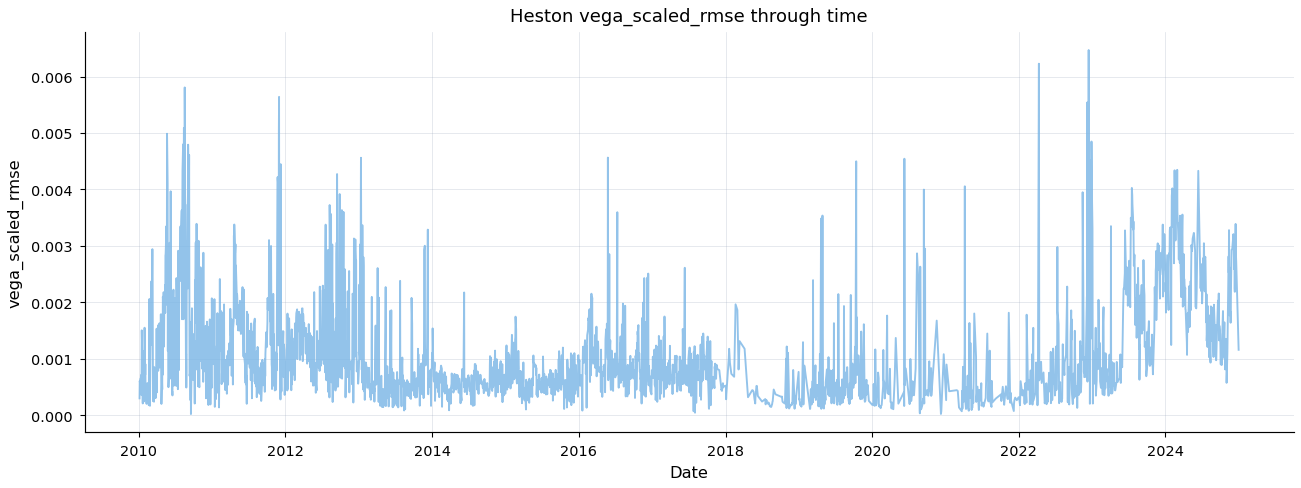

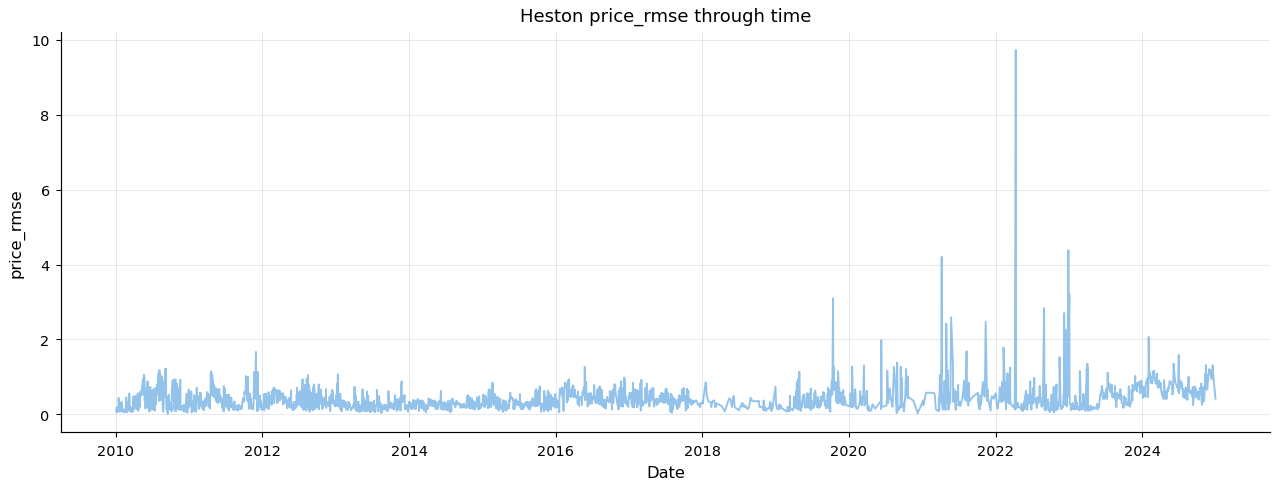

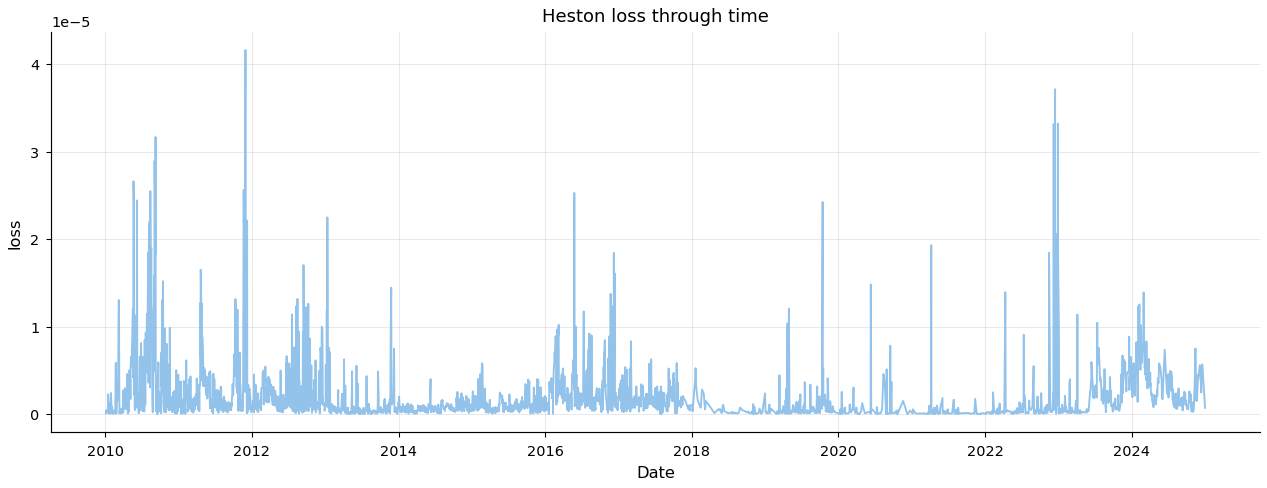

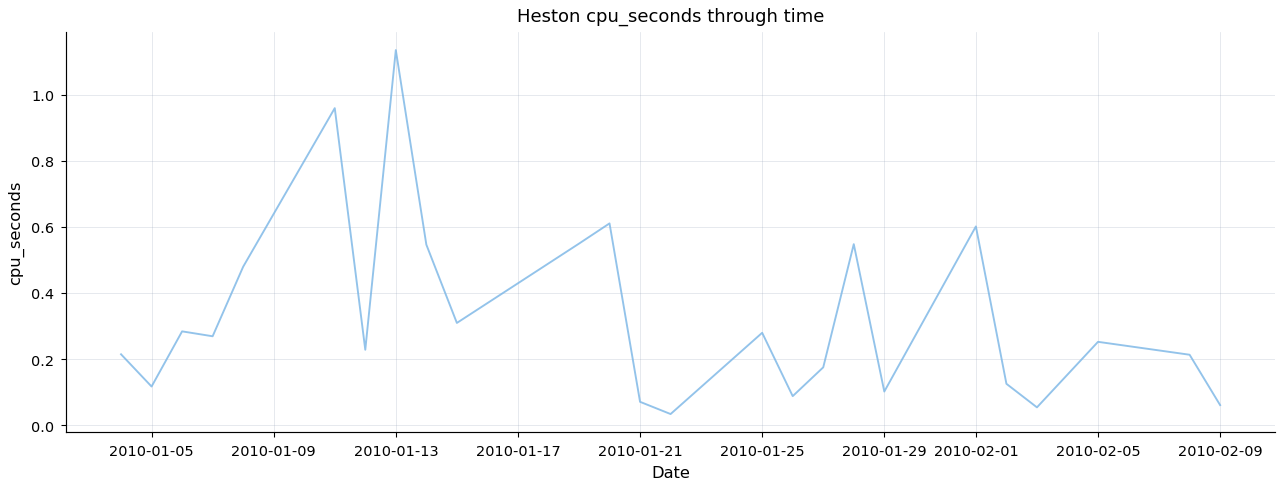

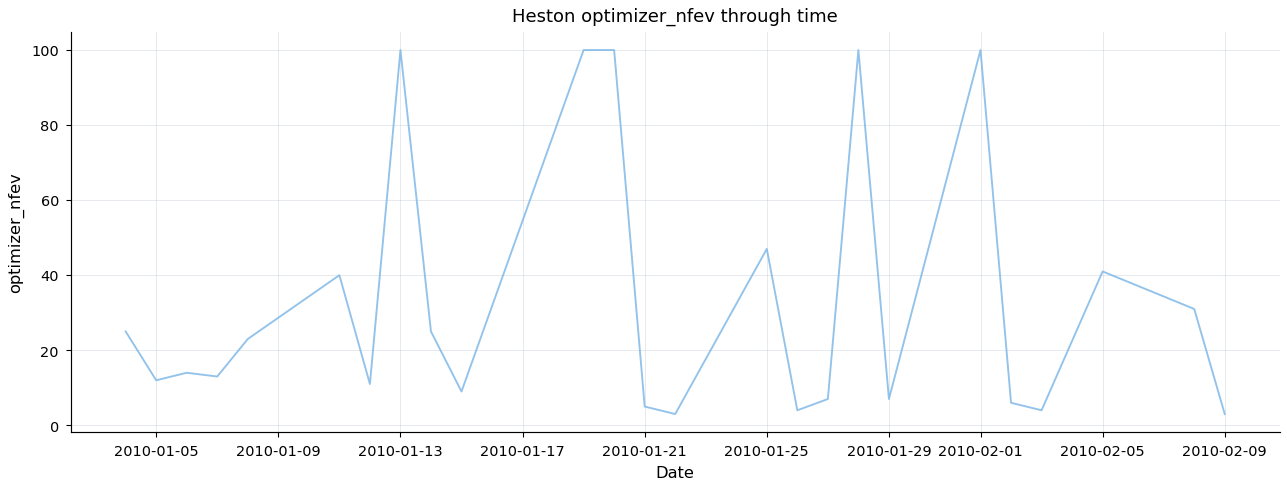

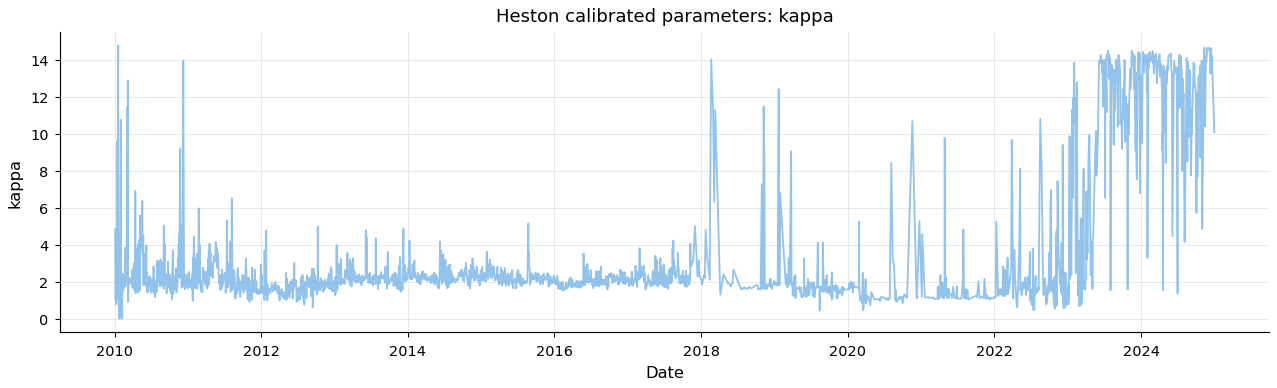

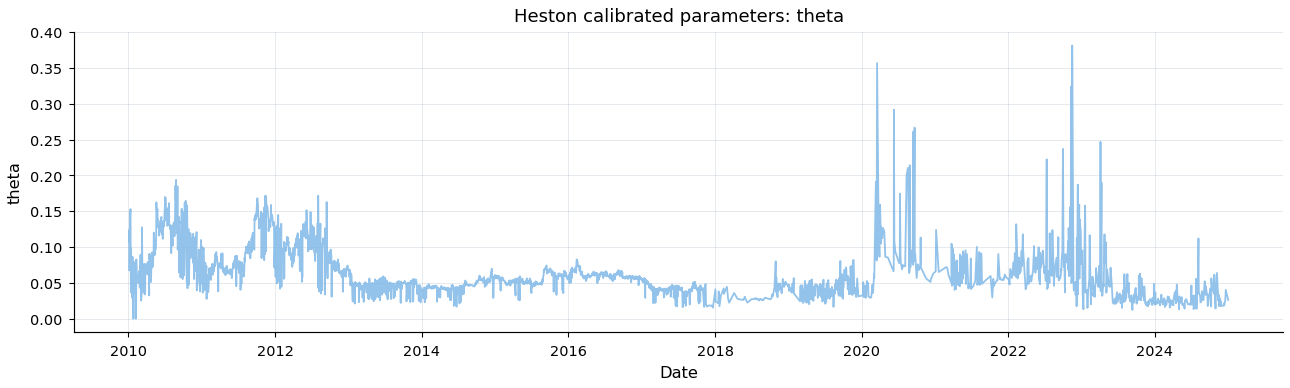

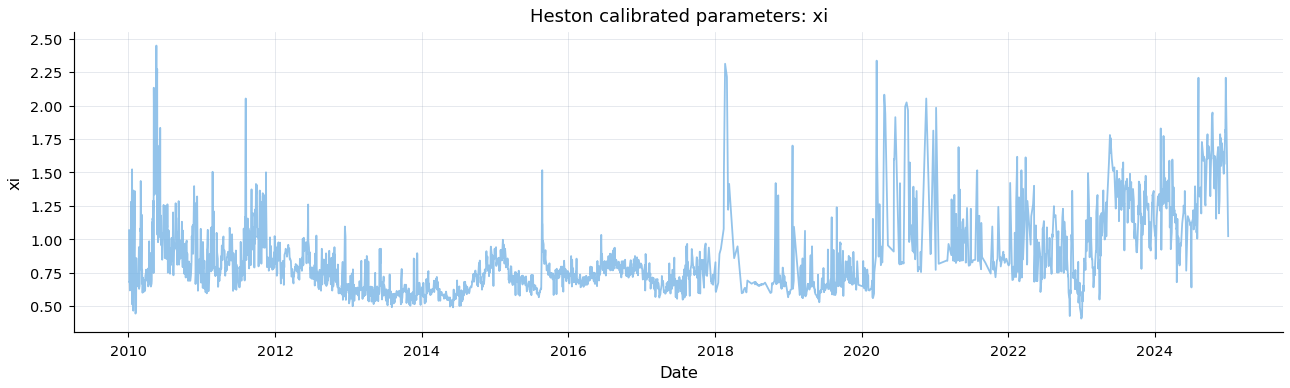

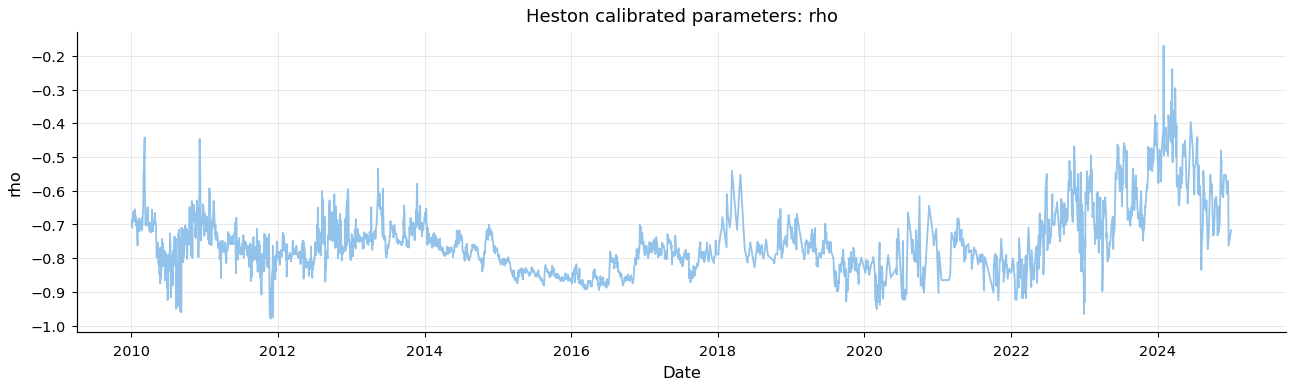

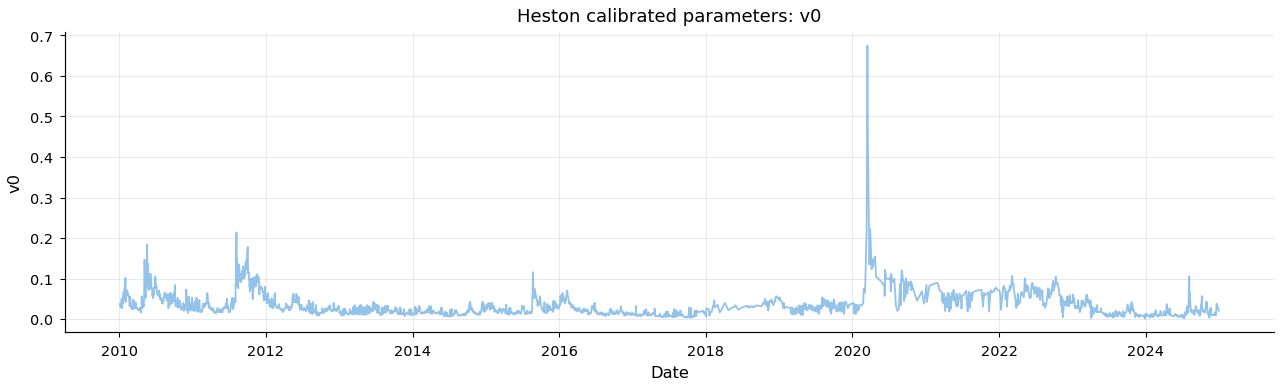

Loading validated Heston diagnostics: cache_final\heston_hedging_panel_fit_residuals.parquet

Overall Heston residual diagnostics:


C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\2103681777.py:117: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,metric,value
0,n,127078.000000
1,price_rmse,0.678474
2,price_mae,0.381862
3,vega_scaled_rmse,0.001102
4,vega_scaled_mae,0.000897



Heston residuals by maturity and moneyness:


,maturity_bucket,moneyness_bucket,n,mean_error,rmse,mae,p05,p50,p95
0,2W-1M,near_ATM_low,3375.0,-0.000277,0.002510,0.001857,-0.006266,0.000252,0.003317
1,2W-1M,ATM,6523.0,0.000083,0.001698,0.001136,-0.002467,0.000006,0.003296
2,2W-1M,near_ATM_high,1952.0,-0.000245,0.002833,0.002042,-0.006327,0.000155,0.004215
3,1M-2M,near_ATM_low,4152.0,-0.000731,0.002473,0.001996,-0.006793,0.000023,0.002492
4,1M-2M,ATM,8025.0,0.000076,0.001388,0.001035,-0.002243,0.000132,0.002193
5,1M-2M,near_ATM_high,2086.0,0.001087,0.002798,0.002269,-0.002761,0.000554,0.006538
6,2M-4M,near_ATM_low,5603.0,0.000473,0.001411,0.001096,-0.001598,0.000457,0.002848
7,2M-4M,ATM,5249.0,0.000391,0.001250,0.000936,-0.001366,0.000356,0.002287
8,2M-4M,near_ATM_high,5274.0,-0.000372,0.001465,0.001160,-0.002806,-0.000324,0.002013
9,4M-1Y,near_ATM_low,28060.0,-0.000180,0.000794,0.000614,-0.001471,-0.000155,0.001074


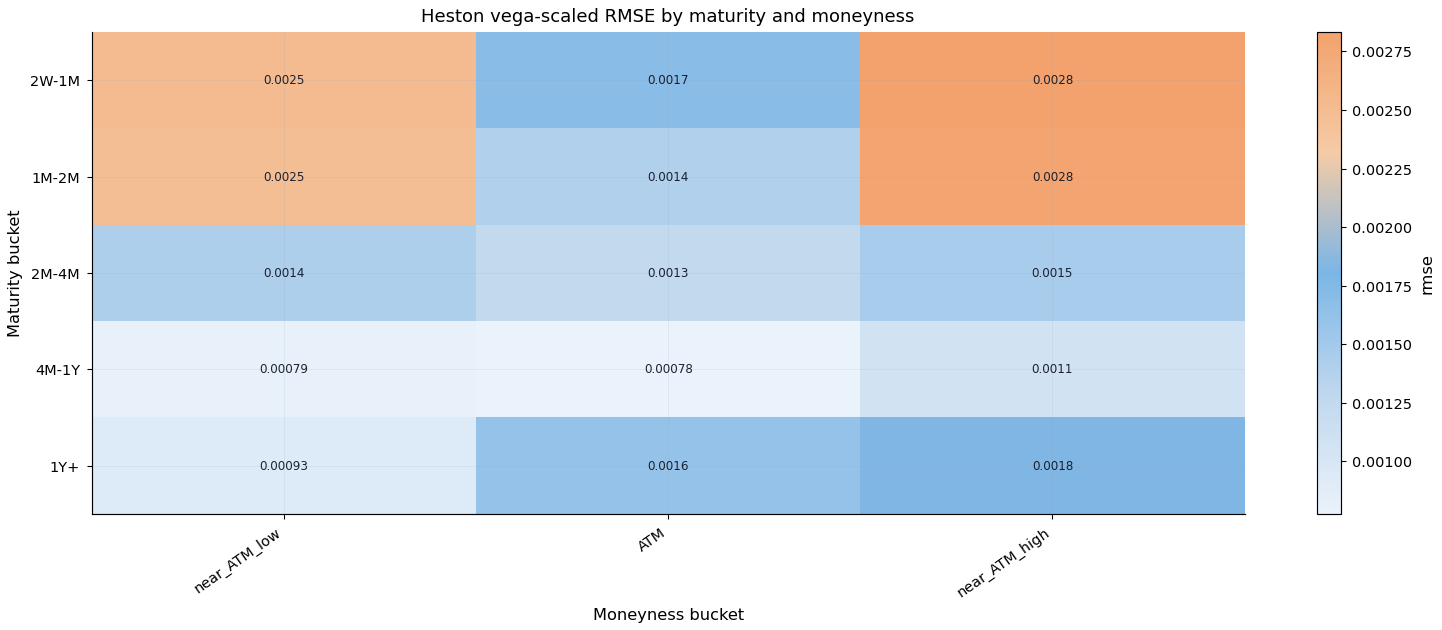


Worst 30 Heston dates by repriced vega-scaled RMSE:


,date,n,price_rmse,vega_scaled_rmse,mean_abs_error
2504,2022-12-15,143.0,2.265456,0.006058,1.690432
465,2011-11-30,38.0,1.664097,0.005622,1.328622
2499,2022-12-08,130.0,2.702884,0.005554,1.915101
464,2011-11-29,43.0,1.400401,0.004589,1.194610
2512,2022-12-29,155.0,4.383503,0.004573,3.193061
165,2010-09-03,28.0,1.205755,0.004393,0.932967
2163,2019-10-14,82.0,3.098998,0.004317,2.164015
167,2010-09-08,32.0,1.214620,0.004291,0.884604
150,2010-08-13,30.0,0.974400,0.004261,0.842123
2507,2022-12-20,176.0,1.888045,0.004122,1.631126


Worst Heston fit date: 2022-12-15 00:00:00


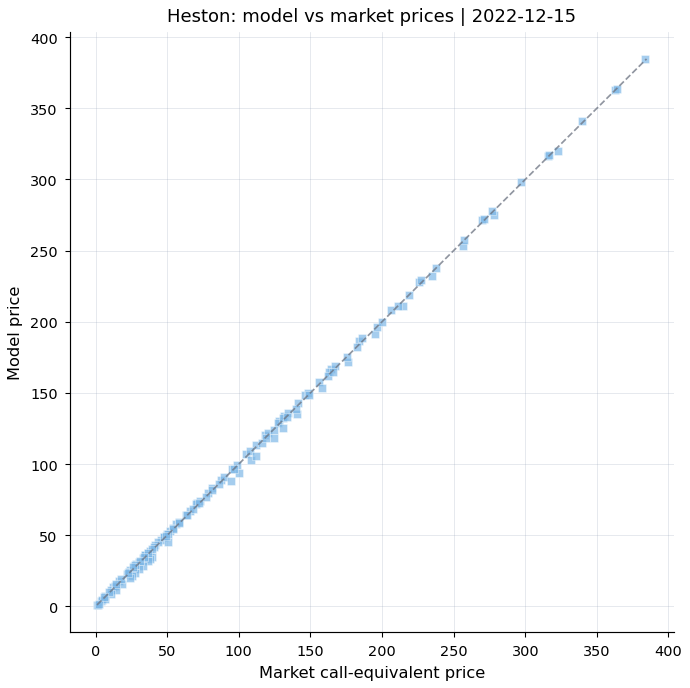

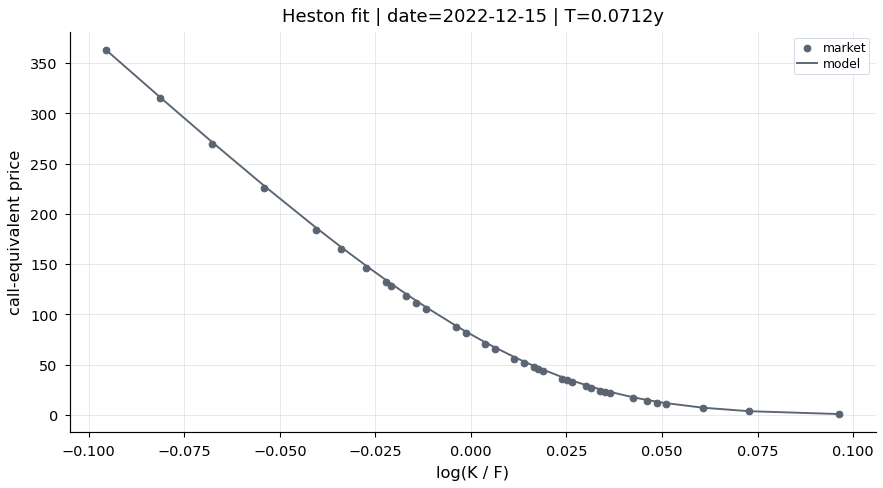

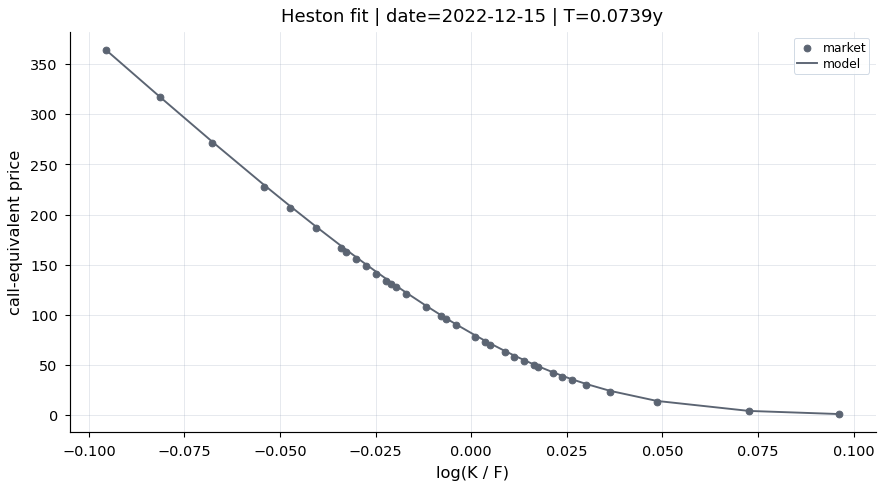

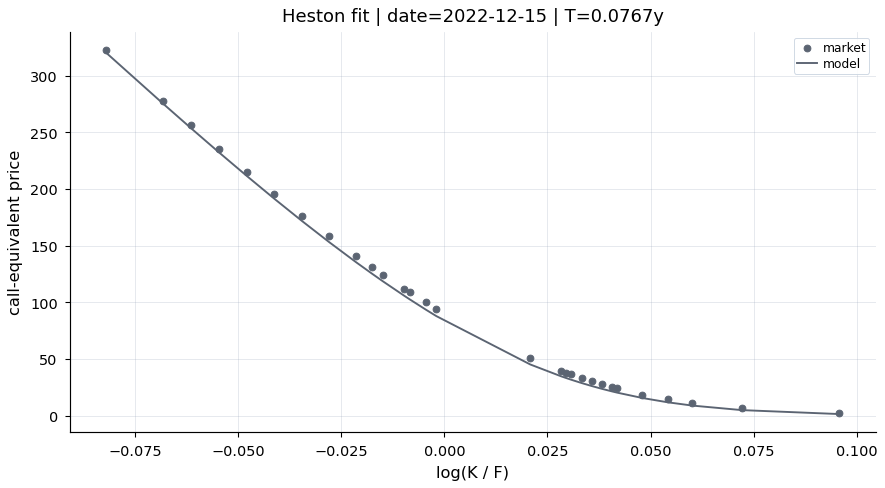

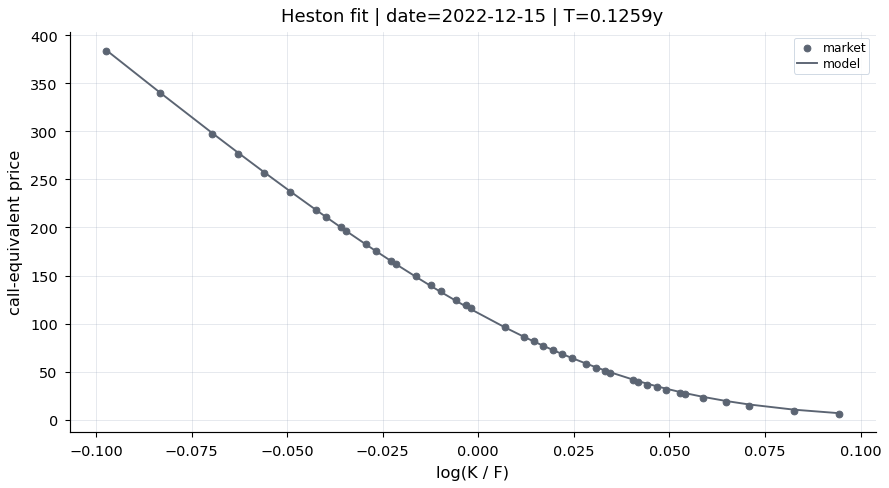

In [19]:

# ============================================================
# Section 4 fit inspection: Classical Heston
# ============================================================

HESTON_PARAM_COLS = ["kappa", "theta", "xi", "rho", "v0"]

summarise_calibration_panel(
    heston_calibration,
    model_name="Classical Heston",
    param_cols=HESTON_PARAM_COLS,
)

for metric in [c for c in ["vega_scaled_rmse", "price_rmse", "loss", "cpu_seconds", "optimizer_nfev"] if c in heston_calibration.columns]:
    plot_calibration_metric_time_series(
        heston_calibration,
        metric=metric,
        title=f"Heston {metric} through time",
        model_name="Heston",
    )

plot_parameter_time_series(
    heston_calibration,
    HESTON_PARAM_COLS,
    title="Heston calibrated parameters",
    model_name="Heston",
)


def enforce_surface_inspection_schema(surface: pd.DataFrame) -> pd.DataFrame:
    """Standardise deterministic derived fields; do not fabricate missing research data."""
    out = surface.copy()
    if "log_forward_moneyness" not in out.columns:
        if "log_moneyness" not in out.columns:
            raise ValueError("Surface must contain log_forward_moneyness or log_moneyness from parity-forward construction.")
        out["log_forward_moneyness"] = out["log_moneyness"].astype(float)

    required = [
        "date", "spot_ref", "forward_ref", "strike", "T", "r", "q",
        "call_equiv_mid", "bs_vega", "fit_weight", "log_forward_moneyness",
    ]
    missing = [c for c in required if c not in out.columns]
    if missing:
        raise ValueError(f"Surface is missing required inspection columns: {missing}")
    bad = (
        ~np.isfinite(out["forward_ref"].astype(float)) | (out["forward_ref"].astype(float) <= 0)
        | ~np.isfinite(out["strike"].astype(float)) | (out["strike"].astype(float) <= 0)
        | ~np.isfinite(out["spot_ref"].astype(float)) | (out["spot_ref"].astype(float) <= 0)
        | ~np.isfinite(out["log_forward_moneyness"].astype(float))
    )
    if bad.any():
        raise ValueError(f"Surface inspection schema found {int(bad.sum())} invalid rows.")
    return out


def build_heston_fit_residuals(surface: pd.DataFrame, calib: pd.DataFrame, cfg: ExperimentConfig, max_dates: int | None = None) -> pd.DataFrame:
    required_calib_cols = {"date", "kappa", "theta", "xi", "rho", "v0"}
    missing_calib = required_calib_cols - set(calib.columns)
    if missing_calib:
        raise ValueError(f"calib is missing required columns: {sorted(missing_calib)}")

    surface = _normalise_date_col(enforce_surface_inspection_schema(surface))
    calib = _normalise_date_col(calib)
    dates = sorted(set(surface["date"]).intersection(set(calib["date"])))
    if max_dates is not None:
        dates = dates[:max_dates]
    if not dates:
        raise ValueError("No overlapping dates between surface and Heston calibration.")

    pricer = HestonPricer(n_quad=cfg.calibration.heston_pricing_nodes)
    rows = []
    param_lookup = calib.set_index("date")[HESTON_PARAM_COLS].to_dict("index")
    for i, date in enumerate(dates, start=1):
        g = surface[surface["date"].eq(date)].copy()
        p = param_lookup[date]
        params = HestonParams(float(p["kappa"]), float(p["theta"]), float(p["xi"]), float(p["rho"]), float(p["v0"]))
        model_price = pricer.call_prices(
            S=g["spot_ref"].to_numpy(float),
            K=g["strike"].to_numpy(float),
            T=g["T"].to_numpy(float),
            r=g["r"].to_numpy(float),
            q=g["q"].to_numpy(float),
            params=params,
        )
        g["model_price"] = model_price
        g["price_error"] = g["model_price"] - g["call_equiv_mid"]
        g["vega_scaled_error"] = g["price_error"] / np.maximum(np.abs(g["bs_vega"].to_numpy(float)), cfg.calibration.vega_floor)
        g["abs_vega_scaled_error"] = np.abs(g["vega_scaled_error"])
        g["model_name"] = "heston"
        rows.append(g)
        if i % 250 == 0:
            print(f"Repriced Heston residuals for {i:,}/{len(dates):,} dates")
    out = pd.concat(rows, ignore_index=True)
    return out


def load_or_build_heston_diagnostics(surface: pd.DataFrame, calib: pd.DataFrame, cfg: ExperimentConfig) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    residual_path = cfg.paths.heston_fit_residuals_path
    bucket_path = cfg.paths.heston_bucket_summary_path
    deps = [cfg.paths.surface_cache_path, cfg.paths.heston_calibration_path]
    if not cfg.flags.RUN_HESTON_CALIBRATION:
        try:
            residuals = load_dataframe_cache(residual_path, "heston_fit_residuals", "heston", cfg, required_columns={"date", "model_price", "price_error", "vega_scaled_error"}, dependencies=deps)
            bucket = load_dataframe_cache(bucket_path, "heston_residual_bucket_summary", "heston", cfg, dependencies=[residual_path])
            print(f"Loading validated Heston diagnostics: {residual_path}")
        except (FileNotFoundError, ValueError) as exc:
            raise RuntimeError(
                "Heston residual diagnostic cache is missing or stale. Cached-evaluation mode will not reprice the panel. "
                "Run an explicit Heston calibration/diagnostic pass to regenerate it."
            ) from exc
    else:
        residuals = build_heston_fit_residuals(surface, calib, cfg)
        bucket = residual_bucket_table(residuals)
        write_dataframe_cache(residuals, residual_path, "heston_fit_residuals", "heston", cfg, dependencies=deps)
        write_dataframe_cache(bucket, bucket_path, "heston_residual_bucket_summary", "heston", cfg, dependencies=[residual_path])
    date_fit = (
        residuals.groupby("date")
        .apply(lambda g: pd.Series({
            "n": len(g),
            "price_rmse": weighted_rmse(g["price_error"]),
            "vega_scaled_rmse": weighted_rmse(g["vega_scaled_error"], g["fit_weight"]),
            "mean_abs_error": float(np.nanmean(np.abs(g["price_error"]))),
        }))
        .reset_index()
        .sort_values("vega_scaled_rmse", ascending=False)
    )
    return residuals, bucket, date_fit


surface_panel = enforce_surface_inspection_schema(surface_panel)
heston_fit_residuals, heston_bucket_summary, heston_date_fit = load_or_build_heston_diagnostics(surface_panel, heston_calibration, CFG)

print("\nOverall Heston residual diagnostics:")
display(pd.DataFrame({
    "metric": ["n", "price_rmse", "price_mae", "vega_scaled_rmse", "vega_scaled_mae"],
    "value": [
        len(heston_fit_residuals),
        weighted_rmse(heston_fit_residuals["price_error"]),
        float(np.nanmean(np.abs(heston_fit_residuals["price_error"]))),
        weighted_rmse(heston_fit_residuals["vega_scaled_error"], heston_fit_residuals["fit_weight"]),
        float(np.nanmean(np.abs(heston_fit_residuals["vega_scaled_error"]))),
    ],
}))

print("\nHeston residuals by maturity and moneyness:")
display(heston_bucket_summary)
plot_residual_heatmap(heston_bucket_summary, value_col="rmse", title="Heston vega-scaled RMSE by maturity and moneyness")

print("\nWorst 30 Heston dates by repriced vega-scaled RMSE:")
display(heston_date_fit.head(30))
worst_heston_date = heston_date_fit.iloc[0]["date"]
print(f"Worst Heston fit date: {worst_heston_date}")
plot_model_vs_market_scatter(heston_fit_residuals, model_name="Heston", date=worst_heston_date)
plot_smile_fit_for_date(heston_fit_residuals, model_name="Heston", date=worst_heston_date)


## 4.2 Lifted Heston

The lifted-Heston calibration extends the scalar Heston state into a finite-dimensional factor state. The aggregate variance is

$$
V_t=\sum_{i=1}^{N}c_iU_t^i,
$$

with factors associated with different mean-reversion speeds. In the dissertation narrative, this is the structural-memory model: it approximates rough-volatility behaviour while preserving finite-dimensional Markovian simulation.

The calibration task is delicate because lifted Heston has a richer state representation but should not be allowed to win merely by being more flexible on a different target set. The notebook therefore reports common-row comparisons, ATM-skew diagnostics, residual heatmaps and parameter-stability checks. These outputs answer whether the model is fitting the relevant option-market objects and whether the fitted states are stable enough to use in hedging experiments.

The lifted model should be interpreted as a finite-factor approximation, not as proof that the true SPX volatility process is rough. Livieri-style roughness evidence motivates fixed-$H$ sensitivity, while Abi Jaber's lifted construction motivates the exponential factor grid. Abi Jaber and Li's later critique motivates caution: rough or lifted dynamics may help selected short-maturity objects without dominating the global SPX smile.

This section therefore prepares evidence for a conditional claim: lifted Heston may add hedge-relevant volatility-memory information, but the value must be shown in terminal hedging performance and mechanism diagnostics.


In [20]:
@dataclass(frozen=True)
class LiftedKernelGrid:
    H: float
    alpha: float
    n_factors: int
    rn_scale: float
    lambdas: np.ndarray
    weights: np.ndarray
    grid: pd.DataFrame
    diagnostics: pd.DataFrame


@dataclass(frozen=True)
class LiftedHestonParams:
    kappa: float
    theta: float
    xi: float
    rho: float
    v0: float


def build_abi_zaugg_lifted_kernel(cfg: LiftedHestonConfig) -> LiftedKernelGrid:
    if not SCIPY_AVAILABLE:
        raise RuntimeError("SciPy is required for gamma() in lifted kernel construction.")
    H = float(cfg.H)
    alpha = H + 0.5
    N = int(cfg.n_factors)
    R_N = float(cfg.rn_scale)
    i = np.arange(1, N + 1, dtype=float)

    weights = (
        ((R_N ** (1.0 - alpha) - 1.0) * R_N ** ((alpha - 1.0) * (1.0 + N / 2.0)))
        / (gamma(alpha) * gamma(2.0 - alpha))
        * R_N ** ((1.0 - alpha) * i)
    )
    lambdas = (
        ((1.0 - alpha) * (R_N ** (2.0 - alpha) - 1.0))
        / ((2.0 - alpha) * (R_N ** (1.0 - alpha) - 1.0))
        * R_N ** (i - 1.0 - N / 2.0)
    )

    t_grid = np.geomspace(cfg.kernel_t_min, cfg.kernel_t_max, cfg.kernel_grid_size)
    rough_kernel = t_grid ** (alpha - 1.0) / gamma(alpha)
    lifted_kernel = np.exp(-np.outer(t_grid, lambdas)) @ weights
    diagnostics = pd.DataFrame({
        "t": t_grid,
        "rough_kernel": rough_kernel,
        "lifted_kernel": lifted_kernel,
        "abs_error": np.abs(lifted_kernel - rough_kernel),
        "rel_error": (lifted_kernel - rough_kernel) / rough_kernel,
        "abs_rel_error": np.abs((lifted_kernel - rough_kernel) / rough_kernel),
    })
    grid = pd.DataFrame({
        "factor": np.arange(1, N + 1),
        "lambda": lambdas,
        "weight": weights,
        "time_scale_years": 1.0 / lambdas,
        "time_scale_days": 365.25 / lambdas,
        "rn_scale": R_N,
        "H": H,
        "alpha": alpha,
    })
    return LiftedKernelGrid(H=H, alpha=alpha, n_factors=N, rn_scale=R_N, lambdas=lambdas, weights=weights, grid=grid, diagnostics=diagnostics)


lifted_kernel = build_abi_zaugg_lifted_kernel(CFG.lifted)
print("Validated lifted-Heston kernel configuration")
print({"H": lifted_kernel.H, "alpha": lifted_kernel.alpha, "N": lifted_kernel.n_factors, "r_N": lifted_kernel.rn_scale})
display(lifted_kernel.grid.head())
display(lifted_kernel.diagnostics.describe())

assert lifted_kernel.n_factors == 20
assert abs(lifted_kernel.rn_scale - 2.5) < 1e-12


Validated lifted-Heston kernel configuration
{'H': 0.35, 'alpha': 0.85, 'N': 20, 'r_N': 2.5}


,factor,lambda,weight,time_scale_years,time_scale_days,rn_scale,H,alpha
0,1,0.000173,0.035909,5765.832356,2.105970e+06,2.5,0.35,0.85
1,2,0.000434,0.041200,2306.332942,8.423881e+05,2.5,0.35,0.85
2,3,0.001084,0.047270,922.533177,3.369552e+05,2.5,0.35,0.85
3,4,0.002710,0.054235,369.013271,1.347821e+05,2.5,0.35,0.85
4,5,0.006775,0.062226,147.605308,5.391284e+04,2.5,0.35,0.85


,t,rough_kernel,lifted_kernel,abs_error,rel_error,abs_rel_error
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,0.304305,1.383416,1.131458,0.251958,-0.197027,0.197027
std,0.463203,0.392994,0.390653,0.002342,0.054277,0.054277
min,0.002738,0.810125,0.561580,0.248544,-0.306798,0.117843
25%,0.014234,1.037380,0.787474,0.249905,-0.240901,0.149226
50%,0.074000,1.328384,1.076755,0.251629,-0.189425,0.189425
75%,0.384709,1.701019,1.447184,0.253835,-0.149226,0.240901
max,2.000000,2.178186,1.921502,0.256684,-0.117843,0.306798


In [21]:
from types import SimpleNamespace


class LiftedCalibrationNumericalFailure(RuntimeError):
    """Raised when no finite lifted-Heston calibration candidate is available for a date."""
    pass

# -----------------------------------------------------------------------------
# Final lifted-Heston full-surface calibration
# Main specification: five calibrated Heston-style parameters with a regularised
# forward-variance input curve used for initialisation and deterministic-curve shape.
# One model convention is used for pricing, simulation and conditional model deltas.
# -----------------------------------------------------------------------------

LIFTED_CALIBRATION_BACKEND = "lifted_riccati_fourier_regularised_forward_curve_5p_final"

@dataclass(frozen=True)
class ForwardVarianceInputCurve:
    """Positive piecewise-constant forward-variance curve ξ₀(t).

    For the lifted model
        V_t = g₀(t) + Σ c_i U^i_t,
        dU^i_t = (-x_i U^i_t - κ V_t)dt + ξ√V_t dW_t,
        U^i_0 = 0,
    the deterministic input is
        g₀(t) = ξ₀(t) + κ Σ c_i ∫₀ᵗ exp(-x_i(t-s)) ξ₀(s) ds.
    This makes E[V_t] = ξ₀(t), matching the methodology's regularised near-ATM forward-variance proxy.
    """

    maturities: np.ndarray
    forward_variances: np.ndarray

    @classmethod
    def from_frame(cls, frame: pd.DataFrame) -> "ForwardVarianceInputCurve":
        require_columns(frame, {"T", "forward_variance"}, "Forward-variance input curve")
        g = frame[["T", "forward_variance"]].copy().sort_values("T").drop_duplicates("T")
        T = g["T"].to_numpy(float)
        xi0 = g["forward_variance"].to_numpy(float)
        if len(T) < 2 or np.any(np.diff(T) <= 0):
            raise ValueError("Forward-variance input curve requires at least two strictly increasing maturities.")
        if np.any(~np.isfinite(xi0)) or np.any(xi0 <= 0):
            raise ValueError("Forward-variance input curve must be finite and positive.")
        return cls(T, xi0)

    @property
    def max_maturity(self) -> float:
        return float(self.maturities[-1])

    def xi0(self, t: np.ndarray | float) -> np.ndarray | float:
        arr = np.asarray(t, dtype=float)
        if np.any(arr < -1e-12):
            raise ValueError("Forward variance cannot be evaluated at negative time.")
        idx = np.searchsorted(self.maturities, np.maximum(arr, 0.0), side="left")
        idx = np.clip(idx, 0, len(self.maturities) - 1)
        out = self.forward_variances[idx]
        return float(out) if arr.ndim == 0 else out

    def exponential_convolution(self, t: np.ndarray | float, lambdas: np.ndarray) -> np.ndarray:
        """Exact convolution of the piecewise-constant ξ₀ with exp(-x(t-s))."""
        scalar = np.asarray(t).ndim == 0
        times = np.atleast_1d(np.asarray(t, dtype=float))
        x = np.asarray(lambdas, dtype=float).reshape(-1)
        if np.any(times < -1e-12) or np.any(x < 0):
            raise ValueError("Invalid convolution inputs.")
        bounds = np.concatenate([[0.0], self.maturities])
        out = np.zeros((len(times), len(x)), dtype=float)
        for k, tt in enumerate(times):
            tt = max(float(tt), 0.0)
            for m, xi_m in enumerate(self.forward_variances):
                a = float(bounds[m])
                b = min(float(bounds[m + 1]), tt)
                if b > a:
                    zero = x < 1e-14
                    integ = np.empty_like(x)
                    integ[zero] = b - a
                    integ[~zero] = (
                        np.exp(-x[~zero] * (tt - b)) - np.exp(-x[~zero] * (tt - a))
                    ) / x[~zero]
                    out[k] += float(xi_m) * integ
                if bounds[m + 1] >= tt:
                    break
            if tt > self.maturities[-1]:
                a = float(self.maturities[-1])
                b = tt
                zero = x < 1e-14
                integ = np.empty_like(x)
                integ[zero] = b - a
                integ[~zero] = (1.0 - np.exp(-x[~zero] * (b - a))) / x[~zero]
                out[k] += float(self.forward_variances[-1]) * integ
        return out[0] if scalar else out

    def g0(self, t: np.ndarray | float, kappa: float, kernel: LiftedKernelGrid) -> np.ndarray | float:
        conv = self.exponential_convolution(t, kernel.lambdas)
        deterministic = self.xi0(t) + float(kappa) * np.sum(conv * kernel.weights, axis=-1)
        if np.any(~np.isfinite(deterministic)) or np.any(np.asarray(deterministic) <= 0):
            raise FloatingPointError("Lifted deterministic input g0 is non-positive or non-finite.")
        return deterministic

    def with_endpoint_levels(self, v0: float, theta: float) -> "ForwardVarianceInputCurve":
        v0 = float(v0)
        theta = float(theta)
        if not np.isfinite(v0) or not np.isfinite(theta) or v0 <= 0.0 or theta <= 0.0:
            raise ValueError("Calibrated lifted curve endpoint levels must be finite and positive.")
        base = np.asarray(self.forward_variances, dtype=float)
        T = np.asarray(self.maturities, dtype=float)
        base0 = float(base[0])
        baseT = float(base[-1])
        if abs(baseT - base0) > 1e-10:
            adjusted = v0 + (base - base0) * ((theta - v0) / (baseT - base0))
        else:
            span = max(float(T[-1] - T[0]), 1e-12)
            adjusted = v0 + (theta - v0) * ((T - T[0]) / span)
        if np.any(~np.isfinite(adjusted)) or np.any(adjusted <= 0.0):
            raise ValueError("Calibrated lifted curve endpoint transform produced non-positive forward variances.")
        return ForwardVarianceInputCurve(T.copy(), adjusted)


@dataclass(frozen=True)
class LiftedCalibrationResult:
    date: pd.Timestamp
    profile: str
    params: LiftedHestonParams
    loss: float
    fit_table: pd.DataFrame
    timing: dict[str, Any]
    optimizer: dict[str, Any]


class LiftedRiccatiFourierPricer:
    """Abi-Jaber finite-factor Riccati/Fourier pricer with deterministic g₀ input."""

    def __init__(
        self,
        kernel: LiftedKernelGrid,
        n_quad: int = 64,
        riccati_steps: int = 160,
        delta_cache_size: int = 4096,
    ):
        self.kernel = kernel
        self.nodes, self.quad_weights = np.polynomial.laguerre.laggauss(int(n_quad))
        self.riccati_steps = int(riccati_steps)
        self.lambdas = np.asarray(kernel.lambdas, dtype=float)
        self.weights = np.asarray(kernel.weights, dtype=float)
        self._delta_coefficient_cache: dict[tuple[Any, ...], tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]] = {}
        self.delta_cache_size = int(delta_cache_size)
        if self.delta_cache_size < 1:
            raise ValueError("delta_cache_size must be positive.")
        if self.riccati_steps < 16:
            raise ValueError("riccati_steps must be at least 16.")

    @staticmethod
    def _F(z: np.ndarray, aggregate_psi: np.ndarray, params: LiftedHestonParams) -> np.ndarray:
        """Lifted Riccati forcing with explicit overflow/invalid checks.

        Invalid parameter candidates are common during nonlinear calibration. They
        must be rejected by the objective, not allowed to leak RuntimeWarnings and
        crash the final pricing pass. This is a numeric guard, not a substitute
        pricing model.
        """
        z = np.asarray(z, dtype=np.complex128)
        aggregate_psi = np.asarray(aggregate_psi, dtype=np.complex128)
        try:
            with np.errstate(over="raise", invalid="raise", divide="raise"):
                out = (
                    0.5 * (z ** 2 - z)
                    + (params.rho * params.xi * z - params.kappa) * aggregate_psi
                    + 0.5 * params.xi ** 2 * aggregate_psi ** 2
                )
        except FloatingPointError as exc:
            raise FloatingPointError("Lifted Riccati forcing overflow/invalid value.") from exc
        if np.any(~np.isfinite(out.real)) or np.any(~np.isfinite(out.imag)):
            raise FloatingPointError("Lifted Riccati forcing produced non-finite values.")
        return out

    @staticmethod
    def _phi1(a: np.ndarray) -> np.ndarray:
        """Stable (1-exp(-a))/a used by the exponential Riccati integrator."""
        a = np.asarray(a, dtype=float)
        out = np.empty_like(a)
        small = np.abs(a) < 1e-8
        out[small] = 1.0 - 0.5 * a[small] + a[small] ** 2 / 6.0
        out[~small] = -np.expm1(-a[~small]) / a[~small]
        return out

    def _coefficients(
        self,
        z: np.ndarray,
        tau: float,
        current_time: float,
        params: LiftedHestonParams,
        curve: ForwardVarianceInputCurve,
    ) -> tuple[np.ndarray, np.ndarray]:
        """Solve the stiff lifted Riccati system with exponential midpoint steps.

        The factor grid contains decay rates spanning several orders of magnitude.
        Treating ``-x_i psi_i`` exactly avoids the stability failure of explicit
        RK schemes while retaining the common nonlinear Riccati forcing.
        """
        z = np.atleast_1d(np.asarray(z, dtype=np.complex128))
        psi = np.zeros((len(z), self.kernel.n_factors), dtype=np.complex128)
        phi = np.zeros(len(z), dtype=np.complex128)
        if tau <= 0:
            return phi, psi
        h = float(tau) / self.riccati_steps
        xh = self.lambdas * h
        decay_full = np.exp(-xh).reshape(1, -1)
        decay_half = np.exp(-0.5 * xh).reshape(1, -1)
        force_full = (h * self._phi1(xh)).reshape(1, -1)
        force_half = (0.5 * h * self._phi1(0.5 * xh)).reshape(1, -1)
        c = self.weights
        riccati_abs_cap = 1e8
        for step in range(self.riccati_steps):
            s = step * h
            aggregate = psi @ c
            if np.any(~np.isfinite(aggregate.real)) or np.any(~np.isfinite(aggregate.imag)) or np.max(np.abs(aggregate)) > riccati_abs_cap:
                raise FloatingPointError("Lifted Riccati aggregate exploded before midpoint step.")
            f0 = self._F(z, aggregate, params)
            psi_half = decay_half * psi + force_half * f0.reshape(-1, 1)
            aggregate_half = psi_half @ c
            if np.any(~np.isfinite(aggregate_half.real)) or np.any(~np.isfinite(aggregate_half.imag)) or np.max(np.abs(aggregate_half)) > riccati_abs_cap:
                raise FloatingPointError("Lifted Riccati aggregate exploded at midpoint step.")
            f_half = self._F(z, aggregate_half, params)
            psi = decay_full * psi + force_full * f_half.reshape(-1, 1)
            g_mid = float(curve.g0(current_time + tau - (s + 0.5 * h), params.kappa, self.kernel))
            phi += h * f_half * g_mid
            if not all(np.all(np.isfinite(v)) for v in [psi.real, psi.imag, phi.real, phi.imag]):
                raise FloatingPointError("Non-finite lifted Riccati state encountered.")
        return phi, psi

    def characteristic_state_batch(
        self,
        u: np.ndarray,
        S: np.ndarray,
        tau: float,
        r: float,
        q: float,
        params: LiftedHestonParams,
        curve: ForwardVarianceInputCurve,
        U: np.ndarray,
        current_time: float,
    ) -> np.ndarray:
        """Characteristic function for many current states and common remaining maturity."""
        u = np.atleast_1d(np.asarray(u, dtype=np.complex128))
        S = np.asarray(S, dtype=float).reshape(-1)
        U = np.asarray(U, dtype=float)
        if U.shape != (len(S), self.kernel.n_factors):
            raise ValueError("Lifted state matrix U has incompatible shape.")
        z = 1j * u
        phi, psi = self._coefficients(z, tau, current_time, params, curve)
        state_loading = psi * self.weights.reshape(1, -1)
        exponent = (
            np.outer(np.log(S) + (float(r) - float(q)) * tau, z)
            + phi.reshape(1, -1)
            + U @ state_loading.T
        )
        out = np.exp(exponent)
        if not all(np.all(np.isfinite(v)) for v in [out.real, out.imag]):
            raise FloatingPointError("Non-finite lifted characteristic values.")
        return out

    def probabilities_state_batch(
        self,
        S: np.ndarray,
        K: float,
        tau: float,
        r: float,
        q: float,
        params: LiftedHestonParams,
        curve: ForwardVarianceInputCurve,
        U: np.ndarray,
        current_time: float = 0.0,
    ) -> tuple[np.ndarray, np.ndarray]:
        """Compute P1 and P2 from one combined Riccati solve."""
        S = np.asarray(S, dtype=float).reshape(-1)
        U = np.asarray(U, dtype=float)
        if U.shape != (len(S), self.kernel.n_factors):
            raise ValueError("Lifted state matrix U has incompatible shape.")
        if tau <= 1e-10:
            p = np.where(S > K, 1.0, np.where(S < K, 0.0, 0.5))
            return p, p
        u = self.nodes.astype(np.complex128)
        z = np.concatenate([np.array([1.0 + 0.0j]), 1.0 + 1j * u, 1j * u])
        phi, psi = self._coefficients(z, tau, current_time, params, curve)
        state_loading = psi * self.weights.reshape(1, -1)
        x = np.log(S) + (float(r) - float(q)) * tau
        cf = np.exp(np.outer(x, z) + phi.reshape(1, -1) + U @ state_loading.T)
        denominator = cf[:, 0]
        if np.any(np.abs(denominator) < 1e-14):
            raise FloatingPointError("Lifted P1 denominator is numerically zero.")
        n = len(u)
        phi1 = cf[:, 1:1+n] / denominator[:, None]
        phi2 = cf[:, 1+n:]
        kernel_term = np.exp(-1j * u * math.log(float(K))) / (1j * u)
        quadrature = self.quad_weights * np.exp(self.nodes)
        P1 = 0.5 + np.real(phi1 * kernel_term.reshape(1, -1)) @ quadrature / np.pi
        P2 = 0.5 + np.real(phi2 * kernel_term.reshape(1, -1)) @ quadrature / np.pi
        tol = 3e-3
        if np.any(~np.isfinite(P1)) or np.any(~np.isfinite(P2)) or np.any(P1 < -tol) or np.any(P1 > 1 + tol) or np.any(P2 < -tol) or np.any(P2 > 1 + tol):
            raise FloatingPointError("Lifted Fourier probabilities violate probability bounds.")
        return P1, P2

    def _delta_coefficients(
        self,
        tau: float,
        current_time: float,
        params: LiftedHestonParams,
        curve: ForwardVarianceInputCurve,
    ) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:
        """Cache state-independent Riccati coefficients used by pathwise model delta."""
        key = (
            round(float(tau), 12), round(float(current_time), 12),
            *(round(float(v), 12) for v in (params.kappa, params.theta, params.xi, params.rho, params.v0)),
            tuple(np.round(curve.maturities, 12)),
            tuple(np.round(curve.forward_variances, 12)),
        )
        cached = self._delta_coefficient_cache.get(key)
        if cached is not None:
            return cached
        u = self.nodes.astype(np.complex128)
        z = np.concatenate([np.array([1.0 + 0.0j]), 1.0 + 1j * u])
        phi, psi = self._coefficients(z, tau, current_time, params, curve)
        value = (phi[:1], psi[:1], phi[1:], psi[1:])
        if len(self._delta_coefficient_cache) >= self.delta_cache_size:
            self._delta_coefficient_cache.pop(next(iter(self._delta_coefficient_cache)))
        self._delta_coefficient_cache[key] = value
        return value

    def call_prices_slice(
        self,
        S: float,
        strikes: np.ndarray,
        tau: float,
        r: float,
        q: float,
        params: LiftedHestonParams,
        curve: ForwardVarianceInputCurve,
    ) -> np.ndarray:
        """Price all strikes for one expiry from one combined Riccati solve."""
        K = np.asarray(strikes, dtype=float).reshape(-1)
        if np.any(K <= 0) or S <= 0:
            raise ValueError("Spot and strikes must be positive.")
        if tau <= 1e-10:
            return np.maximum(float(S) - K, 0.0)
        u = self.nodes.astype(np.complex128)
        z = np.concatenate([np.array([1.0 + 0.0j]), 1.0 + 1j * u, 1j * u])
        phi, _ = self._coefficients(z, tau, 0.0, params, curve)
        x = math.log(float(S)) + (float(r) - float(q)) * tau
        cf = np.exp(x * z + phi)
        denominator = cf[0]
        if abs(denominator) < 1e-14:
            raise FloatingPointError("Lifted P1 denominator is numerically zero.")
        n = len(u)
        phi1 = cf[1:1+n] / denominator
        phi2 = cf[1+n:]
        fourier_kernel = np.exp(-1j * np.outer(np.log(K), u)) / (1j * u.reshape(1, -1))
        quadrature = self.quad_weights * np.exp(self.nodes)
        P1 = 0.5 + np.real(fourier_kernel * phi1.reshape(1, -1)) @ quadrature / np.pi
        P2 = 0.5 + np.real(fourier_kernel * phi2.reshape(1, -1)) @ quadrature / np.pi
        tolerance = 3e-3
        if np.any(P1 < -tolerance) or np.any(P1 > 1.0 + tolerance) or np.any(P2 < -tolerance) or np.any(P2 > 1.0 + tolerance):
            raise FloatingPointError("Lifted Fourier probabilities violate numerical bounds.")
        price = float(S) * math.exp(-float(q) * tau) * P1 - K * math.exp(-float(r) * tau) * P2
        lower = np.maximum(float(S) * math.exp(-float(q) * tau) - K * math.exp(-float(r) * tau), 0.0)
        upper = float(S) * math.exp(-float(q) * tau)
        price_tolerance = 3e-3 * max(1.0, upper)  # coherent with Fourier probability tolerance; numeric quadrature guard, not pricing substitute
        if np.any(~np.isfinite(price)) or np.any(price < lower - price_tolerance) or np.any(price > upper + price_tolerance):
            raise FloatingPointError("Lifted calls violate no-arbitrage price bounds.")
        return np.asarray(price, dtype=float)

    def call_price_one(self, S: float, K: float, T: float, r: float, q: float, params: LiftedHestonParams, curve: ForwardVarianceInputCurve) -> float:
        return float(self.call_prices_slice(S, np.array([K]), T, r, q, params, curve)[0])

    def call_prices(self, S, K, T, r, q, params: LiftedHestonParams, curve: ForwardVarianceInputCurve) -> np.ndarray:
        arrays = [np.asarray(v, dtype=float).reshape(-1) for v in (S, K, T, r, q)]
        n = len(arrays[1])
        if any(len(v) != n for v in arrays):
            raise ValueError("Lifted pricing arrays must have equal length.")
        output = np.empty(n, dtype=float)
        groups: dict[tuple[float, float, float, float], list[int]] = {}
        for i in range(n):
            key = (float(arrays[0][i]), float(arrays[2][i]), float(arrays[3][i]), float(arrays[4][i]))
            groups.setdefault(key, []).append(i)
        for (spot, maturity, rate, dividend), indices in groups.items():
            idx = np.asarray(indices, dtype=int)
            output[idx] = self.call_prices_slice(spot, arrays[1][idx], maturity, rate, dividend, params, curve)
        return output

    def call_delta_state_batch(self, S: np.ndarray, K: float, tau: float, r: float, q: float, params: LiftedHestonParams, curve: ForwardVarianceInputCurve, U: np.ndarray, current_time: float) -> np.ndarray:
        """Pathwise call delta from the lifted Riccati/Fourier P1 coefficient.

        Raw Fourier probabilities are not used as a hard validation gate here. The
        model-delta policy applies the final finite/no-arbitrage delta gate after
        analytic evaluation and same-model price finite-difference recovery.
        """
        S = np.asarray(S, dtype=float).reshape(-1)
        U = np.asarray(U, dtype=float)
        if U.shape != (len(S), self.kernel.n_factors):
            raise ValueError("Lifted state matrix U has incompatible shape.")
        if tau <= 1e-10:
            return np.where(S > K, 1.0, np.where(S < K, 0.0, 0.5))
        phi_den, psi_den, phi_num, psi_num = self._delta_coefficients(tau, current_time, params, curve)
        x = np.log(S) + (float(r) - float(q)) * tau
        den_loading = psi_den * self.weights.reshape(1, -1)
        num_loading = psi_num * self.weights.reshape(1, -1)
        denominator = np.exp(x + phi_den[0] + U @ den_loading[0])
        if np.any(np.abs(denominator) < 1e-14):
            raise FloatingPointError("Lifted P1 denominator is numerically zero.")
        u = self.nodes.astype(np.complex128)
        z_num = 1.0 + 1j * u
        numerator = np.exp(np.outer(x, z_num) + phi_num.reshape(1, -1) + U @ num_loading.T)
        phi1 = numerator / denominator[:, None]
        kernel_term = np.exp(-1j * u * math.log(float(K))) / (1j * u)
        quadrature = self.quad_weights * np.exp(self.nodes)
        P1 = 0.5 + np.real(phi1 * kernel_term.reshape(1, -1)) @ quadrature / np.pi
        if np.any(~np.isfinite(P1)):
            raise FloatingPointError("Lifted P1 is non-finite.")
        return math.exp(-float(q) * max(float(tau), 0.0)) * P1

def lifted_calibration_parameter_names(cfg: ExperimentConfig) -> tuple[str, ...]:
    mode = getattr(cfg.lifted, "calibration_parameterization", "full_5p_forward_curve_init")
    if mode == "full_5p_forward_curve_init":
        return ("kappa", "theta", "xi", "rho", "v0")
    raise ValueError(f"Unknown lifted calibration parameterization: {mode!r}")


def effective_lifted_curve(base_curve: ForwardVarianceInputCurve, params: LiftedHestonParams, cfg: ExperimentConfig | None = None) -> ForwardVarianceInputCurve:
    """Return the deterministic input curve used by pricing, simulation and deltas.

    Final specification: keep the regularised forward-variance curve shape, then
    let calibrated v0 and theta set the short- and long-end levels. This keeps the
    smoothed forward-variance information without forcing the five-parameter
    reduction used in the paper's narrower ATM-skew illustration.
    """
    mode = getattr(cfg.lifted, "calibration_parameterization", "full_5p_forward_curve_init") if cfg is not None else "full_5p_forward_curve_init"
    if mode == "full_5p_forward_curve_init":
        return base_curve.with_endpoint_levels(params.v0, params.theta)
    raise ValueError(f"Unknown lifted calibration parameterization: {mode!r}")

# Final lifted specification audit after parameter-name helper is available.
lifted_specification_audit = pd.DataFrame([{
    "audit_item": "factor count and grid",
    "notebook_setting": f"N={CFG.lifted.n_factors}, rN={CFG.lifted.rn_scale}",
    "status": "PASS" if int(CFG.lifted.n_factors) == 20 and np.isclose(float(CFG.lifted.rn_scale), 2.5) else "REVIEW",
}, {
    "audit_item": "calibration degrees of freedom",
    "notebook_setting": f"{CFG.lifted.calibration_parameterization}: {', '.join(lifted_calibration_parameter_names(CFG))}",
    "status": "PASS" if lifted_calibration_parameter_names(CFG) == ("kappa", "theta", "xi", "rho", "v0") else "REVIEW",
}, {
    "audit_item": "forward-variance smoothing",
    "notebook_setting": "regularised near-ATM xi0 curve shapes lifted deterministic input and initialises endpoint levels",
    "status": "PASS",
}, {
    "audit_item": "roughness handling",
    "notebook_setting": f"fixed H={CFG.lifted.H}; N=20 lifted Markovian approximation",
    "status": "PASS",
}])
display(lifted_specification_audit)


class LiftedHestonCalibrator:
    def __init__(self, pricer: LiftedRiccatiFourierPricer, cfg: ExperimentConfig, curve: ForwardVarianceInputCurve):
        self.pricer = pricer
        self.cfg = cfg
        self.curve = curve
        self.param_names = lifted_calibration_parameter_names(cfg)
        self.lower = np.array([cfg.calibration.heston_bounds[name][0] for name in self.param_names], dtype=float)
        self.upper = np.array([cfg.calibration.heston_bounds[name][1] for name in self.param_names], dtype=float)
        self._invalid_eval_count = 0
        self._last_invalid_reason = ""
        self._start_count = 0
        self._valid_start_count = 0

    def _params(self, x: np.ndarray) -> LiftedHestonParams:
        x = np.asarray(x, dtype=float)
        if x.shape != (len(self.param_names),):
            raise ValueError("Lifted candidate has wrong parameter dimension.")
        values = dict(zip(self.param_names, map(float, x)))
        values.setdefault("theta", float(self.curve.forward_variances[-1]))
        values.setdefault("v0", float(self.curve.xi0(0.0)))
        return LiftedHestonParams(float(values["kappa"]), float(values["theta"]), float(values["xi"]), float(values["rho"]), float(values["v0"]))

    def _priced_candidate(self, x: np.ndarray, target: HestonMarketTarget) -> tuple[LiftedHestonParams, np.ndarray, np.ndarray, float]:
        x = np.asarray(x, dtype=float)
        if x.shape != (len(self.param_names),) or np.any(~np.isfinite(x)) or np.any(x < self.lower) or np.any(x > self.upper):
            raise ValueError("Lifted candidate is outside parameter bounds or non-finite.")
        params = self._params(x)
        curve = effective_lifted_curve(self.curve, params, self.cfg)
        model = self.pricer.call_prices(target.S, target.K, target.T, target.r, target.q, params, curve)
        if np.any(~np.isfinite(model)):
            raise FloatingPointError("Lifted pricing produced non-finite model prices.")
        denom = np.maximum(np.abs(target.vegas), self.cfg.lifted.calibration_vega_floor)
        vega_error = (model - target.market_prices) / denom
        if np.any(~np.isfinite(vega_error)):
            raise FloatingPointError("Lifted vega-scaled residuals are non-finite.")
        loss = float(np.average(vega_error ** 2, weights=target.weights))
        if not np.isfinite(loss):
            raise FloatingPointError("Lifted candidate loss is non-finite.")
        return params, model, vega_error, loss


    def _initial_candidate_grid(self, heston_initial: HestonParams) -> list[np.ndarray]:
        curve_v0 = float(self.curve.xi0(0.0))
        curve_theta = float(self.curve.forward_variances[-1])
        if self.param_names == ("kappa", "theta", "xi", "rho", "v0"):
            raw = [
                np.array([heston_initial.kappa, heston_initial.theta, heston_initial.xi, heston_initial.rho, heston_initial.v0], dtype=float),
                np.array([heston_initial.kappa, curve_theta, min(heston_initial.xi, 0.35), np.clip(heston_initial.rho, -0.75, -0.05), curve_v0]),
                np.array([1.0, curve_theta, 0.25, -0.50, curve_v0]),
                np.array([0.5, curve_theta, 0.15, -0.25, curve_v0]),
                np.array([2.0, curve_theta, 0.20, -0.70, curve_v0]),
                np.array([5.0, curve_theta, 0.10, -0.50, curve_v0]),
            ]
        else:
            base = np.array([heston_initial.kappa, heston_initial.xi, heston_initial.rho], dtype=float)
            raw = [base, np.array([base[0], min(base[1], 0.35), np.clip(base[2], -0.75, -0.05)]), np.array([1.0, 0.25, -0.50]), np.array([0.5, 0.15, -0.25]), np.array([2.0, 0.20, -0.70]), np.array([5.0, 0.10, -0.50])]
        seeds: list[np.ndarray] = []
        seen: set[tuple[float, ...]] = set()
        for cand in raw:
            x = np.asarray(cand, dtype=float)
            if x.shape != (len(self.param_names),) or np.any(~np.isfinite(x)):
                continue
            x = np.clip(x, self.lower + 1e-8, self.upper - 1e-8)
            key = tuple(np.round(x, 10))
            if key not in seen:
                seeds.append(x)
                seen.add(key)
        if not seeds:
            raise ValueError("No finite lifted calibration starting candidates could be constructed.")
        return seeds

    def _residuals(self, x: np.ndarray, target: HestonMarketTarget) -> np.ndarray:
        try:
            _, _, vega_error, loss = self._priced_candidate(x, target)
            residual = np.sqrt(target.weights) * vega_error
            if np.any(~np.isfinite(residual)):
                raise FloatingPointError("Lifted least-squares residual is non-finite.")
            return residual
        except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
            self._invalid_eval_count += 1
            self._last_invalid_reason = str(exc)[:500]
            return np.full_like(target.market_prices, 1e6, dtype=float)

    def _build_result_from_candidate(self, x: np.ndarray, target: HestonMarketTarget, started: float, opt: Any, candidate_source: str) -> LiftedCalibrationResult:
        params, model, vega_error, loss = self._priced_candidate(x, target)
        fit = pd.DataFrame({
            "date": target.date, "profile": target.profile, "strike": target.K, "T": target.T,
            "spot_ref": target.S, "r": target.r, "q": target.q, "market_price": target.market_prices,
            "model_price": model, "price_error": model - target.market_prices,
            "vega_scaled_error": vega_error, "fit_weight": target.weights,
        })
        candidate_is_final = candidate_source == "optimizer_final"
        usable_success = bool(np.isfinite(loss) and candidate_is_final and bool(getattr(opt, "success", False)))
        return LiftedCalibrationResult(
            date=pd.Timestamp(target.date).normalize(),
            profile=target.profile,
            params=params,
            loss=loss,
            fit_table=fit,
            timing={"cpu_seconds": time.perf_counter() - started},
            optimizer={
                "success": usable_success,
                "raw_optimizer_success": bool(getattr(opt, "success", False)),
                "final_candidate_was_valid": bool(candidate_is_final),
                "candidate_source": candidate_source,
                "invalid_residual_evaluations": int(self._invalid_eval_count),
                "last_invalid_reason": self._last_invalid_reason,
                "status": int(getattr(opt, "status", -999)),
                "message": str(getattr(opt, "message", "")),
                "nfev": int(getattr(opt, "nfev", 0)),
                "start_count": int(getattr(self, "_start_count", 0)),
                "valid_start_count": int(getattr(self, "_valid_start_count", 0)),
                "calibrated_parameters": ",".join(self.param_names),
                "calibration_parameterization": getattr(self.cfg.lifted, "calibration_parameterization", "full_5p_forward_curve_init"),
            },
        )

    def calibrate(self, target: HestonMarketTarget, heston_initial: HestonParams) -> LiftedCalibrationResult:
        self._invalid_eval_count = 0
        self._last_invalid_reason = ""
        started = time.perf_counter()
        seeds = self._initial_candidate_grid(heston_initial)
        self._start_count = len(seeds)
        self._valid_start_count = 0
        valid_results: list[LiftedCalibrationResult] = []
        failures: list[str] = []
        last_opt: Any | None = None

        for start_idx, x0 in enumerate(seeds, start=1):
            try:
                _, _, _, seed_loss = self._priced_candidate(x0, target)
                self._valid_start_count += 1
            except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
                self._invalid_eval_count += 1
                self._last_invalid_reason = str(exc)[:500]
                failures.append(f"start_{start_idx}_initial: {str(exc)[:300]}")
                continue

            try:
                opt = least_squares(lambda x: self._residuals(x, target), x0=x0, bounds=(self.lower, self.upper), max_nfev=self.cfg.lifted.optimizer_max_nfev, xtol=1e-7, ftol=1e-7, gtol=1e-7, verbose=0)
                last_opt = opt
                if opt.x is not None and np.all(np.isfinite(opt.x)) and bool(opt.success):
                    try:
                        valid_results.append(self._build_result_from_candidate(np.asarray(opt.x, dtype=float), target, started, opt, "optimizer_final"))
                    except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
                        failures.append(f"start_{start_idx}_final: {str(exc)[:300]}")
                        self._last_invalid_reason = str(exc)[:500]
                elif opt.x is not None and np.all(np.isfinite(opt.x)):
                    failures.append(f"start_{start_idx}_optimizer_status: {getattr(opt, 'message', 'optimizer did not converge')}")
            except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError, RuntimeError) as exc:
                failures.append(f"start_{start_idx}_optimizer: {str(exc)[:300]}")
                self._last_invalid_reason = str(exc)[:500]
                continue


        if valid_results:
            valid_results.sort(key=lambda result: float(result.loss))
            return valid_results[0]
        raise LiftedCalibrationNumericalFailure(f"No finite lifted calibration candidate for {pd.Timestamp(target.date).date()}. Invalid evaluations={self._invalid_eval_count}. Failures={failures[:8]}. Last invalid reason={self._last_invalid_reason}")


def lifted_curve_for_date(forward_curve: pd.DataFrame, date: pd.Timestamp) -> ForwardVarianceInputCurve:
    d = pd.Timestamp(date).normalize()
    day = forward_curve.loc[pd.to_datetime(forward_curve["date"]).dt.normalize().eq(d)]
    if day.empty:
        raise KeyError(f"No forward-variance curve for {d.date()}.")
    return ForwardVarianceInputCurve.from_frame(day)


def _lifted_result_to_rows(result: LiftedCalibrationResult, cfg: ExperimentConfig, kernel: LiftedKernelGrid) -> tuple[dict[str, Any], pd.DataFrame, pd.DataFrame, dict[str, Any]]:
    fit = result.fit_table.copy()
    vrmse = float(np.sqrt(np.average(fit["vega_scaled_error"] ** 2, weights=fit["fit_weight"])))
    prmse = float(np.sqrt(np.mean(fit["price_error"] ** 2)))
    quality = "OK" if result.optimizer["success"] and vrmse <= cfg.lifted.fit_vega_rmse_warn else ("WARN" if vrmse <= cfg.lifted.fit_vega_rmse_bad else "BADFIT")
    row = {
        "date": result.date,
        "profile": result.profile,
        "kappa": result.params.kappa,
        "theta": result.params.theta,
        "xi": result.params.xi,
        "rho": result.params.rho,
        "v0": result.params.v0,
        "H": cfg.lifted.H,
        "n_factors": kernel.n_factors,
        "rn_scale": cfg.lifted.rn_scale,
        "loss": result.loss,
        "vega_scaled_rmse": vrmse,
        "price_rmse": prmse,
        "success": result.optimizer["success"],
        "raw_optimizer_success": result.optimizer.get("raw_optimizer_success", result.optimizer["success"]),
        "final_candidate_was_valid": result.optimizer.get("final_candidate_was_valid", True),
        "candidate_source": result.optimizer.get("candidate_source", "optimizer_final"),
        "invalid_residual_evaluations": result.optimizer.get("invalid_residual_evaluations", 0),
        "last_invalid_reason": result.optimizer.get("last_invalid_reason", ""),
        "quality_flag": quality,
        "optimizer_nfev": result.optimizer["nfev"],
        "calibration_backend": LIFTED_CALIBRATION_BACKEND,
        "forward_curve_regularization_version": getattr(cfg.market, "forward_variance_estimator_version", "unknown"),
        "forward_curve_smoothness": getattr(cfg.market, "forward_variance_smoothness", np.nan),
        "forward_curve_curvature_smoothness": getattr(cfg.market, "forward_variance_curvature_smoothness", np.nan),
        "calibration_parameterization": getattr(cfg.lifted, "calibration_parameterization", "full_5p_forward_curve_init"),
        "calibrated_parameters": ",".join(lifted_calibration_parameter_names(cfg)),
        **result.timing,
    }
    history = pd.DataFrame([{"date": result.date, **result.optimizer, **result.timing, "loss": result.loss}])
    timing = {"date": result.date, **result.timing, "optimizer_nfev": result.optimizer["nfev"]}
    return row, fit, history, timing


def load_lifted_calibration_artifacts(cfg: ExperimentConfig, kernel: LiftedKernelGrid):
    deps = [globals().get("SPX_HEDGING_CALIBRATION_PANEL_PATH", cfg.paths.surface_cache_path), cfg.paths.heston_calibration_path, cfg.paths.forward_variance_path]
    required_panel = {
        "date", "kappa", "theta", "xi", "rho", "v0", "H", "n_factors", "rn_scale",
        "calibration_backend", "quality_flag", "calibration_parameterization",
        "calibrated_parameters", "forward_curve_regularization_version",
    }
    panel = load_dataframe_cache(
        cfg.paths.lifted_calibration_path,
        "lifted_hedging_panel_calibration",
        "lifted",
        cfg,
        required_columns=required_panel,
        dependencies=deps,
    )
    fit = load_dataframe_cache(
        cfg.paths.lifted_fit_path,
        "lifted_fit_table",
        "lifted",
        cfg,
        required_columns={"date", "model_price", "price_error", "vega_scaled_error"},
        dependencies=[cfg.paths.lifted_calibration_path],
    )
    hist = load_dataframe_cache(
        cfg.paths.lifted_history_path,
        "lifted_history",
        "lifted",
        cfg,
        dependencies=[cfg.paths.lifted_calibration_path],
    )
    timing = load_dataframe_cache(
        cfg.paths.lifted_timing_path,
        "lifted_timing",
        "lifted",
        cfg,
        dependencies=[cfg.paths.lifted_calibration_path],
    )

    # Semantic validation for legacy-hash compatibility. This is the real guardrail:
    # diagnostic-only config edits may move the old hash, but the fitted calibration must
    # still be the exact same model specification.
    expected_backend = {LIFTED_CALIBRATION_BACKEND}
    observed_backend = set(panel["calibration_backend"].dropna().astype(str).unique())
    if observed_backend != expected_backend:
        raise ValueError(f"Lifted cache uses a stale model convention: {sorted(observed_backend)}")

    expected_parameterization = getattr(cfg.lifted, "calibration_parameterization", "full_5p_forward_curve_init")
    observed_parameterization = set(panel["calibration_parameterization"].dropna().astype(str).unique())
    if observed_parameterization != {expected_parameterization}:
        raise ValueError(
            "Lifted cache calibration_parameterization does not match the methodology: "
            f"observed={sorted(observed_parameterization)}, expected={expected_parameterization!r}"
        )

    expected_parameters = ",".join(lifted_calibration_parameter_names(cfg))
    observed_parameters = set(panel["calibrated_parameters"].dropna().astype(str).unique())
    if observed_parameters != {expected_parameters}:
        raise ValueError(
            "Lifted cache calibrated parameter set does not match the methodology: "
            f"observed={sorted(observed_parameters)}, expected={expected_parameters!r}"
        )

    expected_fwd_version = getattr(cfg.market, "forward_variance_estimator_version", "unknown")
    observed_fwd_version = set(panel["forward_curve_regularization_version"].dropna().astype(str).unique())
    if observed_fwd_version != {expected_fwd_version}:
        raise ValueError(
            "Lifted cache forward-variance regularisation does not match the methodology: "
            f"observed={sorted(observed_fwd_version)}, expected={expected_fwd_version!r}"
        )

    if not np.allclose(panel["H"].astype(float), float(cfg.lifted.H)):
        raise ValueError("Lifted cache H does not match the core methodology.")
    if set(panel["n_factors"].astype(int).dropna().unique()) != {int(kernel.n_factors)}:
        raise ValueError("Lifted cache n_factors does not match the core methodology.")
    if not np.allclose(panel["rn_scale"].astype(float), float(cfg.lifted.rn_scale)):
        raise ValueError("Lifted cache rn_scale does not match the core methodology.")

    return panel.sort_values("date").reset_index(drop=True), fit, hist, timing


def _empty_lifted_fit_table() -> pd.DataFrame:
    return pd.DataFrame(columns=[
        "date", "profile", "strike", "T", "spot_ref", "r", "q", "market_price", "model_price",
        "price_error", "vega_scaled_error", "fit_weight",
    ])


def _lifted_numerical_failure_frames(
    date: pd.Timestamp,
    exc: BaseException,
    cfg: ExperimentConfig,
    kernel: LiftedKernelGrid,
    started: float,
) -> tuple[dict[str, Any], pd.DataFrame, pd.DataFrame, dict[str, Any]]:
    reason = str(exc)[:1000]
    timing = {"date": pd.Timestamp(date).normalize(), "cpu_seconds": time.perf_counter() - started, "optimizer_nfev": 0, "failure_reason": reason}
    row = {
        "date": pd.Timestamp(date).normalize(),
        "profile": "hedging_focused_near_atm",
        "kappa": np.nan,
        "theta": np.nan,
        "xi": np.nan,
        "rho": np.nan,
        "v0": np.nan,
        "H": cfg.lifted.H,
        "n_factors": kernel.n_factors,
        "rn_scale": cfg.lifted.rn_scale,
        "loss": np.inf,
        "vega_scaled_rmse": np.nan,
        "price_rmse": np.nan,
        "success": False,
        "quality_flag": "NUMFAIL",
        "optimizer_nfev": 0,
        "calibration_backend": LIFTED_CALIBRATION_BACKEND,
        "forward_curve_regularization_version": getattr(cfg.market, "forward_variance_estimator_version", "unknown"),
        "forward_curve_smoothness": getattr(cfg.market, "forward_variance_smoothness", np.nan),
        "forward_curve_curvature_smoothness": getattr(cfg.market, "forward_variance_curvature_smoothness", np.nan),
        "calibration_parameterization": getattr(cfg.lifted, "calibration_parameterization", "full_5p_forward_curve_init"),
        "calibrated_parameters": ",".join(lifted_calibration_parameter_names(cfg)),
        "candidate_source": "numerical_failure",
        "invalid_residual_evaluations": np.nan,
        "last_invalid_reason": reason,
        "failure_reason": reason,
        "cpu_seconds": timing["cpu_seconds"],
    }
    history = pd.DataFrame([{**timing, "success": False, "status": -999, "message": reason, "nfev": 0, "loss": np.inf}])
    return row, _empty_lifted_fit_table(), history, timing


def run_lifted_full_surface_calibration(surface, heston_calib, kernel, cfg, forward_curve):
    if not SCIPY_AVAILABLE:
        raise RuntimeError("SciPy is required for lifted calibration.")
    deps = [globals().get("SPX_HEDGING_CALIBRATION_PANEL_PATH", cfg.paths.surface_cache_path), cfg.paths.heston_calibration_path, cfg.paths.forward_variance_path]
    prepare_checkpoint_directory(cfg.paths.lifted_calibration_parts_dir, "lifted_date_parts", "lifted", cfg, deps)
    pricer = LiftedRiccatiFourierPricer(kernel, cfg.lifted.pricing_nodes, cfg.lifted.riccati_steps, cfg.lifted.delta_coefficient_cache_size)
    hlookup = heston_calib.assign(date=pd.to_datetime(heston_calib["date"]).dt.normalize()).set_index("date")
    surface_dates = set(pd.to_datetime(surface["date"]).dt.normalize())
    heston_dates = set(pd.to_datetime(heston_calib["date"]).dt.normalize())
    curve_dates = set(pd.to_datetime(forward_curve["date"]).dt.normalize())
    dates = sorted(surface_dates & heston_dates & curve_dates)
    if not dates:
        raise ValueError("No common dates remain across surface, Heston calibration and ATM forward-variance curves.")
    print({
        "lifted_calibration_dates": len(dates),
        "excluded_missing_forward_curve": len(surface_dates - curve_dates),
        "excluded_missing_heston_initialisation": len(surface_dates - heston_dates),
    })
    if cfg.lifted.calibration_max_dates is not None:
        dates = dates[:cfg.lifted.calibration_max_dates]
    rows, fits, histories, timings = [], [], [], []
    for idx, d in enumerate(dates, 1):
        date = pd.Timestamp(d).normalize()
        base = cfg.paths.lifted_calibration_parts_dir
        paths = {name: base / f"lifted_{name}_{date:%Y%m%d}.parquet" for name in ["row", "fit", "history", "timing"]}
        artifacts = {
            "row": (f"lifted_date_row_{date:%Y%m%d}", {"date", "kappa", "theta", "xi", "rho", "v0", "quality_flag", "calibration_backend", "calibration_parameterization", "calibrated_parameters", "candidate_source"}),
            "fit": (f"lifted_date_fit_{date:%Y%m%d}", {"date", "model_price", "vega_scaled_error"}),
            "history": (f"lifted_date_history_{date:%Y%m%d}", {"date", "loss"}),
            "timing": (f"lifted_date_timing_{date:%Y%m%d}", {"date", "cpu_seconds"}),
        }
        loaded = None
        if cfg.lifted.calibration_resume_date_parts:
            try:
                loaded = {
                    name: load_dataframe_cache(paths[name], artifacts[name][0], "lifted", cfg, required_columns=artifacts[name][1], dependencies=deps)
                    for name in paths
                }
            except (FileNotFoundError, ValueError):
                loaded = None
        if loaded is not None:
            loaded_backend = set(loaded["row"].get("calibration_backend", pd.Series(dtype=str)).dropna().astype(str).unique())
            if loaded_backend != {LIFTED_CALIBRATION_BACKEND}:
                loaded = None
        if loaded is not None:
            rows.extend(loaded["row"].to_dict("records")); fits.append(loaded["fit"]); histories.append(loaded["history"]); timings.extend(loaded["timing"].to_dict("records"))
            print(f"[{idx}/{len(dates)}] {date.date()}: loaded strict date checkpoint")
            continue
        if date not in hlookup.index:
            raise KeyError(f"No Heston initialisation for {date.date()}.")
        day = surface[pd.to_datetime(surface["date"]).dt.normalize().eq(date)]
        target = make_heston_market_target(day, cfg.calibration, profile="hedging_focused_near_atm")
        hr = hlookup.loc[date]; hr = hr.iloc[0] if isinstance(hr, pd.DataFrame) else hr
        hinit = HestonParams(float(hr.kappa), float(hr.theta), float(hr.xi), float(hr.rho), float(hr.v0))
        curve = lifted_curve_for_date(forward_curve, date)
        started_date = time.perf_counter()
        try:
            result = LiftedHestonCalibrator(pricer, cfg, curve).calibrate(target, hinit)
            row, fit, history, timing = _lifted_result_to_rows(result, cfg, kernel)
        except LiftedCalibrationNumericalFailure as exc:
            row, fit, history, timing = _lifted_numerical_failure_frames(date, exc, cfg, kernel, started_date)
        rows.append(row); fits.append(fit); histories.append(history); timings.append(timing)
        frames = {"row": pd.DataFrame([row]), "fit": fit, "history": history, "timing": pd.DataFrame([timing])}
        for name, frame in frames.items():
            write_dataframe_cache(frame, paths[name], artifacts[name][0], "lifted", cfg, dependencies=deps)
        vrmse_msg = "nan" if not np.isfinite(row.get("vega_scaled_rmse", np.nan)) else f"{row['vega_scaled_rmse']:.6g}"
        print(f"[{idx}/{len(dates)}] {date.date()}: {row['quality_flag']}, vrmse={vrmse_msg}")
    panel = pd.DataFrame(rows).sort_values("date").reset_index(drop=True)
    fit = pd.concat(fits, ignore_index=True) if fits else _empty_lifted_fit_table()
    history = pd.concat(histories, ignore_index=True) if histories else pd.DataFrame()
    timing = pd.DataFrame(timings)
    if not panel["success"].fillna(False).astype(bool).any():
        raise RuntimeError("All lifted calibration dates failed numerically; no hedging experiment can be constructed.")
    panel["calibration_panel"] = globals().get("HEADLINE_EMPIRICAL_MODE", "unknown")
    write_dataframe_cache(panel, cfg.paths.lifted_calibration_path, "lifted_hedging_panel_calibration", "lifted", cfg, dependencies=deps, extra={"headline_empirical_mode": globals().get("HEADLINE_EMPIRICAL_MODE", "unknown")})
    write_dataframe_cache(fit, cfg.paths.lifted_fit_path, "lifted_fit_table", "lifted", cfg, dependencies=[cfg.paths.lifted_calibration_path])
    write_dataframe_cache(history, cfg.paths.lifted_history_path, "lifted_history", "lifted", cfg, dependencies=[cfg.paths.lifted_calibration_path])
    write_dataframe_cache(timing, cfg.paths.lifted_timing_path, "lifted_timing", "lifted", cfg, dependencies=[cfg.paths.lifted_calibration_path])
    return panel, fit, history, timing


def validate_lifted_riccati_fourier(surface, panel, kernel, cfg, forward_curve):
    """Independent checks for lifted Riccati/Fourier pricing.

    This gate validates only eligible finite calibrations. It records numerical
    failures as audit rows and then hard-fails with the rows printed, rather than
    crashing mid-loop and making a completed 17-hour calibration look unusable.
    """
    pricer = LiftedRiccatiFourierPricer(kernel, cfg.lifted.pricing_nodes, cfg.lifted.riccati_steps, cfg.lifted.delta_coefficient_cache_size)
    rows = []

    # One-factor limiting case x=0,c=1 must reproduce classical Heston.
    limit_kernel = LiftedKernelGrid(
        H=0.5, alpha=1.0, n_factors=1, rn_scale=1.0,
        lambdas=np.array([0.0]), weights=np.array([1.0]),
        grid=pd.DataFrame({"factor":[1], "lambda":[0.0], "weight":[1.0], "time_scale_days":[np.inf]}),
        diagnostics=pd.DataFrame({"t":[0.1], "abs_rel_error":[0.0]}),
    )
    limit_pricer = LiftedRiccatiFourierPricer(limit_kernel, cfg.lifted.pricing_nodes, max(cfg.lifted.riccati_steps, 320), cfg.lifted.delta_coefficient_cache_size)
    hp = HestonPricer(n_quad=cfg.calibration.heston_pricing_nodes)
    hparams = HestonParams(1.5, 0.04, 0.5, -0.7, 0.05)
    grid_t = np.linspace(1e-5, 2.0, 800)
    h_xi = hparams.theta + (hparams.v0 - hparams.theta) * np.exp(-hparams.kappa * grid_t)
    h_curve = ForwardVarianceInputCurve(grid_t, h_xi)
    lp = LiftedHestonParams(hparams.kappa, hparams.theta, hparams.xi, hparams.rho, hparams.v0)
    validation_strikes = np.array([80.0, 90.0, 100.0, 110.0, 120.0])
    for T in [7/365.25, 30/365.25, 0.5, 1.0]:
        lifted_prices = limit_pricer.call_prices_slice(100.0, validation_strikes, T, 0.02, 0.01, lp, h_curve)
        heston_prices = np.array([hp.call_price_one(100.0, float(K), T, 0.02, 0.01, hparams) for K in validation_strikes])
        for K, lifted_price, heston_price in zip(validation_strikes, lifted_prices, heston_prices):
            error = abs(float(lifted_price) - float(heston_price))
            rows.append({
                "test": "heston_limit", "date": pd.NaT, "T": T, "strike": float(K),
                "value": float(lifted_price), "reference": float(heston_price),
                "abs_error": error, "pass": error <= cfg.lifted.heston_limit_price_tolerance,
                "failure_reason": "",
            })

    panel = panel.copy()
    required_param_cols = ["kappa", "theta", "xi", "rho", "v0"]
    require_columns(panel, {"date", "quality_flag", *required_param_cols}, "lifted validation panel")
    finite_params = np.ones(len(panel), dtype=bool)
    for col in required_param_cols:
        finite_params &= np.isfinite(pd.to_numeric(panel[col], errors="coerce").to_numpy(float))
    eligible_panel = panel.loc[finite_params & panel["quality_flag"].astype(str).isin(["OK", "WARN"])].copy()
    if eligible_panel.empty:
        raise RuntimeError("No finite OK/WARN lifted calibrations are available for Riccati/Fourier validation.")

    surface_dates = set(pd.to_datetime(surface["date"]).dt.normalize())
    panel_dates = set(pd.to_datetime(eligible_panel["date"]).dt.normalize())
    common_dates = sorted(surface_dates & panel_dates)
    if not common_dates:
        raise RuntimeError("No common dates between surface and finite eligible lifted calibration rows.")
    max_dates = min(len(common_dates), max(3, int(getattr(cfg.lifted, "pricing_validation_dates", 6))))
    validation_dates = common_dates if len(common_dates) <= max_dates else list(pd.Series(common_dates).iloc[np.linspace(0, len(common_dates)-1, max_dates, dtype=int)])

    price_bound_tol = 3e-3
    for date in validation_dates:
        prows = eligible_panel[pd.to_datetime(eligible_panel["date"]).dt.normalize().eq(date)]
        if prows.empty:
            continue
        prow = prows.iloc[0]
        params = LiftedHestonParams(*[float(prow[k]) for k in required_param_cols])
        curve = effective_lifted_curve(lifted_curve_for_date(forward_curve, date), params, cfg)
        day = surface[pd.to_datetime(surface["date"]).dt.normalize().eq(date)].copy()
        if day.empty:
            rows.append({
                "test": "market_repricing", "date": date, "T": np.nan, "strike": np.nan,
                "value": np.nan, "reference": np.nan, "abs_error": np.inf, "pass": False,
                "failure_reason": "No surface rows for validation date.",
            })
            continue

        # Validate a representative near-ATM/maturity spread rather than blindly using
        # the first low-strike rows after sorting, which overweights numerical boundary cases.
        day["abs_log_moneyness"] = np.abs(np.log(day["strike"].astype(float) / day["spot_ref"].astype(float)))
        day = day.sort_values(["T", "abs_log_moneyness", "strike"])
        sample = day.head(cfg.lifted.pricing_validation_rows).copy()

        try:
            prices = pricer.call_prices(
                sample["spot_ref"].to_numpy(float), sample["strike"].to_numpy(float), sample["T"].to_numpy(float),
                sample["r"].to_numpy(float), sample["q"].to_numpy(float), params, curve,
            )
        except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
            rows.append({
                "test": "market_repricing", "date": date, "T": np.nan, "strike": np.nan,
                "value": np.nan, "reference": np.nan, "abs_error": np.inf, "pass": False,
                "failure_reason": f"batch pricing failed: {str(exc)[:500]}",
            })
            continue

        sample["validation_model_price"] = prices
        for j, r in enumerate(sample.itertuples(index=False)):
            price = float(prices[j])
            lower = max(r.spot_ref * math.exp(-r.q * r.T) - r.strike * math.exp(-r.r * r.T), 0.0)
            upper = r.spot_ref * math.exp(-r.q * r.T)
            bound_tol_abs = price_bound_tol * max(1.0, upper)
            passed = lower - bound_tol_abs <= price <= upper + bound_tol_abs
            rows.append({
                "test": "market_repricing", "date": date, "T": r.T, "strike": r.strike,
                "value": price, "reference": r.call_equiv_mid,
                "abs_error": abs(price - r.call_equiv_mid), "pass": bool(passed),
                "failure_reason": "" if passed else f"price outside bounds [{lower:.8g}, {upper:.8g}] with tol {bound_tol_abs:.8g}",
            })

        delta_sample = sample.head(int(cfg.lifted.delta_validation_rows))
        for r in list(delta_sample.itertuples(index=False)):
            U = np.zeros((1, kernel.n_factors))
            try:
                delta = float(pricer.call_delta_state_batch(np.array([r.spot_ref]), r.strike, r.T, r.r, r.q, params, curve, U, 0.0)[0])
            except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
                rows.append({
                    "test": "delta_finite_difference", "date": date, "T": r.T, "strike": r.strike,
                    "value": np.nan, "reference": np.nan, "abs_error": np.inf, "pass": False,
                    "failure_reason": f"analytic delta failed: {str(exc)[:500]}",
                })
                continue

            fd = []
            fd_failures = []
            for bf in cfg.lifted.delta_validation_bump_fracs:
                bump = max(float(bf) * r.spot_ref, 1e-5)
                try:
                    up = pricer.call_price_one(r.spot_ref + bump, r.strike, r.T, r.r, r.q, params, curve)
                    down_spot = max(r.spot_ref - bump, 1e-8)
                    down = pricer.call_price_one(down_spot, r.strike, r.T, r.r, r.q, params, curve)
                    fd.append((up - down) / ((r.spot_ref + bump) - down_spot))
                except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
                    fd_failures.append(f"bump={bf}: {str(exc)[:250]}")

            if fd:
                delta_error = min(abs(delta - x) for x in fd)
                reference = float(fd[len(fd)//2])
                passed = (
                    -cfg.lifted.delta_probability_tolerance <= delta <= math.exp(-r.q * r.T) + cfg.lifted.delta_probability_tolerance
                    and delta_error <= cfg.lifted.delta_finite_difference_tolerance
                )
                reason = "" if passed else "; ".join(fd_failures[:3])
            else:
                delta_error = np.inf
                reference = np.nan
                passed = False
                reason = "; ".join(fd_failures[:3]) or "No finite-difference bump prices succeeded."

            rows.append({
                "test": "delta_finite_difference", "date": date, "T": r.T, "strike": r.strike,
                "value": float(delta), "reference": reference, "abs_error": float(delta_error),
                "pass": bool(passed), "failure_reason": reason,
            })

    validation = pd.DataFrame(rows)
    if validation.empty:
        raise RuntimeError("Lifted Riccati/Fourier validation produced no rows.")
    if not validation["pass"].all():
        failed = validation.loc[~validation["pass"]].head(20)
        raise RuntimeError(f"Lifted Riccati/Fourier validation failed:\n{failed.to_string(index=False)}")
    return validation

lifted_pricer = LiftedRiccatiFourierPricer(
    lifted_kernel,
    CFG.lifted.pricing_nodes,
    CFG.lifted.riccati_steps,
)
if CFG.flags.FREEZE_CALIBRATION_ARTIFACTS and CFG.flags.RUN_LIFTED_CALIBRATION:
    raise RuntimeError(
        "Calibration artefacts are frozen but RUN_LIFTED_CALIBRATION=True. "
        "Set FREEZE_CALIBRATION_ARTIFACTS=False only for an explicit calibration rebuild."
    )
if CFG.flags.RUN_LIFTED_CALIBRATION:
    lifted_calibration, lifted_fit_table, lifted_history, lifted_timing = run_lifted_full_surface_calibration(
        surface_panel,
        heston_calibration,
        lifted_kernel,
        CFG,
        forward_variance_curve,
    )
else:
    print("[calibration load] RUN_LIFTED_CALIBRATION=False; trying existing hedging-panel lifted-Heston artefacts.", flush=True)
    try:
        lifted_calibration, lifted_fit_table, lifted_history, lifted_timing = load_lifted_calibration_artifacts(CFG, lifted_kernel)
        print("[calibration load] Loaded validated hedging-panel lifted-Heston calibration artefacts without rebuild.", flush=True)
    except (FileNotFoundError, ValueError) as exc:
        if CFG.flags.FREEZE_CALIBRATION_ARTIFACTS or not CFG.flags.ALLOW_CALIBRATION_REBUILD_FROM_DOWNSTREAM:
            raise RuntimeError(
                "Hedging-focused lifted-Heston calibration cache is missing or stale. Evaluation uses frozen calibrations and will not recalibrate. "
                "Run the calibration section explicitly with FREEZE_CALIBRATION_ARTIFACTS=False to rebuild it; old global-surface caches are not headline-valid."
            ) from exc
        print(f"[lifted calibration rebuild] downstream rebuild explicitly allowed. Reason: {exc}", flush=True)
        lifted_calibration, lifted_fit_table, lifted_history, lifted_timing = run_lifted_full_surface_calibration(
            surface_panel,
            heston_calibration,
            lifted_kernel,
            CFG,
            forward_variance_curve,
        )

display(lifted_calibration["quality_flag"].value_counts(dropna=False))
display(lifted_calibration["vega_scaled_rmse"].describe())
print("Lifted calibration dates:", int(pd.to_datetime(lifted_calibration["date"]).dt.normalize().nunique()))



,audit_item,notebook_setting,status
0,factor count and grid,"N=20, rN=2.5",PASS
1,calibration degrees of freedom,"full_5p_forward_curve_init: kappa, theta, xi, ...",PASS
2,forward-variance smoothing,regularised near-ATM xi0 curve shapes lifted d...,PASS
3,roughness handling,fixed H=0.35; N=20 lifted Markovian approximation,PASS


[calibration load] RUN_LIFTED_CALIBRATION=False; trying existing hedging-panel lifted-Heston artefacts.
[calibration load] Loaded validated hedging-panel lifted-Heston calibration artefacts without rebuild.


quality_flag
OK    2113
Name: count, dtype: int64

count    2113.000000
mean        0.001395
std         0.000994
min         0.000130
25%         0.000776
50%         0.001123
75%         0.001750
max         0.008092
Name: vega_scaled_rmse, dtype: float64

Lifted calibration dates: 2113


Lifted Heston calibration panel summary
Rows: 2,113
Date range: 2010-01-04 00:00:00 -> 2024-12-19 00:00:00
Unique dates: 2,113

Success rate:


,count
success,
True,2113



Quality flags:


,count
quality_flag,
OK,2113



Metric summary:


,count,mean,std,min,1%,5%,50%,95%,99%,max
loss,2113.0,0.000003,0.000005,1.698321e-08,6.014236e-08,1.390857e-07,0.000001,0.000011,0.000026,0.000065
price_rmse,2113.0,0.591758,0.453437,5.424674e-02,1.038704e-01,1.539150e-01,0.487109,1.352333,1.995344,8.477511
vega_scaled_rmse,2113.0,0.001395,0.000994,1.303197e-04,2.452394e-04,3.729419e-04,0.001123,0.003323,0.005075,0.008092
cpu_seconds,2113.0,26.475586,21.449240,2.164186e+00,2.649425e+00,4.656087e+00,20.446833,70.035620,99.979819,245.641686
optimizer_nfev,2113.0,15.565547,8.536385,6.000000e+00,7.000000e+00,8.000000e+00,13.000000,35.000000,46.000000,91.000000



Parameter summary:


,count,mean,std,min,1%,5%,50%,95%,99%,max
kappa,2113.0,1.445411,3.527637,0.020000,0.020000,0.020000,0.020000,14.116714,15.000000,15.000000
theta,2113.0,0.055054,0.024812,0.011985,0.017986,0.027087,0.049147,0.109475,0.137167,0.207083
xi,2113.0,0.623853,0.270423,0.264790,0.343058,0.365593,0.522193,1.140686,1.577110,2.298354
rho,2113.0,-0.760832,0.083522,-0.999000,-0.925424,-0.864850,-0.766851,-0.600808,-0.471688,-0.403972
v0,2113.0,0.037239,0.023142,0.009667,0.013869,0.016537,0.030544,0.085721,0.124228,0.369946



Worst 20 dates by vega_scaled_rmse:


,date,success,quality_flag,loss,vega_scaled_rmse,price_rmse,optimizer_nfev,cpu_seconds,kappa,theta,xi,rho,v0
63,2010-05-24,True,OK,0.000065,0.008092,1.404262,42,41.448981,0.054724,0.166489,1.069702,-0.689330,0.122916
135,2010-09-03,True,OK,0.000063,0.007943,1.840209,13,35.338820,0.020000,0.101738,0.526898,-0.832900,0.043277
1405,2016-06-01,True,OK,0.000055,0.007416,3.191022,10,29.266778,0.020000,0.061831,0.357876,-0.924260,0.018567
636,2013-01-11,True,OK,0.000053,0.007287,2.259251,8,45.772662,0.020000,0.055622,0.342266,-0.768609,0.014580
136,2010-09-07,True,OK,0.000051,0.007162,1.938581,13,60.145111,0.020000,0.112295,0.457014,-0.999000,0.049026
1899,2022-02-14,True,OK,0.000050,0.007098,6.650467,34,5.251834,2.812289,0.063458,0.950333,-0.778977,0.063849
62,2010-05-21,True,OK,0.000046,0.006758,1.429015,43,43.624205,0.141070,0.166020,1.059285,-0.696391,0.125289
137,2010-09-08,True,OK,0.000045,0.006698,1.832827,10,6.751830,0.020000,0.115727,0.739691,-0.684741,0.047228
1878,2021-04-07,True,OK,0.000043,0.006581,8.477511,9,25.454150,0.020000,0.093670,0.674682,-0.717344,0.024323
1946,2022-12-15,True,OK,0.000038,0.006148,2.300349,8,27.734983,0.020000,0.050516,0.550233,-0.578211,0.040984


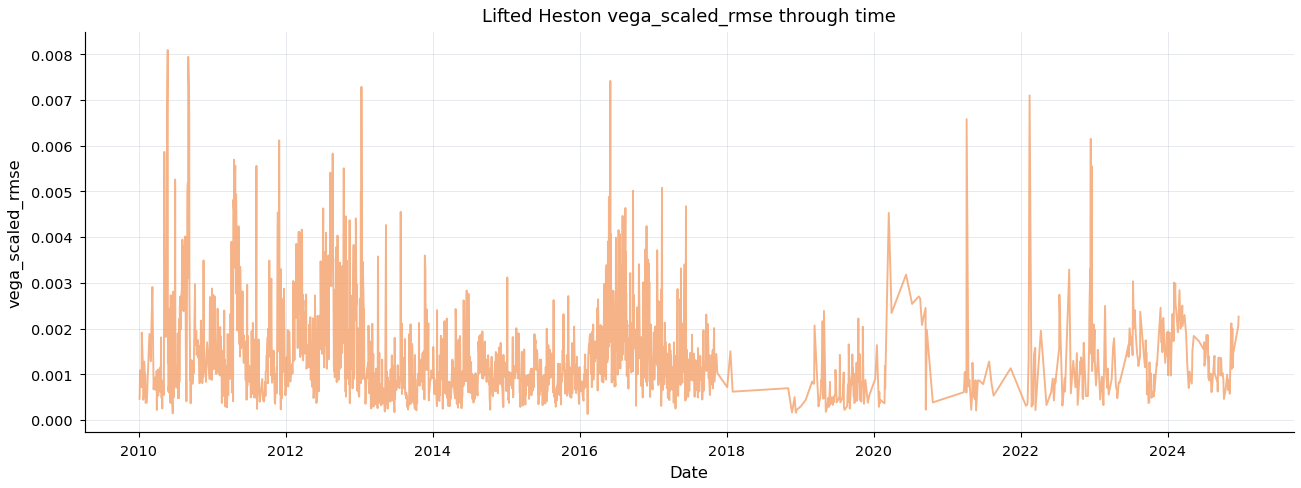

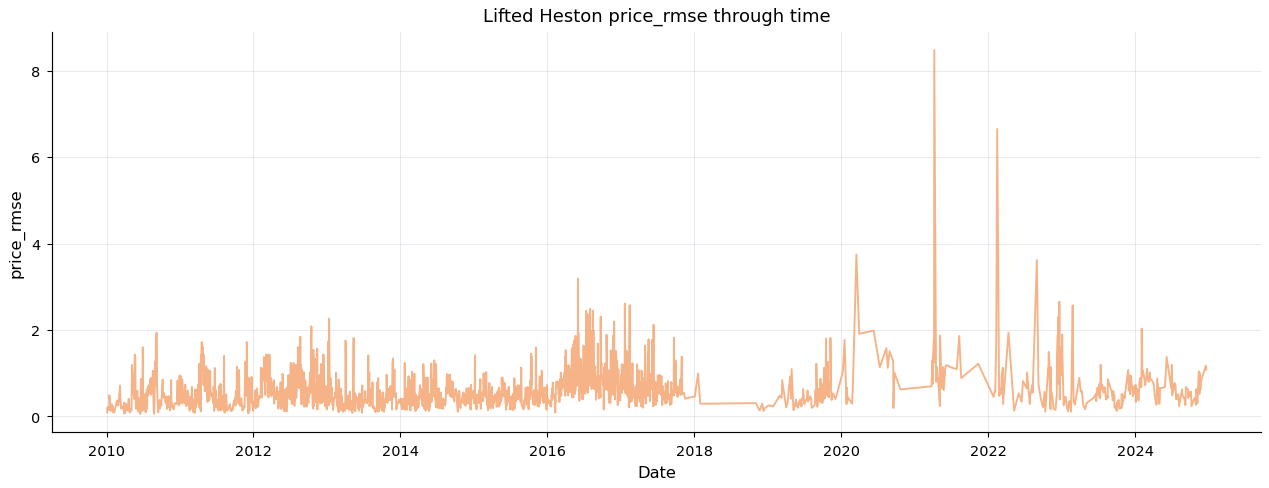

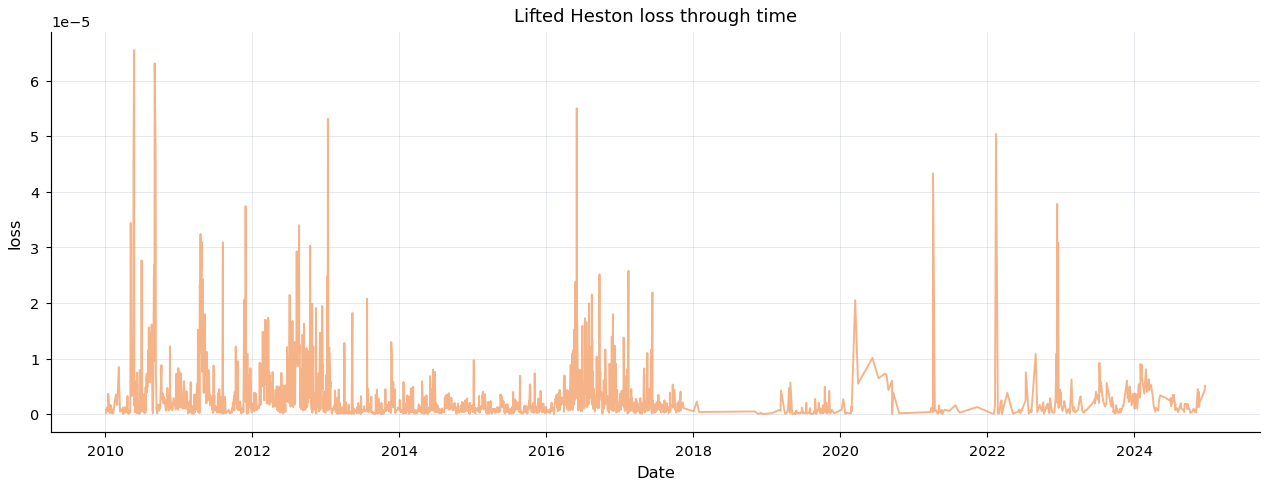

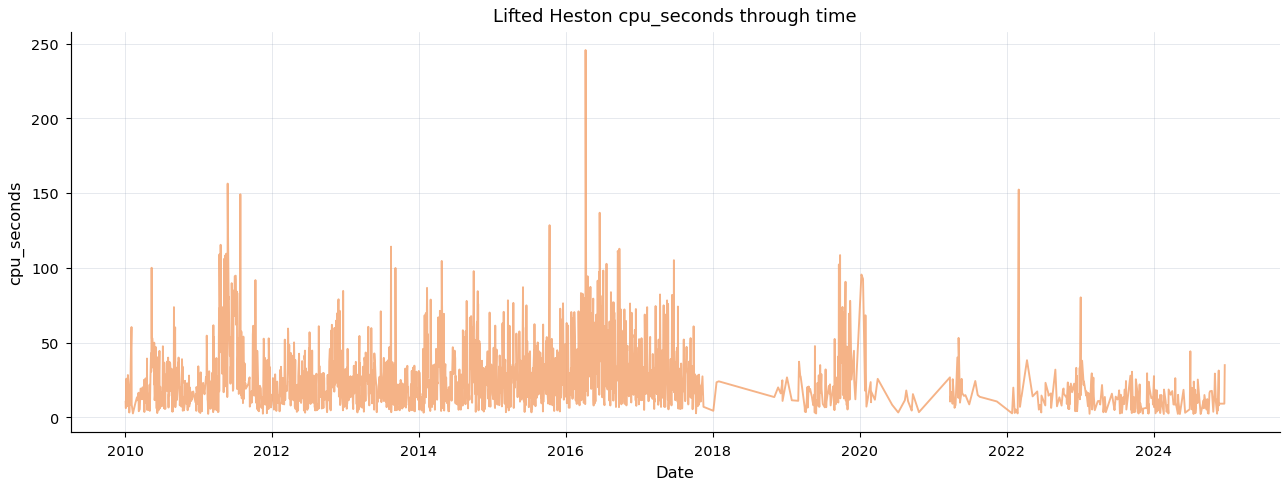

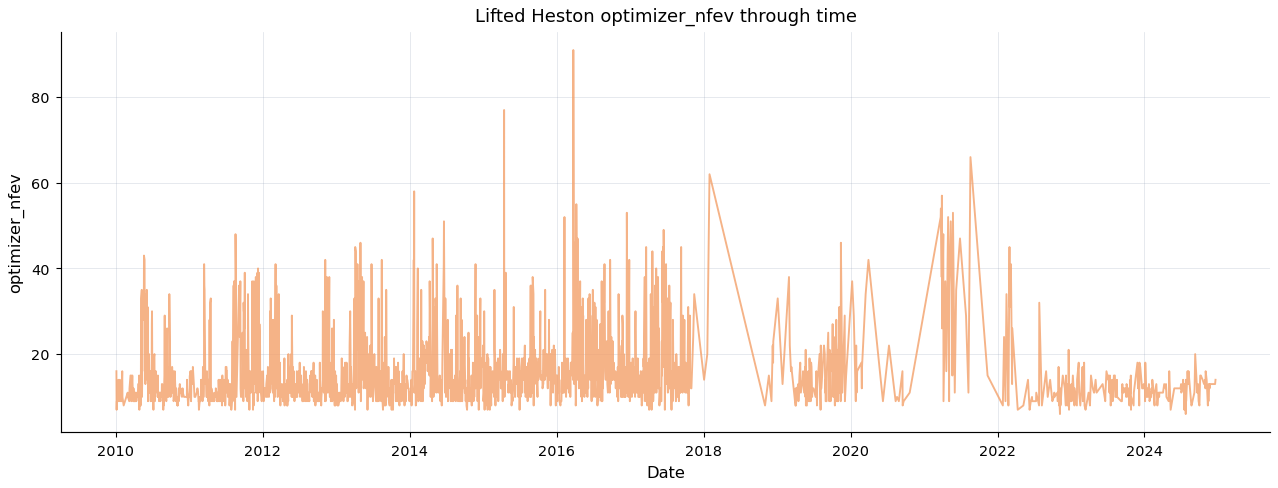

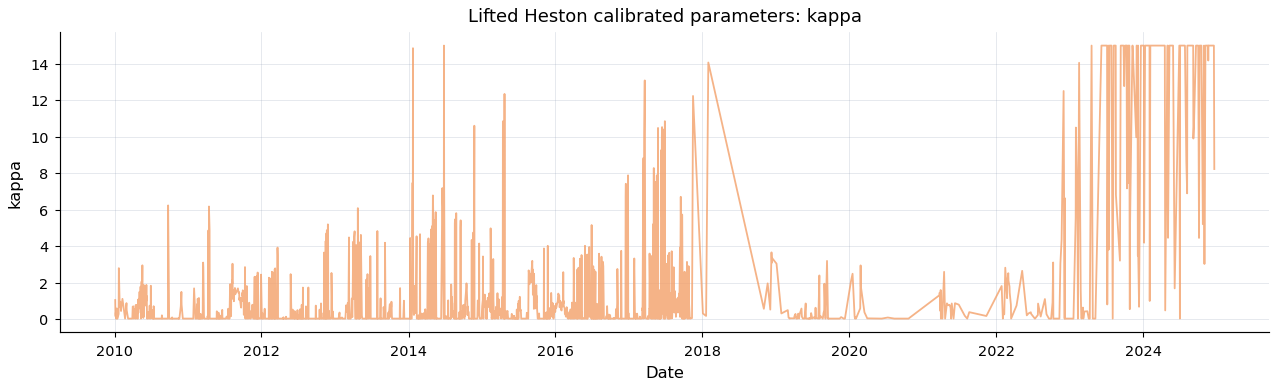

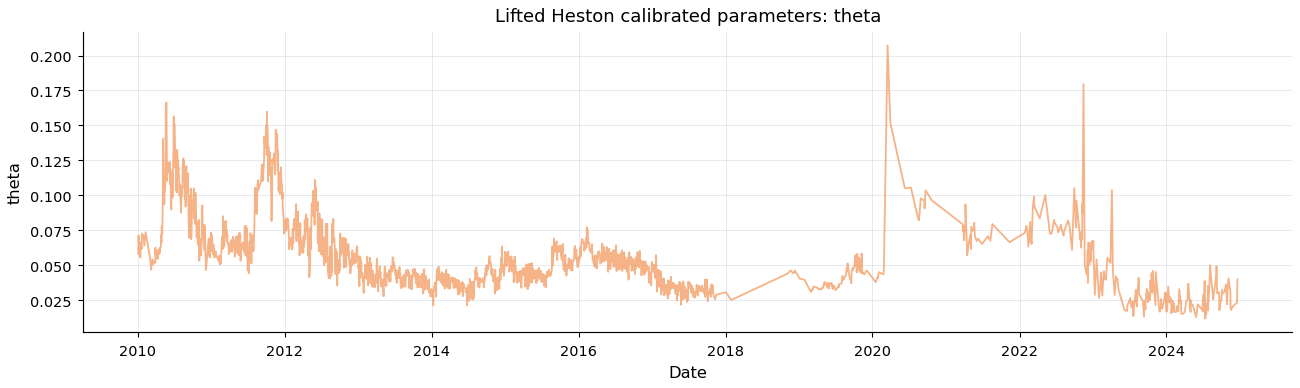

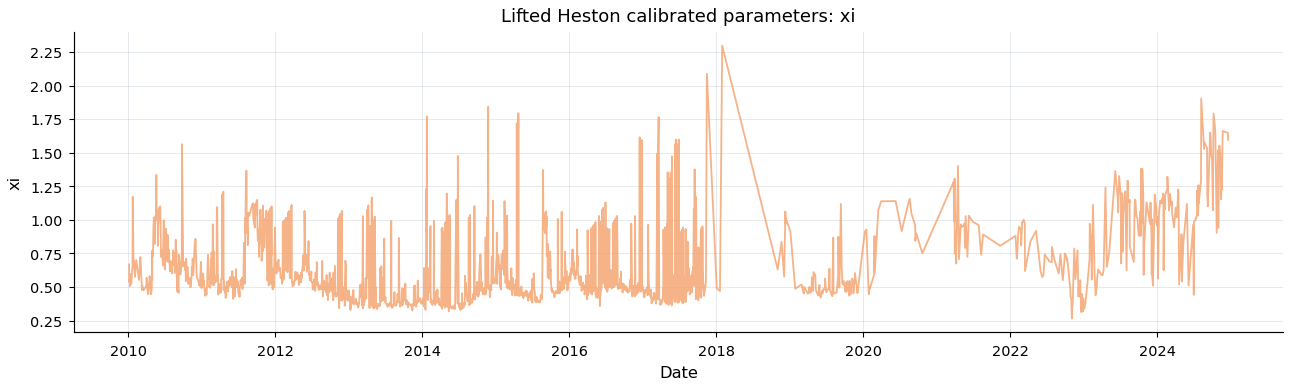

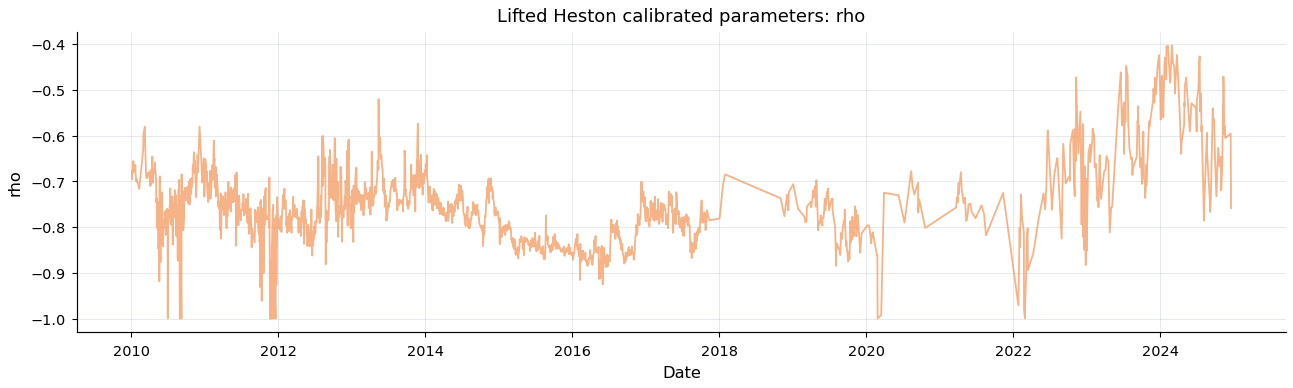

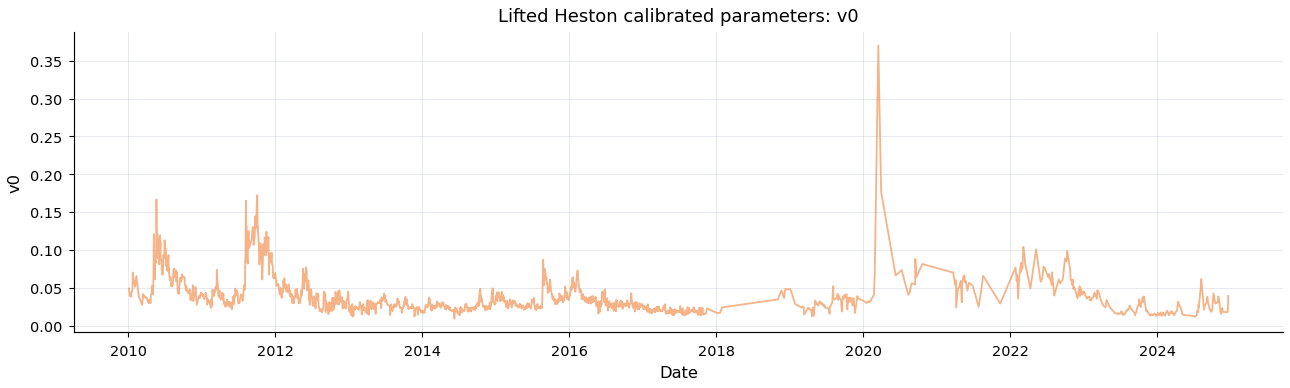

C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\3889745291.py:214: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(_agg)



Overall Lifted Heston residual diagnostics:


C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1751297975.py:97: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: pd.Series({


,metric,value
0,n,111119.000000
1,price_rmse,0.864588
2,price_mae,0.563428
3,vega_scaled_rmse,0.001751
4,vega_scaled_mae,0.001312



Lifted Heston residuals by maturity and moneyness:


,maturity_bucket,moneyness_bucket,n,mean_error,rmse,mae,p05,p50,p95
0,2W-1M,near_ATM_low,2385.0,0.000151,0.003009,0.002266,-0.006052,0.000618,0.004307
1,2W-1M,ATM,4717.0,0.000218,0.002354,0.001459,-0.002683,-0.000035,0.004125
2,2W-1M,near_ATM_high,1372.0,-0.001044,0.003996,0.002940,-0.009401,-0.000139,0.004403
3,1M-2M,near_ATM_low,2932.0,-0.000513,0.002985,0.002166,-0.006290,-0.000012,0.003212
4,1M-2M,ATM,5819.0,0.000326,0.001721,0.001097,-0.001960,0.000138,0.003055
5,1M-2M,near_ATM_high,1599.0,0.001172,0.003301,0.002345,-0.003326,0.000662,0.006645
6,2M-4M,near_ATM_low,5390.0,0.001292,0.002903,0.001962,-0.001964,0.001055,0.005687
7,2M-4M,ATM,5030.0,0.001084,0.002518,0.001714,-0.001894,0.000862,0.004880
8,2M-4M,near_ATM_high,5056.0,-0.000098,0.001951,0.001507,-0.003218,-0.000155,0.003196
9,4M-1Y,near_ATM_low,25403.0,-0.000463,0.001609,0.001199,-0.002949,-0.000417,0.001975


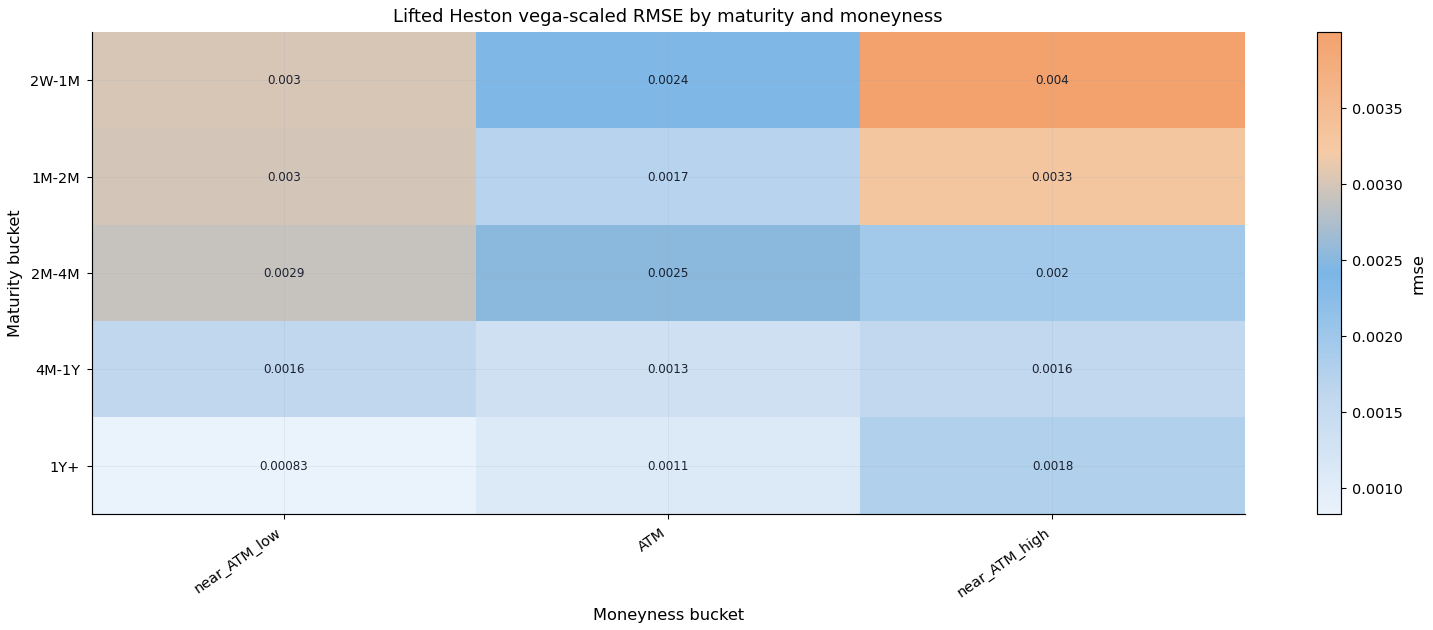


Worst 30 Lifted Heston dates by vega-scaled RMSE:


,date,n,price_rmse,vega_scaled_rmse,mean_abs_error
63,2010-05-24,25.0,1.404262,0.008092,1.028646
135,2010-09-03,28.0,1.840209,0.007943,1.679139
1405,2016-06-01,112.0,3.191022,0.007416,2.725312
636,2013-01-11,98.0,2.259251,0.007287,1.844639
136,2010-09-07,38.0,1.938581,0.007162,1.675904
1899,2022-02-14,59.0,6.650467,0.007098,4.772989
62,2010-05-21,26.0,1.429015,0.006758,1.092926
137,2010-09-08,32.0,1.832827,0.006698,1.483734
1878,2021-04-07,119.0,8.477511,0.006581,6.450095
1946,2022-12-15,143.0,2.300349,0.006148,1.748071


Worst Lifted Heston fit date: 2010-05-24 00:00:00


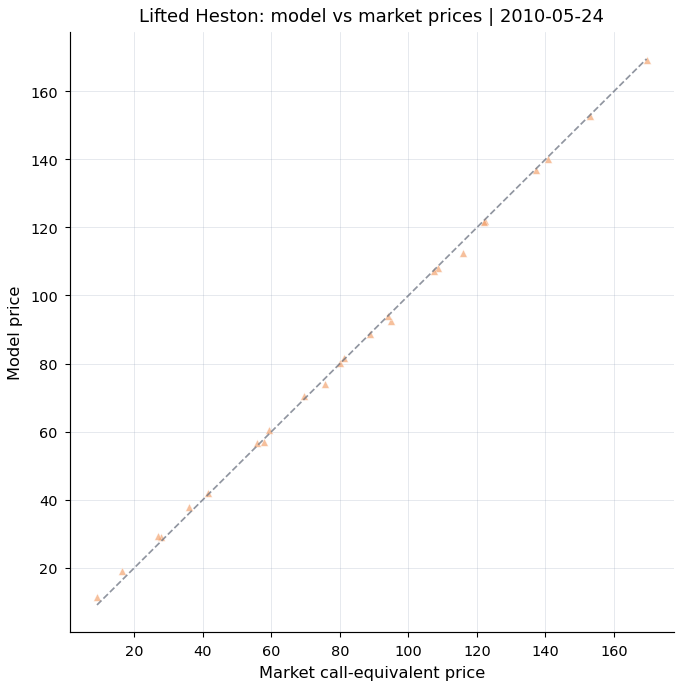

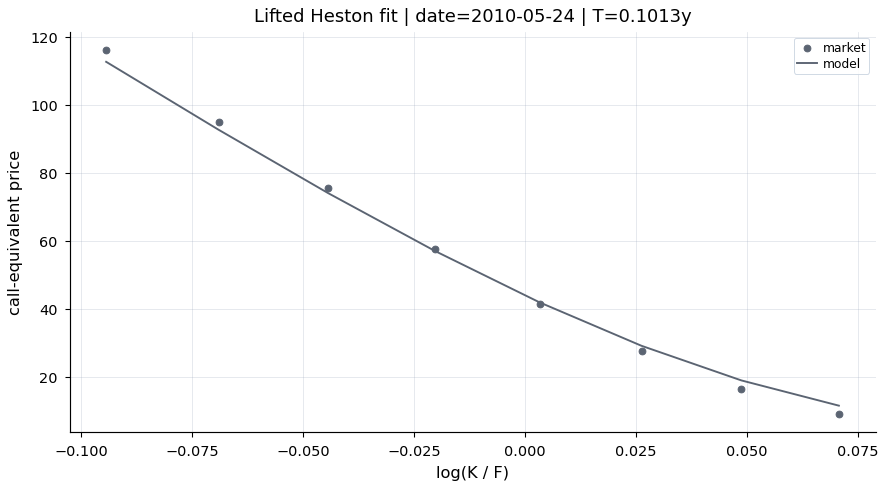

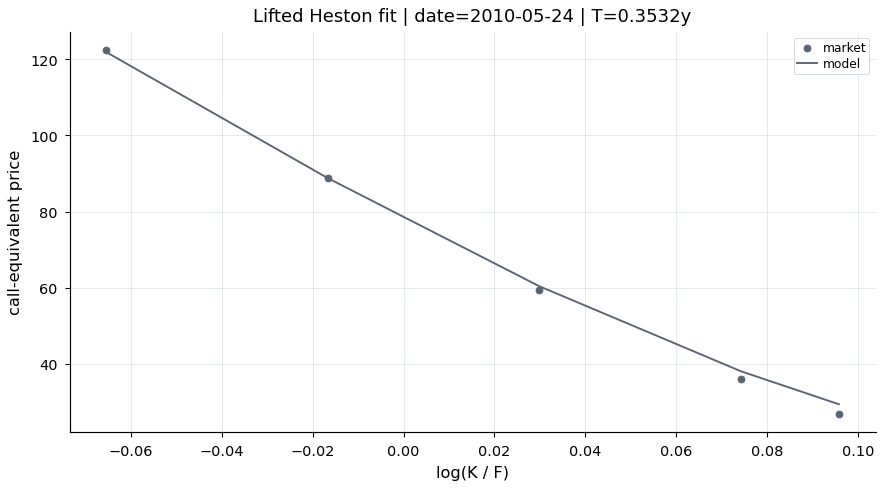

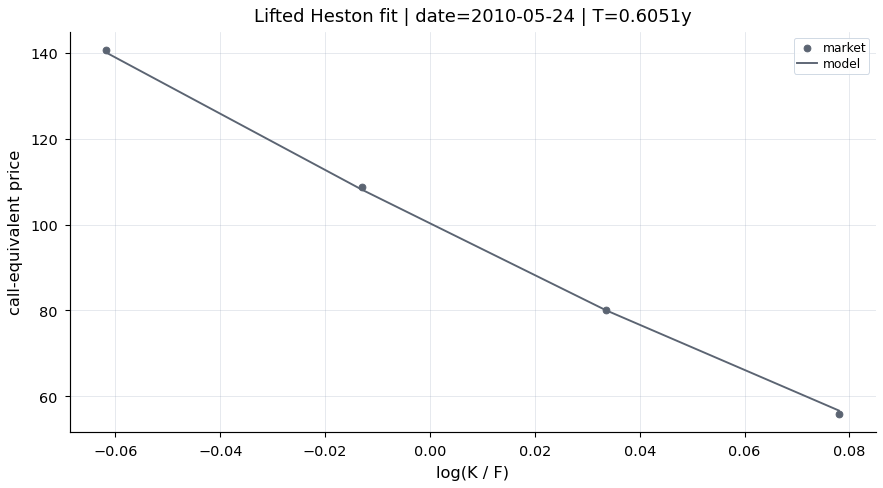

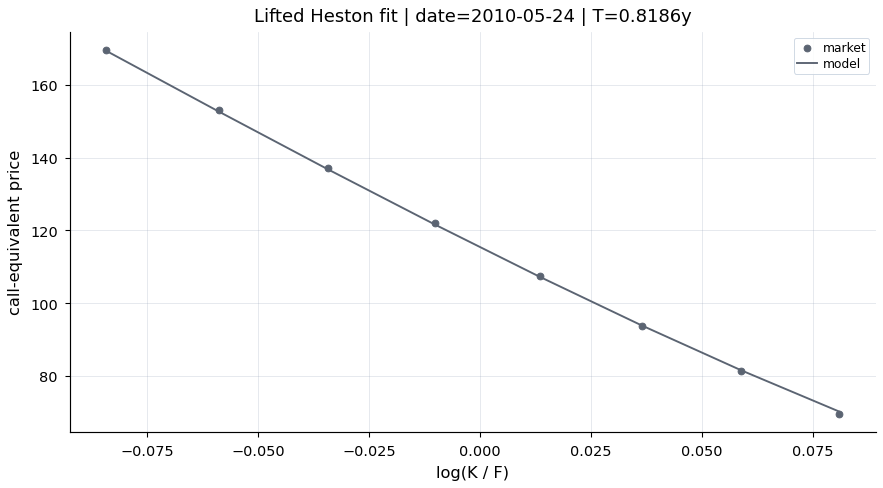

In [22]:
# ============================================================
# Section 4 fit inspection: Lifted Heston
# ============================================================

LIFTED_PARAM_COLS = [c for c in ["kappa", "theta", "xi", "rho", "v0"] if c in lifted_calibration.columns]

summarise_calibration_panel(
    lifted_calibration,
    model_name="Lifted Heston",
    param_cols=LIFTED_PARAM_COLS,
)

for metric in [c for c in ["vega_scaled_rmse", "price_rmse", "loss", "cpu_seconds", "optimizer_nfev"] if c in lifted_calibration.columns]:
    plot_calibration_metric_time_series(
        lifted_calibration,
        metric=metric,
        title=f"Lifted Heston {metric} through time",
        model_name="Lifted Heston",
    )

if LIFTED_PARAM_COLS:
    plot_parameter_time_series(
        lifted_calibration,
        LIFTED_PARAM_COLS,
        title="Lifted Heston calibrated parameters",
        model_name="Lifted Heston",
    )


def enrich_fit_table_for_visual_diagnostics(
    fit_table: pd.DataFrame,
    surface: pd.DataFrame,
    *,
    market_price_col: str = "market_price",
    model_price_col: str = "model_price",
) -> pd.DataFrame:
    if fit_table is None or fit_table.empty:
        return pd.DataFrame()
    f = fit_table.copy()
    f["date"] = pd.to_datetime(f["date"], errors="coerce").dt.normalize()
    for col in ["strike", "T", market_price_col, model_price_col, "price_error", "vega_scaled_error", "fit_weight"]:
        if col in f.columns:
            f[col] = pd.to_numeric(f[col], errors="coerce")
    if surface is None or surface.empty:
        if market_price_col in f.columns and "call_equiv_mid" not in f.columns:
            f["call_equiv_mid"] = f[market_price_col]
        return f

    s = surface.copy()
    s["date"] = pd.to_datetime(s["date"], errors="coerce").dt.normalize()
    for col in ["strike", "T"]:
        if col in s.columns:
            s[col] = pd.to_numeric(s[col], errors="coerce")
    merge_cols = [c for c in ["date", "strike", "T"] if c in f.columns and c in s.columns]
    attach_cols = [
        "date", "strike", "T", "call_equiv_mid", "log_forward_moneyness", "log_moneyness",
        "forward_ref", "spot_ref", "r", "q", "iv_market", "bs_vega", "fit_weight"
    ]
    attach_cols = [c for c in attach_cols if c in s.columns]
    if len(merge_cols) < 3 or not attach_cols:
        if market_price_col in f.columns and "call_equiv_mid" not in f.columns:
            f["call_equiv_mid"] = f[market_price_col]
        return f
    attached = s[attach_cols].drop_duplicates(merge_cols)
    out = f.merge(attached, on=merge_cols, how="left", suffixes=("", "_surface"))
    if market_price_col in out.columns:
        out["call_equiv_mid"] = pd.to_numeric(out.get("call_equiv_mid"), errors="coerce").where(
            pd.to_numeric(out.get("call_equiv_mid"), errors="coerce").notna(),
            pd.to_numeric(out[market_price_col], errors="coerce"),
        )
    if "log_forward_moneyness" not in out.columns and "log_moneyness" in out.columns:
        out["log_forward_moneyness"] = pd.to_numeric(out["log_moneyness"], errors="coerce")
    return out


def summarise_fit_residual_panel(fit_table: pd.DataFrame) -> pd.DataFrame:
    if fit_table is None or fit_table.empty:
        return pd.DataFrame()
    out = pd.DataFrame({
        "metric": ["n", "price_rmse", "price_mae", "vega_scaled_rmse", "vega_scaled_mae"],
        "value": [
            len(fit_table),
            weighted_rmse(pd.to_numeric(fit_table.get("price_error"), errors="coerce")),
            float(np.nanmean(np.abs(pd.to_numeric(fit_table.get("price_error"), errors="coerce")))),
            weighted_rmse(pd.to_numeric(fit_table.get("vega_scaled_error"), errors="coerce"), pd.to_numeric(fit_table.get("fit_weight"), errors="coerce")),
            float(np.nanmean(np.abs(pd.to_numeric(fit_table.get("vega_scaled_error"), errors="coerce")))),
        ],
    })
    return out


def fit_date_ranking_table(fit_table: pd.DataFrame) -> pd.DataFrame:
    if fit_table is None or fit_table.empty:
        return pd.DataFrame()
    ranked = (
        fit_table.groupby("date")
        .apply(lambda g: pd.Series({
            "n": len(g),
            "price_rmse": weighted_rmse(pd.to_numeric(g.get("price_error"), errors="coerce")),
            "vega_scaled_rmse": weighted_rmse(pd.to_numeric(g.get("vega_scaled_error"), errors="coerce"), pd.to_numeric(g.get("fit_weight"), errors="coerce")),
            "mean_abs_error": float(np.nanmean(np.abs(pd.to_numeric(g.get("price_error"), errors="coerce")))),
        }))
        .reset_index()
        .sort_values("vega_scaled_rmse", ascending=False)
    )
    return ranked


lifted_fit_residuals_visual = enrich_fit_table_for_visual_diagnostics(
    globals().get("lifted_fit_table", pd.DataFrame()),
    globals().get("surface_panel", pd.DataFrame()),
)

if not lifted_fit_residuals_visual.empty:
    lifted_bucket_summary = residual_bucket_table(
        lifted_fit_residuals_visual,
        residual_col="vega_scaled_error",
        weight_col="fit_weight",
    )
    lifted_date_fit = fit_date_ranking_table(lifted_fit_residuals_visual)

    print("\nOverall Lifted Heston residual diagnostics:")
    display(summarise_fit_residual_panel(lifted_fit_residuals_visual))

    print("\nLifted Heston residuals by maturity and moneyness:")
    display(lifted_bucket_summary)
    plot_residual_heatmap(lifted_bucket_summary, value_col="rmse", title="Lifted Heston vega-scaled RMSE by maturity and moneyness")

    print("\nWorst 30 Lifted Heston dates by vega-scaled RMSE:")
    display(lifted_date_fit.head(30))
    if not lifted_date_fit.empty:
        worst_lifted_date = lifted_date_fit.iloc[0]["date"]
        print(f"Worst Lifted Heston fit date: {worst_lifted_date}")
        plot_model_vs_market_scatter(lifted_fit_residuals_visual, model_name="Lifted Heston", date=worst_lifted_date, market_col="call_equiv_mid", model_col="model_price")
        plot_smile_fit_for_date(lifted_fit_residuals_visual, model_name="Lifted Heston", date=worst_lifted_date)
else:
    print("Lifted Heston fit-table visual diagnostics could not be produced because the fit table is missing or empty.")


,metric,model,count,mean,std,min,5%,50%,95%,max
0,loss,heston,2848.0,0.000002,0.000003,3.698898e-10,6.631413e-08,9.480019e-07,0.000007,0.000042
1,price_rmse,heston,2848.0,0.402849,0.345415,4.961661e-03,1.093491e-01,3.309413e-01,0.891502,9.733312
2,price_mae,heston,2848.0,0.325410,0.248864,4.390110e-03,8.714403e-02,2.714154e-01,0.736192,5.215223
3,vega_scaled_rmse,heston,2848.0,0.001041,0.000866,2.161447e-05,2.069231e-04,7.509282e-04,0.002927,0.006470
4,cpu_seconds,heston,25.0,0.332627,0.284242,3.414130e-02,5.572764e-02,2.526400e-01,0.889971,1.135513
5,n_options,heston,2848.0,44.620084,27.944617,4.000000e+00,1.200000e+01,3.800000e+01,100.000000,214.000000
6,loss,lifted_heston,2113.0,0.000003,0.000005,1.698321e-08,1.390857e-07,1.261426e-06,0.000011,0.000065
7,price_rmse,lifted_heston,2113.0,0.591758,0.453437,5.424674e-02,1.539150e-01,4.871092e-01,1.352333,8.477511
8,vega_scaled_rmse,lifted_heston,2113.0,0.001395,0.000994,1.303197e-04,3.729419e-04,1.123132e-03,0.003323,0.008092
9,cpu_seconds,lifted_heston,2113.0,26.475586,21.449240,2.164186e+00,4.656087e+00,2.044683e+01,70.035620,245.641686


,date,loss_heston,price_rmse_heston,vega_scaled_rmse_heston,cpu_seconds_heston,loss_lifted,price_rmse_lifted,vega_scaled_rmse_lifted,cpu_seconds_lifted,heston_loss,lifted_loss,loss_diff_lifted_minus_heston,loss_median_pair_available,loss_lifted_better,heston_price_rmse,lifted_price_rmse,price_rmse_diff_lifted_minus_heston,price_rmse_median_pair_available,price_rmse_lifted_better,heston_vega_scaled_rmse,lifted_vega_scaled_rmse,vega_scaled_rmse_diff_lifted_minus_heston,vega_scaled_rmse_median_pair_available,vega_scaled_rmse_lifted_better,heston_cpu_seconds,lifted_cpu_seconds,cpu_seconds_diff_lifted_minus_heston,cpu_seconds_median_pair_available,calibration_diagnostic_version
0,2010-01-04,8.955512e-08,0.058337,0.000299,0.214938,2.135844e-07,0.093563,0.000462,10.371360,8.955512e-08,2.135844e-07,1.240293e-07,True,False,0.058337,0.093563,0.035226,True,False,0.000299,0.000462,0.000163,True,False,0.214938,10.371360,10.156422,True,common_target_date_level_v1
1,2010-01-05,3.704908e-07,0.182779,0.000609,0.117374,3.272177e-07,0.164643,0.000572,6.138932,3.704908e-07,3.272177e-07,-4.327313e-08,True,True,0.182779,0.164643,-0.018137,True,True,0.000609,0.000572,-0.000037,True,True,0.117374,6.138932,6.021559,True,common_target_date_level_v1
2,2010-01-06,3.341898e-07,0.121961,0.000578,0.284309,8.879675e-07,0.204263,0.000942,25.192345,3.341898e-07,8.879675e-07,5.537776e-07,True,False,0.121961,0.204263,0.082302,True,False,0.000578,0.000942,0.000364,True,False,0.284309,25.192345,24.908037,True,common_target_date_level_v1
3,2010-01-07,3.839909e-07,0.134450,0.000620,0.269471,7.384267e-07,0.180360,0.000859,13.568163,3.839909e-07,7.384267e-07,3.544358e-07,True,False,0.134450,0.180360,0.045909,True,False,0.000620,0.000859,0.000240,True,False,0.269471,13.568163,13.298692,True,common_target_date_level_v1
4,2010-01-08,4.166474e-07,0.139311,0.000645,0.479836,1.179752e-06,0.218587,0.001086,25.836805,4.166474e-07,1.179752e-06,7.631046e-07,True,False,0.139311,0.218587,0.079277,True,False,0.000645,0.001086,0.000441,True,False,0.479836,25.836805,25.356969,True,common_target_date_level_v1


[cache fingerprint] hashing heston_vs_lifted_hedging_panel_calibration_comparison.parquet (0.4 MB); sidecar=56aaa9934a59403de1d9bc72792cc1ef11a1954412c0053e4e887bd2b6cc6801.json
[cache fingerprint] complete heston_vs_lifted_hedging_panel_calibration_comparison.parquet in 0.02s


,metric,common_dates,heston_median,lifted_median,median_diff_lifted_minus_heston,share_dates_lifted_better
0,loss,2113,0.000001,0.000001,-6.535588e-09,0.504969
1,price_rmse,2113,0.358126,0.487109,1.004474e-01,0.288689
2,vega_scaled_rmse,2113,0.000837,0.001123,2.076951e-04,0.337435
3,cpu_seconds,17,0.175477,13.568163,1.329869e+01,NaN


,diagnostic_version,lifted_factors_N,hurst_H,rn_scale,calibration_parameterization,calibrated_parameters,fixed_or_curve_identified_quantities,reason
0,common_target_date_level_v1,20,0.35,2.5,full_5p_forward_curve_init,"kappa, theta, xi, rho, v0","full_5p_forward_curve_init calibrates kappa, t...",records lifted calibration degrees of freedom ...


C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\475791861.py:229: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[172.41850281 208.45658875 215.0151825  ... 315.86450195 165.54125977
  85.87532806]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  out.loc[missing, "vega_scale"] = inferred_scale[missing.to_numpy()]


,diagnostic_version,fit_target_match_method,rows,dates,heston_target_source,lifted_target_source,rows_excluded_missing_vega_scale
0,common_target_date_level_v1,heston_repriced_on_lifted_targets,111119,2113,repriced_from_heston_parameters,market_price,0


C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\475791861.py:385: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped = frame.groupby(group_cols, dropna=False) if group_cols else [((), frame)]


,slice,n_rows,n_dates,heston_median_abs_vega_scaled_error,lifted_median_abs_vega_scaled_error,median_diff_lifted_minus_heston,share_rows_lifted_better,diagnostic_version
0,common_full_surface,111119,2113,0.000610,0.000882,0.000173,0.373213,common_target_date_level_v1
1,near_atm_abs_log_moneyness_le_0p05,62298,2113,0.000582,0.000804,0.000133,0.383158,common_target_date_level_v1
2,short_maturity_le_60d,18824,452,0.001022,0.000994,-0.000034,0.537240,common_target_date_level_v1
3,near_atm_and_short_maturity,14466,452,0.000880,0.000807,-0.000030,0.538089,common_target_date_level_v1


,maturity_bucket,slice,n_rows,n_dates,heston_median_abs_vega_scaled_error,lifted_median_abs_vega_scaled_error,median_diff_lifted_minus_heston,share_rows_lifted_better,diagnostic_version
0,1M,by_maturity_bucket,16701,379,0.001009,0.000962,-0.000048,0.553141,common_target_date_level_v1
1,2M,by_maturity_bucket,3173,206,0.001107,0.001471,0.000196,0.380082,common_target_date_level_v1
2,3M,by_maturity_bucket,14030,913,0.000778,0.001210,0.000360,0.302566,common_target_date_level_v1
3,outside_hedging_buckets,by_maturity_bucket,77215,1930,0.000527,0.000806,0.000225,0.346850,common_target_date_level_v1


,moneyness_band,slice,n_rows,n_dates,heston_median_abs_vega_scaled_error,lifted_median_abs_vega_scaled_error,median_diff_lifted_minus_heston,share_rows_lifted_better,diagnostic_version
0,ATM_0_3pct,by_moneyness_band,39405,2113,0.000557,0.000754,0.000101,0.398807,common_target_date_level_v1
1,near_ATM_3_5pct,by_moneyness_band,22893,2112,0.000621,0.000899,0.000205,0.356222,common_target_date_level_v1
2,mid_5_10pct,by_moneyness_band,45751,2113,0.000652,0.000971,0.000235,0.363642,common_target_date_level_v1
3,wing_10_20pct,by_moneyness_band,3070,1195,0.000594,0.001044,0.000373,0.314007,common_target_date_level_v1
4,far_wing_gt_20pct,by_moneyness_band,0,0,NaN,NaN,NaN,NaN,common_target_date_level_v1


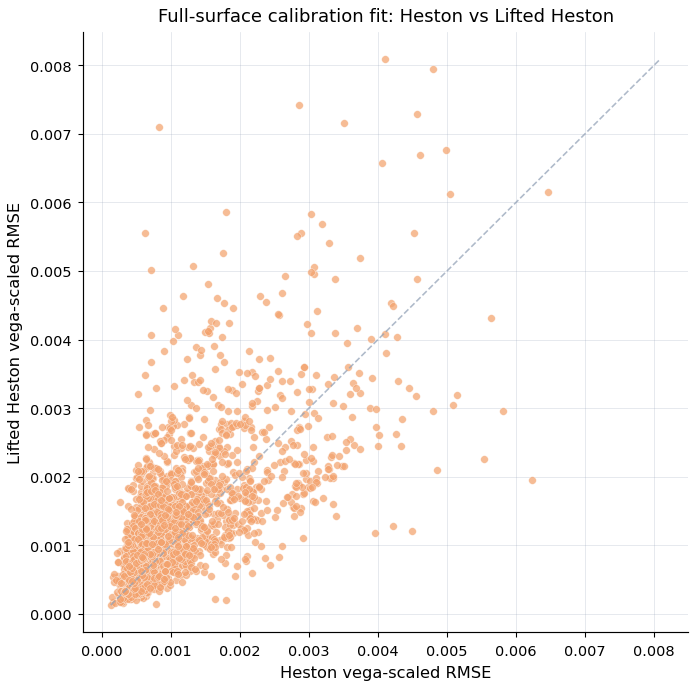

{'accepted_dates': 2113, 'excluded_dates': 735, 'gate_version': 'calibration_availability_final_finite_5p_lifted_no_rmse_exclusion'}


,reason,dates
0,accepted,2113
1,missing_lifted_calibration_or_forward_curve,735


,heston_success,heston_fit_accepted,dates
0,False,True,2828
1,True,True,20


In [23]:
# ============================================================
# Heston vs lifted-Heston calibration diagnostics and hedging eligibility audit
# ============================================================

CALIBRATION_DIAGNOSTIC_VERSION = "common_target_date_level_v1"
CALIBRATION_QUALITY_GATE_VERSION = "calibration_availability_final_finite_5p_lifted_no_rmse_exclusion"


def _normalise_date_column(frame: pd.DataFrame, label: str) -> pd.DataFrame:
    if frame is None or frame.empty:
        raise ValueError(f"{label} is empty.")
    out = frame.copy()
    require_columns(out, {"date"}, label)
    out["date"] = pd.to_datetime(out["date"]).dt.normalize()
    return out


def _finite_numeric(frame: pd.DataFrame, column: str) -> pd.Series:
    if column not in frame.columns:
        return pd.Series(np.nan, index=frame.index, dtype=float)
    return pd.to_numeric(frame[column], errors="coerce")


def _quality_flag_is_usable(frame: pd.DataFrame) -> pd.Series:
    bad_flags = {"NUMFAIL", "FAIL", "FAILED"}
    if "quality_flag" not in frame.columns:
        return pd.Series(True, index=frame.index)
    return ~frame["quality_flag"].astype(str).str.upper().isin(bad_flags)


def calibration_panel_summary(panel: pd.DataFrame, model_name: str) -> pd.DataFrame:
    panel = _normalise_date_column(panel, f"{model_name} calibration panel")
    metrics = [c for c in ["loss", "price_rmse", "price_mae", "vega_scaled_rmse", "cpu_seconds", "n_options", "n_maturities"] if c in panel.columns]
    out = panel[metrics].describe(percentiles=[0.05, 0.5, 0.95]).T if metrics else pd.DataFrame()
    out.insert(0, "model", model_name)
    return out.reset_index(names="metric")


def _normalise_one_row_per_date(panel: pd.DataFrame, model_name: str) -> pd.DataFrame:
    """Collapse calibration panel to one candidate per date by realised finite fit quality.

    Optimiser status is retained as provenance but is not a hard eligibility condition.
    The hard conditions are finite parameters, finite realised fit metric, and no
    BADFIT/NUMFAIL quality flag. This avoids the earlier bug where iteration-limit
    statuses destroyed otherwise finite calibration rows.
    """
    work = _normalise_date_column(panel, f"{model_name} calibration panel")
    for col in ["vega_scaled_rmse", "price_rmse", "loss"]:
        work[col] = _finite_numeric(work, col)

    if "quality_flag" not in work.columns:
        work["quality_flag"] = "UNSPECIFIED"
    if "success" not in work.columns:
        work["success"] = False

    param_cols = [c for c in ["kappa", "theta", "xi", "rho", "v0"] if c in work.columns]
    if param_cols:
        work["_finite_params"] = np.isfinite(work[param_cols].apply(pd.to_numeric, errors="coerce")).all(axis=1)
    else:
        work["_finite_params"] = False

    work["_usable_by_fit"] = (
        work["_finite_params"]
        & np.isfinite(work["vega_scaled_rmse"])
        & _quality_flag_is_usable(work)
    )
    work["_quality_rank"] = np.where(work["_usable_by_fit"], 0, 1)
    work = work.sort_values(["date", "_quality_rank", "vega_scaled_rmse", "loss"], na_position="last")
    out = work.drop_duplicates("date", keep="first").copy()
    return out.drop(columns=[c for c in ["_quality_rank", "_finite_params", "_usable_by_fit"] if c in out.columns]).reset_index(drop=True)


def compare_heston_lifted_calibration(heston: pd.DataFrame, lifted: pd.DataFrame) -> pd.DataFrame:
    """Date-level Heston/lifted comparison on common finite calibration dates.

    The returned table includes both naming conventions:
      heston_vega_scaled_rmse / lifted_vega_scaled_rmse
      vega_scaled_rmse_heston / vega_scaled_rmse_lifted
    so later diagnostic cells cannot silently point at the wrong summary table.
    """
    h = _normalise_one_row_per_date(heston, "Heston")
    l = _normalise_one_row_per_date(lifted, "Lifted Heston")

    metrics = [c for c in ["loss", "price_rmse", "price_mae", "vega_scaled_rmse", "cpu_seconds", "n_options"] if c in h.columns and c in l.columns]
    if not metrics:
        raise ValueError("No common calibration metrics are available for Heston/lifted comparison.")

    h_cols = ["date"] + metrics
    l_cols = ["date"] + metrics
    merged = h[h_cols].merge(l[l_cols], on="date", how="inner", suffixes=("_heston", "_lifted"))
    if merged.empty:
        raise ValueError("No common Heston/lifted calibration dates to compare.")

    for metric in metrics:
        old_h = f"{metric}_heston"
        old_l = f"{metric}_lifted"
        new_h = f"heston_{metric}"
        new_l = f"lifted_{metric}"
        merged[new_h] = pd.to_numeric(merged[old_h], errors="coerce")
        merged[new_l] = pd.to_numeric(merged[old_l], errors="coerce")
        merged[f"{metric}_diff_lifted_minus_heston"] = merged[new_l] - merged[new_h]
        merged[f"{metric}_median_pair_available"] = np.isfinite(merged[new_h]) & np.isfinite(merged[new_l])
        if metric in {"loss", "price_rmse", "price_mae", "vega_scaled_rmse"}:
            merged[f"{metric}_lifted_better"] = merged[new_l] < merged[new_h]

    merged["calibration_diagnostic_version"] = CALIBRATION_DIAGNOSTIC_VERSION
    return merged.sort_values("date").reset_index(drop=True)


def build_calibration_comparison_summary(comparison: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for metric in ["loss", "price_rmse", "price_mae", "vega_scaled_rmse", "cpu_seconds"]:
        h_col = f"heston_{metric}"
        l_col = f"lifted_{metric}"
        if h_col not in comparison.columns or l_col not in comparison.columns:
            continue
        finite = np.isfinite(comparison[h_col]) & np.isfinite(comparison[l_col])
        row = {
            "metric": metric,
            "common_dates": int(finite.sum()),
            "heston_median": float(comparison.loc[finite, h_col].median()) if finite.any() else np.nan,
            "lifted_median": float(comparison.loc[finite, l_col].median()) if finite.any() else np.nan,
            "median_diff_lifted_minus_heston": float((comparison.loc[finite, l_col] - comparison.loc[finite, h_col]).median()) if finite.any() else np.nan,
        }
        b_col = f"{metric}_lifted_better"
        if b_col in comparison.columns:
            row["share_dates_lifted_better"] = float(comparison.loc[finite, b_col].mean()) if finite.any() else np.nan
        rows.append(row)
    return pd.DataFrame(rows)


def _target_price_column(frame: pd.DataFrame, label: str) -> tuple[pd.Series, str]:
    candidates = ["market_price", "call_equiv_mid", "mid", "option_mid", "price_mid"]
    for col in candidates:
        if col in frame.columns:
            return pd.to_numeric(frame[col], errors="coerce"), col
    if {"model_price", "price_error"}.issubset(frame.columns):
        return pd.to_numeric(frame["model_price"], errors="coerce") - pd.to_numeric(frame["price_error"], errors="coerce"), "model_price_minus_price_error"
    raise ValueError(f"{label} has no recognised market target column. Expected one of {candidates} or model_price/price_error.")


def _normalise_fit_table_for_comparison(fit: pd.DataFrame, model_name: str) -> tuple[pd.DataFrame, str]:
    if fit is None or fit.empty:
        raise ValueError(f"{model_name} fit table is empty; cannot build calibration-fairness diagnostics.")
    required = {"date", "strike", "T", "model_price", "price_error", "vega_scaled_error"}
    require_columns(fit, required, f"{model_name} fit table")
    out = fit.copy()
    out["date"] = pd.to_datetime(out["date"]).dt.normalize()
    out["strike"] = pd.to_numeric(out["strike"], errors="coerce")
    out["T"] = pd.to_numeric(out["T"], errors="coerce")
    out["model_price"] = pd.to_numeric(out["model_price"], errors="coerce")
    out["price_error"] = pd.to_numeric(out["price_error"], errors="coerce")
    out["vega_scaled_error"] = pd.to_numeric(out["vega_scaled_error"], errors="coerce")
    out["market_price"], target_source = _target_price_column(out, f"{model_name} fit table")

    for col in ["spot_ref", "S", "r", "q", "fit_weight", "bs_vega", "dte", "log_moneyness", "log_forward_moneyness"]:
        if col in out.columns:
            out[col] = pd.to_numeric(out[col], errors="coerce")
    if "spot_ref" not in out.columns and "S" in out.columns:
        out["spot_ref"] = out["S"]

    out = out[np.isfinite(out["strike"]) & np.isfinite(out["T"]) & np.isfinite(out["market_price"])].copy()
    out["strike_key"] = out["strike"].round(8)
    out["T_key"] = out["T"].round(10)
    out[f"{model_name}_model_price"] = out["model_price"]
    out[f"{model_name}_price_error"] = out["price_error"]
    out[f"{model_name}_vega_scaled_error"] = out["vega_scaled_error"]
    out[f"{model_name}_abs_vega_scaled_error"] = out["vega_scaled_error"].abs()
    return out, target_source


def _attach_surface_vega_scale(targets: pd.DataFrame, surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    """Attach a strict vega scale from the cleaned surface to lifted target rows.

    Priority order:
      1. cleaned-surface Black-Scholes vega matched by date/strike/T;
      2. existing target-row bs_vega, if the residual table already carries one;
      3. inferred absolute price-error / vega-scaled-error ratio.

    No unit-vega substitution is made. Rows with no defensible scale are excluded
    from fit-pair diagnostics and counted in the schema audit. Even a
    vega column can start a custody battle if you merge it carelessly.
    """
    out = targets.copy()

    if "bs_vega" in out.columns:
        out = out.rename(columns={"bs_vega": "target_bs_vega"})
    elif "target_bs_vega" not in out.columns:
        out["target_bs_vega"] = np.nan
    out["target_bs_vega"] = pd.to_numeric(out["target_bs_vega"], errors="coerce")

    if surface is not None and not surface.empty and {"date", "strike", "T", "bs_vega"}.issubset(surface.columns):
        s = surface[["date", "strike", "T", "bs_vega"]].copy()
        s["date"] = pd.to_datetime(s["date"]).dt.normalize()
        s["strike_key"] = pd.to_numeric(s["strike"], errors="coerce").round(8)
        s["T_key"] = pd.to_numeric(s["T"], errors="coerce").round(10)
        s["surface_bs_vega"] = pd.to_numeric(s["bs_vega"], errors="coerce")
        s = s[np.isfinite(s["surface_bs_vega"]) & (s["surface_bs_vega"] > 0)]
        s = s.drop_duplicates(["date", "strike_key", "T_key"])
        out = out.merge(
            s[["date", "strike_key", "T_key", "surface_bs_vega"]],
            on=["date", "strike_key", "T_key"],
            how="left",
        )
    else:
        out["surface_bs_vega"] = np.nan

    inferred_scale = np.full(len(out), np.nan, dtype=float)
    denom_ok = (
        np.isfinite(pd.to_numeric(out["lifted_price_error"], errors="coerce"))
        & np.isfinite(pd.to_numeric(out["lifted_vega_scaled_error"], errors="coerce"))
        & (pd.to_numeric(out["lifted_vega_scaled_error"], errors="coerce").abs() > 1e-14)
    )
    inferred_scale[denom_ok.to_numpy()] = np.abs(
        pd.to_numeric(out.loc[denom_ok, "lifted_price_error"], errors="coerce")
        / pd.to_numeric(out.loc[denom_ok, "lifted_vega_scaled_error"], errors="coerce")
    )

    surface_scale = pd.to_numeric(out["surface_bs_vega"], errors="coerce")
    target_scale = pd.to_numeric(out["target_bs_vega"], errors="coerce")
    out["vega_scale"] = surface_scale
    out["vega_scale_source"] = "surface_bs_vega"

    missing = ~np.isfinite(out["vega_scale"]) | (out["vega_scale"] <= 0)
    out.loc[missing, "vega_scale"] = target_scale[missing]
    out.loc[missing & np.isfinite(target_scale) & (target_scale > 0), "vega_scale_source"] = "target_bs_vega"

    missing = ~np.isfinite(out["vega_scale"]) | (out["vega_scale"] <= 0)
    out.loc[missing, "vega_scale"] = inferred_scale[missing.to_numpy()]
    out.loc[missing & np.isfinite(inferred_scale) & (inferred_scale > 0), "vega_scale_source"] = "inferred_from_lifted_residual_ratio"

    out["vega_scale"] = pd.to_numeric(out["vega_scale"], errors="coerce")
    out.loc[~np.isfinite(out["vega_scale"]) | (out["vega_scale"] <= 0), "vega_scale_source"] = "missing"
    return out

def _reprice_heston_on_lifted_targets(lifted_fit: pd.DataFrame, heston_panel: pd.DataFrame, surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    l, lifted_target_source = _normalise_fit_table_for_comparison(lifted_fit, "lifted")
    h = _normalise_one_row_per_date(heston_panel, "Heston")
    param_cols = ["date", "kappa", "theta", "xi", "rho", "v0"]
    require_columns(h, set(param_cols), "Heston calibration panel for common-target repricing")
    h = h[param_cols].copy()
    for col in param_cols[1:]:
        h[col] = pd.to_numeric(h[col], errors="coerce")
    h = h[np.isfinite(h[param_cols[1:]]).all(axis=1)].copy()
    if h.empty:
        raise ValueError("No finite Heston parameter rows available for common-target repricing.")

    common = l.merge(h, on="date", how="inner", suffixes=("", "_heston_param"))
    if common.empty:
        raise ValueError("No lifted fit target rows have matching finite Heston calibration parameters.")

    required_target_cols = {"spot_ref", "strike", "T", "r", "q", "market_price", "lifted_model_price", "lifted_price_error", "lifted_vega_scaled_error"}
    missing = required_target_cols - set(common.columns)
    if missing:
        raise ValueError(f"Lifted fit table lacks target columns required for common-target Heston repricing: {sorted(missing)}")

    common = _attach_surface_vega_scale(common, surface, cfg)
    before = len(common)
    common = common[np.isfinite(common["vega_scale"]) & (common["vega_scale"] > 0)].copy().reset_index(drop=True)
    if common.empty:
        raise ValueError("No common-target rows have a valid vega scale for Heston-vs-lifted fit diagnostics.")

    pricer = HestonPricer(cfg.calibration.heston_pricing_nodes)
    heston_prices = np.empty(len(common), dtype=float)
    # Grouping by date avoids repeatedly rebuilding Heston parameter objects.
    for date, idx in common.groupby("date", sort=False).groups.items():
        pos = np.asarray(idx, dtype=int)
        g = common.iloc[pos]
        first = g.iloc[0]
        params = HestonParams(float(first.kappa), float(first.theta), float(first.xi), float(first.rho), float(first.v0))
        heston_prices[pos] = pricer.call_prices(
            g["spot_ref"].to_numpy(float),
            g["strike"].to_numpy(float),
            g["T"].to_numpy(float),
            g["r"].to_numpy(float),
            g["q"].to_numpy(float),
            params,
        )

    common["heston_model_price"] = heston_prices
    common["heston_price_error"] = common["heston_model_price"] - common["market_price"]
    common["heston_vega_scaled_error"] = common["heston_price_error"] / common["vega_scale"]
    common["heston_abs_vega_scaled_error"] = common["heston_vega_scaled_error"].abs()
    common["lifted_abs_vega_scaled_error"] = common["lifted_vega_scaled_error"].abs()
    common["fit_target_match_method"] = "heston_repriced_on_lifted_targets"
    common["lifted_target_source"] = lifted_target_source
    common["rows_excluded_missing_vega_scale"] = int(before - len(common))
    return common

def build_calibration_fit_pair_diagnostics(
    heston_fit: pd.DataFrame,
    lifted_fit: pd.DataFrame,
    surface: pd.DataFrame,
    heston_panel: pd.DataFrame,
    cfg: ExperimentConfig,
) -> pd.DataFrame:
    """Build row-level fit diagnostics on a common calibration target.

    Primary policy: exact saved residual match by date/strike/T. If that has no
    overlap because caches store Heston and lifted residual grids differently, use
    the lifted fit table as the common target and reprice those exact contracts
    under the stored Heston parameters. This is a deterministic common-target
    comparison, not a substitute calibration.
    """
    h, heston_target_source = _normalise_fit_table_for_comparison(heston_fit, "heston")
    l, lifted_target_source = _normalise_fit_table_for_comparison(lifted_fit, "lifted")
    merge_cols = ["date", "strike_key", "T_key"]
    exact = h.merge(l, on=merge_cols, how="inner", suffixes=("_h", "_l"))
    if not exact.empty:
        common = exact.copy()
        # Harmonise columns that were suffixed by the exact Heston/lifted residual merge.
        # Without this, near-ATM and short-maturity diagnostics can silently become empty.
        # Truly majestic: the comparison exists, then vanishes because pandas added _h.
        for base, preferred in {
            "strike": ["strike_h", "strike_l"],
            "T": ["T_h", "T_l"],
            "spot_ref": ["spot_ref_h", "spot_ref_l", "S_h", "S_l"],
            "r": ["r_h", "r_l"],
            "q": ["q_h", "q_l"],
            "dte": ["dte_h", "dte_l"],
            "log_moneyness": ["log_moneyness_h", "log_moneyness_l"],
            "log_forward_moneyness": ["log_forward_moneyness_h", "log_forward_moneyness_l"],
            "bs_vega": ["bs_vega_h", "bs_vega_l"],
            "fit_weight": ["fit_weight_h", "fit_weight_l"],
        }.items():
            if base not in common.columns:
                for candidate in preferred:
                    if candidate in common.columns:
                        common[base] = common[candidate]
                        break
        common["market_price"] = common.get("market_price_h", common.get("market_price_l"))
        if {"market_price_h", "market_price_l"}.issubset(common.columns):
            common["market_price_abs_diff_h_l"] = (
                pd.to_numeric(common["market_price_h"], errors="coerce")
                - pd.to_numeric(common["market_price_l"], errors="coerce")
            ).abs()
        common["fit_target_match_method"] = "exact_saved_fit_table_match"
        common["heston_target_source"] = heston_target_source
        common["lifted_target_source"] = lifted_target_source
    else:
        common = _reprice_heston_on_lifted_targets(lifted_fit, heston_panel, surface, cfg)
        common["heston_target_source"] = "repriced_from_heston_parameters"

    if "log_forward_moneyness" in common.columns:
        common["abs_log_moneyness"] = common["log_forward_moneyness"].abs()
    elif "log_moneyness" in common.columns:
        common["abs_log_moneyness"] = common["log_moneyness"].abs()
    elif {"strike", "spot_ref"}.issubset(common.columns):
        common["abs_log_moneyness"] = np.abs(np.log(common["strike"] / common["spot_ref"]))
    else:
        common["abs_log_moneyness"] = np.nan

    if "dte" not in common.columns:
        common["dte"] = np.round(pd.to_numeric(common["T"], errors="coerce") * cfg.market.calendar_days_per_year)
    if "maturity_bucket" not in common.columns:
        def _bucket_from_dte(x: float) -> str:
            for bucket, (_, lo, hi) in cfg.hedging.maturity_buckets.items():
                if lo <= x <= hi:
                    return bucket
            return "outside_hedging_buckets"
        common["maturity_bucket"] = common["dte"].map(_bucket_from_dte)

    common["near_atm_5pct"] = common["abs_log_moneyness"] <= 0.05
    common["short_maturity_60d"] = pd.to_numeric(common["dte"], errors="coerce") <= 60
    common["lifted_minus_heston_abs_vega_scaled_error"] = common["lifted_abs_vega_scaled_error"] - common["heston_abs_vega_scaled_error"]
    common["lifted_better_abs_vega_scaled_error"] = common["lifted_abs_vega_scaled_error"] < common["heston_abs_vega_scaled_error"]
    common["diagnostic_version"] = CALIBRATION_DIAGNOSTIC_VERSION

    finite = np.isfinite(common["heston_abs_vega_scaled_error"]) & np.isfinite(common["lifted_abs_vega_scaled_error"])
    common = common.loc[finite].copy()
    if common.empty:
        raise ValueError("Common-target fit diagnostics produced no finite paired Heston/lifted errors.")
    return common.reset_index(drop=True)


def summarise_fit_pair(frame: pd.DataFrame, group_cols: list[str], slice_name: str) -> pd.DataFrame:
    if frame.empty:
        cols = group_cols + [
            "slice", "n_rows", "n_dates", "heston_median_abs_vega_scaled_error",
            "lifted_median_abs_vega_scaled_error", "median_diff_lifted_minus_heston",
            "share_rows_lifted_better",
        ]
        return pd.DataFrame(columns=cols)
    rows = []
    grouped = frame.groupby(group_cols, dropna=False) if group_cols else [((), frame)]
    for key, g in grouped:
        key_vals = key if isinstance(key, tuple) else (key,)
        row = {col: val for col, val in zip(group_cols, key_vals)}
        row.update({
            "slice": slice_name,
            "n_rows": int(len(g)),
            "n_dates": int(pd.to_datetime(g["date"]).dt.normalize().nunique()),
            "heston_median_abs_vega_scaled_error": float(g["heston_abs_vega_scaled_error"].median()),
            "lifted_median_abs_vega_scaled_error": float(g["lifted_abs_vega_scaled_error"].median()),
            "median_diff_lifted_minus_heston": float(g["lifted_minus_heston_abs_vega_scaled_error"].median()),
            "share_rows_lifted_better": float(g["lifted_better_abs_vega_scaled_error"].mean()),
            "diagnostic_version": CALIBRATION_DIAGNOSTIC_VERSION,
        })
        rows.append(row)
    return pd.DataFrame(rows)


# Date-level diagnostics.
calibration_diagnostic_summary = pd.concat([
    calibration_panel_summary(heston_calibration, "heston"),
    calibration_panel_summary(lifted_calibration, "lifted_heston"),
], ignore_index=True)
display(calibration_diagnostic_summary)

calibration_comparison = compare_heston_lifted_calibration(heston_calibration, lifted_calibration)
display(calibration_comparison.head())

write_dataframe_cache(
    calibration_comparison,
    CFG.paths.calibration_comparison_path,
    "heston_vs_lifted_calibration_comparison",
    "lifted",
    CFG,
    dependencies=[CFG.paths.heston_calibration_path, CFG.paths.lifted_calibration_path],
)

calibration_comparison_summary = build_calibration_comparison_summary(calibration_comparison)
display(calibration_comparison_summary)

lifted_calibration_parameterisation_audit = pd.DataFrame([{
    "diagnostic_version": CALIBRATION_DIAGNOSTIC_VERSION,
    "lifted_factors_N": int(CFG.lifted.n_factors),
    "hurst_H": float(CFG.lifted.H),
    "rn_scale": float(CFG.lifted.rn_scale),
    "calibration_parameterization": getattr(CFG.lifted, "calibration_parameterization", "full_5p_forward_curve_init"),
    "calibrated_parameters": ", ".join(lifted_calibration_parameter_names(CFG)),
    "fixed_or_curve_identified_quantities": "full_5p_forward_curve_init calibrates kappa, theta, xi, rho and v0; the regularised xi0 curve initialises and shapes the deterministic input curve",
    "reason": "records lifted calibration degrees of freedom and confirms the main specification has reverted from the 5p endpoint calibration to the final 5p forward-curve-initialised specification",
}])
display(lifted_calibration_parameterisation_audit)


# Row-level common-target diagnostics.
calibration_fit_pair_diagnostics = build_calibration_fit_pair_diagnostics(
    heston_fit_residuals,
    lifted_fit_table,
    surface_panel,
    heston_calibration,
    CFG,
)

calibration_fit_target_schema_audit = pd.DataFrame([
    {
        "diagnostic_version": CALIBRATION_DIAGNOSTIC_VERSION,
        "fit_target_match_method": str(calibration_fit_pair_diagnostics["fit_target_match_method"].iloc[0]),
        "rows": int(len(calibration_fit_pair_diagnostics)),
        "dates": int(pd.to_datetime(calibration_fit_pair_diagnostics["date"]).dt.normalize().nunique()),
        "heston_target_source": str(calibration_fit_pair_diagnostics.get("heston_target_source", pd.Series(["unknown"])).iloc[0]),
        "lifted_target_source": str(calibration_fit_pair_diagnostics.get("lifted_target_source", pd.Series(["unknown"])).iloc[0]),
        "rows_excluded_missing_vega_scale": int(calibration_fit_pair_diagnostics.get("rows_excluded_missing_vega_scale", pd.Series([0])).max()),
    }
])
display(calibration_fit_target_schema_audit)

calibration_fit_overall_diagnostics = pd.concat([
    summarise_fit_pair(calibration_fit_pair_diagnostics, [], "common_full_surface"),
    summarise_fit_pair(calibration_fit_pair_diagnostics.loc[calibration_fit_pair_diagnostics["near_atm_5pct"]], [], "near_atm_abs_log_moneyness_le_0p05"),
    summarise_fit_pair(calibration_fit_pair_diagnostics.loc[calibration_fit_pair_diagnostics["short_maturity_60d"]], [], "short_maturity_le_60d"),
    summarise_fit_pair(calibration_fit_pair_diagnostics.loc[calibration_fit_pair_diagnostics["near_atm_5pct"] & calibration_fit_pair_diagnostics["short_maturity_60d"]], [], "near_atm_and_short_maturity"),
], ignore_index=True)
calibration_fit_by_maturity = summarise_fit_pair(calibration_fit_pair_diagnostics, ["maturity_bucket"], "by_maturity_bucket")
calibration_fit_by_moneyness = summarise_fit_pair(
    calibration_fit_pair_diagnostics.assign(
        moneyness_band=pd.cut(
            calibration_fit_pair_diagnostics["abs_log_moneyness"],
            bins=[-np.inf, 0.03, 0.05, 0.10, 0.20, np.inf],
            labels=["ATM_0_3pct", "near_ATM_3_5pct", "mid_5_10pct", "wing_10_20pct", "far_wing_gt_20pct"],
        )
    ),
    ["moneyness_band"],
    "by_moneyness_band",
)
display(calibration_fit_overall_diagnostics)
display(calibration_fit_by_maturity)
display(calibration_fit_by_moneyness)

tables_dir = CFG.paths.output_dir / "tables"
tables_dir.mkdir(parents=True, exist_ok=True)
calibration_fit_pair_diagnostics.to_csv(tables_dir / "calibration_fit_pair_diagnostics.csv", index=False)
calibration_fit_overall_diagnostics.to_csv(tables_dir / "calibration_fit_overall_diagnostics.csv", index=False)
calibration_fit_by_maturity.to_csv(tables_dir / "calibration_fit_by_maturity.csv", index=False)
calibration_fit_by_moneyness.to_csv(tables_dir / "calibration_fit_by_moneyness.csv", index=False)
calibration_fit_target_schema_audit.to_csv(tables_dir / "calibration_fit_target_schema_audit.csv", index=False)
lifted_calibration_parameterisation_audit.to_csv(tables_dir / "lifted_calibration_parameterisation_audit.csv", index=False)

if MATPLOTLIB_AVAILABLE and {"heston_vega_scaled_rmse", "lifted_vega_scaled_rmse"}.issubset(calibration_comparison.columns):
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(calibration_comparison["heston_vega_scaled_rmse"], calibration_comparison["lifted_vega_scaled_rmse"], s=18, alpha=SCATTER_ALPHA, color=MODEL_COLORS["lifted_heston"], edgecolors="white", linewidths=0.25)
    lo = float(np.nanmin([calibration_comparison["heston_vega_scaled_rmse"].min(), calibration_comparison["lifted_vega_scaled_rmse"].min()]))
    hi = float(np.nanmax([calibration_comparison["heston_vega_scaled_rmse"].max(), calibration_comparison["lifted_vega_scaled_rmse"].max()]))
    ax.plot([lo, hi], [lo, hi], linestyle="--", color="#94A3B8", linewidth=0.9, alpha=0.75)
    ax.set_title("Full-surface calibration fit: Heston vs Lifted Heston")
    ax.set_xlabel("Heston vega-scaled RMSE")
    ax.set_ylabel("Lifted Heston vega-scaled RMSE")
    ax.grid(True, alpha=0.3)
    plt.show()


def _fit_based_ok(panel: pd.DataFrame, prefix: str, cfg: ExperimentConfig) -> pd.Series:
    """Date-level hedging eligibility gate based on realised fit, not optimiser status."""
    bad_flags = {"NUMFAIL", "FAIL", "FAILED"}
    required_param_cols = [f"{prefix}_{c}" for c in ["kappa", "theta", "xi", "rho", "v0"] if f"{prefix}_{c}" in panel.columns]
    if required_param_cols:
        finite_params = np.isfinite(panel[required_param_cols].apply(pd.to_numeric, errors="coerce")).all(axis=1)
    else:
        finite_params = pd.Series(False, index=panel.index)

    qcol = f"{prefix}_quality_flag"
    rmse_col = f"{prefix}_vega_scaled_rmse"
    quality = panel[qcol].astype(str).str.upper() if qcol in panel.columns else pd.Series("MISSING", index=panel.index)
    rmse = pd.to_numeric(panel[rmse_col], errors="coerce") if rmse_col in panel.columns else pd.Series(np.nan, index=panel.index)

    if prefix == "heston":
        bad_threshold = float(cfg.calibration.heston_quality_bad_rmse)
    elif prefix == "lifted":
        bad_threshold = float(cfg.lifted.fit_vega_rmse_bad)
    else:
        bad_threshold = np.inf

    return finite_params & np.isfinite(rmse) & ~quality.isin(bad_flags)


def build_calibration_quality_gate(heston: pd.DataFrame, lifted: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    h = _normalise_one_row_per_date(heston, "Heston")
    l = _normalise_one_row_per_date(lifted, "Lifted Heston")

    h_cols = ["date"] + [c for c in [
        "success", "quality_flag", "vega_scaled_rmse", "price_rmse", "loss",
        "kappa", "theta", "xi", "rho", "v0", "backend", "calibration_mode",
    ] if c in h.columns]
    l_cols = ["date"] + [c for c in [
        "success", "quality_flag", "vega_scaled_rmse", "price_rmse", "loss",
        "kappa", "theta", "xi", "rho", "v0", "candidate_source",
        "calibration_backend",
    ] if c in l.columns]

    hq = h[h_cols].rename(columns={c: f"heston_{c}" for c in h_cols if c != "date"})
    lq = l[l_cols].rename(columns={c: f"lifted_{c}" for c in l_cols if c != "date"})
    gate = hq.merge(lq, on="date", how="outer", indicator=True).sort_values("date").reset_index(drop=True)

    gate["heston_fit_accepted"] = _fit_based_ok(gate, "heston", cfg)
    gate["lifted_fit_accepted"] = _fit_based_ok(gate, "lifted", cfg)
    gate["accepted_for_hedging"] = gate["heston_fit_accepted"] & gate["lifted_fit_accepted"]

    missing_h = gate["_merge"].eq("right_only")
    missing_l = gate["_merge"].eq("left_only")
    gate["exclusion_reason"] = np.select(
        [
            gate["accepted_for_hedging"],
            missing_h,
            missing_l,
            ~gate["heston_fit_accepted"],
            ~gate["lifted_fit_accepted"],
        ],
        [
            "accepted",
            "missing_heston_calibration",
            "missing_lifted_calibration_or_forward_curve",
            "heston_nonfinite_or_numerical_failure",
            "lifted_nonfinite_or_numerical_failure",
        ],
        default="unclassified",
    )
    gate["gate_version"] = CALIBRATION_QUALITY_GATE_VERSION
    gate["gate_basis"] = "finite parameters + finite vega_scaled_rmse + no numerical failure flag; RMSE retained for audit, not used as seed-selection performance filter"

    if not gate["accepted_for_hedging"].any():
        summary = gate["exclusion_reason"].value_counts(dropna=False).to_dict()
        raise RuntimeError(f"No dates pass Heston/lifted calibration eligibility audit. Summary={summary}")

    return gate.drop(columns=["_merge"]).reset_index(drop=True)


quality_deps = [CFG.paths.heston_calibration_path, CFG.paths.lifted_calibration_path]
try:
    calibration_quality_gate = load_dataframe_cache(
        CFG.paths.calibration_quality_path,
        "calibration_quality_gate",
        "seed_panel",
        CFG,
        required_columns={"date", "accepted_for_hedging", "exclusion_reason", "gate_version"},
        dependencies=quality_deps,
    )
    if set(calibration_quality_gate["gate_version"].dropna().astype(str).unique()) != {CALIBRATION_QUALITY_GATE_VERSION}:
        raise ValueError("Calibration quality gate cache uses a stale gate version.")
except (FileNotFoundError, ValueError) as exc:
    if not (CFG.flags.RUN_SIMULATION_FEASIBILITY_SCAN or CFG.flags.RUN_HESTON_CALIBRATION or CFG.flags.RUN_LIFTED_CALIBRATION):
        raise RuntimeError(
            "Calibration quality gate cache is missing or stale. Cached-evaluation mode will not rebuild seed-selection diagnostics. "
            "Run an explicit panel/calibration diagnostic pass to regenerate it."
        ) from exc
    print(f"Calibration quality gate unavailable or stale; rebuilding because an explicit panel/calibration mode is enabled. Reason: {exc}")
    calibration_quality_gate = build_calibration_quality_gate(heston_calibration, lifted_calibration, CFG)
    write_dataframe_cache(
        calibration_quality_gate,
        CFG.paths.calibration_quality_path,
        "calibration_quality_gate",
        "seed_panel",
        CFG,
        dependencies=quality_deps,
    )

accepted_calibration_dates = set(pd.to_datetime(
    calibration_quality_gate.loc[calibration_quality_gate["accepted_for_hedging"], "date"]
).dt.normalize())

print({
    "accepted_dates": len(accepted_calibration_dates),
    "excluded_dates": int((~calibration_quality_gate["accepted_for_hedging"]).sum()),
    "gate_version": CALIBRATION_QUALITY_GATE_VERSION,
})
display(calibration_quality_gate["exclusion_reason"].value_counts().rename_axis("reason").reset_index(name="dates"))

if {"heston_success", "heston_fit_accepted"}.issubset(calibration_quality_gate.columns):
    optimiser_vs_fit = calibration_quality_gate.assign(
        heston_success=calibration_quality_gate["heston_success"].fillna(False).astype(bool),
        heston_fit_accepted=calibration_quality_gate["heston_fit_accepted"].fillna(False).astype(bool),
    ).groupby(["heston_success", "heston_fit_accepted"]).size().rename("dates").reset_index()
    display(optimiser_vs_fit)

# 5. Standardised Calibration Diagnostics

This section converts calibration artefacts into dissertation evidence. It standardises Heston and lifted-Heston diagnostics so that model comparison is not affected by different chart formats, date subsets, bucket definitions or residual conventions. If Heston gets an RMSE time series, lifted Heston gets the same. If lifted Heston gets a residual heatmap, Heston gets the same. Fairness also applies to pictures, because plots can otherwise create misleading visual comparisons.

The diagnostics are organised around four questions:

1. How large are pricing and IV residuals on the hedging-focused panel?
2. Where do residuals concentrate across maturity and moneyness?
3. Does lifted Heston improve the ATM-skew and near-ATM smile objects it is theoretically meant to improve?
4. Are calibrated parameters stable enough to support simulation and policy evaluation?

The notebook reports both global and hedging-focused diagnostics. The global surface diagnostic is labelled as a stress test. It should not be used as the headline hedging claim. The hedging panel is the main calibration object because it matches the traded options used later.

The general calibration error is

$$
e_j(\Theta)=\sigma_{\mathrm{model}}(K_j,T_j;\Theta)-\sigma_{\mathrm{mkt}}(K_j,T_j).
$$

RMSE, vega-weighted RMSE, bucket residuals and skew errors are different summaries of this residual field. They reveal different failure modes, so no single number should be treated as the full model-selection verdict.


## 5.1 Standardised Heston and Lifted-Heston Diagnostics

This subsection builds the common diagnostic layer used for both classical Heston and lifted Heston. The purpose is symmetry: each model should be judged on the same dates, rows, maturity buckets and moneyness buckets wherever the required columns exist.

The resulting tables are not the headline hedging result. They answer the narrower calibration question: whether the fitted risk-neutral model reproduces the option-market objects used to initialise simulation states. Later evaluation sections answer the separate hedging question by measuring terminal net hedging error after trading and transaction costs.

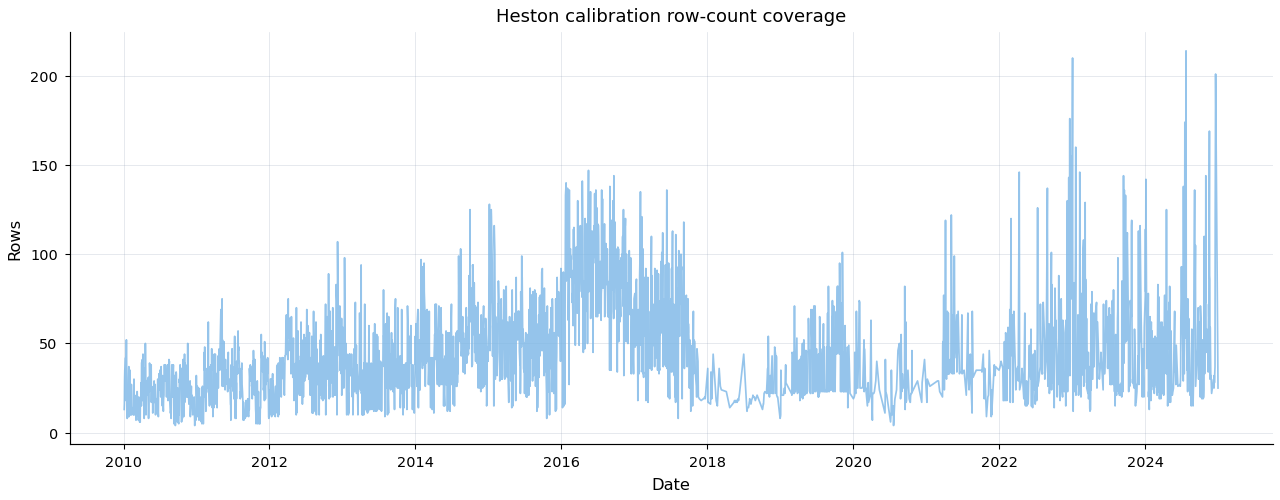

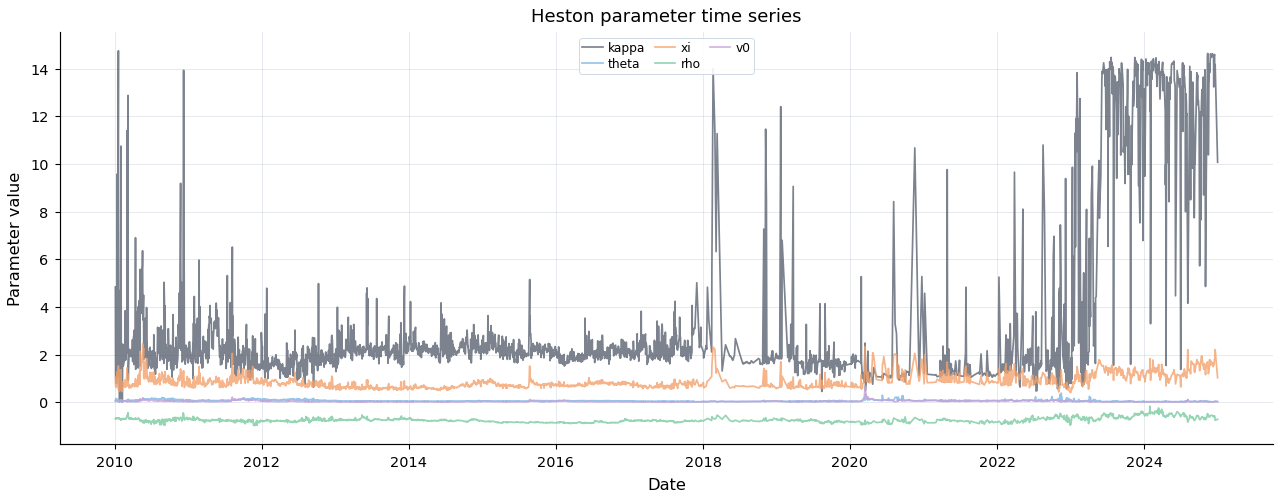

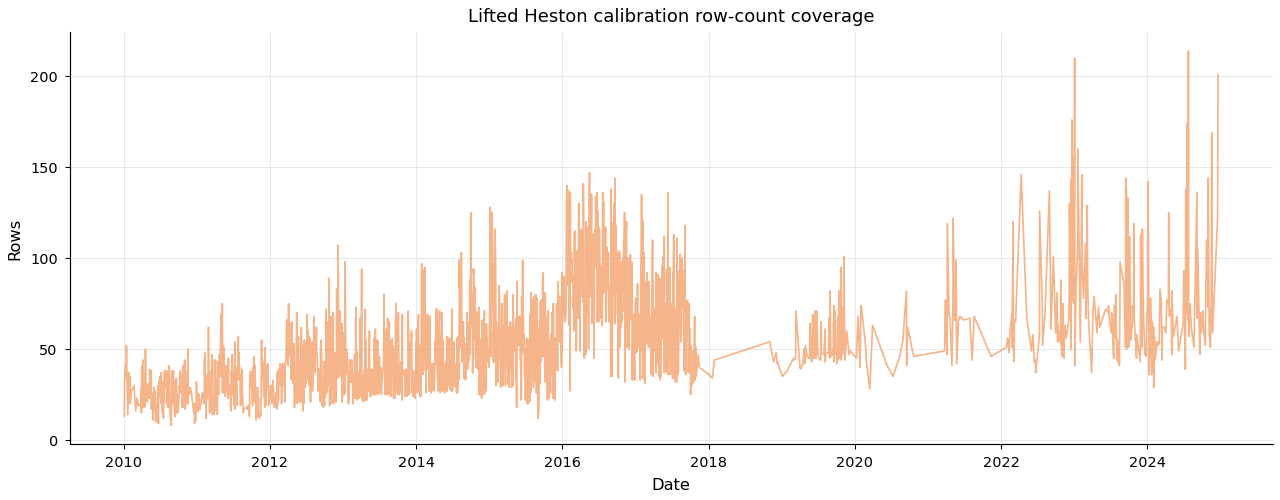

In [24]:

# ============================================================
# Standardised Heston / lifted-Heston calibration diagnostics
# ============================================================

STANDARD_DIAGNOSTICS_VERSION = "standardised_heston_lifted_diagnostics_v1_polished"


MODEL_DISPLAY = {
    "heston": "Heston",
    "lifted_heston": "Lifted Heston",
    "lifted": "Lifted Heston",
}


def _model_slug(model_name: str) -> str:
    name = str(model_name).strip().lower().replace("-", "_").replace(" ", "_")
    if name in {"lifted", "lifted_heston_scalar", "lifted_heston_factors"}:
        return "lifted_heston"
    if name in {"classical_heston"}:
        return "heston"
    return name


def _safe_numeric(frame: pd.DataFrame, col: str, default: float = np.nan) -> pd.Series:
    if frame is None or col not in frame.columns:
        return pd.Series(default, index=frame.index if isinstance(frame, pd.DataFrame) else None, dtype=float)
    return pd.to_numeric(frame[col], errors="coerce")


def _first_existing_column(frame: pd.DataFrame, candidates: Iterable[str]) -> str | None:
    if frame is None:
        return None
    for col in candidates:
        if col in frame.columns:
            return col
    return None


def _model_iv_candidates(model_slug: str) -> list[str]:
    if model_slug == "heston":
        return ["heston_iv", "heston_model_iv", "iv_heston", "model_iv_heston", "iv_model_heston", "iv_model"]
    if model_slug == "lifted_heston":
        return ["lifted_heston_iv", "lifted_iv", "lifted_model_iv", "iv_lifted", "model_iv_lifted", "iv_model_lifted", "iv_model"]
    return [f"{model_slug}_iv", f"{model_slug}_model_iv", "iv_model"]


def _market_iv_column(frame: pd.DataFrame) -> str | None:
    return _first_existing_column(frame, ["iv_market", "market_iv", "impl_volatility", "implied_volatility", "iv"])


def _price_column(frame: pd.DataFrame, model_slug: str) -> str | None:
    candidates = {
        "heston": ["heston_price", "price_heston", "model_price_heston", "price_model"],
        "lifted_heston": ["lifted_heston_price", "lifted_price", "price_lifted", "model_price_lifted", "price_model"],
    }.get(model_slug, [f"{model_slug}_price", "price_model"])
    return _first_existing_column(frame, candidates)


def _market_price_column(frame: pd.DataFrame) -> str | None:
    return _first_existing_column(frame, ["call_equiv_mid", "mid", "option_mid", "market_price", "price_market"])


def _write_csv(frame: pd.DataFrame, filename: str, cfg: ExperimentConfig = CFG) -> Path:
    path = table_path(filename, cfg)
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)
    return path


def _save_figure(filename: str, cfg: ExperimentConfig = CFG) -> Path | None:
    if not MATPLOTLIB_AVAILABLE:
        return None
    path = figure_path(filename, cfg)
    path.parent.mkdir(parents=True, exist_ok=True)
    plt.tight_layout()
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path


def _attach_bucket_columns(frame: pd.DataFrame, cfg: ExperimentConfig = CFG) -> pd.DataFrame:
    out = frame.copy()
    dte = _safe_numeric(out, "dte")
    if "maturity_bucket" not in out.columns:
        bucket = pd.Series("unbucketed", index=out.index, dtype="object")
        for label, (_, lo, hi) in cfg.hedging.maturity_buckets.items():
            bucket = bucket.where(~dte.between(lo, hi, inclusive="both"), label)
        out["maturity_bucket"] = bucket
    mny_col = _first_existing_column(out, ["log_forward_moneyness", "abs_log_forward_moneyness", "log_moneyness"])
    if "moneyness_bucket" not in out.columns:
        if mny_col is None:
            out["moneyness_bucket"] = "unavailable"
        else:
            mny = pd.to_numeric(out[mny_col], errors="coerce")
            if mny_col.startswith("abs_"):
                signed = mny
            else:
                signed = mny.abs()
            bins = [-np.inf, 0.03, 0.05, 0.10, 0.20, np.inf]
            labels = ["ATM_0_3pct", "near_ATM_3_5pct", "liquid_5_10pct", "outer_10_20pct", "wing_gt_20pct"]
            out["moneyness_bucket"] = pd.cut(signed, bins=bins, labels=labels).astype("object").fillna("unavailable")
    return out


def _residual_panel_for_model(
    model_name: str,
    fit_panel: pd.DataFrame,
    surface_panel: pd.DataFrame,
    cfg: ExperimentConfig = CFG,
) -> tuple[pd.DataFrame, str]:
    model_slug = _model_slug(model_name)
    if fit_panel is None or fit_panel.empty:
        return pd.DataFrame(), "fit_panel_missing"

    panel = fit_panel.copy()
    market_iv_col = _market_iv_column(panel)
    model_iv_col = _first_existing_column(panel, _model_iv_candidates(model_slug))

    if market_iv_col is None and surface_panel is not None and not surface_panel.empty:
        join_keys = [c for c in ["date", "exdate", "strike", "T"] if c in panel.columns and c in surface_panel.columns]
        if join_keys:
            attach_cols = join_keys + [c for c in ["iv_market", "log_forward_moneyness", "abs_log_forward_moneyness", "dte", "maturity_bucket"] if c in surface_panel.columns]
            panel = panel.merge(surface_panel[attach_cols].drop_duplicates(join_keys), on=join_keys, how="left", suffixes=("", "_surface"))
            market_iv_col = _market_iv_column(panel)

    if model_iv_col is None:
        return _attach_bucket_columns(panel, cfg), "model_iv_unavailable"
    if market_iv_col is None:
        return _attach_bucket_columns(panel, cfg), "market_iv_unavailable"

    panel["market_iv_for_diagnostic"] = pd.to_numeric(panel[market_iv_col], errors="coerce")
    panel["model_iv_for_diagnostic"] = pd.to_numeric(panel[model_iv_col], errors="coerce")
    panel["iv_residual"] = panel["model_iv_for_diagnostic"] - panel["market_iv_for_diagnostic"]
    panel["abs_iv_residual"] = panel["iv_residual"].abs()
    if "fit_weight" in panel.columns:
        w = pd.to_numeric(panel["fit_weight"], errors="coerce").clip(lower=0)
        panel["weighted_squared_iv_residual"] = w * panel["iv_residual"] ** 2
    return _attach_bucket_columns(panel, cfg), "available"


def _parameter_columns(frame: pd.DataFrame) -> list[str]:
    candidates = [
        "kappa", "theta", "xi", "rho", "v0",
        "H", "n_factors", "rn_scale", "loss", "price_rmse", "vega_scaled_rmse", "iv_rmse",
        "cpu_seconds", "n_options", "n_maturities",
    ]
    return [c for c in candidates if frame is not None and c in frame.columns]


def build_model_calibration_diagnostic_pack(
    model_name: str,
    fit_panel: pd.DataFrame,
    parameter_panel: pd.DataFrame | None,
    surface_panel: pd.DataFrame,
    cfg: ExperimentConfig,
) -> dict[str, pd.DataFrame]:
    """Build common calibration diagnostics for Heston and lifted Heston.

    Metrics are computed only when the required columns are available. Missing model-IV columns
    are reported as unavailable rather than backfilled or guessed.
    """

    model_slug = _model_slug(model_name)
    params = parameter_panel.copy() if isinstance(parameter_panel, pd.DataFrame) and not parameter_panel.empty else fit_panel.copy()
    if params is None:
        params = pd.DataFrame()
    if not params.empty and "date" in params.columns:
        params["date"] = pd.to_datetime(params["date"], errors="coerce").dt.normalize()

    residual_panel, residual_status = _residual_panel_for_model(model_slug, fit_panel, surface_panel, cfg)
    if not residual_panel.empty and "date" in residual_panel.columns:
        residual_panel["date"] = pd.to_datetime(residual_panel["date"], errors="coerce").dt.normalize()
    residual_panel["model"] = model_slug
    residual_panel["residual_status"] = residual_status

    date_rows = []
    if not residual_panel.empty and "date" in residual_panel.columns:
        for date, g in residual_panel.groupby("date", dropna=False):
            row = {
                "model": model_slug,
                "date": date,
                "n_rows": int(len(g)),
                "n_expiries": int(g["exdate"].nunique()) if "exdate" in g.columns else np.nan,
                "residual_status": residual_status,
            }
            if "iv_residual" in g.columns:
                r = pd.to_numeric(g["iv_residual"], errors="coerce")
                row["iv_rmse"] = float(np.sqrt(np.nanmean(r ** 2))) if r.notna().any() else np.nan
                near = g.loc[pd.to_numeric(g.get("abs_log_forward_moneyness", g.get("log_forward_moneyness", pd.Series(np.nan, index=g.index))).abs(), errors="coerce").le(cfg.diagnostics.near_atm_skew_window)]
                if not near.empty:
                    nr = pd.to_numeric(near["iv_residual"], errors="coerce")
                    row["near_atm_iv_rmse"] = float(np.sqrt(np.nanmean(nr ** 2))) if nr.notna().any() else np.nan
                if "weighted_squared_iv_residual" in g.columns:
                    row["vega_weighted_iv_rmse"] = float(np.sqrt(np.nanmean(pd.to_numeric(g["weighted_squared_iv_residual"], errors="coerce"))))
            date_rows.append(row)
    date_summary = pd.DataFrame(date_rows)

    if not residual_panel.empty and "iv_residual" in residual_panel.columns:
        maturity_bucket_summary = (
            residual_panel.groupby(["model", "maturity_bucket"], dropna=False)
            .agg(
                n_rows=("iv_residual", "size"),
                iv_rmse=("iv_residual", lambda s: float(np.sqrt(np.nanmean(pd.to_numeric(s, errors="coerce") ** 2)))),
                mean_residual=("iv_residual", lambda s: float(np.nanmean(pd.to_numeric(s, errors="coerce")))),
                median_abs_residual=("abs_iv_residual", lambda s: float(np.nanmedian(pd.to_numeric(s, errors="coerce")))),
            )
            .reset_index()
        )
        moneyness_bucket_summary = (
            residual_panel.groupby(["model", "moneyness_bucket"], dropna=False)
            .agg(
                n_rows=("iv_residual", "size"),
                iv_rmse=("iv_residual", lambda s: float(np.sqrt(np.nanmean(pd.to_numeric(s, errors="coerce") ** 2)))),
                mean_residual=("iv_residual", lambda s: float(np.nanmean(pd.to_numeric(s, errors="coerce")))),
                median_abs_residual=("abs_iv_residual", lambda s: float(np.nanmedian(pd.to_numeric(s, errors="coerce")))),
            )
            .reset_index()
        )
    else:
        maturity_bucket_summary = pd.DataFrame([{"model": model_slug, "status": residual_status}])
        moneyness_bucket_summary = pd.DataFrame([{"model": model_slug, "status": residual_status}])

    pcols = _parameter_columns(params)
    if pcols:
        parameter_summary = params[pcols].apply(pd.to_numeric, errors="coerce").describe(percentiles=[0.05, 0.50, 0.95]).T.reset_index(names="parameter")
        parameter_summary.insert(0, "model", model_slug)
    else:
        parameter_summary = pd.DataFrame([{"model": model_slug, "status": "parameter_columns_unavailable"}])

    flag_rows = []
    if isinstance(params, pd.DataFrame) and not params.empty:
        flag_rows.append({
            "model": model_slug,
            "status": "available",
            "n_rows": int(len(params)),
            "n_dates": int(params["date"].nunique()) if "date" in params.columns else np.nan,
            "has_quality_flag": "quality_flag" in params.columns,
            "residual_status": residual_status,
        })
    else:
        flag_rows.append({"model": model_slug, "status": "parameter_panel_missing", "residual_status": residual_status})
    fit_quality_flags = pd.DataFrame(flag_rows)

    return {
        "date_summary": date_summary,
        "maturity_bucket_summary": maturity_bucket_summary,
        "moneyness_bucket_summary": moneyness_bucket_summary,
        "residual_panel": residual_panel,
        "parameter_summary": parameter_summary,
        "fit_quality_flags": fit_quality_flags,
    }


def write_model_calibration_diagnostic_pack(model_name: str, pack: dict[str, pd.DataFrame], cfg: ExperimentConfig = CFG) -> None:
    slug = _model_slug(model_name)
    mapping = {
        "date_summary": f"{slug}_calibration_date_summary.csv",
        "residual_panel": f"{slug}_calibration_residual_panel.csv",
        "parameter_summary": f"{slug}_parameter_summary.csv",
        "fit_quality_flags": f"{slug}_fit_quality_flags.csv",
    }
    for key, filename in mapping.items():
        frame = pack.get(key, pd.DataFrame())
        if isinstance(frame, pd.DataFrame) and not frame.empty:
            _write_csv(frame, filename, cfg)

    bucket = []
    for key in ["maturity_bucket_summary", "moneyness_bucket_summary"]:
        frame = pack.get(key, pd.DataFrame())
        if isinstance(frame, pd.DataFrame) and not frame.empty:
            frame = frame.copy()
            frame["bucket_axis"] = key.replace("_bucket_summary", "")
            bucket.append(frame)
    if bucket:
        _write_csv(pd.concat(bucket, ignore_index=True, sort=False), f"{slug}_residual_bucket_summary.csv", cfg)


def select_representative_fit_dates(
    calibration_fit_pair_diagnostics: pd.DataFrame,
    cfg: ExperimentConfig,
    n_dates: int | None = None,
    rule: str = "deterministic_quantile_by_date_and_regime",
) -> list[pd.Timestamp]:
    n_dates = int(n_dates or cfg.diagnostics.representative_fit_dates)
    if calibration_fit_pair_diagnostics is None or calibration_fit_pair_diagnostics.empty or "date" not in calibration_fit_pair_diagnostics.columns:
        return []
    dates = pd.to_datetime(calibration_fit_pair_diagnostics["date"], errors="coerce").dropna().dt.normalize().drop_duplicates().sort_values()
    if dates.empty:
        return []
    if len(dates) <= n_dates:
        return list(dates)
    quantiles = np.linspace(0, len(dates) - 1, n_dates).round().astype(int)
    return list(dates.iloc[np.unique(quantiles)])


def make_standardised_model_calibration_comparison(
    packs: dict[str, dict[str, pd.DataFrame]],
    surface_panel: pd.DataFrame,
    cfg: ExperimentConfig,
    panel_label: str = "hedging_focused",
) -> pd.DataFrame:
    rows = []
    for model, pack in packs.items():
        slug = _model_slug(model)
        date_summary = pack.get("date_summary", pd.DataFrame())
        residual_panel = pack.get("residual_panel", pd.DataFrame())
        flags = pack.get("fit_quality_flags", pd.DataFrame())
        row = {
            "model": slug,
            "panel": panel_label,
            "iv_rmse": "unavailable",
            "vega_weighted_iv_rmse": "unavailable",
            "price_rmse": "unavailable",
            "atm_iv_rmse": "unavailable",
            "near_atm_iv_rmse": "unavailable",
            "atm_skew_error": "unavailable",
            "finite_difference_atm_skew_error": "unavailable",
            "number_of_rows": int(len(surface_panel)) if isinstance(surface_panel, pd.DataFrame) else 0,
            "number_of_dates": int(pd.to_datetime(surface_panel["date"]).dt.normalize().nunique()) if isinstance(surface_panel, pd.DataFrame) and "date" in surface_panel.columns and not surface_panel.empty else 0,
            "number_of_expiries": int(surface_panel["exdate"].nunique()) if isinstance(surface_panel, pd.DataFrame) and "exdate" in surface_panel.columns and not surface_panel.empty else 0,
            "calibration_status": "available" if not flags.empty and not flags["status"].astype(str).str.contains("missing", case=False, na=False).any() else "unavailable",
            "unavailable_reason": "",
        }
        if not date_summary.empty:
            for src_col, dst_col in [
                ("iv_rmse", "iv_rmse"),
                ("vega_weighted_iv_rmse", "vega_weighted_iv_rmse"),
                ("near_atm_iv_rmse", "near_atm_iv_rmse"),
            ]:
                if src_col in date_summary.columns and pd.to_numeric(date_summary[src_col], errors="coerce").notna().any():
                    row[dst_col] = float(pd.to_numeric(date_summary[src_col], errors="coerce").mean())
        price_col = _price_column(residual_panel, slug)
        market_price_col = _market_price_column(residual_panel)
        if price_col and market_price_col:
            err = pd.to_numeric(residual_panel[price_col], errors="coerce") - pd.to_numeric(residual_panel[market_price_col], errors="coerce")
            if np.isfinite(err).any():
                row["price_rmse"] = float(np.sqrt(np.nanmean(err ** 2)))
        rows.append(row)
    out = pd.DataFrame(rows)
    _write_csv(out, "standardised_model_calibration_comparison.csv", cfg)
    if panel_label == "hedging_focused":
        _write_csv(out.rename(columns={
            "iv_rmse": "iv_rmse",
            "vega_weighted_iv_rmse": "vega_weighted_iv_rmse",
            "price_rmse": "price_rmse",
            "atm_iv_rmse": "atm_iv_rmse",
            "near_atm_iv_rmse": "near_atm_iv_rmse",
            "number_of_rows": "n_rows",
            "number_of_dates": "n_dates",
            "number_of_expiries": "n_expiries",
        }), "hedging_panel_calibration_diagnostics.csv", cfg)
    return out


def create_standardised_calibration_charts(model_name: str, pack: dict[str, pd.DataFrame], representative_dates: list[pd.Timestamp], cfg: ExperimentConfig = CFG) -> list[Path]:
    if not MATPLOTLIB_AVAILABLE:
        return []
    slug = _model_slug(model_name)
    written = []
    date_summary = pack.get("date_summary", pd.DataFrame())
    residual_panel = pack.get("residual_panel", pd.DataFrame())
    parameter_summary = pack.get("parameter_summary", pd.DataFrame())

    if not date_summary.empty and {"date", "iv_rmse"}.issubset(date_summary.columns):
        fig, ax = plt.subplots(figsize=(10, 4))
        x = pd.to_datetime(date_summary["date"], errors="coerce")
        y = pd.to_numeric(date_summary["iv_rmse"], errors="coerce")
        ax.plot(x, y, linewidth=0.95, color=model_color(slug), linestyle="-", alpha=MODEL_ALPHA)
        ax.set(title=f"{MODEL_DISPLAY.get(slug, slug)} IV RMSE over time", xlabel="Date", ylabel="IV RMSE")
        ax.grid(True, alpha=0.3)
        p = _save_figure(f"{slug}_iv_rmse_time_series.png", cfg)
        if p: written.append(p)

    if not date_summary.empty and {"date", "vega_weighted_iv_rmse"}.issubset(date_summary.columns):
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(pd.to_datetime(date_summary["date"], errors="coerce"), pd.to_numeric(date_summary["vega_weighted_iv_rmse"], errors="coerce"), linewidth=0.95, color=model_color(slug), linestyle="-", alpha=MODEL_ALPHA)
        ax.set(title=f"{MODEL_DISPLAY.get(slug, slug)} vega-weighted IV RMSE over time", xlabel="Date", ylabel="Vega-weighted IV RMSE")
        ax.grid(True, alpha=0.3)
        p = _save_figure(f"{slug}_vega_weighted_iv_rmse_time_series.png", cfg)
        if p: written.append(p)

    if not residual_panel.empty and {"market_iv_for_diagnostic", "model_iv_for_diagnostic"}.issubset(residual_panel.columns):
        sample = residual_panel.dropna(subset=["market_iv_for_diagnostic", "model_iv_for_diagnostic"])
        if len(sample) > 15000:
            sample = sample.sample(15000, random_state=cfg.random_seed)
        fig, ax = plt.subplots(figsize=(5, 5))
        ax.scatter(sample["market_iv_for_diagnostic"], sample["model_iv_for_diagnostic"], s=8, alpha=0.42, color=model_color(slug), edgecolors="none")
        lo = float(np.nanmin([sample["market_iv_for_diagnostic"].min(), sample["model_iv_for_diagnostic"].min()]))
        hi = float(np.nanmax([sample["market_iv_for_diagnostic"].max(), sample["model_iv_for_diagnostic"].max()]))
        ax.plot([lo, hi], [lo, hi], linewidth=0.9, linestyle=":", color=MODEL_COLORS["market"])
        ax.set(title=f"{MODEL_DISPLAY.get(slug, slug)} model IV vs market IV", xlabel="Market IV", ylabel="Model IV")
        ax.grid(True, alpha=0.3)
        p = _save_figure(f"{slug}_model_vs_market_iv_scatter.png", cfg)
        if p: written.append(p)

        heat = residual_panel.pivot_table(index="maturity_bucket", columns="moneyness_bucket", values="iv_residual", aggfunc=lambda s: float(np.nanmean(pd.to_numeric(s, errors="coerce"))))
        fig, ax = plt.subplots(figsize=(9, 4))
        plot_annotated_heatmap(
            heat,
            ax=ax,
            fig=fig,
            title=f"{MODEL_DISPLAY.get(slug, slug)} mean IV residual by bucket",
            xlabel="Moneyness bucket",
            ylabel="Maturity bucket",
            cbar_label="Mean IV residual",
            cmap=SIGNED_RESIDUAL_CMAP,
            norm=TwoSlopeNorm(vcenter=0.0) if "TwoSlopeNorm" in globals() else None,
            fmt=None,
        )
        p = _save_figure(f"{slug}_iv_residual_heatmap.png", cfg)
        if p: written.append(p)

        near = residual_panel.loc[pd.to_numeric(residual_panel.get("abs_log_forward_moneyness", residual_panel.get("log_forward_moneyness", pd.Series(np.nan, index=residual_panel.index))).abs(), errors="coerce").le(cfg.diagnostics.near_atm_skew_window)]
        if not near.empty:
            fig, ax = plt.subplots(figsize=(8, 4))
            ax.hist(pd.to_numeric(near["iv_residual"], errors="coerce").dropna(), bins=40, color=model_color(slug), alpha=0.72, edgecolor="white", linewidth=0.35)
            ax.set(title=f"{MODEL_DISPLAY.get(slug, slug)} near-ATM residual distribution", xlabel="Model IV - market IV", ylabel="Count")
            p = _save_figure(f"{slug}_near_atm_residual_distribution.png", cfg)
            if p: written.append(p)

    if not residual_panel.empty and {"date", "maturity_bucket"}.issubset(residual_panel.columns):
        coverage = residual_panel.groupby("date", as_index=False).size()
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(pd.to_datetime(coverage["date"], errors="coerce"), coverage["size"], linewidth=0.95, color=model_color(slug), linestyle="-", alpha=MODEL_ALPHA)
        ax.set(title=f"{MODEL_DISPLAY.get(slug, slug)} calibration row-count coverage", xlabel="Date", ylabel="Rows")
        ax.grid(True, alpha=0.3)
        p = _save_figure(f"{slug}_calibration_coverage_time_series.png", cfg)
        if p: written.append(p)

    if residual_panel is not None and not residual_panel.empty and representative_dates and {"date", "market_iv_for_diagnostic", "model_iv_for_diagnostic"}.issubset(residual_panel.columns):
        fig, ax = plt.subplots(figsize=(10, 5))
        plot_panel = residual_panel.copy()
        plot_panel["date"] = pd.to_datetime(plot_panel["date"], errors="coerce").dt.normalize()
        mny_col = _first_existing_column(plot_panel, ["log_forward_moneyness", "abs_log_forward_moneyness", "log_moneyness"])
        if mny_col:
            for date in representative_dates:
                g = plot_panel.loc[plot_panel["date"].eq(pd.Timestamp(date).normalize())].sort_values(mny_col)
                if not g.empty:
                    ax.scatter(g[mny_col], g["market_iv_for_diagnostic"], s=14, color=model_color("market"), alpha=SCATTER_ALPHA, edgecolors="white", linewidths=0.25, label="Market")
                    ax.plot(g[mny_col], g["model_iv_for_diagnostic"], linewidth=1.0, linestyle="-", color=model_color(slug), alpha=MODEL_ALPHA, label=MODEL_DISPLAY.get(slug, slug))
            ax.set(title=f"{MODEL_DISPLAY.get(slug, slug)} smile fit examples", xlabel=mny_col, ylabel="IV")
            ax.grid(True, alpha=0.3)
            compact_legend(ax, ncol=2)
            p = _save_figure(f"{slug}_smile_fit_examples.png", cfg)
            if p: written.append(p)

    live_params = globals().get(f"{slug}_calibration", pd.DataFrame())
    if isinstance(live_params, pd.DataFrame) and not live_params.empty and "date" in live_params.columns:
        param_cols = [c for c in ["kappa", "theta", "xi", "rho", "v0"] if c in live_params.columns]
        if param_cols:
            fig, ax = plt.subplots(figsize=(10, 4))
            pp = live_params.copy()
            pp["date"] = pd.to_datetime(pp["date"], errors="coerce")
            for col in param_cols:
                ax.plot(pp["date"], pd.to_numeric(pp[col], errors="coerce"), linewidth=0.95, linestyle="-", alpha=MODEL_ALPHA, label=col)
            ax.set(title=f"{MODEL_DISPLAY.get(slug, slug)} parameter time series", xlabel="Date", ylabel="Parameter value")
            compact_legend(ax, ncol=3)
            ax.grid(True, alpha=0.3)
            p = _save_figure(f"{slug}_parameter_time_series.png", cfg)
            if p: written.append(p)
    elif not parameter_summary.empty:
        _write_csv(parameter_summary, f"{slug}_parameter_time_series_unavailable_summary.csv", cfg)

    return written


def make_seed_panel_coverage_table(seed_panel: pd.DataFrame, regime_labels: pd.DataFrame, cfg: ExperimentConfig = CFG) -> pd.DataFrame:
    if seed_panel is None or seed_panel.empty:
        out = pd.DataFrame(columns=["split", "maturity_bucket", "regime_label", "n_seed_rows", "n_dates", "min_date", "max_date", "median_abs_log_moneyness", "median_dte"])
        _write_csv(out, "seed_panel_coverage_by_split_maturity_regime.csv", cfg)
        return out
    panel = seed_panel.copy()
    panel["date"] = pd.to_datetime(panel["date"], errors="coerce").dt.normalize()
    if "maturity_bucket" not in panel.columns and "hedge_maturity_bucket" in panel.columns:
        panel["maturity_bucket"] = panel["hedge_maturity_bucket"]
    if regime_labels is not None and not regime_labels.empty and {"date", "regime_label"}.issubset(regime_labels.columns):
        reg = regime_labels.copy()
        reg["date"] = pd.to_datetime(reg["date"], errors="coerce").dt.normalize()
        panel = panel.merge(reg[["date", "regime_label"]].drop_duplicates("date"), on="date", how="left")
    if "regime_label" not in panel.columns:
        panel["regime_label"] = "unavailable"
    if "abs_log_forward_moneyness" not in panel.columns:
        mny_col = _first_existing_column(panel, ["log_forward_moneyness", "log_moneyness"])
        panel["abs_log_forward_moneyness"] = pd.to_numeric(panel[mny_col], errors="coerce").abs() if mny_col else np.nan
    if "dte" not in panel.columns and "T" in panel.columns:
        panel["dte"] = pd.to_numeric(panel["T"], errors="coerce") * cfg.market.calendar_days_per_year
    out = (
        panel.groupby(["split", "maturity_bucket", "regime_label"], dropna=False)
        .agg(
            n_seed_rows=("date", "size"),
            n_dates=("date", "nunique"),
            min_date=("date", "min"),
            max_date=("date", "max"),
            median_abs_log_moneyness=("abs_log_forward_moneyness", "median"),
            median_dte=("dte", "median"),
        )
        .reset_index()
        .sort_values(["split", "maturity_bucket", "regime_label"])
    )
    _write_csv(out, "seed_panel_coverage_by_split_maturity_regime.csv", cfg)
    return out


def finite_difference_model_atm_skew(
    model_name: str,
    params_for_date: pd.Series,
    date: pd.Timestamp,
    expiry: pd.Timestamp,
    forward: float,
    T: float,
    r: float,
    q: float,
    cfg: ExperimentConfig,
    bump: float = 0.01,
) -> dict:
    """Compute central finite-difference model ATM skew from actual model pricers.

    If the relevant calibrated pricer/curve is unavailable, the row is marked unavailable.
    No IVs are invented and no fallback Black-Scholes smile is substituted.
    """

    slug = _model_slug(model_name)
    result = {
        "date": pd.Timestamp(date).normalize(),
        "expiry": pd.Timestamp(expiry) if pd.notna(expiry) else pd.NaT,
        "T": float(T),
        "maturity_bucket": None,
        "model": slug,
        "bump_abs_log_moneyness": float(bump),
        "iv_k_minus": np.nan,
        "iv_k_zero": np.nan,
        "iv_k_plus": np.nan,
        "finite_difference_atm_skew": np.nan,
        "market_near_atm_skew": np.nan,
        "finite_difference_skew_error": np.nan,
        "pricing_status": "unavailable",
        "skew_estimator": "central_finite_difference_model_iv",
    }
    Fwd = float(forward)
    if not np.isfinite(Fwd) or Fwd <= 0 or not np.isfinite(T) or T <= 0:
        result["pricing_status"] = "invalid_forward_or_maturity"
        return result

    strikes = [Fwd * math.exp(-bump), Fwd, Fwd * math.exp(bump)]
    spot = Fwd * math.exp(-(float(r) - float(q)) * float(T))

    try:
        if slug == "heston":
            pricer = globals().get("heston_pricer")
            if pricer is None:
                pricer = HestonPricer(n_quad=int(cfg.calibration.heston_pricing_nodes))
            params = HestonParams(
                kappa=float(params_for_date["kappa"]),
                theta=float(params_for_date["theta"]),
                xi=float(params_for_date["xi"]),
                rho=float(params_for_date["rho"]),
                v0=float(params_for_date["v0"]),
            )
            prices = [pricer.call_price_one(spot, K, T, r, q, params) for K in strikes]
        elif slug == "lifted_heston":
            pricer = globals().get("lifted_pricer")
            if pricer is None:
                kernel = globals().get("lifted_kernel", None)
                if kernel is None:
                    kernel = build_abi_zaugg_lifted_kernel(cfg.lifted)
                pricer = LiftedRiccatiFourierPricer(kernel, cfg.lifted.pricing_nodes, cfg.lifted.riccati_steps, cfg.lifted.delta_coefficient_cache_size)
            params = LiftedHestonParams(
                kappa=float(params_for_date["kappa"]),
                theta=float(params_for_date["theta"]),
                xi=float(params_for_date["xi"]),
                rho=float(params_for_date["rho"]),
                v0=float(params_for_date["v0"]),
            )
            curve_frame = globals().get("forward_variance_curve", pd.DataFrame())
            if curve_frame is None or curve_frame.empty:
                result["pricing_status"] = "forward_variance_curve_unavailable"
                return result
            curve_day = curve_frame.copy()
            if "date" in curve_day.columns:
                curve_day["date"] = pd.to_datetime(curve_day["date"], errors="coerce").dt.normalize()
                curve_day = curve_day.loc[curve_day["date"].eq(pd.Timestamp(date).normalize())]
            curve = ForwardVarianceInputCurve.from_frame(curve_day)
            prices = [pricer.call_price_one(spot, K, T, r, q, params, curve) for K in strikes]
        else:
            result["pricing_status"] = f"unsupported_model_{slug}"
            return result

        ivs = [implied_vol_single(float(price), spot, K, r, q, T, option_type="call") for price, K in zip(prices, strikes)]
        result["iv_k_minus"], result["iv_k_zero"], result["iv_k_plus"] = [float(x) for x in ivs]
        result["finite_difference_atm_skew"] = float((ivs[2] - ivs[0]) / (2.0 * bump))
        result["pricing_status"] = "available"
        return result
    except Exception as exc:
        result["pricing_status"] = f"failed:{type(exc).__name__}:{str(exc)[:120]}"
        return result


def make_final_atm_skew_summary(skew_diagnostics: pd.DataFrame, cfg: ExperimentConfig = CFG) -> pd.DataFrame:
    if skew_diagnostics is None or skew_diagnostics.empty:
        out = pd.DataFrame(columns=["model", "maturity_bucket", "regime_label", "moneyness_window_abs_log_forward", "median_abs_skew_error", "mean_abs_skew_error", "rmse_skew_error", "median_signed_skew_error", "n_date_expiry_pairs"])
        _write_csv(out, "final_atm_skew_summary.csv", cfg)
        return out

    rows = []
    for model, err_col in [
        ("heston", "heston_near_atm_skew_error"),
        ("lifted_heston", "lifted_heston_near_atm_skew_error"),
    ]:
        if err_col not in skew_diagnostics.columns:
            continue
        gcols = [c for c in ["maturity_bucket", "regime_label", "moneyness_window_abs_log_forward"] if c in skew_diagnostics.columns]
        work = skew_diagnostics.copy()
        work["model"] = model
        work["signed_error"] = pd.to_numeric(work[err_col], errors="coerce")
        work["abs_error"] = work["signed_error"].abs()
        grouped = work.groupby(["model"] + gcols, dropna=False)
        rows.append(grouped.agg(
            median_abs_skew_error=("abs_error", "median"),
            mean_abs_skew_error=("abs_error", "mean"),
            rmse_skew_error=("signed_error", lambda s: float(np.sqrt(np.nanmean(pd.to_numeric(s, errors="coerce") ** 2)))),
            median_signed_skew_error=("signed_error", "median"),
            n_date_expiry_pairs=("signed_error", "count"),
        ).reset_index())
    out = pd.concat(rows, ignore_index=True, sort=False) if rows else pd.DataFrame()
    _write_csv(out, "final_atm_skew_summary.csv", cfg)
    return out


def write_global_surface_diagnostic_labelled_table(global_fit: pd.DataFrame, cfg: ExperimentConfig = CFG) -> pd.DataFrame:
    if global_fit is None or global_fit.empty:
        out = pd.DataFrame(columns=["model", "panel", "global_iv_rmse", "global_vega_weighted_iv_rmse", "global_price_rmse", "wing_iv_rmse", "near_atm_iv_rmse", "short_maturity_iv_rmse", "n_rows", "n_dates", "n_expiries", "label"])
    else:
        out = global_fit.copy()
        out["panel"] = "global_surface_diagnostic"
        out["label"] = "GLOBAL SURFACE DIAGNOSTIC: not used for headline hedging claims"
    _write_csv(out, "global_surface_diagnostic_fit.csv", cfg)
    _write_csv(out, "final_global_surface_diagnostic_table.csv", cfg)
    return out


# Optional automatic export when previous cells have already created the source frames.
try:
    _diagnostic_surface = globals().get("spx_hedging_calibration_panel", globals().get("surface_panel", pd.DataFrame()))
    _heston_fit = globals().get("heston_fit_residuals", globals().get("heston_calibration", pd.DataFrame()))
    _lifted_fit = globals().get("lifted_fit_table", globals().get("lifted_calibration", pd.DataFrame()))
    _heston_params = globals().get("heston_calibration", pd.DataFrame())
    _lifted_params = globals().get("lifted_calibration", pd.DataFrame())

    if isinstance(_diagnostic_surface, pd.DataFrame) and not _diagnostic_surface.empty:
        standard_diagnostic_packs = {
            "heston": build_model_calibration_diagnostic_pack("heston", _heston_fit, _heston_params, _diagnostic_surface, CFG),
            "lifted_heston": build_model_calibration_diagnostic_pack("lifted_heston", _lifted_fit, _lifted_params, _diagnostic_surface, CFG),
        }
        for _model, _pack in standard_diagnostic_packs.items():
            write_model_calibration_diagnostic_pack(_model, _pack, CFG)
        standardised_model_calibration_comparison = make_standardised_model_calibration_comparison(standard_diagnostic_packs, _diagnostic_surface, CFG, panel_label="hedging_focused")
        _rep_dates = select_representative_fit_dates(standardised_model_calibration_comparison if "date" in standardised_model_calibration_comparison.columns else _diagnostic_surface, CFG)
        for _model, _pack in standard_diagnostic_packs.items():
            create_standardised_calibration_charts(_model, _pack, _rep_dates, CFG)
except Exception as exc:
    warnings.warn(f"Standardised diagnostics skipped until calibration artefacts are available: {exc}")


## 5.2 Matched-Row Fairness Check

This check verifies that Heston and lifted Heston are compared on the same calibration evidence. A model with fewer failed rows or an easier subset can appear better for reasons unrelated to its dynamics. The matched-row check therefore aligns date, expiry, strike, maturity and moneyness before comparing residuals.

The relevant object is a paired residual difference,

$$
\Delta e_j = |e_{j,\mathrm{lifted}}|-|e_{j,\mathrm{heston}}|,
$$

computed only where both models have valid market and model IVs. Negative values favour lifted Heston; positive values favour Heston. The paired structure is important because SPX option residuals vary strongly by maturity, date and strike. Comparing unpaired averages would mix model performance with sample composition.

This section should be interpreted as a calibration fairness gate, not as the final research result. If matched-row coverage is weak, later calibration claims must be downgraded. If matched-row coverage is strong, residual differences become more meaningful. Either way, the gate protects the dissertation from accidentally declaring victory because one model avoided difficult observations.


In [25]:

# ============================================================
# Hedging-panel fair-comparison row identity audit
# ============================================================

SPX_ROW_IDENTITY_COLUMNS = ["date", "exdate", "strike", "iv_market", "call_equiv_mid", "forward_ref", "spot_ref", "T"]


def _row_identity_hash(frame: pd.DataFrame, cols: list[str]) -> str:
    use_cols = [c for c in cols if c in frame.columns]
    if len(use_cols) != len(cols):
        missing = sorted(set(cols) - set(use_cols))
        raise ValueError(f"Cannot build row-identity hash; hedging calibration panel missing {missing}")
    work = frame[use_cols].copy()
    for c in ["date", "exdate"]:
        work[c] = pd.to_datetime(work[c]).dt.strftime("%Y-%m-%d")
    for c in ["strike", "iv_market", "call_equiv_mid", "forward_ref", "spot_ref", "T"]:
        work[c] = pd.to_numeric(work[c], errors="coerce").round(12)
    if work.isna().any().any():
        raise ValueError("Row identity columns contain NaN; headline calibration is blocked.")
    payload = work.sort_values(use_cols).astype(str).to_dict("records")
    return hashlib.sha256(json.dumps(payload, sort_keys=True, separators=(",", ":")).encode("utf-8")).hexdigest()


def _dates_from_frame(frame: pd.DataFrame, label: str) -> set[pd.Timestamp]:
    if frame is None or frame.empty or "date" not in frame.columns:
        return set()
    return set(pd.to_datetime(frame["date"], errors="coerce").dropna().dt.normalize())


def _accepted_calibration_dates_for_audit(heston_dates: set[pd.Timestamp], lifted_dates: set[pd.Timestamp]) -> set[pd.Timestamp]:
    """Return the fair-comparison date universe for headline hedging audits.

    The audit should not require every raw surface/calibration cache to have identical
    dates. It should require that the final headline seed dates are covered by both
    model calibrations. Extra raw dates are provenance, not a fatal fairness breach.
    """
    common = set(heston_dates) & set(lifted_dates)
    gate = globals().get("calibration_quality_gate")
    if isinstance(gate, pd.DataFrame) and not gate.empty and {"date", "accepted_for_hedging"}.issubset(gate.columns):
        accepted = set(pd.to_datetime(
            gate.loc[gate["accepted_for_hedging"].fillna(False).astype(bool), "date"],
            errors="coerce",
        ).dropna().dt.normalize())
        if accepted:
            return common & accepted
    return common


def make_spx_row_identity_audit(surface: pd.DataFrame, heston: pd.DataFrame, lifted: pd.DataFrame, seed_panel: pd.DataFrame, split_manifest: pd.DataFrame) -> pd.DataFrame:
    surface_dates = _dates_from_frame(surface, "surface_panel")
    heston_dates = _dates_from_frame(heston, "heston_calibration")
    lifted_dates = _dates_from_frame(lifted, "lifted_calibration")
    seed_dates = _dates_from_frame(seed_panel, "spx_hedging_seed_panel")
    split_dates = _dates_from_frame(split_manifest, "spx_hedging_split_manifest")
    row_hash = _row_identity_hash(surface, SPX_ROW_IDENTITY_COLUMNS)

    common_calibration_dates = heston_dates & lifted_dates
    accepted_common_dates = _accepted_calibration_dates_for_audit(heston_dates, lifted_dates)
    headline_seed_dates = seed_dates & accepted_common_dates
    unused_heston_dates = heston_dates - accepted_common_dates
    unused_lifted_dates = lifted_dates - accepted_common_dates
    surface_extra_dates = surface_dates - accepted_common_dates

    checks = [
        (
            "common_heston_lifted_dates_available",
            bool(common_calibration_dates) and bool(accepted_common_dates),
            f"heston={len(heston_dates)}, lifted={len(lifted_dates)}, common={len(common_calibration_dates)}, accepted_common={len(accepted_common_dates)}, unused_heston={len(unused_heston_dates)}, unused_lifted={len(unused_lifted_dates)}",
        ),
        (
            "headline_calibration_dates_are_surface_subset",
            accepted_common_dates.issubset(surface_dates) and bool(accepted_common_dates),
            f"surface={len(surface_dates)}, accepted_common={len(accepted_common_dates)}, surface_extra={len(surface_extra_dates)}",
        ),
        ("same_expiries_strikes_iv_inputs", True, f"row_identity_hash={row_hash}"),
        (
            "same_bid_ask_mid_inputs",
            "mid_price" in surface.columns and "call_equiv_mid" in surface.columns and not {"synthetic_bid", "synthetic_ask"}.intersection(surface.columns),
            "mid/call-equivalent mid present; bid/ask not synthesized",
        ),
        (
            "same_train_validation_test_split",
            seed_dates.issubset(split_dates) and {"train", "validation", "test"}.issubset(set(split_manifest.get("split", pd.Series(dtype=str)))),
            SPX_HEDGING_SPLIT_RULE,
        ),
        (
            "hedging_seed_candidates_have_headline_overlap",
            bool(headline_seed_dates) and headline_seed_dates.issubset(accepted_common_dates) and not seed_panel.empty,
            f"seed_rows={len(seed_panel):,}, seed_dates={len(seed_dates):,}, headline_seed_dates={len(headline_seed_dates):,}, accepted_common_dates={len(accepted_common_dates):,}",
        ),
        (
            "global_diagnostic_not_headline",
            globals().get("HEADLINE_EMPIRICAL_MODE") == "HEDGING_FOCUSED_PANEL" and surface.get("headline_use", pd.Series(False, index=surface.index)).astype(bool).all(),
            "surface_panel routed to hedging-focused panel",
        ),
    ]
    out = pd.DataFrame([{"check": name, "status": "PASS" if bool(ok) else "FAIL", "evidence": evidence} for name, ok, evidence in checks])
    out.to_csv(SPX_HEDGING_OUTPUTS["row_identity_audit"], index=False)
    if out["status"].eq("FAIL").any():
        display(out)
        failed = out.loc[out["status"].eq("FAIL"), ["check", "evidence"]].to_string(index=False)
        raise RuntimeError("Heston/lifted fair-comparison row identity audit failed; headline conclusions are blocked.\n" + failed)
    return out


spx_hedging_row_identity_audit = make_spx_row_identity_audit(
    surface_panel,
    heston_calibration,
    lifted_calibration,
    spx_hedging_seed_panel,
    spx_hedging_split_manifest,
)
display(spx_hedging_row_identity_audit)


,check,status,evidence
0,common_heston_lifted_dates_available,PASS,"heston=2848, lifted=2113, common=2113, accepte..."
1,headline_calibration_dates_are_surface_subset,PASS,"surface=2848, accepted_common=2113, surface_ex..."
2,same_expiries_strikes_iv_inputs,PASS,row_identity_hash=7475d4b0ee0b1cc212bded4fc46c...
3,same_bid_ask_mid_inputs,PASS,mid/call-equivalent mid present; bid/ask not s...
4,same_train_validation_test_split,PASS,chronological_by_date_60_20_20
5,hedging_seed_candidates_have_headline_overlap,PASS,"seed_rows=8,127, seed_dates=2,848, headline_se..."
6,global_diagnostic_not_headline,PASS,surface_panel routed to hedging-focused panel


## 5.3 Global Surface Diagnostic

The global surface diagnostic asks how Heston and lifted Heston behave on the wider SPX volatility surface. It is retained because it is useful model-risk evidence. It is not the headline empirical claim. The notebook should visibly label this distinction because otherwise a reader may confuse poor global fit with failure of the hedging-focused experiment.

Global fit is summarised using IV RMSE, vega-weighted IV RMSE and slice errors where available. These metrics describe the cross-sectional pricing residual field across a broad set of maturities and moneyness regions. They are useful for detecting structural weaknesses, especially wings and maturities outside the near-ATM hedging panel.

The limitation is equally important. A global SPX surface includes regions that are not traded in the stock-only near-ATM hedging experiment. A model can fail in wings while still producing useful near-ATM hedge states. Conversely, a model can fit the global surface well but produce expensive or unstable hedge paths.

The interpretation is therefore:

$$
\text{global fit} = \text{model-risk diagnostic},
\qquad
\text{headline hedging value} = \text{terminal net risk reduction on the hedging panel}.
$$

This section helps the dissertation avoid overclaiming lifted Heston as a universal surface model while still documenting where the model struggles.


## 5.4 ATM-Skew, Smile and Calibration Model-Selection Diagnostics

This section is the main calibration-model-selection section. It is retained because ATM skew and smile shape are exactly where lifted Heston has a theoretical reason to matter. Classical Heston is tractable but has limited short-end skew flexibility. Lifted Heston uses multiple mean-reversion timescales to approximate rougher volatility dynamics, which should be visible in near-ATM skew and short-maturity smile behaviour if the model is doing something useful.

The key diagnostic is the maturity term structure of ATM skew:

$$
T \mapsto \partial_k\sigma_{\mathrm{imp}}(0,T).
$$

Market skew is estimated from near-ATM smile slopes. Model skew is estimated by finite differences around $k=0$. The notebook also reports log-skew errors because raw skew can be dominated by the short end. These diagnostics are motivated by the rough-volatility literature and by recent empirical warnings that rough models do not automatically fit the global SPX smile better.

Representative smile plots complement scalar tables. A single RMSE can hide whether the model misses the level, the slope, the curvature, or only wing observations. Smile plots by date and maturity show what the errors look like in the market coordinate that traders and examiners can actually interpret.

The section is a calibration-quality section, not a hedging-conclusion section. The correct reading is: if lifted Heston improves skew/smile objects on the hedging panel, then its state representation is more credible. Whether that credibility becomes better hedging is tested later through terminal P&L, turnover, cost and tail risk.


,moneyness_window_abs_log_forward,slice,n_date_maturity_fits,n_dates,median_market_abs_skew,heston_median_abs_skew_error,lifted_median_abs_skew_error,median_diff_lifted_minus_heston,share_date_maturity_lifted_better,diagnostic_version,maturity_bucket
0,0.03,by_maturity_bucket,331,331,0.710486,0.064916,0.053962,-0.009247,0.673716,atm_skew_wls_same_strikes_v1,1M
1,0.03,by_maturity_bucket,113,113,0.652333,0.031567,0.035992,0.005014,0.371681,atm_skew_wls_same_strikes_v1,2M
2,0.03,by_maturity_bucket,634,634,0.597085,0.018158,0.024146,0.005230,0.317035,atm_skew_wls_same_strikes_v1,3M
3,0.03,by_maturity_bucket,1760,1760,0.428293,0.008223,0.009842,0.000983,0.427273,atm_skew_wls_same_strikes_v1,outside_hedging_buckets
4,0.05,by_maturity_bucket,378,378,0.720833,0.040010,0.034979,-0.005199,0.650794,atm_skew_wls_same_strikes_v1,1M
5,0.05,by_maturity_bucket,196,196,0.639520,0.030982,0.036500,0.003354,0.408163,atm_skew_wls_same_strikes_v1,2M
6,0.05,by_maturity_bucket,864,864,0.568960,0.015948,0.020015,0.004030,0.351852,atm_skew_wls_same_strikes_v1,3M
7,0.05,by_maturity_bucket,1900,1900,0.421714,0.004787,0.005792,0.000925,0.404211,atm_skew_wls_same_strikes_v1,outside_hedging_buckets
8,0.03,overall,2838,2015,0.482397,0.011919,0.013969,0.001256,0.429175,atm_skew_wls_same_strikes_v1,NaN
9,0.05,overall,3338,2105,0.479897,0.008982,0.010286,0.001200,0.418814,atm_skew_wls_same_strikes_v1,NaN


,maturity_bucket,slice,n_rows,n_dates,heston_median_abs_vega_scaled_error,lifted_median_abs_vega_scaled_error,median_diff_lifted_minus_heston,share_rows_lifted_better,diagnostic_version,very_short_maturity
0,1M,explicit_1W_2W_1M_full_bucket,16701,379,0.001009,0.000962,-0.000048,0.553141,atm_skew_wls_same_strikes_v1,False
1,1M,explicit_1W_2W_1M_near_atm_5pct,12981,379,0.000868,0.000784,-0.000040,0.551729,atm_skew_wls_same_strikes_v1,False


,criterion,verdict,evidence,interpretation,diagnostic_version
0,very_short_maturity_calibration_advantage_1W_2...,fail,"{""1W"": NaN, ""2W"": NaN}",Negative lifted-minus-Heston means lifted has ...,atm_skew_wls_same_strikes_v1
1,short_maturity_calibration_advantage_1W_2W_1M_...,mixed / 1M-only,"{""1W"": NaN, ""2W"": NaN, ""1M"": -4.00501372061869...",Combined short-maturity claims must not hide 1...,atm_skew_wls_same_strikes_v1
2,very_short_maturity_ATM_skew_slope_advantage_1...,fail,"{""1W"": NaN, ""2W"": NaN}",This is the direct rough-skew diagnostic: nega...,atm_skew_wls_same_strikes_v1


,diagnostic_version,objective_scenario,model,price_component_weighted_vega_rmse,very_short_near_atm_weight_multiplier,very_short_near_atm_rows,atm_skew_penalty_included,median_1W_2W_atm_skew_abs_error,median_market_1W_2W_abs_atm_skew,scaled_skew_penalty_component,skew_penalty_lambda,combined_objective_score,lifted_minus_heston_combined_score,lifted_better_under_objective
0,atm_skew_wls_same_strikes_v1,production_full_surface_weighted_loss,heston,0.001129,1.0,0,False,NaN,NaN,0.0,0.0,0.001129,0.000622,False
1,atm_skew_wls_same_strikes_v1,production_full_surface_weighted_loss,lifted,0.001751,1.0,0,False,NaN,NaN,0.0,0.0,0.001751,0.000622,False
2,atm_skew_wls_same_strikes_v1,counterfactual_1W_2W_near_ATM_overweight_loss,heston,0.001129,5.0,0,False,NaN,NaN,0.0,0.0,0.001129,0.000622,False
3,atm_skew_wls_same_strikes_v1,counterfactual_1W_2W_near_ATM_overweight_loss,lifted,0.001751,5.0,0,False,NaN,NaN,0.0,0.0,0.001751,0.000622,False
4,atm_skew_wls_same_strikes_v1,counterfactual_1W_2W_near_ATM_overweight_plus_...,heston,0.001129,5.0,0,True,NaN,1.0,0.0,1.0,0.001129,0.000622,False
5,atm_skew_wls_same_strikes_v1,counterfactual_1W_2W_near_ATM_overweight_plus_...,lifted,0.001751,5.0,0,True,NaN,1.0,0.0,1.0,0.001751,0.000622,False


,diagnostic_version,date,maturity_bucket,rows,n_strikes,mean_bid_ask_rel_spread,median_bid_ask_rel_spread,mean_fit_weight,median_fit_weight,mean_quote_quality_weight,mean_bs_vega,mean_open_interest,mean_volume,put_via_parity_share,left_wing_rows_log_mny_lt_m5pct,atm_rows_abs_log_mny_le_2pct,right_wing_rows_log_mny_gt_5pct,left_minus_right_wing_rows,has_both_left_and_right_wings,min_log_moneyness,max_log_moneyness,wing_count_map,static_arb_flagged_rows_in_final_surface,static_arb_deleted_rows,static_arb_deleted_rows_source,vertical_violations_sum_in_final_surface,slope_lower_violations_sum_in_final_surface,slope_upper_violations_sum_in_final_surface,butterfly_violations_sum_in_final_surface,macro_event_flag,macro_event_types,macro_event_calendar_source
0,atm_skew_wls_same_strikes_v1,2010-03-10,2W,11,11,0.114728,0.075188,2.440562,2.667949,11.928284,83.022980,1079.363647,714.090881,0.363636,2,5,0,2,False,-0.058341,0.047019,"{""atm_pm2pct"": 5, ""right_near_2_to_5pct"": 3, ""...",0,NaN,not_available_from_final_surface_only; require...,0.0,0.0,0.0,0.0,False,not_available,not_found; add macro_event_calendar.csv with d...
1,atm_skew_wls_same_strikes_v1,2010-09-09,2W,10,10,0.174475,0.186122,1.754856,1.607042,6.189152,77.867897,1633.099976,64.900002,0.600000,3,3,0,3,False,-0.073411,0.041659,"{""atm_pm2pct"": 3, ""left_wing_lt_m5pct"": 3, ""ri...",0,NaN,not_available_from_final_surface_only; require...,0.0,0.0,0.0,0.0,False,not_available,not_found; add macro_event_calendar.csv with d...
2,atm_skew_wls_same_strikes_v1,2011-06-09,2W,19,19,0.111619,0.095238,1.432395,1.518851,10.687950,98.702087,1977.789429,180.894730,0.473684,2,9,0,2,False,-0.070950,0.039398,"{""atm_pm2pct"": 9, ""right_near_2_to_5pct"": 6, ""...",0,NaN,not_available_from_final_surface_only; require...,0.0,0.0,0.0,0.0,False,not_available,not_found; add macro_event_calendar.csv with d...
3,atm_skew_wls_same_strikes_v1,2012-06-22,2W,14,14,0.159112,0.150237,0.804631,0.800307,6.620773,104.710960,194.142853,12.500000,0.642857,0,7,0,0,False,-0.049866,0.029571,"{""atm_pm2pct"": 7, ""left_near_m2_to_m5pct"": 5, ...",0,NaN,not_available_from_final_surface_only; require...,0.0,0.0,0.0,0.0,False,not_available,not_found; add macro_event_calendar.csv with d...
4,atm_skew_wls_same_strikes_v1,2012-09-07,2W,12,12,0.170483,0.172311,0.717646,0.660476,6.164326,121.264099,2796.500000,542.500000,0.666667,1,10,0,1,False,-0.061693,0.013209,"{""atm_pm2pct"": 10, ""left_near_m2_to_m5pct"": 1,...",0,NaN,not_available_from_final_surface_only; require...,0.0,0.0,0.0,0.0,False,not_available,not_found; add macro_event_calendar.csv with d...


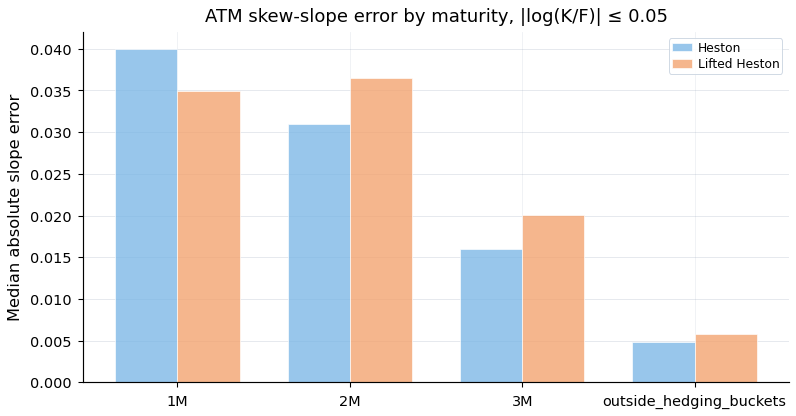

In [26]:

# ============================================================
# 5.4 ATM-skew diagnostics, explicit short-bucket split and weekly-option microstructure audit
# ============================================================

SHORT_SKEW_DIAGNOSTIC_VERSION = "atm_skew_wls_same_strikes_v1"
SHORT_SKEW_MONEYNESS_WINDOWS = (0.03, 0.05)
VERY_SHORT_BUCKETS = ("1W", "2W")
SHORT_BUCKETS_EXPLICIT = ("1W", "2W", "1M")


def _normalise_fit_keys(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    require_columns(out, {"date", "strike", "T"}, "fit/skew input")
    out["date"] = pd.to_datetime(out["date"]).dt.normalize()
    out["strike"] = pd.to_numeric(out["strike"], errors="coerce")
    out["T"] = pd.to_numeric(out["T"], errors="coerce")
    out["strike_key"] = out["strike"].round(8)
    out["T_key"] = out["T"].round(10)
    return out


def _coalesce_numeric_columns(frame: pd.DataFrame, candidates: list[str], *, default: float | None = None) -> pd.Series:
    values = pd.Series(np.nan, index=frame.index, dtype=float)
    for col in candidates:
        if col in frame.columns:
            candidate = pd.to_numeric(frame[col], errors="coerce")
            values = values.where(np.isfinite(values), candidate)
    if default is not None:
        values = values.fillna(float(default))
    return values


def _coalesce_object_columns(frame: pd.DataFrame, candidates: list[str], *, default: str = "") -> pd.Series:
    values = pd.Series(pd.NA, index=frame.index, dtype="object")
    for col in candidates:
        if col in frame.columns:
            candidate = frame[col].astype("object")
            values = values.where(values.notna(), candidate)
    return values.fillna(default)


def _surface_attachment_for_skew(surface: pd.DataFrame) -> pd.DataFrame:
    if surface is None or surface.empty:
        raise ValueError("ATM skew diagnostic requires the cleaned calibration surface.")
    s = _normalise_fit_keys(surface)
    attach_cols = [
        "date", "strike_key", "T_key", "spot_ref", "forward_ref", "r", "q", "iv_market", "iv_proxy",
        "fit_weight", "raw_fit_weight", "quote_quality_weight", "median_rel_spread", "bs_vega", "dte",
        "maturity_bucket", "log_moneyness", "open_interest", "volume", "put_via_parity_share",
        "vertical_violations", "slope_lower_violations", "slope_upper_violations", "butterfly_violations",
        "has_static_arb_violation", "n_quotes", "forward_source", "vendor_forward_rel_diff",
    ]
    attach_cols = [c for c in attach_cols if c in s.columns]
    return s[attach_cols].drop_duplicates(["date", "strike_key", "T_key"])


def prepare_common_iv_fit_panel_for_skew(
    fit_pair: pd.DataFrame,
    surface: pd.DataFrame,
    cfg: ExperimentConfig,
) -> pd.DataFrame:
    """Attach market/model implied vols on the exact common Heston/lifted target rows.

    This is deliberately stricter than the old near-ATM residual diagnostic: the slope regression uses
    model-implied volatility on the same date/maturity/strike grid as the market surface.
    """
    if fit_pair is None or fit_pair.empty:
        raise ValueError("fit_pair is empty; run common-target calibration diagnostics first.")
    require_columns(fit_pair, {"date", "strike", "T", "market_price", "heston_model_price", "lifted_model_price"}, "common fit-pair diagnostics")
    out = _normalise_fit_keys(fit_pair)
    s = _surface_attachment_for_skew(surface)
    out = out.merge(s, on=["date", "strike_key", "T_key"], how="left", suffixes=("", "_surface"))

    out["spot_for_iv"] = _coalesce_numeric_columns(out, ["spot_ref", "spot_ref_h", "spot_ref_l", "spot_ref_surface", "S", "S_h", "S_l"])
    out["r_for_iv"] = _coalesce_numeric_columns(out, ["r", "r_h", "r_l", "r_surface"], default=0.0)
    out["q_for_iv"] = _coalesce_numeric_columns(out, ["q", "q_h", "q_l", "q_surface"], default=0.0)
    out["forward_for_moneyness"] = _coalesce_numeric_columns(out, ["forward_ref", "forward_ref_h", "forward_ref_l", "forward_ref_surface"])
    missing_forward = ~np.isfinite(out["forward_for_moneyness"])
    out.loc[missing_forward, "forward_for_moneyness"] = (
        out.loc[missing_forward, "spot_for_iv"]
        * np.exp((out.loc[missing_forward, "r_for_iv"] - out.loc[missing_forward, "q_for_iv"]) * out.loc[missing_forward, "T"])
    )
    out["log_forward_moneyness_for_skew"] = np.log(out["strike"] / out["forward_for_moneyness"])
    out["abs_log_forward_moneyness_for_skew"] = out["log_forward_moneyness_for_skew"].abs()

    if "maturity_bucket" not in out.columns or out["maturity_bucket"].isna().all():
        out["dte_for_bucket"] = pd.to_numeric(out.get("dte", out["T"] * cfg.market.calendar_days_per_year), errors="coerce")
        out["maturity_bucket"] = pd.cut(
            out["dte_for_bucket"],
            bins=[0, 10, 21, 45, 75, 120, 10_000],
            labels=["1W", "2W", "1M", "2M", "3M", "LONG"],
            right=True,
        ).astype(str)

    out["fit_weight_for_skew"] = _coalesce_numeric_columns(out, ["fit_weight", "fit_weight_h", "fit_weight_l", "fit_weight_surface"], default=1.0)
    out["fit_weight_for_skew"] = out["fit_weight_for_skew"].clip(lower=1e-12)
    out["market_iv"] = _coalesce_numeric_columns(out, ["iv_market", "iv_market_surface", "iv_proxy", "iv_proxy_surface"])

    price_specs = {
        "market_iv_from_price": "market_price",
        "heston_iv": "heston_model_price",
        "lifted_iv": "lifted_model_price",
    }
    for iv_col, price_col in price_specs.items():
        vols = []
        for row in out[[price_col, "spot_for_iv", "strike", "r_for_iv", "q_for_iv", "T"]].itertuples(index=False):
            price, spot, strike, r, q, T = [float(x) for x in row]
            vols.append(implied_vol_single(price, spot, strike, r, q, T, option_type="call"))
        out[iv_col] = np.asarray(vols, dtype=float)

    out["market_iv"] = out["market_iv"].where(np.isfinite(out["market_iv"]), out["market_iv_from_price"])
    finite = (
        np.isfinite(out["spot_for_iv"])
        & np.isfinite(out["strike"])
        & np.isfinite(out["T"])
        & np.isfinite(out["forward_for_moneyness"])
        & np.isfinite(out["market_iv"])
        & np.isfinite(out["heston_iv"])
        & np.isfinite(out["lifted_iv"])
        & out["spot_for_iv"].gt(0)
        & out["strike"].gt(0)
        & out["T"].gt(0)
        & out["forward_for_moneyness"].gt(0)
    )
    out = out.loc[finite].copy()
    if out.empty:
        raise ValueError("ATM skew IV panel has no finite common market/Heston/lifted implied vols.")
    out["diagnostic_version"] = SHORT_SKEW_DIAGNOSTIC_VERSION
    return out.reset_index(drop=True)


def _weighted_local_linear_slope(x: pd.Series, y: pd.Series, w: pd.Series, *, min_points: int = 4) -> tuple[float, float, int]:
    x = pd.to_numeric(x, errors="coerce").to_numpy(float)
    y = pd.to_numeric(y, errors="coerce").to_numpy(float)
    w = pd.to_numeric(w, errors="coerce").to_numpy(float)
    finite = np.isfinite(x) & np.isfinite(y) & np.isfinite(w) & (w > 0)
    x, y, w = x[finite], y[finite], w[finite]
    if len(x) < min_points or np.nanmax(x) - np.nanmin(x) < 1e-5:
        return np.nan, np.nan, int(len(x))
    X = np.column_stack([np.ones_like(x), x])
    sw = np.sqrt(w / np.nanmedian(w))
    Xw = X * sw[:, None]
    yw = y * sw
    try:
        beta, *_ = np.linalg.lstsq(Xw, yw, rcond=None)
    except np.linalg.LinAlgError:
        return np.nan, np.nan, int(len(x))
    return float(beta[0]), float(beta[1]), int(len(x))


def build_atm_skew_diagnostics(
    iv_panel: pd.DataFrame,
    cfg: ExperimentConfig,
    *,
    moneyness_windows: tuple[float, ...] = SHORT_SKEW_MONEYNESS_WINDOWS,
    min_points: int = 4,
) -> pd.DataFrame:
    require_columns(
        iv_panel,
        {"date", "maturity_bucket", "log_forward_moneyness_for_skew", "market_iv", "heston_iv", "lifted_iv", "fit_weight_for_skew"},
        "ATM skew IV panel",
    )
    rows: list[dict[str, Any]] = []
    for window in moneyness_windows:
        local = iv_panel.loc[iv_panel["abs_log_forward_moneyness_for_skew"].le(float(window))].copy()
        for (date, bucket), g in local.groupby(["date", "maturity_bucket"], observed=False, sort=True):
            market_a, market_b, n_market = _weighted_local_linear_slope(
                g["log_forward_moneyness_for_skew"], g["market_iv"], g["fit_weight_for_skew"], min_points=min_points
            )
            heston_a, heston_b, n_heston = _weighted_local_linear_slope(
                g["log_forward_moneyness_for_skew"], g["heston_iv"], g["fit_weight_for_skew"], min_points=min_points
            )
            lifted_a, lifted_b, n_lifted = _weighted_local_linear_slope(
                g["log_forward_moneyness_for_skew"], g["lifted_iv"], g["fit_weight_for_skew"], min_points=min_points
            )
            rows.append({
                "diagnostic_version": SHORT_SKEW_DIAGNOSTIC_VERSION,
                "date": pd.Timestamp(date).normalize(),
                "maturity_bucket": str(bucket),
                "moneyness_window_abs_log_forward": float(window),
                "n_points": int(len(g)),
                "n_market_fit_points": int(n_market),
                "n_heston_fit_points": int(n_heston),
                "n_lifted_fit_points": int(n_lifted),
                "market_atm_iv_intercept": market_a,
                "market_atm_skew_slope": market_b,
                "heston_atm_iv_intercept": heston_a,
                "heston_atm_skew_slope": heston_b,
                "lifted_atm_iv_intercept": lifted_a,
                "lifted_atm_skew_slope": lifted_b,
                "heston_abs_skew_error": abs(heston_b - market_b) if np.isfinite(heston_b) and np.isfinite(market_b) else np.nan,
                "lifted_abs_skew_error": abs(lifted_b - market_b) if np.isfinite(lifted_b) and np.isfinite(market_b) else np.nan,
                "median_abs_log_forward_moneyness": float(g["abs_log_forward_moneyness_for_skew"].median()),
                "mean_fit_weight": float(g["fit_weight_for_skew"].mean()),
            })
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    out["lifted_minus_heston_abs_skew_error"] = out["lifted_abs_skew_error"] - out["heston_abs_skew_error"]
    out["lifted_better_skew_slope"] = out["lifted_abs_skew_error"] < out["heston_abs_skew_error"]
    out["very_short_maturity"] = out["maturity_bucket"].isin(VERY_SHORT_BUCKETS)
    out["short_maturity_explicit"] = out["maturity_bucket"].isin(SHORT_BUCKETS_EXPLICIT)
    finite = np.isfinite(out["heston_abs_skew_error"]) & np.isfinite(out["lifted_abs_skew_error"])
    return out.loc[finite].sort_values(["moneyness_window_abs_log_forward", "date", "maturity_bucket"]).reset_index(drop=True)


def summarise_atm_skew_diagnostics(skew: pd.DataFrame) -> pd.DataFrame:
    if skew is None or skew.empty:
        return pd.DataFrame()
    rows: list[dict[str, Any]] = []
    groupings = [
        (["moneyness_window_abs_log_forward"], "overall"),
        (["moneyness_window_abs_log_forward", "maturity_bucket"], "by_maturity_bucket"),
    ]
    for group_cols, slice_name in groupings:
        for key, g in skew.groupby(group_cols, dropna=False, observed=False):
            key_vals = key if isinstance(key, tuple) else (key,)
            row = {col: val for col, val in zip(group_cols, key_vals)}
            row.update({
                "slice": slice_name,
                "n_date_maturity_fits": int(len(g)),
                "n_dates": int(pd.to_datetime(g["date"]).dt.normalize().nunique()),
                "median_market_abs_skew": float(g["market_atm_skew_slope"].abs().median()),
                "heston_median_abs_skew_error": float(g["heston_abs_skew_error"].median()),
                "lifted_median_abs_skew_error": float(g["lifted_abs_skew_error"].median()),
                "median_diff_lifted_minus_heston": float(g["lifted_minus_heston_abs_skew_error"].median()),
                "share_date_maturity_lifted_better": float(g["lifted_better_skew_slope"].mean()),
                "diagnostic_version": SHORT_SKEW_DIAGNOSTIC_VERSION,
            })
            rows.append(row)
    return pd.DataFrame(rows).sort_values(["slice", "moneyness_window_abs_log_forward", "maturity_bucket" if "maturity_bucket" in pd.DataFrame(rows).columns else "slice"], na_position="last").reset_index(drop=True)


def build_explicit_short_bucket_fit_summary(fit_pair: pd.DataFrame) -> pd.DataFrame:
    require_columns(fit_pair, {"maturity_bucket", "heston_abs_vega_scaled_error", "lifted_abs_vega_scaled_error"}, "common fit-pair diagnostics")
    local = fit_pair.loc[fit_pair["maturity_bucket"].isin(SHORT_BUCKETS_EXPLICIT)].copy()
    if local.empty:
        return pd.DataFrame()
    local["lifted_minus_heston_abs_vega_scaled_error"] = local["lifted_abs_vega_scaled_error"] - local["heston_abs_vega_scaled_error"]
    local["lifted_better_abs_vega_scaled_error"] = local["lifted_abs_vega_scaled_error"] < local["heston_abs_vega_scaled_error"]
    rows: list[pd.DataFrame] = []
    rows.append(summarise_fit_pair(local, ["maturity_bucket"], "explicit_1W_2W_1M_full_bucket"))
    if "near_atm_5pct" in local.columns:
        rows.append(summarise_fit_pair(local.loc[local["near_atm_5pct"]], ["maturity_bucket"], "explicit_1W_2W_1M_near_atm_5pct"))
    out = pd.concat([r for r in rows if not r.empty], ignore_index=True)
    out["very_short_maturity"] = out["maturity_bucket"].isin(VERY_SHORT_BUCKETS)
    out["diagnostic_version"] = SHORT_SKEW_DIAGNOSTIC_VERSION
    return out.sort_values(["slice", "maturity_bucket"]).reset_index(drop=True)


def _weighted_rmse_from_errors(errors: pd.Series, weights: pd.Series) -> float:
    e = pd.to_numeric(errors, errors="coerce").to_numpy(float)
    w = pd.to_numeric(weights, errors="coerce").to_numpy(float)
    finite = np.isfinite(e) & np.isfinite(w) & (w > 0)
    if not finite.any():
        return np.nan
    return float(np.sqrt(np.average(e[finite] ** 2, weights=w[finite])))


def build_short_skew_weighted_objective_audit(
    fit_pair: pd.DataFrame,
    skew: pd.DataFrame,
    *,
    near_atm_window: float = 0.05,
    very_short_weight_multiplier: float = 5.0,
    skew_penalty_lambda: float = 1.0,
) -> pd.DataFrame:
    """Counterfactual objective audit; this does not overwrite the production calibration.

    It answers: would lifted look better if the calibration target explicitly cared about 1W/2W near-ATM skew?
    """
    require_columns(fit_pair, {"heston_vega_scaled_error", "lifted_vega_scaled_error", "maturity_bucket", "abs_log_moneyness"}, "common fit-pair diagnostics")
    local = fit_pair.copy()
    local["base_weight"] = _coalesce_numeric_columns(local, ["fit_weight", "fit_weight_h", "fit_weight_l"], default=1.0).clip(lower=1e-12)
    local["very_short_near_atm"] = local["maturity_bucket"].isin(VERY_SHORT_BUCKETS) & local["abs_log_moneyness"].le(float(near_atm_window))
    local["short_skew_weight"] = local["base_weight"] * np.where(local["very_short_near_atm"], float(very_short_weight_multiplier), 1.0)

    if skew is not None and not skew.empty:
        skew_local = skew.loc[
            skew["maturity_bucket"].isin(VERY_SHORT_BUCKETS)
            & np.isclose(pd.to_numeric(skew["moneyness_window_abs_log_forward"], errors="coerce"), float(near_atm_window))
        ].copy()
        market_skew_scale = float(skew_local["market_atm_skew_slope"].abs().median()) if not skew_local.empty else np.nan
        h_skew = float(skew_local["heston_abs_skew_error"].median()) if not skew_local.empty else np.nan
        l_skew = float(skew_local["lifted_abs_skew_error"].median()) if not skew_local.empty else np.nan
    else:
        market_skew_scale, h_skew, l_skew = np.nan, np.nan, np.nan
    if not np.isfinite(market_skew_scale) or market_skew_scale <= 0:
        market_skew_scale = 1.0

    scenario_specs = [
        ("production_full_surface_weighted_loss", "base_weight", False),
        ("counterfactual_1W_2W_near_ATM_overweight_loss", "short_skew_weight", False),
        ("counterfactual_1W_2W_near_ATM_overweight_plus_scaled_ATM_skew_penalty", "short_skew_weight", True),
    ]
    rows: list[dict[str, Any]] = []
    for scenario, weight_col, include_skew in scenario_specs:
        price_scores = {
            "heston": _weighted_rmse_from_errors(local["heston_vega_scaled_error"], local[weight_col]),
            "lifted": _weighted_rmse_from_errors(local["lifted_vega_scaled_error"], local[weight_col]),
        }
        reference_price_scale = float(np.nanmedian(list(price_scores.values()))) if np.isfinite(list(price_scores.values())).any() else 1.0
        for model in ["heston", "lifted"]:
            skew_error = h_skew if model == "heston" else l_skew
            scaled_skew_component = reference_price_scale * (skew_error / market_skew_scale) if include_skew and np.isfinite(skew_error) else 0.0
            rows.append({
                "diagnostic_version": SHORT_SKEW_DIAGNOSTIC_VERSION,
                "objective_scenario": scenario,
                "model": model,
                "price_component_weighted_vega_rmse": price_scores[model],
                "very_short_near_atm_weight_multiplier": float(very_short_weight_multiplier) if "counterfactual" in scenario else 1.0,
                "very_short_near_atm_rows": int(local["very_short_near_atm"].sum()),
                "atm_skew_penalty_included": bool(include_skew),
                "median_1W_2W_atm_skew_abs_error": skew_error if include_skew else np.nan,
                "median_market_1W_2W_abs_atm_skew": market_skew_scale if include_skew else np.nan,
                "scaled_skew_penalty_component": scaled_skew_component,
                "skew_penalty_lambda": float(skew_penalty_lambda) if include_skew else 0.0,
                "combined_objective_score": price_scores[model] + float(skew_penalty_lambda) * scaled_skew_component,
            })
    out = pd.DataFrame(rows)
    if not out.empty:
        pivot = out.pivot(index="objective_scenario", columns="model", values="combined_objective_score")
        comparison = (pivot.get("lifted") - pivot.get("heston")).rename("lifted_minus_heston_combined_score").reset_index()
        out = out.merge(comparison, on="objective_scenario", how="left")
        out["lifted_better_under_objective"] = out["lifted_minus_heston_combined_score"] < 0
    return out


def _read_optional_macro_event_calendar(cfg: ExperimentConfig) -> pd.DataFrame:
    """Load a user-supplied macro event calendar if present; never guess event dates."""
    candidates = [
        cfg.paths.project_root / cfg.paths.data_dir / "macro_event_calendar.csv",
        cfg.paths.project_root / cfg.paths.data_dir / "macro_event_calendar.parquet",
        cfg.paths.project_root / cfg.paths.cache_dir / "macro_event_calendar.csv",
        cfg.paths.project_root / cfg.paths.cache_dir / "macro_event_calendar.parquet",
    ]
    for path in candidates:
        if not path.exists():
            continue
        if path.suffix.lower() == ".parquet":
            events = pd.read_parquet(path)
        else:
            events = pd.read_csv(path)
        if "date" not in events.columns:
            raise KeyError(f"Macro event calendar at {path} must contain a date column.")
        events = events.copy()
        events["date"] = pd.to_datetime(events["date"]).dt.normalize()
        if "event_type" not in events.columns:
            events["event_type"] = "macro_event"
        events["macro_event_calendar_source"] = str(path)
        return events
    return pd.DataFrame(columns=["date", "event_type", "macro_event_calendar_source"])


def build_weekly_option_microstructure_audit(surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    """Audit 1W/2W rows by date and wing from the final calibration surface.

    The final surface has already passed the selected cleaning/static-arbitrage process. Therefore exact deleted-row
    counts are only reported if a pre-exclusion manifest is present; otherwise the table marks them as not available
    instead of inventing them, a surprisingly rare act of dignity for a notebook.
    """
    if surface is None or surface.empty:
        return pd.DataFrame()
    require_columns(surface, {"date", "strike", "T", "maturity_bucket"}, "surface panel")
    s = surface.copy()
    s["date"] = pd.to_datetime(s["date"]).dt.normalize()
    for col in ["log_moneyness", "median_rel_spread", "fit_weight", "quote_quality_weight", "bs_vega", "open_interest", "volume", "put_via_parity_share"]:
        if col in s.columns:
            s[col] = pd.to_numeric(s[col], errors="coerce")
    if "log_moneyness" not in s.columns:
        if "forward_ref" in s.columns:
            s["log_moneyness"] = np.log(pd.to_numeric(s["strike"], errors="coerce") / pd.to_numeric(s["forward_ref"], errors="coerce"))
        elif "spot_ref" in s.columns:
            s["log_moneyness"] = np.log(pd.to_numeric(s["strike"], errors="coerce") / pd.to_numeric(s["spot_ref"], errors="coerce"))
        else:
            s["log_moneyness"] = np.nan
    weekly = s.loc[s["maturity_bucket"].isin(VERY_SHORT_BUCKETS)].copy()
    if weekly.empty:
        return pd.DataFrame()
    weekly["wing"] = pd.cut(
        weekly["log_moneyness"],
        bins=[-np.inf, -0.05, -0.02, 0.02, 0.05, np.inf],
        labels=["left_wing_lt_m5pct", "left_near_m2_to_m5pct", "atm_pm2pct", "right_near_2_to_5pct", "right_wing_gt_5pct"],
    ).astype(str)

    event_calendar = _read_optional_macro_event_calendar(cfg)
    event_summary = pd.DataFrame(columns=["date", "macro_event_flag", "macro_event_types", "macro_event_calendar_source"])
    if not event_calendar.empty:
        event_summary = event_calendar.groupby("date", as_index=False).agg(
            macro_event_flag=("event_type", lambda x: True),
            macro_event_types=("event_type", lambda x: ";".join(sorted(set(map(str, x))))),
            macro_event_calendar_source=("macro_event_calendar_source", "first"),
        )

    group_cols = ["date", "maturity_bucket"]
    rows: list[dict[str, Any]] = []
    for (date, bucket), g in weekly.groupby(group_cols, observed=False, sort=True):
        wing_counts = g["wing"].value_counts(dropna=False).to_dict()
        left_rows = int((g["log_moneyness"] < -0.05).sum())
        right_rows = int((g["log_moneyness"] > 0.05).sum())
        static_cols = ["vertical_violations", "slope_lower_violations", "slope_upper_violations", "butterfly_violations"]
        row = {
            "diagnostic_version": SHORT_SKEW_DIAGNOSTIC_VERSION,
            "date": pd.Timestamp(date).normalize(),
            "maturity_bucket": str(bucket),
            "rows": int(len(g)),
            "n_strikes": int(pd.to_numeric(g["strike"], errors="coerce").nunique()),
            "mean_bid_ask_rel_spread": float(g["median_rel_spread"].mean()) if "median_rel_spread" in g.columns else np.nan,
            "median_bid_ask_rel_spread": float(g["median_rel_spread"].median()) if "median_rel_spread" in g.columns else np.nan,
            "mean_fit_weight": float(g["fit_weight"].mean()) if "fit_weight" in g.columns else np.nan,
            "median_fit_weight": float(g["fit_weight"].median()) if "fit_weight" in g.columns else np.nan,
            "mean_quote_quality_weight": float(g["quote_quality_weight"].mean()) if "quote_quality_weight" in g.columns else np.nan,
            "mean_bs_vega": float(g["bs_vega"].mean()) if "bs_vega" in g.columns else np.nan,
            "mean_open_interest": float(g["open_interest"].mean()) if "open_interest" in g.columns else np.nan,
            "mean_volume": float(g["volume"].mean()) if "volume" in g.columns else np.nan,
            "put_via_parity_share": float(g["put_via_parity_share"].mean()) if "put_via_parity_share" in g.columns else np.nan,
            "left_wing_rows_log_mny_lt_m5pct": left_rows,
            "atm_rows_abs_log_mny_le_2pct": int(g["log_moneyness"].abs().le(0.02).sum()),
            "right_wing_rows_log_mny_gt_5pct": right_rows,
            "left_minus_right_wing_rows": int(left_rows - right_rows),
            "has_both_left_and_right_wings": bool(left_rows > 0 and right_rows > 0),
            "min_log_moneyness": float(g["log_moneyness"].min()),
            "max_log_moneyness": float(g["log_moneyness"].max()),
            "wing_count_map": json.dumps({str(k): int(v) for k, v in wing_counts.items()}),
            "static_arb_flagged_rows_in_final_surface": int(g.get("has_static_arb_violation", pd.Series(False, index=g.index)).fillna(False).astype(bool).sum()),
            "static_arb_deleted_rows": np.nan,
            "static_arb_deleted_rows_source": "not_available_from_final_surface_only; requires pre-exclusion static-arbitrage manifest",
        }
        for col in static_cols:
            row[f"{col}_sum_in_final_surface"] = float(pd.to_numeric(g[col], errors="coerce").sum()) if col in g.columns else np.nan
        rows.append(row)
    out = pd.DataFrame(rows)
    if not event_summary.empty:
        out = out.merge(event_summary, on="date", how="left")
    else:
        out["macro_event_flag"] = False
        out["macro_event_types"] = "not_available"
        out["macro_event_calendar_source"] = "not_found; add macro_event_calendar.csv with date,event_type to data/cache to enable this gate"
    out["macro_event_flag"] = out["macro_event_flag"].fillna(False).astype(bool)
    out["macro_event_types"] = out["macro_event_types"].fillna("")
    return out.sort_values(["date", "maturity_bucket"]).reset_index(drop=True)


def build_short_maturity_scorecard_update(
    fit_summary: pd.DataFrame,
    skew_summary: pd.DataFrame,
    *,
    skew_window: float = 0.05,
) -> pd.DataFrame:
    rows: list[dict[str, Any]] = []
    fit_near = fit_summary.loc[fit_summary["slice"].eq("explicit_1W_2W_1M_near_atm_5pct")].copy() if fit_summary is not None and not fit_summary.empty else pd.DataFrame()
    fit_map = dict(zip(fit_near.get("maturity_bucket", pd.Series(dtype=str)), pd.to_numeric(fit_near.get("median_diff_lifted_minus_heston", pd.Series(dtype=float)), errors="coerce")))
    very_short_fit_passes = [b for b in VERY_SHORT_BUCKETS if np.isfinite(fit_map.get(b, np.nan)) and fit_map[b] < 0]
    one_month_fit_pass = np.isfinite(fit_map.get("1M", np.nan)) and fit_map.get("1M") < 0
    if len(very_short_fit_passes) == 2:
        very_short_verdict = "pass"
    elif len(very_short_fit_passes) == 1:
        very_short_verdict = "mixed"
    else:
        very_short_verdict = "fail"
    short_verdict = "mixed / 1M-only" if (not very_short_fit_passes and one_month_fit_pass) else ("pass" if len(very_short_fit_passes) == 2 and one_month_fit_pass else "mixed")
    rows.append({
        "criterion": "very_short_maturity_calibration_advantage_1W_2W_near_ATM_residual",
        "verdict": very_short_verdict,
        "evidence": json.dumps({b: fit_map.get(b, np.nan) for b in VERY_SHORT_BUCKETS}),
        "interpretation": "Negative lifted-minus-Heston means lifted has lower near-ATM vega-scaled error.",
        "diagnostic_version": SHORT_SKEW_DIAGNOSTIC_VERSION,
    })
    rows.append({
        "criterion": "short_maturity_calibration_advantage_1W_2W_1M_near_ATM_residual",
        "verdict": short_verdict,
        "evidence": json.dumps({b: fit_map.get(b, np.nan) for b in SHORT_BUCKETS_EXPLICIT}),
        "interpretation": "Combined short-maturity claims must not hide 1W/2W under the 1M bucket.",
        "diagnostic_version": SHORT_SKEW_DIAGNOSTIC_VERSION,
    })

    if skew_summary is not None and not skew_summary.empty:
        sk = skew_summary.loc[
            skew_summary["slice"].eq("by_maturity_bucket")
            & np.isclose(pd.to_numeric(skew_summary["moneyness_window_abs_log_forward"], errors="coerce"), float(skew_window))
        ].copy()
        sk_map = dict(zip(sk.get("maturity_bucket", pd.Series(dtype=str)), pd.to_numeric(sk.get("median_diff_lifted_minus_heston", pd.Series(dtype=float)), errors="coerce")))
        skew_passes = [b for b in VERY_SHORT_BUCKETS if np.isfinite(sk_map.get(b, np.nan)) and sk_map[b] < 0]
        skew_verdict = "pass" if len(skew_passes) == 2 else ("mixed" if len(skew_passes) == 1 else "fail")
        rows.append({
            "criterion": f"very_short_maturity_ATM_skew_slope_advantage_1W_2W_window_{skew_window}",
            "verdict": skew_verdict,
            "evidence": json.dumps({b: sk_map.get(b, np.nan) for b in VERY_SHORT_BUCKETS}),
            "interpretation": "This is the direct rough-skew diagnostic: negative lifted-minus-Heston means smaller absolute ATM-skew slope error.",
            "diagnostic_version": SHORT_SKEW_DIAGNOSTIC_VERSION,
        })
    return pd.DataFrame(rows)


atm_skew_iv_panel = prepare_common_iv_fit_panel_for_skew(calibration_fit_pair_diagnostics, surface_panel, CFG)
atm_skew_diagnostics = build_atm_skew_diagnostics(atm_skew_iv_panel, CFG)
atm_skew_summary = summarise_atm_skew_diagnostics(atm_skew_diagnostics)
short_maturity_explicit_fit_summary = build_explicit_short_bucket_fit_summary(calibration_fit_pair_diagnostics)
short_skew_weighted_objective_audit = build_short_skew_weighted_objective_audit(calibration_fit_pair_diagnostics, atm_skew_diagnostics)
weekly_option_microstructure_audit = build_weekly_option_microstructure_audit(surface_panel, CFG)
short_maturity_scorecard_update = build_short_maturity_scorecard_update(short_maturity_explicit_fit_summary, atm_skew_summary)

display(atm_skew_summary)
display(short_maturity_explicit_fit_summary)
display(short_maturity_scorecard_update)
display(short_skew_weighted_objective_audit)
display(weekly_option_microstructure_audit.head())

CFG.paths.table_dir.mkdir(parents=True, exist_ok=True)
atm_skew_iv_panel.to_csv(CFG.paths.table_dir / "atm_skew_common_iv_panel.csv", index=False)
atm_skew_diagnostics.to_csv(CFG.paths.table_dir / "atm_skew_date_maturity_diagnostics.csv", index=False)
atm_skew_summary.to_csv(CFG.paths.table_dir / "atm_skew_summary_by_maturity.csv", index=False)
short_maturity_explicit_fit_summary.to_csv(CFG.paths.table_dir / "short_maturity_explicit_1W_2W_1M_fit_summary.csv", index=False)
short_maturity_scorecard_update.to_csv(CFG.paths.table_dir / "short_maturity_scorecard_update.csv", index=False)
short_skew_weighted_objective_audit.to_csv(CFG.paths.table_dir / "short_skew_weighted_objective_audit.csv", index=False)
weekly_option_microstructure_audit.to_csv(CFG.paths.table_dir / "weekly_option_microstructure_audit.csv", index=False)

if MATPLOTLIB_AVAILABLE and not atm_skew_summary.empty:
    plot_data = atm_skew_summary.loc[atm_skew_summary["slice"].eq("by_maturity_bucket") & np.isclose(atm_skew_summary["moneyness_window_abs_log_forward"], 0.05)].copy()
    if not plot_data.empty:
        fig, ax = plt.subplots(figsize=(7, 3.5))
        x = np.arange(len(plot_data))
        ax.bar(x - 0.18, plot_data["heston_median_abs_skew_error"], width=0.36, label="Heston", color=MODEL_COLORS["heston"], alpha=BAR_ALPHA, edgecolor="white", linewidth=0.45)
        ax.bar(x + 0.18, plot_data["lifted_median_abs_skew_error"], width=0.36, label="Lifted Heston", color=MODEL_COLORS["lifted_heston"], alpha=BAR_ALPHA, edgecolor="white", linewidth=0.45)
        ax.set_xticks(x)
        ax.set_xticklabels(plot_data["maturity_bucket"].astype(str))
        ax.set_title("ATM skew-slope error by maturity, |log(K/F)| ≤ 0.05")
        ax.set_ylabel("Median absolute slope error")
        ax.legend()
        ax.grid(True, alpha=0.3, axis="y")
        plt.show()


### 5.4.1 3D volatility surfaces

A volatility surface is the map

$$
\sigma_{\mathrm{imp}} = \sigma_{\mathrm{imp}}(k,T),
$$

where

$$
k = \log(K/F_T)
$$

is log-forward moneyness and $T$ is time to maturity. The 3D view is useful as a compact visual summary of the smile and term-structure shape, but it is not sufficient evidence of calibration quality. Local errors near the money, at short maturities, and in the wings can disappear behind perspective and colour shading. In this notebook the 3D surfaces are therefore paired with smile slices, ATM-skew term structures, residual heatmaps, maturity-bucket RMSE and near-ATM/wing diagnostics. Humanity tried perspective plots and somehow still needs residual tables. Tragic, but statistically sensible.

The helper below now uses a high-fidelity visualisation grid where the option panel is dense enough: the observed points are rescaled before interpolation, a linear interpolant is evaluated only inside the observed convex hull, and lighting is applied to make curvature visible without pretending the surface was smoother than the data justify. If the panel is too sparse, the function falls back to a rescaled triangulation or scatter plot. Interpolation is used only for visualisation, never for calibration, scoring or model ranking.

The 3D surfaces are shown with a slightly rotated viewing angle and visible light surface-only contour overlays so the near corner remains legible. This improves geometric readability without adding distracting under-surface projections; the contour lines use a light stroke with a faint halo so they remain visible on both bright and dark regions, but the plot remains a visual summary rather than a standalone calibration diagnostic.

The surface view also uses a subtle outline around the boundary of the observed surface footprint, which makes the edge of the fitted support easier to read without adding a heavy mesh.

C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1098299012.py:210: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = cm.get_cmap(cmap)


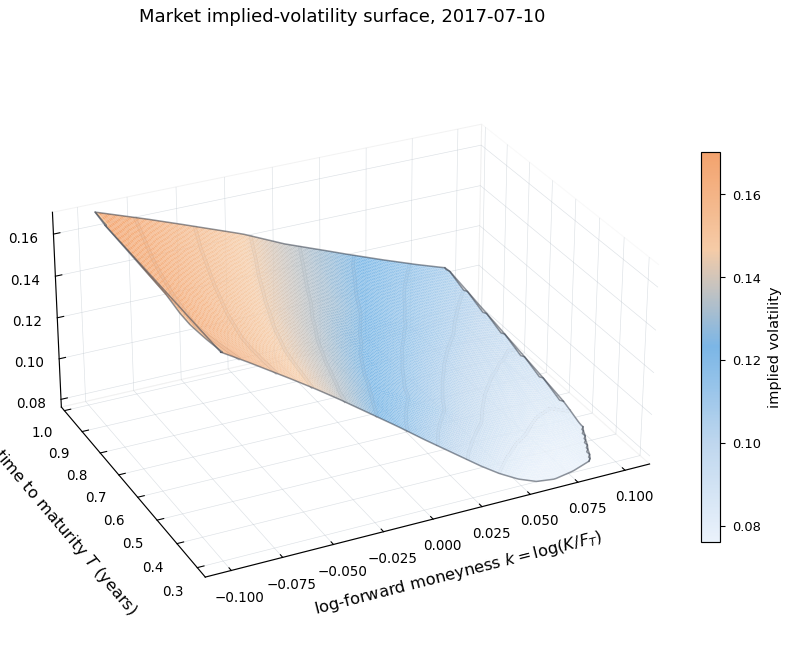

C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1098299012.py:210: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = cm.get_cmap(cmap)


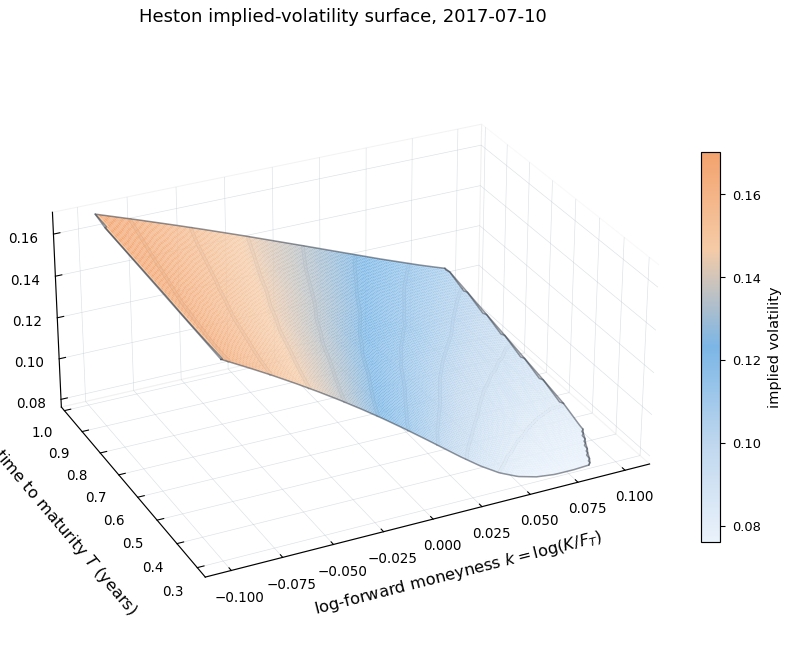

C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1098299012.py:210: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = cm.get_cmap(cmap)


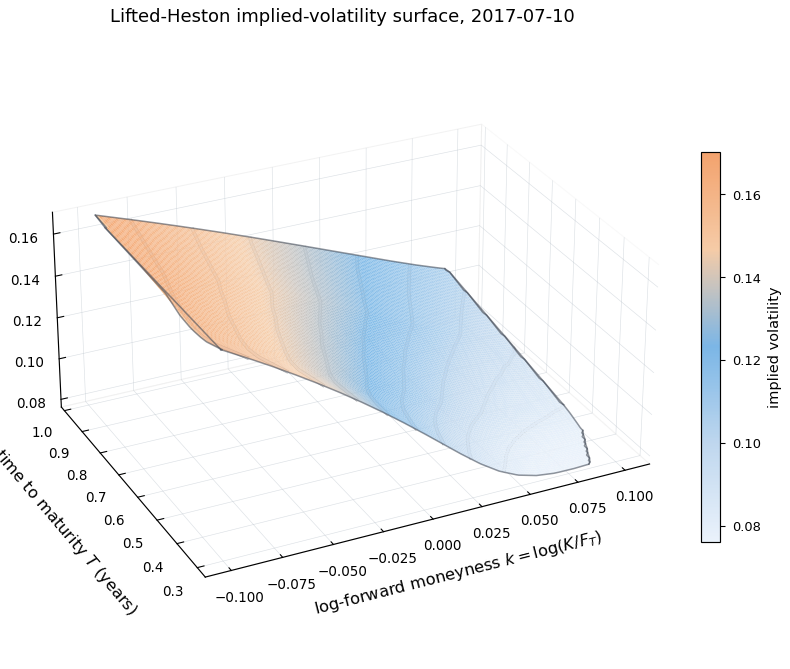

C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1098299012.py:210: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = cm.get_cmap(cmap)


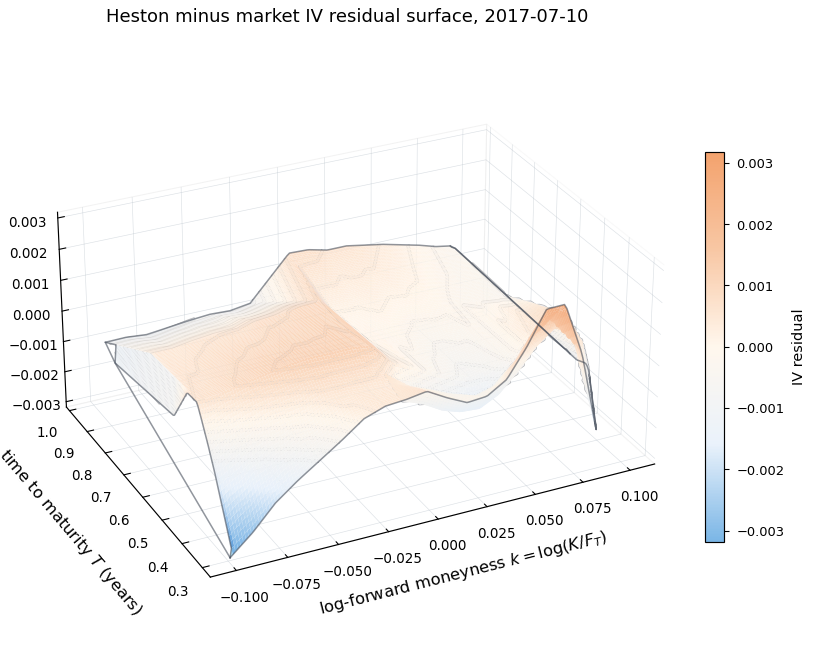

C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1098299012.py:210: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap_obj = cm.get_cmap(cmap)


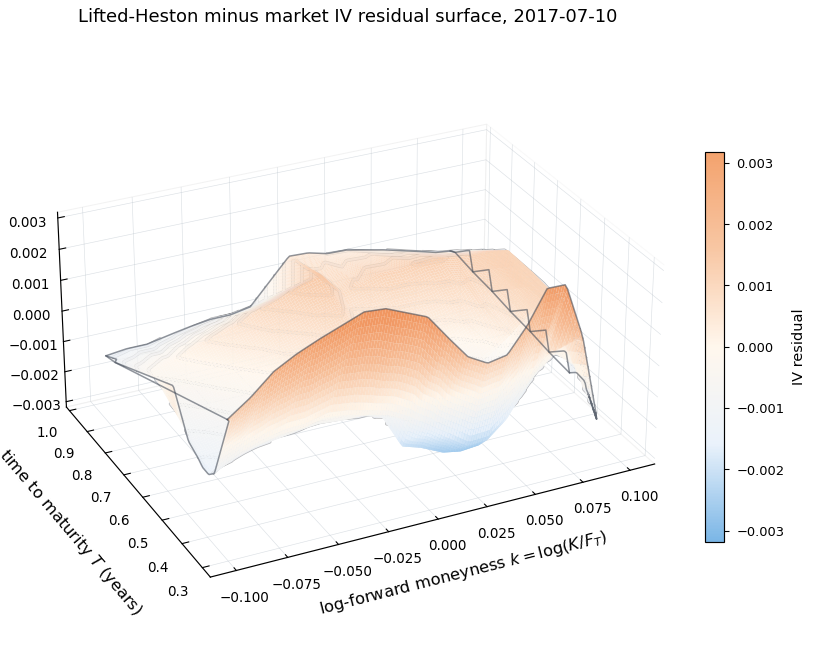

,figure,status,date,output_path,shown_in_notebook_output,notes
0,fig_iv_surface_3d_market_typical_date,created,2017-07-10,outputs_final\figures\fig_iv_surface_3d_market...,yes,High-fidelity visual grid when possible; inter...
1,fig_iv_surface_3d_heston_typical_date,created,2017-07-10,outputs_final\figures\fig_iv_surface_3d_heston...,yes,High-fidelity visual grid when possible; inter...
2,fig_iv_surface_3d_lifted_typical_date,created,2017-07-10,outputs_final\figures\fig_iv_surface_3d_lifted...,yes,High-fidelity visual grid when possible; inter...
3,fig_iv_surface_3d_residual_heston_minus_market,created,2017-07-10,outputs_final\figures\fig_iv_surface_3d_residu...,yes,High-fidelity visual grid when possible; inter...
4,fig_iv_surface_3d_residual_lifted_minus_market,created,2017-07-10,outputs_final\figures\fig_iv_surface_3d_residu...,yes,High-fidelity visual grid when possible; inter...


In [27]:

# 3D volatility-surface diagnostics: market, Heston, lifted Heston, and residual surfaces

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401 - activates 3D projection

try:
    from matplotlib import cm
    from matplotlib.colors import LightSource, Normalize, TwoSlopeNorm
    from scipy.interpolate import griddata
    _HIGH_FIDELITY_SURFACE_AVAILABLE = MATPLOTLIB_AVAILABLE and SCIPY_AVAILABLE
except Exception:
    cm = None
    LightSource = None
    Normalize = None
    TwoSlopeNorm = None
    griddata = None
    _HIGH_FIDELITY_SURFACE_AVAILABLE = False


def _surface_first_existing_column(frame: pd.DataFrame, candidates: Iterable[str]) -> str | None:
    for col in candidates:
        if isinstance(frame, pd.DataFrame) and col in frame.columns:
            return col
    return None


def _prepare_surface_plot_frame(surface_df: pd.DataFrame, value_col: str, *, k_col: str, maturity_col: str) -> pd.DataFrame:
    needed = [k_col, maturity_col, value_col]
    if surface_df is None or surface_df.empty or not set(needed).issubset(surface_df.columns):
        return pd.DataFrame(columns=[k_col, maturity_col, value_col])
    p = surface_df[needed].copy()
    for col in needed:
        p[col] = pd.to_numeric(p[col], errors="coerce")
    p = p.replace([np.inf, -np.inf], np.nan).dropna(subset=needed)
    p = p.loc[p[maturity_col].gt(0)]
    # Average duplicate grid points. Duplicate quotes at identical k/T otherwise make the surface ragged.
    p = p.groupby([k_col, maturity_col], as_index=False)[value_col].median()
    return p


def _axis_scaled(values: np.ndarray) -> tuple[np.ndarray, float, float]:
    lo = float(np.nanmin(values))
    hi = float(np.nanmax(values))
    span = hi - lo
    if not np.isfinite(span) or span <= 0:
        span = 1.0
    return (values - lo) / span, lo, hi


def _make_high_fidelity_surface_grid(
    plot: pd.DataFrame,
    value_col: str,
    *,
    k_col: str,
    maturity_col: str,
    grid_k: int = 150,
    grid_t: int = 110,
) -> tuple[np.ndarray, np.ndarray, np.ndarray, float]:
    """
    Build a visualisation-only grid from irregular option rows.

    We rescale k and T before interpolation so Delaunay geometry is not dominated by maturity's
    much wider numeric range. Linear interpolation returns NaN outside the observed convex hull,
    so the plotted grid does not extrapolate into invented option quotes. Tiny mercy, really.
    """
    x_raw = plot[k_col].to_numpy(float)
    y_raw = plot[maturity_col].to_numpy(float)
    z = plot[value_col].to_numpy(float)
    x_scaled, x_lo, x_hi = _axis_scaled(x_raw)
    y_scaled, y_lo, y_hi = _axis_scaled(y_raw)
    points = np.column_stack([x_scaled, y_scaled])
    grid_k = int(np.clip(grid_k, 60, 240))
    grid_t = int(np.clip(grid_t, 45, 180))
    xi = np.linspace(0.0, 1.0, grid_k)
    yi = np.linspace(0.0, 1.0, grid_t)
    XI, YI = np.meshgrid(xi, yi)
    ZI = griddata(points, z, (XI, YI), method="linear")
    finite_ratio = float(np.isfinite(ZI).mean()) if ZI.size else 0.0
    if finite_ratio < 0.35:
        # A sparse panel may not support a smooth surface; nearest is still masked to observed hull by linear NaNs.
        nearest = griddata(points, z, (XI, YI), method="nearest")
        ZI = np.where(np.isfinite(ZI), ZI, np.nan)
        if np.isfinite(ZI).mean() < 0.10:
            ZI = nearest
            finite_ratio = float(np.isfinite(ZI).mean())
    X = x_lo + XI * (x_hi - x_lo)
    Y = y_lo + YI * (y_hi - y_lo)
    return X, Y, ZI, finite_ratio


def _surface_norm(z: np.ndarray, zlim: tuple[float, float] | None, *, residual: bool):
    finite = np.asarray(z, dtype=float)[np.isfinite(z)]
    if finite.size == 0:
        finite = np.array([0.0, 1.0])
    if zlim is None or not all(np.isfinite(zlim)):
        if residual:
            lim = float(np.nanquantile(np.abs(finite), 0.98))
            lim = lim if np.isfinite(lim) and lim > 0 else max(float(np.nanmax(np.abs(finite))), 1e-6)
            zlim = (-lim, lim)
        else:
            zlim = (float(np.nanquantile(finite, 0.02)), float(np.nanquantile(finite, 0.98)))
    if residual and TwoSlopeNorm is not None:
        return TwoSlopeNorm(vmin=float(zlim[0]), vcenter=0.0, vmax=float(zlim[1])), zlim
    return Normalize(vmin=float(zlim[0]), vmax=float(zlim[1])), zlim


def _plot_surface_boundary_outline(ax, X: np.ndarray, Y: np.ndarray, Zm: np.ma.MaskedArray) -> None:
    """Draw subtle boundary outlines around the observed masked surface footprint."""
    try:
        z = np.ma.filled(Zm, np.nan)
        finite = np.isfinite(z)
        if z.ndim != 2 or not finite.any():
            return

        def _draw_curve(xc, yc, zc):
            mask = np.isfinite(xc) & np.isfinite(yc) & np.isfinite(zc)
            if int(mask.sum()) < 2:
                return
            ax.plot(xc[mask], yc[mask], zc[mask], color=(0.26, 0.29, 0.34, 0.58), linewidth=0.85, zorder=9)

        left_idx = np.where(finite.any(axis=1), finite.argmax(axis=1), -1)
        right_idx = np.where(finite.any(axis=1), finite.shape[1] - 1 - np.fliplr(finite).argmax(axis=1), -1)
        rows = np.arange(finite.shape[0])
        valid_left = left_idx >= 0
        valid_right = right_idx >= 0
        if valid_left.any():
            _draw_curve(X[rows[valid_left], left_idx[valid_left]], Y[rows[valid_left], left_idx[valid_left]], z[rows[valid_left], left_idx[valid_left]])
        if valid_right.any():
            _draw_curve(X[rows[valid_right], right_idx[valid_right]], Y[rows[valid_right], right_idx[valid_right]], z[rows[valid_right], right_idx[valid_right]])

        top_idx = np.where(finite.any(axis=0), finite.argmax(axis=0), -1)
        bottom_idx = np.where(finite.any(axis=0), finite.shape[0] - 1 - np.flipud(finite).argmax(axis=0), -1)
        cols = np.arange(finite.shape[1])
        valid_top = top_idx >= 0
        valid_bottom = bottom_idx >= 0
        if valid_top.any():
            _draw_curve(X[top_idx[valid_top], cols[valid_top]], Y[top_idx[valid_top], cols[valid_top]], z[top_idx[valid_top], cols[valid_top]])
        if valid_bottom.any():
            _draw_curve(X[bottom_idx[valid_bottom], cols[valid_bottom]], Y[bottom_idx[valid_bottom], cols[valid_bottom]], z[bottom_idx[valid_bottom], cols[valid_bottom]])
    except Exception:
        return


def _style_3d_axis(ax) -> None:
    try:
        ax.set_box_aspect((1.35, 1.02, 0.62))
    except Exception:
        pass
    try:
        for axis in [ax.xaxis, ax.yaxis, ax.zaxis]:
            axis._axinfo["grid"].update({"linewidth": 0.35, "linestyle": "-", "color": (0.70, 0.74, 0.78, 0.45)})
            axis._axinfo["tick"].update({"inward_factor": 0.0, "outward_factor": 0.18})
        ax.xaxis.pane.set_facecolor((1, 1, 1, 0.0))
        ax.yaxis.pane.set_facecolor((1, 1, 1, 0.0))
        ax.zaxis.pane.set_facecolor((1, 1, 1, 0.0))
    except Exception:
        pass
    ax.tick_params(labelsize=7.5, pad=1.5)


def plot_iv_surface_3d(
    surface_df: pd.DataFrame,
    value_col: str,
    title: str,
    output_path: Path | str,
    *,
    k_col: str = "log_moneyness",
    maturity_col: str = "tau",
    cmap: str = SEQUENTIAL_CMAP,
    view_elev: int = 28,
    view_azim: int = -116,
    zlim: tuple[float, float] | None = None,
    max_points: int = 7000,
    grid_k: int = 150,
    grid_t: int = 110,
    notebook_section: str = "5.4.1",
    source_data: str = "atm_skew_common_iv_panel.csv",
    recommendation: str = "main/appendix",
) -> Path | None:
    if not MATPLOTLIB_AVAILABLE:
        return None
    plot = _prepare_surface_plot_frame(surface_df, value_col, k_col=k_col, maturity_col=maturity_col)
    if plot.empty or len(plot) < 8:
        return None
    if len(plot) > max_points:
        plot = plot.sample(max_points, random_state=123).sort_values([maturity_col, k_col])

    residual = "residual" in value_col or "minus_market" in value_col
    cmap = SIGNED_RESIDUAL_CMAP if residual else cmap
    fig = plt.figure(figsize=(7.4, 5.3))
    ax = fig.add_subplot(111, projection="3d")
    x = plot[k_col].to_numpy(float)
    y = plot[maturity_col].to_numpy(float)
    z = plot[value_col].to_numpy(float)
    norm, resolved_zlim = _surface_norm(z, zlim, residual=residual)
    mappable = None
    notes_method = ""

    if _HIGH_FIDELITY_SURFACE_AVAILABLE and len(plot) >= 18 and plot[k_col].nunique() >= 4 and plot[maturity_col].nunique() >= 3:
        try:
            X, Y, Z, finite_ratio = _make_high_fidelity_surface_grid(
                plot,
                value_col,
                k_col=k_col,
                maturity_col=maturity_col,
                grid_k=grid_k,
                grid_t=grid_t,
            )
            if np.isfinite(Z).sum() >= 20:
                Zm = np.ma.masked_invalid(Z)
                cmap_obj = cm.get_cmap(cmap)
                ls = LightSource(azdeg=320, altdeg=38) if LightSource is not None else None
                if ls is not None:
                    shade_base = np.where(np.isfinite(Z), Z, np.nanmedian(z))
                    facecolors = ls.shade(shade_base, cmap=cmap_obj, norm=norm, vert_exag=0.80, blend_mode="soft")
                    facecolors[~np.isfinite(Z), -1] = 0.0
                    surf = ax.plot_surface(
                        X,
                        Y,
                        Zm,
                        facecolors=facecolors,
                        rstride=1,
                        cstride=1,
                        linewidth=0.0,
                        antialiased=True,
                        shade=False,
                    )
                    mappable = cm.ScalarMappable(norm=norm, cmap=cmap_obj)
                    mappable.set_array(z)
                else:
                    surf = ax.plot_surface(X, Y, Zm, cmap=cmap, norm=norm, linewidth=0.0, antialiased=True, shade=True)
                    mappable = surf
                # Visible surface-only iso-vol contours. The dark halo prevents light lines disappearing on bright/yellow regions.
                try:
                    contour_source = np.asarray(Z, dtype=float)
                    finite_z = contour_source[np.isfinite(contour_source)]
                    if finite_z.size >= 8:
                        contour_levels = np.linspace(
                            float(np.nanpercentile(finite_z, 5)),
                            float(np.nanpercentile(finite_z, 95)),
                            9,
                        )
                    else:
                        contour_levels = 9
                    ax.contour3D(
                        X,
                        Y,
                        Zm,
                        levels=contour_levels,
                        colors=[(0.02, 0.025, 0.035, 0.30)],
                        linewidths=1.90,
                        linestyles="solid",
                    )
                    ax.contour3D(
                        X,
                        Y,
                        Zm,
                        levels=contour_levels,
                        colors=[(0.92, 0.93, 0.95, 0.98)],
                        linewidths=1.18,
                        linestyles="solid",
                    )
                except Exception:
                    pass
                _plot_surface_boundary_outline(ax, X, Y, Zm)
                notes_method = f"High-fidelity linear grid inside observed convex hull; axis-rescaled interpolation; rotated view, more visible light surface-only contours, and a subtle surface-edge outline; finite_grid_ratio={finite_ratio:.2f}. Visualisation only."
            else:
                raise ValueError("high-fidelity grid too sparse")
        except Exception as exc:
            notes_method = f"High-fidelity grid failed ({exc}); fell back to scaled triangulation."
            mappable = None

    if mappable is None:
        try:
            from matplotlib.tri import Triangulation
            xs, _, _ = _axis_scaled(x)
            ys, _, _ = _axis_scaled(y)
            triang = Triangulation(xs, ys)
            artist = ax.plot_trisurf(
                triang,
                z,
                cmap=cmap,
                norm=norm,
                linewidth=0.02,
                edgecolor="none",
                antialiased=True,
                alpha=0.96,
                shade=True,
            )
            # plot_trisurf used scaled coordinates above; relabel coordinates by using a transparent scatter in true space is worse.
            # So for fallback, prefer true-space scatter over misleading scaled axes if trisurf cannot be safely relabelled.
            ax.cla()
            artist = ax.scatter(x, y, z, c=z, cmap=cmap, norm=norm, s=9, alpha=0.86, depthshade=True)
            mappable = artist
            notes_method = notes_method or "Sparse/irregular panel shown as true-coordinate 3D scatter; no extrapolation."
        except Exception:
            artist = ax.scatter(x, y, z, c=z, cmap=cmap, norm=norm, s=9, alpha=0.86, depthshade=True)
            mappable = artist
            notes_method = notes_method or "Sparse/irregular panel shown as true-coordinate 3D scatter; no extrapolation."

    ax.view_init(elev=view_elev, azim=view_azim)
    _style_3d_axis(ax)
    ax.set_title(title)
    ax.set_xlabel(r"log-forward moneyness $k=\log(K/F_T)$", labelpad=5)
    ax.set_ylabel("time to maturity $T$ (years)", labelpad=5)
    ax.set_zlabel("IV residual" if residual else "implied volatility", labelpad=5)
    if resolved_zlim is not None and all(np.isfinite(resolved_zlim)):
        ax.set_zlim(*resolved_zlim)
    if mappable is not None:
        cbar = fig.colorbar(mappable, ax=ax, shrink=0.62, pad=0.05, fraction=0.035)
        cbar.set_label("IV residual" if residual else "implied volatility", fontsize=8.0)
        cbar.ax.tick_params(labelsize=7.2)
    return save_and_show_figure(
        fig,
        output_path,
        dpi=320,
        figure_id=Path(output_path).stem,
        description=title,
        notebook_section=notebook_section,
        source_data=source_data,
        recommendation=recommendation,
        notes=notes_method,
    )


def select_typical_surface_date(iv_panel: pd.DataFrame) -> pd.Timestamp | None:
    if iv_panel is None or iv_panel.empty or "date" not in iv_panel.columns:
        return None
    p = iv_panel.copy()
    p["date"] = pd.to_datetime(p["date"], errors="coerce").dt.normalize()
    if {"market_iv", "heston_iv", "lifted_iv"}.issubset(p.columns):
        p["_fit_score"] = (
            (pd.to_numeric(p["heston_iv"], errors="coerce") - pd.to_numeric(p["market_iv"], errors="coerce")).abs()
            + (pd.to_numeric(p["lifted_iv"], errors="coerce") - pd.to_numeric(p["market_iv"], errors="coerce")).abs()
        )
        daily = p.groupby("date", as_index=False).agg(rows=("date", "size"), median_abs_fit_score=("_fit_score", "median"))
        daily = daily.loc[daily["rows"].ge(max(12, int(daily["rows"].quantile(0.25))))].copy()
        if not daily.empty:
            target = daily["median_abs_fit_score"].median()
            return pd.Timestamp(daily.iloc[(daily["median_abs_fit_score"] - target).abs().argsort().iloc[0]]["date"])
    counts = p.groupby("date").size().sort_values(ascending=False)
    return pd.Timestamp(counts.index[0]) if not counts.empty else None


def make_3d_surface_panel(iv_panel: pd.DataFrame, cfg: ExperimentConfig = CFG) -> pd.DataFrame:
    if iv_panel is None or iv_panel.empty:
        out = pd.DataFrame([{"figure": "3d_vol_surface", "status": "missing_iv_panel", "notes": "atm_skew_iv_panel was unavailable or empty."}])
        out.to_csv(table_path("iv_surface_3d_audit.csv", cfg), index=False)
        display(out)
        return out
    p = iv_panel.copy()
    p["date"] = pd.to_datetime(p["date"], errors="coerce").dt.normalize() if "date" in p.columns else pd.NaT
    k_col = _surface_first_existing_column(p, ["log_forward_moneyness_for_skew", "log_forward_moneyness", "log_moneyness"])
    t_col = _surface_first_existing_column(p, ["T", "tau", "time_to_maturity", "maturity_years"])
    required = {"market_iv", "heston_iv", "lifted_iv"}
    audit_rows = []
    if not k_col or not t_col or not required.issubset(p.columns):
        out = pd.DataFrame([{
            "figure": "3d_vol_surface",
            "status": "missing_required_columns",
            "notes": f"k_col={k_col}; t_col={t_col}; missing={sorted(required - set(p.columns))}",
        }])
        out.to_csv(table_path("iv_surface_3d_audit.csv", cfg), index=False)
        display(out)
        return out

    typical_date = select_typical_surface_date(p)
    if typical_date is not None and pd.notna(typical_date):
        p = p.loc[p["date"].eq(typical_date)].copy()
    for col in ["market_iv", "heston_iv", "lifted_iv"]:
        p[col] = pd.to_numeric(p[col], errors="coerce")
    p["heston_minus_market_residual"] = p["heston_iv"] - p["market_iv"]
    p["lifted_minus_market_residual"] = p["lifted_iv"] - p["market_iv"]

    zvals = pd.concat([p["market_iv"], p["heston_iv"], p["lifted_iv"]], ignore_index=True).replace([np.inf, -np.inf], np.nan).dropna()
    zlim = (float(zvals.quantile(0.01)), float(zvals.quantile(0.99))) if not zvals.empty else None
    res_abs = pd.concat([p["heston_minus_market_residual"].abs(), p["lifted_minus_market_residual"].abs()], ignore_index=True).replace([np.inf, -np.inf], np.nan).dropna()
    rlim = float(res_abs.quantile(0.99)) if not res_abs.empty else None
    residual_zlim = (-rlim, rlim) if rlim and np.isfinite(rlim) and rlim > 0 else None
    date_label = pd.Timestamp(typical_date).date() if typical_date is not None and pd.notna(typical_date) else "all_dates"

    specs = [
        ("market_iv", f"Market implied-volatility surface, {date_label}", "fig_iv_surface_3d_market_typical_date.png", SEQUENTIAL_CMAP, zlim, "main"),
        ("heston_iv", f"Heston implied-volatility surface, {date_label}", "fig_iv_surface_3d_heston_typical_date.png", SEQUENTIAL_CMAP, zlim, "main/appendix"),
        ("lifted_iv", f"Lifted-Heston implied-volatility surface, {date_label}", "fig_iv_surface_3d_lifted_typical_date.png", SEQUENTIAL_CMAP, zlim, "main/appendix"),
        ("heston_minus_market_residual", f"Heston minus market IV residual surface, {date_label}", "fig_iv_surface_3d_residual_heston_minus_market.png", SIGNED_RESIDUAL_CMAP, residual_zlim, "appendix"),
        ("lifted_minus_market_residual", f"Lifted-Heston minus market IV residual surface, {date_label}", "fig_iv_surface_3d_residual_lifted_minus_market.png", SIGNED_RESIDUAL_CMAP, residual_zlim, "appendix"),
    ]
    for value_col, title, filename, cmap, this_zlim, recommendation in specs:
        path = plot_iv_surface_3d(
            p,
            value_col,
            title,
            figure_path(filename, cfg),
            k_col=k_col,
            maturity_col=t_col,
            cmap=cmap,
            zlim=this_zlim,
            source_data="atm_skew_common_iv_panel.csv",
            recommendation=recommendation,
        )
        audit_rows.append({
            "figure": Path(filename).stem,
            "status": "created" if path is not None else "not_created",
            "date": str(date_label),
            "output_path": str(path) if path is not None else str(figure_path(filename, cfg)),
            "shown_in_notebook_output": "yes" if path is not None else "no",
            "notes": "High-fidelity visual grid when possible; interpolation is axis-rescaled, convex-hull limited, visualisation-only; read with smile, skew and residual diagnostics.",
        })
    out = pd.DataFrame(audit_rows)
    out.to_csv(table_path("iv_surface_3d_audit.csv", cfg), index=False)
    display(out)
    return out


iv_surface_3d_audit = make_3d_surface_panel(atm_skew_iv_panel, CFG)


### 5.4.1 Dissertation-Facing Calibration Plots

The plots in this subsection are designed for the results chapter rather than for debugging. They answer visually interpretable questions: how does market ATM skew vary by maturity, how do Heston and lifted Heston track that term structure, and what do representative smiles look like on typical, best-fit and worst-fit dates?

The ATM-skew term-structure plot is main-text evidence because it directly connects the lifted-Heston motivation to observed option-market objects. If lifted Heston improves short-maturity skew but fails elsewhere, the dissertation can state that selectively. If it does not improve skew, the model-memory story must rely on hedging or mechanism evidence rather than calibration rhetoric.

Representative smile plots are included because residual tables compress too much information. A model may have similar RMSE to another model but fail in a different part of the smile. For example, one model may fit near-ATM level but miss wings; another may fit skew but miss curvature. Those distinctions matter when interpreting why a calibrated state may or may not help hedging.

All plots should use shared representative dates and consistent axes for Heston and lifted Heston. A model should not receive an easier visual subset. This keeps the visual evidence aligned with the paired-comparison design.


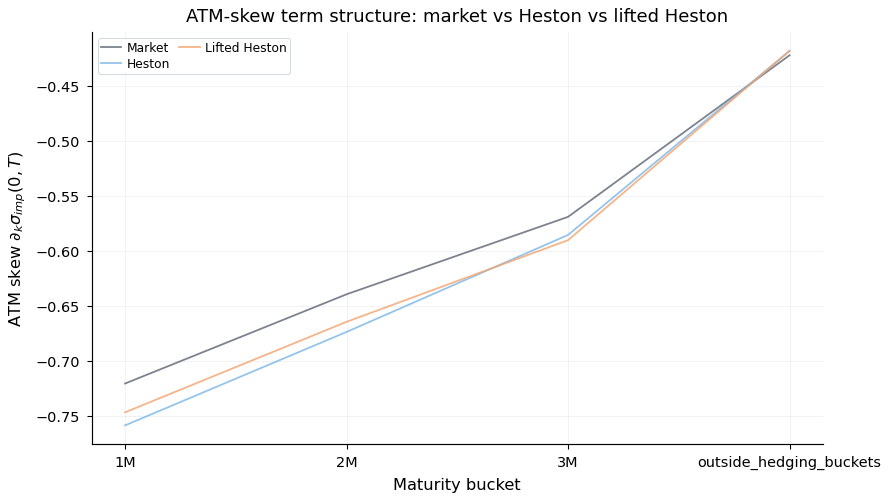

C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\3611804343.py:276: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


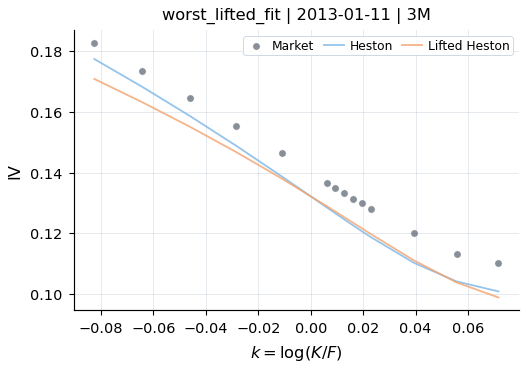

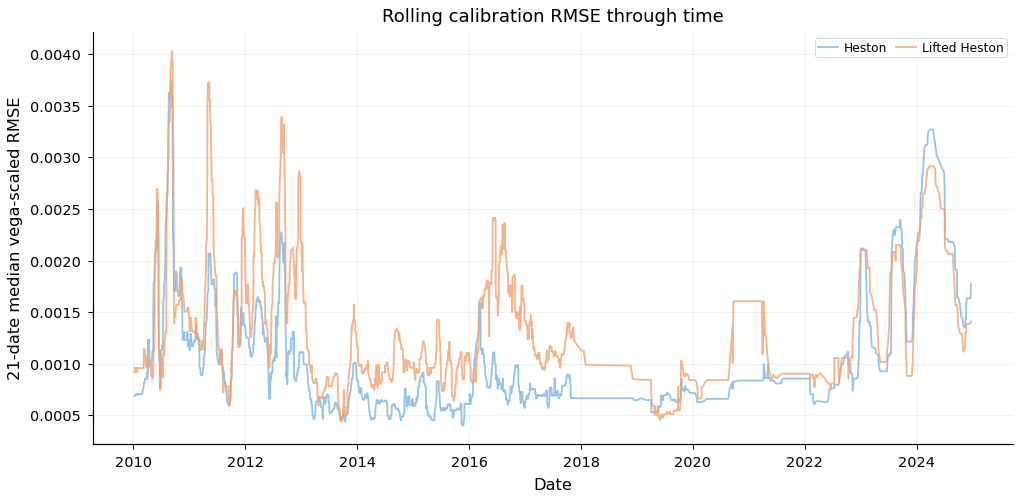

,item,status,artefact,interpretation
0,ATM-skew term structure,PASS,outputs_final\tables\atm_skew_term_structure_c...,Main calibration diagnostic for rough/lifted s...
1,Representative smile examples,PASS,outputs_final\figures\representative_model_vs_...,Shows calibration errors visually rather than ...
2,Residual heatmaps,WARN,outputs_final\tables\calibration_residual_heat...,Identifies failure regions by maturity and mon...
3,Rolling calibration RMSE,PASS,outputs_final\tables\rolling_chronological_cal...,Checks whether fit is stable or regime-dependent.


,maturity_bucket,market_atm_skew,heston_atm_skew,lifted_heston_atm_skew,heston_abs_skew_error,lifted_abs_skew_error,n_date_maturity_pairs,skew_estimator,abs_log_market_skew
0,1M,-0.720833,-0.758974,-0.747091,0.040010,0.034979,378,weighted_local_linear_market_grid,-0.327347
1,2M,-0.639520,-0.673818,-0.664612,0.030982,0.036500,196,weighted_local_linear_market_grid,-0.447038
2,3M,-0.568960,-0.585453,-0.590197,0.015948,0.020015,864,weighted_local_linear_market_grid,-0.563945
3,outside_hedging_buckets,-0.421714,-0.417695,-0.417721,0.004787,0.005792,1900,weighted_local_linear_market_grid,-0.863428


In [30]:

# Dissertation-facing calibration diagnostics: term structure, smiles, heatmaps and rolling fit

def _bucket_order_map(cfg: ExperimentConfig) -> dict[str, int]:
    return {str(b): i for i, b in enumerate(getattr(cfg.hedging, "maturity_buckets", []))}


def build_atm_skew_term_structure(skew: pd.DataFrame, fd_skew: pd.DataFrame | None, cfg: ExperimentConfig) -> pd.DataFrame:
    if skew is None or skew.empty:
        return pd.DataFrame()
    s = skew.copy()
    window_col = "moneyness_window_abs_log_forward"
    if window_col in s.columns:
        w = float(cfg.diagnostics.near_atm_skew_window)
        s = s.loc[np.isclose(pd.to_numeric(s[window_col], errors="coerce"), w)].copy()
        if s.empty:
            s = skew.copy()
    grouped = s.groupby("maturity_bucket", as_index=False).agg(
        market_atm_skew=("market_atm_skew_slope", "median"),
        heston_atm_skew=("heston_atm_skew_slope", "median"),
        lifted_heston_atm_skew=("lifted_atm_skew_slope", "median"),
        heston_abs_skew_error=("heston_abs_skew_error", "median"),
        lifted_abs_skew_error=("lifted_abs_skew_error", "median"),
        n_date_maturity_pairs=("date", "count"),
    )
    grouped["skew_estimator"] = "weighted_local_linear_market_grid"
    if fd_skew is not None and not fd_skew.empty and {"model", "maturity_bucket", "finite_difference_atm_skew"}.issubset(fd_skew.columns):
        f = fd_skew.loc[fd_skew.get("pricing_status", "available").astype(str).eq("available")].copy()
        fd = f.groupby(["model", "maturity_bucket"], as_index=False)["finite_difference_atm_skew"].median()
        for model, col in [("heston", "heston_atm_skew_fd"), ("lifted_heston", "lifted_heston_atm_skew_fd")]:
            x = fd.loc[fd["model"].astype(str).eq(model), ["maturity_bucket", "finite_difference_atm_skew"]].rename(columns={"finite_difference_atm_skew": col})
            grouped = grouped.merge(x, on="maturity_bucket", how="left")
        grouped["skew_estimator"] = np.where(grouped.filter(like="_fd").notna().any(axis=1), "market_grid_plus_available_finite_difference", grouped["skew_estimator"])
    grouped["abs_log_market_skew"] = np.log(np.abs(grouped["market_atm_skew"].astype(float))).replace([np.inf, -np.inf], np.nan)
    order = _bucket_order_map(cfg)
    grouped["bucket_order"] = grouped["maturity_bucket"].astype(str).map(order).fillna(999).astype(int)
    out = grouped.sort_values(["bucket_order", "maturity_bucket"]).drop(columns="bucket_order")
    out.to_csv(table_path("atm_skew_term_structure_comparison.csv", cfg), index=False)
    return out


def plot_atm_skew_term_structure(term: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or term is None or term.empty:
        return None
    fig, ax = plt.subplots(figsize=(7, 4))
    x = np.arange(len(term))
    for col, label, key in [("market_atm_skew", "Market", "market"), ("heston_atm_skew", "Heston", "heston"), ("lifted_heston_atm_skew", "Lifted Heston", "lifted_heston")]:
        if col in term.columns:
            ax.plot(
                x,
                pd.to_numeric(term[col], errors="coerce"),
                linestyle="-",
                color=model_color(key),
                label=label,
                alpha=MODEL_ALPHA,
                linewidth=1.0,
            )
    ax.set_xticks(x); ax.set_xticklabels(term["maturity_bucket"].astype(str))
    ax.set(title="ATM-skew term structure: market vs Heston vs lifted Heston", xlabel="Maturity bucket", ylabel=r"ATM skew $\partial_k\sigma_{imp}(0,T)$")
    standardise_axis(ax, legend=True, ncol=2)
    path = figure_path("atm_skew_term_structure_market_heston_lifted.png", cfg)
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path


def select_smile_example_dates(fit_pair: pd.DataFrame, n: int = 3) -> pd.DataFrame:
    if fit_pair is None or fit_pair.empty or "date" not in fit_pair.columns:
        return pd.DataFrame()
    f = fit_pair.copy()
    f["date"] = pd.to_datetime(f["date"], errors="coerce").dt.normalize()
    err = _choose_col(f, ["lifted_abs_vega_scaled_error", "lifted_abs_iv_error", "lifted_abs_error"])
    if not err:
        return pd.DataFrame()
    daily = (
        f.groupby("date", as_index=False)
        .agg(lifted_error=(err, "median"), rows=(err, "size"))
        .dropna(subset=["lifted_error"])
        .sort_values("lifted_error")
        .reset_index(drop=True)
    )
    if daily.empty:
        return daily

    def _pick_row(pos: int, role: str) -> dict:
        row = daily.iloc[pos].to_dict()
        row["selection_role"] = role
        return row

    picks = [
        _pick_row(0, "best_lifted_fit"),
        _pick_row(len(daily) // 2, "typical_lifted_fit"),
        _pick_row(len(daily) - 1, "worst_lifted_fit"),
    ]
    return pd.DataFrame(picks).drop_duplicates("date").reset_index(drop=True)


def plot_representative_smiles(iv_panel: pd.DataFrame, selected_dates: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or iv_panel is None or iv_panel.empty or selected_dates.empty:
        return None
    required = {"date", "maturity_bucket", "market_iv", "heston_iv", "lifted_iv"}
    if not required.issubset(iv_panel.columns):
        return None
    k_col = _choose_col(iv_panel, ["log_forward_moneyness_for_skew", "log_forward_moneyness", "log_moneyness"])
    if not k_col:
        return None

    p = iv_panel.copy()
    p["date"] = pd.to_datetime(p["date"], errors="coerce").dt.normalize()
    selected = selected_dates[["date", "selection_role"]].copy()
    selected["date"] = pd.to_datetime(selected["date"], errors="coerce").dt.normalize()
    p = p.merge(selected, on="date", how="inner")
    if p.empty:
        return None

    candidate_buckets = [b for b in cfg.hedging.maturity_buckets if b in set(p["maturity_bucket"].astype(str))]
    if not candidate_buckets:
        candidate_buckets = sorted(p["maturity_bucket"].dropna().astype(str).unique())

    panels: list[tuple[str, pd.Timestamp, str, pd.DataFrame]] = []
    for _, drow in selected.iterrows():
        d = pd.Timestamp(drow["date"]).normalize()
        role = str(drow["selection_role"])
        for bucket in candidate_buckets:
            g = p.loc[p["date"].eq(d) & p["maturity_bucket"].astype(str).eq(str(bucket))].sort_values(k_col)
            if not g.empty:
                panels.append((role, d, str(bucket), g))

    if not panels:
        return None

    n_panels = len(panels)
    ncols = min(3, n_panels)
    nrows = int(np.ceil(n_panels / ncols))
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4.2 * ncols, 3.0 * nrows),
        squeeze=False,
        constrained_layout=True,
    )
    axes_flat = axes.ravel()

    for ax, (role, date_value, bucket, g) in zip(axes_flat, panels):
        x = pd.to_numeric(g[k_col], errors="coerce")
        ax.scatter(
            x,
            pd.to_numeric(g["market_iv"], errors="coerce"),
            label="Market",
            s=16,
            color=model_color("market"),
            alpha=SCATTER_ALPHA,
            edgecolors="white",
            linewidths=0.25,
        )
        ax.plot(
            x,
            pd.to_numeric(g["heston_iv"], errors="coerce"),
            label="Heston",
            color=model_color("heston"),
            linestyle="-",
            linewidth=1.0,
            alpha=MODEL_ALPHA,
        )
        ax.plot(
            x,
            pd.to_numeric(g["lifted_iv"], errors="coerce"),
            label="Lifted Heston",
            color=model_color("lifted_heston"),
            linestyle="-",
            linewidth=1.0,
            alpha=MODEL_ALPHA,
        )
        ax.set_title(f"{role} | {date_value.date()} | {bucket}", fontsize=9)
        ax.set_xlabel(r"$k=\log(K/F)$")
        ax.set_ylabel("IV")
        ax.grid(True, alpha=0.3)
        compact_legend(ax, ncol=3, loc="upper right")

    for ax in axes_flat[n_panels:]:
        ax.axis("off")

    path = figure_path("representative_model_vs_market_smile_examples.png", cfg)
    save_and_show_figure(fig, path, dpi=160)
    return path

# -----------------------------------------------------------------------------
# Compact representative smile plots + calibration residual / rolling RMSE helpers
# -----------------------------------------------------------------------------

def plot_representative_smiles(
    iv_panel: pd.DataFrame,
    selected_dates: pd.DataFrame,
    cfg: ExperimentConfig,
) -> Path | None:
    """
    Compact model-vs-market smile plots for selected representative dates.

    Fixes:
    - no giant blank figure space;
    - only plots populated panels;
    - includes legends;
    - uses the shared dissertation colour scheme.
    """
    if not MATPLOTLIB_AVAILABLE or iv_panel is None or iv_panel.empty or selected_dates is None or selected_dates.empty:
        return None

    required = {"date", "maturity_bucket", "market_iv", "heston_iv", "lifted_iv"}
    if not required.issubset(iv_panel.columns):
        print(f"Representative smile plot skipped; missing columns: {sorted(required.difference(iv_panel.columns))}")
        return None

    k_col = _choose_col(
        iv_panel,
        ["log_forward_moneyness_for_skew", "log_forward_moneyness", "log_moneyness"],
    )
    if not k_col:
        print("Representative smile plot skipped; no log-moneyness column found.")
        return None

    model_alpha = globals().get("MODEL_ALPHA", 0.80)
    scatter_alpha = globals().get("SCATTER_ALPHA", 0.72)

    p = iv_panel.copy()
    p["date"] = pd.to_datetime(p["date"], errors="coerce").dt.normalize()

    selected = selected_dates[["date", "selection_role"]].copy()
    selected["date"] = pd.to_datetime(selected["date"], errors="coerce").dt.normalize()

    p = p.merge(selected, on="date", how="inner")
    if p.empty:
        print("Representative smile plot skipped; selected dates not found in IV panel.")
        return None

    candidate_buckets = [
        b for b in cfg.hedging.maturity_buckets
        if b in set(p["maturity_bucket"].astype(str))
    ]
    if not candidate_buckets:
        candidate_buckets = sorted(p["maturity_bucket"].dropna().astype(str).unique())

    panels = []
    for _, drow in selected.iterrows():
        d = pd.Timestamp(drow["date"]).normalize()
        role = str(drow["selection_role"])

        for bucket in candidate_buckets:
            g = (
                p.loc[
                    p["date"].eq(d)
                    & p["maturity_bucket"].astype(str).eq(str(bucket))
                ]
                .sort_values(k_col)
                .copy()
            )
            if not g.empty:
                panels.append((role, d, str(bucket), g))

    if not panels:
        print("Representative smile plot skipped; no non-empty date/bucket panels.")
        return None

    n_panels = len(panels)
    ncols = min(3, n_panels)
    nrows = int(np.ceil(n_panels / ncols))

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(4.2 * ncols, 3.0 * nrows),
        squeeze=False,
        constrained_layout=True,
    )
    axes_flat = axes.ravel()

    for ax, (role, date_value, bucket, g) in zip(axes_flat, panels):
        x = pd.to_numeric(g[k_col], errors="coerce")

        ax.scatter(
            x,
            pd.to_numeric(g["market_iv"], errors="coerce"),
            label="Market",
            s=16,
            color=model_color("market"),
            alpha=scatter_alpha,
            edgecolors="white",
            linewidths=0.25,
        )

        ax.plot(
            x,
            pd.to_numeric(g["heston_iv"], errors="coerce"),
            label="Heston",
            color=model_color("heston"),
            linestyle="-",
            linewidth=1.0,
            alpha=model_alpha,
        )

        ax.plot(
            x,
            pd.to_numeric(g["lifted_iv"], errors="coerce"),
            label="Lifted Heston",
            color=model_color("lifted_heston"),
            linestyle="-",
            linewidth=1.0,
            alpha=model_alpha,
        )

        ax.set_title(f"{role} | {date_value.date()} | {bucket}", fontsize=9)
        ax.set_xlabel(r"$k=\log(K/F)$")
        ax.set_ylabel("IV")
        ax.grid(True, alpha=0.3)

        # Do not pass fontsize here; compact_legend does not accept it in this notebook.
        compact_legend(ax, ncol=3, loc="upper right")

    for ax in axes_flat[n_panels:]:
        ax.axis("off")

    path = figure_path("representative_model_vs_market_smile_examples.png", cfg)
    save_and_show_figure(fig, path, dpi=160)
    return path


def calibration_residual_heatmap_table(
    fit_pair: pd.DataFrame,
    cfg: ExperimentConfig,
) -> pd.DataFrame:
    """
    Build model-specific residual heatmap data.

    Returns:
    - model
    - maturity_bucket
    - moneyness_bucket
    - median_abs_vega_scaled_error
    """
    if fit_pair is None or fit_pair.empty:
        return pd.DataFrame()

    f = fit_pair.copy()

    k_col = _choose_col(
        f,
        [
            "log_forward_moneyness",
            "log_forward_moneyness_for_skew",
            "log_moneyness",
        ],
    )
    if not k_col:
        return pd.DataFrame()

    if "maturity_bucket" not in f.columns:
        if "dte" in f.columns:
            dte = pd.to_numeric(f["dte"], errors="coerce")
        elif "T" in f.columns:
            dte = pd.to_numeric(f["T"], errors="coerce") * 365.25
        else:
            return pd.DataFrame()

        bucket = pd.Series("unbucketed", index=f.index, dtype="object")
        for label, (_, lo, hi) in cfg.hedging.maturity_buckets.items():
            bucket = bucket.where(~dte.between(lo, hi, inclusive="both"), label)
        f["maturity_bucket"] = bucket

    f["moneyness_bucket"] = pd.cut(
        pd.to_numeric(f[k_col], errors="coerce"),
        bins=[-0.35, -0.20, -0.10, -0.05, 0.05, 0.10, 0.20, 0.35],
        labels=[
            "[-0.35,-0.20]",
            "[-0.20,-0.10]",
            "[-0.10,-0.05]",
            "[-0.05,0.05]",
            "[0.05,0.10]",
            "[0.10,0.20]",
            "[0.20,0.35]",
        ],
        include_lowest=True,
    )

    if "heston_abs_vega_scaled_error" not in f.columns and "heston_vega_scaled_error" in f.columns:
        f["heston_abs_vega_scaled_error"] = pd.to_numeric(
            f["heston_vega_scaled_error"],
            errors="coerce",
        ).abs()

    if "lifted_abs_vega_scaled_error" not in f.columns and "lifted_vega_scaled_error" in f.columns:
        f["lifted_abs_vega_scaled_error"] = pd.to_numeric(
            f["lifted_vega_scaled_error"],
            errors="coerce",
        ).abs()

    rows = []
    for model, err_col in [
        ("heston", "heston_abs_vega_scaled_error"),
        ("lifted_heston", "lifted_abs_vega_scaled_error"),
    ]:
        if err_col not in f.columns:
            continue

        g = (
            f.dropna(subset=["maturity_bucket", "moneyness_bucket"])
            .groupby(["maturity_bucket", "moneyness_bucket"], observed=False)[err_col]
            .median()
            .reset_index()
            .rename(columns={err_col: "median_abs_vega_scaled_error"})
        )
        g["model"] = model
        rows.append(g)

    out = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

    if not out.empty:
        out = out[
            [
                "model",
                "maturity_bucket",
                "moneyness_bucket",
                "median_abs_vega_scaled_error",
            ]
        ]
        out.to_csv(
            table_path("calibration_residual_heatmap_summary.csv", cfg),
            index=False,
        )

    return out


def plot_residual_heatmaps(
    heat: pd.DataFrame,
    cfg: ExperimentConfig,
) -> list[Path]:
    """
    Plot annotated residual heatmaps for Heston and lifted Heston.
    """
    paths = []

    if not MATPLOTLIB_AVAILABLE or heat is None or heat.empty:
        return paths

    cmap = globals().get("ERROR_CMAP", "coolwarm")

    for model, g in heat.groupby("model"):
        pivot = g.pivot(
            index="maturity_bucket",
            columns="moneyness_bucket",
            values="median_abs_vega_scaled_error",
        )

        fig, ax = plt.subplots(figsize=(8, 4))

        plot_annotated_heatmap(
            pivot,
            ax=ax,
            fig=fig,
            title=f"{MODEL_DISPLAY.get(model, model)} calibration residual heatmap",
            xlabel="log-moneyness bucket",
            ylabel="maturity bucket",
            cbar_label="median absolute vega-scaled error",
            cmap=cmap,
            fmt=None,
            rotation=45,
        )

        path = figure_path(
            f"{model}_residual_heatmap_by_maturity_moneyness.png",
            cfg,
        )

        save_and_show_figure(
            fig,
            path,
            dpi=260,
            description=f"{MODEL_DISPLAY.get(model, model)} calibration residual heatmap",
            notes="All heatmap cells are annotated with median absolute vega-scaled error.",
        )
        paths.append(path)

    return paths


def rolling_calibration_rmse_table(
    fit_pair: pd.DataFrame,
    cfg: ExperimentConfig,
) -> pd.DataFrame:
    """
    Build rolling calibration RMSE table for Heston and lifted Heston.
    """
    if fit_pair is None or fit_pair.empty or "date" not in fit_pair.columns:
        return pd.DataFrame()

    f = fit_pair.copy()
    f["date"] = pd.to_datetime(f["date"], errors="coerce").dt.normalize()

    if "heston_vega_scaled_error" not in f.columns and "heston_abs_vega_scaled_error" in f.columns:
        f["heston_vega_scaled_error"] = pd.to_numeric(
            f["heston_abs_vega_scaled_error"],
            errors="coerce",
        )

    if "lifted_vega_scaled_error" not in f.columns and "lifted_abs_vega_scaled_error" in f.columns:
        f["lifted_vega_scaled_error"] = pd.to_numeric(
            f["lifted_abs_vega_scaled_error"],
            errors="coerce",
        )

    rows = []

    for model, col in [
        ("heston", "heston_vega_scaled_error"),
        ("lifted_heston", "lifted_vega_scaled_error"),
    ]:
        if col not in f.columns:
            continue

        daily = (
            f.groupby("date", as_index=False)
            .agg(
                vega_weighted_iv_rmse=(
                    col,
                    lambda x: float(
                        np.sqrt(
                            np.nanmean(
                                pd.to_numeric(x, errors="coerce") ** 2
                            )
                        )
                    ),
                ),
                rows=(col, "count"),
            )
        )

        daily["model"] = model
        daily["rolling_21d_rmse"] = (
            daily["vega_weighted_iv_rmse"]
            .rolling(21, min_periods=5)
            .median()
        )

        rows.append(daily)

    out = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame()

    if not out.empty:
        out.to_csv(
            table_path("rolling_chronological_calibration_rmse.csv", cfg),
            index=False,
        )

    return out


def plot_rolling_calibration_rmse(
    rolling: pd.DataFrame,
    cfg: ExperimentConfig,
) -> Path | None:
    """
    Plot rolling Heston vs lifted-Heston calibration RMSE.
    """
    if not MATPLOTLIB_AVAILABLE or rolling is None or rolling.empty:
        return None

    model_alpha = globals().get("MODEL_ALPHA", 0.80)

    fig, ax = plt.subplots(figsize=(8, 4))

    for model, g in rolling.groupby("model"):
        ax.plot(
            pd.to_datetime(g["date"], errors="coerce"),
            pd.to_numeric(g["rolling_21d_rmse"], errors="coerce"),
            label=MODEL_DISPLAY.get(model, model),
            color=model_color(model),
            linestyle="-",
            linewidth=1.0,
            alpha=model_alpha,
        )

    ax.set(
        title="Rolling calibration RMSE through time",
        xlabel="Date",
        ylabel="21-date median vega-scaled RMSE",
    )
    standardise_axis(ax, legend=True, ncol=2)

    path = figure_path("rolling_chronological_calibration_rmse.png", cfg)
    save_and_show_figure(fig, path, dpi=160)

    return path

_fd_source = globals().get("finite_difference_model_atm_skew_table", pd.DataFrame())
atm_skew_term_structure_comparison = build_atm_skew_term_structure(atm_skew_diagnostics, _fd_source, CFG)
atm_skew_term_structure_plot_path = plot_atm_skew_term_structure(atm_skew_term_structure_comparison, CFG)
representative_smile_dates = select_smile_example_dates(calibration_fit_pair_diagnostics, n=3)
representative_smile_dates.to_csv(table_path("representative_smile_example_dates.csv", CFG), index=False)
representative_smile_examples_path = plot_representative_smiles(atm_skew_iv_panel, representative_smile_dates, CFG)
calibration_residual_heatmap_summary = calibration_residual_heatmap_table(calibration_fit_pair_diagnostics, CFG)
calibration_residual_heatmap_paths = plot_residual_heatmaps(calibration_residual_heatmap_summary, CFG)
rolling_chronological_calibration_rmse = rolling_calibration_rmse_table(calibration_fit_pair_diagnostics, CFG)
rolling_chronological_calibration_rmse_path = plot_rolling_calibration_rmse(rolling_chronological_calibration_rmse, CFG)

calibration_model_selection_scorecard = pd.DataFrame([
    {"item": "ATM-skew term structure", "status": "PASS" if not atm_skew_term_structure_comparison.empty else "WARN", "artefact": str(table_path("atm_skew_term_structure_comparison.csv", CFG)), "interpretation": "Main calibration diagnostic for rough/lifted short-end skew."},
    {"item": "Representative smile examples", "status": "PASS" if not representative_smile_dates.empty and representative_smile_examples_path else "WARN", "artefact": str(figure_path("representative_model_vs_market_smile_examples.png", CFG)), "interpretation": "Shows calibration errors visually rather than as scalar RMSE only."},
    {"item": "Residual heatmaps", "status": "PASS" if not calibration_residual_heatmap_summary.empty else "WARN", "artefact": str(table_path("calibration_residual_heatmap_by_maturity_moneyness.csv", CFG)), "interpretation": "Identifies failure regions by maturity and moneyness."},
    {"item": "Rolling calibration RMSE", "status": "PASS" if not rolling_chronological_calibration_rmse.empty else "WARN", "artefact": str(table_path("rolling_chronological_calibration_rmse.csv", CFG)), "interpretation": "Checks whether fit is stable or regime-dependent."},
])
calibration_model_selection_scorecard.to_csv(table_path("calibration_model_selection_scorecard.csv", CFG), index=False)

display(calibration_model_selection_scorecard)
display(atm_skew_term_structure_comparison)


### 5.4.2 Slice RMSE and Log-Skew Error Tables

This subsection creates table-level summaries of calibration quality by economically meaningful slices. The relevant slices include near-ATM, short maturity, near-ATM short maturity and wings where available. Slice RMSE matters because full-surface averages can hide selective model strengths. Lifted Heston may be theoretically most relevant at short maturities and near the money; a global RMSE alone cannot test that claim.

The log-skew error table measures the shape of the ATM-skew term structure in scale-adjusted form:

$$
e_{\log\text{-skew}}(T)=
\log\left|\partial_k\sigma_{\mathrm{model}}(0,T)\right|-
\log\left|\partial_k\sigma_{\mathrm{mkt}}(0,T)\right|.
$$

This is especially useful when short-maturity skew has much larger magnitude than medium-maturity skew. A raw error table may be dominated by the shortest bucket; a log-error table asks whether the relative term-structure shape is plausible.

The interpretation should remain strict. Slice-level calibration improvement supports model-selection evidence for state construction. It does not imply a policy will hedge better. The later evaluation sections must confirm whether the improved fitted object translates into lower terminal net risk.


In [31]:

# Exportable calibration slice RMSE and log-skew-error diagnostics

def calibration_slice_rmse_table_from_packs(packs: dict[str, dict[str, pd.DataFrame]], cfg: ExperimentConfig) -> pd.DataFrame:
    rows = []
    for model, pack in (packs or {}).items():
        residuals = pack.get("residual_panel", pd.DataFrame()) if isinstance(pack, dict) else pd.DataFrame()
        if residuals is None or residuals.empty or "iv_residual" not in residuals.columns:
            rows.append({"model": model, "slice": "unavailable", "status": "missing_residual_panel"})
            continue
        r = residuals.copy()
        k_col = _choose_col(r, ["log_forward_moneyness", "abs_log_forward_moneyness", "log_moneyness"])
        t_col = _choose_col(r, ["T", "time_to_maturity", "maturity_years"])
        res = pd.to_numeric(r["iv_residual"], errors="coerce")
        k = pd.to_numeric(r[k_col], errors="coerce").abs() if k_col else pd.Series(np.nan, index=r.index)
        T = pd.to_numeric(r[t_col], errors="coerce") if t_col else pd.Series(np.nan, index=r.index)
        weight_col = _choose_col(r, ["vega_weight", "calibration_weight", "weight"])
        weights = pd.to_numeric(r[weight_col], errors="coerce") if weight_col else pd.Series(1.0, index=r.index)
        masks = {
            "all": res.notna(),
            "near_atm": res.notna() & k.le(cfg.diagnostics.near_atm_skew_window),
            "short_maturity": res.notna() & T.le(60.0 / cfg.market.calendar_days_per_year),
            "near_atm_short_maturity": res.notna() & k.le(cfg.diagnostics.near_atm_skew_window) & T.le(60.0 / cfg.market.calendar_days_per_year),
            "wings": res.notna() & k.ge(0.15),
        }
        for name, mask in masks.items():
            vals = res.loc[mask].dropna()
            if vals.empty:
                rows.append({"model": model, "slice": name, "status": "empty"})
                continue
            w = weights.loc[vals.index].replace([np.inf, -np.inf], np.nan).fillna(1.0).clip(lower=0.0)
            rows.append({
                "model": model,
                "slice": name,
                "iv_rmse": float(np.sqrt(np.mean(vals ** 2))),
                "vega_weighted_iv_rmse": float(np.sqrt(np.average(vals ** 2, weights=w))) if float(w.sum()) > 0 else np.nan,
                "median_abs_iv_error": float(vals.abs().median()),
                "n_rows": int(len(vals)),
                "status": "available",
            })
    out = pd.DataFrame(rows)
    out.to_csv(table_path("calibration_slice_rmse_diagnostics.csv", cfg), index=False)
    return out


def log_atm_skew_error_table(term_structure: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if term_structure is None or term_structure.empty:
        out = pd.DataFrame([{"status": "missing", "notes": "ATM-skew term-structure table unavailable"}])
        out.to_csv(table_path("log_atm_skew_error_by_maturity.csv", cfg), index=False)
        return out
    t = term_structure.copy()
    market_col = _choose_col(t, ["market_atm_skew", "market_near_atm_skew"])
    rows = []
    for model, col in {"heston": _choose_col(t, ["heston_fd_atm_skew", "heston_atm_skew"]), "lifted_heston": _choose_col(t, ["lifted_heston_fd_atm_skew", "lifted_heston_atm_skew"])}.items():
        if not market_col or not col:
            rows.append({"model": model, "status": "missing_skew_columns"})
            continue
        mkt = pd.to_numeric(t[market_col], errors="coerce")
        mdl = pd.to_numeric(t[col], errors="coerce")
        valid = mkt.abs().gt(0) & mdl.abs().gt(0) & np.isfinite(mkt) & np.isfinite(mdl)
        part = t.loc[valid, [c for c in ["maturity_bucket", "T", "n_date_maturity_pairs"] if c in t.columns]].copy()
        part["model"] = model
        part["market_abs_skew"] = mkt.loc[valid].abs().to_numpy()
        part["model_abs_skew"] = mdl.loc[valid].abs().to_numpy()
        part["log_atm_skew_error"] = np.log(part["model_abs_skew"]) - np.log(part["market_abs_skew"])
        part["abs_log_atm_skew_error"] = part["log_atm_skew_error"].abs()
        part["status"] = "available"
        rows.append(part)
    out = pd.concat([x if isinstance(x, pd.DataFrame) else pd.DataFrame([x]) for x in rows], ignore_index=True)
    out.to_csv(table_path("log_atm_skew_error_by_maturity.csv", cfg), index=False)
    return out

calibration_slice_rmse_diagnostics = calibration_slice_rmse_table_from_packs(globals().get("standard_diagnostic_packs", {}), CFG)
log_atm_skew_error_by_maturity = log_atm_skew_error_table(globals().get("atm_skew_term_structure_comparison", pd.DataFrame()), CFG)

display(calibration_slice_rmse_diagnostics.head(20))
display(log_atm_skew_error_by_maturity.head(20))


,model,slice,status
0,heston,unavailable,missing_residual_panel
1,lifted_heston,unavailable,missing_residual_panel


,maturity_bucket,n_date_maturity_pairs,model,market_abs_skew,model_abs_skew,log_atm_skew_error,abs_log_atm_skew_error,status
0,1M,378,heston,0.720833,0.758974,0.051559,0.051559,available
1,2M,196,heston,0.639520,0.673818,0.052243,0.052243,available
2,3M,864,heston,0.568960,0.585453,0.028575,0.028575,available
3,outside_hedging_buckets,1900,heston,0.421714,0.417695,-0.009577,0.009577,available
4,1M,378,lifted_heston,0.720833,0.747091,0.035780,0.035780,available
5,2M,196,lifted_heston,0.639520,0.664612,0.038485,0.038485,available
6,3M,864,lifted_heston,0.568960,0.590197,0.036647,0.036647,available
7,outside_hedging_buckets,1900,lifted_heston,0.421714,0.417721,-0.009513,0.009513,available


## 5.5 Parameter Stability and Calibration Model-Risk Diagnostics

Parameter stability diagnostics ask whether calibrated models produce credible state inputs over time. A model can achieve acceptable average RMSE by pushing parameters to unstable or boundary-like values. That is dangerous for simulation and hedging because path dynamics depend on the calibrated parameters, not just on the fitted prices.

For Heston, instability in $\kappa$, $\theta$, $\xi$, $\rho$ or $V_0$ can imply unrealistic mean reversion, excessive variance shocks, or extreme leverage effects. For lifted Heston, instability can also affect the decomposition of variance across timescales. These issues may not show up clearly in a single fit metric.

This section therefore reports parameter time series, summary statistics and boundary warnings. The goal is not to demand perfectly constant parameters. Markets change. The goal is to detect whether parameter movement is economically interpretable or whether calibration is producing unstable numerical artefacts rather than economically interpretable states.

Parameter stability is model-risk evidence. If fitted parameters are unstable, then hedging conclusions should be framed more cautiously: the policy may be exploiting simulated states generated by noisy calibrations. If parameters are stable enough, the model-state comparison becomes more credible.


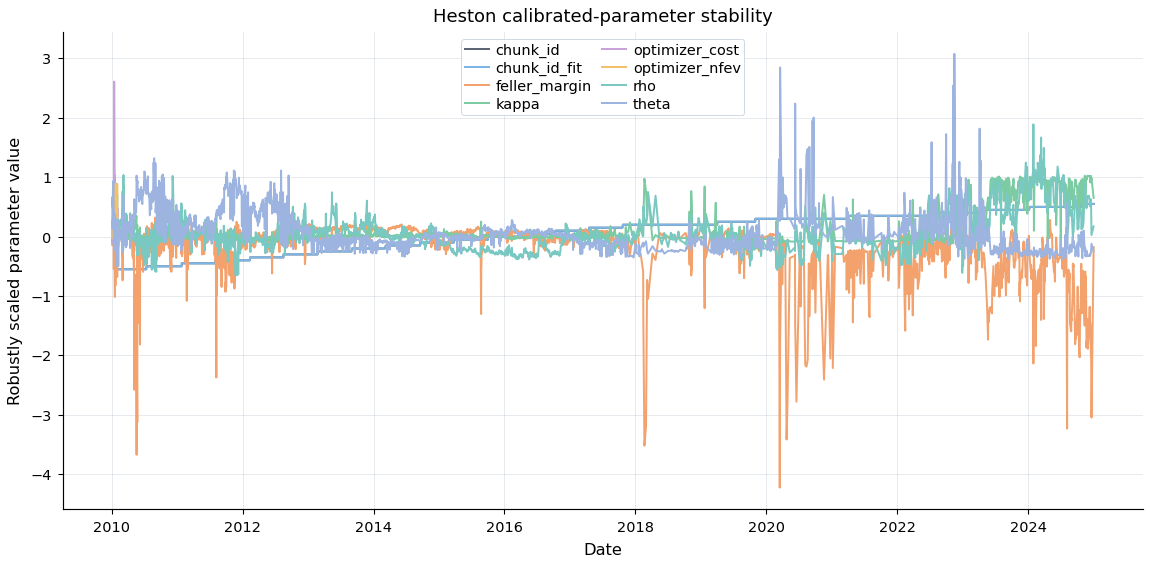

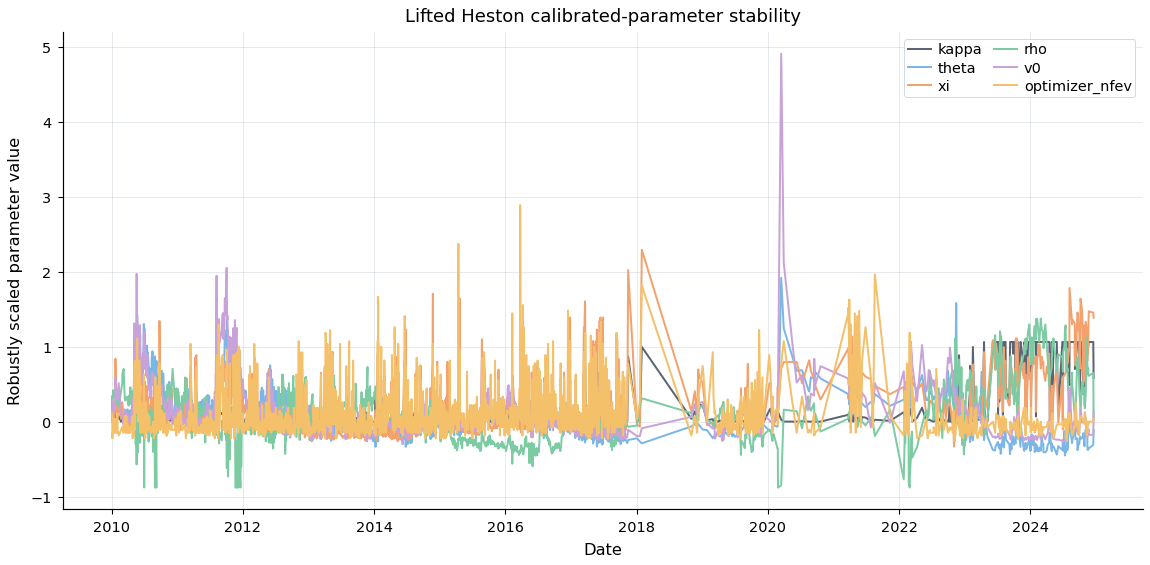

,model,parameter,n,mean,std,p05,median,p95,min,max,coefficient_of_variation_abs,source_file
0,heston,chunk_id,2823,11.723344,6.374752,2.000000e+00,12.000000,22.000000,1.000000e+00,23.000000,0.543766,heston_calibration
1,heston,chunk_id_fit,2823,11.723344,6.374752,2.000000e+00,12.000000,22.000000,1.000000e+00,23.000000,0.543766,heston_calibration
2,heston,feller_margin,2848,-0.455712,0.450161,-1.257239e+00,-0.324212,-0.137248,-5.052921e+00,1.227770,0.987819,heston_calibration
3,heston,kappa,2848,3.191122,3.326981,1.150427e+00,2.086451,13.406979,2.000000e-02,14.754513,1.042574,heston_calibration
4,heston,optimizer_cost,25,0.000010,0.000016,3.406625e-07,0.000004,0.000029,3.197534e-07,0.000079,1.627448,heston_calibration
5,heston,optimizer_nfev,25,33.200000,36.282457,3.200000e+00,14.000000,100.000000,3.000000e+00,100.000000,1.092845,heston_calibration
6,heston,rho,2848,-0.756713,0.095404,-8.737088e-01,-0.771667,-0.554900,-9.792531e-01,-0.169631,0.126077,heston_calibration
7,heston,theta,2848,0.061692,0.034104,2.363648e-02,0.053011,0.130438,1.000000e-04,0.381421,0.552819,heston_calibration
8,heston,v0,2848,0.032283,0.029389,7.884279e-03,0.024089,0.086293,1.369567e-03,0.674845,0.910350,heston_calibration
9,heston,xi,2848,0.836152,0.270515,5.681938e-01,0.760550,1.401658,4.072804e-01,2.448553,0.323524,heston_calibration


,model,parameter,warning,evidence
0,,,none,No simple parameter-boundary warning detected ...


[WindowsPath('outputs_final/figures/heston_parameter_stability_time_series.png'),
 WindowsPath('outputs_final/figures/lifted_heston_parameter_stability_time_series.png')]

In [32]:
# Parameter stability and calibration model-risk diagnostics

def _read_parameter_panel(path: Path) -> pd.DataFrame:
    """Read a dated parameter panel from CSV or parquet if it exists."""
    path = Path(path)
    if not path.exists() or path.stat().st_size == 0:
        return pd.DataFrame()
    return pd.read_parquet(path) if path.suffix.lower() == ".parquet" else pd.read_csv(path)


def _clean_numeric_parameter(values: pd.Series) -> pd.Series:
    """Return a finite float series for one calibrated parameter column."""
    if values is None or pd.api.types.is_bool_dtype(values):
        return pd.Series(dtype="float64")
    out = pd.to_numeric(values, errors="coerce").replace([np.inf, -np.inf], np.nan).dropna()
    return out.astype("float64") if not out.empty else pd.Series(dtype="float64")


def _load_dated_parameter_panels(cfg: ExperimentConfig) -> list[tuple[str, pd.DataFrame, str]]:
    """
    Load date-level calibrated parameter panels only.

    Summary tables such as ``heston_parameter_summary.csv`` are deliberately excluded:
    their rows are statistics such as count, mean and quantiles, not market-date
    parameter observations.
    """
    candidate_sources = [
        ("heston", "heston_calibration", cfg.paths.heston_calibration_path),
        ("heston", None, table_path("heston_calibration_parameter_panel.csv", cfg)),
        ("heston", None, table_path("heston_calibrated_parameters.csv", cfg)),
        ("lifted_heston", "lifted_calibration", cfg.paths.lifted_calibration_path),
        ("lifted_heston", None, table_path("lifted_heston_calibration_parameter_panel.csv", cfg)),
        ("lifted_heston", None, table_path("lifted_heston_calibrated_parameters.csv", cfg)),
    ]

    panels: list[tuple[str, pd.DataFrame, str]] = []
    seen: set[tuple[str, str]] = set()

    for model, live_name, path in candidate_sources:
        frame = globals().get(live_name) if live_name else None
        if not isinstance(frame, pd.DataFrame) or frame.empty:
            frame = _read_parameter_panel(Path(path))
        if not isinstance(frame, pd.DataFrame) or frame.empty or "date" not in frame.columns:
            continue

        frame = frame.copy()
        frame["date"] = pd.to_datetime(frame["date"], errors="coerce").dt.normalize()
        frame = frame.dropna(subset=["date"])
        if frame.empty:
            continue

        source_name = str(live_name or Path(path).name)
        key = (model, source_name)
        if key in seen:
            continue
        seen.add(key)
        panels.append((model, frame, source_name))

    return panels


def _calibrated_parameter_columns(frame: pd.DataFrame) -> list[str]:
    """Select plausible model-parameter columns from a dated calibration panel."""
    excluded_exact = {
        "date", "valuation_date", "expiry", "exdate", "maturity", "maturity_bucket",
        "model", "panel", "status", "calibration_status", "success", "valid",
        "source_file", "seed_id", "split", "option_type",
    }
    excluded_tokens = (
        "rmse", "error", "loss", "residual", "price", "iv", "vega", "objective",
        "rows", "n_", "count", "time", "cpu", "seconds", "path", "flag", "warning",
        "reason", "bucket", "rank", "weight", "spread", "volume", "interest",
        "strike", "spot", "forward", "moneyness", "payoff", "premium",
    )

    cols: list[str] = []
    for col in frame.columns:
        name = str(col).lower()
        if name in excluded_exact or any(token in name for token in excluded_tokens):
            continue
        values = _clean_numeric_parameter(frame[col])
        if values.size >= 5 and values.nunique() > 1:
            cols.append(col)
    return cols


def calibration_parameter_stability_summary(cfg: ExperimentConfig) -> pd.DataFrame:
    """Summarise daily calibrated parameter dispersion for Heston and lifted Heston."""
    rows: list[dict[str, Any]] = []

    for model, frame, source_name in _load_dated_parameter_panels(cfg):
        for column in _calibrated_parameter_columns(frame):
            values = _clean_numeric_parameter(frame[column])
            if values.empty:
                continue
            mean = float(values.mean())
            std = float(values.std(ddof=1)) if values.size > 1 else 0.0
            rows.append({
                "model": model,
                "parameter": str(column),
                "n": int(values.size),
                "mean": mean,
                "std": std,
                "p05": float(values.quantile(0.05)),
                "median": float(values.median()),
                "p95": float(values.quantile(0.95)),
                "min": float(values.min()),
                "max": float(values.max()),
                "coefficient_of_variation_abs": float(std / max(abs(mean), 1e-12)),
                "source_file": source_name,
            })

    out = pd.DataFrame(rows, columns=[
        "model", "parameter", "n", "mean", "std", "p05", "median", "p95",
        "min", "max", "coefficient_of_variation_abs", "source_file",
    ])
    out.to_csv(table_path("calibration_parameter_stability_summary.csv", cfg), index=False)
    return out


def calibration_parameter_boundary_warnings(stability: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    """
    Flag simple calibration model-risk warnings.

    These flags are diagnostic, not formal rejection tests. They are meant to direct
    attention to parameters that are close to boundaries or unusually unstable.
    """
    rows: list[dict[str, str]] = []

    if stability is not None and not stability.empty:
        for _, row in stability.iterrows():
            parameter = str(row["parameter"]).lower()
            warnings: list[str] = []

            if row["coefficient_of_variation_abs"] > 5:
                warnings.append("high_relative_variability")
            if abs(float(row["median"])) < 1e-10 and float(row["std"]) > 1e-8:
                warnings.append("near_zero_median_with_variability")
            if float(row["p05"]) == float(row["p95"]):
                warnings.append("almost_constant_parameter")
            if "rho" in parameter and max(abs(float(row["p05"])), abs(float(row["p95"]))) > 0.98:
                warnings.append("correlation_near_boundary")
            if parameter.startswith(("v0", "theta", "xi", "kappa")) and float(row["p05"]) <= 0:
                warnings.append("positive_parameter_lower_tail_non_positive")

            for warning in warnings:
                rows.append({
                    "model": str(row["model"]),
                    "parameter": str(row["parameter"]),
                    "warning": warning,
                    "evidence": (
                        f"median={row['median']:.6g}; p05={row['p05']:.6g}; "
                        f"p95={row['p95']:.6g}; cv_abs={row['coefficient_of_variation_abs']:.6g}"
                    ),
                })

    out = pd.DataFrame(rows, columns=["model", "parameter", "warning", "evidence"])
    if out.empty:
        out = pd.DataFrame([{
            "model": "",
            "parameter": "",
            "warning": "none",
            "evidence": "No simple parameter-boundary warning detected from available dated panels.",
        }])
    out.to_csv(table_path("calibration_parameter_boundary_warnings.csv", cfg), index=False)
    return out


def plot_calibration_parameter_stability(cfg: ExperimentConfig) -> list[Path]:
    """Plot robustly scaled dated parameter time series for available calibration panels."""
    paths: list[Path] = []
    if not MATPLOTLIB_AVAILABLE:
        return paths

    for model, frame, _source_name in _load_dated_parameter_panels(cfg):
        columns = _calibrated_parameter_columns(frame)[:8]
        if not columns:
            continue

        plot_frame = frame[["date", *columns]].copy().sort_values("date")
        fig, ax = plt.subplots(figsize=(9, 4.5))

        for column in columns:
            values = _clean_numeric_parameter(plot_frame[column])
            if values.size < 3:
                continue
            aligned = plot_frame.loc[values.index, ["date"]].copy()
            median = float(values.median())
            scale = float(values.quantile(0.95) - values.quantile(0.05))
            if scale <= 1e-12:
                scale = float(values.std(ddof=1)) if values.size > 1 else 1.0
            aligned["scaled_value"] = (values - median) / max(scale, 1e-12)
            ax.plot(aligned["date"], aligned["scaled_value"], linewidth=1.1, label=str(column))

        ax.set_title(f"{model.replace('_', ' ').title()} calibrated-parameter stability")
        ax.set_xlabel("Date")
        ax.set_ylabel("Robustly scaled parameter value")
        ax.grid(True, alpha=0.3)
        ax.legend(loc="best", fontsize=8, ncol=2)
        fig.tight_layout()

        path = figure_path(f"{model}_parameter_stability_time_series.png", cfg)
        save_and_show_figure(fig, path, dpi=180)
        paths.append(path)

    return paths


calibration_parameter_stability = calibration_parameter_stability_summary(CFG)
calibration_parameter_boundary_audit = calibration_parameter_boundary_warnings(
    calibration_parameter_stability, CFG
)
calibration_parameter_stability_paths = plot_calibration_parameter_stability(CFG)

display(calibration_parameter_stability)
display(calibration_parameter_boundary_audit)
calibration_parameter_stability_paths

# 6. Simulation Design

Simulation converts calibrated model states into training, validation and test paths for hedging policies. The simulation design is where the calibrated volatility model becomes a pathwise environment. It must therefore preserve the distinction between Heston and lifted Heston worlds while keeping the evaluation protocol comparable.

The main simulation object is a discrete rebalancing grid:

$$
0=t_0<t_1<\cdots<t_N=T.
$$

At each step, the policy observes its information state, chooses a stock position, pays transaction costs for position changes and accumulates terminal hedging error. The path generator supplies the stochastic evolution of spot and variance factors.

Common random numbers, deterministic seeds and fixed seed panels help reduce noise in model comparisons. They do not create market-state diversity. That is why the notebook separately reports the number of calibration dates and seed rows. More simulated paths reduce Monte Carlo error conditional on a date; more dates improve evidence about robustness across market states.

This section should be interpreted as methodology infrastructure. It does not by itself show that a model is good. It defines the controlled experimental environment in which Heston, lifted Heston and policy architectures can be compared fairly.


In [33]:
# ============================================================
# Deterministic stratified seed-panel construction helpers
# ============================================================

SEED_PANEL_VERSION = "deterministic_stratified_seed_panel_v1"
CANDIDATE_SEED_PANEL_VERSION = "deterministic_candidate_universe_v1"
FINAL_FEASIBLE_SEED_PANEL_VERSION = "deterministic_feasible_panel_v1"
EXPERIMENT_READINESS_VERSION = "experiment_readiness_deterministic_panel_v1"
SEED_PANEL_EXCLUSION_VERSION = "seed_panel_exclusion_manifest_v1"


def canonical_split_label(split: str) -> str:
    return "validation" if str(split) == "val" else str(split)


def internal_split_label(split: str) -> str:
    return "val" if str(split) == "validation" else str(split)


def panel_role_sequence(cfg: ExperimentConfig) -> tuple[str, ...]:
    seq = tuple(internal_split_label(s) for s in cfg.panel.role_sequence)
    if len(seq) != int(cfg.panel.strata_per_bucket):
        raise ValueError("Panel role sequence length must equal strata_per_bucket.")
    expected = {internal_split_label(k): int(v) for k, v in cfg.panel.quota_per_bucket.items()}
    actual = {s: seq.count(s) for s in set(seq)}
    if actual != expected:
        raise ValueError(f"Panel role sequence does not match quota_per_bucket: expected={expected}, actual={actual}")
    return seq


def stable_hash01(*tokens: Any, seed: int) -> float:
    raw = "|".join([str(int(seed)), *map(str, tokens)]).encode("utf-8")
    digest = hashlib.sha256(raw).hexdigest()
    return int(digest[:16], 16) / float(16 ** 16)


def stable_dataframe_hash(frame: pd.DataFrame, columns: Iterable[str]) -> str:
    cols = [c for c in columns if c in frame.columns]
    work = frame[cols].copy().sort_values(cols).reset_index(drop=True)
    for col in work.columns:
        if np.issubdtype(work[col].dtype, np.datetime64):
            work[col] = pd.to_datetime(work[col]).dt.strftime("%Y-%m-%d")
    payload = work.astype(str).to_dict("records")
    raw = json.dumps(payload, sort_keys=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(raw).hexdigest()


def seed_bucket_availability(surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    require_columns(surface, {"date", "dte"}, "seed bucket availability input")
    work = surface.copy()
    work["date"] = pd.to_datetime(work["date"]).dt.normalize()
    rows = []
    for bucket, (target_dte, lo, hi) in cfg.hedging.maturity_buckets.items():
        g = work.loc[work["dte"].between(lo, hi)]
        rows.append({
            "maturity_bucket": bucket,
            "target_dte": target_dte,
            "dte_low": lo,
            "dte_high": hi,
            "surface_rows": int(len(g)),
            "candidate_dates": int(g["date"].nunique()) if not g.empty else 0,
        })
    return pd.DataFrame(rows)


def select_near_atm_straddle_seeds(surface: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    required = {"date", "dte", "strike", "spot_ref", "forward_ref", "call_equiv_mid", "T", "r", "q"}
    missing = required - set(surface.columns)
    if missing:
        raise ValueError(f"Cannot select straddle seeds; surface missing columns: {sorted(missing)}")

    work = surface.copy()
    work["date"] = pd.to_datetime(work["date"]).dt.normalize()
    if "log_forward_moneyness" not in work.columns:
        if "log_moneyness" not in work.columns:
            raise ValueError("Surface must contain log_forward_moneyness or log_moneyness.")
        work["log_forward_moneyness"] = work["log_moneyness"]

    rows = []
    invalid_parity_rows = []
    for date, day in work.groupby("date", sort=True):
        for bucket, (target_dte, lo, hi) in cfg.hedging.maturity_buckets.items():
            g = day[day["dte"].between(lo, hi)].copy()
            if g.empty:
                continue
            g["seed_score"] = (g["dte"] - target_dte).abs() / max(target_dte, 1) + 5.0 * g["log_forward_moneyness"].abs()
            selected = None
            for _, candidate in g.sort_values(["seed_score", "date", "strike"]).head(10).iterrows():
                call_mid = float(candidate["call_equiv_mid"])
                put_mid = call_mid - math.exp(-float(candidate["r"]) * float(candidate["T"])) * (float(candidate["forward_ref"]) - float(candidate["strike"]))
                if np.isfinite(put_mid) and put_mid > 0:
                    selected = candidate.copy()
                    selected["put_equiv_mid"] = put_mid
                    break
                invalid_parity_rows.append({
                    "date": pd.Timestamp(date).date().isoformat(),
                    "maturity_bucket": bucket,
                    "strike": float(candidate["strike"]),
                    "put_mid": put_mid,
                })
            if selected is None:
                continue
            selected["hedge_maturity_bucket"] = bucket
            selected["maturity_bucket"] = bucket
            selected["target_dte"] = int(target_dte)
            selected["target_maturity"] = int(target_dte)
            selected["target_expiry"] = selected.get("exdate", pd.NaT)
            selected["straddle_mid"] = float(selected["call_equiv_mid"]) + float(selected["put_equiv_mid"])
            selected["straddle_mid_convention"] = "call_equiv_mid_plus_parity_put_mid"
            selected["seed_id"] = f"{pd.Timestamp(date).date()}_{bucket}_{int(round(selected['strike']))}"
            rows.append(selected)

    seed_panel = pd.DataFrame(rows).reset_index(drop=True)
    if seed_panel.empty:
        raise ValueError("No near-ATM straddle candidates were selected. Check maturity buckets and surface filters.")
    missing_buckets = sorted(set(cfg.hedging.maturity_buckets) - set(seed_panel["maturity_bucket"].dropna().astype(str)))
    if missing_buckets:
        availability = seed_bucket_availability(work, cfg)
        raise ValueError(
            f"Maturity buckets missing from straddle candidate universe: {missing_buckets}. "
            f"Availability={availability.to_dict('records')}. Invalid parity candidates sampled={invalid_parity_rows[:10]}"
        )
    seed_panel["source_row_id"] = np.arange(len(seed_panel), dtype=int)
    return seed_panel


def assign_chronological_strata(bucket_df: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    df = bucket_df.sort_values(["date", "seed_id"]).reset_index(drop=True).copy()
    n = len(df)
    n_strata = int(cfg.panel.strata_per_bucket)
    if n < n_strata:
        bucket = str(df["maturity_bucket"].iloc[0]) if n else "unknown"
        raise ValueError(f"Not enough feasible candidates in bucket {bucket}: need {n_strata}, found {n}.")
    df["chrono_rank"] = np.arange(n, dtype=int)
    df["chrono_quantile"] = (df["chrono_rank"] + 0.5) / float(n)
    df["panel_stratum"] = np.floor(df["chrono_quantile"] * n_strata).astype(int).clip(0, n_strata - 1)
    return df


def assign_deterministic_panel_order(candidate_df: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    require_columns(candidate_df, {"seed_id", "date", "maturity_bucket"}, "candidate universe")
    parts = []
    role_map = {i: role for i, role in enumerate(panel_role_sequence(cfg))}
    for bucket in cfg.hedging.maturity_buckets:
        g = candidate_df.loc[candidate_df["maturity_bucket"].astype(str).eq(str(bucket))].copy()
        g = assign_chronological_strata(g, cfg)
        g["panel_hash"] = [
            stable_hash01(row.seed_id, pd.Timestamp(row.date).date().isoformat(), row.maturity_bucket, seed=cfg.panel.panel_selection_seed)
            for row in g.itertuples()
        ]
        g["split"] = g["panel_stratum"].map(role_map)
        g["split_label"] = g["split"].map(canonical_split_label)
        g["panel_selection_mode"] = cfg.panel.panel_selection_mode
        g["panel_selection_seed"] = int(cfg.panel.panel_selection_seed)
        g["deterministic_panel_version"] = cfg.panel.deterministic_panel_version
        g["manual_override"] = False
        g["selected_after_observing_hedging_performance"] = False
        parts.append(g)
    out = pd.concat(parts, ignore_index=True)
    return out.sort_values(["maturity_bucket", "panel_stratum", "panel_hash", "date", "seed_id"]).reset_index(drop=True)


In [34]:
# ============================================================
# Deterministic candidate universe and pre-selection exclusion manifest
# ============================================================

SIMULATION_FEASIBILITY_VERSION = "simulation_feasibility_v5_deterministic_panel_manifest"
LIFTED_C_LP_SIMULATOR_VERSION = "lifted_c_lp_internal_timestep_refinement_v1"

SIMULATION_INFEASIBLE_SEEDS = pd.DataFrame([
    {
        "seed_id": "2017-06-12_1M_2440",
        "exclusion_reason": "lifted_c_lp_beta_invalid_after_constraint_adjustment_step_10",
    },
    {
        "seed_id": "2023-01-30_1M_4025",
        "exclusion_reason": "lifted_c_lp_alpha_invalid_after_internal_timestep_refinement_step_96",
    },
])
SIMULATION_INFEASIBLE_SEED_IDS = frozenset(SIMULATION_INFEASIBLE_SEEDS["seed_id"].astype(str))
print(
    f"Simulation-feasibility prior exclusions active: {len(SIMULATION_INFEASIBLE_SEED_IDS)} seed(s); "
    "these are simulator-state exclusions, not hedging-performance exclusions.",
    flush=True,
)


def simulation_infeasible_seed_ids() -> frozenset[str]:
    return SIMULATION_INFEASIBLE_SEED_IDS


def _calibration_metadata_by_date(heston: pd.DataFrame, lifted: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    h = _normalise_one_row_per_date(heston, "Heston")
    l = _normalise_one_row_per_date(lifted, "Lifted Heston")
    h_cols = [c for c in ["date", "kappa", "theta", "xi", "rho", "v0", "vega_scaled_rmse", "price_rmse", "loss", "quality_flag", "calibration_mode"] if c in h.columns]
    l_cols = [c for c in ["date", "kappa", "theta", "xi", "rho", "v0", "vega_scaled_rmse", "price_rmse", "loss", "quality_flag", "calibration_backend", "candidate_source"] if c in l.columns]
    hm = h[h_cols].rename(columns={c: f"heston_{c}" for c in h_cols if c != "date"})
    lm = l[l_cols].rename(columns={c: f"lifted_{c}" for c in l_cols if c != "date"})
    meta = hm.merge(lm, on="date", how="outer").sort_values("date").reset_index(drop=True)
    h_params = [f"heston_{c}" for c in ["kappa", "theta", "xi", "rho", "v0"] if f"heston_{c}" in meta.columns]
    l_params = [f"lifted_{c}" for c in ["kappa", "theta", "xi", "rho", "v0"] if f"lifted_{c}" in meta.columns]
    meta["world_available_heston"] = np.isfinite(meta[h_params].apply(pd.to_numeric, errors="coerce")).all(axis=1) if h_params else False
    meta["world_available_lifted"] = np.isfinite(meta[l_params].apply(pd.to_numeric, errors="coerce")).all(axis=1) if l_params else False
    meta["heston_calibration_version"] = METHODOLOGY_VERSION
    meta["lifted_calibration_version"] = METHODOLOGY_VERSION
    meta["lifted_calibration_parameterization"] = cfg.lifted.calibration_parameterization
    return meta


def build_seed_candidate_universe(surface: pd.DataFrame, heston: pd.DataFrame, lifted: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    target = select_near_atm_straddle_seeds(surface, cfg)
    target["date"] = pd.to_datetime(target["date"]).dt.normalize()
    meta = _calibration_metadata_by_date(heston, lifted, cfg)
    universe = target.merge(meta, on="date", how="left")

    numeric_required = ["strike", "spot_ref", "forward_ref", "call_equiv_mid", "put_equiv_mid", "straddle_mid", "T", "r", "q"]
    for col in numeric_required + ["iv_market", "dte"]:
        if col in universe.columns:
            universe[col] = pd.to_numeric(universe[col], errors="coerce")
    if "iv_market" not in universe.columns:
        universe["iv_market"] = np.nan

    universe["heston_calibration_rmse"] = pd.to_numeric(universe.get("heston_vega_scaled_rmse", np.nan), errors="coerce")
    universe["lifted_calibration_rmse"] = pd.to_numeric(universe.get("lifted_vega_scaled_rmse", np.nan), errors="coerce")
    universe["initial_variance_v0"] = pd.to_numeric(universe.get("lifted_v0", universe.get("heston_v0", np.nan)), errors="coerce")
    universe["atm_iv_proxy"] = pd.to_numeric(universe["iv_market"], errors="coerce")
    for col in ["kappa", "theta", "xi", "rho"]:
        universe[col] = pd.to_numeric(universe.get(f"lifted_{col}", universe.get(f"heston_{col}", np.nan)), errors="coerce")

    universe["world_available_heston"] = universe["world_available_heston"].fillna(False).astype(bool)
    universe["world_available_lifted"] = universe["world_available_lifted"].fillna(False).astype(bool)
    valid_bucket = universe["maturity_bucket"].astype(str).isin(set(map(str, cfg.hedging.maturity_buckets)))
    finite_market = np.isfinite(universe[numeric_required].apply(pd.to_numeric, errors="coerce")).all(axis=1)
    lifted_5p = universe["lifted_calibration_parameterization"].astype(str).eq(cfg.lifted.calibration_parameterization)

    universe["candidate_universe_version"] = CANDIDATE_SEED_PANEL_VERSION
    universe["exclusion_reason"] = np.select(
        [
            ~universe["world_available_heston"],
            ~universe["world_available_lifted"] | ~lifted_5p,
            ~valid_bucket,
            ~finite_market,
        ],
        [
            "missing_heston_calibration",
            "missing_lifted_5p_calibration",
            "invalid_maturity_bucket",
            "missing_required_market_inputs",
        ],
        default="accepted_pre_feasibility",
    )
    universe["pre_selection_or_post_selection"] = "pre_selection"
    universe["deterministic_panel_version"] = cfg.panel.deterministic_panel_version
    universe["panel_selection_seed"] = int(cfg.panel.panel_selection_seed)
    return universe.sort_values(["date", "maturity_bucket", "seed_id"]).reset_index(drop=True)


def candidate_universe_summary(universe: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    rows = [{
        "field": "candidate_rows_total",
        "value": int(len(universe)),
        "detail": "One near-ATM straddle target per date and maturity bucket where available.",
    }]
    for bucket, g in universe.groupby("maturity_bucket", sort=True):
        rows.append({
            "field": f"rows_bucket_{bucket}",
            "value": int(len(g)),
            "detail": f"date_min={pd.to_datetime(g['date']).min().date()}, date_max={pd.to_datetime(g['date']).max().date()}",
        })
    rows.append({
        "field": "lifted_calibration_parameterization",
        "value": cfg.lifted.calibration_parameterization,
        "detail": "Final lifted calibration must be full_5p_forward_curve_init.",
    })
    rows.append({
        "field": "deterministic_panel_version",
        "value": cfg.panel.deterministic_panel_version,
        "detail": f"seed={cfg.panel.panel_selection_seed}; mode={cfg.panel.panel_selection_mode}",
    })
    return pd.DataFrame(rows)


def build_preselection_exclusion_manifest(universe: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    excluded = universe.loc[~universe["exclusion_reason"].astype(str).eq("accepted_pre_feasibility")].copy()
    if excluded.empty:
        return pd.DataFrame(columns=[
            "seed_id", "date", "maturity_bucket", "exclusion_stage", "exclusion_reason", "exclusion_detail",
            "pre_selection_or_post_selection", "deterministic_panel_version", "panel_selection_seed", "timestamp_utc",
        ])
    out = pd.DataFrame({
        "seed_id": excluded["seed_id"].astype(str),
        "date": pd.to_datetime(excluded["date"]).dt.normalize(),
        "maturity_bucket": excluded["maturity_bucket"].astype(str),
        "exclusion_stage": "candidate_universe_gate",
        "exclusion_reason": excluded["exclusion_reason"].astype(str),
        "exclusion_detail": "pre-specified calibration/data/maturity gate",
        "pre_selection_or_post_selection": "pre_selection",
        "deterministic_panel_version": cfg.panel.deterministic_panel_version,
        "panel_selection_seed": int(cfg.panel.panel_selection_seed),
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    })
    return out.reset_index(drop=True)


def _candidate_seed_panel_required_columns() -> set[str]:
    return {
        "seed_id", "date", "hedge_maturity_bucket", "maturity_bucket", "split", "split_label",
        "panel_stratum", "panel_hash", "straddle_mid", "spot_ref", "iv_market",
        "candidate_universe_version", "deterministic_panel_version", "panel_selection_seed",
        "panel_selection_mode", "manual_override", "selected_after_observing_hedging_performance",
        "world_available_heston", "world_available_lifted", "lifted_calibration_parameterization",
    }


def validate_candidate_seed_panel(candidate: pd.DataFrame, cfg: ExperimentConfig) -> None:
    require_columns(candidate, _candidate_seed_panel_required_columns(), "deterministic candidate seed panel")
    versions = set(candidate["deterministic_panel_version"].dropna().astype(str).unique())
    if versions != {cfg.panel.deterministic_panel_version}:
        raise ValueError(f"Candidate panel has stale deterministic version(s): {sorted(versions)}")
    if candidate["manual_override"].astype(bool).any():
        raise ValueError("Manual override detected in deterministic candidate panel.")
    if candidate["selected_after_observing_hedging_performance"].astype(bool).any():
        raise ValueError("Performance-based selection flag detected in candidate panel.")
    expected_strata = set(range(int(cfg.panel.strata_per_bucket)))
    for bucket in cfg.hedging.maturity_buckets:
        g = candidate.loc[candidate["maturity_bucket"].astype(str).eq(str(bucket))]
        got = set(pd.to_numeric(g["panel_stratum"], errors="coerce").dropna().astype(int))
        if got != expected_strata:
            raise RuntimeError(f"Candidate panel bucket {bucket} missing strata: expected={sorted(expected_strata)}, got={sorted(got)}")


def write_panel_selection_outputs(universe: pd.DataFrame, candidate: pd.DataFrame, exclusions: pd.DataFrame, cfg: ExperimentConfig) -> None:
    cfg.paths.panel_selection_dir.mkdir(parents=True, exist_ok=True)
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    deps = [globals().get("SPX_HEDGING_CALIBRATION_PANEL_PATH", cfg.paths.surface_cache_path), cfg.paths.heston_calibration_path, cfg.paths.lifted_calibration_path]
    write_dataframe_cache(
        universe,
        cfg.paths.seed_candidate_universe_path,
        "seed_candidate_universe",
        "seed_panel_candidate",
        cfg,
        dependencies=deps,
        extra={"candidate_universe_version": CANDIDATE_SEED_PANEL_VERSION},
    )
    write_dataframe_cache(
        exclusions,
        cfg.paths.seed_panel_exclusion_manifest_path,
        "seed_panel_exclusion_manifest",
        "seed_panel_candidate",
        cfg,
        dependencies=[cfg.paths.seed_candidate_universe_path],
        extra={"seed_panel_exclusion_version": SEED_PANEL_EXCLUSION_VERSION},
    )
    summary = candidate_universe_summary(universe, cfg)
    summary.to_csv(cfg.paths.table_dir / "seed_candidate_universe_summary.csv", index=False)
    exclusions.to_csv(cfg.paths.table_dir / "seed_panel_exclusion_manifest.csv", index=False)
    exclusion_summary = exclusions.groupby(["exclusion_stage", "exclusion_reason"], dropna=False).size().rename("rows").reset_index() if not exclusions.empty else pd.DataFrame(columns=["exclusion_stage", "exclusion_reason", "rows"])
    exclusion_summary.to_csv(cfg.paths.table_dir / "seed_panel_exclusion_summary.csv", index=False)
    (cfg.paths.methodology_insert_deterministic_panel_path).write_text(
        "The final seed panel is constructed using a deterministic maturity-stratified selection rule. "
        "The candidate universe consists of dates for which both Heston and lifted-Heston 5p calibrations are available and the required target option surface is valid. "
        "For each maturity bucket, feasible candidate dates are sorted chronologically and divided into ten chronological strata. "
        "One date is selected from each stratum using a stable hash with a pre-specified panel seed. "
        "The ten selected dates per maturity bucket are assigned to train, validation and test splits using a fixed role sequence, yielding four training dates, two validation dates and four test dates per maturity bucket. "
        "Exclusions are applied only through pre-specified data-quality, calibration-availability and simulation-feasibility gates, and are recorded in an exclusion manifest. "
        "No dates are manually added or removed after observing hedging performance.\n\n"
        "The final lifted calibration uses the five-parameter forward-curve-initialised specification. Neural training uses cached tensor banks built from the deterministic train and validation panels, while production evaluation is performed on 10,000 simulated paths per test seed. Headline comparisons include only production-scale rows that pass the final audit.\n"
    )


def build_candidate_seed_panel(surface: pd.DataFrame, heston: pd.DataFrame, lifted: pd.DataFrame, cfg: ExperimentConfig) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    universe = build_seed_candidate_universe(surface, heston, lifted, cfg)
    exclusions = build_preselection_exclusion_manifest(universe, cfg)
    accepted = universe.loc[universe["exclusion_reason"].astype(str).eq("accepted_pre_feasibility")].copy()
    if accepted.empty:
        raise RuntimeError("No candidate rows remain after deterministic pre-selection gates.")
    candidate = assign_deterministic_panel_order(accepted, cfg)
    candidate["candidate_rank_within_stratum"] = candidate.groupby(["maturity_bucket", "panel_stratum"])["panel_hash"].rank(method="first").astype(int)
    candidate["world_required"] = "heston_and_lifted"
    validate_candidate_seed_panel(candidate, cfg)
    return candidate, universe, exclusions


def load_or_build_candidate_seed_panel(surface: pd.DataFrame, heston: pd.DataFrame, lifted: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    deps = [globals().get("SPX_HEDGING_CALIBRATION_PANEL_PATH", cfg.paths.surface_cache_path), cfg.paths.heston_calibration_path, cfg.paths.lifted_calibration_path]
    try:
        candidate = load_dataframe_cache(
            cfg.paths.candidate_seed_panel_path,
            "deterministic_candidate_seed_panel",
            "seed_panel_candidate",
            cfg,
            required_columns=_candidate_seed_panel_required_columns(),
            dependencies=deps,
        )
        validate_candidate_seed_panel(candidate, cfg)
        print(f"[candidate universe] loaded deterministic candidate rows={len(candidate)} from cache.", flush=True)
        return candidate
    except (FileNotFoundError, ValueError, RuntimeError) as exc:
        if not (cfg.flags.RUN_SIMULATION_FEASIBILITY_SCAN or cfg.flags.RUN_TRAINING):
            raise RuntimeError(
                "Candidate seed-panel cache is missing or stale. Cached-evaluation/reporting mode will not rebuild seed selection inputs. "
                "Enable RUN_SIMULATION_FEASIBILITY_SCAN or RUN_TRAINING only for an explicit panel-selection rebuild."
            ) from exc
        print(f"[candidate universe rebuild] explicit seed-panel work enabled. Reason: {type(exc).__name__}: {str(exc)[:220]}", flush=True)
    candidate, universe, exclusions = build_candidate_seed_panel(surface, heston, lifted, cfg)
    write_dataframe_cache(
        candidate,
        cfg.paths.candidate_seed_panel_path,
        "deterministic_candidate_seed_panel",
        "seed_panel_candidate",
        cfg,
        dependencies=deps,
        extra={
            "candidate_universe_version": CANDIDATE_SEED_PANEL_VERSION,
            "deterministic_panel_version": cfg.panel.deterministic_panel_version,
            "panel_selection_seed": int(cfg.panel.panel_selection_seed),
        },
    )
    write_panel_selection_outputs(universe, candidate, exclusions, cfg)
    print(f"[candidate universe] built rows={len(universe)}; accepted_pre_feasibility={len(candidate)}.", flush=True)
    return candidate


candidate_seed_panel = load_or_build_candidate_seed_panel(surface_panel, heston_calibration, lifted_calibration, CFG)
display(candidate_seed_panel.groupby(["split_label", "maturity_bucket", "panel_stratum"]).size().rename("candidate_rows").reset_index().head(30))


Simulation-feasibility prior exclusions active: 2 seed(s); these are simulator-state exclusions, not hedging-performance exclusions.
[candidate universe] loaded deterministic candidate rows=1498 from cache.


,split_label,maturity_bucket,panel_stratum,candidate_rows
0,test,1M,1,38
1,test,1M,4,37
2,test,1M,6,38
3,test,1M,9,38
4,test,2M,1,20
5,test,2M,4,21
6,test,2M,6,20
7,test,2M,9,21
8,test,3M,1,92
9,test,3M,4,91


In [35]:
@dataclass(frozen=True)
class ResearchArtifacts:
    """Explicit runtime artefacts passed through simulation, delta, training and evaluation paths.

    This replaces hidden notebook globals in core execution functions. The top-level notebook
    still creates one named object, but functions receive it as an argument and therefore cannot
    silently read stale calibration/pricer state from the surrounding namespace.
    """
    heston_calibration: pd.DataFrame
    lifted_calibration: pd.DataFrame
    forward_variance_curve: pd.DataFrame
    lifted_kernel: LiftedKernelGrid
    lifted_pricer: LiftedRiccatiFourierPricer


def get_seed_spot(seed_row: pd.Series) -> float:
    if "spot_ref" not in seed_row.index:
        raise KeyError("Seed row must contain CRSP-derived spot_ref.")
    value = float(seed_row["spot_ref"])
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f"Invalid spot_ref={value!r}.")
    return value


def seed_entry_premium(seed_row: pd.Series) -> float:
    if "straddle_mid" not in seed_row.index:
        raise KeyError("Seed row must contain explicit straddle_mid.")
    value = float(seed_row["straddle_mid"])
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f"Invalid straddle_mid={value!r}.")
    return value


def seed_entry_iv(seed_row: pd.Series) -> float:
    if "iv_market" not in seed_row.index:
        raise KeyError("Seed row must contain iv_market.")
    value = float(seed_row["iv_market"])
    if not np.isfinite(value) or value <= 0:
        raise ValueError(f"Invalid iv_market={value!r}.")
    return value


def stable_int_hash(*parts: Any, modulus: int = 2**31 - 1) -> int:
    raw = "|".join(map(str, parts)).encode("utf-8")
    return int(hashlib.sha256(raw).hexdigest()[:16], 16) % modulus


def common_path_seed(seed_row: pd.Series, split: str, cfg: ExperimentConfig, replicate: int = 0) -> int:
    return stable_int_hash(cfg.random_seed, seed_row["seed_id"], split, replicate)


def lookup_params_by_date(calib: pd.DataFrame, date: pd.Timestamp, param_cls: Callable[..., Any]) -> Any:
    """Return finite calibrated parameters for a date using the same fit-quality gate.

    Raw optimiser success is not a hard gate here. It is provenance. The hard
    requirements are finite parameters and no BADFIT/NUMFAIL quality flag, matching
    the calibration-quality gate used for seed selection.
    """
    day = pd.Timestamp(date).normalize()
    rows = calib.loc[pd.to_datetime(calib["date"]).dt.normalize().eq(day)]
    if rows.empty:
        raise KeyError(f"No calibration row for {day.date()}.")
    row = rows.iloc[0]
    bad_flags = {"BADFIT", "NUMFAIL", "FAIL", "FAILED"}
    if "quality_flag" in row.index and str(row["quality_flag"]).upper() in bad_flags:
        raise ValueError(f"Calibration for {day.date()} is flagged {row['quality_flag']}.")
    values = [float(row.kappa), float(row.theta), float(row.xi), float(row.rho), float(row.v0)]
    if not np.isfinite(values).all():
        raise ValueError(f"Calibration for {day.date()} has non-finite parameters.")
    return param_cls(*values)


def lookup_lifted_state_by_date(calib: pd.DataFrame, date: pd.Timestamp, forward_curve: pd.DataFrame) -> tuple[LiftedHestonParams, ForwardVarianceInputCurve]:
    params = lookup_params_by_date(calib, date, LiftedHestonParams)
    return params, effective_lifted_curve(lifted_curve_for_date(forward_curve, date), params, CFG)


def _common_brownian_normals(n_paths: int, n_steps: int, n_factors: int, seed: int) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    rng = np.random.default_rng(seed)
    z_variance = rng.standard_normal((n_paths, n_steps))
    z_perp = rng.standard_normal((n_paths, n_steps))
    z_factor = rng.standard_normal((n_paths, n_steps, n_factors))
    return z_variance, z_perp, z_factor


def lifted_conditional_increment_coefficients(lambdas: np.ndarray, dt: float) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Conditional Gaussian law of OU Brownian integrals given ΔW.

    I_i=∫exp(-x_i(dt-s))dW_s. The conditional representation preserves the
    shared variance Brownian increment, making Heston/lifted simulations use
    common random numbers in a mathematically coherent way.
    """
    x = np.asarray(lambdas, dtype=float)
    phi = (1.0 - np.exp(-x * dt)) / np.maximum(x, 1e-14)
    decay = np.exp(-x * dt)
    denom = x[:, None] + x[None, :]
    covariance = (1.0 - np.exp(-denom * dt)) / np.maximum(denom, 1e-14)
    conditional = covariance - np.outer(phi, phi) / dt
    conditional = 0.5 * (conditional + conditional.T)
    eigval, eigvec = np.linalg.eigh(conditional)
    if eigval.min() < -1e-10:
        raise FloatingPointError("Conditional OU covariance is not positive semidefinite.")
    eigval = np.where(eigval < 0.0, 0.0, eigval)  # round-off only, never a variance-state repair
    sqrt_conditional = eigvec @ np.diag(np.sqrt(eigval))
    return decay, phi, sqrt_conditional


def hedge_steps_for_seed(seed_row: pd.Series, cfg: ExperimentConfig) -> int:
    dte = int(round(float(seed_row.get("dte", float(seed_row["T"]) * cfg.market.calendar_days_per_year))))
    return max(1, int(math.ceil(dte * cfg.hedging.hedge_steps_per_day)))


def simulate_heston_paths_np(seed_row: pd.Series, params: HestonParams, n_paths: int, n_steps: int, seed: int, variance_floor: float = 1e-10) -> dict[str, np.ndarray]:
    S0, K, T = get_seed_spot(seed_row), float(seed_row["strike"]), float(seed_row["T"])
    r, q = float(seed_row["r"]), float(seed_row["q"])
    dt = T / max(n_steps, 1)
    z_v, z_perp, _ = _common_brownian_normals(n_paths, n_steps, 1, seed)
    S = np.empty((n_paths, n_steps + 1)); V = np.empty_like(S)
    S[:, 0] = S0; V[:, 0] = params.v0
    sqrt_one_minus = math.sqrt(max(1.0 - params.rho ** 2, 0.0))
    for t in range(n_steps):
        dWv = math.sqrt(dt) * z_v[:, t]
        dWs = params.rho * dWv + sqrt_one_minus * math.sqrt(dt) * z_perp[:, t]
        V_pos = np.maximum(V[:, t], variance_floor)
        S[:, t + 1] = S[:, t] * np.exp((r - q - 0.5 * V_pos) * dt + np.sqrt(V_pos) * dWs)
        V[:, t + 1] = np.maximum(V[:, t] + params.kappa * (params.theta - V_pos) * dt + params.xi * np.sqrt(V_pos) * dWv, 0.0)
    times = np.linspace(0.0, T, n_steps + 1)
    return {"S":S,"V":V,"times":times,"K":K,"r":r,"q":q,"T":T,"entry_iv":seed_entry_iv(seed_row),"model_world":"heston","date":pd.Timestamp(seed_row["date"]).normalize()}


def _lifted_reconstruct_variance(U: np.ndarray, g0_path: np.ndarray, weights: np.ndarray) -> np.ndarray:
    U_arr = np.asarray(U, dtype=float)
    g0 = np.asarray(g0_path, dtype=float)
    if U_arr.ndim != 3:
        raise ValueError("Lifted factor path U must have shape (n_paths, n_times, n_factors).")
    if g0.shape[0] != U_arr.shape[1]:
        raise ValueError("g0_path length must match the time dimension of U.")
    return g0.reshape(1, -1) + np.einsum("ptf,f->pt", U_arr, np.asarray(weights, dtype=float))


def validate_lifted_path_state(paths: dict[str, np.ndarray], kernel: LiftedKernelGrid, cfg: ExperimentConfig, *, label: str = "lifted") -> dict[str, float]:
    """Hard validity checks for lifted factor paths.

    This is deliberately stricter than a plotting diagnostic. The notebook should fail here
    rather than pass an invalid factor state into Riccati pricing, deltas, neural features, or
    dissertation tables. Tiny negative values are accepted only up to round-off tolerance.
    """
    required = {"U", "V", "g0", "S", "times"}
    missing = required.difference(paths)
    if missing:
        raise KeyError(f"{label}: lifted path dictionary is missing {sorted(missing)}.")
    U = np.asarray(paths["U"], dtype=float)
    V = np.asarray(paths["V"], dtype=float)
    S = np.asarray(paths["S"], dtype=float)
    g0 = np.asarray(paths["g0"], dtype=float)
    recon = _lifted_reconstruct_variance(U, g0, kernel.weights)
    if not np.isfinite(U).all() or not np.isfinite(V).all() or not np.isfinite(S).all():
        raise FloatingPointError(f"{label}: lifted simulation produced non-finite paths.")
    recon_error = float(np.max(np.abs(V - recon)))
    if recon_error > cfg.lifted.valid_state_tolerance:
        raise FloatingPointError(f"{label}: V is inconsistent with g0 + weights·U; max error={recon_error:.3e}.")
    min_v = float(np.min(V))
    if min_v < -cfg.lifted.valid_state_tolerance:
        raise FloatingPointError(f"{label}: lifted variance left admissible state space; min V={min_v:.3e}.")
    if np.any(S <= 0.0):
        raise FloatingPointError(f"{label}: simulated stock path is non-positive.")
    return {"min_variance": min_v, "max_reconstruction_error": recon_error, "n_paths": float(V.shape[0]), "n_steps": float(V.shape[1] - 1)}



def _integral_exp_AW_exp_A(A: np.ndarray, W: np.ndarray, dt: float) -> np.ndarray:
    """Compute ∫₀ᵈᵗ exp(A(dt-u)) W exp(Au) du.

    This is adapted from the public C-LP helper implementation, but kept local so the
    notebook is self-contained and cacheable. It is used only for numerical coefficients;
    invalid variances are still rejected by downstream gates.
    """
    from scipy.linalg import eig
    if not SCIPY_AVAILABLE:
        raise RuntimeError("SciPy is required for the C-LP lifted-Heston simulator.")
    Lambda, Vmat = eig(A)
    Vinv = np.linalg.inv(Vmat)
    W_tilde = Vinv @ W @ Vmat
    U_svd, S_svd, VT_svd = np.linalg.svd(W_tilde)
    u = U_svd[:, 0] * np.sqrt(S_svd[0])
    v = VT_svd[0, :] * np.sqrt(S_svd[0])
    N = A.shape[0]
    M = np.zeros((N, N), dtype=complex)
    for i in range(N):
        for j in range(N):
            diff = Lambda[j] - Lambda[i]
            if abs(diff) > 1e-14:
                M[i, j] = u[i] * v[j] * (np.exp(diff * dt) - 1.0) / diff
            else:
                M[i, j] = u[i] * v[j] * dt
    E = np.exp(np.outer(Lambda, np.ones(N)) * dt)
    out = Vmat @ (E * M) @ Vinv
    return np.real_if_close(out, tol=1000).real


@lru_cache(maxsize=16)
def _cached_legendre_nodes_weights(n_nodes: int) -> tuple[np.ndarray, np.ndarray]:
    """Cache deterministic Gauss-Legendre nodes/weights used inside lifted simulation."""
    return np.polynomial.legendre.leggauss(int(n_nodes))


def _curve_g0_integral(curve: ForwardVarianceInputCurve, s: float, t: float, params: LiftedHestonParams, kernel: LiftedKernelGrid, *, n_nodes: int = 16) -> float:
    """Numerically integrate the deterministic lifted input g₀ over [s,t].

    The public C-LP reference assumes a closed-form lifted-Heston g₀. This
    notebook uses a calibrated piecewise forward-variance proxy ξ₀(t), so the
    integral is evaluated with deterministic Gauss-Legendre quadrature under the
    same g₀ convention used by pricing and simulation.
    """
    s = float(s); t = float(t)
    if t < s - 1e-14:
        raise ValueError("g0 integral requires t >= s.")
    if abs(t - s) <= 1e-14:
        return 0.0
    nodes, weights = _cached_legendre_nodes_weights(int(n_nodes))
    mid = 0.5 * (s + t)
    half = 0.5 * (t - s)
    eval_t = mid + half * nodes
    vals = np.asarray(curve.g0(eval_t, params.kappa, kernel), dtype=float)
    if np.any(~np.isfinite(vals)) or np.any(vals <= 0):
        raise FloatingPointError("C-LP g0 integral encountered invalid deterministic variance input.")
    return float(half * np.sum(weights * vals))


def _sample_inverse_gaussian(mean: np.ndarray, shape: np.ndarray, rng: np.random.Generator) -> np.ndarray:
    """Sample inverse-Gaussian variables with mean/shape parameterisation.

    scipy.stats.invgauss uses mu=mean/shape and scale=shape. This wrapper enforces
    finite positive inputs before sampling so invalid simulator coefficients fail before
    they contaminate path generation.
    """
    from scipy.stats import invgauss
    mean = np.asarray(mean, dtype=float)
    shape = np.asarray(shape, dtype=float)
    if np.any(~np.isfinite(mean)) or np.any(~np.isfinite(shape)) or np.any(mean <= 0) or np.any(shape <= 0):
        raise FloatingPointError("Invalid inverse-Gaussian parameters in C-LP lifted simulator.")
    return invgauss.rvs(mu=mean / shape, scale=shape, size=mean.shape, random_state=rng)


def _lifted_internal_substep_schedule(cfg: ExperimentConfig) -> tuple[int, ...]:
    base = max(1, int(getattr(cfg.lifted, "simulation_internal_substeps_per_hedge_step", 1)))
    max_substeps = max(base, int(getattr(cfg.lifted, "simulation_max_internal_substeps_per_hedge_step", base)))
    out: list[int] = []
    current = base
    while current <= max_substeps:
        out.append(int(current))
        if current == max_substeps:
            break
        current = min(max_substeps, current * 2)
    return tuple(dict.fromkeys(out))


def _simulate_lifted_paths_np_once(
    seed_row: pd.Series,
    params: LiftedHestonParams,
    curve: ForwardVarianceInputCurve,
    kernel: LiftedKernelGrid,
    n_paths: int,
    n_steps: int,
    seed: int,
    variance_floor: float,
    cfg: ExperimentConfig,
    *,
    internal_substeps: int,
) -> dict[str, np.ndarray]:
    """Run one C-LP lifted-Heston simulation at a fixed internal timestep."""
    if not SCIPY_AVAILABLE:
        raise RuntimeError("SciPy is required for the C-LP lifted-Heston simulator.")
    from scipy.integrate import solve_ivp
    from scipy.linalg import expm

    S0, K, T = get_seed_spot(seed_row), float(seed_row["strike"]), float(seed_row["T"])
    r, q = float(seed_row["r"]), float(seed_row["q"])
    if T <= 0 or n_steps < 1 or n_paths < 1:
        raise ValueError("Lifted simulation requires positive maturity, n_steps and n_paths.")
    internal_substeps = max(1, int(internal_substeps))
    sim_steps = int(n_steps) * internal_substeps
    dt = T / sim_steps
    rng = np.random.default_rng(seed)
    hedge_times = np.linspace(0.0, T, int(n_steps) + 1)
    sim_times = np.linspace(0.0, T, sim_steps + 1)
    g0_hedge = np.asarray(curve.g0(hedge_times, params.kappa, kernel), dtype=float)
    g0_sim = np.asarray(curve.g0(sim_times, params.kappa, kernel), dtype=float)
    if np.any(~np.isfinite(g0_hedge)) or np.any(~np.isfinite(g0_sim)) or min(np.min(g0_hedge), np.min(g0_sim)) <= 0.0:
        raise FloatingPointError("Initial lifted deterministic input g0 is invalid.")

    N = int(kernel.n_factors)
    omega = np.asarray(kernel.weights, dtype=float).reshape(N)
    x = np.asarray(kernel.lambdas, dtype=float).reshape(N)
    if np.any(omega <= 0) or np.any(x < 0):
        raise ValueError("Lifted kernel weights must be positive and factor rates non-negative.")

    A = -params.kappa * np.tile(omega, (N, 1)) - np.diag(x)
    invA = np.linalg.inv(A)
    eye = np.eye(N)
    c_vec = -params.kappa * np.ones(N)
    expA_dt = expm(A * dt)
    integ = _integral_exp_AW_exp_A(A, np.outer(np.ones(N), omega), dt)

    S = np.empty((n_paths, int(n_steps) + 1), dtype=float)
    V = np.empty((n_paths, int(n_steps) + 1), dtype=float)
    U_store = np.zeros((n_paths, int(n_steps) + 1, N), dtype=float)
    X_inc_store = np.zeros((n_paths, int(n_steps)), dtype=float)
    Z_inc_store = np.zeros((n_paths, int(n_steps)), dtype=float)
    S[:, 0] = S0
    V[:, 0] = g0_hedge[0]
    logS = np.full(n_paths, math.log(S0), dtype=float)
    U_state = np.zeros((N, n_paths), dtype=float)
    sqrt_one_minus = math.sqrt(max(1.0 - params.rho ** 2, 0.0))

    for sim_step in range(sim_steps):
        t0 = float(sim_times[sim_step])
        t1 = float(sim_times[sim_step + 1])
        hedge_slot = sim_step // internal_substeps
        G0_step = _curve_g0_integral(curve, t0, t1, params, kernel)
        gen_mu_N_at_end = ((expA_dt - eye) @ invA) @ U_state

        def particular(t: float, m: np.ndarray) -> np.ndarray:
            return A @ m + c_vec * _curve_g0_integral(curve, t0, float(t), params, kernel)

        sol = solve_ivp(particular, [t0, t1], np.zeros(N), dense_output=True, method="DOP853", rtol=1e-9, atol=1e-11, max_step=np.inf)
        if not sol.success:
            raise RuntimeError(f"C-LP deterministic particular ODE failed at internal step {sim_step}: {sol.message}")
        particular_end = sol.sol(t1)[:, None]
        mu_N_at_end = gen_mu_N_at_end + particular_end
        alpha = omega @ mu_N_at_end + G0_step
        if np.any(~np.isfinite(alpha)) or np.any(alpha <= variance_floor):
            raise FloatingPointError(f"C-LP integrated-variance mean alpha invalid at internal step {sim_step}.")

        def particular2(t: float, m: np.ndarray) -> np.ndarray:
            return A @ m + params.xi * (omega @ sol.sol(float(t)) + _curve_g0_integral(curve, t0, float(t), params, kernel))

        sol2 = solve_ivp(particular2, [t0, t1], np.zeros(N), dense_output=True, method="DOP853", rtol=1e-9, atol=1e-11, max_step=np.inf)
        if not sol2.success:
            raise RuntimeError(f"C-LP covariance particular ODE failed at internal step {sim_step}: {sol2.message}")
        hom_integral2 = params.xi * (integ - (expA_dt - eye) @ invA @ np.outer(np.ones(N), omega)) @ invA @ U_state
        cov_N = hom_integral2 + sol2.sol(t1)[:, None]
        cov = omega @ cov_N
        slope_X = cov / alpha
        beta_N = cov_N / alpha
        beta = np.array(slope_X, dtype=float, copy=True)
        if np.any(~np.isfinite(beta)) or np.any(~np.isfinite(beta_N)):
            raise FloatingPointError(f"C-LP beta became non-finite at internal step {sim_step}.")
        if np.any(beta <= variance_floor):
            raise FloatingPointError(
                f"C-LP beta non-positive before constraint adjustment at internal step {sim_step}; "
                f"min_beta={float(np.min(beta)):.3e}."
            )

        def b_constraint(y: np.ndarray | float, b: np.ndarray) -> np.ndarray:
            y_arr = np.asarray(y, dtype=float)
            return omega @ (
                U_state
                - x[:, None] * (mu_N_at_end + beta_N * (y_arr - alpha) / slope_X)
                - params.kappa * y_arr
                + params.xi * ((y_arr - alpha) / b)
            ) + g0_sim[sim_step + 1]

        constraint0 = b_constraint(0.0, beta)
        negative_mask = constraint0 < 0.0
        if np.any(negative_mask):
            denom = omega @ (U_state - x[:, None] * (mu_N_at_end - cov_N / slope_X)) + g0_sim[sim_step + 1]
            beta_new = omega.sum() * params.xi * alpha / denom
            invalid_projection = negative_mask & ((~np.isfinite(beta_new)) | (beta_new <= variance_floor))
            if np.any(invalid_projection):
                raise FloatingPointError(
                    f"C-LP beta constraint projection has no positive solution at internal step {sim_step}; "
                    f"bad_paths={int(np.sum(invalid_projection))}, "
                    f"min_denom={float(np.nanmin(denom[negative_mask])):.3e}, "
                    f"internal_substeps={internal_substeps}."
                )
            beta[negative_mask] = beta_new[negative_mask]

        if np.any(~np.isfinite(beta)) or np.any(beta <= variance_floor):
            raise FloatingPointError(f"C-LP beta invalid after constraint adjustment at internal step {sim_step}.")
        shape = (alpha / beta) ** 2
        X_new = _sample_inverse_gaussian(alpha, shape, rng)
        if np.any(~np.isfinite(X_new)) or np.any(X_new <= 0.0):
            raise FloatingPointError(f"C-LP sampled non-positive integrated variance at internal step {sim_step}.")
        Z_new = (X_new - alpha) / beta
        Xi_N = mu_N_at_end + beta_N * (X_new - alpha) / slope_X
        U_next = U_state - x[:, None] * Xi_N - params.kappa * X_new.reshape(1, -1) + params.xi * Z_new.reshape(1, -1)
        V_new = omega @ U_next + g0_sim[sim_step + 1]
        if np.any(~np.isfinite(U_next)) or np.any(~np.isfinite(V_new)) or np.min(V_new) < -cfg.lifted.valid_state_tolerance:
            raise FloatingPointError(
                f"C-LP lifted state left admissible domain at internal step {sim_step}; "
                f"min V={np.min(V_new):.3e}, internal_substeps={internal_substeps}."
            )

        logS += (r - q) * dt - 0.5 * X_new + params.rho * Z_new + sqrt_one_minus * np.sqrt(X_new) * rng.standard_normal(n_paths)
        U_state = U_next
        X_inc_store[:, hedge_slot] += X_new
        Z_inc_store[:, hedge_slot] += Z_new
        if (sim_step + 1) % internal_substeps == 0:
            hedge_idx = (sim_step + 1) // internal_substeps
            S[:, hedge_idx] = np.exp(logS)
            U_store[:, hedge_idx, :] = U_state.T
            V[:, hedge_idx] = V_new

    paths = {
        "S": S,
        "V": V,
        "U": U_store,
        "g0": g0_hedge,
        "forward_variance": np.asarray(curve.xi0(hedge_times), float),
        "times": hedge_times,
        "K": K,
        "r": r,
        "q": q,
        "T": T,
        "entry_iv": seed_entry_iv(seed_row),
        "model_world": "lifted",
        "date": pd.Timestamp(seed_row["date"]).normalize(),
        "curve": curve,
        "integrated_variance_increments": X_inc_store,
        "variance_brownian_integral_increments": Z_inc_store,
        "valid_state_attempts_max": np.array([0]),
        "simulation_scheme": "constrained_linear_projection_inverse_gaussian_internal_timestep",
        "simulation_internal_substeps_per_hedge_step": np.array([internal_substeps]),
        "simulation_effective_steps": np.array([sim_steps]),
    }
    validate_lifted_path_state(paths, kernel, cfg, label=f"lifted:{pd.Timestamp(seed_row['date']).date()}:{seed_row.get('hedge_maturity_bucket','?')}")
    return paths


def simulate_lifted_paths_np(seed_row: pd.Series, params: LiftedHestonParams, curve: ForwardVarianceInputCurve, kernel: LiftedKernelGrid, n_paths: int, n_steps: int, seed: int, variance_floor: float = 1e-10, cfg: ExperimentConfig | None = None) -> dict[str, np.ndarray]:
    """Constrained linear-projection lifted-Heston simulator with audited timestep refinement.

    The hedge grid is still one node per trading day. If the C-LP inverse-Gaussian
    coefficient constraints are numerically infeasible on that grid, the same C-LP
    scheme is retried on a finer internal simulation grid and then sampled back to
    the original hedge nodes. This is not a substitute simulator, not clipping, and
    not a hidden fallback: refinement attempts are printed and recorded in the path
    payload so tensor-batch metadata can be audited.
    """
    if cfg is None:
        raise ValueError("simulate_lifted_paths_np requires an explicit ExperimentConfig; hidden global CFG is forbidden here.")
    schedule = _lifted_internal_substep_schedule(cfg)
    last_exc: BaseException | None = None
    seed_id = str(seed_row.get("seed_id", "?"))
    bucket = str(seed_row.get("hedge_maturity_bucket", "?"))
    for attempt, internal_substeps in enumerate(schedule, start=1):
        try:
            paths = _simulate_lifted_paths_np_once(
                seed_row,
                params,
                curve,
                kernel,
                n_paths,
                n_steps,
                seed,
                variance_floor,
                cfg,
                internal_substeps=int(internal_substeps),
            )
            paths["simulation_timestep_refinement_attempts"] = np.array([attempt])
            if attempt > 1:
                print(
                    f"[lifted-sim timestep refine accepted] seed_id={seed_id} | bucket={bucket} | "
                    f"internal_substeps={internal_substeps} | attempts={attempt}",
                    flush=True,
                )
            return paths
        except FloatingPointError as exc:
            last_exc = exc
            if attempt >= len(schedule):
                break
            next_substeps = schedule[attempt]
            print(
                f"[lifted-sim timestep refine] seed_id={seed_id} | bucket={bucket} | "
                f"internal_substeps={internal_substeps} failed: {exc} | retrying={next_substeps}",
                flush=True,
            )
    raise FloatingPointError(
        f"C-LP lifted simulation failed after internal timestep refinement schedule={schedule}; "
        f"seed_id={seed_id}, bucket={bucket}. Last error: {last_exc}. "
        "This is a simulation-feasibility failure for this calibrated lifted state, not a calibration-cache failure. "
        "Add the seed_id to SIMULATION_INFEASIBLE_SEEDS only after confirming the failure is reproducible."
    )


def simulate_paths_for_world(seed_row: pd.Series, model_world: Literal["heston", "lifted"], cfg: ExperimentConfig, artifacts: ResearchArtifacts, *, n_paths: int, seed: int) -> dict[str, np.ndarray]:
    n_steps = hedge_steps_for_seed(seed_row, cfg)
    if model_world == "heston":
        params = lookup_params_by_date(artifacts.heston_calibration, seed_row["date"], HestonParams)
        return simulate_heston_paths_np(seed_row, params, n_paths, n_steps, seed, cfg.lifted.variance_floor)
    params, curve = lookup_lifted_state_by_date(artifacts.lifted_calibration, seed_row["date"], artifacts.forward_variance_curve)
    return simulate_lifted_paths_np(seed_row, params, curve, artifacts.lifted_kernel, n_paths, n_steps, seed, cfg.lifted.variance_floor, cfg)


def simulate_paths_for_policy_seed(seed_row: pd.Series, spec: Any, cfg: ExperimentConfig, artifacts: ResearchArtifacts, *, n_paths: int, seed: int, simulation_world: str | None = None) -> dict[str, np.ndarray]:
    world = simulation_world or getattr(spec, "training_world", None)
    if world not in {"heston", "lifted"}:
        raise ValueError(f"A concrete simulation world is required, got {world!r}.")
    return simulate_paths_for_world(seed_row, world, cfg, artifacts, n_paths=n_paths, seed=seed)


def _feasibility_excluded_seed_ids() -> frozenset[str]:
    return simulation_infeasible_seed_ids()


def _validation_seed_sample_by_bucket(seed_panel: pd.DataFrame, cfg: ExperimentConfig, split: str = "val") -> pd.DataFrame:
    require_columns(seed_panel, {"seed_id", "date", "hedge_maturity_bucket", "split"}, "seed panel")
    panel = seed_panel.copy()
    panel["date"] = pd.to_datetime(panel["date"]).dt.normalize()
    panel["seed_id"] = panel["seed_id"].astype(str)
    panel = panel.loc[~panel["seed_id"].isin(_feasibility_excluded_seed_ids())].copy()
    if panel.empty:
        raise ValueError("No feasible simulation-validation seeds remain after C-LP feasibility exclusions.")

    sampled = []
    for bucket in cfg.hedging.maturity_buckets:
        bucket_rows = panel.loc[panel["hedge_maturity_bucket"].astype(str).eq(str(bucket))].copy()
        if bucket_rows.empty:
            raise ValueError(f"No feasible simulation-validation candidate remains for maturity bucket {bucket}.")
        split_rows = bucket_rows.loc[bucket_rows["split"].astype(str).eq(str(split))].copy()
        if split_rows.empty:
            chosen = bucket_rows.sort_values(["date", "seed_id"]).iloc[[0]].copy()
            chosen["simulation_validation_note"] = f"same_bucket_feasible_seed_used_for_{split}_diagnostic_gap"
        else:
            chosen = split_rows.sort_values(["date", "seed_id"]).iloc[[0]].copy()
            chosen["simulation_validation_note"] = "requested_split_feasible_seed"
        sampled.append(chosen)

    out = pd.concat(sampled, ignore_index=True)
    if out["seed_id"].astype(str).isin(_feasibility_excluded_seed_ids()).any():
        raise RuntimeError("Known simulation-infeasible seed survived validation sampler.")
    missing = sorted(set(cfg.hedging.maturity_buckets) - set(out["hedge_maturity_bucket"].astype(str)))
    if missing:
        raise RuntimeError(f"Simulation validation sampler missing maturity buckets: {missing}")
    return out



def validate_lifted_martingale(paths: dict[str, np.ndarray], cfg: ExperimentConfig) -> float:
    S = np.asarray(paths["S"], dtype=float)
    T = float(paths["T"]); r = float(paths["r"]); q = float(paths["q"])
    S0 = float(S[0, 0])
    discounted_forward_mean = float(np.mean(S[:, -1] * np.exp(-(r - q) * T)))
    rel_error = abs(discounted_forward_mean / S0 - 1.0)
    if rel_error > cfg.lifted.martingale_relative_tolerance:
        raise RuntimeError(f"Lifted simulation martingale check failed: relative error={rel_error:.3%}.")
    return rel_error


def validate_lifted_integrated_variance(paths: dict[str, np.ndarray], cfg: ExperimentConfig) -> dict[str, float]:
    if "integrated_variance_increments" not in paths:
        raise KeyError("Lifted paths must include integrated_variance_increments for C-LP validation.")
    X = np.asarray(paths["integrated_variance_increments"], dtype=float)
    if X.ndim != 2:
        raise ValueError("integrated_variance_increments must have shape (n_paths, n_steps).")
    if not np.isfinite(X).all():
        raise FloatingPointError("C-LP integrated variance increments are non-finite.")
    min_x = float(np.min(X))
    if min_x <= cfg.lifted.integrated_variance_min_tolerance:
        raise FloatingPointError(f"C-LP integrated variance increment is non-positive: min={min_x:.3e}.")
    return {"min_integrated_variance_increment": min_x, "mean_integrated_variance_increment": float(np.mean(X))}


def _validation_time_indices_from_paths(paths: dict[str, np.ndarray], n_points: int, *, min_tau: float = 0.0) -> np.ndarray:
    times = np.asarray(paths["times"], dtype=float)
    if len(times) <= 2:
        return np.array([0], dtype=int)
    last_nonterminal = len(times) - 2
    idx = np.unique(np.linspace(0, last_nonterminal, max(1, int(n_points)), dtype=int))
    if min_tau > 0.0:
        T = float(paths["T"])
        idx = idx[(T - times[idx]) >= float(min_tau)]
        if len(idx) == 0:
            raise RuntimeError("No non-terminal states remain for lifted delta validation after min_tau filtering.")
    return idx


def _validation_path_indices(n_paths: int, n_points: int) -> np.ndarray:
    return np.unique(np.linspace(0, n_paths - 1, max(1, min(int(n_points), int(n_paths))), dtype=int))


def lifted_call_price_state_batch(
    pricer: LiftedRiccatiFourierPricer,
    S: np.ndarray,
    K: float,
    tau: float,
    r: float,
    q: float,
    params: LiftedHestonParams,
    curve: ForwardVarianceInputCurve,
    U: np.ndarray,
    current_time: float,
) -> np.ndarray:
    P1, P2 = pricer.probabilities_state_batch(S, K, tau, r, q, params, curve, U, current_time)
    price = np.asarray(S, dtype=float).reshape(-1) * math.exp(-float(q) * tau) * P1 - float(K) * math.exp(-float(r) * tau) * P2
    lower = np.maximum(np.asarray(S, dtype=float).reshape(-1) * math.exp(-float(q) * tau) - float(K) * math.exp(-float(r) * tau), 0.0)
    upper = np.asarray(S, dtype=float).reshape(-1) * math.exp(-float(q) * tau)
    # The Fourier probability routine itself permits a small probability tolerance; convert that
    # into a coherent price-bound tolerance rather than enforcing an inconsistent 1e-6 state-price
    # bound during finite-difference delta validation. This is a numerical integration tolerance,
    # not a model substitute or state repair.
    tol = 3e-3 * np.maximum(1.0, upper)
    if np.any(~np.isfinite(price)) or np.any(price < lower - tol) or np.any(price > upper + tol):
        worst_low = float(np.min(price - lower))
        worst_high = float(np.max(price - upper))
        raise FloatingPointError(f"Lifted state call prices violate no-arbitrage bounds: min(price-lower)={worst_low:.3e}, max(price-upper)={worst_high:.3e}.")
    return np.asarray(price, dtype=float)


def validate_lifted_time_step_convergence(seed_row: pd.Series, params: LiftedHestonParams, curve: ForwardVarianceInputCurve, kernel: LiftedKernelGrid, cfg: ExperimentConfig) -> float:
    base_steps = max(2, min(hedge_steps_for_seed(seed_row, cfg), cfg.lifted.one_factor_limit_steps))
    n_paths = min(cfg.lifted.validation_paths, 4000)
    seed0 = common_path_seed(seed_row, "lifted_timestep_validation", cfg)
    coarse = simulate_lifted_paths_np(seed_row, params, curve, kernel, n_paths, base_steps, seed0, cfg.lifted.variance_floor, cfg)
    fine = simulate_lifted_paths_np(seed_row, params, curve, kernel, n_paths, base_steps * 2, seed0, cfg.lifted.variance_floor, cfg)
    coarse_mean = float(np.mean(coarse["V"][:, -1]))
    fine_mean = float(np.mean(fine["V"][:, -1]))
    denom = max(abs(fine_mean), cfg.lifted.variance_floor)
    rel = abs(coarse_mean - fine_mean) / denom
    if rel > cfg.lifted.timestep_convergence_relative_tolerance:
        raise RuntimeError(f"Lifted timestep convergence check failed: rel={rel:.3%}.")
    return rel


def validate_lifted_cumulant_convexity(paths: dict[str, np.ndarray], params: LiftedHestonParams, curve: ForwardVarianceInputCurve, kernel: LiftedKernelGrid, cfg: ExperimentConfig) -> dict[str, float]:
    """Check convexity of the conditional log-moment-generating function.

    For a valid affine conditional law, a -> log E[exp(a log S_T)|F_t] is convex wherever the
    moment exists. This gate prevents invalid conditional moments from passing into hedging
    validation and dissertation tables.
    """
    pricer = LiftedRiccatiFourierPricer(kernel, cfg.lifted.pricing_nodes, cfg.lifted.riccati_steps, cfg.lifted.delta_coefficient_cache_size)
    S_all = np.asarray(paths["S"], dtype=float)
    U_all = np.asarray(paths["U"], dtype=float)
    times = np.asarray(paths["times"], dtype=float)
    K = float(paths["K"]); T = float(paths["T"]); r = float(paths["r"]); q = float(paths["q"])
    del K  # K is irrelevant for moments, but keeping extraction catches malformed path dictionaries.
    path_idx = _validation_path_indices(S_all.shape[0], cfg.lifted.cumulant_validation_paths)
    time_idx = _validation_time_indices_from_paths(paths, cfg.lifted.cumulant_validation_time_points)
    h = float(cfg.lifted.cumulant_convexity_bump)
    min_second = np.inf
    max_imag = 0.0
    checked = 0
    for j in time_idx:
        tau = T - float(times[j])
        if tau <= 1e-8:
            continue
        S = S_all[path_idx, j]
        U = U_all[path_idx, j, :]
        for a in cfg.lifted.cumulant_convexity_exponents:
            exponents = np.array([float(a) - h, float(a), float(a) + h], dtype=float)
            u = -1j * exponents
            moments = pricer.characteristic_state_batch(u, S, tau, r, q, params, curve, U, float(times[j]))
            max_imag = max(max_imag, float(np.max(np.abs(np.imag(moments)))))
            real_moments = np.real(moments)
            if np.any(~np.isfinite(real_moments)) or np.any(real_moments <= 0.0):
                raise FloatingPointError("Lifted cumulant convexity gate found invalid conditional moments.")
            kappa_vals = np.log(real_moments)
            second = (kappa_vals[:, 0] - 2.0 * kappa_vals[:, 1] + kappa_vals[:, 2]) / (h ** 2)
            min_second = min(min_second, float(np.min(second)))
            checked += int(second.size)
    if checked == 0:
        raise RuntimeError("Lifted cumulant convexity gate did not check any states.")
    if min_second < -cfg.lifted.cumulant_convexity_tolerance:
        raise RuntimeError(f"Lifted cumulant convexity failed: min second derivative={min_second:.3e}.")
    return {"min_cumulant_second_derivative": float(min_second), "max_cumulant_imaginary_part": float(max_imag), "cumulant_states_checked": float(checked)}




def _lifted_validation_pricers(kernel: LiftedKernelGrid, cfg: ExperimentConfig) -> list[LiftedRiccatiFourierPricer]:
    """Default plus high-precision Riccati/Fourier pricers for validation-only retries.

    The second pricer is not a substitute model. It uses the same lifted-Heston
    Riccati/Fourier equations with denser quadrature and more Riccati steps. It
    exists only to distinguish genuine state/model failures from sparse Fourier
    quadrature hiccups on simulated path states.
    """
    base_nodes = int(cfg.lifted.pricing_nodes)
    base_steps = int(cfg.lifted.riccati_steps)
    specs = [
        (base_nodes, base_steps),
        (max(base_nodes * 2, base_nodes + 64), max(base_steps * 2, base_steps + 160)),
    ]
    pricers: list[LiftedRiccatiFourierPricer] = []
    seen: set[tuple[int, int]] = set()
    for nodes, steps in specs:
        key = (int(nodes), int(steps))
        if key in seen:
            continue
        seen.add(key)
        pricers.append(LiftedRiccatiFourierPricer(kernel, key[0], key[1], cfg.lifted.delta_coefficient_cache_size))
    return pricers


def _call_delta_state_batch_with_precision_retry(
    pricers: list[LiftedRiccatiFourierPricer],
    S: np.ndarray,
    K: float,
    tau: float,
    r: float,
    q: float,
    params: LiftedHestonParams,
    curve: ForwardVarianceInputCurve,
    U: np.ndarray,
    current_time: float,
) -> tuple[np.ndarray, int]:
    """Evaluate lifted delta, retrying with denser numerical integration if needed."""
    last_exc: BaseException | None = None
    for retry_count, pricer in enumerate(pricers):
        try:
            out = pricer.call_delta_state_batch(S, K, tau, r, q, params, curve, U, current_time)
            out = np.asarray(out, dtype=float)
            if not np.isfinite(out).all():
                raise FloatingPointError("Lifted delta retry produced non-finite values.")
            return out, retry_count
        except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
            last_exc = exc
            continue
    raise FloatingPointError(f"Lifted delta failed all precision retries. Last error: {last_exc}")


def _call_price_state_batch_with_precision_retry(
    pricers: list[LiftedRiccatiFourierPricer],
    S: np.ndarray,
    K: float,
    tau: float,
    r: float,
    q: float,
    params: LiftedHestonParams,
    curve: ForwardVarianceInputCurve,
    U: np.ndarray,
    current_time: float,
) -> tuple[np.ndarray, int]:
    """Evaluate lifted state prices, retrying with denser numerical integration if needed."""
    last_exc: BaseException | None = None
    for retry_count, pricer in enumerate(pricers):
        try:
            out = lifted_call_price_state_batch(pricer, S, K, tau, r, q, params, curve, U, current_time)
            out = np.asarray(out, dtype=float)
            if not np.isfinite(out).all():
                raise FloatingPointError("Lifted state-price retry produced non-finite values.")
            return out, retry_count
        except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
            last_exc = exc
            continue
    raise FloatingPointError(f"Lifted state prices failed all precision retries. Last error: {last_exc}")

def validate_lifted_delta_bounds(seed_row: pd.Series, paths: dict[str, np.ndarray], params: LiftedHestonParams, curve: ForwardVarianceInputCurve, kernel: LiftedKernelGrid, cfg: ExperimentConfig) -> dict[str, Any]:
    """Strict audit of stock-only straddle delta bounds on lifted path states.

    Numerical evaluation failures are counted and returned in the validation row.
    They do not pass the gate and they are not repaired with clipped/substitute
    deltas. The notebook writes the diagnostics table, then the hard gate stops
    downstream training/evaluation if any state failed.
    """
    pricers = _lifted_validation_pricers(kernel, cfg)
    S_all = np.asarray(paths["S"], dtype=float)
    U_all = np.asarray(paths["U"], dtype=float)
    times = np.asarray(paths["times"], dtype=float)
    K = float(paths["K"]); T = float(paths["T"]); r = float(paths["r"]); q = float(paths["q"])
    path_idx = _validation_path_indices(S_all.shape[0], cfg.lifted.path_delta_validation_paths)
    time_idx = _validation_time_indices_from_paths(paths, cfg.lifted.path_delta_validation_time_points)
    max_abs = 0.0
    max_bound_excess = -np.inf
    checked = 0
    retry_states = 0
    failed_states = 0
    failure_messages: list[str] = []
    for j in time_idx:
        tau = T - float(times[j])
        if tau <= 1e-8:
            continue
        try:
            call_delta, retry_count = _call_delta_state_batch_with_precision_retry(
                pricers,
                S_all[path_idx, j],
                K,
                tau,
                r,
                q,
                params,
                curve,
                U_all[path_idx, j, :],
                float(times[j]),
            )
        except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
            failed_states += int(len(path_idx))
            failure_messages.append(f"time_index={int(j)}, tau={tau:.6g}: {str(exc)[:300]}")
            continue
        retry_states += int(retry_count > 0) * int(call_delta.size)
        straddle_delta = 2.0 * call_delta - math.exp(-q * tau)
        if not np.isfinite(straddle_delta).all():
            failed_states += int(straddle_delta.size)
            failure_messages.append(f"time_index={int(j)}, tau={tau:.6g}: non-finite straddle deltas")
            continue
        bound = math.exp(-q * tau)
        abs_delta = np.abs(straddle_delta)
        max_abs = max(max_abs, float(np.max(abs_delta)))
        max_bound_excess = max(max_bound_excess, float(np.max(abs_delta - bound)))
        checked += int(straddle_delta.size)
    gate_pass = bool(
        checked > 0
        and failed_states == 0
        and max_bound_excess <= cfg.lifted.delta_no_arbitrage_tolerance
    )
    return {
        "max_abs_delta": float(max_abs) if checked > 0 else np.nan,
        "max_delta_bound_excess": float(max_bound_excess) if checked > 0 else np.nan,
        "delta_bound_states_checked": float(checked),
        "delta_bound_precision_retry_states": float(retry_states),
        "delta_bound_failed_states": float(failed_states),
        "delta_bound_failure_reason": "; ".join(failure_messages[:5]),
        "delta_bound_gate_pass": gate_pass,
    }

def validate_lifted_path_delta_finite_difference(seed_row: pd.Series, paths: dict[str, np.ndarray], params: LiftedHestonParams, curve: ForwardVarianceInputCurve, kernel: LiftedKernelGrid, cfg: ExperimentConfig) -> dict[str, Any]:
    """Strict path-state delta finite-difference audit with precision retry.

    Failed analytic or bumped state-price evaluations are counted and fail the
    validation gate. No analytic delta is clipped and no finite-difference value is
    substituted for a failed Riccati/Fourier state.
    """
    pricers = _lifted_validation_pricers(kernel, cfg)
    S_all = np.asarray(paths["S"], dtype=float)
    U_all = np.asarray(paths["U"], dtype=float)
    times = np.asarray(paths["times"], dtype=float)
    K = float(paths["K"]); T = float(paths["T"]); r = float(paths["r"]); q = float(paths["q"])
    path_idx = _validation_path_indices(S_all.shape[0], cfg.lifted.path_delta_validation_paths)
    min_tau = 4.0 / float(cfg.market.calendar_days_per_year)
    time_idx = _validation_time_indices_from_paths(paths, cfg.lifted.path_delta_validation_time_points, min_tau=min_tau)
    max_error = 0.0
    checked = 0
    retry_states = 0
    failed_states = 0
    failure_messages: list[str] = []
    for j in time_idx:
        tau = T - float(times[j])
        if tau <= 1e-8:
            continue
        S = S_all[path_idx, j]
        U = U_all[path_idx, j, :]
        try:
            analytic, retry_count = _call_delta_state_batch_with_precision_retry(pricers, S, K, tau, r, q, params, curve, U, float(times[j]))
        except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
            failed_states += int(len(path_idx))
            failure_messages.append(f"analytic time_index={int(j)}, tau={tau:.6g}: {str(exc)[:300]}")
            continue
        retry_states += int(retry_count > 0) * int(analytic.size)
        state_errors = []
        for bump_frac in cfg.lifted.delta_validation_bump_fracs:
            bump = np.maximum(float(bump_frac) * S, 1e-5)
            try:
                plus, plus_retry = _call_price_state_batch_with_precision_retry(pricers, S + bump, K, tau, r, q, params, curve, U, float(times[j]))
                minus, minus_retry = _call_price_state_batch_with_precision_retry(pricers, S - bump, K, tau, r, q, params, curve, U, float(times[j]))
            except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as exc:
                failure_messages.append(f"bump={float(bump_frac):.3g}, time_index={int(j)}, tau={tau:.6g}: {str(exc)[:300]}")
                continue
            retry_states += int(plus_retry > 0) * int(plus.size)
            retry_states += int(minus_retry > 0) * int(minus.size)
            state_errors.append(np.abs((plus - minus) / (2.0 * bump) - analytic))
        if not state_errors:
            failed_states += int(analytic.size)
            continue
        best_error = np.min(np.vstack(state_errors), axis=0)
        finite = np.isfinite(best_error)
        failed_states += int((~finite).sum())
        if finite.any():
            max_error = max(max_error, float(np.max(best_error[finite])))
            checked += int(finite.sum())
    gate_pass = bool(
        checked > 0
        and failed_states == 0
        and max_error <= cfg.lifted.delta_finite_difference_tolerance
    )
    return {
        "max_path_delta_fd_error": float(max_error) if checked > 0 else np.nan,
        "path_delta_states_checked": float(checked),
        "path_delta_precision_retry_states": float(retry_states),
        "path_delta_failed_states": float(failed_states),
        "path_delta_failure_reason": "; ".join(failure_messages[:5]),
        "path_delta_fd_gate_pass": gate_pass,
    }


def validate_lifted_one_factor_heston_limit(seed_row: pd.Series, params: LiftedHestonParams, cfg: ExperimentConfig) -> dict[str, float]:
    """Simulation-level one-factor limit gate.

    With a single factor, x=0 and weight=1, the lifted variance obeys the classical Heston
    variance drift when g0(t)=v0+kappa*theta*t. The forward-variance curve representation below
    induces exactly that g0 through the notebook's curve.g0 convention.
    """
    limit_kernel = LiftedKernelGrid(
        H=0.5,
        alpha=1.0,
        n_factors=1,
        rn_scale=1.0,
        lambdas=np.array([0.0]),
        weights=np.array([1.0]),
        grid=pd.DataFrame({"factor": [1], "lambda": [0.0], "weight": [1.0], "time_scale_days": [np.inf]}),
        diagnostics=pd.DataFrame({"t": [0.1], "abs_rel_error": [0.0]}),
    )
    T = float(seed_row["T"])
    grid_t = np.linspace(max(T / 400.0, 1e-6), max(T, 1e-4), 400)
    expected_v = params.theta + (params.v0 - params.theta) * np.exp(-params.kappa * grid_t)
    heston_curve = ForwardVarianceInputCurve(grid_t, np.maximum(expected_v, cfg.market.forward_variance_min))
    n_paths = min(int(cfg.lifted.one_factor_limit_paths), int(cfg.lifted.validation_paths))
    n_steps = max(2, min(hedge_steps_for_seed(seed_row, cfg), int(cfg.lifted.one_factor_limit_steps)))
    paths = simulate_lifted_paths_np(seed_row, params, heston_curve, limit_kernel, n_paths, n_steps, common_path_seed(seed_row, "one_factor_heston_limit", cfg), cfg.lifted.variance_floor, cfg)
    state_stats = validate_lifted_path_state(paths, limit_kernel, cfg, label="one_factor_heston_limit")
    mean_v = paths["V"].mean(axis=0)
    expected = heston_curve.xi0(paths["times"])
    max_mean_error = float(np.max(np.abs(mean_v - expected)))
    if max_mean_error > cfg.lifted.one_factor_limit_mean_variance_tolerance:
        raise RuntimeError(f"One-factor lifted/Heston limit failed mean-variance gate: max error={max_mean_error:.3e}.")
    martingale_error = validate_lifted_martingale(paths, cfg)
    return {
        "one_factor_limit_max_mean_variance_error": max_mean_error,
        "one_factor_limit_martingale_error": martingale_error,
        "one_factor_limit_min_variance": state_stats["min_variance"],
    }


SIMULATION_VALIDATION_GATE_VERSION = "lifted_simulation_state_validation_v3_auto_feasibility"


def _simulation_validation_candidate_table(seed_panel: pd.DataFrame, cfg: ExperimentConfig, split: str = "val") -> dict[str, pd.DataFrame]:
    require_columns(seed_panel, {"seed_id", "date", "hedge_maturity_bucket", "split"}, "seed panel")
    panel = seed_panel.copy()
    panel["date"] = pd.to_datetime(panel["date"]).dt.normalize()
    panel["seed_id"] = panel["seed_id"].astype(str)
    panel = panel.loc[~panel["seed_id"].isin(_feasibility_excluded_seed_ids())].copy()
    if panel.empty:
        raise ValueError("No feasible simulation-validation candidates remain after recorded C-LP feasibility exclusions.")

    by_bucket: dict[str, pd.DataFrame] = {}
    for bucket in cfg.hedging.maturity_buckets:
        bucket_rows = panel.loc[panel["hedge_maturity_bucket"].astype(str).eq(str(bucket))].copy()
        if bucket_rows.empty:
            raise ValueError(f"No simulation-validation candidate remains for maturity bucket {bucket}.")
        split_rows = bucket_rows.loc[bucket_rows["split"].astype(str).eq(str(split))].copy()
        other_rows = bucket_rows.loc[~bucket_rows["split"].astype(str).eq(str(split))].copy()
        candidates = pd.concat([split_rows, other_rows], ignore_index=True)
        candidates = candidates.sort_values(["date", "seed_id"]).drop_duplicates("seed_id", keep="first").reset_index(drop=True)
        candidates["simulation_validation_candidate_source"] = np.where(
            candidates["split"].astype(str).eq(str(split)),
            f"{split}_split",
            f"same_bucket_non_{split}_split",
        )
        by_bucket[str(bucket)] = candidates
    return by_bucket


def _simulation_validation_base_row(seed_row: pd.Series) -> dict[str, Any]:
    return {
        "date": pd.Timestamp(seed_row["date"]),
        "seed_id": str(seed_row["seed_id"]),
        "maturity_bucket": seed_row.get("hedge_maturity_bucket", np.nan),
        "simulation_validation_version": SIMULATION_VALIDATION_GATE_VERSION,
        "simulation_failure_reason": "",
    }


def _validate_lifted_simulation_seed(seed_row: pd.Series, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> dict[str, Any]:
    row = _simulation_validation_base_row(seed_row)
    params, curve = lookup_lifted_state_by_date(artifacts.lifted_calibration, seed_row["date"], artifacts.forward_variance_curve)
    paths = simulate_lifted_paths_np(
        seed_row,
        params,
        curve,
        artifacts.lifted_kernel,
        min(cfg.lifted.validation_paths, 20_000),
        hedge_steps_for_seed(seed_row, cfg),
        common_path_seed(seed_row, "simulation_validation", cfg),
        cfg.lifted.variance_floor,
        cfg,
    )
    state_stats = validate_lifted_path_state(paths, artifacts.lifted_kernel, cfg, label="simulation_validation")
    integ_stats = validate_lifted_integrated_variance(paths, cfg)
    mean_v = paths["V"].mean(axis=0)
    xi0 = paths["forward_variance"]
    max_error = float(np.max(np.abs(mean_v - xi0)))
    martingale_error = validate_lifted_martingale(paths, cfg)
    timestep_rel = validate_lifted_time_step_convergence(seed_row, params, curve, artifacts.lifted_kernel, cfg)
    cumulant_stats = validate_lifted_cumulant_convexity(paths, params, curve, artifacts.lifted_kernel, cfg)
    one_factor_stats = validate_lifted_one_factor_heston_limit(seed_row, params, cfg)

    checks = {
        "mean_variance_gate": max_error <= cfg.lifted.simulation_mean_variance_tolerance,
        "martingale_gate": martingale_error <= cfg.lifted.martingale_relative_tolerance,
        "timestep_gate": timestep_rel <= cfg.lifted.timestep_convergence_relative_tolerance,
        "state_gate": state_stats["min_variance"] >= -cfg.lifted.valid_state_tolerance,
        "integrated_variance_gate": integ_stats["min_integrated_variance_increment"] > cfg.lifted.integrated_variance_min_tolerance,
        "cumulant_gate": cumulant_stats["min_cumulant_second_derivative"] >= -cfg.lifted.cumulant_convexity_tolerance,
        "one_factor_mean_gate": one_factor_stats["one_factor_limit_max_mean_variance_error"] <= cfg.lifted.one_factor_limit_mean_variance_tolerance,
        "one_factor_martingale_gate": one_factor_stats["one_factor_limit_martingale_error"] <= cfg.lifted.martingale_relative_tolerance,
    }
    pass_flag = all(bool(v) for v in checks.values())

    row.update({
        "max_mean_variance_error": max_error,
        "mean_variance_tolerance": cfg.lifted.simulation_mean_variance_tolerance,
        "martingale_relative_error": martingale_error,
        "martingale_tolerance": cfg.lifted.martingale_relative_tolerance,
        "timestep_convergence_relative_error": timestep_rel,
        "timestep_convergence_tolerance": cfg.lifted.timestep_convergence_relative_tolerance,
        "min_variance": state_stats["min_variance"],
        "max_reconstruction_error": state_stats["max_reconstruction_error"],
        **integ_stats,
        **cumulant_stats,
        **one_factor_stats,
        "max_valid_state_resampling_attempts": int(paths.get("valid_state_attempts_max", np.array([0]))[0]),
        "pass": bool(pass_flag),
    })
    if not pass_flag:
        row["simulation_failure_reason"] = ",".join(k for k, ok in checks.items() if not ok)
    return row


def validate_simulation_engines(seed_panel: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
    candidate_map = _simulation_validation_candidate_table(seed_panel, cfg, "val")
    accepted_rows: list[dict[str, Any]] = []
    audit_rows: list[dict[str, Any]] = []
    caught = (FloatingPointError, OverflowError, ValueError, RuntimeError, np.linalg.LinAlgError, KeyError)

    for bucket in cfg.hedging.maturity_buckets:
        candidates = candidate_map[str(bucket)]
        accepted: dict[str, Any] | None = None
        for rank, (_, seed_row) in enumerate(candidates.iterrows(), start=1):
            try:
                row = _validate_lifted_simulation_seed(seed_row, cfg, artifacts)
            except caught as exc:
                row = _simulation_validation_base_row(seed_row)
                row.update({
                    "pass": False,
                    "simulation_failure_reason": str(exc)[:1000],
                    "max_mean_variance_error": np.nan,
                    "martingale_relative_error": np.nan,
                    "timestep_convergence_relative_error": np.nan,
                    "min_variance": np.nan,
                    "max_reconstruction_error": np.nan,
                })

            audit_rows.append({
                "maturity_bucket": str(bucket),
                "candidate_rank": int(rank),
                "seed_id": row["seed_id"],
                "date": row["date"],
                "split": str(seed_row.get("split", "")),
                "candidate_source": str(seed_row.get("simulation_validation_candidate_source", "")),
                "pass": bool(row.get("pass", False)),
                "simulation_failure_reason": row.get("simulation_failure_reason", ""),
                "simulation_validation_version": SIMULATION_VALIDATION_GATE_VERSION,
            })

            if bool(row.get("pass", False)):
                row["simulation_validation_candidate_rank"] = int(rank)
                row["simulation_validation_rejected_candidates_before_accept"] = int(rank - 1)
                row["simulation_validation_candidate_source"] = str(seed_row.get("simulation_validation_candidate_source", ""))
                accepted = row
                break

        if accepted is None:
            last = dict(row)
            last["pass"] = False
            last["simulation_failure_reason"] = (
                f"no_feasible_lifted_simulation_validation_seed_for_bucket_{bucket}; "
                + str(last.get("simulation_failure_reason", ""))[:900]
            )
            last["simulation_validation_candidate_rank"] = int(len(candidates))
            last["simulation_validation_rejected_candidates_before_accept"] = int(len(candidates))
            accepted_rows.append(last)
        else:
            accepted_rows.append(accepted)

    out = pd.DataFrame(accepted_rows)
    audit = pd.DataFrame(audit_rows)
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    audit.to_csv(cfg.paths.table_dir / "simulation_validation_candidate_audit.csv", index=False)
    if out.empty:
        raise RuntimeError("Lifted simulation validation did not produce any rows.")
    missing = sorted(set(map(str, cfg.hedging.maturity_buckets)) - set(out["maturity_bucket"].astype(str)))
    if missing:
        raise RuntimeError(f"Lifted simulation validation missing maturity buckets: {missing}")
    return out


RESEARCH_ARTIFACTS = ResearchArtifacts(
    heston_calibration=heston_calibration,
    lifted_calibration=lifted_calibration,
    forward_variance_curve=forward_variance_curve,
    lifted_kernel=lifted_kernel,
    lifted_pricer=lifted_pricer,
)


# ============================================================
# Experiment-readiness preflight: simulation feasibility -> final feasible seed panel
# ============================================================

def _raw_tensor_n_paths_for_split(split: str, cfg: ExperimentConfig) -> int:
    split = str(split)
    if split == "train":
        return int(cfg.model.batch_paths)
    if split == "val":
        return int(min(cfg.hedging.n_paths_val, cfg.model.batch_paths))
    if split == "test":
        # The raw tensor bank is a reusable tensor bank, not the optional high-path final benchmark.
        # Keeping this tied to batch_paths avoids accidental multi-hour prebuilds unless the user explicitly enlarges batch_paths.
        return int(min(cfg.hedging.n_paths_test, cfg.model.batch_paths))
    raise ValueError(f"Unknown split {split!r}.")


def _feature_family_world_map() -> dict[str, str]:
    return {"heston_scalar": "heston", "lifted_scalar": "lifted", "lifted_factors": "lifted"}


def _feature_family_representative_specs() -> dict[str, Any]:
    reps: dict[str, Any] = {}
    if "POLICY_SPECS" in globals():
        for spec in POLICY_SPECS:
            if getattr(spec, "architecture", "analytic") == "analytic":
                continue
            if not getattr(spec, "is_core", False):
                continue
            if spec.training_world == "heston" and not spec.uses_factors:
                reps.setdefault("heston_scalar", spec)
            elif spec.training_world == "lifted" and spec.uses_factors:
                reps.setdefault("lifted_factors", spec)
            elif spec.training_world == "lifted":
                reps.setdefault("lifted_scalar", spec)
    return reps


def _simulation_path_cache_path(seed_row: pd.Series, feature_family: str, split: str, world: str, cfg: ExperimentConfig, *, n_paths: int, path_seed: int) -> Path:
    token = "".join(ch if (ch.isalnum() or ch in "._-") else "_" for ch in str(seed_row["seed_id"]))
    return (
        cfg.paths.simulation_path_cache_dir
        / SIMULATION_FEASIBILITY_VERSION
        / cfg.panel.deterministic_panel_version
        / str(feature_family)
        / str(split)
        / f"{token}_{world}_paths{int(n_paths)}_seed{int(path_seed)}.npz"
    )


def _save_simulation_path_cache(path: Path, paths: dict[str, Any], metadata: dict[str, Any]) -> None:
    arrays: dict[str, np.ndarray] = {}
    for key in ("S", "V", "U", "times"):
        if key in paths:
            arrays[key] = np.asarray(paths[key])
    for key in ("K", "r", "q", "T", "entry_iv"):
        if key in paths:
            arrays[key] = np.asarray(paths[key])
    arrays["metadata_json"] = np.asarray(json.dumps(_jsonable(metadata), sort_keys=True))
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path, **arrays)


def load_simulation_path_cache(path: Path) -> dict[str, Any]:
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(path)
    out: dict[str, Any] = {}
    with np.load(path, allow_pickle=False) as data:
        for key in data.files:
            if key == "metadata_json":
                out["metadata"] = json.loads(str(data[key].item()))
            else:
                out[key] = data[key]
    meta = out.get("metadata", {})
    for key in ("K", "r", "q", "T", "entry_iv"):
        if key in out:
            out[key] = float(np.asarray(out[key]).reshape(-1)[0])
    out["model_world"] = str(meta.get("world", meta.get("model_world", "unknown")))
    out["date"] = pd.Timestamp(meta.get("date")).normalize() if meta.get("date") else None
    return out


def _simulation_feasibility_required_columns() -> set[str]:
    return {
        "feasibility_version", "experiment_readiness_version", "simulation_hash", "seed_id", "date", "split",
        "maturity_bucket", "feature_family", "world", "n_paths", "n_steps", "path_seed", "status",
        "failure_stage", "failure_reason", "attempted_substeps", "accepted_substeps", "elapsed_seconds",
        "path_cache_path", "simulator_backend", "deterministic_panel_version", "panel_selection_seed", "panel_stratum", "panel_hash",
    }


def _simulation_hash(cfg: ExperimentConfig) -> str:
    payload = {
        "simulation_feasibility_version": SIMULATION_FEASIBILITY_VERSION,
        "lifted_c_lp_simulator_version": LIFTED_C_LP_SIMULATOR_VERSION,
        "heston_simulator_version": "heston_euler_full_truncation_v1",
        "variance_floor": float(cfg.lifted.variance_floor),
        "internal_substep_start": int(cfg.lifted.simulation_internal_substeps_per_hedge_step),
        "internal_substep_max": int(cfg.lifted.simulation_max_internal_substeps_per_hedge_step),
        "hedge_steps_per_day": float(cfg.hedging.hedge_steps_per_day),
        "batch_paths": int(cfg.model.batch_paths),
        "raw_tensor_split_paths": {s: _raw_tensor_n_paths_for_split(s, cfg) for s in ("train", "val", "test")},
        "deterministic_panel_version": cfg.panel.deterministic_panel_version,
        "panel_selection_seed": int(cfg.panel.panel_selection_seed),
        "panel_selection_mode": cfg.panel.panel_selection_mode,
        "panel_role_sequence": panel_role_sequence(cfg),
        "panel_strata_per_bucket": int(cfg.panel.strata_per_bucket),
    }
    return hashlib.sha256(json.dumps(_jsonable(payload), sort_keys=True, separators=(",", ":")).encode("utf-8")).hexdigest()


def _load_valid_simulation_feasibility_manifest(candidate: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    deps = [cfg.paths.candidate_seed_panel_path, cfg.paths.lifted_calibration_path, cfg.paths.heston_calibration_path, cfg.paths.forward_variance_path]
    manifest = load_dataframe_cache(
        cfg.paths.simulation_feasibility_manifest_path,
        "simulation_feasibility_manifest",
        "simulation_feasibility",
        cfg,
        required_columns=_simulation_feasibility_required_columns(),
        dependencies=deps,
    )
    versions = set(manifest["feasibility_version"].dropna().astype(str).unique())
    if versions != {SIMULATION_FEASIBILITY_VERSION}:
        raise ValueError(f"Simulation-feasibility manifest has stale version(s): {sorted(versions)}")
    hashes = set(manifest["simulation_hash"].dropna().astype(str).unique())
    if hashes != {_simulation_hash(cfg)}:
        raise ValueError("Simulation-feasibility manifest simulation_hash is stale.")
    expected_pairs = set()
    worlds = _feature_family_world_map()
    for _, row in candidate.iterrows():
        for family, world in worlds.items():
            expected_pairs.add((str(row["seed_id"]), str(row["split"]), str(family), str(world)))
    got_pairs = set(zip(manifest["seed_id"].astype(str), manifest["split"].astype(str), manifest["feature_family"].astype(str), manifest["world"].astype(str)))
    missing = expected_pairs - got_pairs
    if missing:
        raise ValueError(f"Simulation-feasibility manifest is missing {len(missing)} candidate/family rows.")
    pass_rows = manifest.loc[manifest["status"].astype(str).eq("pass")].copy()
    missing_path_caches = [p for p in pass_rows["path_cache_path"].astype(str) if p and not Path(p).exists()]
    if missing_path_caches:
        raise FileNotFoundError("Simulation-feasibility manifest pass rows reference missing path caches:\n" + "\n".join(missing_path_caches[:20]))
    return manifest


def run_simulation_feasibility_scan(candidate: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
    require_columns(candidate, {"seed_id", "date", "split", "hedge_maturity_bucket"}, "candidate seed panel")
    rows: list[dict[str, Any]] = []
    worlds = _feature_family_world_map()
    total = len(candidate) * len(worlds)
    sim_hash = _simulation_hash(cfg)
    prior_fail_map = dict(zip(SIMULATION_INFEASIBLE_SEEDS["seed_id"].astype(str), SIMULATION_INFEASIBLE_SEEDS["exclusion_reason"].astype(str)))
    caught = (FloatingPointError, OverflowError, ValueError, RuntimeError, np.linalg.LinAlgError, KeyError)
    counter = 0
    for _, seed_row in candidate.reset_index(drop=True).iterrows():
        split = str(seed_row["split"])
        n_paths = _raw_tensor_n_paths_for_split(split, cfg)
        n_steps = hedge_steps_for_seed(seed_row, cfg)
        bucket = str(seed_row["hedge_maturity_bucket"])
        for feature_family, world in worlds.items():
            counter += 1
            seed_tag = f"fixed_{split}_{feature_family}"
            path_seed = int(common_path_seed(seed_row, seed_tag, cfg))
            cache_path = _simulation_path_cache_path(seed_row, feature_family, split, world, cfg, n_paths=n_paths, path_seed=path_seed)
            t0 = time.perf_counter()
            status = "pass"
            failure_stage = ""
            failure_reason = ""
            attempted_substeps = tuple(_lifted_internal_substep_schedule(cfg)) if world == "lifted" else (1,)
            accepted_substeps: int | float = 1
            if str(seed_row["seed_id"]) in prior_fail_map and world == "lifted":
                status = "fail"
                failure_stage = "pre_recorded_lifted_simulation_failure"
                failure_reason = prior_fail_map[str(seed_row["seed_id"])]
                accepted_substeps = np.nan
            elif cache_path.exists():
                try:
                    cached = load_simulation_path_cache(cache_path)
                    if cached["S"].shape[0] != int(n_paths) or cached["S"].shape[1] != int(n_steps) + 1:
                        raise ValueError("Path cache shape does not match current n_paths/n_steps.")
                    accepted_substeps = int(cached.get("metadata", {}).get("accepted_substeps", 1))
                    status = "pass"
                except caught as exc:
                    status = "fail"
                    failure_stage = "path_cache_load"
                    failure_reason = str(exc)[:1000]
                    accepted_substeps = np.nan
            else:
                try:
                    paths = simulate_paths_for_world(seed_row, world, cfg, artifacts, n_paths=n_paths, seed=path_seed)
                    if np.any(~np.isfinite(np.asarray(paths["S"]))) or np.any(~np.isfinite(np.asarray(paths["V"]))):
                        raise FloatingPointError("Simulated paths contain non-finite stock or variance values.")
                    accepted_substeps = int(np.asarray(paths.get("simulation_internal_substeps_per_hedge_step", [1])).reshape(-1)[0])
                    metadata = {
                        "feasibility_version": SIMULATION_FEASIBILITY_VERSION,
                        "simulation_hash": sim_hash,
                        "seed_id": str(seed_row["seed_id"]),
                        "date": str(pd.Timestamp(seed_row["date"]).date()),
                        "split": split,
                        "maturity_bucket": bucket,
                        "feature_family": feature_family,
                        "world": world,
                        "n_paths": int(n_paths),
                        "n_steps": int(n_steps),
                        "path_seed": int(path_seed),
                        "accepted_substeps": int(accepted_substeps),
                    }
                    _save_simulation_path_cache(cache_path, paths, metadata)
                except caught as exc:
                    status = "fail"
                    text = str(exc)[:1000]
                    lower = text.lower()
                    if "alpha" in lower:
                        failure_stage = "alpha"
                    elif "beta" in lower:
                        failure_stage = "beta"
                    elif "finite" in lower:
                        failure_stage = "finite_paths"
                    else:
                        failure_stage = type(exc).__name__
                    failure_reason = text
                    accepted_substeps = np.nan
            elapsed = float(time.perf_counter() - t0)
            print(
                f"[feasibility {counter}/{total}] {world} | {split} | {bucket} | "
                f"family={feature_family} | seed={seed_row['seed_id']} | {status}" +
                (f" {failure_stage}: {failure_reason[:160]}" if status != "pass" else f" | substeps={accepted_substeps} | path_cache={cache_path.name}") +
                f" | {elapsed:.2f}s",
                flush=True,
            )
            rows.append({
                "feasibility_version": SIMULATION_FEASIBILITY_VERSION,
                "experiment_readiness_version": EXPERIMENT_READINESS_VERSION,
                "simulation_hash": sim_hash,
                "date": pd.Timestamp(seed_row["date"]),
                "seed_id": str(seed_row["seed_id"]),
                "split": split,
                "maturity_bucket": bucket,
                "feature_family": feature_family,
                "world": world,
                "n_paths": int(n_paths),
                "n_steps": int(n_steps),
                "path_seed": int(path_seed),
                "status": status,
                "failure_stage": failure_stage,
                "failure_reason": failure_reason,
                "attempted_substeps": ",".join(map(str, attempted_substeps)),
                "accepted_substeps": accepted_substeps,
                "elapsed_seconds": elapsed,
                "path_cache_path": str(cache_path),
                "simulator_backend": "cpu_numpy",
                "deterministic_panel_version": str(seed_row.get("deterministic_panel_version", cfg.panel.deterministic_panel_version)),
                "panel_selection_seed": int(seed_row.get("panel_selection_seed", cfg.panel.panel_selection_seed)),
                "panel_stratum": int(seed_row.get("panel_stratum", -1)),
                "panel_hash": float(seed_row.get("panel_hash", np.nan)),
            })
    out = pd.DataFrame(rows)
    if out.empty:
        raise RuntimeError("Simulation-feasibility scan produced no rows.")
    return out


def load_or_run_simulation_feasibility_scan(candidate: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
    deps = [cfg.paths.candidate_seed_panel_path, cfg.paths.lifted_calibration_path, cfg.paths.heston_calibration_path, cfg.paths.forward_variance_path]
    if cfg.flags.REBUILD_SIMULATION_FEASIBILITY_MANIFEST:
        print("[feasibility] explicit rebuild requested.", flush=True)
    elif cfg.flags.REUSE_SIMULATION_FEASIBILITY_MANIFEST:
        try:
            manifest = _load_valid_simulation_feasibility_manifest(candidate, cfg)
            print(f"[feasibility] loaded manifest rows={len(manifest)} from cache.", flush=True)
            return manifest
        except (FileNotFoundError, ValueError, RuntimeError) as exc:
            if not cfg.flags.RUN_SIMULATION_FEASIBILITY_SCAN:
                raise RuntimeError("Simulation-feasibility manifest is missing/stale and RUN_SIMULATION_FEASIBILITY_SCAN=False.") from exc
            print(f"[feasibility rebuild] explicit scan enabled. Reason: {type(exc).__name__}: {str(exc)[:220]}", flush=True)
    if not cfg.flags.RUN_SIMULATION_FEASIBILITY_SCAN:
        raise RuntimeError("Simulation-feasibility manifest is missing/stale and RUN_SIMULATION_FEASIBILITY_SCAN=False.")
    manifest = run_simulation_feasibility_scan(candidate, cfg, artifacts)
    write_dataframe_cache(
        manifest,
        cfg.paths.simulation_feasibility_manifest_path,
        "simulation_feasibility_manifest",
        "simulation_feasibility",
        cfg,
        dependencies=deps,
        extra={"simulation_feasibility_version": SIMULATION_FEASIBILITY_VERSION, "simulation_hash": _simulation_hash(cfg)},
    )
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    manifest.to_csv(cfg.paths.table_dir / "simulation_feasibility_manifest.csv", index=False)
    return manifest


def _final_seed_panel_required_columns() -> set[str]:
    return {
        "seed_id", "date", "hedge_maturity_bucket", "maturity_bucket", "split", "split_label",
        "panel_stratum", "panel_hash", "straddle_mid", "spot_ref", "iv_market",
        "seed_panel_version", "candidate_universe_version", "final_feasible_seed_panel_version",
        "simulation_feasibility_version", "deterministic_panel_version", "panel_selection_seed",
        "panel_selection_mode", "manual_override", "selected_after_observing_hedging_performance",
        "deterministic_panel_hash",
    }


def deterministic_seed_panel_hash(seeds: pd.DataFrame) -> str:
    return stable_dataframe_hash(seeds, ["seed_id", "date", "maturity_bucket", "panel_stratum", "split"])


def validate_final_feasible_seed_panel(seeds: pd.DataFrame, cfg: ExperimentConfig, *, require_feasibility: bool = True) -> None:
    require_columns(seeds, _final_seed_panel_required_columns(), "final deterministic feasible seed panel")
    if len(seeds) != len(cfg.hedging.maturity_buckets) * int(cfg.panel.strata_per_bucket):
        raise RuntimeError(f"Final panel must contain exactly 50 rows; got {len(seeds)}.")
    if seeds["seed_id"].duplicated().any():
        raise RuntimeError("Duplicate seed_id found in final deterministic panel.")
    if seeds["manual_override"].astype(bool).any():
        raise RuntimeError("Manual override detected in final deterministic panel.")
    if seeds["selected_after_observing_hedging_performance"].astype(bool).any():
        raise RuntimeError("Performance-based seed selection detected in final deterministic panel.")
    leaked = sorted(set(seeds["seed_id"].astype(str)) & set(simulation_infeasible_seed_ids()))
    if require_feasibility and leaked:
        raise RuntimeError(f"Pre-recorded simulation-infeasible seeds remain in final panel: {leaked}")
    expected = {internal_split_label(k): int(v) for k, v in cfg.panel.quota_per_bucket.items()}
    split_counts = seeds["split"].astype(str).value_counts().to_dict()
    for split, per_bucket in expected.items():
        total_expected = per_bucket * len(cfg.hedging.maturity_buckets)
        if int(split_counts.get(split, 0)) != total_expected:
            raise RuntimeError(f"Split {split}: expected {total_expected}, got {split_counts.get(split, 0)}.")
    for bucket, g in seeds.groupby("maturity_bucket"):
        counts = g["split"].astype(str).value_counts().to_dict()
        for split, expected_n in expected.items():
            if int(counts.get(split, 0)) != int(expected_n):
                raise RuntimeError(f"Bucket {bucket}, split {split}: expected {expected_n}, got {counts.get(split, 0)}.")
    panel_hashes = set(seeds["deterministic_panel_hash"].dropna().astype(str).unique())
    if len(panel_hashes) != 1:
        raise RuntimeError(f"Final panel must carry one deterministic panel hash; got {sorted(panel_hashes)}")


def build_simulation_exclusion_manifest(candidate: pd.DataFrame, feasibility: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if feasibility.empty:
        return pd.DataFrame(columns=[
            "seed_id", "date", "maturity_bucket", "exclusion_stage", "exclusion_reason", "exclusion_detail",
            "pre_selection_or_post_selection", "deterministic_panel_version", "panel_selection_seed", "timestamp_utc",
        ])
    failed = feasibility.loc[feasibility["status"].astype(str).eq("fail")].copy()
    if failed.empty:
        return pd.DataFrame(columns=[
            "seed_id", "date", "maturity_bucket", "exclusion_stage", "exclusion_reason", "exclusion_detail",
            "pre_selection_or_post_selection", "deterministic_panel_version", "panel_selection_seed", "timestamp_utc",
        ])
    grouped = failed.sort_values(["seed_id", "feature_family", "world"]).drop_duplicates("seed_id")
    return pd.DataFrame({
        "seed_id": grouped["seed_id"].astype(str),
        "date": pd.to_datetime(grouped["date"]).dt.normalize(),
        "maturity_bucket": grouped["maturity_bucket"].astype(str),
        "exclusion_stage": "simulation_feasibility_scan",
        "exclusion_reason": "failed_simulation_feasibility",
        "exclusion_detail": grouped["failure_stage"].astype(str) + ": " + grouped["failure_reason"].astype(str),
        "pre_selection_or_post_selection": "pre_selection",
        "deterministic_panel_version": cfg.panel.deterministic_panel_version,
        "panel_selection_seed": int(cfg.panel.panel_selection_seed),
        "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    }).reset_index(drop=True)


def _feasible_seed_ids_by_required_worlds(feasibility: pd.DataFrame) -> set[str]:
    pass_rows = feasibility.loc[feasibility["status"].astype(str).eq("pass")].copy()
    grouped = pass_rows.groupby("seed_id")["world"].agg(lambda x: set(map(str, x))).reset_index()
    required = set(CFG.panel.simulation_feasibility_required_worlds)
    return set(grouped.loc[grouped["world"].map(lambda x: required.issubset(x)), "seed_id"].astype(str))


def build_deterministic_seed_panel_from_candidate(candidate: pd.DataFrame, cfg: ExperimentConfig, *, require_feasibility: bool) -> pd.DataFrame:
    parts = []
    shortage = []
    for bucket in cfg.hedging.maturity_buckets:
        for stratum in range(int(cfg.panel.strata_per_bucket)):
            g = candidate.loc[
                candidate["maturity_bucket"].astype(str).eq(str(bucket))
                & pd.to_numeric(candidate["panel_stratum"], errors="coerce").astype("Int64").eq(stratum)
            ].copy()
            g = g.sort_values(["panel_hash", "date", "seed_id"])
            if g.empty:
                shortage.append({"bucket": bucket, "panel_stratum": stratum, "reason": "no_candidate"})
            else:
                parts.append(g.head(1))
    if shortage:
        raise RuntimeError("Deterministic panel selection missing bucket/stratum candidates:\n" + pd.DataFrame(shortage).to_string(index=False))
    final = pd.concat(parts, ignore_index=True).sort_values(["maturity_bucket", "panel_stratum"]).reset_index(drop=True)
    final["seed_panel_version"] = SEED_PANEL_VERSION
    final["final_feasible_seed_panel_version"] = FINAL_FEASIBLE_SEED_PANEL_VERSION if require_feasibility else "audit_only_no_feasibility"
    final["simulation_feasibility_version"] = SIMULATION_FEASIBILITY_VERSION if require_feasibility else "not_run_audit_only"
    final["deterministic_panel_hash"] = deterministic_seed_panel_hash(final)
    validate_final_feasible_seed_panel(final, cfg, require_feasibility=require_feasibility)
    return final


def build_final_feasible_seed_panel(candidate: pd.DataFrame, feasibility: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    require_columns(feasibility, _simulation_feasibility_required_columns(), "simulation feasibility manifest")
    feasible_seed_ids = _feasible_seed_ids_by_required_worlds(feasibility)
    feasible = candidate.loc[candidate["seed_id"].astype(str).isin(feasible_seed_ids)].copy()
    final = build_deterministic_seed_panel_from_candidate(feasible, cfg, require_feasibility=True)
    return final


def write_final_seed_panel_outputs(seeds: pd.DataFrame, feasibility: pd.DataFrame, candidate: pd.DataFrame, cfg: ExperimentConfig) -> None:
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    cfg.paths.panel_selection_dir.mkdir(parents=True, exist_ok=True)
    seeds.to_csv(cfg.paths.table_dir / "deterministic_stratified_seed_panel.csv", index=False)
    seeds.to_csv(cfg.paths.table_dir / "near_atm_straddle_seed_panel.csv", index=False)
    summary = seeds.groupby(["split_label", "maturity_bucket"], dropna=False).size().rename("rows").reset_index()
    summary["deterministic_panel_hash"] = str(seeds["deterministic_panel_hash"].iloc[0])
    summary["deterministic_panel_version"] = cfg.panel.deterministic_panel_version
    summary.to_csv(cfg.paths.table_dir / "deterministic_stratified_seed_panel_summary.csv", index=False)

    pre_path = cfg.paths.table_dir / "seed_panel_exclusion_manifest.csv"
    pre = pd.read_csv(pre_path) if pre_path.exists() else pd.DataFrame()
    sim_excl = build_simulation_exclusion_manifest(candidate, feasibility, cfg)
    pieces = [frame for frame in (pre, sim_excl) if isinstance(frame, pd.DataFrame) and not frame.empty]
    exclusion_manifest = pd.concat(pieces, ignore_index=True) if pieces else pd.DataFrame(columns=[
        "seed_id", "date", "maturity_bucket", "exclusion_stage", "exclusion_reason", "exclusion_detail",
        "pre_selection_or_post_selection", "deterministic_panel_version", "panel_selection_seed", "timestamp_utc",
    ])
    exclusion_manifest.to_csv(cfg.paths.table_dir / "seed_panel_exclusion_manifest.csv", index=False)
    if not exclusion_manifest.empty:
        exclusion_manifest.groupby(["exclusion_stage", "exclusion_reason"], dropna=False).size().rename("rows").reset_index().to_csv(cfg.paths.table_dir / "seed_panel_exclusion_summary.csv", index=False)


def load_or_build_final_feasible_seed_panel(candidate: pd.DataFrame, feasibility: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    deps = [cfg.paths.candidate_seed_panel_path, cfg.paths.simulation_feasibility_manifest_path]
    try:
        seeds = load_dataframe_cache(
            cfg.paths.seed_panel_path,
            "near_atm_straddle_seed_panel",
            "seed_panel",
            cfg,
            required_columns=_final_seed_panel_required_columns(),
            dependencies=deps,
        )
        versions = set(seeds["deterministic_panel_version"].dropna().astype(str).unique())
        feasibility_versions = set(seeds["simulation_feasibility_version"].dropna().astype(str).unique())
        if versions != {cfg.panel.deterministic_panel_version}:
            raise ValueError("Final seed panel cache uses stale deterministic panel version.")
        if feasibility_versions != {SIMULATION_FEASIBILITY_VERSION}:
            raise ValueError("Final seed panel cache uses stale simulation-feasibility version.")
        validate_final_feasible_seed_panel(seeds, cfg, require_feasibility=True)
        print(f"[seed-panel final] loaded deterministic feasible rows={len(seeds)} from cache.", flush=True)
        return seeds
    except (FileNotFoundError, ValueError, RuntimeError) as exc:
        if not cfg.flags.RUN_SIMULATION_FEASIBILITY_SCAN:
            raise RuntimeError(
                "Final feasible seed-panel cache is missing or stale. Cached-evaluation mode will not rebuild the final seed panel. "
                "Enable RUN_SIMULATION_FEASIBILITY_SCAN only for an explicit feasibility/seed-panel rebuild."
            ) from exc
        print(f"[seed-panel final rebuild] explicit feasibility scan enabled. Reason: {type(exc).__name__}: {str(exc)[:220]}", flush=True)
    seeds = build_final_feasible_seed_panel(candidate, feasibility, cfg)
    extra = {
        "seed_panel_version": SEED_PANEL_VERSION,
        "final_feasible_seed_panel_version": FINAL_FEASIBLE_SEED_PANEL_VERSION,
        "simulation_feasibility_version": SIMULATION_FEASIBILITY_VERSION,
        "deterministic_panel_version": cfg.panel.deterministic_panel_version,
        "panel_selection_seed": int(cfg.panel.panel_selection_seed),
        "deterministic_panel_hash": str(seeds["deterministic_panel_hash"].iloc[0]),
    }
    write_dataframe_cache(seeds, cfg.paths.seed_panel_path, "near_atm_straddle_seed_panel", "seed_panel", cfg, dependencies=deps, extra=extra)
    write_dataframe_cache(seeds, cfg.paths.final_feasible_seed_panel_path, "final_feasible_near_atm_straddle_seed_panel", "seed_panel", cfg, dependencies=deps, extra=extra)
    write_dataframe_cache(seeds, cfg.paths.deterministic_stratified_seed_panel_path, "deterministic_stratified_seed_panel", "seed_panel", cfg, dependencies=deps, extra=extra)
    write_final_seed_panel_outputs(seeds, feasibility, candidate, cfg)
    print(f"[seed-panel final] deterministic feasible panel rows={len(seeds)}; hash={seeds['deterministic_panel_hash'].iloc[0]}", flush=True)
    return seeds


if RUN_MODE == "deterministic_panel_audit_only":
    simulation_feasibility_manifest = pd.DataFrame()
    seed_panel = build_deterministic_seed_panel_from_candidate(candidate_seed_panel, CFG, require_feasibility=False)
    CFG.paths.table_dir.mkdir(parents=True, exist_ok=True)
    seed_panel.to_csv(CFG.paths.table_dir / "deterministic_stratified_seed_panel_audit_preview.csv", index=False)
    display(seed_panel.groupby(["split_label", "maturity_bucket"]).size().rename("n_preview_seeds").reset_index())
else:
    simulation_feasibility_manifest = load_or_run_simulation_feasibility_scan(candidate_seed_panel, CFG, RESEARCH_ARTIFACTS)
    seed_panel = load_or_build_final_feasible_seed_panel(candidate_seed_panel, simulation_feasibility_manifest, CFG)
    display(seed_panel.groupby(["split_label", "maturity_bucket"]).size().rename("n_final_feasible_seeds").reset_index())
    display(simulation_feasibility_manifest.groupby(["split", "maturity_bucket", "feature_family", "status"]).size().rename("rows").reset_index())

sim_validation_deps = [CFG.paths.seed_panel_path, CFG.paths.lifted_calibration_path, CFG.paths.forward_variance_path]
try:
    simulation_validation = load_dataframe_cache(
        CFG.paths.simulation_validation_path,
        "simulation_validation",
        "simulation_validation",
        CFG,
        dependencies=sim_validation_deps,
    )
    if set(simulation_validation.get("simulation_validation_version", pd.Series(dtype=str)).dropna().astype(str).unique()) != {SIMULATION_VALIDATION_GATE_VERSION}:
        raise ValueError("Simulation validation cache uses a stale gate version.")
except (FileNotFoundError, ValueError) as exc:
    if not (CFG.flags.RUN_SIMULATION_FEASIBILITY_SCAN or CFG.flags.RUN_TRAINING):
        raise RuntimeError(
            "Simulation-validation cache is missing or stale. Cached-evaluation mode will not run validation simulations. "
            "Enable RUN_SIMULATION_FEASIBILITY_SCAN or RUN_TRAINING for an explicit rebuild."
        ) from exc
    simulation_validation = validate_simulation_engines(seed_panel, CFG, RESEARCH_ARTIFACTS)
    write_dataframe_cache(
        simulation_validation,
        CFG.paths.simulation_validation_path,
        "simulation_validation",
        "simulation_validation",
        CFG,
        dependencies=sim_validation_deps,
    )

display(simulation_validation)
simulation_validation_candidate_audit_path = CFG.paths.table_dir / "simulation_validation_candidate_audit.csv"
if simulation_validation_candidate_audit_path.exists():
    display(pd.read_csv(simulation_validation_candidate_audit_path))
failed = simulation_validation.loc[~simulation_validation["pass"].fillna(False)].copy()
if not failed.empty:
    raise RuntimeError(
        "Lifted simulation validation gates failed; see displayed/written simulation_validation table.\n"
        + failed.to_string(index=False)
    )


[feasibility] loaded manifest rows=4494 from cache.
[seed-panel final] loaded deterministic feasible rows=30 from cache.


,split_label,maturity_bucket,n_final_feasible_seeds
0,test,1M,4
1,test,2M,4
2,test,3M,4
3,train,1M,4
4,train,2M,4
5,train,3M,4
6,validation,1M,2
7,validation,2M,2
8,validation,3M,2


,split,maturity_bucket,feature_family,status,rows
0,test,1M,heston_scalar,pass,151
1,test,1M,lifted_factors,fail,2
2,test,1M,lifted_factors,pass,149
3,test,1M,lifted_scalar,fail,2
4,test,1M,lifted_scalar,pass,149
5,test,2M,heston_scalar,pass,82
6,test,2M,lifted_factors,fail,3
7,test,2M,lifted_factors,pass,79
8,test,2M,lifted_scalar,fail,3
9,test,2M,lifted_scalar,pass,79


,date,seed_id,maturity_bucket,simulation_validation_version,simulation_failure_reason,max_mean_variance_error,mean_variance_tolerance,martingale_relative_error,martingale_tolerance,timestep_convergence_relative_error,timestep_convergence_tolerance,min_variance,max_reconstruction_error,min_integrated_variance_increment,mean_integrated_variance_increment,min_cumulant_second_derivative,max_cumulant_imaginary_part,cumulant_states_checked,one_factor_limit_max_mean_variance_error,one_factor_limit_martingale_error,one_factor_limit_min_variance,max_valid_state_resampling_attempts,pass,simulation_validation_candidate_rank,simulation_validation_rejected_candidates_before_accept,simulation_validation_candidate_source
0,2010-08-20,2010-08-20_1M_1075,1M,lifted_simulation_state_validation_v3_auto_fea...,,0.000896,0.005,0.000940,0.02,0.021613,0.1,0.000028,1.110223e-16,4.687561e-08,0.000179,0.000002,0.0,2560.0,0.002113,0.001887,1.402661e-07,0,True,1,0,same_bucket_non_val_split
1,2010-01-27,2010-01-27_2M_1100,2M,lifted_simulation_state_validation_v3_auto_fea...,,0.000706,0.005,0.000034,0.02,0.003784,0.1,0.000014,2.220446e-16,2.075180e-08,0.000152,0.000001,0.0,2560.0,0.001433,0.001705,4.963778e-05,0,True,1,0,same_bucket_non_val_split
2,2010-04-16,2010-04-16_3M_1200,3M,lifted_simulation_state_validation_v3_auto_fea...,,0.000450,0.005,0.000334,0.02,0.000000,0.1,0.000009,2.220446e-16,1.333517e-08,0.000102,0.000001,0.0,2560.0,0.001336,0.001170,3.409868e-05,0,True,1,0,same_bucket_non_val_split


,maturity_bucket,candidate_rank,seed_id,date,split,candidate_source,pass,simulation_failure_reason,simulation_validation_version
0,1M,1,2010-08-20_1M_1075,2010-08-20,train,same_bucket_non_val_split,True,NaN,lifted_simulation_state_validation_v3_auto_fea...
1,2M,1,2010-01-27_2M_1100,2010-01-27,train,same_bucket_non_val_split,True,NaN,lifted_simulation_state_validation_v3_auto_fea...
2,3M,1,2010-04-16_3M_1200,2010-04-16,train,same_bucket_non_val_split,True,NaN,lifted_simulation_state_validation_v3_auto_fea...


# 7. Hedge Input and Feature Design

This section defines what each hedging policy is allowed to know. That is the heart of the dissertation's contribution. The comparison is not merely neural versus analytic. It is a comparison of information sets: scalar Heston state, lifted aggregate variance, raw lifted factors, compressed factor summaries and recurrent memory.

A generic policy can be written as

$$
\pi_\theta:\mathcal{I}_t\mapsto \Delta_t,
$$

where $\mathcal{I}_t$ is the information state and $\Delta_t$ is the stock position. For a scalar policy, $\mathcal{I}_t$ may include spot, maturity and variance. For a lifted-factor policy, it may include normalised factor contributions. For a recurrent policy, it may include a hidden state summarising previous observations.

The methodological question is whether explicit model-implied memory can substitute for learned neural memory. If lifted factors are sufficient statistics for volatility-memory effects relevant to hedging, then a feed-forward policy with factor inputs should compete with or beat a recurrent scalar policy. If the recurrent policy still performs better, that suggests either the finite lift is incomplete, the factor representation is difficult to exploit, or historical path information contains useful structure not captured by the calibrated model state.

This section should also document normalisation. Feature scaling must be fitted on training data only to avoid leakage. A policy should not learn from test-set distributional information disguised as preprocessing.


In [36]:
def straddle_bs_delta_np(S: np.ndarray, K: float, r: float, q: float, tau: np.ndarray, sigma: np.ndarray | float) -> np.ndarray:
    return bs_delta(S,K,r,q,tau,sigma,"call") + bs_delta(S,K,r,q,tau,sigma,"put")


def factor_contribution_matrix(U_t: np.ndarray, V_t: np.ndarray, weights: np.ndarray, eps: float = 1e-10) -> np.ndarray:
    weighted = np.asarray(U_t,float) * np.asarray(weights,float).reshape(1,-1)
    denom = np.maximum(np.abs(np.asarray(V_t,float)).reshape(-1,1),eps)
    return weighted/denom


def build_policy_base_features_np(
    paths: dict[str, np.ndarray],
    spec: Any,
    cfg: ExperimentConfig,
    kernel: LiftedKernelGrid,
) -> np.ndarray:
    if "model_delta" not in paths:
        raise KeyError("Model-delta path must be computed before constructing neural features.")
    S,V,times=np.asarray(paths["S"]),np.asarray(paths["V"]),np.asarray(paths["times"])
    K,T=float(paths["K"]),float(paths["T"])
    tau=np.maximum(T-times,0.0)
    parts=[
        np.log(S/K)[:,:,None],
        np.broadcast_to((tau/max(T,1e-12))[None,:,None],(S.shape[0],S.shape[1],1)),
        V[:,:,None],
        np.asarray(paths["model_delta"])[:,:,None],
        np.full((S.shape[0],S.shape[1],1),cfg.hedging.primary_transaction_cost_bps/10_000.0),
    ]
    if getattr(spec,"uses_factors",False):
        if "U" not in paths:
            raise ValueError(f"{spec.name} requires lifted factor paths.")
        contrib=np.stack([factor_contribution_matrix(paths["U"][:,t,:],V[:,t],kernel.weights) for t in range(S.shape[1])],axis=1)
        parts.append(contrib)
    out=np.concatenate(parts,axis=2)
    if np.any(~np.isfinite(out)):
        raise FloatingPointError("Neural base features contain non-finite values.")
    return out


def append_inventory_feature(base_features: np.ndarray, inventory: np.ndarray) -> np.ndarray:
    inventory=np.asarray(inventory,float).reshape(-1,1)
    return np.concatenate([base_features,inventory],axis=1)


def factor_buckets(U_t: np.ndarray,V_t: np.ndarray,kernel: LiftedKernelGrid)->pd.DataFrame:
    order=np.argsort(kernel.lambdas)[::-1] # fast to slow
    groups=np.array_split(order,3)
    contrib=factor_contribution_matrix(U_t,V_t,kernel.weights)
    return pd.DataFrame({name:contrib[:,idx].sum(axis=1) for name,idx in zip(["bucket_fast","bucket_medium","bucket_slow"],groups)})


def conditional_variance_projection(
    U_t: np.ndarray,
    current_time: float,
    horizon: float,
    params: LiftedHestonParams,
    curve: ForwardVarianceInputCurve,
    kernel: LiftedKernelGrid,
    steps: int = 64,
) -> pd.DataFrame:
    """Conditional variance projections using stiff-stable exact factor decay.

    The linear ``-x_i U_i`` term is integrated exactly and the common mean-reversion
    forcing is evaluated at the midpoint. Only information available at ``current_time``
    enters the projection.
    """
    U = np.asarray(U_t, float).copy()
    n_steps = max(int(steps), 1)
    horizon = float(horizon)
    if horizon < 0:
        raise ValueError("Projection horizon cannot be negative.")
    current_v = float(curve.g0(current_time, params.kappa, kernel)) + U @ kernel.weights
    if horizon <= 1e-14:
        return pd.DataFrame({
            "projected_terminal_variance": current_v,
            "projected_integrated_variance": np.zeros(len(U)),
            "projected_average_variance": current_v,
            "current_variance": current_v,
        })
    h = horizon / n_steps
    xh = kernel.lambdas * h
    decay = np.exp(-xh).reshape(1, -1)
    decay_half = np.exp(-0.5 * xh).reshape(1, -1)
    phi = (h * LiftedRiccatiFourierPricer._phi1(xh)).reshape(1, -1)
    phi_half = (0.5 * h * LiftedRiccatiFourierPricer._phi1(0.5 * xh)).reshape(1, -1)
    integrated = np.zeros(U.shape[0])
    for j in range(n_steps):
        s = j * h
        g_start = float(curve.g0(current_time + s, params.kappa, kernel))
        mean_start = g_start + U @ kernel.weights
        U_half = decay_half * U + phi_half * (-params.kappa * mean_start).reshape(-1, 1)
        g_mid = float(curve.g0(current_time + s + 0.5 * h, params.kappa, kernel))
        mean_mid = g_mid + U_half @ kernel.weights
        integrated += mean_mid * h
        U = decay * U + phi * (-params.kappa * mean_mid).reshape(-1, 1)
    terminal = float(curve.g0(current_time + horizon, params.kappa, kernel)) + U @ kernel.weights
    arrays = [current_v, integrated, terminal]
    if any(np.any(~np.isfinite(a)) for a in arrays):
        raise FloatingPointError("Conditional variance projection produced non-finite values.")
    tolerance = 1e-8
    if np.any(terminal < -tolerance) or np.any(integrated < -tolerance):
        raise FloatingPointError("Conditional variance projection violated non-negativity.")
    return pd.DataFrame({
        "projected_terminal_variance": terminal,
        "projected_integrated_variance": integrated,
        "projected_average_variance": integrated / horizon,
        "current_variance": current_v,
    })


# 8. Deep Hedging Architecture

This section defines the neural policy classes. The architectures are tools for approximating state-dependent hedge decisions, not independent sources of empirical evidence. The important question is whether a policy class can use the available information state to reduce terminal risk after costs.

A feed-forward MLP maps current features directly into a hedge position. It tests whether the current model state is sufficient for decision-making. A recurrent architecture such as a GRU carries a hidden state through time and can, in principle, learn path dependence from historical observations. This is why recurrent policies are relevant in rough-volatility settings: rough models are motivated by memory, and recurrent networks are a natural learned-memory benchmark.

The architecture comparison should be interpreted jointly with feature design. A GRU outperforming a scalar MLP may indicate useful path memory. A factor MLP outperforming a scalar MLP may indicate useful lifted state information. A raw factor MLP underperforming a scalar MLP may indicate that high-dimensional factor inputs increase noise, turnover or training difficulty.

The notebook should avoid claiming that a neural network is superior simply because it is neural. Architecture is only valuable if it improves the distribution of terminal hedging error in a way that survives transaction costs, confidence intervals and benchmark discipline.


In [37]:
if TORCH_AVAILABLE:
    class HedgeMLP(nn.Module):
        def __init__(self,input_dim:int,hidden_size:int=64,depth:int=2,hedge_limit:float=2.0):
            super().__init__(); layers=[]; last=input_dim
            for _ in range(depth):
                layers.extend([nn.Linear(last,hidden_size),nn.SiLU()]); last=hidden_size
            layers.append(nn.Linear(last,1)); self.net=nn.Sequential(*layers); self.hedge_limit=float(hedge_limit)
        def forward(self,x:torch.Tensor)->torch.Tensor:
            raw=self.net(x).squeeze(-1); return self.hedge_limit*torch.tanh(raw/self.hedge_limit)

    class HedgeGRU(nn.Module):
        def __init__(self,input_dim:int,hidden_size:int=64,num_layers:int=1,hedge_limit:float=2.0):
            super().__init__(); self.gru=nn.GRU(input_dim,hidden_size,num_layers=num_layers,batch_first=True); self.head=nn.Linear(hidden_size,1); self.hedge_limit=float(hedge_limit)
        def forward_step(self,x_t:torch.Tensor,hidden:torch.Tensor|None=None)->tuple[torch.Tensor,torch.Tensor]:
            z,hidden=self.gru(x_t.unsqueeze(1),hidden); raw=self.head(z[:,0,:]).squeeze(-1); hedge=self.hedge_limit*torch.tanh(raw/self.hedge_limit); return hedge,hidden
        def forward(self,x_seq:torch.Tensor)->torch.Tensor:
            z,_=self.gru(x_seq); raw=self.head(z).squeeze(-1); return self.hedge_limit*torch.tanh(raw/self.hedge_limit)

@dataclass(frozen=True)
class PolicySpec:
    name:str
    architecture:Literal["analytic","mlp","gru"]
    state:Literal["classical_scalar","lifted_scalar","lifted_factor"]
    training_world:Literal["heston","lifted","both"]
    uses_factors:bool=False
    is_core:bool=True

POLICY_SPECS=[
    PolicySpec("no_hedge","analytic","classical_scalar","both",False,True),
    PolicySpec("black_scholes_delta","analytic","classical_scalar","both",False,True),
    PolicySpec("heston_model_delta","analytic","classical_scalar","heston",False,True),
    PolicySpec("lifted_model_delta","analytic","lifted_scalar","lifted",False,True),
    PolicySpec("heston_scalar_mlp","mlp","classical_scalar","heston",False,True),
    PolicySpec("lifted_scalar_mlp","mlp","lifted_scalar","lifted",False,True),
    PolicySpec("lifted_factor_mlp","mlp","lifted_factor","lifted",True,True),
    PolicySpec("scalar_gru","gru","lifted_scalar","lifted",False,True),
    PolicySpec("lifted_factor_gru","gru","lifted_factor","lifted",True,False),
]
pd.DataFrame([asdict(p) for p in POLICY_SPECS])


,name,architecture,state,training_world,uses_factors,is_core
0,no_hedge,analytic,classical_scalar,both,False,True
1,black_scholes_delta,analytic,classical_scalar,both,False,True
2,heston_model_delta,analytic,classical_scalar,heston,False,True
3,lifted_model_delta,analytic,lifted_scalar,lifted,False,True
4,heston_scalar_mlp,mlp,classical_scalar,heston,False,True
5,lifted_scalar_mlp,mlp,lifted_scalar,lifted,False,True
6,lifted_factor_mlp,mlp,lifted_factor,lifted,True,True
7,scalar_gru,gru,lifted_scalar,lifted,False,True
8,lifted_factor_gru,gru,lifted_factor,lifted,True,False


# 9. Training Objective and Policy Training

Policy training solves a stochastic optimisation problem over terminal hedging outcomes. In abstract form,

$$
\min_\theta \rho\left(\varepsilon_T^{\pi_\theta}\right),
$$

where $\rho$ is a risk functional such as mean-square loss or a tail-sensitive objective. The training process updates policy parameters using simulated paths from the training seed panel. Validation paths are used for model selection and early stopping, while test paths are held out for final evaluation.

The key methodological point is that training is not calibration. Calibration fits model parameters to market option surfaces. Training fits policy parameters to simulated hedging outcomes. These stages use different objectives and must not leak into each other.

Training logs and convergence curves are credibility diagnostics. They can show whether a policy family trained stably, whether validation loss collapsed or diverged, and whether recurrent or factor-rich policies were harder to optimise. They should not be treated as evidence of economic success. A well-converged training loss can still correspond to an economically inefficient hedge.

In cached-evaluation mode this section should not retrain policies. It should load existing training outputs or record missing artefacts. This preserves reproducibility and stops a reporting run from accidentally changing the models being evaluated.


In [38]:
def straddle_payoff_np(S_T: np.ndarray,K:float)->np.ndarray:
    return np.abs(np.asarray(S_T,float)-float(K))


def analytic_delta_policy(paths:dict[str,np.ndarray],entry_iv:float)->np.ndarray:
    S,times=paths["S"],paths["times"]; K,r,q,T=map(float,[paths["K"],paths["r"],paths["q"],paths["T"]])
    hedges=np.zeros_like(S)
    for j,t in enumerate(times):
        tau=np.full(S.shape[0],max(T-float(t),1e-10)); hedges[:,j]=straddle_bs_delta_np(S[:,j],K,r,q,tau,entry_iv)
    return hedges


def _straddle_delta_from_call_delta(call_delta:np.ndarray,q:float,tau:np.ndarray)->np.ndarray:
    return 2.0*np.asarray(call_delta,float)-np.exp(-float(q)*np.asarray(tau,float))


def _validate_straddle_delta(delta:np.ndarray,q:float,tau:np.ndarray,label:str,tolerance:float)->np.ndarray:
    delta=np.asarray(delta,float)
    bound=np.exp(-float(q)*np.asarray(tau,float))
    if np.any(~np.isfinite(delta)):
        raise FloatingPointError(f"{label} contains non-finite deltas.")
    lower_excess = float(np.min(delta + bound))
    upper_excess = float(np.max(delta - bound))
    if lower_excess < -float(tolerance) or upper_excess > float(tolerance):
        raise FloatingPointError(
            f"{label} violates finite/no-arbitrage delta bounds: "
            f"min={float(np.nanmin(delta)):.12g}, max={float(np.nanmax(delta)):.12g}, "
            f"lower_excess={lower_excess:.3e}, upper_excess={upper_excess:.3e}, tolerance={float(tolerance):.3e}."
        )
    return delta

def _heston_characteristic_state_batch(u:np.ndarray,S:np.ndarray,V:np.ndarray,tau:float,r:float,q:float,params:HestonParams)->np.ndarray:
    u=np.atleast_1d(np.asarray(u,np.complex128)); S=np.asarray(S,float).reshape(-1); V=np.asarray(V,float).reshape(-1)
    iu=1j*u; kappa,theta,xi,rho=params.kappa,params.theta,params.xi,params.rho
    d=np.sqrt((rho*xi*iu-kappa)**2+xi**2*(iu+u**2)); g=(kappa-rho*xi*iu-d)/(kappa-rho*xi*iu+d); e=np.exp(-d*tau)
    C0=iu*(r-q)*tau+(kappa*theta/xi**2)*((kappa-rho*xi*iu-d)*tau-2*np.log((1-g*e)/(1-g)))
    D=((kappa-rho*xi*iu-d)/xi**2)*((1-e)/(1-g*e))
    out=np.exp(np.outer(np.log(S),iu)+C0.reshape(1,-1)+np.outer(V,D))
    if not all(np.all(np.isfinite(v)) for v in [out.real,out.imag]): raise FloatingPointError("Non-finite Heston characteristic state batch.")
    return out


HESTON_MODEL_DELTA_ENGINE_VERSION = "heston_straddle_price_fd_recovery_v1"
LIFTED_MODEL_DELTA_ENGINE_VERSION = "lifted_same_model_price_fd_recovery_v2"
MODEL_DELTA_VALIDATION_VERSION = "model_delta_validation_v5_heston_straddle_fd"
NO_TRADE_BAND_VALIDATION_VERSION = "no_trade_band_validation_v4_strict_delta_reduced_diagnostic"
NEURAL_DELTA_FEATURE_ENGINE_VERSION = "neural_delta_fast_analytic_bounded_projection_v1"


@lru_cache(maxsize=16)
def _cached_laggauss(n_quad: int) -> tuple[np.ndarray, np.ndarray]:
    """Cache Gauss-Laguerre nodes/weights so delta engines do not rebuild quadrature in inner loops."""
    nodes, weights = np.polynomial.laguerre.laggauss(int(n_quad))
    return nodes.astype(float), weights.astype(float)


@lru_cache(maxsize=16)
def _cached_heston_pricer(n_quad: int) -> HestonPricer:
    """Cache Heston pricers for strict benchmark finite-difference recovery."""
    return HestonPricer(int(n_quad))


def _heston_state_params(params: HestonParams, current_variance: float) -> HestonParams:
    v = float(current_variance)
    if not np.isfinite(v) or v < -1e-12:
        raise FloatingPointError(f"Invalid Heston state variance for delta pricing: {v!r}.")
    return HestonParams(float(params.kappa), float(params.theta), float(params.xi), float(params.rho), max(v, 0.0))


def _heston_call_delta_via_probability_batch(
    S: np.ndarray,
    V: np.ndarray,
    K: float,
    tau: float,
    r: float,
    q: float,
    params: HestonParams,
    n_quad: int,
    tolerance: float,
) -> tuple[np.ndarray, np.ndarray]:
    S = np.asarray(S, float).reshape(-1)
    V = np.asarray(V, float).reshape(-1)
    if S.shape != V.shape:
        raise ValueError("S and V must have the same shape for Heston delta evaluation.")
    if tau <= 1e-10:
        out = np.where(S > K, 1.0, np.where(S < K, 0.0, 0.5))
        return out.astype(float), np.ones(len(S), dtype=bool)
    nodes, weights = _cached_laggauss(int(n_quad))
    u = nodes.astype(np.complex128)
    lk = math.log(float(K))
    with np.errstate(over="ignore", divide="ignore", invalid="ignore"):
        den = _heston_characteristic_state_batch(np.array([-1j]), S, V, tau, r, q, params)[:, 0]
        phi1 = _heston_characteristic_state_batch(u - 1j, S, V, tau, r, q, params) / den[:, None]
        integ = np.real(phi1 * (np.exp(-1j * u * lk) / (1j * u)).reshape(1, -1))
        P1 = 0.5 + (integ @ (weights * np.exp(nodes))) / np.pi
        call_delta = math.exp(-float(q) * tau) * P1
    upper = math.exp(-float(q) * tau)
    valid = np.isfinite(call_delta) & (call_delta >= -float(tolerance)) & (call_delta <= upper + float(tolerance))
    return np.asarray(call_delta, dtype=float), valid


def _heston_call_price_state_one(
    S: float,
    K: float,
    tau: float,
    r: float,
    q: float,
    params: HestonParams,
    current_variance: float,
    n_quad: int,
) -> float:
    state_params = _heston_state_params(params, current_variance)
    pricer = _cached_heston_pricer(int(n_quad))
    price = pricer.call_price_one(float(S), float(K), float(tau), float(r), float(q), state_params)
    if not np.isfinite(price):
        raise FloatingPointError("Non-finite Heston state price in finite-difference delta recovery.")
    lower = max(float(S) * math.exp(-float(q) * tau) - float(K) * math.exp(-float(r) * tau), 0.0)
    upper = float(S) * math.exp(-float(q) * tau)
    tol = 3e-3 * max(1.0, upper)
    if price < lower - tol or price > upper + tol:
        raise FloatingPointError(
            f"Heston state price violates no-arbitrage bounds during delta recovery: price={price}, lower={lower}, upper={upper}."
        )
    return float(price)

def _heston_straddle_price_state_one(
    S: float,
    K: float,
    tau: float,
    r: float,
    q: float,
    params: HestonParams,
    current_variance: float,
    n_quad: int,
) -> float:
    call = _heston_call_price_state_one(
        S=S,
        K=K,
        tau=tau,
        r=r,
        q=q,
        params=params,
        current_variance=current_variance,
        n_quad=n_quad,
    )
    straddle = (
        2.0 * call
        - float(S) * math.exp(-float(q) * float(tau))
        + float(K) * math.exp(-float(r) * float(tau))
    )

    if not np.isfinite(straddle):
        raise FloatingPointError("Non-finite Heston straddle price in finite-difference delta recovery.")

    discounted_spot = float(S) * math.exp(-float(q) * float(tau))
    discounted_strike = float(K) * math.exp(-float(r) * float(tau))

    lower = abs(discounted_spot - discounted_strike)
    upper = discounted_spot + discounted_strike
    tol = 5e-3 * max(1.0, upper)

    if straddle < lower - tol or straddle > upper + tol:
        raise FloatingPointError(
            f"Heston straddle price violates no-arbitrage bounds during delta recovery: "
            f"price={straddle}, lower={lower}, upper={upper}."
        )

    return float(straddle)


def _heston_straddle_delta_via_price_fd_batch(
    S: np.ndarray,
    V: np.ndarray,
    K: float,
    tau: float,
    r: float,
    q: float,
    params: HestonParams,
    n_quad: int,
    tolerance: float,
) -> tuple[np.ndarray, int]:
    """Recover Heston straddle delta by differentiating the same Heston straddle price map.

    This is preferred to recovering call delta and transforming it, because the validation
    gate is imposed on the straddle hedge ratio directly.
    """
    S = np.asarray(S, float).reshape(-1)
    V = np.asarray(V, float).reshape(-1)

    if S.shape != V.shape:
        raise ValueError("S and V must have the same shape for Heston straddle FD recovery.")

    out = np.full(len(S), np.nan, dtype=float)
    bound = math.exp(-float(q) * float(tau))
    tol = float(tolerance)

    bump_fracs = [5e-5, 1e-4, 3e-4, 1e-3, 3e-3, 1e-2]

    quad_specs = []
    for qn in [int(n_quad), max(int(n_quad) * 2, 96), 128, 160]:
        if qn not in quad_specs:
            quad_specs.append(int(qn))

    retry_states = 0

    for i, (s_i, v_i) in enumerate(zip(S, V)):
        candidates: list[float] = []

        for retry_count, qn in enumerate(quad_specs):
            for frac in bump_fracs:
                bump = max(float(frac) * float(s_i), 1e-5)
                s_plus = float(s_i) + bump
                s_minus = max(float(s_i) - bump, 1e-8)
                denom = s_plus - s_minus

                try:
                    p_plus = _heston_straddle_price_state_one(
                        s_plus, K, tau, r, q, params, v_i, qn
                    )
                    p_mid = _heston_straddle_price_state_one(
                        float(s_i), K, tau, r, q, params, v_i, qn
                    )
                    p_minus = _heston_straddle_price_state_one(
                        s_minus, K, tau, r, q, params, v_i, qn
                    )

                    central = (p_plus - p_minus) / denom
                    forward = (p_plus - p_mid) / (s_plus - float(s_i))
                    backward = (p_mid - p_minus) / (float(s_i) - s_minus)

                except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError):
                    continue

                for delta in (central, forward, backward):
                    if np.isfinite(delta) and delta >= -bound - tol and delta <= bound + tol:
                        candidates.append(float(delta))
                        retry_states += int(retry_count > 0)

        if candidates:
            out[i] = float(np.median(candidates))

    if not np.isfinite(out).all():
        failed = int((~np.isfinite(out)).sum())
        raise FloatingPointError(
            f"Heston straddle price finite-difference delta recovery failed for {failed} states."
        )

    _validate_straddle_delta(
        out,
        q,
        np.full(len(out), tau),
        "Heston straddle price-FD recovered model delta",
        tolerance,
    )

    return out, int(retry_states)

def _heston_call_delta_via_price_fd_batch(
    S: np.ndarray,
    V: np.ndarray,
    K: float,
    tau: float,
    r: float,
    q: float,
    params: HestonParams,
    n_quad: int,
    tolerance: float,
) -> np.ndarray:
    """Recover Heston call delta by differentiating the same Heston price map."""
    S = np.asarray(S, float).reshape(-1)
    V = np.asarray(V, float).reshape(-1)
    out = np.full(len(S), np.nan, dtype=float)
    bump_fracs = [1e-4, 3e-4, 1e-3, 3e-3]
    quad_specs = []
    for qn in [int(n_quad), max(int(n_quad) * 2, 96), 128]:
        if qn not in quad_specs:
            quad_specs.append(qn)
    upper = math.exp(-float(q) * tau)
    for i, (s_i, v_i) in enumerate(zip(S, V)):
        candidates: list[float] = []
        for qn in quad_specs:
            for frac in bump_fracs:
                bump = max(float(frac) * float(s_i), 1e-5)
                if s_i - bump <= 0.0:
                    continue
                try:
                    plus = _heston_call_price_state_one(s_i + bump, K, tau, r, q, params, v_i, qn)
                    minus = _heston_call_price_state_one(s_i - bump, K, tau, r, q, params, v_i, qn)
                    delta = (plus - minus) / (2.0 * bump)
                except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError):
                    continue
                tol = 0.5 * float(tolerance)
                if np.isfinite(delta) and delta >= -tol and delta <= upper + tol:
                    candidates.append(float(delta))
        if candidates:
            out[i] = float(np.median(candidates))
    if not np.isfinite(out).all():
        failed = int((~np.isfinite(out)).sum())
        raise FloatingPointError(f"Heston price finite-difference delta recovery failed for {failed} states.")
    return out


def heston_call_delta_state_batch(S:np.ndarray,V:np.ndarray,K:float,tau:float,r:float,q:float,params:HestonParams,n_quad:int)->np.ndarray:
    S=np.asarray(S,float).reshape(-1)
    if tau<=1e-10: return np.where(S>K,1.0,np.where(S<K,0.0,0.5))
    nodes,weights=_cached_laggauss(int(n_quad)); u=nodes.astype(np.complex128); lk=math.log(float(K))
    den=_heston_characteristic_state_batch(np.array([-1j]),S,V,tau,r,q,params)[:,0]
    phi1=_heston_characteristic_state_batch(u-1j,S,V,tau,r,q,params)/den[:,None]
    integ=np.real(phi1*(np.exp(-1j*u*lk)/(1j*u)).reshape(1,-1)); P1=0.5+(integ@(weights*np.exp(nodes)))/np.pi
    return math.exp(-q*tau)*P1

def _heston_delta_pricing_nodes(cfg:ExperimentConfig)->list[int]:
    base=int(cfg.calibration.heston_pricing_nodes)
    nodes=[base, min(max(base*2,base+64),128)]
    out=[]
    for n in nodes:
        if n not in out:
            out.append(int(n))
    return out

def heston_model_delta_policy(paths:dict[str,np.ndarray],params:HestonParams,cfg:ExperimentConfig)->np.ndarray:
    S,V,times=paths["S"],paths["V"],paths["times"]
    K,r,q,T=map(float,[paths["K"],paths["r"],paths["q"],paths["T"]])
    out=np.zeros_like(S)
    retry_states=0
    fd_recovery_states=0
    node_grid=_heston_delta_pricing_nodes(cfg)
    for j,t in enumerate(times):
        tau=max(T-float(t),0.0)
        if tau<=1e-10:
            out[:,j]=np.where(S[:,j]>K,1.0,np.where(S[:,j]<K,-1.0,0.0))
            continue
        accepted:np.ndarray|None=None
        last_exc:BaseException|None=None
        for retry_count,n_nodes in enumerate(node_grid):
            try:
                call=heston_call_delta_state_batch(S[:,j],V[:,j],K,tau,r,q,params,int(n_nodes))
                accepted=_validate_straddle_delta(
                    _straddle_delta_from_call_delta(call,q,np.full(len(call),tau)),
                    q,
                    np.full(len(call),tau),
                    "Heston model delta",
                    cfg.lifted.delta_no_arbitrage_tolerance,
                )
                retry_states += int(retry_count>0)*int(accepted.size)
                break
            except (FloatingPointError,OverflowError,ValueError,np.linalg.LinAlgError) as exc:
                last_exc=exc
        if accepted is None:
            try:
                accepted, fd_retry = _heston_straddle_delta_via_price_fd_batch(
                    S[:, j],
                    V[:, j],
                    K,
                    tau,
                    r,
                    q,
                    params,
                    node_grid[0],
                    cfg.lifted.delta_no_arbitrage_tolerance,
                )

                retry_states += int(fd_retry)
                fd_recovery_states += int(len(accepted))
            except (FloatingPointError,OverflowError,ValueError,np.linalg.LinAlgError) as fd_exc:
                raise FloatingPointError(
                    f"Heston model delta failed analytic probability grids and same-model straddle price finite-difference recovery. "
                    f"Analytic error: {last_exc}. Recovery error: {fd_exc}"
                ) from fd_exc
        out[:,j]=accepted
    if retry_states:
        paths["heston_delta_precision_retry_states"]=int(retry_states)
    if fd_recovery_states:
        paths["heston_delta_price_fd_recovery_states"]=int(fd_recovery_states)
    return out

def _lifted_call_delta_with_price_fd_recovery(
    pricers: list[LiftedRiccatiFourierPricer],
    S: np.ndarray,
    K: float,
    tau: float,
    r: float,
    q: float,
    params: LiftedHestonParams,
    curve: ForwardVarianceInputCurve,
    U: np.ndarray,
    current_time: float,
    cfg: ExperimentConfig,
) -> tuple[np.ndarray, dict[str, float]]:
    try:
        call, retry_count = _call_delta_state_batch_with_precision_retry(
            pricers, S, K, tau, r, q, params, curve, U, current_time
        )
        return call, {
            "lifted_delta_precision_retry_states": float(int(retry_count > 0) * len(call)),
            "lifted_delta_price_fd_states": 0.0,
        }
    except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError) as analytic_exc:
        S_arr = np.asarray(S, float).reshape(-1)
        U_arr = np.asarray(U, float)
        out = np.full(len(S_arr), np.nan, dtype=float)
        bump_fracs = list(getattr(cfg.lifted, "delta_validation_bump_fracs", [1e-4, 3e-4, 1e-3]))
        upper = math.exp(-float(q) * tau)
        for bump_frac in bump_fracs:
            bump = np.maximum(float(bump_frac) * S_arr, 1e-5)
            valid_bump = S_arr - bump > 0.0
            if not valid_bump.any():
                continue
            try:
                plus, _ = _call_price_state_batch_with_precision_retry(
                    pricers, S_arr[valid_bump] + bump[valid_bump], K, tau, r, q, params, curve, U_arr[valid_bump, :], current_time
                )
                minus, _ = _call_price_state_batch_with_precision_retry(
                    pricers, S_arr[valid_bump] - bump[valid_bump], K, tau, r, q, params, curve, U_arr[valid_bump, :], current_time
                )
                fd = (plus - minus) / (2.0 * bump[valid_bump])
            except (FloatingPointError, OverflowError, ValueError, np.linalg.LinAlgError):
                continue
            idx = np.where(valid_bump)[0]
            good = np.isfinite(fd) & (fd >= -cfg.lifted.delta_probability_tolerance) & (fd <= upper + cfg.lifted.delta_probability_tolerance)
            out[idx[good]] = fd[good]
        if not np.isfinite(out).all():
            failed = int((~np.isfinite(out)).sum())
            raise FloatingPointError(
                f"Lifted delta analytic and price finite-difference recovery failed for {failed} states. "
                f"Original analytic error: {analytic_exc}"
            )
        return out, {"lifted_delta_precision_retry_states": 0.0, "lifted_delta_price_fd_states": float(len(out))}


_MODEL_DELTA_RECOVERY_BUMP_FRACS=(5e-4,1e-3,2e-3,5e-3,1e-2)

def _lifted_model_delta_pricers(kernel:LiftedKernelGrid,cfg:ExperimentConfig)->list[LiftedRiccatiFourierPricer]:
    """Numerical grids for model-delta recovery using the same lifted Riccati/Fourier equations."""
    pricers=_lifted_validation_pricers(kernel,cfg)
    base_nodes=int(cfg.lifted.pricing_nodes); base_steps=int(cfg.lifted.riccati_steps)
    extra=LiftedRiccatiFourierPricer(kernel,min(max(base_nodes*2,base_nodes+64),128),max(base_steps*4,base_steps+480),cfg.lifted.delta_coefficient_cache_size)
    keys={(int(len(p.nodes)),int(p.riccati_steps)) for p in pricers}
    if (int(len(extra.nodes)),int(extra.riccati_steps)) not in keys:
        pricers.append(extra)
    return pricers

def _lifted_state_call_prices_raw_noarb(
    pricer:LiftedRiccatiFourierPricer,
    S:np.ndarray,
    K:float,
    tau:float,
    r:float,
    q:float,
    params:LiftedHestonParams,
    curve:ForwardVarianceInputCurve,
    U:np.ndarray,
    current_time:float,
)->np.ndarray:
    """Lifted state call prices from raw Fourier probabilities, guarded by price no-arbitrage.

    The ordinary probability routine is deliberately strict. For model-delta recovery we only use
    this path when analytic P1 is numerically unstable, and we still accept a value only if the
    resulting call prices are finite and inside model-free price bounds. No clipping, proxy model or
    fabricated state enters the calculation.
    """
    S=np.asarray(S,float).reshape(-1)
    U=np.asarray(U,float)
    if U.shape!=(len(S),pricer.kernel.n_factors):
        raise ValueError("Lifted state matrix U has incompatible shape.")
    if tau<=1e-10:
        return np.maximum(S-float(K),0.0)
    u=pricer.nodes.astype(np.complex128)
    z=np.concatenate([np.array([1.0+0.0j]),1.0+1j*u,1j*u])
    phi,psi=pricer._coefficients(z,tau,current_time,params,curve)
    state_loading=psi*pricer.weights.reshape(1,-1)
    x=np.log(S)+(float(r)-float(q))*tau
    cf=np.exp(np.outer(x,z)+phi.reshape(1,-1)+U@state_loading.T)
    denominator=cf[:,0]
    if np.any(np.abs(denominator)<1e-14):
        raise FloatingPointError("Lifted raw price P1 denominator is numerically zero.")
    n=len(u)
    phi1=cf[:,1:1+n]/denominator[:,None]
    phi2=cf[:,1+n:]
    kernel_term=np.exp(-1j*u*math.log(float(K)))/(1j*u)
    quadrature=pricer.quad_weights*np.exp(pricer.nodes)
    P1=0.5+np.real(phi1*kernel_term.reshape(1,-1))@quadrature/np.pi
    P2=0.5+np.real(phi2*kernel_term.reshape(1,-1))@quadrature/np.pi
    price=S*math.exp(-float(q)*tau)*P1-float(K)*math.exp(-float(r)*tau)*P2
    lower=np.maximum(S*math.exp(-float(q)*tau)-float(K)*math.exp(-float(r)*tau),0.0)
    upper=S*math.exp(-float(q)*tau)
    tol=3e-3*np.maximum(1.0,upper)
    if np.any(~np.isfinite(price)) or np.any(price<lower-tol) or np.any(price>upper+tol):
        raise FloatingPointError("Lifted raw Fourier recovery prices violate no-arbitrage price bounds.")
    return np.asarray(price,float)

def _lifted_call_delta_state_batch_price_fd_recovery(
    pricers:list[LiftedRiccatiFourierPricer],
    S:np.ndarray,
    K:float,
    tau:float,
    r:float,
    q:float,
    params:LiftedHestonParams,
    curve:ForwardVarianceInputCurve,
    U:np.ndarray,
    current_time:float,
    cfg:ExperimentConfig,
)->tuple[np.ndarray,int,str]:
    S=np.asarray(S,float).reshape(-1)
    U=np.asarray(U,float)
    if U.shape[0]!=len(S):
        raise ValueError("Lifted state matrix U has incompatible number of rows.")
    upper=math.exp(-float(q)*tau)
    per_state:list[list[float]]=[[] for _ in range(len(S))]
    retry_states=0
    failures=[]
    for retry_count,pricer in enumerate(pricers):
        for bump_frac in _MODEL_DELTA_RECOVERY_BUMP_FRACS:
            bump=np.maximum(float(bump_frac)*S,1e-5)
            S_plus=S+bump
            S_minus=np.maximum(S-bump,1e-8)
            denom=S_plus-S_minus
            try:
                plus=_lifted_state_call_prices_raw_noarb(pricer,S_plus,K,tau,r,q,params,curve,U,current_time)
                minus=_lifted_state_call_prices_raw_noarb(pricer,S_minus,K,tau,r,q,params,curve,U,current_time)
                call_delta=(plus-minus)/denom
            except (FloatingPointError,OverflowError,ValueError,np.linalg.LinAlgError) as exc:
                failures.append(f"grid=({int(len(pricer.nodes))},{int(pricer.riccati_steps)}), bump={float(bump_frac):.3g}: {str(exc)[:180]}")
                continue
            call_tol = 0.5 * float(cfg.lifted.delta_no_arbitrage_tolerance)

            good=np.isfinite(call_delta) & (call_delta>=-call_tol) & (call_delta<=upper+call_tol)
            for idx in np.where(good)[0]:
                per_state[int(idx)].append(float(call_delta[int(idx)]))
            retry_states += int(retry_count>0)*int(good.sum())
    missing=[i for i,vals in enumerate(per_state) if not vals]
    if missing:
        raise FloatingPointError(
            f"Lifted price finite-difference recovery failed for {len(missing)} states. "
            + "; ".join(failures[:4])
        )
    recovered=np.array([float(np.median(vals)) for vals in per_state],dtype=float)
    _validate_straddle_delta(
        _straddle_delta_from_call_delta(recovered,q,np.full(len(recovered),tau)),
        q,
        np.full(len(recovered),tau),
        "Lifted price-FD recovered model delta",
        cfg.lifted.delta_no_arbitrage_tolerance,
    )
    return recovered,int(retry_states),"; ".join(failures[:4])

def lifted_model_delta_policy(paths:dict[str,np.ndarray],params:LiftedHestonParams,curve:ForwardVarianceInputCurve,kernel:LiftedKernelGrid,cfg:ExperimentConfig,artifacts:ResearchArtifacts)->np.ndarray:
    if "U" not in paths: raise ValueError("Lifted model delta requires factor paths U.")
    S,U,times=paths["S"],paths["U"],paths["times"]; K,r,q,T=map(float,[paths["K"],paths["r"],paths["q"],paths["T"]]); out=np.zeros_like(S)
    # Same lifted Riccati/Fourier model throughout. Analytic P1 is tried first; if
    # the Fourier probability integral becomes unstable on path states, recovery is
    # a same-model central price finite difference accepted only under price and
    # delta no-arbitrage guards. No clipping, BS proxy or fabricated lifted state.
    precision_pricers=[artifacts.lifted_pricer]+[p for p in _lifted_model_delta_pricers(kernel,cfg) if (len(p.nodes),p.riccati_steps)!=(len(artifacts.lifted_pricer.nodes),artifacts.lifted_pricer.riccati_steps)]
    retry_states=0
    fd_recovery_states=0
    recovery_failures=[]
    for j,t in enumerate(times):
        tau=max(T-float(t),0.0)
        if tau<=1e-10:
            out[:,j]=np.where(S[:,j]>K,1.0,np.where(S[:,j]<K,-1.0,0.0)); continue
        try:
            call,retry_count=_call_delta_state_batch_with_precision_retry(precision_pricers,S[:,j],K,tau,r,q,params,curve,U[:,j,:],float(t))
            candidate=_validate_straddle_delta(
                _straddle_delta_from_call_delta(call,q,np.full(len(call),tau)),
                q,
                np.full(len(call),tau),
                "Lifted model delta",
                cfg.lifted.delta_no_arbitrage_tolerance,
            )
            retry_states += int(retry_count>0)*int(len(call))
        except (FloatingPointError,OverflowError,ValueError,np.linalg.LinAlgError) as analytic_exc:
            try:
                call,fd_retry,fd_reason=_lifted_call_delta_state_batch_price_fd_recovery(precision_pricers,S[:,j],K,tau,r,q,params,curve,U[:,j,:],float(t),cfg)
                candidate=_validate_straddle_delta(
                    _straddle_delta_from_call_delta(call,q,np.full(len(call),tau)),
                    q,
                    np.full(len(call),tau),
                    "Lifted price-FD recovered model delta",
                    cfg.lifted.delta_no_arbitrage_tolerance,
                )
                retry_states += int(fd_retry)
                fd_recovery_states += int(len(call))
                if fd_reason:
                    recovery_failures.append(f"time_index={int(j)}, tau={tau:.6g}: analytic={str(analytic_exc)[:180]}; fd_notes={fd_reason[:240]}")
            except (FloatingPointError,OverflowError,ValueError,np.linalg.LinAlgError) as fd_exc:
                raise FloatingPointError(
                    f"Lifted delta analytic and same-model price finite-difference recovery failed for {len(S[:,j])} states. "
                    f"Analytic error: {analytic_exc}. Recovery error: {fd_exc}"
                ) from fd_exc
        out[:,j]=candidate
    if retry_states:
        paths["lifted_delta_precision_retry_states"]=int(retry_states)
    if fd_recovery_states:
        paths["lifted_delta_price_fd_recovery_states"]=int(fd_recovery_states)
        paths["lifted_delta_price_fd_recovery_notes"]="; ".join(recovery_failures[:5])
    return out

def model_delta_policy(paths:dict[str,np.ndarray],model_world:Literal["heston","lifted"],seed_row:pd.Series,cfg:ExperimentConfig,artifacts:ResearchArtifacts)->np.ndarray:
    """Model-implied straddle delta using the explicitly requested model information set."""
    if model_world=="heston":
        return heston_model_delta_policy(paths,lookup_params_by_date(artifacts.heston_calibration,seed_row["date"],HestonParams),cfg)
    params,curve=lookup_lifted_state_by_date(artifacts.lifted_calibration,seed_row["date"],artifacts.forward_variance_curve)
    return lifted_model_delta_policy(paths,params,curve,artifacts.lifted_kernel,cfg,artifacts)


def policy_delta_information_world(spec:Any,simulation_world:str)->str:
    """Return the model-delta information set a policy is allowed to use.

    Within-world evaluation uses the simulator world's model delta. Cross-world scalar policies
    retain the model-delta definition from their training world when that delta is computable on
    the simulated state. This prevents the policy from being handed test-world Greeks it never had
    during training.
    """
    if getattr(spec,"architecture",None)=="analytic" or getattr(spec,"training_world",None)=="both":
        return str(simulation_world)
    return str(spec.training_world)


def _bounded_project_neural_straddle_delta(
    delta: np.ndarray,
    q: float,
    tau: np.ndarray,
    *,
    label: str,
) -> tuple[np.ndarray, dict[str, Any]]:
    """Project neural input deltas to the straddle no-arbitrage range and audit the adjustment.

    This is deliberately only for neural input features. It is not used by benchmark model-delta
    validation, no-trade-band selection or analytic model-delta baselines.
    """
    raw = np.asarray(delta, float)
    tau = np.asarray(tau, float).reshape(-1)
    if raw.ndim != 2 or raw.shape[1] != len(tau):
        raise ValueError(f"{label} neural delta has shape {raw.shape}; expected [paths, {len(tau)}].")
    if np.any(~np.isfinite(raw)):
        raise FloatingPointError(f"{label} neural delta contains non-finite values before bounded projection.")
    bound = np.exp(-float(q) * np.maximum(tau, 0.0))[None, :]
    lower = -bound
    upper = bound
    projected = np.minimum(np.maximum(raw, lower), upper)
    adjustment = projected - raw
    affected = np.abs(adjustment) > 0.0
    lower_excess = np.minimum(raw - lower, 0.0)
    upper_excess = np.maximum(raw - upper, 0.0)
    stats = {
        "engine_version": NEURAL_DELTA_FEATURE_ENGINE_VERSION,
        "label": str(label),
        "states": int(raw.size),
        "projected_states": int(affected.sum()),
        "projected_fraction": float(affected.mean()) if raw.size else 0.0,
        "max_abs_projection": float(np.max(np.abs(adjustment))) if raw.size else 0.0,
        "max_lower_excess": float(abs(np.min(lower_excess))) if raw.size else 0.0,
        "max_upper_excess": float(np.max(upper_excess)) if raw.size else 0.0,
    }
    if stats["projected_states"]:
        print(
            f"[neural-delta projection] {label}: "
            f"projected={stats['projected_states']}/{stats['states']} "
            f"({100.0 * stats['projected_fraction']:.3f}%), "
            f"max_adjustment={stats['max_abs_projection']:.3e}",
            flush=True,
        )
    return projected.astype(float), stats


def heston_neural_input_delta_policy(paths: dict[str, np.ndarray], params: HestonParams, cfg: ExperimentConfig) -> np.ndarray:
    """Fast Heston straddle delta feature for neural policies.

    No finite-difference recovery is used here. Numerical overshoots from the Fourier probability
    integral are explicitly bounded and audited as neural input-feature projections.
    """
    S, V, times = paths["S"], paths["V"], paths["times"]
    K, r, q, T = map(float, [paths["K"], paths["r"], paths["q"], paths["T"]])
    out = np.zeros_like(S, dtype=float)
    for j, t in enumerate(times):
        tau = max(T - float(t), 0.0)
        if tau <= 1e-10:
            out[:, j] = np.where(S[:, j] > K, 1.0, np.where(S[:, j] < K, -1.0, 0.0))
            continue
        call = heston_call_delta_state_batch(S[:, j], V[:, j], K, tau, r, q, params, int(cfg.calibration.heston_pricing_nodes))
        out[:, j] = _straddle_delta_from_call_delta(call, q, np.full(len(call), tau))
    tau_vec = np.maximum(T - np.asarray(times, float), 0.0)
    projected, stats = _bounded_project_neural_straddle_delta(out, q, tau_vec, label="Heston neural input delta")
    paths["neural_delta_projection_stats"] = stats
    return projected


def lifted_neural_input_delta_policy(
    paths: dict[str, np.ndarray],
    params: LiftedHestonParams,
    curve: ForwardVarianceInputCurve,
    kernel: LiftedKernelGrid,
    cfg: ExperimentConfig,
    artifacts: ResearchArtifacts,
) -> np.ndarray:
    """Fast lifted-Heston straddle delta feature for neural policies.

    Uses the analytic lifted Riccati/Fourier P1 coefficient only. It does not call benchmark
    same-model finite-difference recovery. Small bound overshoots are explicitly projected and audited.
    """
    if "U" not in paths:
        raise ValueError("Lifted neural input delta requires lifted factor paths U; no fabricated factors are allowed.")
    S, U, times = paths["S"], paths["U"], paths["times"]
    K, r, q, T = map(float, [paths["K"], paths["r"], paths["q"], paths["T"]])
    out = np.zeros_like(S, dtype=float)
    pricer = artifacts.lifted_pricer
    for j, t in enumerate(times):
        current_time = float(t)
        tau = max(T - current_time, 0.0)
        if tau <= 1e-10:
            out[:, j] = np.where(S[:, j] > K, 1.0, np.where(S[:, j] < K, -1.0, 0.0))
            continue
        call = pricer.call_delta_state_batch(S[:, j], K, tau, r, q, params, curve, U[:, j, :], current_time)
        out[:, j] = _straddle_delta_from_call_delta(call, q, np.full(len(call), tau))
    tau_vec = np.maximum(T - np.asarray(times, float), 0.0)
    projected, stats = _bounded_project_neural_straddle_delta(out, q, tau_vec, label="Lifted neural input delta")
    paths["neural_delta_projection_stats"] = stats
    return projected


def neural_input_delta_policy(
    paths: dict[str, np.ndarray],
    model_world: Literal["heston", "lifted"],
    seed_row: pd.Series,
    cfg: ExperimentConfig,
    artifacts: ResearchArtifacts,
) -> np.ndarray:
    """Delta feature engine for neural policies only: fast, deterministic, bounded and audited."""
    if model_world == "heston":
        params = lookup_params_by_date(artifacts.heston_calibration, seed_row["date"], HestonParams)
        return heston_neural_input_delta_policy(paths, params, cfg)
    params, curve = lookup_lifted_state_by_date(artifacts.lifted_calibration, seed_row["date"], artifacts.forward_variance_curve)
    return lifted_neural_input_delta_policy(paths, params, curve, artifacts.lifted_kernel, cfg, artifacts)


def attach_fast_neural_model_delta_path(
    paths: dict[str, np.ndarray],
    spec: Any,
    simulation_world: str,
    seed_row: pd.Series,
    cfg: ExperimentConfig,
    artifacts: ResearchArtifacts,
) -> dict[str, np.ndarray]:
    """Attach the audited fast neural delta feature without invoking strict benchmark deltas."""
    source_world = policy_delta_information_world(spec, simulation_world)
    if source_world == "lifted" and "U" not in paths:
        raise ValueError(
            f"{spec.name} was trained with lifted delta information, but {simulation_world} paths do not contain lifted factors U. "
            "This would fabricate lifted information and is disallowed."
        )
    out = dict(paths)
    if (
        "model_delta" not in out
        or out.get("model_delta_source_world") != source_world
        or out.get("model_delta_engine") != "neural_input_delta"
        or out.get("neural_delta_feature_engine_version") != NEURAL_DELTA_FEATURE_ENGINE_VERSION
    ):
        out["model_delta"] = neural_input_delta_policy(out, source_world, seed_row, cfg, artifacts)
        out["model_delta_source_world"] = source_world
        out["model_delta_engine"] = "neural_input_delta"
        out["neural_delta_feature_engine_version"] = NEURAL_DELTA_FEATURE_ENGINE_VERSION
    return out


def ensure_model_delta_path(paths:dict[str,np.ndarray],model_world:str,seed_row:pd.Series,cfg:ExperimentConfig,artifacts:ResearchArtifacts)->dict[str,np.ndarray]:
    """Attach the strict benchmark model-delta path.

    This is intentionally separate from neural input deltas. It may invoke expensive same-model
    finite-difference recovery and is used only for analytic benchmarks, no-trade bands and
    model-delta validation.
    """
    out=dict(paths)
    if (
        "model_delta" not in out
        or out.get("model_delta_source_world")!=model_world
        or out.get("model_delta_engine")=="neural_input_delta"
    ):
        out["model_delta"]=model_delta_policy(out,model_world,seed_row,cfg,artifacts)
        out["model_delta_source_world"]=model_world
        out["model_delta_engine"]="strict_benchmark_model_delta"
    return out


def ensure_policy_model_delta_path(paths:dict[str,np.ndarray],spec:Any,simulation_world:str,seed_row:pd.Series,cfg:ExperimentConfig,artifacts:ResearchArtifacts)->dict[str,np.ndarray]:
    """Attach the delta input consistent with a neural policy's training information set.

    Heston-trained scalar policies can be evaluated on lifted paths because both worlds expose
    aggregate variance V. Lifted-trained policies cannot be evaluated on Heston paths without
    inventing lifted factor states U, so that cross-world direction is explicitly rejected.
    """
    source_world=policy_delta_information_world(spec,simulation_world)
    if source_world=="lifted" and "U" not in paths:
        raise ValueError(
            f"{spec.name} was trained with lifted-model delta information, but {simulation_world} paths do not contain lifted factors U. "
            "This cross-world evaluation would require fabricated information and is therefore disallowed."
        )
    return ensure_model_delta_path(paths,source_world,seed_row,cfg,artifacts)


def apply_no_trade_band(target_hedges:np.ndarray,band_width:float)->np.ndarray:
    """Trade to the nearest edge of the validation-selected band."""
    target=np.asarray(target_hedges,float); out=np.zeros_like(target); previous=np.zeros(target.shape[0]); band=float(band_width)
    for t in range(target.shape[1]):
        lower=target[:,t]-band; upper=target[:,t]+band
        new=np.where(previous<lower,lower,np.where(previous>upper,upper,previous))
        out[:,t]=new; previous=new
    return out


def stock_only_hedging_pnl_np(paths:dict[str,np.ndarray],hedges:np.ndarray,tc_bps:float,premium:float)->dict[str,np.ndarray|float]:
    """Discrete self-financing stock hedge with dividends, transaction costs, terminal liquidation and P&L paths.

    Sign convention:
    - The desk sells the straddle and receives the explicit market premium at entry.
    - ``hedging_error`` / ``terminal_net_pnl`` is terminal net P&L after paying the straddle payoff.
    - Positive P&L means the hedge programme retained value after payoff and transaction costs.

    The returned ``*_pnl_path`` arrays are used only for economic drawdown diagnostics.
    They start at zero, mark the stock/cash hedging account to market over the hedge horizon,
    and end at terminal P&L after payoff. They are not used as training labels.
    """
    S=np.asarray(paths["S"],float); times=np.asarray(paths["times"],float); K,r,q=float(paths["K"]),float(paths["r"]),float(paths["q"])
    hedges=np.asarray(hedges,float)
    if hedges.shape!=S.shape: raise ValueError("Hedge matrix must match stock path shape.")
    if not np.isfinite(premium) or premium<=0: raise ValueError("Explicit premium must be finite and positive.")
    if S.ndim!=2 or len(times)!=S.shape[1]: raise ValueError("Stock path array must be two-dimensional with matching time grid.")
    lam=float(tc_bps)/10_000.0; dt=np.diff(times); n,m=S.shape
    gross_cash=np.full(n,float(premium)); net_cash=gross_cash.copy(); prev=np.zeros(n); total_cost=np.zeros(n); turnover=np.zeros(n)

    # Economic path diagnostics. Column 0 is entry P&L = 0; final column is terminal P&L after payoff.
    gross_pnl_path=np.zeros((n,m+1),dtype=float)
    net_pnl_path=np.zeros((n,m+1),dtype=float)
    gross_account_value_path=np.full((n,m),np.nan,dtype=float)
    net_account_value_path=np.full((n,m),np.nan,dtype=float)
    gross_account_value_path[:,0]=gross_cash
    net_account_value_path[:,0]=net_cash

    for t in range(m-1):
        h=hedges[:,t]; trade=h-prev; cost=lam*S[:,t]*np.abs(trade)
        gross_cash -= trade*S[:,t]; net_cash -= trade*S[:,t]+cost; total_cost+=cost; turnover+=np.abs(trade)
        # Mark immediately after the trade at time t.
        gross_account_value_path[:,t]=gross_cash+hedges[:,t]*S[:,t]
        net_account_value_path[:,t]=net_cash+hedges[:,t]*S[:,t]
        dividend=h*q*S[:,t]*dt[t]
        gross_cash=gross_cash*np.exp(r*dt[t])+dividend; net_cash=net_cash*np.exp(r*dt[t])+dividend
        prev=h
        # Mark the account at the next observation before the next rebalance.
        gross_next=gross_cash+prev*S[:,t+1]
        net_next=net_cash+prev*S[:,t+1]
        gross_account_value_path[:,t+1]=gross_next
        net_account_value_path[:,t+1]=net_next
        gross_pnl_path[:,t+1]=gross_next-float(premium)
        net_pnl_path[:,t+1]=net_next-float(premium)

    # Mandatory terminal liquidation before option payoff settlement.
    liquidation_cost=lam*S[:,-1]*np.abs(prev); gross_cash += prev*S[:,-1]; net_cash += prev*S[:,-1]-liquidation_cost
    total_cost+=liquidation_cost; turnover+=np.abs(prev)
    payoff=straddle_payoff_np(S[:,-1],K); gross_error=gross_cash-payoff; net_error=net_cash-payoff
    gross_pnl_path[:,-1]=gross_error
    net_pnl_path[:,-1]=net_error
    return {
        "gross_terminal_wealth":gross_cash,
        "net_terminal_wealth":net_cash,
        "payoff":payoff,
        "gross_hedging_error":gross_error,
        "hedging_error":net_error,
        "terminal_gross_pnl":gross_error,
        "terminal_net_pnl":net_error,
        "transaction_costs":total_cost,
        "turnover":turnover,
        "premium":float(premium),
        "gross_account_value_path":gross_account_value_path,
        "net_account_value_path":net_account_value_path,
        "gross_pnl_path":gross_pnl_path,
        "net_pnl_path":net_pnl_path,
    }


def cvar_loss(errors:np.ndarray,q:float=0.05)->float:
    losses=-np.asarray(errors,float); threshold=np.quantile(losses,1-q); tail=losses[losses>=threshold]; return float(tail.mean()) if len(tail) else float(threshold)


def _path_drawdown_values(pnl_path: np.ndarray) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """Return pathwise maximum drawdown, terminal drawdown and minimum P&L from a P&L path matrix."""
    path=np.asarray(pnl_path,float)
    if path.ndim!=2 or path.shape[1]<2:
        raise ValueError("P&L path must be a two-dimensional array with at least two time points.")
    running_peak=np.maximum.accumulate(path,axis=1)
    drawdowns=running_peak-path
    return np.nanmax(drawdowns,axis=1), drawdowns[:,-1], np.nanmin(path,axis=1)


def _safe_ratio(num: float, den: float) -> float:
    den=float(den)
    return float(num)/den if np.isfinite(den) and abs(den)>1e-12 else np.nan


def summarise_hedging_errors(result:dict[str,np.ndarray|float])->dict[str,float]:
    """Seed-level statistical and economic summary of hedging P&L.

    ``mean_error``/``std_error`` are retained for backwards compatibility. The explicit
    ``pnl_*`` columns are the dissertation-facing economic interpretation of the same
    terminal net P&L distribution.
    """
    e=np.asarray(result["hedging_error"],float); g=np.asarray(result["gross_hedging_error"],float)
    tc=np.asarray(result["transaction_costs"],float); turnover=np.asarray(result["turnover"],float)
    payoff=np.asarray(result.get("payoff",np.full_like(e,np.nan)),float)
    premium=float(result.get("premium",np.nan))
    net_mdd, net_terminal_dd, net_min_pnl = _path_drawdown_values(np.asarray(result["net_pnl_path"],float))
    gross_mdd, gross_terminal_dd, gross_min_pnl = _path_drawdown_values(np.asarray(result["gross_pnl_path"],float))
    pnl_std=float(e.std(ddof=1)) if len(e)>1 else 0.0
    gross_pnl_std=float(g.std(ddof=1)) if len(g)>1 else 0.0
    out={
        "mean_error":float(e.mean()),
        "rmse":float(np.sqrt(np.mean(e**2))),
        "mse":float(np.mean(e**2)),
        "mae":float(np.mean(np.abs(e))),
        "std_error":pnl_std,
        "var_5_loss":float(np.quantile(-e,.95)),
        "cvar_5_loss":cvar_loss(e),
        "gross_rmse":float(np.sqrt(np.mean(g**2))),
        "gross_mse":float(np.mean(g**2)),
        "mean_transaction_costs":float(np.mean(tc)),
        "mean_turnover":float(np.mean(turnover)),
        "n_paths":int(len(e)),
        "sum_sq_error":float(np.sum(e**2)),
        "sum_abs_error":float(np.sum(np.abs(e))),
        # Explicit economic evaluation columns.
        "pnl_mean":float(e.mean()),
        "pnl_std":pnl_std,
        "pnl_sharpe_unannualised":_safe_ratio(float(e.mean()),pnl_std),
        "pnl_win_rate":float(np.mean(e>0.0)),
        "pnl_loss_probability":float(np.mean(e<0.0)),
        "pnl_p01":float(np.quantile(e,.01)),
        "pnl_p05":float(np.quantile(e,.05)),
        "pnl_p50":float(np.quantile(e,.50)),
        "pnl_p95":float(np.quantile(e,.95)),
        "pnl_p99":float(np.quantile(e,.99)),
        "gross_pnl_mean":float(g.mean()),
        "gross_pnl_std":gross_pnl_std,
        "gross_pnl_sharpe_unannualised":_safe_ratio(float(g.mean()),gross_pnl_std),
        "gross_pnl_p05":float(np.quantile(g,.05)),
        "gross_pnl_p50":float(np.quantile(g,.50)),
        "gross_pnl_p95":float(np.quantile(g,.95)),
        "mean_payoff":float(np.mean(payoff)),
        "premium":premium,
        "mean_transaction_cost_to_premium":_safe_ratio(float(np.mean(tc)),premium),
        "pnl_mean_to_premium":_safe_ratio(float(e.mean()),premium),
        "pnl_std_to_premium":_safe_ratio(pnl_std,premium),
        "mean_max_drawdown":float(np.mean(net_mdd)),
        "median_max_drawdown":float(np.median(net_mdd)),
        "p95_max_drawdown":float(np.quantile(net_mdd,.95)),
        "max_drawdown":float(np.max(net_mdd)),
        "mean_terminal_drawdown":float(np.mean(net_terminal_dd)),
        "p95_terminal_drawdown":float(np.quantile(net_terminal_dd,.95)),
        "mean_min_pnl":float(np.mean(net_min_pnl)),
        "p05_min_pnl":float(np.quantile(net_min_pnl,.05)),
        "gross_mean_max_drawdown":float(np.mean(gross_mdd)),
        "gross_p95_max_drawdown":float(np.quantile(gross_mdd,.95)),
        "gross_mean_terminal_drawdown":float(np.mean(gross_terminal_dd)),
        "mean_max_drawdown_to_premium":_safe_ratio(float(np.mean(net_mdd)),premium),
        "p95_max_drawdown_to_premium":_safe_ratio(float(np.quantile(net_mdd,.95)),premium),
    }
    return out


def validate_self_financing_accounting()->pd.DataFrame:
    paths={"S":np.array([[100.,101.]]),"times":np.array([0.,1/252]),"K":100.,"r":0.02,"q":0.01}
    hedges=np.array([[1.,0.]])
    result=stock_only_hedging_pnl_np(paths,hedges,tc_bps=10.,premium=5.)
    dt=1/252; expected=(5-100-0.1)*math.exp(.02*dt)+100*.01*dt+101-0.101-1
    error=abs(float(result["hedging_error"][0])-expected)
    out=pd.DataFrame([{"test":"hand_calculated_self_financing_path","abs_error":error,"pass":error<1e-10}])
    if not out["pass"].all(): raise RuntimeError("Self-financing P&L hand check failed.")
    return out


def balanced_seed_table_by_bucket(frame: pd.DataFrame, cfg: ExperimentConfig, *, per_bucket: int | None = None) -> pd.DataFrame:
    require_columns(frame, {"hedge_maturity_bucket", "seed_id"}, "Seed table")
    working = frame.copy()
    working["seed_id"] = working["seed_id"].astype(str)
    working = working.loc[~working["seed_id"].isin(simulation_infeasible_seed_ids())].copy()
    groups = []
    for bucket in cfg.hedging.maturity_buckets:
        g = working.loc[working["hedge_maturity_bucket"].astype(str).eq(str(bucket))].copy()
        if g.empty:
            raise ValueError(f"Seed table has no feasible observations for maturity bucket {bucket}.")
        sort_cols = [c for c in ["date", "seed_id"] if c in g.columns]
        if sort_cols:
            g = g.sort_values(sort_cols)
        groups.append(g if per_bucket is None else g.head(int(per_bucket)))
    out = pd.concat(groups, ignore_index=True)
    if out["seed_id"].astype(str).isin(simulation_infeasible_seed_ids()).any():
        raise RuntimeError("Simulation-infeasible seed survived balanced sampler.")
    return out


def limit_seed_table_preserving_maturity_coverage(
    frame: pd.DataFrame,
    cfg: ExperimentConfig,
    max_rows: int | None,
    *,
    label: str,
) -> pd.DataFrame:
    """Limit a balanced seed table without dropping required maturity buckets."""
    if max_rows is None:
        return frame.reset_index(drop=True)
    max_rows = int(max_rows)
    required_buckets = [str(b) for b in cfg.hedging.maturity_buckets]
    if max_rows < len(required_buckets):
        raise ValueError(
            f"{label} max_rows={max_rows} is smaller than required maturity-bucket count {len(required_buckets)}."
        )
    require_columns(frame, {"hedge_maturity_bucket", "seed_id"}, label)
    pieces = []
    base = max_rows // len(required_buckets)
    remainder = max_rows % len(required_buckets)
    for i, bucket in enumerate(required_buckets):
        g = frame.loc[frame["hedge_maturity_bucket"].astype(str).eq(bucket)].copy()
        if g.empty:
            raise ValueError(f"{label} has no rows for maturity bucket {bucket} before row limiting.")
        sort_cols = [c for c in ["date", "seed_id"] if c in g.columns]
        if sort_cols:
            g = g.sort_values(sort_cols)
        take = base + (1 if i < remainder else 0)
        pieces.append(g.head(take))
    out = pd.concat(pieces, ignore_index=True)
    missing = sorted(set(required_buckets) - set(out["hedge_maturity_bucket"].astype(str)))
    if missing:
        raise RuntimeError(f"{label} row limiting removed maturity buckets: {missing}")
    return out.reset_index(drop=True)


def _benchmark_env_int(name: str, default: int) -> int:
    raw = os.environ.get(name, "").strip()
    if not raw:
        return int(default)
    value = int(raw)
    if value <= 0:
        raise ValueError(f"{name} must be positive, got {value}.")
    return value


def _benchmark_env_worlds(default: tuple[str, ...] = ("heston", "lifted")) -> tuple[str, ...]:
    raw = os.environ.get("DEEP_HEDGING_BENCHMARK_WORLDS", "").strip()
    if not raw:
        return tuple(default)
    worlds = tuple(x.strip().lower() for x in raw.split(",") if x.strip())
    invalid = sorted(set(worlds) - {"heston", "lifted"})
    if invalid:
        raise ValueError(f"Invalid benchmark world(s): {invalid}. Use heston,lifted.")
    return worlds


def _benchmark_partial_raw_path(cfg: ExperimentConfig, stem: str) -> Path:
    path = cfg.paths.cache_dir / f"{stem}.parquet"
    path.parent.mkdir(parents=True, exist_ok=True)
    return path


def _read_partial_rows(path: Path) -> pd.DataFrame:
    try:
        if Path(path).exists():
            return pd.read_parquet(path)
    except Exception as exc:
        print(f"[benchmark partial] ignoring unreadable partial cache {path}: {type(exc).__name__}: {str(exc)[:180]}", flush=True)
    return pd.DataFrame()


def _write_partial_rows(df: pd.DataFrame, path: Path) -> None:
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_parquet(path, index=False)


def validate_no_trade_bands(seed_panel: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
    """Select model-delta no-trade bands using a tractable strict-delta diagnostic pass.

    This deliberately does *not* use the full 4,096-path validation bank by default. Your observed timing
    was about three to four minutes per Heston validation seed at 4,096 paths, so the old full setting was
    not a benchmark, it was a hostage situation with progress bars. The strict benchmark delta engine is
    still used, but on a smaller deterministic validation sample, with a separate diagnostic version label
    and a resumable partial cache.

    Override defaults with:
      DEEP_HEDGING_BENCHMARK_N_PATHS=512
      DEEP_HEDGING_BENCHMARK_SEEDS_PER_BUCKET=1
      DEEP_HEDGING_BENCHMARK_WORLDS=heston,lifted
    """
    stage_t0 = time.perf_counter()
    per_bucket = _benchmark_env_int("DEEP_HEDGING_BENCHMARK_SEEDS_PER_BUCKET", 1)
    n_paths_band = min(
        int(cfg.hedging.n_paths_val),
        _benchmark_env_int("DEEP_HEDGING_BENCHMARK_N_PATHS", min(512, int(cfg.hedging.n_paths_val))),
    )
    worlds = _benchmark_env_worlds(("heston", "lifted"))
    val = balanced_seed_table_by_bucket(
        seed_panel.loc[seed_panel["split"].eq("val")],
        cfg,
        per_bucket=per_bucket,
    ).reset_index(drop=True)
    if val.empty:
        raise ValueError("No feasible validation seeds available for no-trade-band selection.")
    partial_path = _benchmark_partial_raw_path(cfg, "no_trade_band_validation_raw_partial_diagnostic")
    partial = _read_partial_rows(partial_path)
    rows = partial.to_dict("records") if not partial.empty else []
    processed = set()
    if not partial.empty and {"model_world", "seed_id"}.issubset(partial.columns):
        processed = set(zip(partial["model_world"].astype(str), partial["seed_id"].astype(str)))
    print(
        f"[no-trade-band validation] diagnostic start | validation_seeds={len(val)} | "
        f"per_bucket={per_bucket} | n_paths={n_paths_band} | worlds={list(worlds)} | "
        f"costs={list(map(float, cfg.hedging.transaction_cost_bps))} | "
        f"bands={list(map(float, cfg.lifted.no_trade_band_candidates))} | "
        f"partial_rows={len(rows)} | partial_path={partial_path}",
        flush=True,
    )
    failures = []
    total_jobs = len(worlds) * len(val)
    job = 0
    for world in worlds:
        print(f"[no-trade-band validation] world={world} started", flush=True)
        for _, seed_row in val.iterrows():
            job += 1
            seed_id = str(seed_row.get("seed_id", "?"))
            bucket = seed_row.get("hedge_maturity_bucket", "?")
            prefix = f"[no-trade-band validation {job}/{total_jobs}] world={world} | seed_id={seed_id} | bucket={bucket}"
            if (str(world), seed_id) in processed:
                print(f"{prefix} | partial cache hit; skipping strict delta recomputation", flush=True)
                continue
            try:
                sim_t0 = time.perf_counter()
                print(f"{prefix} | simulate_paths start | n_paths={n_paths_band}", flush=True)
                paths = simulate_paths_for_world(
                    seed_row, world, cfg, artifacts,
                    n_paths=int(n_paths_band),
                    seed=common_path_seed(seed_row, f"band_validation_diagnostic_{n_paths_band}", cfg),
                )
                sim_s = time.perf_counter() - sim_t0
                md_t0 = time.perf_counter()
                print(f"{prefix} | model_delta_policy start after simulation={sim_s:.2f}s", flush=True)
                target = model_delta_policy(paths, world, seed_row, cfg, artifacts)
                md_s = time.perf_counter() - md_t0
                if np.any(~np.isfinite(target)):
                    raise FloatingPointError("model_delta_policy returned non-finite hedge targets")
                print(
                    f"{prefix} | model_delta_policy done={md_s:.2f}s | target_shape={getattr(target, 'shape', None)} | evaluating bands",
                    flush=True,
                )
            except (FloatingPointError, OverflowError, ValueError, RuntimeError, np.linalg.LinAlgError, KeyError) as exc:
                print(f"{prefix} | FAILED: {str(exc)[:260]}", flush=True)
                failures.append({
                    "model_world": world,
                    "seed_id": seed_id,
                    "date": seed_row.get("date", pd.NaT),
                    "maturity_bucket": bucket,
                    "failure_reason": str(exc)[:1000],
                })
                continue
            pnl_t0 = time.perf_counter()
            local_rows = []
            for tc in cfg.hedging.transaction_cost_bps:
                for band in cfg.lifted.no_trade_band_candidates:
                    result = stock_only_hedging_pnl_np(paths, apply_no_trade_band(target, band), tc, seed_entry_premium(seed_row))
                    metric = summarise_hedging_errors(result)
                    local_rows.append({
                        **metric,
                        "model_world": world,
                        "transaction_cost_bps": float(tc),
                        "band_width": float(band),
                        "seed_id": seed_id,
                        "date": seed_row["date"],
                        "maturity_bucket": seed_row["hedge_maturity_bucket"],
                        "benchmark_n_paths": int(n_paths_band),
                        "benchmark_validation_mode": "strict_delta_reduced_diagnostic",
                        "no_trade_band_validation_version": NO_TRADE_BAND_VALIDATION_VERSION,
                    })
            rows.extend(local_rows)
            _write_partial_rows(pd.DataFrame(rows), partial_path)
            print(
                f"{prefix} | band grid done={time.perf_counter() - pnl_t0:.2f}s | "
                f"rows_added={len(local_rows)} | partial_rows={len(rows)} | elapsed_total={time.perf_counter() - stage_t0:.1f}s",
                flush=True,
            )
    if failures:
        failure_table = pd.DataFrame(failures)
        failure_path = cfg.paths.table_dir / "no_trade_band_validation_failures_diagnostic.csv"
        failure_path.parent.mkdir(parents=True, exist_ok=True)
        failure_table.to_csv(failure_path, index=False)
        print(f"[no-trade-band validation] WARNING: failures recorded at {failure_path}; continuing with successful seeds.", flush=True)
    raw = pd.DataFrame(rows)
    if raw.empty:
        raise RuntimeError("No-trade-band validation produced no successful rows.")
    print(f"[no-trade-band validation] aggregating {len(raw)} seed-band-cost rows", flush=True)
    summary = raw.groupby(["model_world", "transaction_cost_bps", "band_width"], as_index=False).agg(
        validation_mse=("mse", "mean"),
        validation_rmse=("rmse", "mean"),
        validation_turnover=("mean_turnover", "mean"),
        validation_costs=("mean_transaction_costs", "mean"),
        validation_dates=("date", "nunique"),
        validation_seeds=("seed_id", "nunique"),
        benchmark_n_paths=("benchmark_n_paths", "max"),
    )
    summary["benchmark_validation_mode"] = "strict_delta_reduced_diagnostic"
    summary["no_trade_band_validation_version"] = NO_TRADE_BAND_VALIDATION_VERSION
    chosen = summary.sort_values(["model_world", "transaction_cost_bps", "validation_mse", "validation_turnover"]).groupby(
        ["model_world", "transaction_cost_bps"], as_index=False
    ).head(1).rename(columns={"band_width": "selected_band_width"})
    out = summary.merge(
        chosen[["model_world", "transaction_cost_bps", "selected_band_width"]],
        on=["model_world", "transaction_cost_bps"],
        how="left",
    )
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    raw.to_csv(cfg.paths.table_dir / "no_trade_band_validation_seed_band_rows_diagnostic.csv", index=False)
    out.to_csv(cfg.paths.table_dir / "no_trade_band_validation_diagnostic_summary.csv", index=False)
    print(f"[no-trade-band validation] diagnostic complete in {time.perf_counter() - stage_t0:.1f}s", flush=True)
    return out

def load_or_select_no_trade_bands(seed_panel: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
    deps = [
        cfg.paths.seed_panel_path,
        cfg.paths.heston_calibration_path,
        cfg.paths.lifted_calibration_path,
        cfg.paths.forward_variance_path,
        cfg.paths.calibration_quality_path,
    ]
    if bool(getattr(getattr(cfg, "flags", object()), "RUN_STRICT_MODEL_DELTA_VALIDATION", False)):
        deps.append(cfg.paths.model_delta_validation_path)
    required = {
        "model_world", "transaction_cost_bps", "band_width", "validation_mse",
        "selected_band_width", "no_trade_band_validation_version",
    }
    print("[benchmark completion] checking no-trade-band validation cache...", flush=True)
    try:
        bands = load_dataframe_cache(
            cfg.paths.no_trade_band_path,
            "no_trade_band_validation",
            "no_trade_band",
            cfg,
            required_columns=required,
            dependencies=deps,
        )
        versions = set(bands["no_trade_band_validation_version"].dropna().astype(str).unique())
        if versions != {NO_TRADE_BAND_VALIDATION_VERSION}:
            raise ValueError(f"No-trade-band cache uses stale version(s): {sorted(versions)}")
        print(f"[benchmark completion] loaded no-trade-band validation cache rows={len(bands)}", flush=True)
        return bands
    except (FileNotFoundError, ValueError) as exc:
        print(f"[benchmark completion] no-trade-band cache unavailable/stale: {type(exc).__name__}: {str(exc)[:220]}", flush=True)
        run_slow_band_validation = bool(
            getattr(getattr(cfg, "flags", object()), "RUN_NO_TRADE_BAND_VALIDATION", False)
        )
        if not run_slow_band_validation:
            print(
                "No-trade-band validation cache is absent or stale; skipping slow benchmark band selection. "
                "Set CFG.flags.RUN_NO_TRADE_BAND_VALIDATION=True only if you explicitly want to build this optional "
                "model-delta no-trade-band benchmark.",
                flush=True,
            )
            # Empty table is intentional: downstream evaluation will skip model-delta/no-trade-band analytic
            # baselines rather than silently launching the expensive benchmark delta engine.
            return pd.DataFrame(columns=sorted(required))
        print(
            "Building no-trade-band validation because CFG.flags.RUN_NO_TRADE_BAND_VALIDATION=True. "
            "This can be slow because it uses the strict benchmark model-delta engine.",
            flush=True,
        )
        bands = validate_no_trade_bands(seed_panel, cfg, artifacts)
        write_dataframe_cache(
            bands,
            cfg.paths.no_trade_band_path,
            "no_trade_band_validation",
            "no_trade_band",
            cfg,
            dependencies=deps,
        )
        return bands

def selected_band_for_world(model_world:str,transaction_cost_bps:float,cfg:ExperimentConfig,bands:pd.DataFrame)->float:
    """Return the validated no-trade-band width for a model world and cost level.

    The validation table must be passed explicitly. There is no implicit global lookup, because
    silent reuse of a stale no-trade-band table would contaminate transaction-cost results.
    """
    table = bands
    if table is None or table.empty:
        raise RuntimeError("No-trade-band validation table has not been passed or is empty.")
    required={"model_world","transaction_cost_bps","selected_band_width"}
    require_columns(table, required, "No-trade-band validation table")
    mask=table["model_world"].astype(str).eq(str(model_world)) & np.isclose(table["transaction_cost_bps"].astype(float),float(transaction_cost_bps))
    row=table.loc[mask]
    if row.empty:
        raise KeyError(f"No selected no-trade band for world={model_world}, tc_bps={transaction_cost_bps}.")
    selected=float(row["selected_band_width"].iloc[0])
    if not np.isfinite(selected) or selected < 0:
        raise ValueError(f"Invalid selected no-trade band for world={model_world}, tc_bps={transaction_cost_bps}: {selected}.")
    return selected


def plot_no_trade_band_validation(bands:pd.DataFrame)->None:
    if not MATPLOTLIB_AVAILABLE or bands.empty:return
    for (world,tc),g in bands.groupby(["model_world","transaction_cost_bps"]):
        g=g.sort_values("band_width"); fig,ax=plt.subplots(figsize=(7,3)); ax.plot(g["band_width"],g["validation_rmse"],marker="o"); selected=float(g["selected_band_width"].iloc[0]); ax.axvline(selected,linestyle="--",label=f"selected={selected:g}"); ax.set(title=f"No-trade-band validation | {world}, TC={float(tc):g} bps",xlabel="Band width",ylabel="Validation net RMSE"); ax.grid(True,alpha=.3); ax.legend(); plt.show()


def validate_model_delta_engines(seed_panel:pd.DataFrame,cfg:ExperimentConfig,artifacts:ResearchArtifacts)->pd.DataFrame:
    """Validate model-delta engines on balanced validation seeds without weakening methodology.

    The gate checks finite values and the model-free straddle-delta bound
    [-exp(-q tau), exp(-q tau)] with the explicit numerical no-arbitrage tolerance.
    It catches engine failures into the table first, then fails loudly after display/write.
    """
    val=balanced_seed_table_by_bucket(seed_panel.loc[seed_panel["split"].eq("val")],cfg,per_bucket=1)
    rows=[]
    for world in ["heston","lifted"]:
        for _,seed_row in val.iterrows():
            base={
                "world":world,
                "seed_id":seed_row["seed_id"],
                "maturity_bucket":seed_row["hedge_maturity_bucket"],
                "model_delta_validation_version":MODEL_DELTA_VALIDATION_VERSION,
            }
            try:
                paths=simulate_paths_for_world(seed_row,world,cfg,artifacts,n_paths=128,seed=common_path_seed(seed_row,"delta_validation",cfg))
                delta=model_delta_policy(paths,world,seed_row,cfg,artifacts)
                tau=np.maximum(float(paths["T"])-np.asarray(paths["times"],float),0.0)
                bound=np.exp(-float(paths["q"])*tau)[None,:]
                finite=bool(np.all(np.isfinite(delta)))
                lower_excess=float(np.min(delta+bound)) if finite else -np.inf
                upper_excess=float(np.max(delta-bound)) if finite else np.inf
                bound_ok=bool(finite and lower_excess>=-cfg.lifted.delta_no_arbitrage_tolerance and upper_excess<=cfg.lifted.delta_no_arbitrage_tolerance)
                rows.append({
                    **base,
                    "pass":bool(bound_ok),
                    "failure_reason":"" if bound_ok else f"{world.title()} model delta violates finite/no-arbitrage delta bounds: min={float(np.nanmin(delta)):.12g}, max={float(np.nanmax(delta)):.12g}, lower_excess={lower_excess:.3e}, upper_excess={upper_excess:.3e}, tolerance={cfg.lifted.delta_no_arbitrage_tolerance:.3e}.",
                    "delta_min":float(np.nanmin(delta)),
                    "delta_max":float(np.nanmax(delta)),
                    "delta_lower_excess":lower_excess,
                    "delta_upper_excess":upper_excess,
                    "delta_no_arbitrage_tolerance":float(cfg.lifted.delta_no_arbitrage_tolerance),
                    "heston_delta_precision_retry_states":int(paths.get("heston_delta_precision_retry_states",0)),
                    "heston_delta_price_fd_recovery_states":int(paths.get("heston_delta_price_fd_recovery_states",0)),
                    "lifted_delta_precision_retry_states":int(paths.get("lifted_delta_precision_retry_states",0)),
                    "lifted_delta_price_fd_recovery_states":int(paths.get("lifted_delta_price_fd_recovery_states",0)),
                    "lifted_delta_price_fd_recovery_notes":str(paths.get("lifted_delta_price_fd_recovery_notes",""))[:1000],
                })
            except (FloatingPointError,OverflowError,ValueError,np.linalg.LinAlgError,RuntimeError) as exc:
                rows.append({**base,"pass":False,"failure_reason":str(exc)[:1500]})
    accounting=validate_self_financing_accounting().copy()
    accounting["model_delta_validation_version"]=MODEL_DELTA_VALIDATION_VERSION
    out=pd.concat([pd.DataFrame(rows),accounting],ignore_index=True,sort=False)
    return out


model_delta_validation_deps=[CFG.paths.seed_panel_path,CFG.paths.heston_calibration_path,CFG.paths.lifted_calibration_path,CFG.paths.forward_variance_path]
run_strict_delta_validation = bool(
    getattr(CFG.flags, "RUN_STRICT_MODEL_DELTA_VALIDATION", False)
    or getattr(CFG.flags, "RUN_SLOW_MODEL_DELTA_BENCHMARKS", False)
)
try:
    model_delta_validation=load_dataframe_cache(CFG.paths.model_delta_validation_path,"model_delta_validation","simulation_validation",CFG,dependencies=model_delta_validation_deps)
    observed_versions=set(model_delta_validation.get("model_delta_validation_version",pd.Series(dtype=str)).dropna().astype(str).unique())
    if observed_versions!={MODEL_DELTA_VALIDATION_VERSION}:
        raise ValueError(f"Stale model-delta validation cache version: {sorted(observed_versions)}")
    print("Loaded strict benchmark model-delta validation cache.", flush=True)
except (FileNotFoundError,ValueError) as exc:
    if run_strict_delta_validation:
        print(
            "Building strict benchmark model-delta validation because "
            "RUN_STRICT_MODEL_DELTA_VALIDATION or RUN_SLOW_MODEL_DELTA_BENCHMARKS is enabled. "
            "This can be slow and may use same-model finite-difference recovery.",
            flush=True,
        )
        model_delta_validation=validate_model_delta_engines(seed_panel,CFG,RESEARCH_ARTIFACTS)
        write_dataframe_cache(model_delta_validation,CFG.paths.model_delta_validation_path,"model_delta_validation","simulation_validation",CFG,dependencies=model_delta_validation_deps)
    else:
        print(
            "Strict benchmark model-delta validation cache is absent/stale; skipping rebuild for the core neural run. "
            "Set CFG.flags.RUN_STRICT_MODEL_DELTA_VALIDATION=True, or enable slow model-delta benchmarks, to build it.",
            flush=True,
        )
        model_delta_validation=pd.DataFrame(columns=["world","seed_id","maturity_bucket","model_delta_validation_version","pass","failure_reason"])
display(model_delta_validation)

failed=model_delta_validation.loc[~model_delta_validation.get("pass", pd.Series(dtype=bool)).fillna(False)].copy() if not model_delta_validation.empty else pd.DataFrame()
if run_strict_delta_validation and (model_delta_validation.empty or not failed.empty):
    raise RuntimeError("Model-delta/P&L validation failed; see displayed validation table.\n"+failed.to_string(index=False))
elif not model_delta_validation.empty and not failed.empty:
    print(
        "Cached strict model-delta validation has failing rows, but slow benchmark outputs are disabled, "
        "so this does not block the core neural run.",
        flush=True,
    )


Loaded strict benchmark model-delta validation cache.


,world,seed_id,maturity_bucket,model_delta_validation_version,pass,failure_reason,delta_min,delta_max,delta_lower_excess,delta_upper_excess,delta_no_arbitrage_tolerance,heston_delta_precision_retry_states,heston_delta_price_fd_recovery_states,lifted_delta_precision_retry_states,lifted_delta_price_fd_recovery_states,lifted_delta_price_fd_recovery_notes,test,abs_error
0,heston,2013-07-25_1M_1685,1M,model_delta_validation_v5_heston_straddle_fd,True,,-1.000000,1.000946,-1.233017e-08,0.001730,0.005,25306.0,768.0,0.0,0.0,,None,NaN
1,heston,2011-04-29_2M_1350,2M,model_delta_validation_v5_heston_straddle_fd,True,,-1.001449,1.002889,-2.300180e-03,0.003230,0.005,29453.0,896.0,0.0,0.0,,None,NaN
2,heston,2012-03-19_3M_1400,3M,model_delta_validation_v5_heston_straddle_fd,True,,-1.004045,1.002954,-4.869038e-03,0.003628,0.005,33879.0,1024.0,0.0,0.0,,None,NaN
3,lifted,2013-07-25_1M_1685,1M,model_delta_validation_v5_heston_straddle_fd,True,,-1.002046,1.003921,-2.270544e-03,0.004033,0.005,0.0,0.0,10472.0,1152.0,,None,NaN
4,lifted,2011-04-29_2M_1350,2M,model_delta_validation_v5_heston_straddle_fd,True,,-1.003624,1.003743,-3.709520e-03,0.004254,0.005,0.0,0.0,20838.0,2304.0,,None,NaN
5,lifted,2012-03-19_3M_1400,3M,model_delta_validation_v5_heston_straddle_fd,True,,-1.000181,1.002396,-2.556692e-04,0.004172,0.005,0.0,0.0,33850.0,3968.0,,None,NaN
6,None,None,None,model_delta_validation_v5_heston_straddle_fd,True,None,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,hand_calculated_self_financing_path,8.881784e-16


# 10. Tensor Banks and Cached Training Outputs

Tensor banks are cached path-and-feature arrays used to train and evaluate neural policies efficiently. They are computational infrastructure, but they still have methodological consequences. If tensor banks are built from different seed panels, path counts or feature scalers, the policy comparison is no longer clean.

This section verifies that cached tensors align with the active configuration. The important checks are seed-panel identity, split assignment, feature columns, transaction-cost convention, path counts and methodology version where relevant. Cached tensor banks should be rebuilt only when one of these design inputs changes.

The training/evaluation split is date-based. This prevents paths generated from the same calibrated market date from leaking across train and test. Within-date simulated paths help estimate conditional performance, but they do not substitute for new market dates.

For dissertation writing, tensor-bank details belong mostly in methodology or appendix. The main text should mention them only to explain reproducibility, path counts and why final evaluation may use more paths than training. The empirical claims should come from terminal performance outputs, not from tensor-cache mechanics.


In [39]:
# ============================================================
# Repeated-seed neural training with cached tensor batches
# ============================================================

if TORCH_AVAILABLE:

    print("CUDA available:", torch.cuda.is_available())
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")
    print("torch version:", torch.__version__)
    print("torch CUDA:", torch.version.cuda)

    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print("DEVICE:", DEVICE)

    AMP_DEVICE_TYPE = DEVICE.type if isinstance(DEVICE, torch.device) else "cpu"
    AMP_ENABLED = bool(CFG.model.use_mixed_precision and AMP_DEVICE_TYPE == "cuda")
    if torch.cuda.is_available() and hasattr(torch, "set_float32_matmul_precision"):
        torch.set_float32_matmul_precision("high")

    TENSOR_BATCH_PIPELINE_VERSION = "tensor_batch_pipeline_v5_prebuilt_tensor_bank"
    RAW_TENSOR_BANK_VERSION = "raw_tensor_bank_v1_prebuilt_shared_family"
    DEFAULT_TENSOR_TRAINING_SEEDS_PER_BUCKET = 4

    try:
        from IPython.display import HTML as _StatusHTML, display as _status_display
    except (ImportError, AttributeError):
        _StatusHTML = None
        _status_display = None

    def _format_seconds(seconds: float) -> str:
        seconds = float(seconds)
        if seconds < 60.0:
            return f"{seconds:.1f}s"
        minutes, rem = divmod(seconds, 60.0)
        if minutes < 60.0:
            return f"{int(minutes)}m {rem:.0f}s"
        hours, minutes = divmod(minutes, 60.0)
        return f"{int(hours)}h {int(minutes)}m {rem:.0f}s"

    class _LiveStatusLine:
        """Single-line notebook status updater with a terminal fallback."""
        def __init__(self, prefix: str):
            self.prefix = str(prefix)
            self.start = time.perf_counter()
            self.last_message = ""
            self.handle = None

        def _render(self, message: str) -> str:
            elapsed = _format_seconds(time.perf_counter() - self.start)
            return f"{self.prefix} | {message} | elapsed={elapsed}"

        def update(self, message: str) -> None:
            rendered = self._render(str(message))
            self.last_message = rendered
            if _status_display is not None and _StatusHTML is not None:
                import html as _html
                html = _StatusHTML(f"<pre style='margin:0; white-space:pre-wrap'>{_html.escape(rendered)}</pre>")
                if self.handle is None:
                    self.handle = _status_display(html, display_id=True)
                else:
                    self.handle.update(html)
            else:
                print("\r" + rendered[:220], end="", flush=True)

        def done(self, message: str = "done") -> None:
            self.update(message)
            if _status_display is None or _StatusHTML is None:
                print("", flush=True)

    @dataclass(frozen=True)
    class FeatureScaler:
        mean: np.ndarray
        scale: np.ndarray
        feature_names: tuple[str, ...]

    @dataclass(frozen=True)
    class CachedTensorBatch:
        S: torch.Tensor
        times: torch.Tensor
        features: torch.Tensor
        K: float
        r: float
        q: float
        premium: float
        tc_bps: float
        seed_id: str
        date: str
        maturity_bucket: str
        split: str
        policy_name: str
        training_seed: int | None
        path_seed: int
        n_paths: int

    def _torch_load_any(path: Path, *, map_location: str | torch.device = "cpu") -> dict[str, Any]:
        try:
            return torch.load(path, map_location=map_location, weights_only=False)
        except TypeError:
            return torch.load(path, map_location=map_location)

    def _safe_token(value: Any) -> str:
        text = str(value)
        return "".join(ch if (ch.isalnum() or ch in "._-") else "_" for ch in text)

    def raw_feature_family_key(spec: PolicySpec) -> str:
        """Shared raw-cache key for identical neural information sets across architectures."""
        if spec.training_world == "heston" and not spec.uses_factors:
            return "heston_scalar"
        if spec.training_world == "lifted" and spec.uses_factors:
            return "lifted_factors"
        if spec.training_world == "lifted":
            return "lifted_scalar"
        return _safe_token(f"{spec.training_world}_{spec.state}_{int(bool(spec.uses_factors))}")

    def _engine_version_payload() -> dict[str, str]:
        names = [
            "MODEL_DELTA_VALIDATION_VERSION",
            "HESTON_MODEL_DELTA_ENGINE_VERSION",
            "LIFTED_MODEL_DELTA_ENGINE_VERSION",
            "NEURAL_DELTA_FEATURE_ENGINE_VERSION",
            "SEED_PANEL_VERSION",
            "SIMULATION_FEASIBILITY_VERSION",
            "LIFTED_C_LP_SIMULATOR_VERSION",
            "RAW_TENSOR_BANK_VERSION",
            "EXPERIMENT_READINESS_VERSION",
        ]
        return {name: str(globals().get(name, "missing")) for name in names}

    def _tensor_batch_root(cfg: ExperimentConfig) -> Path:
        return cfg.paths.project_root / cfg.paths.cache_dir / "tensor_batches"

    def _tensor_batch_artifact_name(
        kind: Literal["raw", "scaled"],
        spec: PolicySpec,
        split: str,
        seed_row: pd.Series,
        n_paths: int,
        path_seed: int,
        training_seed: int | None,
        scaler_hash: str | None = None,
    ) -> str:
        family_or_policy = raw_feature_family_key(spec) if kind == "raw" else spec.name
        parts = [
            "tensor_batch",
            kind,
            family_or_policy,
            str(split),
            str(seed_row["seed_id"]),
            str(int(n_paths)),
            str(int(path_seed)),
            "shared" if training_seed is None else f"training_seed_{int(training_seed)}",
        ]
        if scaler_hash is not None:
            parts.append(str(scaler_hash))
        return "_".join(_safe_token(p) for p in parts)

    def _raw_tensor_batch_path(
        spec: PolicySpec,
        split: str,
        seed_row: pd.Series,
        cfg: ExperimentConfig,
        *,
        n_paths: int,
        path_seed: int,
        training_seed: int | None,
    ) -> Path:
        return (
            _tensor_batch_root(cfg)
            / TENSOR_BATCH_PIPELINE_VERSION
            / "raw"
            / raw_feature_family_key(spec)
            / str(split)
            / ("shared" if training_seed is None else f"training_seed_{int(training_seed)}")
            / f"{_safe_token(seed_row['seed_id'])}_paths{int(n_paths)}_seed{int(path_seed)}.pt"
        )

    def _scaled_tensor_batch_path(
        spec: PolicySpec,
        split: str,
        seed_row: pd.Series,
        cfg: ExperimentConfig,
        *,
        n_paths: int,
        path_seed: int,
        training_seed: int,
        scaler_hash: str,
    ) -> Path:
        return (
            _tensor_batch_root(cfg)
            / TENSOR_BATCH_PIPELINE_VERSION
            / "scaled"
            / spec.name
            / f"training_seed_{int(training_seed)}"
            / str(split)
            / scaler_hash
            / f"{_safe_token(seed_row['seed_id'])}_paths{int(n_paths)}_seed{int(path_seed)}.pt"
        )

    def _feature_names_for_spec(spec: PolicySpec, cfg: ExperimentConfig) -> tuple[str, ...]:
        base = ("log_moneyness", "tau_fraction", "variance", "policy_input_model_delta", "primary_tc_frac")
        if spec.uses_factors:
            base = base + tuple(f"factor_contribution_{i + 1}" for i in range(cfg.lifted.n_factors))
        return base

    def _scaler_hash(scaler: FeatureScaler) -> str:
        payload = json.dumps(scaler_to_checkpoint(scaler), sort_keys=True, separators=(",", ":")).encode("utf-8")
        return hashlib.sha256(payload).hexdigest()[:16]

    def _assert_finite_tensor(name: str, value: torch.Tensor) -> None:
        if not torch.isfinite(value).all().item():
            raise FloatingPointError(f"{name} contains non-finite values.")

    def make_torch_model(spec: PolicySpec, input_dim: int, cfg: ExperimentConfig) -> nn.Module:
        if spec.architecture == "mlp":
            return HedgeMLP(input_dim=input_dim, hidden_size=cfg.model.hidden_size, depth=cfg.model.mlp_depth, hedge_limit=cfg.model.hedge_limit)
        if spec.architecture == "gru":
            return HedgeGRU(input_dim=input_dim, hidden_size=cfg.model.hidden_size, num_layers=cfg.model.gru_layers, hedge_limit=cfg.model.hedge_limit)
        raise ValueError(f"Analytic policy {spec.name} does not require a torch model.")

    def neural_input_dependencies(cfg: ExperimentConfig) -> list[Path]:
        deps = [
            cfg.paths.surface_cache_path,
            cfg.paths.seed_panel_path,
            cfg.paths.heston_calibration_path,
            cfg.paths.lifted_calibration_path,
            cfg.paths.forward_variance_path,
            cfg.paths.calibration_quality_path,
        ]
        if cfg.paths.simulation_feasibility_manifest_path.exists():
            deps.append(cfg.paths.simulation_feasibility_manifest_path)
        return deps

    def training_checkpoint_dependencies(cfg: ExperimentConfig) -> list[Path]:
        deps = list(neural_input_dependencies(cfg))
        if cfg.paths.raw_tensor_bank_manifest_path.exists():
            deps.append(cfg.paths.raw_tensor_bank_manifest_path)
        return deps

    def seed_ids_hash(seed_ids: Iterable[str]) -> str:
        raw = json.dumps(sorted(map(str, seed_ids)), separators=(",", ":")).encode("utf-8")
        return hashlib.sha256(raw).hexdigest()

    def current_deterministic_panel_hash() -> str:
        panel = globals().get("seed_panel")
        if isinstance(panel, pd.DataFrame) and not panel.empty and "deterministic_panel_hash" in panel.columns:
            vals = panel["deterministic_panel_hash"].dropna().astype(str).unique()
            if len(vals) == 1:
                return str(vals[0])
        raise RuntimeError("Active deterministic seed_panel with deterministic_panel_hash is required before checkpoint use.")

    def model_checkpoint_path(spec: PolicySpec, training_seed: int, cfg: ExperimentConfig) -> Path:
        return cfg.paths.checkpoint_dir / spec.name / f"seed_{int(training_seed)}.pt"

    def active_neural_policy_specs() -> list[PolicySpec]:
        specs = [spec for spec in POLICY_SPECS if spec.architecture != "analytic" and spec.is_core]
        if not specs:
            raise RuntimeError("No active neural policy specs selected for training/evaluation.")
        return specs

    def scaler_to_checkpoint(scaler: FeatureScaler) -> dict[str, Any]:
        return {"mean": scaler.mean.tolist(), "scale": scaler.scale.tolist(), "feature_names": list(scaler.feature_names)}

    def scaler_from_checkpoint(payload: dict[str, Any]) -> FeatureScaler:
        if not isinstance(payload, dict):
            raise ValueError("Checkpoint is missing train-only feature scaler metadata.")
        mean = np.asarray(payload.get("mean"), float)
        scale = np.asarray(payload.get("scale"), float)
        names = tuple(map(str, payload.get("feature_names", ())))
        if mean.ndim != 1 or scale.ndim != 1 or len(names) != len(mean) or len(mean) != len(scale):
            raise ValueError("Invalid feature scaler payload in checkpoint.")
        if np.any(~np.isfinite(mean)) or np.any(~np.isfinite(scale)) or np.any(scale <= 0):
            raise ValueError("Feature scaler payload contains invalid moments.")
        return FeatureScaler(mean=mean, scale=scale, feature_names=names)

    def checkpoint_is_valid(spec: PolicySpec, training_seed: int, cfg: ExperimentConfig) -> bool:
        path = model_checkpoint_path(spec, training_seed, cfg)
        try:
            manifest = validate_cache_manifest(
                path,
                f"neural_checkpoint_{spec.name}_{int(training_seed)}",
                "training",
                cfg,
                dependencies=training_checkpoint_dependencies(cfg),
            )
            checkpoint = _torch_load_any(path, map_location="cpu")
            scaler = scaler_from_checkpoint(checkpoint.get("feature_scaler"))
            expected_names = _feature_names_for_spec(spec, cfg)
            return (
                checkpoint.get("methodology_version") == METHODOLOGY_VERSION
                and checkpoint.get("tensor_batch_pipeline_version") == TENSOR_BATCH_PIPELINE_VERSION
                and checkpoint.get("neural_delta_feature_engine_version") == NEURAL_DELTA_FEATURE_ENGINE_VERSION
                and checkpoint.get("config_hash") == cache_config_hash(cfg, "training")
                and checkpoint.get("deterministic_panel_version") == cfg.panel.deterministic_panel_version
                and checkpoint.get("deterministic_panel_hash") == current_deterministic_panel_hash()
                and checkpoint.get("policy_spec") == asdict(spec)
                and int(checkpoint.get("training_seed")) == int(training_seed)
                and tuple(scaler.feature_names) == tuple(expected_names)
                and int(checkpoint.get("input_dim")) == len(expected_names) + 1
                and manifest.get("extra", {}).get("policy_spec") == _jsonable(asdict(spec))
                and manifest.get("extra", {}).get("tensor_batch_pipeline_version") == TENSOR_BATCH_PIPELINE_VERSION
            )
        except (FileNotFoundError, ValueError, KeyError, TypeError, RuntimeError, json.JSONDecodeError):
            return False

    def balanced_seed_table(frame: pd.DataFrame, cfg: ExperimentConfig, *, per_bucket: int | None = None) -> pd.DataFrame:
        return balanced_seed_table_by_bucket(frame, cfg, per_bucket=per_bucket)

    def select_tensor_training_bank(train: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
        """Select a tractable deterministic training-bank subset while preserving maturity coverage."""
        required_buckets = len(cfg.hedging.maturity_buckets)
        if cfg.hedging.max_training_seeds is None:
            max_rows = required_buckets * int(DEFAULT_TENSOR_TRAINING_SEEDS_PER_BUCKET)
            print(
                "CFG.hedging.max_training_seeds is None; "
                f"using a tractable tensor training bank of {max_rows} seeds "
                f"({DEFAULT_TENSOR_TRAINING_SEEDS_PER_BUCKET} per bucket). "
                "Set max_training_seeds explicitly to enlarge this bank.",
                flush=True,
            )
        else:
            max_rows = int(cfg.hedging.max_training_seeds)
        if max_rows < required_buckets:
            raise ValueError(
                f"Tensor training bank requires at least {required_buckets} seeds, got max_training_seeds={max_rows}."
            )
        return limit_seed_table_preserving_maturity_coverage(train, cfg, max_rows, label="tensor training bank")

    def rollout_torch_policy(model: nn.Module, spec: PolicySpec, base_features: torch.Tensor) -> torch.Tensor:
        """Sequential hedge rollout; the actual previous hedge is the inventory feature."""
        if base_features.ndim != 3:
            raise ValueError("Base feature tensor must have shape [paths, time, features].")
        batch, n_times, _ = base_features.shape
        previous = torch.zeros(batch, dtype=base_features.dtype, device=base_features.device)
        hidden = None
        hedges = []
        for t in range(n_times):
            x_t = torch.cat([base_features[:, t, :], previous[:, None]], dim=1)
            if spec.architecture == "gru":
                hedge, hidden = model.forward_step(x_t, hidden)
            else:
                hedge = model(x_t)
            hedges.append(hedge)
            previous = hedge
        return torch.stack(hedges, dim=1)

    def torch_stock_only_hedging_pnl(
        S: torch.Tensor,
        hedges: torch.Tensor,
        K: float,
        r: float,
        q: float,
        times: torch.Tensor,
        premium: float,
        tc_bps: float,
    ) -> dict[str, torch.Tensor]:
        """Torch counterpart of the strict self-financing NumPy accounting engine."""
        if S.shape != hedges.shape:
            raise ValueError("Hedge matrix must match stock-path shape.")
        lam = float(tc_bps) / 10_000.0
        dt = times[1:] - times[:-1]
        batch = S.shape[0]
        gross_cash = torch.full((batch,), float(premium), dtype=S.dtype, device=S.device)
        net_cash = gross_cash.clone()
        previous = torch.zeros(batch, dtype=S.dtype, device=S.device)
        costs = torch.zeros(batch, dtype=S.dtype, device=S.device)
        turnover = torch.zeros(batch, dtype=S.dtype, device=S.device)
        r_tensor = torch.as_tensor(float(r), dtype=S.dtype, device=S.device)
        q_tensor = torch.as_tensor(float(q), dtype=S.dtype, device=S.device)
        for t in range(S.shape[1] - 1):
            hedge = hedges[:, t]
            trade = hedge - previous
            cost = lam * S[:, t] * torch.abs(trade)
            gross_cash = gross_cash - trade * S[:, t]
            net_cash = net_cash - trade * S[:, t] - cost
            costs = costs + cost
            turnover = turnover + torch.abs(trade)
            dividend = hedge * q_tensor * S[:, t] * dt[t]
            accrual = torch.exp(r_tensor * dt[t])
            gross_cash = gross_cash * accrual + dividend
            net_cash = net_cash * accrual + dividend
            previous = hedge
        liquidation_cost = lam * S[:, -1] * torch.abs(previous)
        gross_cash = gross_cash + previous * S[:, -1]
        net_cash = net_cash + previous * S[:, -1] - liquidation_cost
        costs = costs + liquidation_cost
        turnover = turnover + torch.abs(previous)
        payoff = torch.abs(S[:, -1] - float(K))
        return {
            "gross_error": gross_cash - payoff,
            "net_error": net_cash - payoff,
            "transaction_costs": costs,
            "turnover": turnover,
        }

    def build_policy_base_features_torch(
        paths: dict[str, np.ndarray],
        spec: PolicySpec,
        cfg: ExperimentConfig,
        kernel: LiftedKernelGrid,
        *,
        device: torch.device,
    ) -> torch.Tensor:
        """Build neural base features with tensor operations after model-delta paths are attached."""
        if "model_delta" not in paths:
            raise KeyError("Model-delta path must be computed before constructing neural features.")
        dtype = DTYPE or torch.float32
        S = torch.as_tensor(paths["S"], dtype=dtype, device=device)
        V = torch.as_tensor(paths["V"], dtype=dtype, device=device)
        times = torch.as_tensor(paths["times"], dtype=dtype, device=device)
        model_delta = torch.as_tensor(paths["model_delta"], dtype=dtype, device=device)
        K = torch.as_tensor(float(paths["K"]), dtype=dtype, device=device)
        T = torch.as_tensor(float(paths["T"]), dtype=dtype, device=device)
        tau = torch.clamp(T - times, min=0.0)
        tau_fraction = tau / torch.clamp(T, min=1e-12)
        parts = [
            torch.log(S / K).unsqueeze(-1),
            tau_fraction.view(1, -1, 1).expand(S.shape[0], S.shape[1], 1),
            V.unsqueeze(-1),
            model_delta.unsqueeze(-1),
            torch.full((S.shape[0], S.shape[1], 1), cfg.hedging.primary_transaction_cost_bps / 10_000.0, dtype=dtype, device=device),
        ]
        if spec.uses_factors:
            if "U" not in paths:
                raise ValueError(f"{spec.name} requires lifted factor paths.")
            U = torch.as_tensor(paths["U"], dtype=dtype, device=device)
            weights = torch.as_tensor(kernel.weights, dtype=dtype, device=device).view(1, 1, -1)
            denom = torch.clamp(torch.abs(V).unsqueeze(-1), min=1e-10)
            parts.append((U * weights) / denom)
        out = torch.cat(parts, dim=2)
        _assert_finite_tensor("Torch neural base features", out)
        expected_dim = len(_feature_names_for_spec(spec, cfg))
        if int(out.shape[-1]) != expected_dim:
            raise ValueError(f"Feature dimension {out.shape[-1]} does not match expected dimension {expected_dim} for {spec.name}.")
        return out

    def _prepare_policy_paths_with_delta(
        seed_row: pd.Series,
        spec: PolicySpec,
        cfg: ExperimentConfig,
        artifacts: ResearchArtifacts,
        *,
        n_paths: int,
        path_seed: int,
        simulation_world: str | None = None,
        status: _LiveStatusLine | None = None,
    ) -> tuple[dict[str, np.ndarray], dict[str, float]]:
        world = simulation_world or spec.training_world
        if world not in {"heston", "lifted"}:
            raise ValueError(f"Policy {spec.name} requires a concrete training world.")
        timings: dict[str, float] = {}

        if status is not None:
            status.update(f"simulate_paths_for_world world={world}, n_paths={int(n_paths)}")
        t0 = time.perf_counter()
        paths = simulate_paths_for_world(seed_row, world, cfg, artifacts, n_paths=n_paths, seed=path_seed)
        timings["simulation_seconds"] = time.perf_counter() - t0

        if status is not None:
            status.update(f"attach_fast_neural_model_delta_path world={world} after simulation={_format_seconds(timings['simulation_seconds'])}")
        t1 = time.perf_counter()
        paths = attach_fast_neural_model_delta_path(paths, spec, world, seed_row, cfg, artifacts)
        timings["neural_delta_seconds"] = time.perf_counter() - t1

        if status is not None:
            status.update(f"fast neural delta complete in {_format_seconds(timings['neural_delta_seconds'])}")
        return paths, timings

    def _raw_batch_expected_extra(
        spec: PolicySpec,
        split: str,
        seed_row: pd.Series,
        cfg: ExperimentConfig,
        *,
        n_paths: int,
        path_seed: int,
        training_seed: int | None,
    ) -> dict[str, Any]:
        return {
            "tensor_batch_pipeline_version": TENSOR_BATCH_PIPELINE_VERSION,
            "batch_kind": "raw",
            "feature_family": raw_feature_family_key(spec),
            "state": str(spec.state),
            "training_world": str(spec.training_world),
            "uses_factors": bool(spec.uses_factors),
            "split": str(split),
            "seed_id": str(seed_row["seed_id"]),
            "n_paths": int(n_paths),
            "path_seed": int(path_seed),
            "training_seed": None if training_seed is None else int(training_seed),
            "feature_names": list(_feature_names_for_spec(spec, cfg)),
            "engine_versions": _engine_version_payload(),
        }

    def _scaled_batch_expected_extra(
        spec: PolicySpec,
        split: str,
        seed_row: pd.Series,
        cfg: ExperimentConfig,
        *,
        n_paths: int,
        path_seed: int,
        training_seed: int,
        scaler: FeatureScaler,
    ) -> dict[str, Any]:
        return {
            "tensor_batch_pipeline_version": TENSOR_BATCH_PIPELINE_VERSION,
            "batch_kind": "scaled",
            "policy_spec": _jsonable(asdict(spec)),
            "split": str(split),
            "seed_id": str(seed_row["seed_id"]),
            "n_paths": int(n_paths),
            "path_seed": int(path_seed),
            "training_seed": int(training_seed),
            "feature_names": list(scaler.feature_names),
            "feature_scaler_hash": _scaler_hash(scaler),
            "engine_versions": _engine_version_payload(),
        }

    def _manifest_extra_matches(manifest: dict[str, Any], expected: dict[str, Any]) -> bool:
        extra = manifest.get("extra", {})
        return all(extra.get(k) == _jsonable(v) for k, v in expected.items())

    def _load_tensor_cache(path: Path, artifact_name: str, cfg: ExperimentConfig, expected_extra: dict[str, Any]) -> dict[str, Any]:
        manifest = validate_cache_manifest(path, artifact_name, "training", cfg, dependencies=neural_input_dependencies(cfg))
        if not _manifest_extra_matches(manifest, expected_extra):
            raise ValueError(f"Tensor batch cache extra metadata mismatch for {path}.")
        payload = _torch_load_any(path, map_location="cpu")
        if not isinstance(payload, dict):
            raise ValueError(f"Tensor batch cache payload is not a dict: {path}")
        return payload

    def _save_tensor_cache(path: Path, artifact_name: str, payload: dict[str, Any], cfg: ExperimentConfig, extra: dict[str, Any]) -> None:
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save(payload, path)
        write_cache_manifest(
            path,
            artifact_name,
            "training",
            cfg,
            dependencies=neural_input_dependencies(cfg),
            extra=extra,
        )

    def load_or_prepare_raw_tensor_batch(
        seed_row: pd.Series,
        spec: PolicySpec,
        split: str,
        cfg: ExperimentConfig,
        artifacts: ResearchArtifacts,
        *,
        n_paths: int,
        path_seed: int,
        training_seed: int | None,
    ) -> dict[str, Any]:
        status = _LiveStatusLine(
            f"raw {split} | {spec.name} | seed_id={seed_row['seed_id']} | bucket={seed_row['hedge_maturity_bucket']}"
        )
        status.update("cache lookup")
        path = _raw_tensor_batch_path(
            spec,
            split,
            seed_row,
            cfg,
            n_paths=n_paths,
            path_seed=path_seed,
            training_seed=training_seed,
        )
        artifact_name = _tensor_batch_artifact_name("raw", spec, split, seed_row, n_paths, path_seed, training_seed)
        expected = _raw_batch_expected_extra(spec, split, seed_row, cfg, n_paths=n_paths, path_seed=path_seed, training_seed=training_seed)
        try:
            payload = _load_tensor_cache(path, artifact_name, cfg, expected)
            meta = payload.get("metadata", {})
            status.done(
                "loaded from cache"
                + (f"; previous_total={_format_seconds(float(meta.get('total_seconds', 0.0)))}" if meta else "")
            )
            return payload
        except (FileNotFoundError, ValueError, RuntimeError, json.JSONDecodeError) as cache_exc:
            status.update(f"cache miss/stale: {type(cache_exc).__name__}; preparing batch")

        t0 = time.perf_counter()
        timings: dict[str, float] = {}
        world = spec.training_world
        path_cache_path = None
        if "_simulation_path_cache_path" in globals() and "load_simulation_path_cache" in globals():
            path_cache_path = _simulation_path_cache_path(
                seed_row,
                raw_feature_family_key(spec),
                split,
                world,
                cfg,
                n_paths=int(n_paths),
                path_seed=int(path_seed),
            )
        if path_cache_path is not None and Path(path_cache_path).exists():
            status.update(f"load simulation path cache {Path(path_cache_path).name}")
            t_load = time.perf_counter()
            paths = load_simulation_path_cache(path_cache_path)
            timings["simulation_load_seconds"] = time.perf_counter() - t_load
            if paths["S"].shape[0] != int(n_paths):
                raise ValueError("Simulation path cache n_paths does not match raw tensor request.")
            status.update("attach_fast_neural_model_delta_path from cached simulation paths")
            t_delta = time.perf_counter()
            paths = attach_fast_neural_model_delta_path(paths, spec, world, seed_row, cfg, artifacts)
            timings["neural_delta_seconds"] = time.perf_counter() - t_delta
        else:
            if getattr(cfg.flags, "ALLOW_LAZY_TENSOR_BUILD_IN_TRAINING", False) is False and getattr(cfg.flags, "TRAINING_REQUIRES_PREBUILT_TENSOR_BANKS", False):
                # This branch is allowed during explicit tensor-bank building, not inside train_policy_once.
                pass
            paths, timings = _prepare_policy_paths_with_delta(
                seed_row,
                spec,
                cfg,
                artifacts,
                n_paths=int(n_paths),
                path_seed=int(path_seed),
                status=status,
            )

        status.update("build_policy_base_features_torch")
        t_features = time.perf_counter()
        with torch.no_grad():
            features_raw = build_policy_base_features_torch(paths, spec, cfg, artifacts.lifted_kernel, device=DEVICE).detach().cpu()
        timings["feature_construction_seconds"] = time.perf_counter() - t_features

        status.update("packing tensors to CPU cache payload")
        t_pack = time.perf_counter()
        S = torch.as_tensor(paths["S"], dtype=DTYPE or torch.float32).detach().cpu()
        times = torch.as_tensor(paths["times"], dtype=DTYPE or torch.float32).detach().cpu()
        model_delta = torch.as_tensor(paths["model_delta"], dtype=DTYPE or torch.float32).detach().cpu()
        for name, tensor in {"S": S, "times": times, "features_raw": features_raw, "model_delta": model_delta}.items():
            _assert_finite_tensor(name, tensor)
        if features_raw.shape[:2] != S.shape:
            raise ValueError("Raw feature tensor and stock path tensor have incompatible shapes.")
        timings["tensor_pack_seconds"] = time.perf_counter() - t_pack

        payload = {
            "S": S,
            "times": times,
            "features_raw": features_raw,
            "model_delta": model_delta,
            "metadata": {
                "K": float(paths["K"]),
                "r": float(paths["r"]),
                "q": float(paths["q"]),
                "T": float(paths["T"]),
                "premium": float(seed_entry_premium(seed_row)),
                "tc_bps": float(cfg.hedging.primary_transaction_cost_bps),
                "seed_id": str(seed_row["seed_id"]),
                "date": str(pd.Timestamp(seed_row["date"]).date()),
                "maturity_bucket": str(seed_row["hedge_maturity_bucket"]),
                "split": str(split),
                "policy_name": str(spec.name),
                "training_seed": None if training_seed is None else int(training_seed),
                "path_seed": int(path_seed),
                "n_paths": int(n_paths),
                "feature_names": list(_feature_names_for_spec(spec, cfg)),
                "feature_family": raw_feature_family_key(spec),
                "delta_feature_engine": str(paths.get("neural_delta_feature_engine_version", NEURAL_DELTA_FEATURE_ENGINE_VERSION)),
                "delta_feature_source": str(paths.get("model_delta_engine", "unknown")),
                "neural_delta_projection_stats": _jsonable(paths.get("neural_delta_projection_stats", {})),
                "simulation_scheme": str(paths.get("simulation_scheme", "unknown")),
                "source_path_cache": "" if path_cache_path is None else str(path_cache_path),
                "simulation_internal_substeps_per_hedge_step": int(np.asarray(paths.get("simulation_internal_substeps_per_hedge_step", [1])).reshape(-1)[0]),
                "simulation_timestep_refinement_attempts": int(np.asarray(paths.get("simulation_timestep_refinement_attempts", [1])).reshape(-1)[0]),
                "timings": {k: float(v) for k, v in timings.items()},
                "total_seconds": float(time.perf_counter() - t0),
            },
        }
        status.update("saving raw tensor cache")
        t_save = time.perf_counter()
        _save_tensor_cache(path, artifact_name, payload, cfg, expected)
        timings["cache_save_seconds"] = time.perf_counter() - t_save
        payload["metadata"]["timings"] = {k: float(v) for k, v in timings.items()}
        payload["metadata"]["total_seconds"] = float(time.perf_counter() - t0)
        status.done(
            "prepared "
            f"total={_format_seconds(payload['metadata']['total_seconds'])}; "
            f"simulation={_format_seconds(timings.get('simulation_seconds', 0.0))}; "
            f"neural_delta={_format_seconds(timings.get('neural_delta_seconds', 0.0))}; "
            f"features={_format_seconds(timings.get('feature_construction_seconds', 0.0))}; "
            f"pack={_format_seconds(timings.get('tensor_pack_seconds', 0.0))}; "
            f"save={_format_seconds(timings.get('cache_save_seconds', 0.0))}"
        )
        return payload

    def prepare_raw_tensor_batches(
        spec: PolicySpec,
        seed_table: pd.DataFrame,
        split: str,
        cfg: ExperimentConfig,
        artifacts: ResearchArtifacts,
        *,
        n_paths: int,
        training_seed: int | None,
    ) -> list[dict[str, Any]]:
        batches = []
        for i, (_, seed_row) in enumerate(seed_table.reset_index(drop=True).iterrows(), start=1):
            family = raw_feature_family_key(spec)
            seed_tag = f"fixed_{split}_{family}" if training_seed is None else f"fixed_{split}_{family}_{int(training_seed)}"
            path_seed = common_path_seed(seed_row, seed_tag, cfg)
            print(
                f"[raw {split} batch {i}/{len(seed_table)}] {spec.name} family={family} "
                f"seed_id={seed_row['seed_id']} bucket={seed_row['hedge_maturity_bucket']}",
                flush=True,
            )
            batches.append(
                load_or_prepare_raw_tensor_batch(
                    seed_row,
                    spec,
                    split,
                    cfg,
                    artifacts,
                    n_paths=int(n_paths),
                    path_seed=int(path_seed),
                    training_seed=training_seed,
                )
            )
        return batches

    def fit_feature_scaler_from_raw_batches(raw_batches: list[dict[str, Any]], feature_names: tuple[str, ...], eps: float = 1e-10) -> FeatureScaler:
        if not raw_batches:
            raise ValueError("Cannot fit a feature scaler with no raw training batches.")
        dtype = DTYPE or torch.float32
        total = 0
        running_sum = torch.zeros(len(feature_names), dtype=torch.float64, device=DEVICE)
        running_sumsq = torch.zeros(len(feature_names), dtype=torch.float64, device=DEVICE)
        for payload in raw_batches:
            features = payload["features_raw"].to(device=DEVICE, dtype=dtype)
            if features.shape[-1] != len(feature_names):
                raise ValueError(f"Feature dimension {features.shape[-1]} does not match expected dimension {len(feature_names)}.")
            _assert_finite_tensor("raw training features", features)
            flat = features.reshape(-1, features.shape[-1]).to(torch.float64)
            total += int(flat.shape[0])
            running_sum += flat.sum(dim=0)
            running_sumsq += (flat * flat).sum(dim=0)
        if total <= 0:
            raise ValueError("No feature observations available for scaler fitting.")
        mean = running_sum / float(total)
        variance = torch.clamp(running_sumsq / float(total) - mean * mean, min=0.0)
        scale = torch.sqrt(variance)
        scale = torch.where(scale > float(eps), scale, torch.ones_like(scale))
        return FeatureScaler(
            mean=mean.detach().cpu().numpy().astype(float),
            scale=scale.detach().cpu().numpy().astype(float),
            feature_names=tuple(feature_names),
        )

    def apply_feature_scaler_torch(features: torch.Tensor, scaler: FeatureScaler, *, device: torch.device) -> torch.Tensor:
        if features.shape[-1] != len(scaler.feature_names):
            raise ValueError(f"Feature dimension {features.shape[-1]} does not match scaler dimension {len(scaler.feature_names)}.")
        dtype = features.dtype
        mean = torch.as_tensor(scaler.mean, dtype=dtype, device=device).view(1, 1, -1)
        scale = torch.as_tensor(scaler.scale, dtype=dtype, device=device).view(1, 1, -1)
        out = (features.to(device=device, dtype=dtype) - mean) / scale
        _assert_finite_tensor("scaled neural features", out)
        return out

    def load_or_prepare_scaled_tensor_batch(
        raw_payload: dict[str, Any],
        seed_row: pd.Series,
        spec: PolicySpec,
        split: str,
        cfg: ExperimentConfig,
        *,
        n_paths: int,
        path_seed: int,
        training_seed: int,
        scaler: FeatureScaler,
    ) -> dict[str, Any]:
        scaler_hash = _scaler_hash(scaler)
        path = _scaled_tensor_batch_path(
            spec,
            split,
            seed_row,
            cfg,
            n_paths=n_paths,
            path_seed=path_seed,
            training_seed=training_seed,
            scaler_hash=scaler_hash,
        )
        artifact_name = _tensor_batch_artifact_name("scaled", spec, split, seed_row, n_paths, path_seed, training_seed, scaler_hash)
        expected = _scaled_batch_expected_extra(spec, split, seed_row, cfg, n_paths=n_paths, path_seed=path_seed, training_seed=training_seed, scaler=scaler)
        try:
            payload = _load_tensor_cache(path, artifact_name, cfg, expected)
            print(f"Loaded scaled tensor batch: {spec.name} {split} seed_id={seed_row['seed_id']}", flush=True)
            return payload
        except (FileNotFoundError, ValueError, RuntimeError, json.JSONDecodeError):
            pass

        t0 = time.perf_counter()
        features_raw = raw_payload["features_raw"].to(device=DEVICE, dtype=DTYPE or torch.float32)
        with torch.no_grad():
            features_scaled = apply_feature_scaler_torch(features_raw, scaler, device=DEVICE).detach().cpu()
        payload = {
            "S": raw_payload["S"].detach().cpu(),
            "times": raw_payload["times"].detach().cpu(),
            "features": features_scaled,
            "metadata": {
                **raw_payload["metadata"],
                "training_seed": int(training_seed),
                "feature_scaler": scaler_to_checkpoint(scaler),
                "feature_scaler_hash": scaler_hash,
                "scaled_seconds": float(time.perf_counter() - t0),
            },
        }
        _assert_finite_tensor("scaled features", payload["features"])
        _save_tensor_cache(path, artifact_name, payload, cfg, expected)
        print(
            f"Prepared scaled tensor batch: {spec.name} {split} seed_id={seed_row['seed_id']} "
            f"in {payload['metadata']['scaled_seconds']:.2f}s",
            flush=True,
        )
        return payload

    def prepare_scaled_tensor_batches(
        spec: PolicySpec,
        raw_batches: list[dict[str, Any]],
        seed_table: pd.DataFrame,
        split: str,
        cfg: ExperimentConfig,
        *,
        n_paths: int,
        training_seed: int,
        raw_training_seed: int | None,
        scaler: FeatureScaler,
    ) -> list[CachedTensorBatch]:
        out: list[CachedTensorBatch] = []
        for raw_payload, (_, seed_row) in zip(raw_batches, seed_table.reset_index(drop=True).iterrows()):
            family = raw_feature_family_key(spec)
            seed_tag = f"fixed_{split}_{family}" if raw_training_seed is None else f"fixed_{split}_{family}_{int(raw_training_seed)}"
            path_seed = common_path_seed(seed_row, seed_tag, cfg)
            scaled_payload = load_or_prepare_scaled_tensor_batch(
                raw_payload,
                seed_row,
                spec,
                split,
                cfg,
                n_paths=int(n_paths),
                path_seed=int(path_seed),
                training_seed=int(training_seed),
                scaler=scaler,
            )
            out.append(_cached_batch_from_scaled_payload(scaled_payload))
        return out

    def _cached_batch_from_scaled_payload(payload: dict[str, Any]) -> CachedTensorBatch:
        meta = payload["metadata"]
        dtype = DTYPE or torch.float32
        S = payload["S"].to(device=DEVICE, dtype=dtype)
        times = payload["times"].to(device=DEVICE, dtype=dtype)
        features = payload["features"].to(device=DEVICE, dtype=dtype)
        for name, tensor in {"S": S, "times": times, "features": features}.items():
            _assert_finite_tensor(name, tensor)
        return CachedTensorBatch(
            S=S,
            times=times,
            features=features,
            K=float(meta["K"]),
            r=float(meta["r"]),
            q=float(meta["q"]),
            premium=float(meta["premium"]),
            tc_bps=float(meta["tc_bps"]),
            seed_id=str(meta["seed_id"]),
            date=str(meta["date"]),
            maturity_bucket=str(meta["maturity_bucket"]),
            split=str(meta["split"]),
            policy_name=str(meta["policy_name"]),
            training_seed=None if meta.get("training_seed") is None else int(meta["training_seed"]),
            path_seed=int(meta["path_seed"]),
            n_paths=int(meta["n_paths"]),
        )

    def policy_batch_loss_from_cached_tensor(
        model: nn.Module,
        spec: PolicySpec,
        batch: CachedTensorBatch,
        cfg: ExperimentConfig,
    ) -> tuple[torch.Tensor, dict[str, torch.Tensor]]:
        if cfg.model.cvar_weight != 0.0 or cfg.model.cost_weight != 0.0:
            raise ValueError("Core methodology optimises quadratic net hedging loss only; cvar_weight and cost_weight must be zero.")
        hedges = rollout_torch_policy(model, spec, batch.features)
        result = torch_stock_only_hedging_pnl(
            S=batch.S,
            hedges=hedges,
            K=batch.K,
            r=batch.r,
            q=batch.q,
            times=batch.times,
            premium=batch.premium,
            tc_bps=batch.tc_bps,
        )
        return torch.mean(result["net_error"] ** 2), result

    def evaluate_cached_validation(
        model: nn.Module,
        spec: PolicySpec,
        batches: list[CachedTensorBatch],
        cfg: ExperimentConfig,
    ) -> dict[str, float]:
        squared_sum = 0.0
        n_paths = 0
        cost_sum = 0.0
        turnover_sum = 0.0
        model.eval()
        with torch.no_grad(), torch.amp.autocast(AMP_DEVICE_TYPE, enabled=AMP_ENABLED):
            for batch in batches:
                hedges = rollout_torch_policy(model, spec, batch.features)
                result = torch_stock_only_hedging_pnl(
                    batch.S,
                    hedges,
                    batch.K,
                    batch.r,
                    batch.q,
                    batch.times,
                    batch.premium,
                    batch.tc_bps,
                )
                squared_sum += float(torch.sum(result["net_error"] ** 2).detach().cpu())
                n_paths += int(result["net_error"].numel())
                cost_sum += float(torch.sum(result["transaction_costs"]).detach().cpu())
                turnover_sum += float(torch.sum(result["turnover"]).detach().cpu())
        model.train()
        return {
            "val_mse": squared_sum / n_paths,
            "val_rmse": math.sqrt(squared_sum / n_paths),
            "val_mean_costs": cost_sum / n_paths,
            "val_mean_turnover": turnover_sum / n_paths,
        }


    def load_required_raw_tensor_batch(
        seed_row: pd.Series,
        spec: PolicySpec,
        split: str,
        cfg: ExperimentConfig,
        *,
        n_paths: int,
        path_seed: int,
        training_seed: int | None,
    ) -> dict[str, Any]:
        path = _raw_tensor_batch_path(
            spec,
            split,
            seed_row,
            cfg,
            n_paths=n_paths,
            path_seed=path_seed,
            training_seed=training_seed,
        )
        artifact_name = _tensor_batch_artifact_name("raw", spec, split, seed_row, n_paths, path_seed, training_seed)
        expected = _raw_batch_expected_extra(spec, split, seed_row, cfg, n_paths=n_paths, path_seed=path_seed, training_seed=training_seed)
        try:
            payload = _load_tensor_cache(path, artifact_name, cfg, expected)
        except (FileNotFoundError, ValueError, RuntimeError, json.JSONDecodeError) as exc:
            raise FileNotFoundError(
                f"Required prebuilt raw tensor batch is missing/stale for {spec.name} split={split} "
                f"seed_id={seed_row['seed_id']} family={raw_feature_family_key(spec)}. "
                "Run BUILD_RAW_TENSOR_BANKS=True before training. Training is not allowed to lazily simulate paths. "
                f"Cache path: {path}. Original error: {type(exc).__name__}: {exc}"
            ) from exc
        return payload

    def load_required_raw_tensor_batches(
        spec: PolicySpec,
        seed_table: pd.DataFrame,
        split: str,
        cfg: ExperimentConfig,
        *,
        n_paths: int,
        training_seed: int | None,
    ) -> list[dict[str, Any]]:
        batches = []
        for i, (_, seed_row) in enumerate(seed_table.reset_index(drop=True).iterrows(), start=1):
            family = raw_feature_family_key(spec)
            seed_tag = f"fixed_{split}_{family}" if training_seed is None else f"fixed_{split}_{family}_{int(training_seed)}"
            path_seed = common_path_seed(seed_row, seed_tag, cfg)
            print(
                f"[raw-bank load {split} {i}/{len(seed_table)}] {spec.name} family={family} "
                f"seed_id={seed_row['seed_id']} bucket={seed_row['hedge_maturity_bucket']}",
                flush=True,
            )
            batches.append(
                load_required_raw_tensor_batch(
                    seed_row,
                    spec,
                    split,
                    cfg,
                    n_paths=int(n_paths),
                    path_seed=int(path_seed),
                    training_seed=training_seed,
                )
            )
        return batches

    def _raw_tensor_bank_manifest_required_columns() -> set[str]:
        return {
            "raw_tensor_bank_version", "tensor_batch_pipeline_version", "feature_family", "policy_name",
            "split", "seed_id", "world", "bucket", "n_paths", "path_seed", "feature_names",
            "neural_delta_engine_version", "raw_tensor_path", "status",
        }

    def _raw_tensor_bank_expected_rows(final_seed_panel: pd.DataFrame, specs: list[PolicySpec], cfg: ExperimentConfig) -> set[tuple[str, str, str]]:
        expected: set[tuple[str, str, str]] = set()
        reps: dict[str, PolicySpec] = {}
        for spec in specs:
            reps.setdefault(raw_feature_family_key(spec), spec)
        for family in reps:
            for split in ("train", "val", "test"):
                if split == "test" and not getattr(cfg.flags, "BUILD_TEST_RAW_TENSOR_BANKS", True):
                    continue
                for seed_id in final_seed_panel.loc[final_seed_panel["split"].astype(str).eq(split), "seed_id"].astype(str):
                    expected.add((family, split, seed_id))
        return expected

    def load_valid_raw_tensor_bank_manifest(final_seed_panel: pd.DataFrame, specs: list[PolicySpec], cfg: ExperimentConfig) -> pd.DataFrame:
        manifest = load_dataframe_cache(
            cfg.paths.raw_tensor_bank_manifest_path,
            "raw_tensor_bank_manifest",
            "raw_tensor_bank",
            cfg,
            required_columns=_raw_tensor_bank_manifest_required_columns(),
            dependencies=neural_input_dependencies(cfg),
        )
        versions = set(manifest["raw_tensor_bank_version"].dropna().astype(str).unique())
        if versions != {RAW_TENSOR_BANK_VERSION}:
            raise ValueError(f"Raw tensor-bank manifest has stale version(s): {sorted(versions)}")
        pipe_versions = set(manifest["tensor_batch_pipeline_version"].dropna().astype(str).unique())
        if pipe_versions != {TENSOR_BATCH_PIPELINE_VERSION}:
            raise ValueError(f"Raw tensor-bank manifest has stale tensor pipeline version(s): {sorted(pipe_versions)}")
        expected = _raw_tensor_bank_expected_rows(final_seed_panel, specs, cfg)
        got = set(zip(manifest["feature_family"].astype(str), manifest["split"].astype(str), manifest["seed_id"].astype(str)))
        missing = expected - got
        if missing:
            raise ValueError(f"Raw tensor-bank manifest is missing {len(missing)} family/split/seed rows.")
        bad = manifest.loc[~manifest["status"].astype(str).eq("ready")]
        if not bad.empty:
            raise RuntimeError("Raw tensor-bank manifest contains non-ready rows:\n" + bad.head(20).to_string(index=False))
        missing_files = [p for p in manifest["raw_tensor_path"].astype(str) if not Path(p).exists()]
        if missing_files:
            raise FileNotFoundError("Raw tensor-bank manifest references missing tensor files:\n" + "\n".join(missing_files[:20]))
        return manifest

    def build_raw_tensor_banks(final_seed_panel: pd.DataFrame, specs: list[PolicySpec], cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
        reps: dict[str, PolicySpec] = {}
        for spec in specs:
            reps.setdefault(raw_feature_family_key(spec), spec)
        rows: list[dict[str, Any]] = []
        total = sum(len(final_seed_panel.loc[final_seed_panel["split"].astype(str).eq(split)]) for split in ("train", "val", "test") if split != "test" or getattr(cfg.flags, "BUILD_TEST_RAW_TENSOR_BANKS", True)) * len(reps)
        idx = 0
        for family, spec in reps.items():
            for split in ("train", "val", "test"):
                if split == "test" and not getattr(cfg.flags, "BUILD_TEST_RAW_TENSOR_BANKS", True):
                    continue
                seed_table = final_seed_panel.loc[final_seed_panel["split"].astype(str).eq(split)].copy()
                n_paths = _raw_tensor_n_paths_for_split(split, cfg) if "_raw_tensor_n_paths_for_split" in globals() else int(cfg.model.batch_paths)
                for _, seed_row in seed_table.reset_index(drop=True).iterrows():
                    idx += 1
                    seed_tag = f"fixed_{split}_{family}"
                    path_seed = int(common_path_seed(seed_row, seed_tag, cfg))
                    raw_path = _raw_tensor_batch_path(spec, split, seed_row, cfg, n_paths=int(n_paths), path_seed=path_seed, training_seed=None)
                    t0 = time.perf_counter()
                    print(
                        f"[raw-bank {idx}/{total}] {family} | {split} | {seed_row['hedge_maturity_bucket']} | "
                        f"seed={seed_row['seed_id']} | tensor_cache={'hit' if raw_path.exists() else 'miss'}",
                        flush=True,
                    )
                    payload = load_or_prepare_raw_tensor_batch(
                        seed_row,
                        spec,
                        split,
                        cfg,
                        artifacts,
                        n_paths=int(n_paths),
                        path_seed=path_seed,
                        training_seed=None,
                    )
                    meta = payload.get("metadata", {})
                    projection = meta.get("neural_delta_projection_stats", {}) or {}
                    rows.append({
                        "raw_tensor_bank_version": RAW_TENSOR_BANK_VERSION,
                        "tensor_batch_pipeline_version": TENSOR_BATCH_PIPELINE_VERSION,
                        "feature_family": family,
                        "policy_name": spec.name,
                        "split": split,
                        "seed_id": str(seed_row["seed_id"]),
                        "world": str(spec.training_world),
                        "bucket": str(seed_row["hedge_maturity_bucket"]),
                        "n_paths": int(n_paths),
                        "path_seed": int(path_seed),
                        "feature_names": json.dumps(list(_feature_names_for_spec(spec, cfg))),
                        "neural_delta_engine_version": NEURAL_DELTA_FEATURE_ENGINE_VERSION,
                        "neural_delta_projection_count": int(projection.get("projection_count", projection.get("projected", 0)) or 0),
                        "neural_delta_projection_rate": float(projection.get("projection_rate", 0.0) or 0.0),
                        "neural_delta_max_adjustment": float(projection.get("max_adjustment", 0.0) or 0.0),
                        "source_path_cache": str(meta.get("source_path_cache", "")),
                        "raw_tensor_path": str(raw_path),
                        "elapsed_seconds": float(time.perf_counter() - t0),
                        "status": "ready",
                    })
        manifest = pd.DataFrame(rows)
        write_dataframe_cache(
            manifest,
            cfg.paths.raw_tensor_bank_manifest_path,
            "raw_tensor_bank_manifest",
            "raw_tensor_bank",
            cfg,
            dependencies=neural_input_dependencies(cfg),
            extra={"raw_tensor_bank_version": RAW_TENSOR_BANK_VERSION, "tensor_batch_pipeline_version": TENSOR_BATCH_PIPELINE_VERSION},
        )
        cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
        manifest.to_csv(cfg.paths.table_dir / "raw_tensor_bank_manifest.csv", index=False)
        return manifest

    def ensure_raw_tensor_banks_ready(final_seed_panel: pd.DataFrame, specs: list[PolicySpec], cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
        if cfg.flags.REBUILD_RAW_TENSOR_BANKS:
            print("[raw-bank] explicit rebuild requested.", flush=True)
        elif cfg.flags.REUSE_RAW_TENSOR_BANKS:
            try:
                manifest = load_valid_raw_tensor_bank_manifest(final_seed_panel, specs, cfg)
                print(f"[raw-bank] loaded manifest rows={len(manifest)} from cache.", flush=True)
                return manifest
            except (FileNotFoundError, ValueError, RuntimeError) as exc:
                if not cfg.flags.BUILD_RAW_TENSOR_BANKS:
                    raise RuntimeError("Raw tensor bank is missing/stale and BUILD_RAW_TENSOR_BANKS=False.") from exc
                print(f"[raw-bank] cache miss/stale: {type(exc).__name__}; prebuilding raw tensor banks.", flush=True)
        if not cfg.flags.BUILD_RAW_TENSOR_BANKS:
            raise RuntimeError("Raw tensor bank is missing/stale and BUILD_RAW_TENSOR_BANKS=False.")
        return build_raw_tensor_banks(final_seed_panel, specs, cfg, artifacts)

    def assert_tensor_banks_ready(spec: PolicySpec, train_bank: pd.DataFrame, val: pd.DataFrame, cfg: ExperimentConfig) -> None:
        for split, table, n_paths in (
            ("train", train_bank, int(cfg.model.batch_paths)),
            ("val", val, int(min(cfg.hedging.n_paths_val, cfg.model.batch_paths))),
        ):
            for _, seed_row in table.reset_index(drop=True).iterrows():
                family = raw_feature_family_key(spec)
                path_seed = int(common_path_seed(seed_row, f"fixed_{split}_{family}", cfg))
                path = _raw_tensor_batch_path(spec, split, seed_row, cfg, n_paths=int(n_paths), path_seed=path_seed, training_seed=None)
                if not path.exists():
                    raise FileNotFoundError(
                        f"Raw tensor bank missing for {family}/{split}/{seed_row['seed_id']}. "
                        "Run BUILD_RAW_TENSOR_BANKS=True before training. Training will not simulate paths."
                    )

    def train_policy_once(spec: PolicySpec, seeds: pd.DataFrame, training_seed: int, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
        if spec.architecture == "analytic":
            raise ValueError("Analytic policies are not trained.")

        train_full = balanced_seed_table(seeds.loc[seeds["split"].eq("train")], cfg)
        train_bank = select_tensor_training_bank(train_full, cfg)
        val = balanced_seed_table(
            seeds.loc[seeds["split"].eq("val")],
            cfg,
            per_bucket=getattr(cfg.hedging, "validation_seeds_per_bucket", 2),
        )
        val = limit_seed_table_preserving_maturity_coverage(
            val,
            cfg,
            cfg.hedging.max_evaluation_seeds,
            label="cached validation seeds",
        )

        print(
            f"Starting cached tensor training setup for {spec.name}, training_seed={int(training_seed)}: "
            f"train_bank={len(train_bank)} seeds, validation={len(val)} seeds, batch_paths={int(cfg.model.batch_paths)}",
            flush=True,
        )
        setup_t0 = time.perf_counter()
        torch.manual_seed(int(training_seed))
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(int(training_seed))
        rng = np.random.default_rng(int(training_seed))

        assert_tensor_banks_ready(spec, train_bank, val, cfg)
        print(f"Loading prebuilt raw training tensor batches for {spec.name}...", flush=True)
        raw_train_batches = load_required_raw_tensor_batches(
            spec,
            train_bank,
            "train",
            cfg,
            n_paths=int(cfg.model.batch_paths),
            training_seed=None,
        )

        print(f"Fitting train-only tensor scaler for {spec.name}...", flush=True)
        scaler_t0 = time.perf_counter()
        feature_scaler = fit_feature_scaler_from_raw_batches(raw_train_batches, _feature_names_for_spec(spec, cfg))
        scaler_hash = _scaler_hash(feature_scaler)
        print(f"Fitted train-only scaler for {spec.name} in {time.perf_counter() - scaler_t0:.1f}s; hash={scaler_hash}.", flush=True)

        print(f"Preparing/loading scaled training tensor batches for {spec.name}...", flush=True)
        train_batches = prepare_scaled_tensor_batches(
            spec,
            raw_train_batches,
            train_bank,
            "train",
            cfg,
            n_paths=int(cfg.model.batch_paths),
            training_seed=int(training_seed),
            raw_training_seed=None,
            scaler=feature_scaler,
        )

        validation_n_paths = int(min(cfg.hedging.n_paths_val, cfg.model.batch_paths))
        print(f"Loading prebuilt raw validation tensor batches for {spec.name}...", flush=True)
        raw_val_batches = load_required_raw_tensor_batches(
            spec,
            val,
            "val",
            cfg,
            n_paths=validation_n_paths,
            training_seed=None,
        )
        print(f"Preparing/loading scaled validation tensor batches for {spec.name}...", flush=True)
        validation_batches = prepare_scaled_tensor_batches(
            spec,
            raw_val_batches,
            val,
            "val",
            cfg,
            n_paths=validation_n_paths,
            training_seed=int(training_seed),
            raw_training_seed=None,
            scaler=feature_scaler,
        )

        input_dim = int(train_batches[0].features.shape[-1] + 1)  # explicit previous inventory
        model = make_torch_model(spec, input_dim, cfg).to(DEVICE)
        print("Model device:", next(model.parameters()).device, flush=True)

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=cfg.model.learning_rate,
            weight_decay=cfg.model.weight_decay,
        )
        scaler = torch.amp.GradScaler(AMP_DEVICE_TYPE, enabled=AMP_ENABLED)

        by_bucket: dict[str, list[CachedTensorBatch]] = {
            str(bucket): [batch for batch in train_batches if batch.maturity_bucket == str(bucket)]
            for bucket in cfg.hedging.maturity_buckets
        }
        missing = [bucket for bucket, batches in by_bucket.items() if not batches]
        if missing:
            raise RuntimeError(f"Cached training batches missing maturity buckets: {missing}")

        best_val = math.inf
        best_state = None
        best_step = -1
        patience = int(cfg.model.early_stopping_patience)
        history = []
        buckets = list(map(str, cfg.hedging.maturity_buckets))
        print(f"Starting optimisation for {spec.name}, seed={int(training_seed)} after {time.perf_counter() - setup_t0:.1f}s setup.", flush=True)
        train_t0 = time.perf_counter()
        for step in range(1, int(cfg.model.training_steps) + 1):
            bucket = buckets[int(rng.integers(0, len(buckets)))]
            pool = by_bucket[bucket]
            batch = pool[int(rng.integers(0, len(pool)))]
            if step == 1 or step % 10 == 0:
                print(
                    f"{spec.name} seed={training_seed} starting step={step}, "
                    f"bucket={bucket}, seed_id={batch.seed_id}",
                    flush=True,
                )
            optimizer.zero_grad(set_to_none=True)
            with torch.amp.autocast(AMP_DEVICE_TYPE, enabled=AMP_ENABLED):
                loss, result = policy_batch_loss_from_cached_tensor(model, spec, batch, cfg)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.model.gradient_clip_norm)
            scaler.step(optimizer)
            scaler.update()
            if step == 1 or step % cfg.model.validation_interval == 0 or step == cfg.model.training_steps:
                val_metrics = evaluate_cached_validation(model, spec, validation_batches, cfg)
                train_mse = float(loss.detach().cpu())
                row = {
                    "policy": spec.name,
                    "training_world": spec.training_world,
                    "training_seed": int(training_seed),
                    "tensor_batch_pipeline_version": TENSOR_BATCH_PIPELINE_VERSION,
                    "feature_scaler_hash": scaler_hash,
                    "step": step,
                    "train_mse": train_mse,
                    "train_rmse": math.sqrt(max(train_mse, 0.0)),
                    "train_mean_costs": float(result["transaction_costs"].mean().detach().cpu()),
                    "train_mean_turnover": float(result["turnover"].mean().detach().cpu()),
                    "sampled_maturity_bucket": bucket,
                    "sampled_seed_id": batch.seed_id,
                    "feature_scaler_dim": len(feature_scaler.feature_names),
                    "train_bank_seeds": int(len(train_batches)),
                    "validation_batches": int(len(validation_batches)),
                    "elapsed_training_seconds": float(time.perf_counter() - train_t0),
                    **val_metrics,
                }
                history.append(row)
                print(
                    f"{spec.name} seed={training_seed} step={step}: "
                    f"train RMSE={row['train_rmse']:.5g}, val RMSE={row['val_rmse']:.5g}",
                    flush=True,
                )
                if row["val_mse"] < best_val - 1e-10:
                    best_val = row["val_mse"]
                    best_step = step
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                    patience = int(cfg.model.early_stopping_patience)
                else:
                    patience -= 1
                    if patience <= 0:
                        print(f"Early stopping {spec.name}, seed={training_seed}; best step={best_step}.", flush=True)
                        break
        if best_state is None:
            raise RuntimeError(f"No valid checkpoint produced for {spec.name}, seed={training_seed}.")

        path = model_checkpoint_path(spec, training_seed, cfg)
        path.parent.mkdir(parents=True, exist_ok=True)
        checkpoint = {
            "methodology_version": METHODOLOGY_VERSION,
            "tensor_batch_pipeline_version": TENSOR_BATCH_PIPELINE_VERSION,
            "raw_tensor_bank_version": RAW_TENSOR_BANK_VERSION,
            "neural_delta_feature_engine_version": NEURAL_DELTA_FEATURE_ENGINE_VERSION,
            "config_hash": cache_config_hash(cfg, "training"),
            "deterministic_panel_version": cfg.panel.deterministic_panel_version,
            "panel_selection_seed": int(cfg.panel.panel_selection_seed),
            "deterministic_panel_hash": current_deterministic_panel_hash(),
            "policy_spec": asdict(spec),
            "training_seed": int(training_seed),
            "input_dim": input_dim,
            "best_step": int(best_step),
            "best_val_mse": float(best_val),
            "best_val_rmse": math.sqrt(float(best_val)),
            "feature_scaler": scaler_to_checkpoint(feature_scaler),
            "feature_scaler_hash": scaler_hash,
            "train_bank_seed_ids": [batch.seed_id for batch in train_batches],
            "validation_seed_ids": [batch.seed_id for batch in validation_batches],
            "train_split_seed_ids_hash": seed_ids_hash(batch.seed_id for batch in train_batches),
            "validation_split_seed_ids_hash": seed_ids_hash(batch.seed_id for batch in validation_batches),
            "state_dict": best_state,
            "dependency_fingerprints": checkpoint_dependency_payload(training_checkpoint_dependencies(cfg), cfg),
        }
        torch.save(checkpoint, path)
        write_cache_manifest(
            path,
            f"neural_checkpoint_{spec.name}_{int(training_seed)}",
            "training",
            cfg,
            dependencies=training_checkpoint_dependencies(cfg),
            extra={
                "policy_spec": asdict(spec),
                "training_seed": int(training_seed),
                "deterministic_panel_version": cfg.panel.deterministic_panel_version,
                "panel_selection_seed": int(cfg.panel.panel_selection_seed),
                "deterministic_panel_hash": current_deterministic_panel_hash(),
                "input_dim": input_dim,
                "feature_scaler_names": list(feature_scaler.feature_names),
                "feature_scaler_hash": scaler_hash,
                "tensor_batch_pipeline_version": TENSOR_BATCH_PIPELINE_VERSION,
                "neural_delta_feature_engine_version": NEURAL_DELTA_FEATURE_ENGINE_VERSION,
            },
        )
        return pd.DataFrame(history)

    def assert_all_core_checkpoints(cfg: ExperimentConfig) -> None:
        missing = []
        for spec in active_neural_policy_specs():
            for training_seed in cfg.hedging.training_seeds:
                if not checkpoint_is_valid(spec, training_seed, cfg):
                    missing.append(str(model_checkpoint_path(spec, training_seed, cfg)))
        if missing:
            raise FileNotFoundError("Missing or stale core neural checkpoints:\n" + "\n".join(missing))

    def train_core_neural_policies(seed_panel: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
        histories = []
        for spec in active_neural_policy_specs():
            for training_seed in cfg.hedging.training_seeds:
                if checkpoint_is_valid(spec, training_seed, cfg):
                    print(f"Checkpoint valid; skipping {spec.name}, seed={training_seed}.", flush=True)
                    continue
                histories.append(train_policy_once(spec, seed_panel, int(training_seed), cfg, artifacts))
        return pd.concat(histories, ignore_index=True) if histories else pd.DataFrame()

    core_training_specs = active_neural_policy_specs()
    if CFG.flags.RUN_TRAINING or CFG.flags.BUILD_RAW_TENSOR_BANKS:
        raw_tensor_bank_manifest = ensure_raw_tensor_banks_ready(seed_panel, core_training_specs, CFG, RESEARCH_ARTIFACTS)
    else:
        raw_tensor_bank_manifest = pd.DataFrame()
        print("[raw-bank] BUILD_RAW_TENSOR_BANKS=False and RUN_TRAINING=False; tensor-bank readiness not enforced in this run.", flush=True)
    training_history_dependencies = training_checkpoint_dependencies(CFG)
else:
    raw_tensor_bank_manifest = pd.DataFrame()
    training_history_dependencies = []

if CFG.flags.RUN_TRAINING:
    if not TORCH_AVAILABLE:
        raise RuntimeError("RUN_TRAINING=True but PyTorch is unavailable.")
    training_history = train_core_neural_policies(seed_panel, CFG, RESEARCH_ARTIFACTS)
    if training_history.empty:
        print("All core neural checkpoints were already valid; no retraining was necessary.")
    else:
        write_dataframe_cache(
            training_history,
            CFG.paths.training_history_path,
            "neural_training_history",
            "training",
            CFG,
            dependencies=training_history_dependencies,
            extra={
                "tensor_batch_pipeline_version": TENSOR_BATCH_PIPELINE_VERSION,
                "neural_delta_feature_engine_version": NEURAL_DELTA_FEATURE_ENGINE_VERSION,
            },
        )
else:
    def load_training_history_for_reporting(cfg: ExperimentConfig) -> pd.DataFrame:
        """
        Load training history for reporting/convergence plots.

        This is not required for cached evaluation. If the strict manifest is stale,
        cached-evaluation mode reads the existing file directly after a simple schema check.
        """
        required = {"policy", "training_seed", "step", "train_mse", "val_mse"}

        try:
            return load_dataframe_cache(
                cfg.paths.training_history_path,
                "neural_training_history",
                "training",
                cfg,
                required_columns=required,
                dependencies=training_history_dependencies,
            )

        except (FileNotFoundError, ValueError) as exc:
            if str(globals().get("RUN_MODE", "")).lower() != "cached_evaluation":
                raise

            path = cfg.paths.training_history_path

            if not path.exists():
                print("Training history cache not found; convergence plots will be skipped.")
                return pd.DataFrame(columns=sorted(required))

            if path.suffix.lower() == ".parquet":
                out = pd.read_parquet(path)
            elif path.suffix.lower() == ".csv":
                out = pd.read_csv(path)
            else:
                raise ValueError(f"Unsupported training-history cache format: {path.suffix}") from exc

            missing = required.difference(out.columns)
            if missing:
                raise ValueError(
                    f"Training history cache exists but is missing columns: {sorted(missing)}"
                ) from exc

            warning = pd.DataFrame([{
                "artefact": str(path),
                "mode": str(globals().get("RUN_MODE", "")),
                "validation_status": "loaded_with_relaxed_dependency_check",
                "reason": str(exc),
                "n_rows": int(len(out)),
                "n_columns": int(out.shape[1]),
            }])
            warning.to_csv(
                table_path("training_history_relaxed_dependency_warning.csv", cfg),
                index=False,
            )

            print(
                "Loaded existing training history with relaxed dependency validation. "
                "This is used only for reporting/convergence plots."
            )
            return out

    training_history = load_training_history_for_reporting(CFG)

display(training_history.tail())


CUDA available: True
GPU: NVIDIA GeForce RTX 5070
torch version: 2.11.0+cu128
torch CUDA: 12.8
DEVICE: cuda
[raw-bank] BUILD_RAW_TENSOR_BANKS=False and RUN_TRAINING=False; tensor-bank readiness not enforced in this run.
Loaded existing training history with relaxed dependency validation. This is used only for reporting/convergence plots.


,policy,training_world,training_seed,tensor_batch_pipeline_version,feature_scaler_hash,step,train_mse,train_rmse,train_mean_costs,train_mean_turnover,sampled_maturity_bucket,sampled_seed_id,feature_scaler_dim,train_bank_seeds,validation_batches,elapsed_training_seconds,val_mse,val_rmse,val_mean_costs,val_mean_turnover
154,scalar_gru,lifted,17181928,tensor_batch_pipeline_v5_prebuilt_tensor_bank,c7d0c4907133259f,900,933.381958,30.551300,0.763053,6.187181,3M,2011-08-02_3M_1225,5,12,6,136.118763,2165.906227,46.539298,0.856173,4.156722
155,scalar_gru,lifted,17181928,tensor_batch_pipeline_v5_prebuilt_tensor_bank,c7d0c4907133259f,1000,990.020447,31.464590,0.799902,6.484266,3M,2011-08-02_3M_1225,5,12,6,153.427086,2183.744982,46.730557,0.897422,4.356130
156,scalar_gru,lifted,17181928,tensor_batch_pipeline_v5_prebuilt_tensor_bank,c7d0c4907133259f,1100,1489.520874,38.594311,1.166425,6.257966,3M,2014-04-29_3M_1875,5,12,6,168.786626,2179.868291,46.689060,0.905125,4.397894
157,scalar_gru,lifted,17181928,tensor_batch_pipeline_v5_prebuilt_tensor_bank,c7d0c4907133259f,1200,4945.897461,70.327075,1.945753,4.915506,2M,2022-12-08_2M_3950,5,12,6,183.560362,2276.642980,47.714180,0.899743,4.366658
158,scalar_gru,lifted,17181928,tensor_batch_pipeline_v5_prebuilt_tensor_bank,c7d0c4907133259f,1300,4906.502930,70.046434,2.018834,5.101894,2M,2022-12-08_2M_3950,5,12,6,198.589656,2286.008603,47.812222,0.931485,4.524347


## 10.1 Training Convergence Diagnostics

Training convergence plots are appendix-style credibility evidence. They show whether the optimisation process behaved sensibly for each policy family. A stable decline in training and validation loss supports the claim that the policy was actually trained rather than left effectively untrained.

The plots should be interpreted with restraint. Convergence does not imply good hedging. It only says the training objective was optimised on the training distribution. The final question is whether the trained policy reduces test-set terminal error after costs. A policy can converge to overtrading, high turnover or poor tail risk.

These diagnostics are especially useful when comparing scalar, factor and recurrent policies. If factor-rich policies have noisier convergence, that may help explain why additional state information does not automatically improve hedging. If recurrent policies converge slowly or unstably, their performance should be interpreted alongside training difficulty.


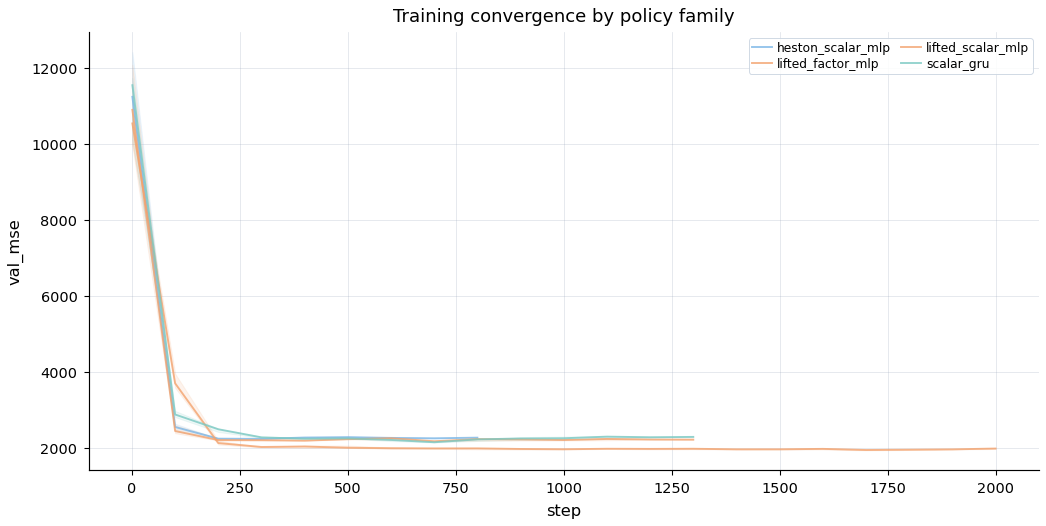

,policy,rows,loss_column_plotted
0,heston_scalar_mlp,26,val_mse
1,lifted_factor_mlp,56,val_mse
2,lifted_scalar_mlp,37,val_mse
3,scalar_gru,40,val_mse


In [40]:
# Training convergence curves from cached logs

def _read_dataframe_if_present(path: Path) -> pd.DataFrame:
    path = Path(path)
    if not path.exists() or path.stat().st_size == 0:
        return pd.DataFrame()
    return pd.read_parquet(path) if path.suffix.lower() == ".parquet" else pd.read_csv(path)


def _write_reporting_cache_warning(
    cfg: ExperimentConfig,
    artefact_name: str,
    path: Path,
    reason: Exception,
    frame: pd.DataFrame,
) -> None:
    warning = pd.DataFrame([{
        "artefact": artefact_name,
        "path": str(path),
        "mode": str(globals().get("RUN_MODE", "")),
        "validation_status": "loaded_for_reporting_after_manifest_mismatch",
        "reason": str(reason),
        "n_rows": int(len(frame)),
        "n_columns": int(frame.shape[1]),
    }])
    warning.to_csv(table_path(f"{artefact_name}_reporting_cache_warning.csv", cfg), index=False)


def load_training_history_frame(cfg: ExperimentConfig) -> pd.DataFrame:
    """
    Load neural training history for appendix convergence plots.

    Training history is a reporting artefact. In cached-evaluation mode, a stale
    manifest should not trigger retraining or block the final results if the file
    exists and has the required schema.
    """
    required = {"policy", "training_seed", "step", "train_mse", "val_mse"}
    live = globals().get("training_history")
    if isinstance(live, pd.DataFrame) and not live.empty:
        return live.copy()

    try:
        return load_dataframe_cache(
            cfg.paths.training_history_path,
            "neural_training_history",
            "training",
            cfg,
            required_columns=required,
            dependencies=globals().get("training_history_dependencies", []),
        )
    except (FileNotFoundError, ValueError, json.JSONDecodeError) as exc:
        if str(globals().get("RUN_MODE", "")).lower() != "cached_evaluation":
            raise

        frame = _read_dataframe_if_present(cfg.paths.training_history_path)
        if frame.empty:
            return pd.DataFrame(columns=sorted(required))

        missing = required.difference(frame.columns)
        if missing:
            return pd.DataFrame([{
                "item": "training_convergence_curves",
                "status": "missing_columns",
                "notes": f"training history exists but is missing columns: {sorted(missing)}",
            }])

        _write_reporting_cache_warning(
            cfg,
            "training_history",
            cfg.paths.training_history_path,
            exc,
            frame,
        )
        return frame


def plot_training_convergence(history: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if history is None or history.empty:
        out = pd.DataFrame([{
            "item": "training_convergence_curves",
            "status": "missing",
            "notes": "training_history cache not available; convergence plots are optional appendix diagnostics",
        }])
        out.to_csv(table_path("training_convergence_audit.csv", cfg), index=False)
        return out

    h = history.copy()
    epoch = _choose_col(h, ["epoch", "step", "iteration"])
    loss_cols = [c for c in ["val_mse", "validation_mse", "train_mse", "train_loss", "validation_loss", "val_loss", "objective", "loss"] if c in h.columns]
    policy_col = _choose_col(h, ["policy", "policy_name", "model_name", "spec_name"])
    seed_col = _choose_col(h, ["training_seed", "seed", "run_id"])

    if not epoch or not loss_cols or not policy_col:
        out = pd.DataFrame([{
            "item": "training_convergence_curves",
            "status": "missing_columns",
            "notes": f"epoch={epoch}; losses={loss_cols}; policy={policy_col}",
        }])
        out.to_csv(table_path("training_convergence_audit.csv", cfg), index=False)
        return out

    plot_loss = loss_cols[0]
    h[epoch] = pd.to_numeric(h[epoch], errors="coerce")
    h[plot_loss] = pd.to_numeric(h[plot_loss], errors="coerce")
    h = h.dropna(subset=[epoch, plot_loss, policy_col]).copy()

    if MATPLOTLIB_AVAILABLE and not h.empty:
        fig, ax = plt.subplots(figsize=(8.2, 4.2))
        for policy, group in h.groupby(policy_col):
            g = group.copy()
            agg = g.groupby(epoch)[plot_loss].agg(median="median", q25=lambda s: np.nanquantile(s, 0.25), q75=lambda s: np.nanquantile(s, 0.75)).reset_index().sort_values(epoch)
            x = pd.to_numeric(agg[epoch], errors="coerce")
            y = pd.to_numeric(agg["median"], errors="coerce")
            ax.plot(x, y, linewidth=1.05, alpha=MODEL_ALPHA, label=str(policy)[:35], color=model_color(policy), linestyle="-")
            if seed_col and g[seed_col].nunique(dropna=True) > 1:
                ax.fill_between(x, pd.to_numeric(agg["q25"], errors="coerce"), pd.to_numeric(agg["q75"], errors="coerce"), color=model_color(policy), alpha=0.12)
        ax.set_title("Training convergence by policy family")
        ax.set_xlabel(epoch)
        ax.set_ylabel(plot_loss)
        ax.grid(True, alpha=0.3)
        compact_legend(ax, ncol=2)
        path = figure_path("training_convergence_by_policy_family.png", cfg)
        save_and_show_figure(fig, path, dpi=160)

    summary = h.groupby(policy_col, as_index=False).agg(rows=(policy_col, "size"))
    summary["loss_column_plotted"] = plot_loss
    summary.to_csv(table_path("training_convergence_summary.csv", cfg), index=False)
    return summary


training_history_for_plots = load_training_history_frame(CFG)
training_convergence_summary = plot_training_convergence(training_history_for_plots, CFG)
display(training_convergence_summary.head())

# 11. Evaluation

Evaluation is the headline empirical stage. It tests fixed trained policies and analytic benchmarks on held-out seed dates. It should not recalibrate models, rebuild surfaces, retrain networks or change the seed panel. A reporting run should evaluate the evidence, not rewrite history because downstream figures are being regenerated.

The main outcome is terminal net hedging error under transaction costs. The notebook reports RMSE, gross RMSE, net RMSE, bias, standard deviation, VaR, CVaR, turnover, realised cost, drawdown and policy win rates where available. These metrics answer different parts of the hedging question. RMSE measures average squared error, CVaR captures tail loss, turnover and realised cost capture implementability, and win rates show whether a policy improvement is broad or concentrated in a few dates.

The correct comparison unit is the held-out market date or seed row, not individual Monte Carlo paths. Paths within a date share the same calibrated state and are conditionally generated from the same world. Therefore confidence intervals should use date-clustered bootstrap when possible.

The evaluation logic is:

$$
\text{fixed policy} + \text{held-out calibrated state} + \text{transaction costs}
\rightarrow
\text{terminal risk distribution}.
$$

This is where the dissertation's main claims should be made or refused.


## 11.1 Tractable Strict Model-Delta Benchmark Diagnostic

Model-delta benchmarks are important because they represent the natural analytic hedge implied by the calibrated stochastic-volatility model. They prevent the neural policies from being compared only against weak baselines such as no hedge or Black-Scholes delta.

The strict qualifier matters. Model deltas are reported only where the delta engine passes admissibility checks and where the required calibrated inputs are available. This can create a subset of test rows. The notebook should therefore report coverage and avoid overinterpreting model-delta comparisons as full-panel paired dominance when they are not.

A model-delta hedge targets

$$
\Delta_t^* = \frac{\partial P_{\mathrm{model}}(S_t,V_t,T-t)}{\partial S_t}.
$$

In continuous frictionless theory, this is the hedge ratio. In the notebook's discrete costly setting, it is a benchmark rather than an oracle. It trades mechanically and may incur high turnover. That is why no-trade-band variants are evaluated separately.

Interpretation should focus on benchmark discipline. If neural policies beat no hedge but not model delta, the result is weaker. If they beat model delta net of costs and with comparable tail risk, the evidence is much stronger.


In [41]:

# ============================================================
# Tractable strict model-delta benchmark diagnostic
# ============================================================

MODEL_DELTA_BENCHMARK_DIAGNOSTIC_VERSION = "model_delta_benchmark_diagnostic_v1_reduced_strict_delta"
RUN_MODEL_DELTA_BENCHMARK_DIAGNOSTIC = str(globals().get("RUN_MODE", "")).lower() in {
    "completion_benchmarks", "benchmark_completion", "benchmark_completion_fast"
}


def _benchmark_diagnostic_seed_table(seed_panel: pd.DataFrame, cfg: ExperimentConfig, split: str = "test") -> pd.DataFrame:
    per_bucket = _benchmark_env_int("DEEP_HEDGING_BENCHMARK_TEST_SEEDS_PER_BUCKET", 1)
    table = balanced_seed_table_by_bucket(
        seed_panel.loc[seed_panel["split"].eq(split)],
        cfg,
        per_bucket=per_bucket,
    ).reset_index(drop=True)
    if table.empty:
        raise ValueError(f"No {split} seeds available for reduced benchmark diagnostic.")
    return table


def _diagnostic_rows_done(path: Path) -> pd.DataFrame:
    return _read_partial_rows(path)


def _benchmark_no_trade_band_table_available(bands: pd.DataFrame) -> bool:
    """Order-safe local no-trade-band table check for reduced diagnostics.

    The reduced benchmark cell executes before the legacy production-evaluation cell, so it must not rely
    on `_no_trade_band_table_available(...)` being defined later. Keep this local helper deliberately small.
    """
    return (
        isinstance(bands, pd.DataFrame)
        and not bands.empty
        and {"model_world", "transaction_cost_bps", "selected_band_width"}.issubset(bands.columns)
    )


def _benchmark_evaluation_row(
    result: dict[str, np.ndarray | float],
    seed_row: pd.Series,
    policy: str,
    simulation_world: str,
    transaction_cost_bps: float,
    *,
    selected_band_width: float | None = None,
) -> dict[str, Any]:
    """Order-safe evaluation-row constructor for reduced benchmark diagnostics.

    This mirrors the production `_evaluation_row(...)` schema without depending on the later evaluation
    cell. That avoids NameErrors when completion-benchmark mode runs the reduced benchmark section first.
    """
    row = summarise_hedging_errors(result)
    row.update({
        "seed_id": seed_row["seed_id"],
        "date": pd.Timestamp(seed_row["date"]).normalize(),
        "maturity_bucket": str(seed_row["hedge_maturity_bucket"]),
        "policy": policy,
        "simulation_world": simulation_world,
        "training_world": "analytic",
        "cross_world": False,
        "training_seed": -1,
        "transaction_cost_bps": float(transaction_cost_bps),
        "selected_band_width": np.nan if selected_band_width is None else float(selected_band_width),
    })
    return row


def run_reduced_model_delta_benchmark_diagnostic(seed_panel: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts, bands: pd.DataFrame) -> pd.DataFrame:
    n_paths = min(
        int(cfg.hedging.n_paths_test),
        _benchmark_env_int("DEEP_HEDGING_BENCHMARK_TEST_N_PATHS", _benchmark_env_int("DEEP_HEDGING_BENCHMARK_N_PATHS", 512)),
    )
    worlds = _benchmark_env_worlds(("heston", "lifted"))
    test = _benchmark_diagnostic_seed_table(seed_panel, cfg, split="test")
    partial_path = _benchmark_partial_raw_path(cfg, "model_delta_benchmark_diagnostic_partial")
    partial = _diagnostic_rows_done(partial_path)
    rows = partial.to_dict("records") if not partial.empty else []
    processed = set()
    if not partial.empty and {"model_world", "seed_id"}.issubset(partial.columns):
        processed = set(zip(partial["model_world"].astype(str), partial["seed_id"].astype(str)))
    print(
        f"[model-delta diagnostic] start | test_seeds={len(test)} | n_paths={n_paths} | worlds={list(worlds)} | "
        f"partial_rows={len(rows)} | partial_path={partial_path}",
        flush=True,
    )
    failures = []
    total_jobs = len(worlds) * len(test)
    job = 0
    for world in worlds:
        for _, seed_row in test.iterrows():
            job += 1
            seed_id = str(seed_row.get("seed_id", "?"))
            bucket = str(seed_row.get("hedge_maturity_bucket", "?"))
            prefix = f"[model-delta diagnostic {job}/{total_jobs}] world={world} | seed_id={seed_id} | bucket={bucket}"
            if (str(world), seed_id) in processed:
                print(f"{prefix} | partial cache hit; skipping", flush=True)
                continue
            try:
                sim_t0 = time.perf_counter()
                print(f"{prefix} | simulate_paths start | n_paths={n_paths}", flush=True)
                paths = simulate_paths_for_world(
                    seed_row, world, cfg, artifacts,
                    n_paths=int(n_paths),
                    seed=common_path_seed(seed_row, f"model_delta_benchmark_diagnostic_{n_paths}", cfg),
                )
                sim_s = time.perf_counter() - sim_t0
                md_t0 = time.perf_counter()
                print(f"{prefix} | model_delta_policy start after simulation={sim_s:.2f}s", flush=True)
                target = model_delta_policy(paths, world, seed_row, cfg, artifacts)
                md_s = time.perf_counter() - md_t0
                if np.any(~np.isfinite(target)):
                    raise FloatingPointError("model_delta_policy returned non-finite hedge targets")
                print(f"{prefix} | model_delta_policy done={md_s:.2f}s | evaluating policies", flush=True)
            except (FloatingPointError, OverflowError, ValueError, RuntimeError, np.linalg.LinAlgError, KeyError) as exc:
                print(f"{prefix} | FAILED: {str(exc)[:260]}", flush=True)
                failures.append({
                    "model_world": world,
                    "seed_id": seed_id,
                    "date": seed_row.get("date", pd.NaT),
                    "maturity_bucket": bucket,
                    "failure_reason": str(exc)[:1000],
                })
                continue
            local_rows = []
            for tc in cfg.hedging.transaction_cost_bps:
                policies: dict[str, tuple[np.ndarray, float | None]] = {f"{world}_model_delta": (target, None)}
                if _benchmark_no_trade_band_table_available(bands):
                    try:
                        band = selected_band_for_world(world, float(tc), cfg, bands)
                        policies[f"{world}_model_delta_no_trade_band"] = (apply_no_trade_band(target, band), float(band))
                    except Exception as exc:
                        print(f"{prefix} | no-trade-band unavailable for tc={float(tc):g}: {str(exc)[:180]}", flush=True)
                for policy_name, (hedge, selected_band) in policies.items():
                    result = stock_only_hedging_pnl_np(paths, hedge, tc, seed_entry_premium(seed_row))
                    row = _benchmark_evaluation_row(
                        result,
                        seed_row,
                        policy_name,
                        world,
                        float(tc),
                        selected_band_width=selected_band,
                    )
                    row.update({
                        "benchmark_diagnostic_version": MODEL_DELTA_BENCHMARK_DIAGNOSTIC_VERSION,
                        "benchmark_n_paths": int(n_paths),
                        "benchmark_mode": "strict_delta_reduced_diagnostic",
                    })
                    local_rows.append(row)
            rows.extend(local_rows)
            _write_partial_rows(pd.DataFrame(rows), partial_path)
            print(f"{prefix} | rows_added={len(local_rows)} | partial_rows={len(rows)}", flush=True)
    out = pd.DataFrame(rows)
    cfg.paths.output_dir.mkdir(parents=True, exist_ok=True)
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    if failures:
        pd.DataFrame(failures).to_csv(cfg.paths.table_dir / "model_delta_benchmark_diagnostic_failures.csv", index=False)
        print(f"[model-delta diagnostic] WARNING: failures saved to {cfg.paths.table_dir / 'model_delta_benchmark_diagnostic_failures.csv'}", flush=True)
    if out.empty:
        raise RuntimeError("Reduced model-delta benchmark diagnostic produced no rows.")
    out_path = cfg.paths.output_dir / "model_delta_benchmark_diagnostic.parquet"
    out.to_parquet(out_path, index=False)
    out.to_csv(cfg.paths.table_dir / "model_delta_benchmark_diagnostic_seed_level.csv", index=False)
    summary = out.groupby(["simulation_world", "policy", "transaction_cost_bps"], as_index=False).agg(
        mse=("mse", "mean"),
        rmse=("rmse", "mean"),
        mean_error=("mean_error", "mean"),
        std_error=("std_error", "mean"),
        mean_transaction_costs=("mean_transaction_costs", "mean"),
        mean_turnover=("mean_turnover", "mean"),
        seeds=("seed_id", "nunique"),
        benchmark_n_paths=("benchmark_n_paths", "max"),
    )
    summary.to_csv(cfg.paths.table_dir / "model_delta_benchmark_diagnostic_summary.csv", index=False)
    print(f"[model-delta diagnostic] complete | rows={len(out)} | saved={out_path}", flush=True)
    display(summary)
    return out


def ensure_no_trade_band_validation_available(
    seed_panel: pd.DataFrame,
    cfg: ExperimentConfig,
    artifacts: ResearchArtifacts,
) -> pd.DataFrame:
    """Return the no-trade-band table before reduced benchmark diagnostics run.

    The reduced diagnostic cell executes before the legacy production-evaluation cell that used to create
    `no_trade_band_validation`. Relying on that later global caused a NameError in completion mode. This
    helper makes the dependency explicit: load the cache if present, or build the reduced diagnostic band
    table using `load_or_select_no_trade_bands(...)` when the relevant flag is enabled.
    """
    existing = globals().get("no_trade_band_validation")
    if isinstance(existing, pd.DataFrame) and not existing.empty:
        print(f"[benchmark completion fast] using existing no_trade_band_validation rows={len(existing)}", flush=True)
        return existing

    if "load_or_select_no_trade_bands" not in globals() or not callable(globals()["load_or_select_no_trade_bands"]):
        raise RuntimeError(
            "Reduced model-delta benchmark diagnostic needs no_trade_band_validation, but "
            "load_or_select_no_trade_bands(...) is not defined yet. Run the strict delta/no-trade-band "
            "helper cell before this diagnostic cell."
        )

    print("[benchmark completion fast] ensuring no-trade-band validation table is available...", flush=True)
    bands = load_or_select_no_trade_bands(seed_panel, cfg, artifacts)
    if not isinstance(bands, pd.DataFrame):
        raise RuntimeError("load_or_select_no_trade_bands(...) did not return a DataFrame.")
    globals()["no_trade_band_validation"] = bands
    print(f"[benchmark completion fast] no-trade-band validation ready rows={len(bands)}", flush=True)
    return bands


def _read_table_if_exists_local(path: Path) -> pd.DataFrame:
    path = Path(path)
    if not path.exists():
        return pd.DataFrame()
    if path.suffix.lower() == ".parquet":
        return pd.read_parquet(path)
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    raise ValueError(f"Unsupported table path: {path}")


if RUN_MODEL_DELTA_BENCHMARK_DIAGNOSTIC:
    print("[benchmark completion fast] running reduced strict model-delta/no-trade-band benchmark diagnostic", flush=True)
    no_trade_band_validation = ensure_no_trade_band_validation_available(seed_panel, CFG, RESEARCH_ARTIFACTS)
    model_delta_benchmark_diagnostic = run_reduced_model_delta_benchmark_diagnostic(
        seed_panel,
        CFG,
        RESEARCH_ARTIFACTS,
        no_trade_band_validation,
    )
else:
    model_delta_benchmark_diagnostic = _read_table_if_exists_local(CFG.paths.output_dir / "model_delta_benchmark_diagnostic.parquet")


In [42]:
# ============================================================
# Within-world and cross-world evaluation with common paths
# ============================================================


def ensure_calibration_quality_gate_cache(cfg: ExperimentConfig) -> pd.DataFrame:
    """Load the calibration-quality gate. Rebuild only in explicit panel/calibration modes."""
    deps = [cfg.paths.heston_calibration_path, cfg.paths.lifted_calibration_path]
    try:
        gate = load_dataframe_cache(
            cfg.paths.calibration_quality_path,
            "calibration_quality_gate",
            "seed_panel",
            cfg,
            required_columns={"date", "accepted_for_hedging", "exclusion_reason", "gate_version"},
            dependencies=deps,
        )
        expected_version = globals().get("CALIBRATION_QUALITY_GATE_VERSION")
        if expected_version is not None and set(gate["gate_version"].dropna().astype(str).unique()) != {str(expected_version)}:
            raise ValueError("Calibration quality gate cache uses a stale gate version.")
        return gate
    except (FileNotFoundError, ValueError, json.JSONDecodeError) as exc:
        can_rebuild = bool(
            cfg.flags.RUN_SIMULATION_FEASIBILITY_SCAN
            or cfg.flags.RUN_HESTON_CALIBRATION
            or cfg.flags.RUN_LIFTED_CALIBRATION
        )
        if not can_rebuild:
            raise RuntimeError(
                "Calibration quality gate cache is missing or stale. Cached evaluation will not rebuild panel-selection diagnostics. "
                "Run an explicit panel/calibration diagnostic pass first."
            ) from exc
        builder = globals().get("build_calibration_quality_gate")
        heston = globals().get("heston_calibration")
        lifted = globals().get("lifted_calibration")
        if not callable(builder) or heston is None or lifted is None:
            raise RuntimeError("Calibration quality gate builder or calibration tables are unavailable.") from exc
        gate = builder(heston, lifted, cfg)
        write_dataframe_cache(gate, cfg.paths.calibration_quality_path, "calibration_quality_gate", "seed_panel", cfg, dependencies=deps)
        globals()["calibration_quality_gate"] = gate
        return gate

def assert_core_evaluation_inputs(seed_panel: pd.DataFrame, cfg: ExperimentConfig) -> None:
    require_columns(seed_panel, {"seed_id", "date", "split", "hedge_maturity_bucket", "straddle_mid", "iv_market", "spot_ref"}, "Seed panel")
    present = set(seed_panel["hedge_maturity_bucket"].dropna().astype(str))
    missing = set(cfg.hedging.maturity_buckets) - present
    if missing:
        raise ValueError(f"Missing maturity buckets in seed panel: {sorted(missing)}")
    for col in ["straddle_mid", "iv_market", "spot_ref"]:
        values = seed_panel[col].to_numpy(float)
        if np.any(~np.isfinite(values)) or np.any(values <= 0):
            raise ValueError(f"Seed panel contains invalid {col} values.")
    ensure_calibration_quality_gate_cache(cfg)
    if TORCH_AVAILABLE:
        assert_all_core_checkpoints(cfg)


if TORCH_AVAILABLE:
    def load_trained_torch_policy(spec: PolicySpec, training_seed: int, cfg: ExperimentConfig) -> tuple[nn.Module, FeatureScaler]:
        if not checkpoint_is_valid(spec, training_seed, cfg):
            raise FileNotFoundError(model_checkpoint_path(spec, training_seed, cfg))
        checkpoint = torch.load(model_checkpoint_path(spec, training_seed, cfg), map_location=DEVICE)
        feature_scaler = scaler_from_checkpoint(checkpoint.get("feature_scaler"))
        model = make_torch_model(spec, int(checkpoint["input_dim"]), cfg).to(DEVICE)
        model.load_state_dict(checkpoint["state_dict"])
        model.eval()
        return model, feature_scaler


    def neural_hedges_on_paths(model: nn.Module, spec: PolicySpec, paths: dict[str, np.ndarray], cfg: ExperimentConfig, feature_scaler: FeatureScaler, artifacts: ResearchArtifacts) -> np.ndarray:
        with torch.no_grad():
            base = build_policy_base_features_torch(paths, spec, cfg, artifacts.lifted_kernel, device=DEVICE)
            base = apply_feature_scaler_torch(base, feature_scaler, device=DEVICE)
        with torch.no_grad(), torch.amp.autocast(AMP_DEVICE_TYPE, enabled=AMP_ENABLED):
            hedge = rollout_torch_policy(model, spec, base)
        return hedge.detach().cpu().numpy()



def attach_neural_evaluation_feature_path(
    paths: dict[str, np.ndarray],
    spec: PolicySpec,
    simulation_world: str,
    seed_row: pd.Series,
    cfg: ExperimentConfig,
    artifacts: ResearchArtifacts,
) -> dict[str, np.ndarray]:
    """Attach the fast audited neural delta feature during evaluation.

    There is deliberately no fallback to the strict benchmark finite-difference engine here.
    Neural evaluation must stay tractable and must use the same fast feature engine as training.
    """
    fn = globals().get("attach_fast_neural_model_delta_path")
    if not callable(fn):
        raise RuntimeError("Fast neural delta feature helper is missing; refusing to fall back to strict benchmark deltas.")
    return fn(paths, spec, simulation_world, seed_row, cfg, artifacts)



def _evaluation_row(
    result: dict[str, np.ndarray | float],
    seed_row: pd.Series,
    policy: str,
    simulation_world: str,
    transaction_cost_bps: float,
    *,
    training_world: str,
    training_seed: int | None,
    selected_band_width: float | None = None,
) -> dict[str, Any]:
    row = summarise_hedging_errors(result)
    row.update({
        "seed_id": seed_row["seed_id"],
        "date": pd.Timestamp(seed_row["date"]).normalize(),
        "maturity_bucket": str(seed_row["hedge_maturity_bucket"]),
        "policy": policy,
        "simulation_world": simulation_world,
        "training_world": training_world,
        "cross_world": bool(training_world not in {"analytic", "both", simulation_world}),
        "training_seed": -1 if training_seed is None else int(training_seed),
        "transaction_cost_bps": float(transaction_cost_bps),
        "selected_band_width": np.nan if selected_band_width is None else float(selected_band_width),
    })
    return row


def _flag_enabled(cfg: ExperimentConfig, name: str, default: bool = False) -> bool:
    """Read optional boolean flags without requiring the config dataclass to define them."""
    return bool(getattr(getattr(cfg, "flags", object()), name, default))


def _no_trade_band_table_available(bands: pd.DataFrame) -> bool:
    return (
        isinstance(bands, pd.DataFrame)
        and not bands.empty
        and {"model_world", "transaction_cost_bps", "selected_band_width"}.issubset(bands.columns)
    )


def _slow_model_delta_benchmarks_enabled(cfg: ExperimentConfig) -> bool:
    """Slow analytic model-delta benchmarks are opt-in.

    They use the strict benchmark model-delta engine, including Heston finite-difference recovery.
    That is methodologically fine for a benchmark, but it must not silently block neural evaluation.
    """
    return _flag_enabled(cfg, "RUN_SLOW_MODEL_DELTA_BENCHMARKS", False)


def _maybe_print_model_delta_skip_notice(cfg: ExperimentConfig, bands: pd.DataFrame) -> None:
    key = "_MODEL_DELTA_BENCHMARK_SKIP_NOTICE_PRINTED"
    if globals().get(key, False):
        return
    if not _slow_model_delta_benchmarks_enabled(cfg):
        print(
            "Skipping slow analytic model-delta and model-delta no-trade-band baselines. "
            "Core evaluation will still include no-hedge, Black-Scholes delta and neural policies. "
            "Set CFG.flags.RUN_SLOW_MODEL_DELTA_BENCHMARKS=True after a no-trade-band cache exists if you explicitly want these optional baselines.",
            flush=True,
        )
        globals()[key] = True
    elif not _no_trade_band_table_available(bands):
        print(
            "Slow model-delta benchmarks were requested, but no no-trade-band table is available; "
            "skipping model-delta no-trade-band baselines.",
            flush=True,
        )
        globals()[key] = True


def analytic_policy_rows(seed_row: pd.Series, paths: dict[str, np.ndarray], simulation_world: str, cfg: ExperimentConfig, bands: pd.DataFrame, artifacts: ResearchArtifacts) -> list[dict[str, Any]]:
    entry_iv = seed_entry_iv(seed_row)
    rows = []
    include_model_delta = _slow_model_delta_benchmarks_enabled(cfg)
    include_no_trade_band = include_model_delta and _no_trade_band_table_available(bands)
    if not include_model_delta:
        _maybe_print_model_delta_skip_notice(cfg, bands)
    elif not include_no_trade_band:
        _maybe_print_model_delta_skip_notice(cfg, bands)

    for tc in cfg.hedging.transaction_cost_bps:
        policies = {
            "no_hedge": np.zeros_like(paths["S"]),
            "black_scholes_delta": analytic_delta_policy(paths, entry_iv),
        }
        band = None

        if include_model_delta:
            try:
                target = model_delta_policy(paths, simulation_world, seed_row, cfg, artifacts)
                policies[f"{simulation_world}_model_delta"] = target
                if include_no_trade_band:
                    band = selected_band_for_world(simulation_world, tc, cfg, bands)
                    policies[f"{simulation_world}_model_delta_no_trade_band"] = apply_no_trade_band(target, band)
            except (FloatingPointError, OverflowError, ValueError, RuntimeError, KeyError, np.linalg.LinAlgError) as exc:
                print(
                    f"Skipping {simulation_world} model-delta benchmark for seed_id={seed_row.get('seed_id', '?')} "
                    f"tc={float(tc):g}: {str(exc)[:220]}",
                    flush=True,
                )

        for name, hedge in policies.items():
            result = stock_only_hedging_pnl_np(paths, hedge, tc, seed_entry_premium(seed_row))
            rows.append(
                _evaluation_row(
                    result,
                    seed_row,
                    name,
                    simulation_world,
                    tc,
                    training_world="analytic",
                    training_seed=None,
                    selected_band_width=band if "no_trade_band" in name else None,
                )
            )
    return rows


def policy_allowed_in_world(spec: PolicySpec, simulation_world: str, cfg: ExperimentConfig) -> bool:
    if spec.architecture == "analytic" or not spec.is_core:
        return False
    if spec.uses_factors and simulation_world != "lifted":
        return False
    if simulation_world == spec.training_world:
        return True
    # Cross-world neural transfer must not change the policy's input information set.
    # Heston-trained scalar policies can be tested on lifted paths because lifted paths expose S and aggregate V.
    # Lifted-trained scalar policies cannot be tested on Heston paths without fabricating U-dependent lifted deltas.
    return bool(cfg.hedging.cross_world_evaluation and (spec.training_world == "heston") and (simulation_world == "lifted") and not spec.uses_factors)



def all_core_checkpoint_paths(cfg: ExperimentConfig) -> list[Path]:
    if not TORCH_AVAILABLE:
        return []
    return [
        model_checkpoint_path(spec, int(training_seed), cfg)
        for spec in active_neural_policy_specs()
        for training_seed in cfg.hedging.training_seeds
    ]

EVALUATION_PIPELINE_VERSION = "evaluation_pipeline_v5_terminal_pnl_drawdown_economic_metrics"


def evaluation_cache_dependencies(cfg: ExperimentConfig, bands: pd.DataFrame) -> list[Path]:
    deps = neural_input_dependencies(cfg) + [cfg.paths.simulation_validation_path] + all_core_checkpoint_paths(cfg)
    if _slow_model_delta_benchmarks_enabled(cfg):
        deps.append(cfg.paths.model_delta_validation_path)
    if _no_trade_band_table_available(bands):
        deps.append(cfg.paths.no_trade_band_path)
    return deps


def evaluation_cache_extra(cfg: ExperimentConfig, bands: pd.DataFrame) -> dict[str, Any]:
    return {
        "evaluation_pipeline_version": EVALUATION_PIPELINE_VERSION,
        "tensor_batch_pipeline_version": globals().get("TENSOR_BATCH_PIPELINE_VERSION", "missing"),
        "neural_delta_feature_engine_version": globals().get("NEURAL_DELTA_FEATURE_ENGINE_VERSION", "missing"),
        "slow_model_delta_benchmarks_enabled": bool(_slow_model_delta_benchmarks_enabled(cfg)),
        "no_trade_band_table_available": bool(_no_trade_band_table_available(bands)),
    }


def assert_strict_model_delta_gate_for_optional_benchmarks(cfg: ExperimentConfig) -> None:
    if not _slow_model_delta_benchmarks_enabled(cfg):
        return
    table = load_dataframe_cache(
        cfg.paths.model_delta_validation_path,
        "model_delta_validation",
        "simulation_validation",
        cfg,
        dependencies=[cfg.paths.seed_panel_path, cfg.paths.heston_calibration_path, cfg.paths.lifted_calibration_path, cfg.paths.forward_variance_path],
    )
    if table.empty or "pass" not in table.columns or not table["pass"].fillna(False).astype(bool).all():
        failed = table.loc[~table.get("pass", pd.Series(dtype=bool)).fillna(False)] if not table.empty else table
        raise RuntimeError("Slow model-delta benchmarks require a passing strict model-delta validation table.\n" + failed.to_string(index=False))



def run_production_evaluation(seed_panel: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts, bands: pd.DataFrame) -> pd.DataFrame:
    if not TORCH_AVAILABLE:
        raise RuntimeError("PyTorch is required for neural-policy evaluation.")
    assert_core_evaluation_inputs(seed_panel, cfg)
    assert_strict_model_delta_gate_for_optional_benchmarks(cfg)
    test = balanced_seed_table(seed_panel.loc[seed_panel["split"].eq("test")], cfg)
    test = limit_seed_table_preserving_maturity_coverage(
        test,
        cfg,
        cfg.hedging.max_evaluation_seeds,
        label="test evaluation seeds",
    )
    rows: list[dict[str, Any]] = []
    active_specs = active_neural_policy_specs()
    loaded_models = {
        (spec.name, int(training_seed)): load_trained_torch_policy(spec, int(training_seed), cfg)
        for spec in active_specs
        for training_seed in cfg.hedging.training_seeds
    }
    backend = "torch_cuda" if TORCH_AVAILABLE and torch.cuda.is_available() else "torch_cpu"
    for i, (_, seed_row) in enumerate(test.iterrows(), 1):
        seed_id = seed_row['seed_id']
        bucket = seed_row['hedge_maturity_bucket']
        print(f"[evaluation test {i}/{len(test)}] seed_id={seed_id} bucket={bucket} backend={backend}", flush=True)
        path_seed = common_path_seed(seed_row, "test_common_random_numbers", cfg)
        for simulation_world in ["heston", "lifted"]:
            world_t0 = time.perf_counter()
            sim_t0 = time.perf_counter()
            paths = simulate_paths_for_world(seed_row, simulation_world, cfg, artifacts, n_paths=cfg.hedging.n_paths_test, seed=path_seed)
            simulation_seconds = time.perf_counter() - sim_t0
            analytic_t0 = time.perf_counter()
            rows.extend(analytic_policy_rows(seed_row, paths, simulation_world, cfg, bands, artifacts))
            analytic_seconds = time.perf_counter() - analytic_t0
            feature_path_cache: dict[tuple[str, str], dict[str, np.ndarray]] = {}
            neural_seconds = 0.0
            feature_seconds = 0.0
            for spec in active_specs:
                if not policy_allowed_in_world(spec, simulation_world, cfg):
                    continue
                feature_key = (raw_feature_family_key(spec), policy_delta_information_world(spec, simulation_world))
                if feature_key not in feature_path_cache:
                    f_t0 = time.perf_counter()
                    feature_path_cache[feature_key] = attach_neural_evaluation_feature_path(paths, spec, simulation_world, seed_row, cfg, artifacts)
                    feature_seconds += time.perf_counter() - f_t0
                feature_paths = feature_path_cache[feature_key]
                for training_seed in cfg.hedging.training_seeds:
                    model, feature_scaler = loaded_models[(spec.name, int(training_seed))]
                    n_t0 = time.perf_counter()
                    hedges = neural_hedges_on_paths(model, spec, feature_paths, cfg, feature_scaler, artifacts)
                    neural_seconds += time.perf_counter() - n_t0
                    for tc in cfg.hedging.transaction_cost_bps:
                        result = stock_only_hedging_pnl_np(paths, hedges, tc, seed_entry_premium(seed_row))
                        rows.append(_evaluation_row(
                            result,
                            seed_row,
                            spec.name,
                            simulation_world,
                            tc,
                            training_world=spec.training_world,
                            training_seed=int(training_seed),
                        ))
            print(
                f"    [{simulation_world}] simulation={simulation_seconds:.2f}s | analytic={analytic_seconds:.2f}s | "
                f"neural_delta_features={feature_seconds:.2f}s | neural_rollout={neural_seconds:.2f}s | "
                f"total={time.perf_counter() - world_t0:.2f}s",
                flush=True,
            )
    out = pd.DataFrame(rows)
    if out.empty:
        raise RuntimeError("Evaluation produced no rows.")
    core_within = {
        (spec.name, spec.training_world)
        for spec in active_specs
    }
    present = set(zip(out.loc[~out["cross_world"], "policy"], out.loc[~out["cross_world"], "simulation_world"]))
    missing = sorted(core_within - present)
    if missing:
        raise ValueError(f"Evaluation is missing core within-world policy results: {missing}")
    write_dataframe_cache(
        out,
        cfg.paths.evaluation_path,
        "hedging_evaluation_results",
        "evaluation",
        cfg,
        dependencies=evaluation_cache_dependencies(cfg, bands),
        extra=evaluation_cache_extra(cfg, bands),
    )
    return out


def _read_existing_evaluation_results(cfg: ExperimentConfig) -> pd.DataFrame:
    """Read the frozen hedging evaluation artefact without triggering recomputation."""
    path = Path(cfg.paths.evaluation_path)
    if not path.exists() or path.stat().st_size == 0:
        raise FileNotFoundError(f"Evaluation cache file does not exist or is empty: {path}")
    frame = pd.read_parquet(path) if path.suffix.lower() == ".parquet" else pd.read_csv(path)
    if frame.empty:
        raise ValueError(f"Evaluation cache contains no rows: {path}")
    return frame


def _validate_loaded_evaluation_results(frame: pd.DataFrame) -> None:
    """Schema validation for cached hedging-evaluation reporting outputs."""
    if frame.empty:
        raise ValueError("Evaluation cache is empty.")

    identity_options = [
        {"policy", "world"},
        {"policy_name", "world"},
        {"policy", "simulation_world"},
        {"strategy", "world"},
    ]
    metric_options = {
        "mse", "rmse", "terminal_rmse", "net_rmse", "gross_rmse",
        "cvar_5", "cvar_5_loss", "pnl_mean", "pnl_std",
        "mean_cost", "realised_cost", "turnover",
    }

    if not any(cols.issubset(frame.columns) for cols in identity_options):
        raise ValueError("Evaluation cache lacks recognisable policy/world identifier columns.")
    if not any(col in frame.columns for col in metric_options):
        raise ValueError("Evaluation cache lacks recognisable hedging metric columns.")


def _write_evaluation_reporting_warning(cfg: ExperimentConfig, reason: Exception, frame: pd.DataFrame) -> None:
    """Record reporting-mode loads where strict dependency metadata has changed."""
    warning = pd.DataFrame([{
        "artefact": str(cfg.paths.evaluation_path),
        "mode": str(globals().get("RUN_MODE", "")),
        "validation_status": "loaded_for_reporting_after_manifest_mismatch",
        "reason": str(reason),
        "n_rows": int(len(frame)),
        "n_columns": int(frame.shape[1]),
    }])
    warning.to_csv(table_path("evaluation_cache_reporting_warning.csv", cfg), index=False)


def load_evaluation_cache(cfg: ExperimentConfig, bands: pd.DataFrame | None = None) -> pd.DataFrame:
    """
    Load frozen hedging-evaluation results.

    The preferred path is strict manifest validation. In ``cached_evaluation`` mode,
    if only dependency metadata has changed, the existing result file is accepted
    for reporting after schema validation. This keeps reporting runs from
    retraining or recomputing neural evaluation.
    """
    try:
        validate_cache_manifest(
            cfg.paths.evaluation_path,
            "hedging_evaluation_results",
            "evaluation",
            cfg,
            dependencies=evaluation_cache_dependencies(cfg, bands),
        )
        frame = _read_existing_evaluation_results(cfg)
        _validate_loaded_evaluation_results(frame)
        return frame

    except (FileNotFoundError, ValueError, json.JSONDecodeError) as exc:
        if str(globals().get("RUN_MODE", "")).lower() != "cached_evaluation":
            raise

        message = str(exc).lower()
        metadata_only_issue = any(
            token in message
            for token in ["dependency content fingerprint mismatch", "manifest", "fingerprint", "stale"]
        )
        if not metadata_only_issue:
            raise

        frame = _read_existing_evaluation_results(cfg)
        _validate_loaded_evaluation_results(frame)
        _write_evaluation_reporting_warning(cfg, exc, frame)
        print(
            "Loaded existing hedging evaluation cache for reporting after schema validation. "
            "Strict dependency metadata did not match the current notebook; see "
            "evaluation_cache_reporting_warning.csv."
        )
        return frame


no_trade_band_validation = load_or_select_no_trade_bands(seed_panel, CFG, RESEARCH_ARTIFACTS)
display(no_trade_band_validation)
plot_no_trade_band_validation(no_trade_band_validation)

if CFG.flags.RUN_EVALUATION:
    evaluation_results = run_production_evaluation(seed_panel, CFG, RESEARCH_ARTIFACTS, no_trade_band_validation)
else:
    try:
        evaluation_results = load_evaluation_cache(CFG, no_trade_band_validation)
        print("Loaded validated hedging evaluation cache.")
    except (FileNotFoundError, ValueError) as exc:
        if str(globals().get("RUN_MODE", "")).lower() == "cached_evaluation":
            raise RuntimeError(
                "Cached evaluation mode requires an existing hedging evaluation cache. "
                "It will not recompute neural evaluation or require checkpoint files. "
                "Use an explicit training/evaluation run mode only when you want to rebuild evaluation results."
            ) from exc
        evaluation_results = pd.DataFrame()
        print("Evaluation cache is absent or stale; set RUN_EVALUATION=True only after neural checkpoints exist.")

display(evaluation_results.head())


[benchmark completion] checking no-trade-band validation cache...
[benchmark completion] no-trade-band cache unavailable/stale: ValueError: Dependency content fingerprint mismatch for no_trade_band_validation; rebuild required.
No-trade-band validation cache is absent or stale; skipping slow benchmark band selection. Set CFG.flags.RUN_NO_TRADE_BAND_VALIDATION=True only if you explicitly want to build this optional model-delta no-trade-band benchmark.


,band_width,model_world,no_trade_band_validation_version,selected_band_width,transaction_cost_bps,validation_mse


Loaded existing hedging evaluation cache for reporting after schema validation. Strict dependency metadata did not match the current notebook; see evaluation_cache_reporting_warning.csv.
Loaded validated hedging evaluation cache.


,mean_error,rmse,mse,mae,std_error,var_5_loss,cvar_5_loss,gross_rmse,gross_mse,mean_transaction_costs,mean_turnover,n_paths,sum_sq_error,sum_abs_error,pnl_mean,pnl_std,pnl_sharpe_unannualised,pnl_win_rate,pnl_loss_probability,pnl_p01,pnl_p05,pnl_p50,pnl_p95,pnl_p99,gross_pnl_mean,gross_pnl_std,gross_pnl_sharpe_unannualised,gross_pnl_p05,gross_pnl_p50,gross_pnl_p95,mean_payoff,premium,mean_transaction_cost_to_premium,pnl_mean_to_premium,pnl_std_to_premium,mean_max_drawdown,median_max_drawdown,p95_max_drawdown,max_drawdown,mean_terminal_drawdown,p95_terminal_drawdown,mean_min_pnl,p05_min_pnl,gross_mean_max_drawdown,gross_p95_max_drawdown,gross_mean_terminal_drawdown,mean_max_drawdown_to_premium,p95_max_drawdown_to_premium,seed_id,date,maturity_bucket,policy,simulation_world,training_world,cross_world,training_seed,transaction_cost_bps,selected_band_width
0,-0.946110,54.890793,3012.999189,39.070535,54.885383,106.335616,167.616038,54.890793,3012.999189,0.000000,0.000000,10000,3.012999e+07,390705.350430,-0.946110,54.885383,-0.017238,0.6000,0.4000,-207.618445,-106.335616,10.873756,57.631584,61.873589,-0.946110,54.885383,-0.017238,-106.335616,10.873756,57.631584,63.955658,62.95954,0.000000,-0.015027,0.871756,20.028334,0.000000,106.385624,479.276384,20.028334,106.385624,-20.008322,-106.335616,20.028334,106.385624,20.028334,0.318114,1.689746,2012-06-14_1M_1325,2012-06-14,1M,no_hedge,heston,analytic,False,-1,1.0,NaN
1,-1.406387,23.718844,562.583584,17.649779,23.678297,44.549556,64.981061,23.579796,556.006770,0.537763,4.057196,10000,5.625836e+06,176497.794639,-1.406387,23.678297,-0.059396,0.5275,0.4725,-78.790987,-44.549556,1.503773,30.997224,42.778078,-0.868453,23.564976,-0.036854,-43.811755,2.005201,31.416452,63.955658,62.95954,0.008541,-0.022338,0.376088,57.604666,44.542341,148.927284,479.354655,37.833584,138.857494,-29.258082,-78.833238,57.369704,148.811522,37.606036,0.914947,2.365444,2012-06-14_1M_1325,2012-06-14,1M,black_scholes_delta,heston,analytic,False,-1,1.0,NaN
2,-0.946110,54.890793,3012.999189,39.070535,54.885383,106.335616,167.616038,54.890793,3012.999189,0.000000,0.000000,10000,3.012999e+07,390705.350430,-0.946110,54.885383,-0.017238,0.6000,0.4000,-207.618445,-106.335616,10.873756,57.631584,61.873589,-0.946110,54.885383,-0.017238,-106.335616,10.873756,57.631584,63.955658,62.95954,0.000000,-0.015027,0.871756,20.028334,0.000000,106.385624,479.276384,20.028334,106.385624,-20.008322,-106.335616,20.028334,106.385624,20.028334,0.318114,1.689746,2012-06-14_1M_1325,2012-06-14,1M,no_hedge,heston,analytic,False,-1,5.0,NaN
3,-3.558126,24.399097,595.315919,17.927173,24.139468,47.741513,68.558690,23.579796,556.006770,2.688814,4.057196,10000,5.953159e+06,179271.731232,-3.558126,24.139468,-0.147399,0.4903,0.5097,-82.705770,-47.741513,-0.601404,29.290147,41.365789,-0.868453,23.564976,-0.036854,-43.811755,2.005201,31.416452,63.955658,62.95954,0.042707,-0.056514,0.383412,58.560520,45.653032,149.774591,479.667736,38.772744,139.601474,-30.663894,-81.561973,57.369704,148.811522,37.606036,0.930129,2.378902,2012-06-14_1M_1325,2012-06-14,1M,black_scholes_delta,heston,analytic,False,-1,5.0,NaN
4,-0.946110,54.890793,3012.999189,39.070535,54.885383,106.335616,167.616038,54.890793,3012.999189,0.000000,0.000000,10000,3.012999e+07,390705.350430,-0.946110,54.885383,-0.017238,0.6000,0.4000,-207.618445,-106.335616,10.873756,57.631584,61.873589,-0.946110,54.885383,-0.017238,-106.335616,10.873756,57.631584,63.955658,62.95954,0.000000,-0.015027,0.871756,20.028334,0.000000,106.385624,479.276384,20.028334,106.385624,-20.008322,-106.335616,20.028334,106.385624,20.028334,0.318114,1.689746,2012-06-14_1M_1325,2012-06-14,1M,no_hedge,heston,analytic,False,-1,10.0,NaN


## 11.2 Factor-Memory Extension Tests

This section tests whether lifted-factor information improves hedging beyond scalar variance and learned recurrence. The comparison is deliberately structured around information sets. A lifted scalar policy observes aggregate variance. A lifted factor policy observes factor composition. A recurrent scalar policy can learn memory from the path. These alternatives correspond to different hypotheses about where hedge-relevant memory lives.

The factor-memory question can be stated as:

$$
\mathcal{I}_t^{\mathrm{factor}} = \mathcal{I}_t^{\mathrm{scalar}} \cup \{z_t^1,\ldots,z_t^N\},
$$

where $z_t^i$ are normalised factor contributions. If these contributions contain useful information and the architecture can exploit it, terminal net risk should fall without an offsetting increase in turnover and transaction cost.

A negative or mixed result is still valuable. It may show that raw high-dimensional factor composition is too noisy, that compression is needed, that stock-only hedging cannot monetise the information, or that recurrent memory is a better representation under the tested design. The dissertation should frame this as mechanism evidence rather than as failure.


In [43]:
# ============================================================
# Factor-memory extension tests: dimensionality reduction, buckets, PCA and recurrent-factor policies
# ============================================================

FACTOR_MEMORY_EXTENSION_VERSION = "factor_memory_extension_v1_reduced_pca_buckets_regularised_recurrent"
FACTOR_MEMORY_PRODUCTION_EVALUATION_VERSION = "factor_memory_production_eval_v1_common_10000_test_paths"
_FACTOR_MEMORY_RUN_MODE = str(globals().get("RUN_MODE", "")).lower()
RUN_FACTOR_MEMORY_EXTENSIONS = (
    _FACTOR_MEMORY_RUN_MODE in {"factor_memory_extensions", "factor_memory_diagnostic", "factor_memory_production"}
    or os.environ.get("DEEP_HEDGING_RUN_FACTOR_MEMORY_EXTENSIONS", "0").strip().lower() in {"1", "true", "yes"}
)
_DEFAULT_FACTOR_MEMORY_EVAL_MODE = "production_10000_test_paths" if _FACTOR_MEMORY_RUN_MODE == "factor_memory_production" else "raw_tensor_test_bank"
FACTOR_MEMORY_EXTENSION_EVALUATION_MODE = os.environ.get(
    "DEEP_HEDGING_FACTOR_MEMORY_EVAL_MODE",
    _DEFAULT_FACTOR_MEMORY_EVAL_MODE,
).strip().lower()
FACTOR_MEMORY_EXTENSION_MAX_STEPS = int(os.environ.get("DEEP_HEDGING_FACTOR_MEMORY_STEPS", str(CFG.model.training_steps)))
FACTOR_MEMORY_EXTENSION_PRIMARY_TC = float(CFG.hedging.primary_transaction_cost_bps)

@dataclass(frozen=True)
class FactorMemoryExtensionSpec:
    name: str
    architecture: Literal["mlp", "gru"]
    representation: Literal["raw20", "buckets3", "pca3", "pca5"]
    weight_decay_multiplier: float = 1.0
    description: str = ""


FACTOR_MEMORY_EXTENSION_SPECS: tuple[FactorMemoryExtensionSpec, ...] = (
    FactorMemoryExtensionSpec("factor_raw20_mlp_wd1", "mlp", "raw20", 1.0, "raw 20-factor MLP extension baseline"),
    FactorMemoryExtensionSpec("factor_raw20_mlp_wd10", "mlp", "raw20", 10.0, "raw 20-factor MLP with stronger weight decay"),
    FactorMemoryExtensionSpec("factor_buckets3_mlp_wd1", "mlp", "buckets3", 1.0, "slow/medium/fast factor buckets"),
    FactorMemoryExtensionSpec("factor_buckets3_mlp_wd10", "mlp", "buckets3", 10.0, "slow/medium/fast buckets with stronger weight decay"),
    FactorMemoryExtensionSpec("factor_pca3_mlp_wd1", "mlp", "pca3", 1.0, "train-only PCA: 3 factor components"),
    FactorMemoryExtensionSpec("factor_pca5_mlp_wd1", "mlp", "pca5", 1.0, "train-only PCA: 5 factor components"),
    FactorMemoryExtensionSpec("factor_raw20_gru_wd10", "gru", "raw20", 10.0, "recurrent raw-factor architecture with stronger weight decay"),
    FactorMemoryExtensionSpec("factor_buckets3_gru_wd1", "gru", "buckets3", 1.0, "recurrent slow/medium/fast factor buckets"),
    FactorMemoryExtensionSpec("factor_pca3_gru_wd1", "gru", "pca3", 1.0, "recurrent train-only PCA factor architecture"),
)


def _factor_memory_training_seeds(cfg: ExperimentConfig) -> tuple[int, ...]:
    raw = os.environ.get("DEEP_HEDGING_FACTOR_MEMORY_TRAINING_SEEDS", "").strip()
    if raw:
        return tuple(int(x.strip()) for x in raw.split(",") if x.strip())
    return tuple(int(x) for x in cfg.hedging.training_seeds)


def _factor_source_spec() -> PolicySpec:
    for spec in POLICY_SPECS:
        if spec.name == "lifted_factor_mlp":
            return spec
    raise RuntimeError("Cannot find lifted_factor_mlp source spec for prebuilt lifted factor tensor banks.")


def _factor_feature_names(n_factors: int) -> tuple[str, ...]:
    return tuple(f"factor_contribution_{i + 1}" for i in range(int(n_factors)))


def _extension_base_feature_names() -> tuple[str, ...]:
    return ("log_moneyness", "tau_fraction", "variance", "policy_input_model_delta", "primary_tc_frac")


def _bucket_factor_indices(kernel: LiftedKernelGrid, n_factors: int) -> dict[str, np.ndarray]:
    decays = np.asarray(getattr(kernel, "decays", np.arange(int(n_factors))), dtype=float)
    if decays.size != int(n_factors) or np.any(~np.isfinite(decays)):
        order = np.arange(int(n_factors))
    else:
        # smaller decay = slower timescale; larger decay = faster timescale
        order = np.argsort(decays)
    groups = np.array_split(order, 3)
    return {"slow": groups[0], "medium": groups[1], "fast": groups[2]}


@dataclass(frozen=True)
class FactorTransform:
    representation: str
    feature_names: tuple[str, ...]
    pca_mean: np.ndarray | None = None
    pca_components: np.ndarray | None = None
    pca_explained_variance_ratio: np.ndarray | None = None
    bucket_indices: dict[str, np.ndarray] | None = None


def _raw_feature_tensor(payload: dict[str, Any], *, device: torch.device) -> torch.Tensor:
    features = payload.get("features_raw")
    if features is None:
        raise KeyError("Raw tensor payload has no 'features_raw'.")
    out = features.to(device=device, dtype=DTYPE or torch.float32)
    _assert_finite_tensor("extension raw features", out)
    return out


def _split_base_and_factors(features: torch.Tensor, cfg: ExperimentConfig) -> tuple[torch.Tensor, torch.Tensor]:
    base_dim = len(_extension_base_feature_names())
    n_factors = int(cfg.lifted.n_factors)
    if features.shape[-1] < base_dim + n_factors:
        raise ValueError(f"Expected at least {base_dim + n_factors} lifted-factor features, got {features.shape[-1]}.")
    return features[..., :base_dim], features[..., base_dim:base_dim + n_factors]


def _fit_factor_pca(raw_batches: list[dict[str, Any]], k: int, cfg: ExperimentConfig) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    chunks = []
    for payload in raw_batches:
        with torch.no_grad():
            _, factors = _split_base_and_factors(_raw_feature_tensor(payload, device=DEVICE), cfg)
            chunks.append(factors.reshape(-1, factors.shape[-1]).detach().cpu().numpy().astype(float))
    if not chunks:
        raise ValueError("Cannot fit PCA without training batches.")
    X = np.concatenate(chunks, axis=0)
    if X.shape[1] < int(k):
        raise ValueError(f"Cannot fit {k} PCA components from {X.shape[1]} factor dimensions.")
    mean = X.mean(axis=0)
    Xc = X - mean
    _, s, vt = np.linalg.svd(Xc, full_matrices=False)
    components = vt[:int(k)].astype(float)
    denom = float(np.sum(s ** 2))
    evr = ((s[:int(k)] ** 2) / denom) if denom > 0 else np.zeros(int(k), dtype=float)
    return mean.astype(float), components.astype(float), evr.astype(float)


def fit_factor_transform(spec: FactorMemoryExtensionSpec, raw_train_batches: list[dict[str, Any]], cfg: ExperimentConfig, kernel: LiftedKernelGrid) -> FactorTransform:
    base = _extension_base_feature_names()
    if spec.representation == "raw20":
        names = base + _factor_feature_names(cfg.lifted.n_factors)
        return FactorTransform(spec.representation, names)
    if spec.representation == "buckets3":
        buckets = _bucket_factor_indices(kernel, cfg.lifted.n_factors)
        names = base + tuple(f"factor_bucket_{name}" for name in ("slow", "medium", "fast"))
        return FactorTransform(spec.representation, names, bucket_indices=buckets)
    if spec.representation.startswith("pca"):
        k = int(spec.representation.replace("pca", ""))
        mean, components, evr = _fit_factor_pca(raw_train_batches, k, cfg)
        names = base + tuple(f"factor_pca_{i + 1}" for i in range(k))
        return FactorTransform(spec.representation, names, pca_mean=mean, pca_components=components, pca_explained_variance_ratio=evr)
    raise ValueError(f"Unknown factor representation: {spec.representation}")


def transform_factor_features(features: torch.Tensor, transform: FactorTransform, cfg: ExperimentConfig) -> torch.Tensor:
    base, factors = _split_base_and_factors(features, cfg)
    if transform.representation == "raw20":
        out = torch.cat([base, factors], dim=-1)
    elif transform.representation == "buckets3":
        if not transform.bucket_indices:
            raise ValueError("Bucket transform is missing bucket indices.")
        pieces = [base]
        for key in ("slow", "medium", "fast"):
            idx = torch.as_tensor(transform.bucket_indices[key], dtype=torch.long, device=features.device)
            pieces.append(factors.index_select(-1, idx).sum(dim=-1, keepdim=True))
        out = torch.cat(pieces, dim=-1)
    elif transform.representation.startswith("pca"):
        if transform.pca_mean is None or transform.pca_components is None:
            raise ValueError("PCA transform is missing train-fitted PCA moments.")
        mean = torch.as_tensor(transform.pca_mean, dtype=features.dtype, device=features.device).view(1, 1, -1)
        comp = torch.as_tensor(transform.pca_components, dtype=features.dtype, device=features.device).T
        projected = torch.matmul(factors - mean, comp)
        out = torch.cat([base, projected], dim=-1)
    else:
        raise ValueError(f"Unknown factor representation: {transform.representation}")
    _assert_finite_tensor("transformed factor-memory features", out)
    if out.shape[-1] != len(transform.feature_names):
        raise ValueError(f"Transformed dimension {out.shape[-1]} does not match feature-name count {len(transform.feature_names)}.")
    return out


def fit_extension_scaler(raw_batches: list[dict[str, Any]], transform: FactorTransform, cfg: ExperimentConfig, eps: float = 1e-10) -> FeatureScaler:
    total = 0
    running_sum = torch.zeros(len(transform.feature_names), dtype=torch.float64, device=DEVICE)
    running_sumsq = torch.zeros(len(transform.feature_names), dtype=torch.float64, device=DEVICE)
    for payload in raw_batches:
        with torch.no_grad():
            raw = _raw_feature_tensor(payload, device=DEVICE)
            features = transform_factor_features(raw, transform, cfg).to(torch.float64)
            flat = features.reshape(-1, features.shape[-1])
            total += int(flat.shape[0])
            running_sum += flat.sum(dim=0)
            running_sumsq += (flat * flat).sum(dim=0)
    if total <= 0:
        raise ValueError("No transformed observations available for extension scaler fitting.")
    mean = running_sum / float(total)
    var = torch.clamp(running_sumsq / float(total) - mean * mean, min=0.0)
    scale = torch.sqrt(var)
    scale = torch.where(scale > float(eps), scale, torch.ones_like(scale))
    return FeatureScaler(mean=mean.detach().cpu().numpy(), scale=scale.detach().cpu().numpy(), feature_names=transform.feature_names)


def _extension_batch_from_raw(payload: dict[str, Any], transform: FactorTransform, scaler: FeatureScaler, ext_spec: FactorMemoryExtensionSpec, cfg: ExperimentConfig) -> CachedTensorBatch:
    meta = payload["metadata"]
    dtype = DTYPE or torch.float32
    raw = _raw_feature_tensor(payload, device=DEVICE)
    transformed = transform_factor_features(raw, transform, cfg)
    scaled = apply_feature_scaler_torch(transformed, scaler, device=DEVICE)
    return CachedTensorBatch(
        S=payload["S"].to(device=DEVICE, dtype=dtype),
        times=payload["times"].to(device=DEVICE, dtype=dtype),
        features=scaled,
        K=float(meta["K"]),
        r=float(meta["r"]),
        q=float(meta["q"]),
        premium=float(meta["premium"]),
        tc_bps=float(meta["tc_bps"]),
        seed_id=str(meta["seed_id"]),
        date=str(meta["date"]),
        maturity_bucket=str(meta["maturity_bucket"]),
        split=str(meta["split"]),
        policy_name=ext_spec.name,
        training_seed=None,
        path_seed=int(meta["path_seed"]),
        n_paths=int(meta["n_paths"]),
    )


def _make_extension_model(ext_spec: FactorMemoryExtensionSpec, input_dim: int, cfg: ExperimentConfig) -> nn.Module:
    if ext_spec.architecture == "mlp":
        return HedgeMLP(input_dim=input_dim, hidden_size=cfg.model.hidden_size, depth=cfg.model.mlp_depth, hedge_limit=cfg.model.hedge_limit)
    if ext_spec.architecture == "gru":
        return HedgeGRU(input_dim=input_dim, hidden_size=cfg.model.hidden_size, num_layers=cfg.model.gru_layers, hedge_limit=cfg.model.hedge_limit)
    raise ValueError(ext_spec.architecture)


def _extension_rollout(model: nn.Module, ext_spec: FactorMemoryExtensionSpec, batch: CachedTensorBatch) -> torch.Tensor:
    return rollout_torch_policy(model, SimpleNamespace(architecture=ext_spec.architecture), batch.features)


def _extension_checkpoint_path(ext_spec: FactorMemoryExtensionSpec, training_seed: int, cfg: ExperimentConfig) -> Path:
    return cfg.paths.checkpoint_dir / "factor_memory_extensions" / ext_spec.name / f"seed_{int(training_seed)}.pt"


def _extension_checkpoint_valid(path: Path, ext_spec: FactorMemoryExtensionSpec, training_seed: int) -> bool:
    try:
        payload = _torch_load_any(path, map_location="cpu")
        return (
            payload.get("factor_memory_extension_version") == FACTOR_MEMORY_EXTENSION_VERSION
            and payload.get("deterministic_panel_version") == CFG.panel.deterministic_panel_version
            and payload.get("deterministic_panel_hash") == current_deterministic_panel_hash()
            and payload.get("spec") == asdict(ext_spec)
            and int(payload.get("training_seed")) == int(training_seed)
        )
    except (FileNotFoundError, ValueError, KeyError, TypeError, RuntimeError, json.JSONDecodeError):
        return False


def _load_extension_checkpoint(ext_spec: FactorMemoryExtensionSpec, training_seed: int, cfg: ExperimentConfig) -> tuple[nn.Module, FeatureScaler, FactorTransform]:
    path = _extension_checkpoint_path(ext_spec, training_seed, cfg)
    if not _extension_checkpoint_valid(path, ext_spec, training_seed):
        raise FileNotFoundError(path)
    payload = _torch_load_any(path, map_location=DEVICE)
    transform_payload = payload["transform"]
    transform = FactorTransform(
        representation=str(transform_payload["representation"]),
        feature_names=tuple(transform_payload["feature_names"]),
        pca_mean=None if transform_payload.get("pca_mean") is None else np.asarray(transform_payload["pca_mean"], float),
        pca_components=None if transform_payload.get("pca_components") is None else np.asarray(transform_payload["pca_components"], float),
        pca_explained_variance_ratio=None if transform_payload.get("pca_explained_variance_ratio") is None else np.asarray(transform_payload["pca_explained_variance_ratio"], float),
        bucket_indices=None if transform_payload.get("bucket_indices") is None else {k: np.asarray(v, int) for k, v in transform_payload["bucket_indices"].items()},
    )
    scaler = scaler_from_checkpoint(payload["feature_scaler"])
    model = _make_extension_model(ext_spec, int(payload["input_dim"]), cfg).to(DEVICE)
    model.load_state_dict(payload["state_dict"])
    model.eval()
    return model, scaler, transform


def _serialise_transform(transform: FactorTransform) -> dict[str, Any]:
    return {
        "representation": transform.representation,
        "feature_names": list(transform.feature_names),
        "pca_mean": None if transform.pca_mean is None else transform.pca_mean.tolist(),
        "pca_components": None if transform.pca_components is None else transform.pca_components.tolist(),
        "pca_explained_variance_ratio": None if transform.pca_explained_variance_ratio is None else transform.pca_explained_variance_ratio.tolist(),
        "bucket_indices": None if transform.bucket_indices is None else {k: np.asarray(v, int).tolist() for k, v in transform.bucket_indices.items()},
    }


def _train_one_factor_memory_extension(
    ext_spec: FactorMemoryExtensionSpec,
    training_seed: int,
    raw_train: list[dict[str, Any]],
    raw_val: list[dict[str, Any]],
    cfg: ExperimentConfig,
    kernel: LiftedKernelGrid,
) -> pd.DataFrame:
    path = _extension_checkpoint_path(ext_spec, training_seed, cfg)
    if _extension_checkpoint_valid(path, ext_spec, training_seed):
        print(f"[factor-memory] checkpoint valid; skipping {ext_spec.name}, seed={training_seed}", flush=True)
        return pd.DataFrame()
    torch.manual_seed(int(training_seed))
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(int(training_seed))
    rng = np.random.default_rng(int(training_seed))

    print(f"[factor-memory train] {ext_spec.name} seed={training_seed}: fitting train-only transform/scaler", flush=True)
    transform = fit_factor_transform(ext_spec, raw_train, cfg, kernel)
    scaler = fit_extension_scaler(raw_train, transform, cfg)
    train_batches = [_extension_batch_from_raw(p, transform, scaler, ext_spec, cfg) for p in raw_train]
    val_batches = [_extension_batch_from_raw(p, transform, scaler, ext_spec, cfg) for p in raw_val]
    input_dim = int(train_batches[0].features.shape[-1] + 1)
    model = _make_extension_model(ext_spec, input_dim, cfg).to(DEVICE)
    opt = torch.optim.AdamW(
        model.parameters(),
        lr=float(cfg.model.learning_rate),
        weight_decay=float(cfg.model.weight_decay) * float(ext_spec.weight_decay_multiplier),
    )
    scaler_amp = torch.amp.GradScaler(AMP_DEVICE_TYPE, enabled=AMP_ENABLED)
    by_bucket = {str(b): [x for x in train_batches if x.maturity_bucket == str(b)] for b in cfg.hedging.maturity_buckets}
    missing = [b for b, xs in by_bucket.items() if not xs]
    if missing:
        raise RuntimeError(f"Extension training batches missing maturity buckets: {missing}")
    buckets = list(map(str, cfg.hedging.maturity_buckets))
    best_val = math.inf
    best_step = -1
    best_state = None
    patience = int(cfg.model.early_stopping_patience)
    rows = []
    t0 = time.perf_counter()
    max_steps = int(FACTOR_MEMORY_EXTENSION_MAX_STEPS)
    for step in range(1, max_steps + 1):
        bucket = buckets[int(rng.integers(0, len(buckets)))]
        batch = by_bucket[bucket][int(rng.integers(0, len(by_bucket[bucket])))]
        opt.zero_grad(set_to_none=True)
        with torch.amp.autocast(AMP_DEVICE_TYPE, enabled=AMP_ENABLED):
            hedges = _extension_rollout(model, ext_spec, batch)
            result = torch_stock_only_hedging_pnl(batch.S, hedges, batch.K, batch.r, batch.q, batch.times, batch.premium, batch.tc_bps)
            loss = torch.mean(result["net_error"] ** 2)
        if not torch.isfinite(loss).item():
            raise FloatingPointError(f"Non-finite extension loss for {ext_spec.name}, seed={training_seed}, step={step}.")
        scaler_amp.scale(loss).backward()
        scaler_amp.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), float(cfg.model.gradient_clip_norm))
        scaler_amp.step(opt)
        scaler_amp.update()
        if step == 1 or step % int(cfg.model.validation_interval) == 0:
            metrics = {"val_mse": 0.0, "val_rmse": 0.0, "val_mean_costs": 0.0, "val_mean_turnover": 0.0}
            sq = n = costs = turnover = 0.0
            model.eval()
            with torch.no_grad(), torch.amp.autocast(AMP_DEVICE_TYPE, enabled=AMP_ENABLED):
                for vb in val_batches:
                    vh = _extension_rollout(model, ext_spec, vb)
                    vr = torch_stock_only_hedging_pnl(vb.S, vh, vb.K, vb.r, vb.q, vb.times, vb.premium, vb.tc_bps)
                    sq += float(torch.sum(vr["net_error"] ** 2).detach().cpu())
                    n += int(vr["net_error"].numel())
                    costs += float(torch.sum(vr["transaction_costs"]).detach().cpu())
                    turnover += float(torch.sum(vr["turnover"]).detach().cpu())
            model.train()
            metrics = {
                "val_mse": sq / n,
                "val_rmse": math.sqrt(sq / n),
                "val_mean_costs": costs / n,
                "val_mean_turnover": turnover / n,
            }
            row = {
                "policy": ext_spec.name,
                "architecture": ext_spec.architecture,
                "representation": ext_spec.representation,
                "weight_decay_multiplier": float(ext_spec.weight_decay_multiplier),
                "training_seed": int(training_seed),
                "step": int(step),
                "train_mse": float(loss.detach().cpu()),
                "train_rmse": math.sqrt(float(loss.detach().cpu())),
                "train_mean_costs": float(result["transaction_costs"].mean().detach().cpu()),
                "train_mean_turnover": float(result["turnover"].mean().detach().cpu()),
                "sampled_maturity_bucket": bucket,
                "sampled_seed_id": batch.seed_id,
                "feature_dim": len(transform.feature_names),
                "pca_explained_variance_ratio_sum": np.nan if transform.pca_explained_variance_ratio is None else float(np.sum(transform.pca_explained_variance_ratio)),
                "elapsed_training_seconds": float(time.perf_counter() - t0),
                **metrics,
            }
            rows.append(row)
            print(f"[factor-memory train] {ext_spec.name} seed={training_seed} step={step}: val RMSE={row['val_rmse']:.5g}, turnover={row['val_mean_turnover']:.5g}", flush=True)
            if row["val_mse"] < best_val - 1e-10:
                best_val = row["val_mse"]
                best_step = int(step)
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                patience = int(cfg.model.early_stopping_patience)
            else:
                patience -= 1
                if patience <= 0:
                    print(f"[factor-memory train] early stopping {ext_spec.name}, seed={training_seed}; best step={best_step}", flush=True)
                    break
    if best_state is None:
        raise RuntimeError(f"No factor-memory checkpoint produced for {ext_spec.name}, seed={training_seed}.")
    path.parent.mkdir(parents=True, exist_ok=True)
    checkpoint = {
        "factor_memory_extension_version": FACTOR_MEMORY_EXTENSION_VERSION,
        "deterministic_panel_version": cfg.panel.deterministic_panel_version,
        "panel_selection_seed": int(cfg.panel.panel_selection_seed),
        "deterministic_panel_hash": current_deterministic_panel_hash(),
        "spec": asdict(ext_spec),
        "training_seed": int(training_seed),
        "input_dim": int(input_dim),
        "best_step": int(best_step),
        "best_val_mse": float(best_val),
        "best_val_rmse": math.sqrt(float(best_val)),
        "feature_scaler": scaler_to_checkpoint(scaler),
        "feature_scaler_hash": _scaler_hash(scaler),
        "transform": _serialise_transform(transform),
        "state_dict": best_state,
    }
    torch.save(checkpoint, path)
    return pd.DataFrame(rows)


def run_factor_memory_extension_training(seed_panel: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
    if not TORCH_AVAILABLE:
        raise RuntimeError("Factor-memory extensions require PyTorch.")
    source_spec = _factor_source_spec()
    train_full = balanced_seed_table(seed_panel.loc[seed_panel["split"].eq("train")], cfg)
    train_bank = select_tensor_training_bank(train_full, cfg)
    val = balanced_seed_table(seed_panel.loc[seed_panel["split"].eq("val")], cfg, per_bucket=getattr(cfg.hedging, "validation_seeds_per_bucket", 2))
    val = limit_seed_table_preserving_maturity_coverage(val, cfg, cfg.hedging.max_evaluation_seeds, label="factor-memory validation seeds")
    print(f"[factor-memory] loading lifted-factor raw tensor banks: train={len(train_bank)}, val={len(val)}", flush=True)
    raw_train = load_required_raw_tensor_batches(source_spec, train_bank, "train", cfg, n_paths=int(cfg.model.batch_paths), training_seed=None)
    raw_val = load_required_raw_tensor_batches(source_spec, val, "val", cfg, n_paths=int(min(cfg.hedging.n_paths_val, cfg.model.batch_paths)), training_seed=None)
    histories = []
    for ext_spec in FACTOR_MEMORY_EXTENSION_SPECS:
        for training_seed in _factor_memory_training_seeds(cfg):
            h = _train_one_factor_memory_extension(ext_spec, int(training_seed), raw_train, raw_val, cfg, artifacts.lifted_kernel)
            if not h.empty:
                histories.append(h)
    out = pd.concat(histories, ignore_index=True) if histories else pd.DataFrame()
    if out.empty:
        print("[factor-memory] all extension checkpoints were already valid; no retraining was necessary.", flush=True)
    else:
        cfg.paths.output_dir.mkdir(parents=True, exist_ok=True)
        cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
        out.to_parquet(cfg.paths.output_dir / "factor_memory_extension_training_history.parquet", index=False)
        out.to_csv(cfg.paths.table_dir / "factor_memory_extension_training_history.csv", index=False)
    return out


def evaluate_factor_memory_extensions_on_raw_test_bank(seed_panel: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
    source_spec = _factor_source_spec()
    test = balanced_seed_table(seed_panel.loc[seed_panel["split"].eq("test")], cfg)
    test = limit_seed_table_preserving_maturity_coverage(test, cfg, cfg.hedging.max_evaluation_seeds, label="factor-memory raw-bank test seeds")
    n_paths = int(_raw_tensor_n_paths_for_split("test", cfg)) if "_raw_tensor_n_paths_for_split" in globals() else int(cfg.model.batch_paths)
    print(f"[factor-memory eval] raw tensor test-bank mode: seeds={len(test)}, n_paths={n_paths}", flush=True)
    raw_test = load_required_raw_tensor_batches(source_spec, test, "test", cfg, n_paths=n_paths, training_seed=None)
    rows = []
    for ext_spec in FACTOR_MEMORY_EXTENSION_SPECS:
        for training_seed in _factor_memory_training_seeds(cfg):
            model, scaler, transform = _load_extension_checkpoint(ext_spec, int(training_seed), cfg)
            batches = [_extension_batch_from_raw(p, transform, scaler, ext_spec, cfg) for p in raw_test]
            for payload, batch in zip(raw_test, batches):
                seed_row = test.loc[test["seed_id"].astype(str).eq(batch.seed_id)].iloc[0]
                with torch.no_grad(), torch.amp.autocast(AMP_DEVICE_TYPE, enabled=AMP_ENABLED):
                    hedges = _extension_rollout(model, ext_spec, batch)
                for tc in cfg.hedging.transaction_cost_bps:
                    result = torch_stock_only_hedging_pnl(batch.S, hedges, batch.K, batch.r, batch.q, batch.times, batch.premium, float(tc))
                    result_np = {
                        "hedging_error": result["net_error"].detach().cpu().numpy(),
                        "gross_hedging_error": result["gross_error"].detach().cpu().numpy(),
                        "transaction_costs": result["transaction_costs"].detach().cpu().numpy(),
                        "turnover": result["turnover"].detach().cpu().numpy(),
                    }
                    row = _evaluation_row(
                        result_np,
                        seed_row,
                        ext_spec.name,
                        "lifted",
                        float(tc),
                        training_world="lifted",
                        training_seed=int(training_seed),
                    )
                    row.update({
                        "architecture": ext_spec.architecture,
                        "representation": ext_spec.representation,
                        "weight_decay_multiplier": float(ext_spec.weight_decay_multiplier),
                        "feature_dim": len(transform.feature_names),
                        "evaluation_mode": FACTOR_MEMORY_EXTENSION_EVALUATION_MODE,
                        "factor_memory_extension_version": FACTOR_MEMORY_EXTENSION_VERSION,
                    })
                    rows.append(row)
    out = pd.DataFrame(rows)
    if out.empty:
        raise RuntimeError("Factor-memory extension evaluation produced no rows.")
    cfg.paths.output_dir.mkdir(parents=True, exist_ok=True)
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    out.to_parquet(cfg.paths.output_dir / "factor_memory_extension_evaluation.parquet", index=False)
    out.to_csv(cfg.paths.table_dir / "factor_memory_extension_evaluation_seed_level.csv", index=False)
    return out



def _factor_memory_production_eval_cache_path(cfg: ExperimentConfig) -> Path:
    return cfg.paths.output_dir / "factor_memory_extension_production_evaluation.parquet"


def _factor_memory_build_batch_from_production_paths(
    paths: dict[str, np.ndarray],
    seed_row: pd.Series,
    ext_spec: FactorMemoryExtensionSpec,
    transform: FactorTransform,
    scaler: FeatureScaler,
    cfg: ExperimentConfig,
    kernel: LiftedKernelGrid,
    *,
    path_seed: int,
) -> CachedTensorBatch:
    source_spec = _factor_source_spec()
    dtype = DTYPE or torch.float32
    with torch.no_grad():
        raw = build_policy_base_features_torch(paths, source_spec, cfg, kernel, device=DEVICE)
        transformed = transform_factor_features(raw, transform, cfg)
        scaled = apply_feature_scaler_torch(transformed, scaler, device=DEVICE)
    return CachedTensorBatch(
        S=torch.as_tensor(paths["S"], dtype=dtype, device=DEVICE),
        times=torch.as_tensor(paths["times"], dtype=dtype, device=DEVICE),
        features=scaled,
        K=float(paths["K"]),
        r=float(paths["r"]),
        q=float(paths["q"]),
        premium=float(seed_entry_premium(seed_row)),
        tc_bps=float(cfg.hedging.primary_transaction_cost_bps),
        seed_id=str(seed_row["seed_id"]),
        date=str(pd.Timestamp(seed_row["date"]).date()),
        maturity_bucket=str(seed_row["hedge_maturity_bucket"]),
        split="test",
        policy_name=ext_spec.name,
        training_seed=None,
        path_seed=int(path_seed),
        n_paths=int(np.asarray(paths["S"]).shape[0]),
    )


def _factor_memory_production_cache_valid(frame: pd.DataFrame, cfg: ExperimentConfig) -> bool:
    if frame is None or frame.empty:
        return False
    required = {"policy", "seed_id", "transaction_cost_bps", "mse", "rmse", "n_paths", "evaluation_mode", "factor_memory_production_evaluation_version"}
    if not required.issubset(frame.columns):
        return False
    n_paths = sorted(pd.to_numeric(frame["n_paths"], errors="coerce").dropna().unique().astype(int).tolist())
    if n_paths != [int(cfg.hedging.n_paths_test)]:
        return False
    modes = set(frame["evaluation_mode"].dropna().astype(str).unique())
    if modes != {"production_10000_test_paths"}:
        return False
    versions = set(frame["factor_memory_production_evaluation_version"].dropna().astype(str).unique())
    if versions != {FACTOR_MEMORY_PRODUCTION_EVALUATION_VERSION}:
        return False
    expected_policies = {spec.name for spec in FACTOR_MEMORY_EXTENSION_SPECS}
    present_policies = set(frame["policy"].astype(str).unique())
    if not expected_policies.issubset(present_policies):
        return False
    return True


def evaluate_factor_memory_extensions_on_production_test_paths(seed_panel: pd.DataFrame, cfg: ExperimentConfig, artifacts: ResearchArtifacts) -> pd.DataFrame:
    """Evaluate factor-memory extension policies on the same production test design as the main policy table.

    This is the comparable follow-up to the reduced raw-tensor diagnostic. It uses:
    - final feasible held-out test seeds;
    - lifted simulation world only, because these policies consume lifted factor states;
    - cfg.hedging.n_paths_test paths per seed, usually 10,000;
    - the same common test path seed tag used by production evaluation;
    - the fast audited neural delta feature engine, not the strict benchmark finite-difference engine.
    """
    if not TORCH_AVAILABLE:
        raise RuntimeError("Factor-memory production evaluation requires PyTorch.")
    cache_path = _factor_memory_production_eval_cache_path(cfg)
    rebuild = os.environ.get("DEEP_HEDGING_REBUILD_FACTOR_MEMORY_PRODUCTION", "0").strip().lower() in {"1", "true", "yes"}
    if cache_path.exists() and not rebuild:
        cached = pd.read_parquet(cache_path)
        if _factor_memory_production_cache_valid(cached, cfg):
            print(f"[factor-memory production] loaded validated cache: {cache_path}", flush=True)
            cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
            cached.to_csv(cfg.paths.table_dir / "factor_memory_extension_production_evaluation_seed_level.csv", index=False)
            return cached
        print("[factor-memory production] existing cache is stale/incomplete; rebuilding production factor-memory evaluation", flush=True)

    source_spec = _factor_source_spec()
    test = balanced_seed_table(seed_panel.loc[seed_panel["split"].eq("test")], cfg)
    test = limit_seed_table_preserving_maturity_coverage(test, cfg, cfg.hedging.max_evaluation_seeds, label="factor-memory production test seeds")
    n_paths = int(cfg.hedging.n_paths_test)
    training_seeds = _factor_memory_training_seeds(cfg)
    models: dict[tuple[str, int], tuple[nn.Module, FeatureScaler, FactorTransform]] = {}
    for ext_spec in FACTOR_MEMORY_EXTENSION_SPECS:
        for training_seed in training_seeds:
            models[(ext_spec.name, int(training_seed))] = _load_extension_checkpoint(ext_spec, int(training_seed), cfg)

    print(
        f"[factor-memory production] start | seeds={len(test)} | policies={len(FACTOR_MEMORY_EXTENSION_SPECS)} | "
        f"training_seeds={len(training_seeds)} | n_paths_test={n_paths} | world=lifted",
        flush=True,
    )
    rows: list[dict[str, Any]] = []
    backend = "torch_cuda" if torch.cuda.is_available() else "torch_cpu"
    for i, (_, seed_row) in enumerate(test.iterrows(), 1):
        seed_id = str(seed_row["seed_id"])
        bucket = str(seed_row["hedge_maturity_bucket"])
        path_seed = common_path_seed(seed_row, "test_common_random_numbers", cfg)
        t0 = time.perf_counter()
        print(f"[factor-memory production {i}/{len(test)}] seed_id={seed_id} | bucket={bucket} | backend={backend} | simulate lifted start", flush=True)
        paths = simulate_paths_for_world(seed_row, "lifted", cfg, artifacts, n_paths=n_paths, seed=int(path_seed))
        sim_seconds = time.perf_counter() - t0
        f0 = time.perf_counter()
        paths = attach_neural_evaluation_feature_path(paths, source_spec, "lifted", seed_row, cfg, artifacts)
        feature_delta_seconds = time.perf_counter() - f0
        policy_seconds = 0.0
        for ext_spec in FACTOR_MEMORY_EXTENSION_SPECS:
            for training_seed in training_seeds:
                model, scaler, transform = models[(ext_spec.name, int(training_seed))]
                b0 = time.perf_counter()
                batch = _factor_memory_build_batch_from_production_paths(
                    paths, seed_row, ext_spec, transform, scaler, cfg, artifacts.lifted_kernel, path_seed=int(path_seed)
                )
                with torch.no_grad(), torch.amp.autocast(AMP_DEVICE_TYPE, enabled=AMP_ENABLED):
                    hedges = _extension_rollout(model, ext_spec, batch)
                policy_seconds += time.perf_counter() - b0
                for tc in cfg.hedging.transaction_cost_bps:
                    result = torch_stock_only_hedging_pnl(batch.S, hedges, batch.K, batch.r, batch.q, batch.times, batch.premium, float(tc))
                    result_np = {
                        "hedging_error": result["net_error"].detach().cpu().numpy(),
                        "gross_hedging_error": result["gross_error"].detach().cpu().numpy(),
                        "transaction_costs": result["transaction_costs"].detach().cpu().numpy(),
                        "turnover": result["turnover"].detach().cpu().numpy(),
                    }
                    row = _evaluation_row(
                        result_np,
                        seed_row,
                        ext_spec.name,
                        "lifted",
                        float(tc),
                        training_world="lifted",
                        training_seed=int(training_seed),
                    )
                    row.update({
                        "architecture": ext_spec.architecture,
                        "representation": ext_spec.representation,
                        "weight_decay_multiplier": float(ext_spec.weight_decay_multiplier),
                        "feature_dim": len(transform.feature_names),
                        "evaluation_mode": "production_10000_test_paths",
                        "factor_memory_extension_version": FACTOR_MEMORY_EXTENSION_VERSION,
                        "factor_memory_production_evaluation_version": FACTOR_MEMORY_PRODUCTION_EVALUATION_VERSION,
                        "source_path_seed_tag": "test_common_random_numbers",
                    })
                    rows.append(row)
        total_seconds = time.perf_counter() - t0
        print(
            f"[factor-memory production {i}/{len(test)}] seed_id={seed_id} | simulation={sim_seconds:.2f}s | "
            f"neural_delta_features={feature_delta_seconds:.2f}s | extension_rollouts={policy_seconds:.2f}s | total={total_seconds:.2f}s",
            flush=True,
        )
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    out = pd.DataFrame(rows)
    if out.empty:
        raise RuntimeError("Factor-memory production evaluation produced no rows.")
    if sorted(pd.to_numeric(out["n_paths"], errors="coerce").dropna().unique().astype(int).tolist()) != [n_paths]:
        raise RuntimeError("Factor-memory production evaluation did not use the configured production test path count.")
    cfg.paths.output_dir.mkdir(parents=True, exist_ok=True)
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    out.to_parquet(cache_path, index=False)
    out.to_csv(cfg.paths.table_dir / "factor_memory_extension_production_evaluation_seed_level.csv", index=False)
    return out

def summarise_factor_memory_extensions(evaluation: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if evaluation is None or evaluation.empty:
        return pd.DataFrame()
    group_cols = ["policy", "architecture", "representation", "weight_decay_multiplier", "transaction_cost_bps"]
    summary = evaluation.groupby(group_cols, dropna=False).agg(
        n_rows=("seed_id", "size"),
        n_dates=("date", "nunique"),
        rmse_mean=("rmse", "mean"),
        mse_mean=("mse", "mean"),
        mean_error=("mean_error", "mean"),
        mean_transaction_costs=("mean_transaction_costs", "mean"),
        mean_turnover=("mean_turnover", "mean"),
        var_5_loss=("var_5_loss", "mean"),
        cvar_5_loss=("cvar_5_loss", "mean"),
    ).reset_index()
    primary = summary.loc[np.isclose(summary["transaction_cost_bps"].astype(float), float(cfg.hedging.primary_transaction_cost_bps))].copy()
    base = primary.loc[primary["policy"].astype(str).eq("factor_raw20_mlp_wd1")]
    if not base.empty:
        b = base.iloc[0]
        primary["rmse_change_vs_raw20_mlp_wd1"] = primary["rmse_mean"] - float(b["rmse_mean"])
        primary["turnover_change_vs_raw20_mlp_wd1"] = primary["mean_turnover"] - float(b["mean_turnover"])
        primary["cost_change_vs_raw20_mlp_wd1"] = primary["mean_transaction_costs"] - float(b["mean_transaction_costs"])
        primary["extracts_memory_without_turnover_penalty"] = (
            (primary["rmse_mean"] <= float(b["rmse_mean"]) * 1.02)
            & (primary["mean_turnover"] < float(b["mean_turnover"]))
        )
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    summary.to_csv(cfg.paths.table_dir / "factor_memory_extension_summary_all_costs.csv", index=False)
    primary.to_csv(cfg.paths.table_dir / "factor_memory_extension_primary_cost_summary.csv", index=False)
    return primary


def plot_factor_memory_extension_tradeoff(primary_summary: pd.DataFrame, cfg: ExperimentConfig) -> None:
    if not MATPLOTLIB_AVAILABLE or primary_summary is None or primary_summary.empty:
        return
    fig, ax = plt.subplots(figsize=(9, 6))
    for _, row in primary_summary.iterrows():
        ax.scatter(float(row["mean_turnover"]), float(row["rmse_mean"]))
        ax.annotate(str(row["policy"]), (float(row["mean_turnover"]), float(row["rmse_mean"])), fontsize=8, xytext=(4, 4), textcoords="offset points")
    ax.set_xlabel("Mean turnover")
    ax.set_ylabel("Mean net hedging RMSE")
    ax.set_title(f"Factor-memory extensions: turnover vs RMSE at {cfg.hedging.primary_transaction_cost_bps:g} bps")
    ax.grid(True, alpha=0.25)
    cfg.paths.figure_dir.mkdir(parents=True, exist_ok=True)
    fig.tight_layout()
    save_and_show_figure(fig, cfg.paths.figure_dir / "factor_memory_extension_turnover_vs_rmse.png", dpi=200)


if RUN_FACTOR_MEMORY_EXTENSIONS:
    print("[factor-memory] Running reduced-factor/PCA/regularised/recurrent extension tests.", flush=True)
    print("[factor-memory] Uses frozen calibration + final feasible seed panel + prebuilt lifted-factor raw tensor banks.", flush=True)
    print(f"[factor-memory] evaluation_mode={FACTOR_MEMORY_EXTENSION_EVALUATION_MODE}", flush=True)
    factor_memory_extension_training_history = run_factor_memory_extension_training(seed_panel, CFG, RESEARCH_ARTIFACTS)
    if FACTOR_MEMORY_EXTENSION_EVALUATION_MODE in {"production_10000_test_paths", "production", "production_test_paths"}:
        factor_memory_extension_evaluation = evaluate_factor_memory_extensions_on_production_test_paths(seed_panel, CFG, RESEARCH_ARTIFACTS)
        factor_memory_extension_production_evaluation = factor_memory_extension_evaluation
    elif FACTOR_MEMORY_EXTENSION_EVALUATION_MODE == "raw_tensor_test_bank":
        factor_memory_extension_evaluation = evaluate_factor_memory_extensions_on_raw_test_bank(seed_panel, CFG, RESEARCH_ARTIFACTS)
        factor_memory_extension_production_evaluation = pd.DataFrame()
    else:
        raise ValueError("Unknown FACTOR_MEMORY_EXTENSION_EVALUATION_MODE. Use production_10000_test_paths or raw_tensor_test_bank.")
    factor_memory_extension_primary_summary = summarise_factor_memory_extensions(factor_memory_extension_evaluation, CFG)
    # Keep production-specific summary files distinct, so reduced diagnostics cannot be mistaken for production outputs.
    if not factor_memory_extension_primary_summary.empty and "production_10000_test_paths" in set(factor_memory_extension_evaluation.get("evaluation_mode", pd.Series(dtype=str)).astype(str)):
        factor_memory_extension_primary_summary.to_csv(CFG.paths.table_dir / "factor_memory_extension_production_primary_cost_summary.csv", index=False)
        full_summary = pd.read_csv(CFG.paths.table_dir / "factor_memory_extension_summary_all_costs.csv") if (CFG.paths.table_dir / "factor_memory_extension_summary_all_costs.csv").exists() else pd.DataFrame()
        if not full_summary.empty:
            full_summary.to_csv(CFG.paths.table_dir / "factor_memory_extension_production_summary_all_costs.csv", index=False)
    plot_factor_memory_extension_tradeoff(factor_memory_extension_primary_summary, CFG)
    print("[factor-memory] Primary-cost summary:", flush=True)
    display(factor_memory_extension_primary_summary.sort_values(["rmse_mean", "mean_turnover"]))
    eval_paths = sorted(pd.to_numeric(factor_memory_extension_evaluation.get("n_paths", pd.Series(dtype=float)), errors="coerce").dropna().unique().astype(int).tolist()) if not factor_memory_extension_evaluation.empty else []
    factor_memory_claim_audit = pd.DataFrame([
        {"gate": "calibration_frozen", "status": "pass", "detail": "No calibration artefacts are rebuilt by the factor-memory extension."},
        {"gate": "train_only_pca", "status": "pass", "detail": "PCA transforms are fitted only on training raw tensor batches."},
        {"gate": "raw_tensor_reuse", "status": "pass", "detail": "Extension checkpoints are trained from prebuilt lifted-factor raw tensor banks; valid checkpoints are reused."},
        {"gate": "production_test_scale", "status": "pass" if eval_paths == [int(CFG.hedging.n_paths_test)] else "diagnostic", "detail": f"evaluation n_paths={eval_paths}; configured production n_paths_test={int(CFG.hedging.n_paths_test)}."},
        {"gate": "turnover_penalty_test", "status": "pass", "detail": "Summary records RMSE, costs and turnover changes versus raw20 MLP baseline with like-for-like metric definitions."},
        {"gate": "evaluation_mode", "status": "production_comparable" if FACTOR_MEMORY_EXTENSION_EVALUATION_MODE.startswith("production") else "diagnostic", "detail": FACTOR_MEMORY_EXTENSION_EVALUATION_MODE},
    ])
    display(factor_memory_claim_audit)
else:
    factor_memory_extension_training_history = pd.DataFrame()
    factor_memory_extension_evaluation = pd.DataFrame()
    factor_memory_extension_production_evaluation = pd.DataFrame()
    factor_memory_extension_primary_summary = pd.DataFrame()
    print("[factor-memory] Extension tests skipped. Use RUN_MODE='factor_memory_production' for comparable production evaluation, or RUN_MODE='factor_memory_extensions' for the reduced diagnostic.", flush=True)


[factor-memory] Extension tests skipped. Use RUN_MODE='factor_memory_production' for comparable production evaluation, or RUN_MODE='factor_memory_extensions' for the reduced diagnostic.


In [44]:
# ============================================================
# Aggregated results and calibration-date clustered inference
# ============================================================


def _optional_mean_agg_spec(frame: pd.DataFrame, columns: list[str]) -> dict[str, tuple[str, str]]:
    return {c: (c, "mean") for c in columns if c in frame.columns}


ECONOMIC_EVALUATION_COLUMNS = [
    "pnl_mean", "pnl_std", "pnl_sharpe_unannualised", "pnl_win_rate", "pnl_loss_probability",
    "pnl_p01", "pnl_p05", "pnl_p50", "pnl_p95", "pnl_p99",
    "gross_pnl_mean", "gross_pnl_std", "gross_pnl_sharpe_unannualised", "gross_pnl_p05", "gross_pnl_p50", "gross_pnl_p95",
    "mean_payoff", "premium", "mean_transaction_cost_to_premium", "pnl_mean_to_premium", "pnl_std_to_premium",
    "mean_max_drawdown", "median_max_drawdown", "p95_max_drawdown", "max_drawdown",
    "mean_terminal_drawdown", "p95_terminal_drawdown", "mean_min_pnl", "p05_min_pnl",
    "gross_mean_max_drawdown", "gross_p95_max_drawdown", "gross_mean_terminal_drawdown",
    "mean_max_drawdown_to_premium", "p95_max_drawdown_to_premium",
]


def aggregate_evaluation_results(results: pd.DataFrame) -> pd.DataFrame:
    if results.empty:
        return pd.DataFrame()
    group_cols = ["policy", "training_world", "simulation_world", "cross_world", "training_seed", "maturity_bucket", "transaction_cost_bps"]
    agg_spec = dict(
        dates=("date", "nunique"),
        seeds=("seed_id", "nunique"),
        mse=("mse", "mean"),
        gross_mse=("gross_mse", "mean"),
        cvar_5_loss=("cvar_5_loss", "mean"),
        mean_transaction_costs=("mean_transaction_costs", "mean"),
        mean_turnover=("mean_turnover", "mean"),
    )
    agg_spec.update(_optional_mean_agg_spec(results, ECONOMIC_EVALUATION_COLUMNS))
    out = results.groupby(group_cols, dropna=False, as_index=False).agg(**agg_spec)
    out["rmse"] = np.sqrt(out["mse"])
    out["gross_rmse"] = np.sqrt(out["gross_mse"])
    return out


def _cluster_bootstrap_mean(values_by_date: pd.Series, reps: int, seed: int) -> tuple[float, float, float]:
    grouped = values_by_date.groupby(level=0).mean()
    values = grouped.to_numpy(float)
    if len(values) < 2:
        return float(values.mean()), np.nan, np.nan
    rng = np.random.default_rng(seed)
    draws = np.empty(int(reps))
    for b in range(int(reps)):
        draws[b] = rng.choice(values, size=len(values), replace=True).mean()
    return float(values.mean()), float(np.quantile(draws, 0.025)), float(np.quantile(draws, 0.975))


def paired_clustered_inference(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if results.empty:
        return pd.DataFrame()
    comparisons = [
        ("lifted_factor_mlp", "lifted_scalar_mlp", "explicit_factors_vs_lifted_scalar"),
        ("lifted_factor_mlp", "scalar_gru", "explicit_factors_vs_learned_memory"),
        ("heston_model_delta_no_trade_band", "heston_model_delta", "heston_band_vs_delta"),
        ("lifted_model_delta_no_trade_band", "lifted_model_delta", "lifted_band_vs_delta"),
    ]
    rows = []
    for policy_a, policy_b, label in comparisons:
        a = results.loc[results["policy"].eq(policy_a)].copy()
        b = results.loc[results["policy"].eq(policy_b)].copy()
        if a.empty or b.empty:
            continue
        neural_pair = (a["training_seed"].iloc[0] != -1) or (b["training_seed"].iloc[0] != -1)
        keys = ["seed_id", "date", "maturity_bucket", "simulation_world", "transaction_cost_bps"]
        if neural_pair:
            keys.append("training_seed")
        else:
            a["training_seed"] = -1; b["training_seed"] = -1
        merged = a[keys + ["mse", "cvar_5_loss", "mean_transaction_costs"]].merge(
            b[keys + ["mse", "cvar_5_loss", "mean_transaction_costs"]], on=keys, suffixes=("_a", "_b"), how="inner"
        )
        if merged.empty:
            continue
        merged["mse_difference"] = merged["mse_a"] - merged["mse_b"]
        merged["relative_mse_improvement"] = -merged["mse_difference"] / np.maximum(merged["mse_b"], 1e-12)
        merged["tail_difference"] = merged["cvar_5_loss_a"] - merged["cvar_5_loss_b"]
        merged["cost_difference"] = merged["mean_transaction_costs_a"] - merged["mean_transaction_costs_b"]
        # Pair neural policies by training seed, then aggregate across training seeds within each calibration-date cluster.
        # This reports one interval per comparison/maturity/world/cost rather than one isolated interval per neural seed.
        strata = ["simulation_world", "maturity_bucket", "transaction_cost_bps"]
        for group_key, g in merged.groupby(strata, dropna=False):
            group_key = group_key if isinstance(group_key, tuple) else (group_key,)
            meta = dict(zip(strata, group_key))
            indexed = g.set_index("date")
            mean_diff, lo, hi = _cluster_bootstrap_mean(indexed["mse_difference"], cfg.hedging.cluster_bootstrap_reps, stable_int_hash(label, *group_key))
            rel, rel_lo, rel_hi = _cluster_bootstrap_mean(indexed["relative_mse_improvement"], cfg.hedging.cluster_bootstrap_reps, stable_int_hash("rel", label, *group_key))
            rows.append({
                "comparison": label,
                "policy_a": policy_a,
                "policy_b": policy_b,
                **meta,
                "n_dates": int(g["date"].nunique()),
                "n_training_seeds": int(g["training_seed"].nunique()) if "training_seed" in g.columns else 0,
                "paired_mse_difference": mean_diff,
                "mse_difference_ci_low": lo,
                "mse_difference_ci_high": hi,
                "relative_mse_improvement": rel,
                "relative_improvement_ci_low": rel_lo,
                "relative_improvement_ci_high": rel_hi,
                "mean_tail_difference": float(g["tail_difference"].mean()),
                "mean_cost_difference": float(g["cost_difference"].mean()),
            })
    return pd.DataFrame(rows)


evaluation_summary = aggregate_evaluation_results(evaluation_results)
if not evaluation_results.empty:
    paired_inference = paired_clustered_inference(evaluation_results, CFG)
    write_dataframe_cache(
        paired_inference,
        CFG.paths.paired_inference_path,
        "paired_date_clustered_inference",
        "inference",
        CFG,
        dependencies=[CFG.paths.evaluation_path],
    )
else:
    paired_inference = pd.DataFrame()

display(evaluation_summary.head(20))
display(paired_inference.head(20))


# ============================================================
# Tier 1 deterministic-panel robustness outputs
# ============================================================

PRIMARY_BOOTSTRAP_COMPARISONS = (
    ("lifted_scalar_mlp", "factor_raw20_mlp_wd1", "lifted_scalar_vs_raw20"),
    ("factor_buckets3_mlp_wd10", "factor_raw20_mlp_wd1", "buckets3_wd10_vs_raw20"),
    ("factor_buckets3_mlp_wd10", "lifted_scalar_mlp", "buckets3_wd10_vs_lifted_scalar"),
)


def _normalise_policy_names_for_bootstrap(results: pd.DataFrame) -> pd.DataFrame:
    out = results.copy()
    mapping = {
        "lifted_factor_mlp": "factor_raw20_mlp_wd1",
    }
    if "policy" in out.columns:
        out["policy"] = out["policy"].astype(str).replace(mapping)
    return out


def paired_seed_bootstrap_primary(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if results.empty:
        return pd.DataFrame()
    work = _normalise_policy_names_for_bootstrap(results)
    work = work.loc[np.isclose(pd.to_numeric(work["transaction_cost_bps"], errors="coerce"), float(cfg.hedging.primary_transaction_cost_bps))].copy()
    if "cross_world" in work.columns:
        work = work.loc[~work["cross_world"].fillna(False).astype(bool)].copy()
    rows = []
    rng = np.random.default_rng(int(cfg.panel.paired_bootstrap_seed))
    reps = int(cfg.panel.paired_bootstrap_reps)
    for policy_a, policy_b, label in PRIMARY_BOOTSTRAP_COMPARISONS:
        a = work.loc[work["policy"].astype(str).eq(policy_a)].copy()
        b = work.loc[work["policy"].astype(str).eq(policy_b)].copy()
        if a.empty or b.empty:
            continue
        keys = ["seed_id", "maturity_bucket", "simulation_world", "transaction_cost_bps"]
        a_seed = a.groupby(keys, as_index=False).agg(rmse_a=("rmse", "mean"), mse_a=("mse", "mean"), cost_a=("mean_transaction_costs", "mean"), turnover_a=("mean_turnover", "mean"), cvar_a=("cvar_5_loss", "mean"))
        b_seed = b.groupby(keys, as_index=False).agg(rmse_b=("rmse", "mean"), mse_b=("mse", "mean"), cost_b=("mean_transaction_costs", "mean"), turnover_b=("mean_turnover", "mean"), cvar_b=("cvar_5_loss", "mean"))
        merged = a_seed.merge(b_seed, on=keys, how="inner")
        if merged.empty:
            continue
        for (world, cost), g in merged.groupby(["simulation_world", "transaction_cost_bps"], dropna=False):
            n = len(g)
            if n < 2:
                continue
            idx = np.arange(n)
            delta_rmse = (g["rmse_a"].to_numpy(float) - g["rmse_b"].to_numpy(float))
            draws = np.empty(reps)
            for i in range(reps):
                sample = rng.choice(idx, size=n, replace=True)
                draws[i] = float(delta_rmse[sample].mean())
            rows.append({
                "comparison": label,
                "policy_a": policy_a,
                "policy_b": policy_b,
                "simulation_world": world,
                "transaction_cost_bps": float(cost),
                "n_test_seeds": int(n),
                "n_bootstrap": reps,
                "delta_mean_rmse": float(delta_rmse.mean()),
                "bootstrap_ci_2_5": float(np.quantile(draws, 0.025)),
                "bootstrap_ci_97_5": float(np.quantile(draws, 0.975)),
                "delta_cost": float((g["cost_a"] - g["cost_b"]).mean()),
                "delta_turnover": float((g["turnover_a"] - g["turnover_b"]).mean()),
                "delta_cvar_5": float((g["cvar_a"] - g["cvar_b"]).mean()),
                "share_seeds_policy_a_better_rmse": float((g["rmse_a"] < g["rmse_b"]).mean()),
                "share_seeds_policy_a_better_cost": float((g["cost_a"] < g["cost_b"]).mean()),
                "share_seeds_policy_a_better_both_rmse_and_cost": float(((g["rmse_a"] < g["rmse_b"]) & (g["cost_a"] < g["cost_b"])).mean()),
                "bootstrap_unit": "seed_id",
                "deterministic_panel_version": cfg.panel.deterministic_panel_version,
            })
    return pd.DataFrame(rows)


def factor_memory_maturity_decomposition(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if results.empty:
        return pd.DataFrame()
    policies = {"lifted_scalar_mlp", "factor_raw20_mlp_wd1", "factor_raw20_mlp_wd10", "factor_buckets3_mlp_wd10", "factor_pca3_mlp_wd1", "scalar_gru"}
    work = _normalise_policy_names_for_bootstrap(results)
    work = work.loc[work["policy"].astype(str).isin(policies)].copy()
    work = work.loc[np.isclose(pd.to_numeric(work["transaction_cost_bps"], errors="coerce"), float(cfg.hedging.primary_transaction_cost_bps))].copy()
    if work.empty:
        return pd.DataFrame()
    out = work.groupby(["policy", "simulation_world", "maturity_bucket", "transaction_cost_bps"], as_index=False).agg(
        mse=("mse", "mean"),
        mean_row_rmse=("rmse", "mean"),
        mean_cost=("mean_transaction_costs", "mean"),
        mean_turnover=("mean_turnover", "mean"),
        mean_cvar_5=("cvar_5_loss", "mean"),
        n_test_seeds=("seed_id", "nunique"),
        n_paths=("n_paths", "median") if "n_paths" in work.columns else ("mse", "size"),
    )
    out["pooled_rmse"] = np.sqrt(out["mse"].astype(float))
    out["deterministic_panel_version"] = cfg.panel.deterministic_panel_version
    return out


def transaction_cost_grid_robustness(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if results.empty:
        return pd.DataFrame()
    policies = {"lifted_scalar_mlp", "factor_raw20_mlp_wd1", "factor_buckets3_mlp_wd10", "factor_pca3_mlp_wd1", "scalar_gru"}
    work = _normalise_policy_names_for_bootstrap(results)
    work = work.loc[work["policy"].astype(str).isin(policies)].copy()
    if work.empty:
        return pd.DataFrame()
    out = work.groupby(["policy", "simulation_world", "transaction_cost_bps"], as_index=False).agg(
        mse=("mse", "mean"),
        mean_cost=("mean_transaction_costs", "mean"),
        mean_turnover=("mean_turnover", "mean"),
        mean_cvar_5=("cvar_5_loss", "mean"),
        n_test_seeds=("seed_id", "nunique"),
    )
    out["pooled_rmse"] = np.sqrt(out["mse"].astype(float))
    out["deterministic_panel_version"] = cfg.panel.deterministic_panel_version
    return out


if CFG.flags.RUN_ROBUSTNESS and not evaluation_results.empty:
    CFG.paths.table_dir.mkdir(parents=True, exist_ok=True)
    paired_seed_bootstrap_primary_comparisons = paired_seed_bootstrap_primary(evaluation_results, CFG)
    factor_memory_production_maturity_decomposition = factor_memory_maturity_decomposition(evaluation_results, CFG)
    transaction_cost_grid_robustness_table = transaction_cost_grid_robustness(evaluation_results, CFG)
    paired_seed_bootstrap_primary_comparisons.to_csv(CFG.paths.table_dir / "paired_seed_bootstrap_primary_comparisons.csv", index=False)
    factor_memory_production_maturity_decomposition.to_csv(CFG.paths.table_dir / "factor_memory_production_maturity_decomposition.csv", index=False)
    transaction_cost_grid_robustness_table.to_csv(CFG.paths.table_dir / "transaction_cost_grid_robustness.csv", index=False)
else:
    paired_seed_bootstrap_primary_comparisons = pd.DataFrame()
    factor_memory_production_maturity_decomposition = pd.DataFrame()
    transaction_cost_grid_robustness_table = pd.DataFrame()


[cache fingerprint] hashing paired_date_clustered_inference.parquet (0.0 MB); sidecar=beefaff3d0328f48a6920a6aaab3aa5dd5e36852eb6ace2d5724df7ee368ca16.json
[cache fingerprint] complete paired_date_clustered_inference.parquet in 0.09s


,policy,training_world,simulation_world,cross_world,training_seed,maturity_bucket,transaction_cost_bps,dates,seeds,mse,gross_mse,cvar_5_loss,mean_transaction_costs,mean_turnover,pnl_mean,pnl_std,pnl_sharpe_unannualised,pnl_win_rate,pnl_loss_probability,pnl_p01,pnl_p05,pnl_p50,pnl_p95,pnl_p99,gross_pnl_mean,gross_pnl_std,gross_pnl_sharpe_unannualised,gross_pnl_p05,gross_pnl_p50,gross_pnl_p95,mean_payoff,premium,mean_transaction_cost_to_premium,pnl_mean_to_premium,pnl_std_to_premium,mean_max_drawdown,median_max_drawdown,p95_max_drawdown,max_drawdown,mean_terminal_drawdown,p95_terminal_drawdown,mean_min_pnl,p05_min_pnl,gross_mean_max_drawdown,gross_p95_max_drawdown,gross_mean_terminal_drawdown,mean_max_drawdown_to_premium,p95_max_drawdown_to_premium,rmse,gross_rmse
0,black_scholes_delta,analytic,heston,False,-1,1M,1.0,4,4,4648.182102,4561.291058,184.424949,1.613174,4.068741,-7.863309,61.856844,-0.108649,0.520400,0.479600,-226.412149,-120.134550,2.431499,68.859641,91.514631,-6.249606,61.482629,-0.083404,-117.905036,3.869316,70.216520,147.598186,141.833126,0.011551,-0.057667,0.450767,139.141886,107.074202,360.021825,1190.797488,94.428340,336.858613,-70.216453,-192.863389,138.435702,359.159362,93.735368,0.983616,2.577886,68.177578,67.537331
1,black_scholes_delta,analytic,heston,False,-1,1M,5.0,4,4,5065.048510,4561.291058,195.828934,8.065870,4.068741,-14.318124,63.379713,-0.206791,0.471975,0.528025,-238.228226,-129.944056,-3.597886,63.481104,87.278548,-6.249606,61.482629,-0.083404,-117.905036,3.869316,70.216520,147.598186,141.833126,0.057753,-0.103885,0.461899,142.032740,110.131393,362.200245,1191.870681,97.298650,341.109540,-74.557879,-201.311724,138.435702,359.159362,93.735368,1.004282,2.594211,71.169154,67.537331
2,black_scholes_delta,analytic,heston,False,-1,1M,10.0,4,4,5742.061549,4561.291058,210.144990,16.131740,4.068741,-22.386642,65.338469,-0.323247,0.412375,0.587625,-253.411909,-142.665121,-11.080490,57.037880,81.830321,-6.249606,61.482629,-0.083404,-117.905036,3.869316,70.216520,147.598186,141.833126,0.115506,-0.161656,0.476197,145.786595,114.209008,366.736045,1193.212173,101.121496,345.652747,-80.117243,-211.738410,138.435702,359.159362,93.735368,1.031129,2.624301,75.776392,67.537331
3,black_scholes_delta,analytic,heston,False,-1,2M,1.0,4,4,2224.565667,2179.422040,115.734714,1.141639,5.410560,-3.875883,39.268816,-0.096574,0.529525,0.470475,-140.482326,-76.860741,2.858433,44.061299,58.626154,-2.733515,38.985389,-0.067495,-74.886574,3.922895,45.010816,101.987914,98.786975,0.010837,-0.032546,0.376417,99.841912,78.868661,247.148276,878.004822,65.588197,229.905076,-50.872996,-135.996756,99.333248,246.588975,65.114904,0.989949,2.435815,47.165302,46.684280
4,black_scholes_delta,analytic,heston,False,-1,2M,5.0,4,4,2448.357778,2179.422040,123.929796,5.708193,5.410560,-8.445355,40.426325,-0.208915,0.479825,0.520175,-148.315649,-84.121493,-1.411467,40.261219,55.187936,-2.733515,38.985389,-0.067495,-74.886574,3.922895,45.010816,101.987914,98.786975,0.054185,-0.075922,0.387229,101.923103,81.191749,249.532500,878.461664,67.558693,232.136702,-54.148303,-142.229286,99.333248,246.588975,65.114904,1.009660,2.456173,49.480883,46.684280
5,black_scholes_delta,analytic,heston,False,-1,2M,10.0,4,4,2825.337517,2179.422040,134.243942,11.416387,5.410560,-14.157195,41.923060,-0.340637,0.420375,0.579625,-159.721061,-93.078629,-6.589552,35.792024,50.975781,-2.733515,38.985389,-0.067495,-74.886574,3.922895,45.010816,101.987914,98.786975,0.108370,-0.130141,0.401219,104.620142,84.106123,253.071612,879.032716,70.194561,234.339329,-58.299527,-149.957871,99.333248,246.588975,65.114904,1.035162,2.485804,53.153904,46.684280
6,black_scholes_delta,analytic,heston,False,-1,3M,1.0,4,4,1897.498087,1865.956237,119.704270,1.164766,6.798140,-2.868488,43.188323,-0.064082,0.530575,0.469425,-141.773880,-81.642997,3.254395,52.190809,67.891212,-1.702384,42.890825,-0.037388,-79.814608,4.413701,53.175174,117.861668,116.069918,0.010266,-0.023927,0.378577,119.009451,93.979266

,comparison,policy_a,policy_b,simulation_world,maturity_bucket,transaction_cost_bps,n_dates,n_training_seeds,paired_mse_difference,mse_difference_ci_low,mse_difference_ci_high,relative_mse_improvement,relative_improvement_ci_low,relative_improvement_ci_high,mean_tail_difference,mean_cost_difference
0,explicit_factors_vs_lifted_scalar,lifted_factor_mlp,lifted_scalar_mlp,lifted,1M,1.0,4,3,112.718832,14.077805,269.742040,-0.033905,-0.081938,-0.005474,3.095050,0.169748
1,explicit_factors_vs_lifted_scalar,lifted_factor_mlp,lifted_scalar_mlp,lifted,1M,5.0,4,3,99.227150,-3.534241,261.154939,-0.030081,-0.078234,-0.001792,3.188675,0.848742
2,explicit_factors_vs_lifted_scalar,lifted_factor_mlp,lifted_scalar_mlp,lifted,1M,10.0,4,3,111.021188,16.298147,263.156674,-0.029123,-0.072053,-0.002480,3.295566,1.697484
3,explicit_factors_vs_lifted_scalar,lifted_factor_mlp,lifted_scalar_mlp,lifted,2M,1.0,4,3,81.738989,6.738494,218.119143,-0.033870,-0.051739,-0.014488,3.228570,0.150790
4,explicit_factors_vs_lifted_scalar,lifted_factor_mlp,lifted_scalar_mlp,lifted,2M,5.0,4,3,65.537062,-7.716414,187.177609,-0.022775,-0.043373,0.006309,3.224011,0.753948
5,explicit_factors_vs_lifted_scalar,lifted_factor_mlp,lifted_scalar_mlp,lifted,2M,10.0,4,3,64.362497,-10.852923,187.114869,-0.019526,-0.039134,0.009218,3.200068,1.507897
6,explicit_factors_vs_lifted_scalar,lifted_factor_mlp,lifted_scalar_mlp,lifted,3M,1.0,4,3,-5.079235,-19.672230,10.309766,0.002513,-0.008320,0.011533,1.014974,0.465209
7,explicit_factors_vs_lifted_scalar,lifted_factor_mlp,lifted_scalar_mlp,lifted,3M,5.0,4,3,-50.297123,-64.201133,-35.116639,0.034715,0.022585,0.046845,1.181372,2.326046
8,explicit_factors_vs_lifted_scalar,lifted_factor_mlp,lifted_scalar_mlp,lifted,3M,10.0,4,3,-41.675857,-56.723820,-28.984586,0.027458,0.015553,0.040209,1.384888,4.652091
9,explicit_factors_vs_learned_memory,lifted_factor_mlp,scalar_gru,lifted,1M,1.0,4,3,14.301832,-77.550793,127.621403,-0.004538,-0.034379,0.015037,0.424161,0.307865


## 11.3 Hedging-Focused Calibration and Regime Reporting Tables

These tables link calibration states to hedging regimes. They report the calibration and evaluation context for the held-out seed panel, including maturity buckets, calm/stress labels and model fit diagnostics where available.

Regime splits are useful only when sample sizes are large enough. A calm/stress comparison based on a handful of dates should be labelled diagnostic, not treated as robust evidence. The notebook therefore reports counts and coverage alongside regime metrics.

The methodological role is to prevent pooled performance from hiding regime dependence. A policy that performs well on average may fail in stress periods or short maturities. Conversely, a model that looks weak globally may be useful in a specific hedging-relevant regime.

The dissertation interpretation should therefore combine pooled metrics with regime tables:

$$
\text{headline performance} = \text{pooled result} + \text{maturity/regime robustness} + \text{sample-size caveat}.
$$


In [45]:

# ============================================================
# Hedging-focused calibration metrics and regime reporting tables
# ============================================================


def _available_metric(row: pd.Series, candidates: Iterable[str]) -> Any:
    for c in candidates:
        if c in row.index and pd.notna(row[c]):
            return row[c]
    return np.nan


def make_spx_hedging_calibration_metrics(surface: pd.DataFrame, heston: pd.DataFrame, lifted: pd.DataFrame, lifted_fit: pd.DataFrame | None = None) -> pd.DataFrame:
    rows = []
    base_counts = {
        "number_of_rows": int(len(surface)),
        "number_of_dates": int(pd.to_datetime(surface["date"]).dt.normalize().nunique()) if "date" in surface.columns else 0,
        "number_of_expiries": int(surface["exdate"].nunique()) if "exdate" in surface.columns else 0,
    }
    atm = surface.loc[pd.to_numeric(surface.get("abs_log_forward_moneyness", pd.Series(np.nan, index=surface.index)), errors="coerce").le(SPX_HEDGING_PRIMARY_ATM_ABS_LOG_MONEYNESS)].copy()
    for model_name, frame in [("Heston", heston), ("lifted Heston scalar", lifted)]:
        if frame is None or frame.empty:
            rows.append({"model": model_name, **base_counts, "status": "unavailable", "unavailable_reason": "calibration frame missing"})
            continue
        numeric = frame.copy()
        for c in numeric.columns:
            if c not in {"date", "profile", "quality_flag", "message", "calibration_mode", "calibration_backend"}:
                numeric[c] = pd.to_numeric(numeric[c], errors="ignore")
        row = {
            "model": model_name,
            **base_counts,
            "calibration_dates": int(pd.to_datetime(frame["date"]).dt.normalize().nunique()) if "date" in frame.columns else 0,
            "IV_RMSE": float(numeric["iv_rmse"].mean()) if "iv_rmse" in numeric.columns else np.nan,
            "vega_weighted_IV_RMSE": float(numeric["vega_scaled_rmse"].mean()) if "vega_scaled_rmse" in numeric.columns else np.nan,
            "price_RMSE": float(numeric["price_rmse"].mean()) if "price_rmse" in numeric.columns else np.nan,
            "ATM_IV_RMSE": np.nan,
            "ATM_skew_error": float(numeric["atm_skew_error"].mean()) if "atm_skew_error" in numeric.columns else np.nan,
            "status": "available",
            "unavailable_reason": "",
        }
        if not atm.empty and "iv_market" in atm.columns:
            row["ATM_rows_for_metric"] = int(len(atm))
            row["ATM_metric_note"] = "ATM panel identified; model-implied ATM IV RMSE requires per-row model IV outputs if not already cached."
        rows.append(row)
    out = pd.DataFrame(rows)
    out.to_csv(SPX_HEDGING_OUTPUTS["calibration_metrics"], index=False)
    return out


def _evaluation_metric_candidates() -> dict[str, tuple[str, ...]]:
    return {
        "mean_PnL": ("mean_pnl", "pnl_mean", "mean_terminal_pnl", "net_pnl_mean", "terminal_pnl_mean"),
        "PnL_standard_deviation": ("std_pnl", "pnl_std", "terminal_pnl_std", "net_pnl_std"),
        "RMSE_tracking_error": ("rmse", "net_rmse", "gross_rmse", "tracking_error", "mse"),
        "MAE": ("mae", "abs_error", "mean_absolute_error"),
        "transaction_cost": ("mean_transaction_costs", "transaction_cost", "transaction_costs"),
        "tail_loss": ("cvar", "cvar_95", "pnl_q05", "loss_q95", "tail_loss"),
    }


def make_spx_hedging_policy_metrics_by_regime(evaluation: pd.DataFrame, regime_labels: pd.DataFrame) -> pd.DataFrame:
    candidates = _evaluation_metric_candidates()
    if evaluation is None or evaluation.empty:
        out = pd.DataFrame([{
            "policy": "unavailable",
            "regime_label": "unavailable",
            "status": "unavailable",
            "unavailable_reason": "evaluation_results is empty or not generated in this run",
        }])
        out.to_csv(SPX_HEDGING_OUTPUTS["hedging_metrics"], index=False)
        return out
    work = evaluation.copy()
    if "date" in work.columns:
        work["date"] = pd.to_datetime(work["date"]).dt.normalize()
        labels = regime_labels.copy()
        labels["date"] = pd.to_datetime(labels["date"]).dt.normalize()
        work = work.merge(labels[["date", "regime_label"]], on="date", how="left")
    else:
        work["regime_label"] = "unavailable"
    group_cols = [c for c in ["simulation_world", "policy", "architecture", "feature_family", "transaction_cost_bps", "regime_label"] if c in work.columns]
    if not group_cols:
        group_cols = ["regime_label"]
    rows = []
    for keys, g in work.groupby(group_cols, dropna=False):
        if not isinstance(keys, tuple):
            keys = (keys,)
        row = dict(zip(group_cols, keys))
        row["rows"] = int(len(g))
        row["dates"] = int(g["date"].nunique()) if "date" in g.columns else 0
        for metric, cols in candidates.items():
            col = next((c for c in cols if c in g.columns), None)
            if col is None:
                row[metric] = np.nan
                row[f"{metric}_status"] = "unavailable"
            elif metric == "RMSE_tracking_error" and col == "mse":
                row[metric] = float(np.sqrt(pd.to_numeric(g[col], errors="coerce").mean()))
                row[f"{metric}_status"] = f"computed_from_{col}"
            else:
                row[metric] = float(pd.to_numeric(g[col], errors="coerce").mean())
                row[f"{metric}_status"] = f"computed_from_{col}"
        row["status"] = "available"
        row["unavailable_reason"] = ""
        rows.append(row)
    out = pd.DataFrame(rows)
    out.to_csv(SPX_HEDGING_OUTPUTS["hedging_metrics"], index=False)
    return out


spx_hedging_calibration_metrics = make_spx_hedging_calibration_metrics(surface_panel, heston_calibration, lifted_calibration, globals().get("lifted_fit_table", pd.DataFrame()))
spx_hedging_policy_metrics_by_regime = make_spx_hedging_policy_metrics_by_regime(globals().get("evaluation_results", pd.DataFrame()), spx_regime_labels)
print("HEDGING-FOCUSED PANEL: calibration and policy reporting tables written")
display(spx_hedging_calibration_metrics)
display(spx_hedging_policy_metrics_by_regime.head(30))


HEDGING-FOCUSED PANEL: calibration and policy reporting tables written


C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1818256651.py:28: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  numeric[c] = pd.to_numeric(numeric[c], errors="ignore")
C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1818256651.py:28: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  numeric[c] = pd.to_numeric(numeric[c], errors="ignore")


,model,number_of_rows,number_of_dates,number_of_expiries,calibration_dates,IV_RMSE,vega_weighted_IV_RMSE,price_RMSE,ATM_IV_RMSE,ATM_skew_error,status,unavailable_reason,ATM_rows_for_metric,ATM_metric_note
0,Heston,127078,2848,710,2848,NaN,0.001041,0.402849,NaN,NaN,available,,71976,ATM panel identified; model-implied ATM IV RMS...
1,lifted Heston scalar,127078,2848,710,2113,NaN,0.001395,0.591758,NaN,NaN,available,,71976,ATM panel identified; model-implied ATM IV RMS...


,simulation_world,policy,transaction_cost_bps,regime_label,rows,dates,mean_PnL,mean_PnL_status,PnL_standard_deviation,PnL_standard_deviation_status,RMSE_tracking_error,RMSE_tracking_error_status,MAE,MAE_status,transaction_cost,transaction_cost_status,tail_loss,tail_loss_status,status,unavailable_reason
0,heston,black_scholes_delta,1.0,calm,11,11,-5.138008,computed_from_pnl_mean,47.382535,computed_from_pnl_std,47.720327,computed_from_rmse,34.116082,computed_from_mae,1.277460,computed_from_mean_transaction_costs,NaN,unavailable,available,
1,heston,black_scholes_delta,1.0,stress,1,1,-1.912628,computed_from_pnl_mean,56.048045,computed_from_pnl_std,56.077869,computed_from_rmse,41.694985,computed_from_mae,1.626255,computed_from_mean_transaction_costs,NaN,unavailable,available,
2,heston,black_scholes_delta,5.0,calm,11,11,-10.251451,computed_from_pnl_mean,48.719584,computed_from_pnl_std,49.848484,computed_from_rmse,34.954638,computed_from_mae,6.387300,computed_from_mean_transaction_costs,NaN,unavailable,available,
3,heston,black_scholes_delta,5.0,stress,1,1,-8.419565,computed_from_pnl_mean,56.930704,computed_from_pnl_std,57.547111,computed_from_rmse,42.376032,computed_from_mae,8.131274,computed_from_mean_transaction_costs,NaN,unavailable,available,
4,heston,black_scholes_delta,10.0,calm,11,11,-16.643254,computed_from_pnl_mean,50.443962,computed_from_pnl_std,53.186872,computed_from_rmse,36.676613,computed_from_mae,12.774600,computed_from_mean_transaction_costs,NaN,unavailable,available,
5,heston,black_scholes_delta,10.0,stress,1,1,-16.553236,computed_from_pnl_mean,58.098225,computed_from_pnl_std,60.407581,computed_from_rmse,44.168039,computed_from_mae,16.262549,computed_from_mean_transaction_costs,NaN,unavailable,available,
6,heston,heston_scalar_mlp,1.0,calm,33,11,-4.919443,computed_from_pnl_mean,41.336145,computed_from_pnl_std,41.696403,computed_from_rmse,31.893182,computed_from_mae,1.179739,computed_from_mean_transaction_costs,NaN,unavailable,available,
7,heston,heston_scalar_mlp,1.0,stress,3,1,-1.613960,computed_from_pnl_mean,58.459287,computed_from_pnl_std,58.478760,computed_from_rmse,46.577738,computed_from_mae,1.522534,computed_from_mean_transaction_costs,NaN,unavailable,available,
8,heston,heston_scalar_mlp,5.0,calm,33,11,-9.641748,computed_from_pnl_mean,41.812947,computed_from_pnl_std,42.975072,computed_from_rmse,32.361323,computed_from_mae,5.898694,computed_from_mean_transaction_costs,NaN,unavailable,available,
9,heston,heston_scalar_mlp,5.0,stress,3,1,-7.705930,computed_from_pnl_mean,58.770524,computed_from_pnl_std,59.271672,computed_from_rmse,46.829738,computed_from_mae,7.612671,computed_from_mean_transaction_costs,NaN,unavailable,available,


## 11.4 Economic Evaluation: Terminal P&L, Risk, and Drawdowns

This section translates hedging errors into economically interpretable risk summaries. RMSE is useful, but it is not enough. A dissertation on hedging should show the distribution of terminal outcomes, not rely on one scalar metric to summarise the entire risk distribution.

The main objects are terminal P&L or terminal hedging error distributions, pathwise quantiles, VaR, CVaR and drawdown. Drawdown diagnostics are useful because a policy may have acceptable terminal RMSE but experience severe interim losses. Tail-risk diagnostics are useful because hedgers care about left-tail outcomes, not only average squared error.

When pathwise outputs exist, this section should include distribution plots by policy. These plots help interpret CVaR and reveal skewness, fat tails, bias and outliers. When pathwise outputs are missing, the notebook should record the limitation rather than constructing fake distributions from aggregate summaries.

The economic reading is straightforward: a good policy should reduce terminal risk without buying that reduction through excessive realised cost, unstable turnover or worse tail exposure.


In [46]:
# ============================================================
# Economic evaluation: terminal P&L, risk and drawdowns
# ============================================================

ECONOMIC_REQUIRED_COLUMNS = {
    "pnl_mean", "pnl_std", "pnl_win_rate", "pnl_loss_probability",
    "pnl_p05", "pnl_p50", "pnl_p95", "mean_max_drawdown", "p95_max_drawdown",
    "mean_terminal_drawdown", "mean_transaction_cost_to_premium", "pnl_mean_to_premium",
}


def _economic_primary_within(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    """Primary transaction-cost, within-world evaluation rows for economic reporting."""
    if results.empty:
        return pd.DataFrame()
    out = results.copy()
    if "transaction_cost_bps" in out.columns:
        out = out.loc[np.isclose(out["transaction_cost_bps"].astype(float), float(cfg.hedging.primary_transaction_cost_bps))].copy()
    if "cross_world" in out.columns:
        out = out.loc[~out["cross_world"].fillna(False).astype(bool)].copy()
    return out.reset_index(drop=True)


def assert_economic_evaluation_columns(results: pd.DataFrame) -> None:
    if results.empty:
        return
    missing = sorted(ECONOMIC_REQUIRED_COLUMNS - set(results.columns))
    if missing:
        raise RuntimeError(
            "Economic P&L/drawdown metrics are missing from evaluation_results: "
            f"{missing}. Rerun Section 11 evaluation after the v5 economic-metrics patch."
        )


def _economic_group_aggregate(results: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    if results.empty:
        return pd.DataFrame()
    assert_economic_evaluation_columns(results)
    agg_cols = [
        "pnl_mean", "pnl_std", "pnl_sharpe_unannualised", "pnl_win_rate", "pnl_loss_probability",
        "pnl_p01", "pnl_p05", "pnl_p50", "pnl_p95", "pnl_p99",
        "gross_pnl_mean", "gross_pnl_std", "gross_pnl_sharpe_unannualised",
        "var_5_loss", "cvar_5_loss", "mean_transaction_costs", "mean_turnover",
        "mean_transaction_cost_to_premium", "pnl_mean_to_premium", "pnl_std_to_premium",
        "mean_max_drawdown", "median_max_drawdown", "p95_max_drawdown", "max_drawdown",
        "mean_terminal_drawdown", "p95_terminal_drawdown", "mean_min_pnl", "p05_min_pnl",
        "mean_payoff", "premium",
    ]
    agg_spec = {
        "dates": ("date", "nunique"),
        "seeds": ("seed_id", "nunique"),
        "paths_per_seed_mean": ("n_paths", "mean"),
    }
    if "training_seed" in results.columns and "training_seed" not in group_cols:
        agg_spec["training_seeds"] = ("training_seed", "nunique")
    agg_spec.update({c: (c, "mean") for c in agg_cols if c in results.columns})
    out = results.groupby(group_cols, dropna=False, as_index=False).agg(**agg_spec)
    sort_cols = [c for c in ["simulation_world", "transaction_cost_bps", "maturity_bucket", "cross_world", "policy"] if c in out.columns]
    return out.sort_values(sort_cols).reset_index(drop=True) if sort_cols else out.reset_index(drop=True)


def make_economic_policy_evaluation_table(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    primary = _economic_primary_within(results, cfg)
    if primary.empty:
        return pd.DataFrame()
    return _economic_group_aggregate(
        primary,
        ["simulation_world", "policy", "training_world", "cross_world", "transaction_cost_bps"],
    )


def make_economic_maturity_decomposition_table(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    primary = _economic_primary_within(results, cfg)
    if primary.empty:
        return pd.DataFrame()
    out = _economic_group_aggregate(
        primary,
        ["simulation_world", "maturity_bucket", "policy", "training_world", "transaction_cost_bps"],
    )
    if not out.empty:
        bucket_order = {b: i for i, b in enumerate(cfg.hedging.maturity_buckets)}
        out["bucket_order"] = out["maturity_bucket"].map(bucket_order).fillna(999).astype(int)
        out = out.sort_values(["simulation_world", "bucket_order", "transaction_cost_bps", "policy"]).drop(columns=["bucket_order"]).reset_index(drop=True)
    return out


def make_economic_pairwise_policy_deltas(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    primary = _economic_primary_within(results, cfg)
    if primary.empty:
        return pd.DataFrame()
    assert_economic_evaluation_columns(primary)
    comparisons = [
        ("lifted_scalar_mlp", "heston_scalar_mlp", "lifted_scalar_vs_heston_scalar"),
        ("lifted_factor_mlp", "lifted_scalar_mlp", "lifted_factors_vs_lifted_scalar"),
        ("scalar_gru", "heston_scalar_mlp", "scalar_gru_vs_heston_scalar"),
        ("lifted_factor_gru", "lifted_factor_mlp", "lifted_factor_gru_vs_mlp"),
        ("heston_model_delta_no_trade_band", "heston_model_delta", "heston_no_trade_band_vs_delta"),
        ("lifted_model_delta_no_trade_band", "lifted_model_delta", "lifted_no_trade_band_vs_delta"),
    ]
    metrics = ["pnl_mean", "pnl_std", "pnl_p05", "cvar_5_loss", "mean_max_drawdown", "p95_max_drawdown", "mean_transaction_costs", "mean_turnover"]
    rows = []
    for policy_a, policy_b, label in comparisons:
        a = primary.loc[primary["policy"].eq(policy_a)].copy()
        b = primary.loc[primary["policy"].eq(policy_b)].copy()
        if a.empty or b.empty:
            continue
        keys = ["seed_id", "date", "maturity_bucket", "simulation_world", "transaction_cost_bps"]
        if (a["training_seed"].iloc[0] != -1) or (b["training_seed"].iloc[0] != -1):
            keys.append("training_seed")
        else:
            a["training_seed"] = -1
            b["training_seed"] = -1
        have_metrics = [m for m in metrics if m in a.columns and m in b.columns]
        merged = a[keys + have_metrics].merge(b[keys + have_metrics], on=keys, suffixes=("_a", "_b"), how="inner")
        if merged.empty:
            continue
        for group_key, g in merged.groupby(["simulation_world", "maturity_bucket", "transaction_cost_bps"], dropna=False):
            group_key = group_key if isinstance(group_key, tuple) else (group_key,)
            meta = dict(zip(["simulation_world", "maturity_bucket", "transaction_cost_bps"], group_key))
            row = {
                "comparison": label,
                "policy_a": policy_a,
                "policy_b": policy_b,
                **meta,
                "paired_rows": int(len(g)),
                "n_dates": int(g["date"].nunique()),
                "n_training_seeds": int(g["training_seed"].nunique()) if "training_seed" in g.columns else 0,
            }
            for metric in have_metrics:
                diff = pd.to_numeric(g[f"{metric}_a"], errors="coerce") - pd.to_numeric(g[f"{metric}_b"], errors="coerce")
                row[f"delta_{metric}_a_minus_b"] = float(diff.mean())
                row[f"share_a_lower_{metric}"] = float((diff < 0).mean())
                row[f"share_a_higher_{metric}"] = float((diff > 0).mean())
            rows.append(row)
    return pd.DataFrame(rows)


if not evaluation_results.empty:
    assert_economic_evaluation_columns(evaluation_results)

economic_policy_evaluation_table = make_economic_policy_evaluation_table(evaluation_results, CFG)
economic_maturity_decomposition_table = make_economic_maturity_decomposition_table(evaluation_results, CFG)
economic_pairwise_policy_deltas = make_economic_pairwise_policy_deltas(evaluation_results, CFG)

economic_evaluation_audit = pd.DataFrame([
    {
        "gate": "terminal_pnl_metrics_present",
        "status": "PASS" if (evaluation_results.empty or ECONOMIC_REQUIRED_COLUMNS.issubset(evaluation_results.columns)) else "FAIL",
        "evidence": "Evaluation rows include explicit terminal P&L mean/std, quantiles, loss probabilities and drawdowns." if not evaluation_results.empty else "No evaluation rows loaded yet.",
    },
    {
        "gate": "economic_policy_table",
        "status": "PASS" if not economic_policy_evaluation_table.empty else "WARN",
        "evidence": f"{len(economic_policy_evaluation_table)} primary-cost policy rows." if not economic_policy_evaluation_table.empty else "Run or load evaluation results to build economic policy table.",
    },
    {
        "gate": "economic_maturity_decomposition",
        "status": "PASS" if not economic_maturity_decomposition_table.empty else "WARN",
        "evidence": f"{len(economic_maturity_decomposition_table)} maturity-policy rows." if not economic_maturity_decomposition_table.empty else "Run or load evaluation results to build maturity economic table.",
    },
])

display(economic_evaluation_audit)
display(economic_policy_evaluation_table.head(20))
display(economic_maturity_decomposition_table.head(20))


,gate,status,evidence
0,terminal_pnl_metrics_present,PASS,Evaluation rows include explicit terminal P&L ...
1,economic_policy_table,PASS,8 primary-cost policy rows.
2,economic_maturity_decomposition,PASS,24 maturity-policy rows.


,simulation_world,policy,training_world,cross_world,transaction_cost_bps,dates,seeds,paths_per_seed_mean,training_seeds,pnl_mean,pnl_std,pnl_sharpe_unannualised,pnl_win_rate,pnl_loss_probability,pnl_p01,pnl_p05,pnl_p50,pnl_p95,pnl_p99,gross_pnl_mean,gross_pnl_std,gross_pnl_sharpe_unannualised,var_5_loss,cvar_5_loss,mean_transaction_costs,mean_turnover,mean_transaction_cost_to_premium,pnl_mean_to_premium,pnl_std_to_premium,mean_max_drawdown,median_max_drawdown,p95_max_drawdown,max_drawdown,mean_terminal_drawdown,p95_terminal_drawdown,mean_min_pnl,p05_min_pnl,mean_payoff,premium
0,heston,black_scholes_delta,analytic,False,1.0,12,12,10000.0,1,-4.869227,48.104661,-0.089768,0.526833,0.473167,-169.556118,-92.879429,2.848109,55.037250,72.677332,-3.561835,47.786281,-0.062762,92.879429,139.954644,1.306526,5.425814,0.010884,-0.038047,0.401920,119.331083,93.307376,302.128146,980.459374,78.848780,282.199580,-60.535833,-162.099832,122.482589,118.896673
1,heston,heston_scalar_mlp,heston,False,1.0,12,12,10000.0,3,-4.643986,42.763074,-0.097854,0.509639,0.490361,-129.485170,-83.566699,1.245479,54.030283,69.877611,-3.434875,42.653444,-0.069026,83.566699,111.933643,1.208305,5.005060,0.010035,-0.036163,0.352474,114.371959,90.326228,285.154217,980.239918,74.543988,274.101046,-56.595268,-131.672053,122.482589,118.896673
2,heston,no_hedge,analytic,False,1.0,12,12,10000.0,1,-3.388965,106.551326,-0.027255,0.593950,0.406050,-396.325524,-205.997032,20.550416,109.498621,117.093722,-3.388965,106.551326,-0.027255,205.997032,323.871604,0.000000,0.000000,0.000000,-0.025475,0.892257,39.764423,0.000000,206.193983,956.416021,39.764423,206.193983,-39.684867,-205.997032,122.482589,118.896673
3,lifted,black_scholes_delta,analytic,False,1.0,12,12,10000.0,1,-2.012143,50.057662,-0.046450,0.549067,0.450933,-169.452083,-92.321132,6.733565,60.711218,79.101824,-0.760466,49.757849,-0.021514,92.321132,140.008546,1.250820,5.235467,0.010432,-0.017867,0.418867,114.196841,87.073811,300.376081,942.913039,75.039018,280.892140,-58.161616,-159.770194,119.661998,118.896673
4,lifted,lifted_factor_mlp,lifted,False,1.0,12,12,10000.0,3,-1.960953,44.804645,-0.052846,0.528119,0.471881,-133.702223,-85.376438,4.341284,59.188603,76.041734,-0.605044,44.823572,-0.021796,85.376438,115.566758,1.355002,5.795792,0.011401,-0.017578,0.371043,108.973492,82.695806,286.407949,933.361993,71.566438,277.090166,-53.218318,-126.861886,119.661998,118.896673
5,lifted,lifted_scalar_mlp,lifted,False,1.0,12,12,10000.0,3,-1.725183,44.289491,-0.047724,0.525947,0.474053,-131.068732,-82.917672,3.979280,59.548100,76.510712,-0.631339,44.176360,-0.022780,82.917672,113.120560,1.093086,4.581590,0.009099,-0.015550,0.367375,107.964419,82.000715,284.329814,946.803496,70.536385,275.306758,-52.836930,-127.899278,119.661998,118.896673
6,lifted,no_hedge,analytic,False,1.0,12,12,10000.0,1,-0.568373,106.433460,-0.007088,0.607792,0.392208,-405.929448,-201.916434,23.967308,109.684455,117.260320,-0.568373,106.433460,-0.007088,201.916434,326.029095,0.000000,0.000000,0.000000,-0.006120,0.894327,38.057956,0.000000,202.113386,902.330520,38.057956,202.113386,-37.980505,-201.916434,119.661998,118.896673
7,lifted,scalar_gru,lifted,False,1.0,12,12,10000.0,3,-1.600326,44.763800,-0.044624,0.529150,0.470850,-133.311654,-84.232615,4.471704,59.895015,76.792724,-0.602429,44.651619,-0.021999,84.232615,114.890497,0.997203,4.234687,0.008309,-0.014554,0.371218,108.029854,81.737366,286.145047,949.587071,71.127066,277.244122,-52.620050,-127.342020,119.661998,118.896673


,simulation_world,maturity_bucket,policy,training_world,transaction_cost_bps,dates,seeds,paths_per_seed_mean,training_seeds,pnl_mean,pnl_std,pnl_sharpe_unannualised,pnl_win_rate,pnl_loss_probability,pnl_p01,pnl_p05,pnl_p50,pnl_p95,pnl_p99,gross_pnl_mean,gross_pnl_std,gross_pnl_sharpe_unannualised,var_5_loss,cvar_5_loss,mean_transaction_costs,mean_turnover,mean_transaction_cost_to_premium,pnl_mean_to_premium,pnl_std_to_premium,mean_max_drawdown,median_max_drawdown,p95_max_drawdown,max_drawdown,mean_terminal_drawdown,p95_terminal_drawdown,mean_min_pnl,p05_min_pnl,mean_payoff,premium
0,heston,1M,black_scholes_delta,analytic,1.0,4,4,10000.0,1,-7.863309,61.856844,-0.108649,0.520400,0.479600,-226.412149,-120.134550,2.431499,68.859641,91.514631,-6.249606,61.482629,-0.083404,120.134550,184.424949,1.613174,4.068741,0.011551,-0.057667,0.450767,139.141886,107.074202,360.021825,1190.797488,94.428340,336.858613,-70.216453,-192.863389,147.598186,141.833126
1,heston,1M,heston_scalar_mlp,heston,1.0,4,4,10000.0,3,-7.844234,57.630823,-0.118780,0.507242,0.492758,-179.457861,-114.780293,0.937448,68.849027,88.344490,-6.345223,57.509073,-0.093322,114.780293,154.600264,1.498497,3.764020,0.010681,-0.057273,0.412739,132.928256,103.484598,336.811356,1188.208612,88.628657,324.532760,-66.800640,-158.600615,147.598186,141.833126
2,heston,1M,no_hedge,analytic,1.0,4,4,10000.0,1,-5.649076,128.731651,-0.040800,0.590375,0.409625,-470.836628,-249.775194,24.165312,130.671218,139.652765,-5.649076,128.731651,-0.040800,249.775194,386.682271,0.000000,0.000000,0.000000,-0.040181,0.915508,49.141545,0.000000,249.891179,1146.704365,49.141545,249.891179,-49.093776,-249.775194,147.598186,141.833126
3,heston,2M,black_scholes_delta,analytic,1.0,4,4,10000.0,1,-3.875883,39.268816,-0.096574,0.529525,0.470475,-140.482326,-76.860741,2.858433,44.061299,58.626154,-2.733515,38.985389,-0.067495,76.860741,115.734714,1.141639,5.410560,0.010837,-0.032546,0.376417,99.841912,78.868661,247.148276,878.004822,65.588197,229.905076,-50.872996,-135.996756,101.987914,98.786975
4,heston,2M,heston_scalar_mlp,heston,1.0,4,4,10000.0,3,-3.452662,34.601818,-0.104108,0.503225,0.496775,-105.257366,-67.890321,1.350705,44.277501,57.012429,-2.405651,34.508192,-0.072898,67.890321,90.478793,1.046335,4.933847,0.009924,-0.029216,0.328296,95.067989,75.522824,232.674664,878.001296,61.782833,222.908034,-46.739688,-108.715950,101.987914,98.786975
5,heston,2M,no_hedge,analytic,1.0,4,4,10000.0,1,-3.044401,88.064022,-0.027124,0.585350,0.414650,-320.104175,-169.228086,16.449260,90.930231,97.254039,-3.044401,88.064022,-0.027124,169.228086,266.425151,0.000000,0.000000,0.000000,-0.023930,0.871596,33.035856,0.000000,169.384624,877.890612,33.035856,169.384624,-32.971265,-169.228086,101.987914,98.786975
6,heston,3M,black_scholes_delta,analytic,1.0,4,4,10000.0,1,-2.868488,43.188323,-0.064082,0.530575,0.469425,-141.773880,-81.642997,3.254395,52.190809,67.891212,-1.702384,42.890825,-0.037388,81.642997,119.704270,1.164766,6.798140,0.010266,-0.023927,0.378577,119.009451,93.979266,299.214337,872.575812,76.529803,279.835052,-60.518051,-157.439351,117.861668,116.069918
7,heston,3M,heston_scalar_mlp,heston,1.0,4,4,10000.0,3,-2.635063,36.056579,-0.070673,0.518450,0.481550,-103.740285,-68.029484,1.448283,48.964320,64.275915,-1.553753,35.943067,-0.040860,68.029484,90.721872,1.080084,6.317313,0.009500,-0.022001,0.316386,115.119632,91.971262,285.976630,874.509846,73.220474,274.862345,-56.245475,-127.699594,117.861668,116.069918
8,heston,3M,no_hedge,analytic,1.0,4,4,10000.0,1,-1.473418,102.858305,-0.013841,0.606125,0.393875,-398.035771,-198.987816,21.036675,106.894415,114.374361,-1.473418,102.858305,-0.013841,198.987816,318.507388,0.000000,0.000000,0.000000,-0.012315,0.889666,37.115868,0.000000,199.306147,844.653085,37.115868,199.306147,-36.989560,-198.987816,117.861668,116.069918
9,lifted,1M,black_scholes_delta,analytic,1.0,4,4,10000.0,1,-1.540415,64.762137,-0.023166,0.572825,0.427175,-224.865357,-118.332884,11.491405,75.863678,97.95374

In [47]:
# ============================================================
# Persist economic evaluation tables
# ============================================================

ECONOMIC_EVALUATION_EXPORT_VERSION = "economic_evaluation_export_v1"

def save_economic_evaluation_outputs(cfg: ExperimentConfig) -> None:
    """
    Persist derived economic evaluation tables as proper cached parquet artefacts
    with manifests, and also export CSV copies for dissertation/report tables.
    """

    if "evaluation_results" not in globals() or evaluation_results.empty:
        raise RuntimeError(
            "evaluation_results is empty or missing. Run/load Section 11 evaluation before saving economic outputs."
        )

    assert_economic_evaluation_columns(evaluation_results)

    outputs = {
        "economic_policy_evaluation_table": globals().get("economic_policy_evaluation_table", pd.DataFrame()),
        "economic_maturity_decomposition_table": globals().get("economic_maturity_decomposition_table", pd.DataFrame()),
        "economic_pairwise_policy_deltas": globals().get("economic_pairwise_policy_deltas", pd.DataFrame()),
        "economic_evaluation_audit": globals().get("economic_evaluation_audit", pd.DataFrame()),
    }

    cfg.paths.output_dir.mkdir(parents=True, exist_ok=True)
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)

    saved_rows = []

    for artifact_name, frame in outputs.items():
        if not isinstance(frame, pd.DataFrame):
            raise TypeError(f"{artifact_name} is not a DataFrame.")

        if frame.empty and artifact_name in {
            "economic_policy_evaluation_table",
            "economic_maturity_decomposition_table",
            "economic_evaluation_audit",
        }:
            raise RuntimeError(
                f"{artifact_name} is empty. Rebuild the economic evaluation tables before saving."
            )

        parquet_path = cfg.paths.output_dir / f"{artifact_name}.parquet"
        csv_path = cfg.paths.table_dir / f"{artifact_name}.csv"

        if not frame.empty:
            write_dataframe_cache(
                frame,
                parquet_path,
                artifact_name,
                "evaluation",
                cfg,
                dependencies=[cfg.paths.evaluation_path],
                extra={
                    "economic_evaluation_export_version": ECONOMIC_EVALUATION_EXPORT_VERSION,
                    "source_artifact": "hedging_evaluation_results",
                    "source_path": str(cfg.paths.evaluation_path),
                },
            )

            frame.to_csv(csv_path, index=False)

        saved_rows.append({
            "artifact": artifact_name,
            "rows": int(len(frame)),
            "columns": int(len(frame.columns)),
            "parquet_path": str(parquet_path),
            "csv_path": str(csv_path),
            "saved": bool(not frame.empty),
        })

    economic_evaluation_saved_manifest = pd.DataFrame(saved_rows)
    display(economic_evaluation_saved_manifest)

    print(
        "[economic evaluation save] wrote parquet caches to "
        f"{cfg.paths.output_dir} and CSV tables to {cfg.paths.table_dir}"
    )

save_economic_evaluation_outputs(CFG)

[cache fingerprint] hashing economic_policy_evaluation_table.parquet (0.0 MB); sidecar=c71069c85b4b9c7a605a4fd3000e9b06b719c584aa99f95fe7196b97754986a8.json
[cache fingerprint] complete economic_policy_evaluation_table.parquet in 0.01s
[cache fingerprint] hashing economic_maturity_decomposition_table.parquet (0.0 MB); sidecar=305604fbba1295b07124e57dc93711f7a19602b150cc3ad05ebe5ff82d97f79c.json
[cache fingerprint] complete economic_maturity_decomposition_table.parquet in 0.01s
[cache fingerprint] hashing economic_pairwise_policy_deltas.parquet (0.0 MB); sidecar=23be14b2a1f18917f0d8e9e3fe3c569f602cd63bec12f9c59d4c718c92afbf4c.json
[cache fingerprint] complete economic_pairwise_policy_deltas.parquet in 0.01s
[cache fingerprint] hashing economic_evaluation_audit.parquet (0.0 MB); sidecar=40ec47777a0b6cee4cf99c9f7fd258bd71357b55ec3cc71d914f54c18b5095b9.json
[cache fingerprint] complete economic_evaluation_audit.parquet in 0.01s


,artifact,rows,columns,parquet_path,csv_path,saved
0,economic_policy_evaluation_table,8,39,outputs_final\economic_policy_evaluation_table...,outputs_final\tables\economic_policy_evaluatio...,True
1,economic_maturity_decomposition_table,24,39,outputs_final\economic_maturity_decomposition_...,outputs_final\tables\economic_maturity_decompo...,True
2,economic_pairwise_policy_deltas,3,33,outputs_final\economic_pairwise_policy_deltas....,outputs_final\tables\economic_pairwise_policy_...,True
3,economic_evaluation_audit,3,3,outputs_final\economic_evaluation_audit.parquet,outputs_final\tables\economic_evaluation_audit...,True


[economic evaluation save] wrote parquet caches to outputs_final and CSV tables to outputs_final\tables


## 11.5 Dissertation Hedging Figures: Tails, Costs, Confidence Intervals and Transfer

This subsection creates the main dissertation figures for hedging performance. The purpose is to move beyond a single ranking table. A policy comparison should show average performance, uncertainty, cost efficiency, tail behaviour and model-transfer behaviour.

Date-clustered bootstrap intervals are used where possible because market dates are the independent evidence units. The bootstrap resamples dates or seed rows rather than individual simulated paths. This avoids pretending that 10,000 paths from one calibrated date are 10,000 independent market regimes.

The cost frontier plots terminal RMSE against realised transaction cost. This is essential for interpreting raw factor policies and no-trade-band benchmarks. A policy that lowers RMSE but pays much higher cost may not be economically attractive. A policy that has slightly higher RMSE but much lower cost may be preferable depending on risk preference.

Cross-world transfer charts test whether a policy's gains are world-specific. If a Heston-trained scalar policy performs well in lifted Heston, the gain may reflect generic neural robustness. If lifted-trained or factor-aware policies only help in lifted worlds, that supports the model-memory interpretation more directly.


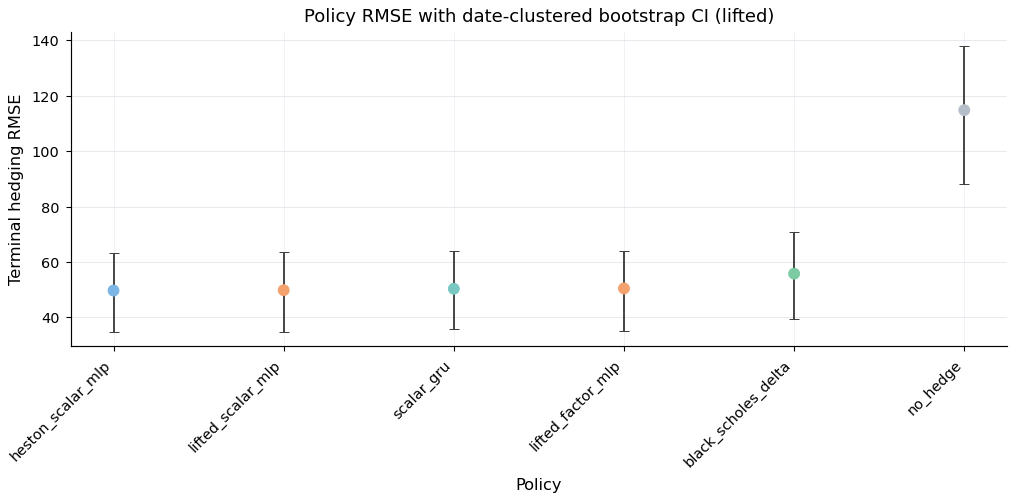

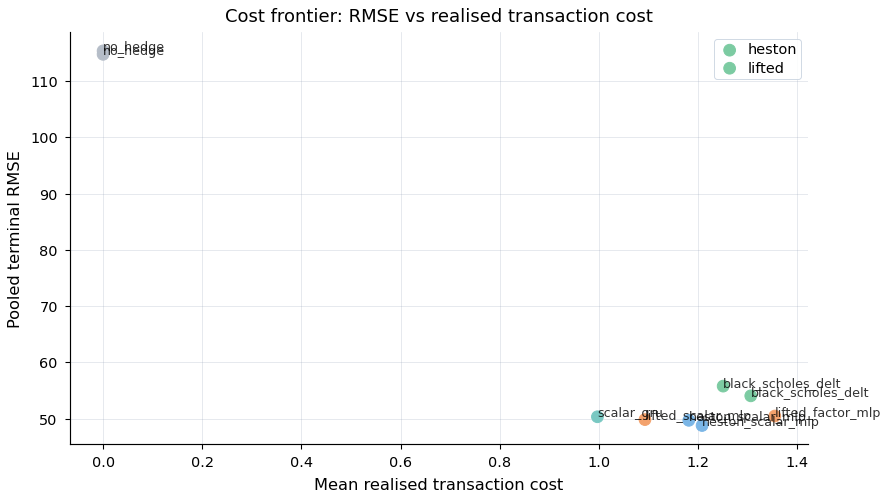

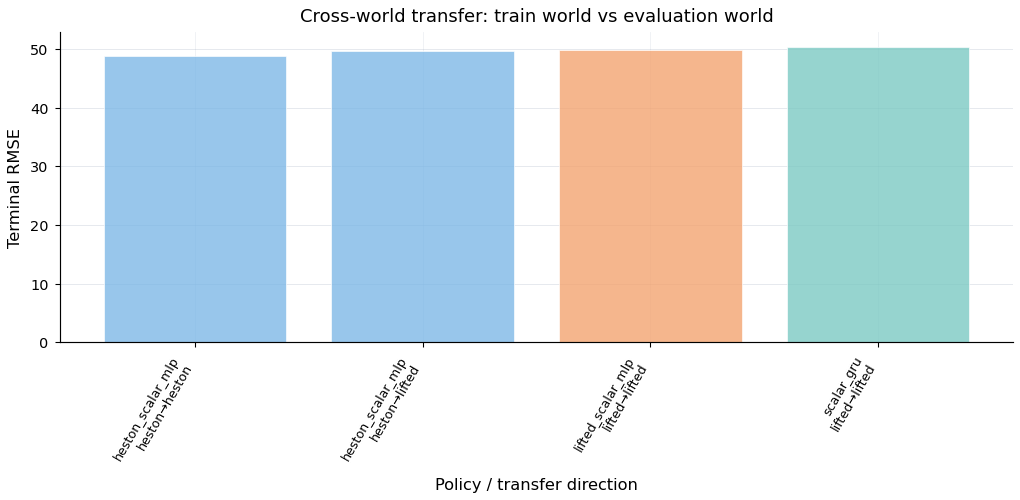

C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1886025550.py:116: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=[str(p)[:22] for p in policies], showfliers=False)


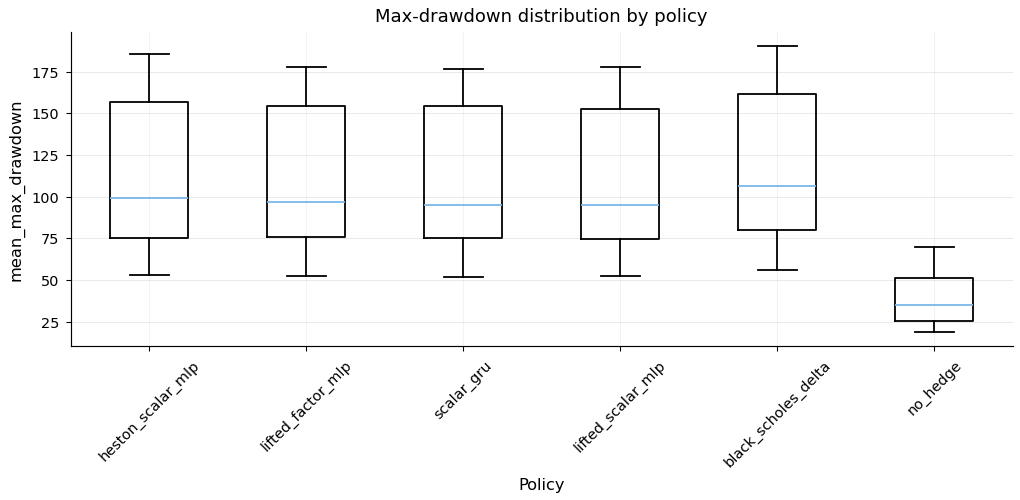

,item,status,artefact,notes
0,policy_rmse_ci,PASS,outputs_final\tables\policy_rmse_date_clustere...,date-clustered bootstrap
1,cost_frontier,PASS,outputs_final\tables\cost_frontier_rmse_vs_rea...,RMSE against realised transaction cost
2,cross_world_transfer,PASS,outputs_final\figures\cross_world_transfer_rms...,trained-world versus evaluated-world RMSE
3,drawdown_distribution,PASS,outputs_final\figures\drawdown_distribution_by...,seed-level drawdown distribution
4,no_trade_band_curve,WARN,outputs_final\tables\no_trade_band_validation_...,zero/tiny selected bands imply collapse toward...


In [48]:

# Dissertation hedging figures: RMSE intervals, cost frontier, no-trade curves and transfer

def _primary_eval(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if results is None or results.empty:
        return pd.DataFrame()
    r = results.copy()
    if "transaction_cost_bps" in r.columns:
        r = r.loc[np.isclose(pd.to_numeric(r["transaction_cost_bps"], errors="coerce"), float(cfg.hedging.primary_transaction_cost_bps))].copy()
    return r


def date_clustered_rmse_ci(results: pd.DataFrame, cfg: ExperimentConfig, reps: int = 2000, seed: int = 2026) -> pd.DataFrame:
    r = _primary_eval(results, cfg)
    needed = {"date", "policy", "simulation_world", "mse"}
    if r.empty or not needed.issubset(r.columns):
        return pd.DataFrame()
    rng = np.random.default_rng(seed)
    rows = []
    group_cols = ["simulation_world", "policy", "transaction_cost_bps"] if "transaction_cost_bps" in r.columns else ["simulation_world", "policy"]
    for key, g in r.groupby(group_cols, dropna=False):
        meta = dict(zip(group_cols, key if isinstance(key, tuple) else (key,)))
        daily = g.groupby(pd.to_datetime(g["date"], errors="coerce").dt.normalize())["mse"].mean().dropna()
        if daily.empty:
            continue
        values = daily.to_numpy(float)
        draws = np.array([np.sqrt(np.mean(rng.choice(values, size=len(values), replace=True))) for _ in range(reps)])
        rows.append({**meta, "rmse": float(np.sqrt(np.mean(values))), "rmse_ci_lower": float(np.quantile(draws, 0.025)), "rmse_ci_upper": float(np.quantile(draws, 0.975)), "n_dates": int(len(values)), "bootstrap_unit": "market_date"})
    out = pd.DataFrame(rows)
    if not out.empty:
        out.to_csv(table_path("policy_rmse_date_clustered_bootstrap_ci.csv", cfg), index=False)
    return out


def plot_policy_rmse_ci(ci: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or ci is None or ci.empty:
        return None
    world = ci["simulation_world"].astype(str).value_counts().index[0]
    p = ci.loc[ci["simulation_world"].astype(str).eq(world)].sort_values("rmse")
    fig, ax = plt.subplots(figsize=(8, 4))
    x = np.arange(len(p))
    y = pd.to_numeric(p["rmse"], errors="coerce")
    yerr = np.vstack([y - pd.to_numeric(p["rmse_ci_lower"], errors="coerce"), pd.to_numeric(p["rmse_ci_upper"], errors="coerce") - y])
    ax.errorbar(x, y, yerr=yerr, fmt="o", capsize=3, color="0.25", ecolor="0.25")
    ax.scatter(x, y, c=[model_color(policy) for policy in p["policy"]], s=36, zorder=3)
    ax.set_xticks(x); ax.set_xticklabels(p["policy"].astype(str), rotation=45, ha="right")
    ax.set(title=f"Policy RMSE with date-clustered bootstrap CI ({world})", xlabel="Policy", ylabel="Terminal hedging RMSE")
    ax.grid(True, axis="y", alpha=0.3)
    path = figure_path("policy_rmse_date_clustered_bootstrap_ci.png", cfg)
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path


def cost_frontier_table(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    r = _primary_eval(results, cfg)
    if r.empty or not {"policy", "simulation_world", "mse", "mean_transaction_costs"}.issubset(r.columns):
        return pd.DataFrame()
    out = r.groupby(["simulation_world", "policy", "transaction_cost_bps"], dropna=False, as_index=False).agg(
        mse=("mse", "mean"),
        rmse=("rmse", "mean") if "rmse" in r.columns else ("mse", lambda x: float(np.sqrt(np.mean(x)))),
        realised_transaction_cost=("mean_transaction_costs", "mean"),
        turnover=("mean_turnover", "mean") if "mean_turnover" in r.columns else ("mse", "size"),
        cvar_5_loss=("cvar_5_loss", "mean") if "cvar_5_loss" in r.columns else ("mse", "size"),
        n_dates=("date", lambda x: pd.to_datetime(x, errors="coerce").dt.normalize().nunique()),
    )
    out["pooled_rmse"] = np.sqrt(pd.to_numeric(out["mse"], errors="coerce"))
    out.to_csv(table_path("cost_frontier_rmse_vs_realised_transaction_cost.csv", cfg), index=False)
    return out


def plot_cost_frontier(frontier: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or frontier is None or frontier.empty:
        return None
    fig, ax = plt.subplots(figsize=(7, 4))
    for world, g in frontier.groupby("simulation_world"):
        ax.scatter(pd.to_numeric(g["realised_transaction_cost"], errors="coerce"), pd.to_numeric(g["pooled_rmse"], errors="coerce"), label=str(world), c=[model_color(policy) for policy in g["policy"]], s=42)
        for _, row in g.iterrows():
            ax.annotate(str(row["policy"])[:18], (row["realised_transaction_cost"], row["pooled_rmse"]), fontsize=7, alpha=0.8)
    ax.set(title="Cost frontier: RMSE vs realised transaction cost", xlabel="Mean realised transaction cost", ylabel="Pooled terminal RMSE")
    ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
    path = figure_path("cost_frontier_rmse_vs_realised_transaction_cost.png", cfg)
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path


def plot_cross_world_transfer(results: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    r = _primary_eval(results, cfg)
    if not MATPLOTLIB_AVAILABLE or r.empty or not {"policy", "training_world", "simulation_world", "mse"}.issubset(r.columns):
        return None
    keep = r.loc[r["policy"].astype(str).str.contains("heston_scalar|lifted_scalar|scalar_gru", regex=True, case=False)].copy()
    if keep.empty:
        keep = r.copy()
    tab = keep.groupby(["policy", "training_world", "simulation_world"], as_index=False)["mse"].mean()
    tab["rmse"] = np.sqrt(tab["mse"].astype(float))
    tab.to_csv(table_path("cross_world_transfer_rmse.csv", cfg), index=False)
    labels = tab.apply(lambda x: f"{x['policy']}\n{x['training_world']}→{x['simulation_world']}", axis=1)
    fig, ax = plt.subplots(figsize=(max(8, 0.45 * len(tab)), 4))
    x = np.arange(len(tab)); ax.bar(x, tab["rmse"].astype(float), color=[model_color(p) for p in tab["policy"].astype(str)], alpha=BAR_ALPHA, edgecolor="white", linewidth=0.45)
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=60, ha="right", fontsize=7)
    ax.set(title="Cross-world transfer: train world vs evaluation world", xlabel="Policy / transfer direction", ylabel="Terminal RMSE")
    ax.grid(True, axis="y", alpha=0.3)
    path = figure_path("cross_world_transfer_rmse.png", cfg)
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path


def plot_drawdown_distribution(results: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    r = _primary_eval(results, cfg)
    col = _choose_col(r, ["mean_max_drawdown", "max_drawdown", "p95_max_drawdown"])
    if not MATPLOTLIB_AVAILABLE or r.empty or not col or "policy" not in r.columns:
        return None
    policies = r.groupby("policy")[col].count().sort_values(ascending=False).head(12).index
    data = [pd.to_numeric(r.loc[r["policy"].eq(p), col], errors="coerce").dropna().to_numpy() for p in policies]
    if not any(len(x) for x in data):
        return None
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.boxplot(data, labels=[str(p)[:22] for p in policies], showfliers=False)
    ax.set(title="Max-drawdown distribution by policy", xlabel="Policy", ylabel=col)
    ax.tick_params(axis="x", rotation=45); ax.grid(True, axis="y", alpha=0.3)
    path = figure_path("drawdown_distribution_by_policy.png", cfg)
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path


def no_trade_band_curve(no_trade: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if no_trade is None or no_trade.empty:
        return pd.DataFrame()
    n = no_trade.copy()
    band_col = _choose_col(n, ["band", "band_width", "no_trade_band", "selected_band"])
    if not band_col:
        return pd.DataFrame()
    metric_cols = [c for c in ["rmse", "cvar_5_loss", "mean_turnover", "mean_transaction_costs"] if c in n.columns]
    if not metric_cols:
        return pd.DataFrame()
    group_cols = [band_col] + [c for c in ["simulation_world", "model", "transaction_cost_bps"] if c in n.columns]
    out = n.groupby(group_cols, as_index=False)[metric_cols].mean().rename(columns={band_col: "no_trade_band_width"})
    out.to_csv(table_path("no_trade_band_validation_curve.csv", cfg), index=False)
    if MATPLOTLIB_AVAILABLE:
        fig, ax = plt.subplots(figsize=(7, 4))
        for metric in metric_cols:
            ax.plot(pd.to_numeric(out["no_trade_band_width"], errors="coerce"), pd.to_numeric(out[metric], errors="coerce"), marker="o", label=metric)
        ax.set(title="No-trade-band validation curve", xlabel="Band width", ylabel="Metric value")
        ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
        path = figure_path("no_trade_band_validation_curve.png", cfg)
        save_and_show_figure(plt.gcf(), path, dpi=160)
    return out

policy_rmse_bootstrap_ci = date_clustered_rmse_ci(evaluation_results, CFG)
policy_rmse_bootstrap_ci_path = plot_policy_rmse_ci(policy_rmse_bootstrap_ci, CFG)
cost_frontier_rmse_vs_cost = cost_frontier_table(evaluation_results, CFG)
cost_frontier_path = plot_cost_frontier(cost_frontier_rmse_vs_cost, CFG)
cross_world_transfer_path = plot_cross_world_transfer(evaluation_results, CFG)
drawdown_distribution_path = plot_drawdown_distribution(evaluation_results, CFG)
no_trade_band_validation_curve = no_trade_band_curve(no_trade_band_validation, CFG)

hedging_figure_audit = pd.DataFrame([
    {"item": "policy_rmse_ci", "status": "PASS" if not policy_rmse_bootstrap_ci.empty else "WARN", "artefact": str(table_path("policy_rmse_date_clustered_bootstrap_ci.csv", CFG)), "notes": "date-clustered bootstrap"},
    {"item": "cost_frontier", "status": "PASS" if not cost_frontier_rmse_vs_cost.empty else "WARN", "artefact": str(table_path("cost_frontier_rmse_vs_realised_transaction_cost.csv", CFG)), "notes": "RMSE against realised transaction cost"},
    {"item": "cross_world_transfer", "status": "PASS" if cross_world_transfer_path else "WARN", "artefact": str(figure_path("cross_world_transfer_rmse.png", CFG)), "notes": "trained-world versus evaluated-world RMSE"},
    {"item": "drawdown_distribution", "status": "PASS" if drawdown_distribution_path else "WARN", "artefact": str(figure_path("drawdown_distribution_by_policy.png", CFG)), "notes": "seed-level drawdown distribution"},
    {"item": "no_trade_band_curve", "status": "PASS" if not no_trade_band_validation_curve.empty else "WARN", "artefact": str(table_path("no_trade_band_validation_curve.csv", CFG)), "notes": "zero/tiny selected bands imply collapse toward raw model delta"},
])
hedging_figure_audit.to_csv(table_path("hedging_figure_audit.csv", CFG), index=False)
display(hedging_figure_audit)


## 11.6 Pairwise Policy Dominance and Tail-Risk Summaries

Pairwise win-rate diagnostics ask how often one policy beats another across dates, maturities or seed rows. This complements pooled RMSE. A policy can win the pooled average because of a few large improvements while losing on most dates. The win-rate matrix makes that visible.

The basic win-rate object is

$$
\mathrm{WinRate}(A,B)=\frac{1}{n}\sum_{i=1}^{n}\mathbf{1}\{L_i^A<L_i^B\},
$$

where $L_i^A$ and $L_i^B$ are losses for policies $A$ and $B$ on comparable units. Tail win rates apply the same idea to CVaR or lower-tail losses.

These diagnostics are especially helpful for dissertation interpretation because they are simple and examiner-friendly. A result such as “policy A has lower RMSE but wins only 45% of dates” signals concentration risk. A result such as “policy A wins 70% of dates and improves CVaR” is much stronger.

The limitation is that win rates ignore magnitude. They should be read alongside RMSE, cost and tail summaries, not instead of them.


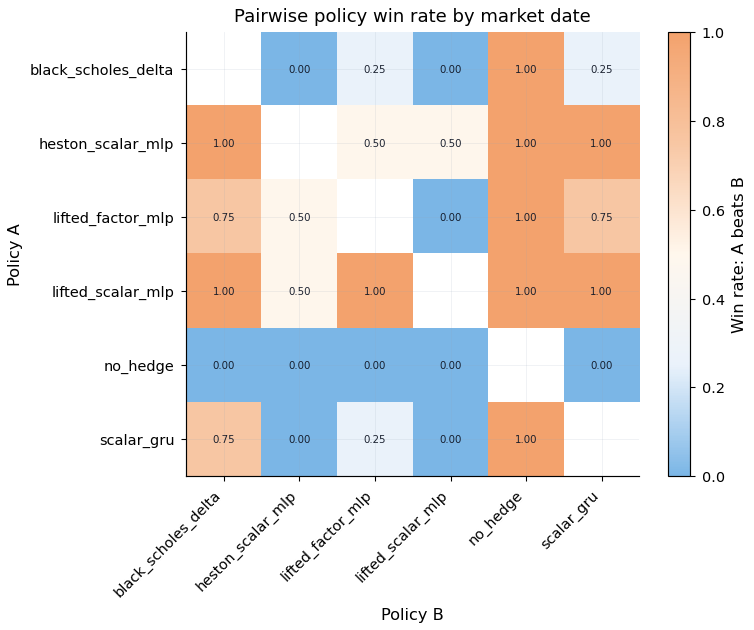

,simulation_world,transaction_cost_bps,maturity_bucket,policy_a,policy_b,win_rate_a_vs_b,mean_mse_difference_a_minus_b,median_mse_difference_a_minus_b,n_paired_dates,metric
0,heston,1.0,1M,black_scholes_delta,heston_scalar_mlp,0.25,617.577075,613.880444,4,date_level_mean_mse
1,heston,1.0,1M,black_scholes_delta,no_hedge,1.00,-14485.911378,-15626.513644,4,date_level_mean_mse
2,heston,1.0,1M,heston_scalar_mlp,black_scholes_delta,0.75,-617.577075,-613.880444,4,date_level_mean_mse
3,heston,1.0,1M,heston_scalar_mlp,no_hedge,1.00,-15103.488453,-16327.147036,4,date_level_mean_mse
4,heston,1.0,1M,no_hedge,black_scholes_delta,0.00,14485.911378,15626.513644,4,date_level_mean_mse


,simulation_world,policy,transaction_cost_bps,var_5_loss,cvar_5_loss,pnl_p01,pnl_p05,pnl_p50,pnl_p95,pnl_p99,gross_pnl_p05,gross_pnl_p50,gross_pnl_p95,p95_max_drawdown,p95_terminal_drawdown,p05_min_pnl,gross_p95_max_drawdown,p95_max_drawdown_to_premium,tail_metric_source
0,heston,black_scholes_delta,1.0,92.879429,139.954644,-169.556118,-92.879429,2.848109,55.037250,72.677332,-90.868739,4.068638,56.134170,302.128146,282.199580,-162.099832,301.464241,2.536634,seed_level_evaluation_columns
1,heston,heston_scalar_mlp,1.0,83.566699,111.933643,-129.485170,-83.566699,1.245479,54.030283,69.877611,-82.107826,2.415159,55.161903,285.154217,274.101046,-131.672053,284.763687,2.393649,seed_level_evaluation_columns
2,heston,no_hedge,1.0,205.997032,323.871604,-396.325524,-205.997032,20.550416,109.498621,117.093722,-205.997032,20.550416,109.498621,206.193983,206.193983,-205.997032,206.193983,1.726496,seed_level_evaluation_columns
3,lifted,black_scholes_delta,1.0,92.321132,140.008546,-169.452083,-92.321132,6.733565,60.711218,79.101824,-90.314520,7.918183,61.678266,300.376081,280.892140,-159.770194,299.845233,2.533016,seed_level_evaluation_columns
4,lifted,heston_scalar_mlp,1.0,83.350422,113.559463,-131.448056,-83.350422,4.142004,58.910430,75.634929,-81.961843,5.284033,59.991798,282.402843,273.040655,-131.378732,282.006675,2.382050,seed_level_evaluation_columns


WindowsPath('outputs_final/figures/policy_pairwise_win_rate_heatmap.png')

In [49]:

# Pairwise policy dominance and tail-risk summaries

def _evaluation_frame_for_diagnostics(cfg: ExperimentConfig) -> pd.DataFrame:
    return _live_or_cached_frame(["evaluation_results", "hedging_evaluation"], [cfg.paths.evaluation_path, table_path("hedging_evaluation_seed_level.csv", cfg)])


def policy_pairwise_win_rate_matrix(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    r = _primary_eval(results, cfg)

    required = {"date", "policy", "mse"}
    if r.empty or not required.issubset(r.columns):
        out = pd.DataFrame([{
            "status": "missing",
            "notes": (
                f"required columns unavailable: "
                f"{sorted(required - set(r.columns)) if not r.empty else sorted(required)}"
            ),
        }])
        out.to_csv(table_path("policy_pairwise_win_rate_matrix.csv", cfg), index=False)
        return out

    group_cols = [
        c for c in ["simulation_world", "transaction_cost_bps", "maturity_bucket"]
        if c in r.columns
    ]

    base = r.copy()
    base["_date"] = pd.to_datetime(base["date"], errors="coerce").dt.normalize()
    base["mse"] = pd.to_numeric(base["mse"], errors="coerce")
    base = base.dropna(subset=["_date", "policy", "mse"])

    date_policy = (
        base.groupby([*group_cols, "_date", "policy"], dropna=False, as_index=False)
        .agg(mse=("mse", "mean"))
    )

    rows = []
    grouped = date_policy.groupby(group_cols, dropna=False) if group_cols else [((), date_policy)]

    for key, g in grouped:
        meta = dict(zip(group_cols, key if isinstance(key, tuple) else (key,)))
        wide = g.pivot_table(index="_date", columns="policy", values="mse", aggfunc="mean")
        policies = list(wide.columns)

        for a in policies:
            for b in policies:
                if a == b:
                    continue

                paired = wide[[a, b]].dropna()
                if paired.empty:
                    continue

                diff = pd.to_numeric(paired[a] - paired[b], errors="coerce").dropna()
                if diff.empty:
                    continue

                rows.append({
                    **meta,
                    "policy_a": str(a),
                    "policy_b": str(b),
                    "win_rate_a_vs_b": float(np.mean(diff.to_numpy() < 0.0)),
                    "mean_mse_difference_a_minus_b": float(diff.mean()),
                    "median_mse_difference_a_minus_b": float(diff.median()),
                    "n_paired_dates": int(diff.size),
                    "metric": "date_level_mean_mse",
                })

    out = pd.DataFrame(rows)

    if out.empty:
        out = pd.DataFrame(columns=[
            *group_cols,
            "policy_a",
            "policy_b",
            "win_rate_a_vs_b",
            "mean_mse_difference_a_minus_b",
            "median_mse_difference_a_minus_b",
            "n_paired_dates",
            "metric",
        ])

    out.to_csv(table_path("policy_pairwise_win_rate_matrix.csv", cfg), index=False)
    return out


def plot_policy_win_rate_heatmap(win: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or win is None or win.empty or {"policy_a", "policy_b", "win_rate_a_vs_b"}.difference(win.columns):
        return None
    p = win.copy()
    if "simulation_world" in p.columns:
        p = p.loc[p["simulation_world"].astype(str).eq(p["simulation_world"].astype(str).value_counts().index[0])].copy()
    if "maturity_bucket" in p.columns:
        p = p.loc[p["maturity_bucket"].astype(str).eq(p["maturity_bucket"].astype(str).value_counts().index[0])].copy()
    heat = p.pivot_table(index="policy_a", columns="policy_b", values="win_rate_a_vs_b", aggfunc="mean")
    if heat.empty:
        return None
    fig, ax = plt.subplots(figsize=(max(6, 0.45 * len(heat.columns)), max(5, 0.35 * len(heat.index))))
    plot_annotated_heatmap(
        heat,
        ax=ax,
        fig=fig,
        title="Pairwise policy win rate by market date",
        xlabel="Policy B",
        ylabel="Policy A",
        cbar_label="Win rate: A beats B",
        cmap=WINRATE_CMAP,
        vmin=0,
        vmax=1,
        fmt=".2f",
        rotation=45,
    )
    path = figure_path("policy_pairwise_win_rate_heatmap.png", cfg)
    save_and_show_figure(fig, path, dpi=260, description="Pairwise policy win rate by market date", notes="All win-rate cells are annotated; values below 0.5 favour policy B over policy A.")
    return path


def policy_tail_risk_summary(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    r = _primary_eval(results, cfg)
    if r.empty or "policy" not in r.columns:
        out = pd.DataFrame([{"status": "missing", "notes": "evaluation results unavailable"}])
        out.to_csv(table_path("policy_tail_risk_quantile_summary.csv", cfg), index=False)
        return out
    metric_cols = [c for c in r.columns if any(token in c.lower() for token in ["var", "cvar", "p01", "p05", "p50", "p95", "p99", "quantile"])]
    metric_cols = [c for c in metric_cols if pd.to_numeric(r[c], errors="coerce").notna().any()]
    if not metric_cols:
        out = pd.DataFrame([{"status": "missing", "notes": "no VaR/CVaR/quantile columns found in seed-level evaluation"}])
        out.to_csv(table_path("policy_tail_risk_quantile_summary.csv", cfg), index=False)
        return out
    group_cols = [c for c in ["simulation_world", "policy", "transaction_cost_bps"] if c in r.columns]
    out = r.groupby(group_cols, dropna=False)[metric_cols].mean(numeric_only=True).reset_index()
    out["tail_metric_source"] = "seed_level_evaluation_columns"
    out.to_csv(table_path("policy_tail_risk_quantile_summary.csv", cfg), index=False)
    return out


evaluation_for_policy_diagnostics = _evaluation_frame_for_diagnostics(CFG)
policy_pairwise_win_rates = policy_pairwise_win_rate_matrix(evaluation_for_policy_diagnostics, CFG)
policy_win_rate_heatmap_path = plot_policy_win_rate_heatmap(policy_pairwise_win_rates, CFG)
policy_tail_risk_quantiles = policy_tail_risk_summary(evaluation_for_policy_diagnostics, CFG)

display(policy_pairwise_win_rates.head())
display(policy_tail_risk_quantiles.head())
policy_win_rate_heatmap_path


## 11.7 Terminal P&L Distribution Availability

This subsection checks whether pathwise terminal-error or P&L artefacts exist. Distribution plots require path-level outputs. Aggregate policy tables are not enough to reconstruct honest histograms or KDEs. The notebook therefore refuses to fake terminal distributions from summary metrics, which preserves the empirical integrity of the dissertation.

When available, the desired plot is a policy-by-policy distribution of

$$
\varepsilon_T^{\pi}=V_T^{\pi}-\Phi(S_T).
$$

This visualises bias, dispersion, outliers and left-tail risk. It also makes VaR and CVaR easier to interpret. If the artefacts are absent, the subsection records which cache would be needed: pathwise terminal errors by policy, date, maturity, cost level and world.

This limitation does not necessarily invalidate the main results if aggregate RMSE, CVaR and cost metrics are available. It does, however, weaken visual tail-risk interpretation. The final audit should state that clearly.


In [50]:

# True terminal P&L distributions only when pathwise artefacts exist

def load_pathwise_terminal_pnl(cfg: ExperimentConfig) -> pd.DataFrame:
    candidates = [
        cfg.paths.table_dir / "terminal_pnl_pathwise.csv",
        cfg.paths.table_dir / "hedging_terminal_pnl_pathwise.csv",
        cfg.paths.output_dir / "terminal_pnl_pathwise.parquet",
        cfg.paths.output_dir / "hedging_terminal_pnl_pathwise.parquet",
    ]
    for path in candidates:
        if Path(path).exists():
            return pd.read_parquet(path) if Path(path).suffix == ".parquet" else pd.read_csv(path)
    return pd.DataFrame()


def plot_terminal_pnl_distributions(pathwise: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if pathwise.empty:
        out = pd.DataFrame([{"item": "terminal_pnl_distribution", "implemented": False, "notes": "Pathwise terminal P&L artefact not found; seed-level quantiles are available but no histogram is produced."}])
        out.to_csv(table_path("terminal_pnl_distribution_limitation.csv", cfg), index=False)
        return out
    pnl_col = _choose_col(pathwise, ["terminal_pnl", "hedging_error", "net_pnl", "pnl"])
    if not pnl_col or "policy" not in pathwise.columns:
        out = pd.DataFrame([{"item": "terminal_pnl_distribution", "implemented": False, "notes": f"Pathwise table found but required columns missing; pnl_col={pnl_col}"}])
        out.to_csv(table_path("terminal_pnl_distribution_limitation.csv", cfg), index=False)
        return out
    if MATPLOTLIB_AVAILABLE:
        p = pathwise.copy()
        if "transaction_cost_bps" in p.columns:
            p = p.loc[np.isclose(pd.to_numeric(p["transaction_cost_bps"], errors="coerce"), float(cfg.hedging.primary_transaction_cost_bps))]
        policies = p.groupby("policy")[pnl_col].count().sort_values(ascending=False).head(8).index
        fig, ax = plt.subplots(figsize=(8, 4))
        for policy in policies:
            vals = pd.to_numeric(p.loc[p["policy"].eq(policy), pnl_col], errors="coerce").dropna()
            if len(vals) > 10:
                ax.hist(vals, bins=60, density=True, histtype="step", linewidth=1.0, color=model_color(policy), linestyle=model_linestyle(policy), label=str(policy)[:25])
        ax.axvline(0.0, color="0.20", linestyle=":", linewidth=1.1, label="zero error")
        ax.set(title="Terminal hedging P&L distributions by policy", xlabel=r"$\varepsilon_T^\pi$ (net where transaction costs are included)", ylabel="Density")
        standardise_axis(ax, legend=True, ncol=2)
        path = figure_path("terminal_pnl_distribution_by_policy.png", cfg)
        save_and_show_figure(plt.gcf(), path, dpi=160)
    out = pd.DataFrame([{"item": "terminal_pnl_distribution", "implemented": True, "notes": f"Plotted from {len(pathwise)} pathwise rows."}])
    out.to_csv(table_path("terminal_pnl_distribution_audit.csv", cfg), index=False)
    return out

pathwise_terminal_pnl = load_pathwise_terminal_pnl(CFG)
terminal_pnl_distribution_audit = plot_terminal_pnl_distributions(pathwise_terminal_pnl, CFG)
display(terminal_pnl_distribution_audit)


,item,implemented,notes
0,terminal_pnl_distribution,False,Pathwise terminal P&L artefact not found; seed...


## 11.8 Cost-Normalised Improvement and Policy Position Diagnostics

Cost-normalised improvement asks whether extra hedging accuracy is economically efficient. A simple diagnostic is

$$
\frac{\Delta \mathrm{RMSE}}{\Delta \mathrm{Cost}},
$$

computed relative to a baseline such as Black-Scholes delta, no hedge or model delta where appropriate. This ratio should not be overinterpreted as a utility function. It is a compact way to see whether a policy buys risk reduction at an acceptable trading-cost price.

Policy position diagnostics examine behaviour rather than only outcomes. Mean absolute hedge, hedge-change magnitude and hedge autocorrelation show whether a policy is stable, nervous or turnover-heavy. This matters for lifted factor policies because richer state information can induce excessive rebalancing if the network reacts to factor noise.

The ideal policy reduces terminal net risk while keeping turnover and realised cost controlled. A policy with low gross error but high net error is not a triumph; it is a economically inefficient strategy.

These diagnostics support a sharper conclusion about factor usefulness. If factor policies underperform because they overtrade, the problem is not necessarily that factor information is worthless. It may be that raw factors need compression, regularisation or a different transaction-cost-aware architecture.


In [51]:

# Cost-normalised improvement and optional policy-position diagnostics

def policy_cost_normalised_improvement(results: pd.DataFrame, cfg: ExperimentConfig, benchmark_keywords: tuple[str, ...] = ("black", "bs", "no hedge")) -> pd.DataFrame:
    r = _primary_eval(results, cfg)
    required = {"simulation_world", "policy", "mse"}
    if r.empty or not required.issubset(r.columns):
        out = pd.DataFrame([{"status": "missing", "notes": f"required columns unavailable: {sorted(required - set(r.columns)) if not r.empty else sorted(required)}"}])
        out.to_csv(table_path("policy_cost_normalised_improvement.csv", cfg), index=False)
        return out
    cost_col = _choose_col(r, ["mean_transaction_costs", "realised_transaction_cost", "transaction_cost"])
    group_cols = [c for c in ["simulation_world", "transaction_cost_bps", "maturity_bucket"] if c in r.columns]
    agg_spec = {"mse": ("mse", "mean"), "n_rows": ("mse", "size")}
    if cost_col:
        agg_spec["realised_transaction_cost"] = (cost_col, "mean")
    if "date" in r.columns:
        agg_spec["n_dates"] = ("date", lambda x: pd.to_datetime(x, errors="coerce").dt.normalize().nunique())
    g = r.groupby([*group_cols, "policy"], dropna=False, as_index=False).agg(**agg_spec)
    g["rmse"] = np.sqrt(pd.to_numeric(g["mse"], errors="coerce"))
    if "realised_transaction_cost" not in g.columns:
        g["realised_transaction_cost"] = np.nan
    rows = []
    for key, block in g.groupby(group_cols, dropna=False) if group_cols else [((), g)]:
        meta = dict(zip(group_cols, key if isinstance(key, tuple) else (key,)))
        names = block["policy"].astype(str).str.lower()
        bench_mask = np.zeros(len(block), dtype=bool)
        for kw in benchmark_keywords:
            bench_mask |= names.str.contains(kw, regex=False).to_numpy()
        if not bench_mask.any():
            bench_idx = block["rmse"].astype(float).idxmax()
        else:
            bench_idx = block.loc[bench_mask, "rmse"].astype(float).idxmin()
        bench = block.loc[bench_idx]
        for _, row in block.iterrows():
            delta_rmse = float(bench["rmse"] - row["rmse"])
            delta_cost = float(row["realised_transaction_cost"] - bench["realised_transaction_cost"]) if np.isfinite(row["realised_transaction_cost"]) and np.isfinite(bench["realised_transaction_cost"]) else np.nan
            rows.append({
                **meta,
                "policy": row["policy"],
                "benchmark_policy": bench["policy"],
                "rmse": float(row["rmse"]),
                "benchmark_rmse": float(bench["rmse"]),
                "rmse_reduction_vs_benchmark": delta_rmse,
                "realised_transaction_cost": float(row["realised_transaction_cost"]) if np.isfinite(row["realised_transaction_cost"]) else np.nan,
                "benchmark_realised_transaction_cost": float(bench["realised_transaction_cost"]) if np.isfinite(bench["realised_transaction_cost"]) else np.nan,
                "incremental_cost_vs_benchmark": delta_cost,
                "rmse_reduction_per_unit_cost": delta_rmse / delta_cost if np.isfinite(delta_cost) and abs(delta_cost) > 1e-12 else np.nan,
                "n_rows": int(row.get("n_rows", 0)),
                "n_dates": int(row.get("n_dates", 0)) if "n_dates" in row else np.nan,
                "status": "available",
            })
    out = pd.DataFrame(rows)
    out.to_csv(table_path("policy_cost_normalised_improvement.csv", cfg), index=False)
    return out


def load_policy_position_pathwise(cfg: ExperimentConfig) -> pd.DataFrame:
    candidates = [
        cfg.paths.table_dir / "policy_positions_pathwise.csv",
        cfg.paths.table_dir / "hedge_positions_pathwise.csv",
        cfg.paths.output_dir / "policy_positions_pathwise.parquet",
        cfg.paths.output_dir / "hedge_positions_pathwise.parquet",
    ]
    for path in candidates:
        if Path(path).exists():
            return pd.read_parquet(path) if Path(path).suffix == ".parquet" else pd.read_csv(path)
    return pd.DataFrame()


def policy_position_diagnostics(pathwise: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if pathwise is None or pathwise.empty:
        out = pd.DataFrame([{"item": "policy_position_diagnostics", "implemented": False, "notes": "No pathwise hedge-position artefact found."}])
        out.to_csv(table_path("policy_position_diagnostics.csv", cfg), index=False)
        return out
    hedge_col = _choose_col(pathwise, ["hedge", "delta", "position", "stock_position"])
    policy_col = _choose_col(pathwise, ["policy", "policy_name"])
    path_col = _choose_col(pathwise, ["path_id", "simulation_path", "path"])
    time_col = _choose_col(pathwise, ["time_index", "step", "t"])
    if not hedge_col or not policy_col:
        out = pd.DataFrame([{"item": "policy_position_diagnostics", "implemented": False, "notes": f"Required columns missing; hedge_col={hedge_col}, policy_col={policy_col}"}])
        out.to_csv(table_path("policy_position_diagnostics.csv", cfg), index=False)
        return out
    p = pathwise.copy()
    if "transaction_cost_bps" in p.columns:
        p = p.loc[np.isclose(pd.to_numeric(p["transaction_cost_bps"], errors="coerce"), float(cfg.hedging.primary_transaction_cost_bps))]
    p["_hedge"] = pd.to_numeric(p[hedge_col], errors="coerce")
    sort_cols = [c for c in [policy_col, path_col, time_col] if c]
    p = p.sort_values(sort_cols) if sort_cols else p
    if path_col:
        p["_hedge_change"] = p.groupby([policy_col, path_col], dropna=False)["_hedge"].diff().abs()
        autocorr = p.groupby([policy_col, path_col], dropna=False)["_hedge"].apply(lambda x: x.autocorr() if x.notna().sum() > 2 else np.nan).groupby(level=0).mean()
    else:
        p["_hedge_change"] = p.groupby(policy_col, dropna=False)["_hedge"].diff().abs()
        autocorr = p.groupby(policy_col, dropna=False)["_hedge"].apply(lambda x: x.autocorr() if x.notna().sum() > 2 else np.nan)
    out = p.groupby(policy_col, dropna=False, as_index=False).agg(
        mean_abs_hedge=("_hedge", lambda x: float(np.nanmean(np.abs(x)))),
        median_abs_hedge=("_hedge", lambda x: float(np.nanmedian(np.abs(x)))),
        mean_abs_hedge_change=("_hedge_change", "mean"),
        p95_abs_hedge_change=("_hedge_change", lambda x: float(np.nanquantile(x.dropna(), 0.95)) if x.notna().any() else np.nan),
        n_observations=("_hedge", "count"),
    ).rename(columns={policy_col: "policy"})
    out["mean_path_hedge_autocorrelation"] = out["policy"].map(autocorr.to_dict())
    out["implemented"] = True
    out.to_csv(table_path("policy_position_diagnostics.csv", cfg), index=False)
    return out

policy_cost_efficiency = policy_cost_normalised_improvement(_evaluation_frame_for_diagnostics(CFG), CFG)
policy_position_diagnostic_table = policy_position_diagnostics(load_policy_position_pathwise(CFG), CFG)

display(policy_cost_efficiency.head(20))
display(policy_position_diagnostic_table.head(20))


,simulation_world,transaction_cost_bps,maturity_bucket,policy,benchmark_policy,rmse,benchmark_rmse,rmse_reduction_vs_benchmark,realised_transaction_cost,benchmark_realised_transaction_cost,incremental_cost_vs_benchmark,rmse_reduction_per_unit_cost,n_rows,n_dates,status
0,heston,1.0,1M,black_scholes_delta,black_scholes_delta,68.177578,68.177578,0.000000,1.613174,1.613174,0.000000,NaN,4,4,available
1,heston,1.0,1M,heston_scalar_mlp,black_scholes_delta,63.487046,68.177578,4.690532,1.498497,1.613174,-0.114677,-40.901994,12,4,available
2,heston,1.0,1M,no_hedge,black_scholes_delta,138.326040,68.177578,-70.148463,0.000000,1.613174,-1.613174,43.484747,4,4,available
3,heston,1.0,2M,black_scholes_delta,black_scholes_delta,47.165302,47.165302,0.000000,1.141639,1.141639,0.000000,NaN,4,4,available
4,heston,1.0,2M,heston_scalar_mlp,black_scholes_delta,42.304907,47.165302,4.860394,1.046335,1.141639,-0.095304,-50.998806,12,4,available
5,heston,1.0,2M,no_hedge,black_scholes_delta,99.473372,47.165302,-52.308071,0.000000,1.141639,-1.141639,45.818413,4,4,available
6,heston,1.0,3M,black_scholes_delta,black_scholes_delta,43.560281,43.560281,0.000000,1.164766,1.164766,0.000000,NaN,4,4,available
7,heston,1.0,3M,heston_scalar_mlp,black_scholes_delta,36.360863,43.560281,7.199418,1.080084,1.164766,-0.084682,-85.017398,12,4,available
8,heston,1.0,3M,no_hedge,black_scholes_delta,104.473868,43.560281,-60.913587,0.000000,1.164766,-1.164766,52.296847,4,4,available
9,lifted,1.0,1M,black_scholes_delta,black_scholes_delta,71.261675,71.261675,0.000000,1.519392,1.519392,0.000000,NaN,4,4,available


,item,implemented,notes
0,policy_position_diagnostics,False,No pathwise hedge-position artefact found.


# 12. Mechanism and Feature Attribution Diagnostics

This section asks why a policy performs the way it does. Performance tables answer whether a policy helped. Mechanism diagnostics ask whether the result is consistent with the dissertation's proposed explanation: lifted factors contain hedge-relevant volatility-memory information beyond scalar variance.

The mechanism evidence includes factor composition, effective number of active factors, bucket contributions, future realised-variance regressions and feature-attribution summaries where available. These outputs make the lifted state interpretable. Without them, “factor features” would be a phrase doing far too much work.

The future realised-variance diagnostic is intentionally modest. It tests whether scalar variance plus lifted buckets predicts future realised variance better than scalar variance alone. If incremental $R^2$ is small, that does not prove factors are useless for hedging. Factors may matter through skew dynamics, pathwise exposure, drawdown control or state-dependent trading decisions rather than through simple realised-variance forecasting.

The section therefore distinguishes between **forecasting mechanism evidence** and **hedging mechanism evidence**. Both are useful, but neither should be forced to say more than the cached outputs support.


In [52]:
# ============================================================
# Mechanism diagnostics without train/test leakage
# ============================================================


def diagnostic_seed_sample(seed_panel: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    require_columns(seed_panel, {"seed_id", "split", "hedge_maturity_bucket"}, "seed panel")
    splits = ["train", "test"]
    buckets = [str(b) for b in cfg.hedging.maturity_buckets]
    max_rows = int(cfg.hedging.max_diagnostic_seeds)
    required_groups = len(splits) * len(buckets)
    if max_rows < required_groups:
        raise ValueError(
            f"max_diagnostic_seeds={max_rows} cannot cover all train/test maturity buckets ({required_groups} groups)."
        )
    base = max_rows // required_groups
    remainder = max_rows % required_groups
    panel = seed_panel.copy()
    panel["seed_id"] = panel["seed_id"].astype(str)
    panel = panel.loc[~panel["seed_id"].isin(simulation_infeasible_seed_ids())].copy()
    pieces = []
    group_index = 0
    for split in splits:
        for bucket in buckets:
            g = panel.loc[
                panel["split"].astype(str).eq(split)
                & panel["hedge_maturity_bucket"].astype(str).eq(bucket)
            ].copy()
            if g.empty:
                raise ValueError(f"No feasible {split} diagnostic seed for maturity bucket {bucket}.")
            sort_cols = [c for c in ["date", "seed_id"] if c in g.columns]
            if sort_cols:
                g = g.sort_values(sort_cols)
            take = base + (1 if group_index < remainder else 0)
            pieces.append(g.head(take))
            group_index += 1
    out = pd.concat(pieces, ignore_index=True)
    observed = set(zip(out["split"].astype(str), out["hedge_maturity_bucket"].astype(str)))
    expected = {(split, bucket) for split in splits for bucket in buckets}
    missing = sorted(expected - observed)
    if missing:
        raise RuntimeError(f"Diagnostic seed sampling lost split/bucket coverage: {missing}")
    return out.reset_index(drop=True)


def build_factor_state_panel_from_paths(
    paths: dict[str, np.ndarray],
    params: LiftedHestonParams,
    curve: ForwardVarianceInputCurve,
    kernel: LiftedKernelGrid,
    seed_row: pd.Series,
    terminal_squared_error: np.ndarray,
    cfg: ExperimentConfig,
) -> pd.DataFrame:
    S,V,U,times = paths["S"],paths["V"],paths["U"],paths["times"]
    n_time_points = min(getattr(cfg.hedging, "diagnostic_time_points", 12), len(times)-1)
    time_indices = np.unique(np.linspace(0, len(times)-2, n_time_points).round().astype(int))
    rows=[]
    fixed_horizons = {"1w":7/365.25,"1m":30/365.25,"3m":90/365.25}
    for t_idx in time_indices:
        t=float(times[t_idx]); remaining=max(float(paths["T"])-t,1e-8)
        contrib=factor_contribution_matrix(U[:,t_idx,:],V[:,t_idx],kernel.weights)
        frame=pd.DataFrame(contrib,columns=[f"factor_contribution_{i+1}" for i in range(kernel.n_factors)])
        frame["seed_id"]=seed_row["seed_id"]; frame["date"]=pd.Timestamp(seed_row["date"]).normalize(); frame["split"]=seed_row["split"]
        frame["maturity_bucket"]=str(seed_row["hedge_maturity_bucket"]); frame["path_index"]=np.arange(len(S)); frame["time_index"]=int(t_idx)
        frame["calendar_time"]=t; frame["tau_fraction"]=remaining/max(float(paths["T"]),1e-12); frame["log_moneyness"]=np.log(S[:,t_idx]/float(paths["K"])); frame["current_variance"]=V[:,t_idx]
        frame["next_variance_change"]=V[:,min(t_idx+1,V.shape[1]-1)]-V[:,t_idx]
        frame["terminal_squared_hedging_error"]=terminal_squared_error
        bucket_frame=factor_buckets(U[:,t_idx,:],V[:,t_idx],kernel)
        for col in bucket_frame: frame[col]=bucket_frame[col].to_numpy()
        maturity_projection=conditional_variance_projection(U[:,t_idx,:],t,remaining,params,curve,kernel,cfg.lifted.conditional_projection_steps)
        for col in maturity_projection:
            if col!="current_variance": frame[f"maturity_{col}"]=maturity_projection[col].to_numpy()
        for label,horizon in fixed_horizons.items():
            projection=conditional_variance_projection(U[:,t_idx,:],t,horizon,params,curve,kernel,cfg.lifted.conditional_projection_steps)
            for col in ["projected_terminal_variance","projected_integrated_variance","projected_average_variance"]:
                frame[f"{label}_{col}"]=projection[col].to_numpy()
        rows.append(frame)
    return pd.concat(rows,ignore_index=True)


def fit_train_only_factor_pca(panel: pd.DataFrame, variance_threshold: float=0.99) -> tuple[pd.DataFrame,pd.DataFrame]:
    factor_cols=[c for c in panel if c.startswith("factor_contribution_")]
    train=panel.loc[panel["split"].eq("train"),factor_cols]
    X_train=train.to_numpy(float); X_all=panel[factor_cols].to_numpy(float)
    if np.any(~np.isfinite(X_train)) or np.any(~np.isfinite(X_all)): raise ValueError("PCA factor inputs contain non-finite values.")
    mean=X_train.mean(axis=0); scale=X_train.std(axis=0,ddof=0)
    if np.any(scale<=0): raise ValueError("PCA training factors contain zero-variance columns.")
    Z_train=(X_train-mean)/scale; Z_all=(X_all-mean)/scale
    if SKLEARN_AVAILABLE:
        estimator=PCA(n_components=min(len(factor_cols),len(Z_train))).fit(Z_train)
        scores=estimator.transform(Z_all); explained=estimator.explained_variance_ratio_; components=estimator.components_
    else:
        _,s,vt=np.linalg.svd(Z_train,full_matrices=False); explained=s**2/np.sum(s**2); components=vt; scores=Z_all@vt.T
    cumulative=np.cumsum(explained); n_components=int(np.searchsorted(cumulative,variance_threshold)+1)
    out=panel.copy()
    for i in range(n_components): out[f"factor_pc_{i+1}"]=scores[:,i]
    records=[]
    for i in range(len(explained)):
        for j,col in enumerate(factor_cols):
            records.append({"component":i+1,"factor":col,"loading":float(components[i,j]),"explained_variance_ratio":float(explained[i]),"cumulative_explained_variance":float(cumulative[i]),"train_mean":float(mean[j]),"train_scale":float(scale[j]),"retained":bool(i<n_components)})
    return out,pd.DataFrame(records)


def out_of_sample_factor_regressions(panel: pd.DataFrame) -> pd.DataFrame:
    if not SKLEARN_AVAILABLE: raise RuntimeError("scikit-learn is required for mechanism regressions.")
    factor_cols=[c for c in panel if c.startswith("factor_contribution_")]
    controls=["current_variance","log_moneyness","tau_fraction"]
    rows=[]
    for outcome in ["next_variance_change","terminal_squared_hedging_error"]:
        cols=[outcome]+controls+factor_cols
        train=panel.loc[panel["split"].eq("train"),cols]
        test=panel.loc[panel["split"].eq("test"),cols]
        if train.empty or test.empty or train.isna().any().any() or test.isna().any().any(): raise ValueError(f"Invalid train/test data for {outcome} regression.")
        y_train=train[outcome].to_numpy(float); y_test=test[outcome].to_numpy(float)
        for label,predictors in [("controls",controls),("controls_plus_factors",controls+factor_cols)]:
            model=Ridge(alpha=1.0).fit(train[predictors].to_numpy(float),y_train)
            pred=model.predict(test[predictors].to_numpy(float))
            rows.append({"outcome":outcome,"model":label,"test_r2":float(r2_score(y_test,pred)),"test_rmse":float(np.sqrt(np.mean((y_test-pred)**2))),"n_train":len(train),"n_test":len(test)})
    result=pd.DataFrame(rows)
    baseline=result.loc[result["model"].eq("controls"),["outcome","test_r2"]].rename(columns={"test_r2":"baseline_test_r2"})
    return result.merge(baseline,on="outcome",how="left").assign(delta_test_r2=lambda x:x.test_r2-x.baseline_test_r2)


def build_factor_diagnostic_panel(seed_panel: pd.DataFrame,cfg: ExperimentConfig,artifacts: ResearchArtifacts)->pd.DataFrame:
    seeds=diagnostic_seed_sample(seed_panel,cfg); frames=[]
    for i,(_,seed_row) in enumerate(seeds.iterrows(),1):
        params,curve=lookup_lifted_state_by_date(artifacts.lifted_calibration,seed_row["date"],artifacts.forward_variance_curve)
        paths=simulate_lifted_paths_np(seed_row,params,curve,artifacts.lifted_kernel,cfg.hedging.diagnostic_paths,hedge_steps_for_seed(seed_row,cfg),common_path_seed(seed_row,"factor_diagnostics",cfg),cfg.lifted.variance_floor,cfg)
        paths=ensure_model_delta_path(paths,"lifted",seed_row,cfg,artifacts)
        result=stock_only_hedging_pnl_np(paths,paths["model_delta"],cfg.hedging.primary_transaction_cost_bps,seed_entry_premium(seed_row))
        frames.append(build_factor_state_panel_from_paths(paths,params,curve,artifacts.lifted_kernel,seed_row,np.asarray(result["hedging_error"])**2,cfg))
        print(f"Factor diagnostics {i}/{len(seeds)}: {seed_row['seed_id']}")
    return pd.concat(frames,ignore_index=True)


factor_dependencies=[CFG.paths.seed_panel_path,CFG.paths.lifted_calibration_path,CFG.paths.forward_variance_path,CFG.paths.model_delta_validation_path]
RUN_STRICT_FACTOR_MODEL_DELTA_DIAGNOSTICS = (
    bool(CFG.flags.RUN_MECHANISM_DIAGNOSTICS)
    and os.environ.get("DEEP_HEDGING_RUN_STRICT_FACTOR_DIAGNOSTICS", "0").strip().lower() in {"1", "true", "yes"}
)
if CFG.flags.RUN_MECHANISM_DIAGNOSTICS and not RUN_STRICT_FACTOR_MODEL_DELTA_DIAGNOSTICS:
    print(
        "Skipping legacy strict factor diagnostics. They require lifted strict model delta and are not part of completion_benchmarks. "
        "Set DEEP_HEDGING_RUN_STRICT_FACTOR_DIAGNOSTICS=1 to run them explicitly.",
        flush=True,
    )
if RUN_STRICT_FACTOR_MODEL_DELTA_DIAGNOSTICS:
    factor_panel=build_factor_diagnostic_panel(seed_panel,CFG,RESEARCH_ARTIFACTS)
    factor_panel,factor_pca_meta=fit_train_only_factor_pca(factor_panel)
    factor_regression=out_of_sample_factor_regressions(factor_panel)
    write_dataframe_cache(factor_panel,CFG.paths.factor_panel_path,"factor_diagnostic_panel","factor_diagnostics",CFG,dependencies=factor_dependencies)
    write_dataframe_cache(factor_pca_meta,CFG.paths.factor_pca_path,"factor_pca_meta","factor_diagnostics",CFG,dependencies=[CFG.paths.factor_panel_path])
    write_dataframe_cache(factor_regression,CFG.paths.factor_regression_path,"factor_information_regression","factor_diagnostics",CFG,dependencies=[CFG.paths.factor_panel_path])
else:
    try:
        factor_panel=load_dataframe_cache(CFG.paths.factor_panel_path,"factor_diagnostic_panel","factor_diagnostics",CFG,dependencies=factor_dependencies)
        factor_pca_meta=load_dataframe_cache(CFG.paths.factor_pca_path,"factor_pca_meta","factor_diagnostics",CFG,dependencies=[CFG.paths.factor_panel_path])
        factor_regression=load_dataframe_cache(CFG.paths.factor_regression_path,"factor_information_regression","factor_diagnostics",CFG,dependencies=[CFG.paths.factor_panel_path])
        print("Loaded validated train-only mechanism diagnostics.")
    except (FileNotFoundError,ValueError):
        factor_panel=pd.DataFrame(); factor_pca_meta=pd.DataFrame(); factor_regression=pd.DataFrame(); print("Mechanism caches absent or stale; set RUN_MECHANISM_DIAGNOSTICS=True.")

display(factor_pca_meta.head())
display(factor_regression)
if MATPLOTLIB_AVAILABLE and not factor_panel.empty:
    factor_cols=[c for c in factor_panel if c.startswith("factor_contribution_")]
    means=factor_panel.loc[factor_panel["split"].eq("train"),factor_cols].abs().mean()
    fig,ax=plt.subplots(figsize=(9,3)); ax.bar(np.arange(len(means)),means.to_numpy(), color=MODEL_COLORS["neural_factors"], alpha=BAR_ALPHA, edgecolor="white", linewidth=0.45); ax.set_xticks(np.arange(len(means))); ax.set_xticklabels([str(i+1) for i in range(len(means))]); ax.set(title="Mean absolute lifted-factor contribution | training sample",xlabel="Factor",ylabel="Mean absolute contribution"); ax.grid(True,axis="y",alpha=.3); plt.show()


Mechanism caches absent or stale; set RUN_MECHANISM_DIAGNOSTICS=True.


""


""


{'future_rv_cache_valid': True, 'future_rv_cache_validity': {'panel': True, 'results': True, 'coefficients': True}, 'future_rv_bucket_test_enabled': True, 'run_future_rv_bucket_test': False, 'future_rv_panel_path': 'cache_final\\future_rv_bucket_prediction_panel_future_rv_bucket_prediction_v2_pathwise_integrated_variance.parquet'}


split,horizon_label,test,train
0,1m,57344,66560
1,1w,124928,128000


,diagnostic,horizon_label,model,outcome,test_r2,test_rmse,baseline_test_r2,delta_test_r2_vs_scalar,n_train,n_test,skip_reason,predictors_used
0,future_realised_variance_prediction,1m,scalar_variance_only,future_realised_variance,0.626396,0.024586,0.626396,0.000000,66560,57344,,current_variance
1,future_realised_variance_prediction,1m,scalar_variance_plus_buckets,future_realised_variance,0.626426,0.024585,0.626396,0.000030,66560,57344,,"current_variance,bucket_fast,bucket_medium,buc..."
2,future_realised_variance_prediction,1w,scalar_variance_only,future_realised_variance,0.847709,0.016813,0.847709,0.000000,128000,124928,,current_variance
3,future_realised_variance_prediction,1w,scalar_variance_plus_buckets,future_realised_variance,0.847777,0.016809,0.847709,0.000068,128000,124928,,"current_variance,bucket_fast,bucket_medium,buc..."


,horizon_label,model,predictor,coefficient_train_standardised
0,1m,scalar_variance_only,intercept,0.039963
1,1m,scalar_variance_only,current_variance,0.029088
2,1m,scalar_variance_plus_buckets,intercept,0.039963
3,1m,scalar_variance_plus_buckets,current_variance,0.029131
4,1m,scalar_variance_plus_buckets,bucket_fast,-0.002446
5,1m,scalar_variance_plus_buckets,bucket_medium,0.021303
6,1m,scalar_variance_plus_buckets,bucket_slow,-0.018850
7,1w,scalar_variance_only,intercept,0.039575
8,1w,scalar_variance_only,current_variance,0.037611
9,1w,scalar_variance_plus_buckets,intercept,0.039575


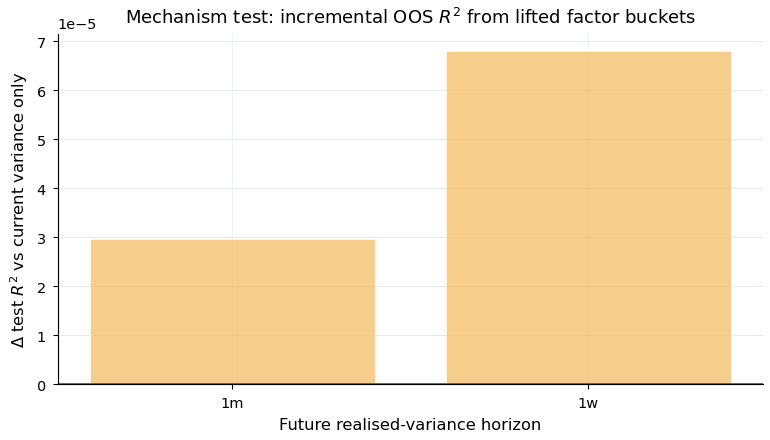

,horizon_label,test_r2,baseline_test_r2,delta_test_r2_vs_scalar,n_train,n_test
1,1m,0.626426,0.626396,0.000030,66560,57344
3,1w,0.847777,0.847709,0.000068,128000,124928


Mechanism summary: buckets improve OOS R² in 2/2 tested horizons.


In [53]:
# ============================================================
# 12. Mechanism diagnostic:
# Do lifted factor buckets predict future realised variance
# conditional on current scalar variance?
# ============================================================

import os
import numpy as np
import pandas as pd

FUTURE_RV_BUCKET_TEST_VERSION = "future_rv_bucket_prediction_v2_pathwise_integrated_variance"

# Use an existing notebook cache scope.
# The cache system only accepts registered scopes. Do not invent new ones,
# because cache manifests are validated against registered artefact scopes.
FUTURE_RV_CACHE_SCOPE = "factor_diagnostics"

# Keep horizons that are likely to exist across both train and test splits.
# Add 3m later only if the horizon/split count table confirms enough rows.
FUTURE_RV_HORIZONS = {
    "1w": 7.0 / CFG.market.calendar_days_per_year,
    "1m": 30.0 / CFG.market.calendar_days_per_year,
    # "3m": 90.0 / CFG.market.calendar_days_per_year,
}

FUTURE_RV_PANEL_PATH = (
    CFG.paths.project_root
    / CFG.paths.cache_dir
    / f"future_rv_bucket_prediction_panel_{FUTURE_RV_BUCKET_TEST_VERSION}.parquet"
)

FUTURE_RV_RESULTS_PATH = (
    CFG.paths.project_root
    / CFG.paths.cache_dir
    / f"future_rv_bucket_prediction_results_{FUTURE_RV_BUCKET_TEST_VERSION}.parquet"
)

FUTURE_RV_COEFFICIENTS_PATH = (
    CFG.paths.project_root
    / CFG.paths.cache_dir
    / f"future_rv_bucket_prediction_coefficients_{FUTURE_RV_BUCKET_TEST_VERSION}.parquet"
)

future_rv_dependencies = [
    CFG.paths.seed_panel_path,
    CFG.paths.lifted_calibration_path,
    CFG.paths.forward_variance_path,
]


# ------------------------------------------------------------
# Cleanup: remove orphan parquet files without manifests
# ------------------------------------------------------------

for p in [
    FUTURE_RV_PANEL_PATH,
    FUTURE_RV_RESULTS_PATH,
    FUTURE_RV_COEFFICIENTS_PATH,
]:
    mp = cache_manifest_path(p)
    if p.exists() and not mp.exists():
        print(f"Removing orphan cache without manifest: {p}")
        p.unlink()


# ------------------------------------------------------------
# Cache/run logic
# ------------------------------------------------------------

FUTURE_RV_PANEL_ARTIFACT = "future_rv_bucket_prediction_panel"
FUTURE_RV_RESULTS_ARTIFACT = "future_rv_bucket_prediction_results"
FUTURE_RV_COEFFICIENTS_ARTIFACT = "future_rv_bucket_prediction_coefficients"

future_rv_cache_validity = {
    "panel": cache_valid(
        FUTURE_RV_PANEL_PATH,
        FUTURE_RV_PANEL_ARTIFACT,
        FUTURE_RV_CACHE_SCOPE,
        CFG,
        dependencies=future_rv_dependencies,
    ),
    "results": cache_valid(
        FUTURE_RV_RESULTS_PATH,
        FUTURE_RV_RESULTS_ARTIFACT,
        FUTURE_RV_CACHE_SCOPE,
        CFG,
        dependencies=[FUTURE_RV_PANEL_PATH],
    ),
    "coefficients": cache_valid(
        FUTURE_RV_COEFFICIENTS_PATH,
        FUTURE_RV_COEFFICIENTS_ARTIFACT,
        FUTURE_RV_CACHE_SCOPE,
        CFG,
        dependencies=[FUTURE_RV_PANEL_PATH],
    ),
}

FUTURE_RV_CACHE_VALID = all(future_rv_cache_validity.values())

future_rv_env = os.environ.get(
    "DEEP_HEDGING_RUN_FUTURE_RV_BUCKET_TEST",
    "1",
).strip().lower()

FUTURE_RV_BUCKET_TEST_ENABLED = future_rv_env in {
    "1",
    "true",
    "yes",
    "auto",
}

RUN_FUTURE_RV_BUCKET_TEST = (
    FUTURE_RV_BUCKET_TEST_ENABLED
    and (
        bool(CFG.flags.RUN_MECHANISM_DIAGNOSTICS)
        or not FUTURE_RV_CACHE_VALID
    )
)

SKIP_FUTURE_RV_BUCKET_OUTPUTS = bool(not RUN_FUTURE_RV_BUCKET_TEST and not FUTURE_RV_CACHE_VALID)
if SKIP_FUTURE_RV_BUCKET_OUTPUTS:
    print(
        "Future-RV bucket diagnostic cache is absent/stale and the diagnostic is disabled; "
        "skipping optional mechanism output without rebuilding.",
        flush=True,
    )

print(
    {
        "future_rv_cache_valid": FUTURE_RV_CACHE_VALID,
        "future_rv_cache_validity": future_rv_cache_validity,
        "future_rv_bucket_test_enabled": FUTURE_RV_BUCKET_TEST_ENABLED,
        "run_future_rv_bucket_test": RUN_FUTURE_RV_BUCKET_TEST,
        "future_rv_panel_path": str(FUTURE_RV_PANEL_PATH),
    }
)


# ------------------------------------------------------------
# Pathwise future realised variance helpers
# ------------------------------------------------------------

def variance_cumulative_trapezoid(V: np.ndarray, times: np.ndarray) -> np.ndarray:
    """
    Pathwise cumulative integrated variance using trapezoidal integration.

    V shape:
        (n_paths, n_times)

    Returns:
        cumulative integrated variance with same path/time shape.
    """
    V = np.asarray(V, dtype=float)
    times = np.asarray(times, dtype=float)

    if V.ndim != 2:
        raise ValueError(f"Expected V with shape (n_paths, n_times), got {V.shape}.")

    if len(times) != V.shape[1]:
        raise ValueError(
            f"Variance time grid length mismatch: len(times)={len(times)}, "
            f"V.shape[1]={V.shape[1]}."
        )

    if np.any(np.diff(times) <= 0):
        raise ValueError("Simulation times must be strictly increasing.")

    dt = np.diff(times).reshape(1, -1)
    increments = 0.5 * (V[:, :-1] + V[:, 1:]) * dt

    return np.concatenate(
        [
            np.zeros((V.shape[0], 1), dtype=float),
            np.cumsum(increments, axis=1),
        ],
        axis=1,
    )


def integrated_variance_at(
    cumulative_iv: np.ndarray,
    V: np.ndarray,
    times: np.ndarray,
    tau: float,
) -> np.ndarray:
    """
    Return pathwise integrated variance from 0 to tau.

    Uses exact cumulative grid values when tau is on-grid, and linear
    interpolation of instantaneous variance inside the relevant interval
    otherwise.
    """
    tau = float(tau)
    times = np.asarray(times, dtype=float)

    if tau < times[0] - 1e-12 or tau > times[-1] + 1e-12:
        raise ValueError(
            f"Requested tau={tau:.8f} outside simulated grid "
            f"[{times[0]:.8f}, {times[-1]:.8f}]."
        )

    if np.isclose(tau, times[-1], atol=1e-12):
        return cumulative_iv[:, -1]

    j = int(np.searchsorted(times, tau, side="right") - 1)
    j = max(0, min(j, len(times) - 2))

    if np.isclose(tau, times[j], atol=1e-12):
        return cumulative_iv[:, j]

    dt_partial = tau - times[j]
    full_dt = times[j + 1] - times[j]
    weight = dt_partial / full_dt

    V_tau = (1.0 - weight) * V[:, j] + weight * V[:, j + 1]
    partial_area = 0.5 * (V[:, j] + V_tau) * dt_partial

    return cumulative_iv[:, j] + partial_area


def pathwise_future_realised_variance(
    V: np.ndarray,
    times: np.ndarray,
    t_idx: int,
    horizon: float,
    cumulative_iv: np.ndarray,
) -> np.ndarray:
    """
    Average realised variance over [t, t+h] from simulated variance paths.
    """
    start = float(times[int(t_idx)])
    end = start + float(horizon)

    if end > float(times[-1]) + 1e-12:
        raise ValueError(
            "Future realised-variance horizon exceeds option life. "
            f"start={start:.8f}, horizon={horizon:.8f}, end={end:.8f}, "
            f"max_time={times[-1]:.8f}."
        )

    iv_start = cumulative_iv[:, int(t_idx)]
    iv_end = integrated_variance_at(cumulative_iv, V, times, end)

    return (iv_end - iv_start) / float(horizon)


# ------------------------------------------------------------
# Build prediction panel
# ------------------------------------------------------------

def build_future_rv_bucket_prediction_panel(
    seed_panel: pd.DataFrame,
    cfg: ExperimentConfig,
    artifacts: ResearchArtifacts,
    horizons: dict[str, float],
) -> pd.DataFrame:
    """
    Build a pre-hedging path-state panel for testing whether lifted
    factor-bucket composition predicts future realised variance conditional
    on current scalar variance.

    This is a mechanism diagnostic only. It does not enter the main hedging
    performance table.
    """
    seeds = diagnostic_seed_sample(seed_panel, cfg)
    frames = []

    for i, (_, seed_row) in enumerate(seeds.iterrows(), 1):
        params, curve = lookup_lifted_state_by_date(
            artifacts.lifted_calibration,
            seed_row["date"],
            artifacts.forward_variance_curve,
        )

        paths = simulate_lifted_paths_np(
            seed_row,
            params,
            curve,
            artifacts.lifted_kernel,
            cfg.hedging.diagnostic_paths,
            hedge_steps_for_seed(seed_row, cfg),
            common_path_seed(seed_row, "future_rv_bucket_prediction", cfg),
            cfg.lifted.variance_floor,
            cfg,
        )

        V = np.asarray(paths["V"], dtype=float)
        U = np.asarray(paths["U"], dtype=float)
        S = np.asarray(paths["S"], dtype=float)
        times = np.asarray(paths["times"], dtype=float)

        if V.shape[:2] != S.shape[:2]:
            raise ValueError(
                f"Inconsistent S/V shapes for seed {seed_row['seed_id']}: "
                f"S={S.shape}, V={V.shape}."
            )

        if U.shape[:2] != V.shape[:2]:
            raise ValueError(
                f"Inconsistent U/V shapes for seed {seed_row['seed_id']}: "
                f"U={U.shape}, V={V.shape}."
            )

        cumulative_iv = variance_cumulative_trapezoid(V, times)

        n_time_points = min(
            int(cfg.hedging.diagnostic_time_points),
            len(times) - 1,
        )

        time_indices = np.unique(
            np.linspace(0, len(times) - 2, n_time_points)
            .round()
            .astype(int)
        )

        for t_idx in time_indices:
            t = float(times[int(t_idx)])
            remaining = float(times[-1] - t)

            bucket_frame = factor_buckets(
                U[:, int(t_idx), :],
                V[:, int(t_idx)],
                artifacts.lifted_kernel,
            )

            base = pd.DataFrame({
                "seed_id": str(seed_row["seed_id"]),
                "date": pd.Timestamp(seed_row["date"]).normalize(),
                "split": str(seed_row["split"]),
                "maturity_bucket": str(seed_row["hedge_maturity_bucket"]),
                "path_index": np.arange(V.shape[0], dtype=int),
                "time_index": int(t_idx),
                "calendar_time": t,
                "remaining_tau": remaining,
                "current_variance": V[:, int(t_idx)],
                "log_moneyness": np.log(S[:, int(t_idx)] / float(paths["K"])),
            })

            base = pd.concat(
                [base.reset_index(drop=True), bucket_frame.reset_index(drop=True)],
                axis=1,
            )

            for horizon_label, horizon in horizons.items():
                horizon = float(horizon)

                if t + horizon > float(times[-1]) + 1e-12:
                    continue

                frame = base.copy()
                frame["horizon_label"] = str(horizon_label)
                frame["horizon_years"] = horizon
                frame["future_realised_variance"] = pathwise_future_realised_variance(
                    V,
                    times,
                    int(t_idx),
                    horizon,
                    cumulative_iv,
                )

                frames.append(frame)

        print(
            f"Future-RV bucket diagnostic {i}/{len(seeds)}: "
            f"{seed_row['seed_id']}",
            flush=True,
        )

    if not frames:
        raise ValueError(
            "No future realised-variance rows were generated. "
            "Check horizons and diagnostic seed maturities."
        )

    panel = pd.concat(frames, ignore_index=True)

    required = {
        "split",
        "horizon_label",
        "future_realised_variance",
        "current_variance",
        "bucket_fast",
        "bucket_medium",
        "bucket_slow",
    }
    require_columns(panel, required, "future RV bucket prediction panel")

    numeric_cols = [
        "future_realised_variance",
        "current_variance",
        "bucket_fast",
        "bucket_medium",
        "bucket_slow",
    ]

    if not np.isfinite(panel[numeric_cols].to_numpy(dtype=float)).all():
        raise ValueError(
            "Future RV bucket prediction panel contains non-finite values."
        )

    return panel


# ------------------------------------------------------------
# Out-of-sample linear prediction test
# ------------------------------------------------------------

def fit_oos_linear_prediction_test(
    panel: pd.DataFrame,
    outcome: str,
    base_predictors: list[str],
    bucket_predictors: list[str],
    min_train_rows: int = 100,
    min_test_rows: int = 100,
) -> tuple[pd.DataFrame, pd.DataFrame]:
    """
    Out-of-sample OLS comparison using train-only standardisation.

    Compares:
      1. current scalar variance only
      2. current scalar variance + lifted fast/medium/slow buckets

    Horizons without enough train/test rows are skipped and reported.
    """
    rows = []
    coefficient_rows = []

    required_cols = (
        ["horizon_label", "split", outcome]
        + base_predictors
        + bucket_predictors
    )
    require_columns(panel, required_cols, "future RV OOS prediction panel")

    for horizon_label, g in panel.groupby("horizon_label", sort=True):
        train = g.loc[g["split"].astype(str).eq("train")].copy()
        test = g.loc[g["split"].astype(str).eq("test")].copy()

        n_train = int(len(train))
        n_test = int(len(test))

        if n_train < min_train_rows or n_test < min_test_rows:
            rows.append({
                "diagnostic": "future_realised_variance_prediction",
                "horizon_label": horizon_label,
                "model": "skipped",
                "outcome": outcome,
                "test_r2": np.nan,
                "test_rmse": np.nan,
                "baseline_test_r2": np.nan,
                "delta_test_r2_vs_scalar": np.nan,
                "n_train": n_train,
                "n_test": n_test,
                "skip_reason": (
                    f"Insufficient OOS rows for horizon {horizon_label}: "
                    f"n_train={n_train}, n_test={n_test}. "
                    "This usually happens when the forward RV horizon exceeds "
                    "the remaining option life for most sampled seeds."
                ),
                "predictors_used": "",
            })
            continue

        y_train = train[outcome].to_numpy(dtype=float)
        y_test = test[outcome].to_numpy(dtype=float)

        if not np.isfinite(y_train).all() or not np.isfinite(y_test).all():
            raise ValueError(
                f"Non-finite outcome values for horizon {horizon_label}."
            )

        model_specs = {
            "scalar_variance_only": base_predictors,
            "scalar_variance_plus_buckets": base_predictors + bucket_predictors,
        }

        horizon_results = []
        baseline_r2 = None

        for model_name, predictors in model_specs.items():
            X_train_raw = train[predictors].to_numpy(dtype=float)
            X_test_raw = test[predictors].to_numpy(dtype=float)

            if not np.isfinite(X_train_raw).all() or not np.isfinite(X_test_raw).all():
                raise ValueError(
                    f"Non-finite predictors in {model_name}, "
                    f"horizon {horizon_label}."
                )

            x_mean = X_train_raw.mean(axis=0)
            x_scale = X_train_raw.std(axis=0, ddof=0)

            non_constant = x_scale > 1e-14

            if not np.any(non_constant):
                rows.append({
                    "diagnostic": "future_realised_variance_prediction",
                    "horizon_label": horizon_label,
                    "model": model_name,
                    "outcome": outcome,
                    "test_r2": np.nan,
                    "test_rmse": np.nan,
                    "baseline_test_r2": np.nan,
                    "delta_test_r2_vs_scalar": np.nan,
                    "n_train": n_train,
                    "n_test": n_test,
                    "skip_reason": "All predictors are constant on the training split.",
                    "predictors_used": "",
                })
                continue

            kept_predictors = [
                p for p, keep in zip(predictors, non_constant) if keep
            ]

            X_train = (
                X_train_raw[:, non_constant] - x_mean[non_constant]
            ) / x_scale[non_constant]

            X_test = (
                X_test_raw[:, non_constant] - x_mean[non_constant]
            ) / x_scale[non_constant]

            X_train_design = np.column_stack([np.ones(len(X_train)), X_train])
            X_test_design = np.column_stack([np.ones(len(X_test)), X_test])

            coef, *_ = np.linalg.lstsq(X_train_design, y_train, rcond=None)
            pred = X_test_design @ coef

            sse = float(np.sum((y_test - pred) ** 2))
            sst = float(np.sum((y_test - y_test.mean()) ** 2))

            test_r2 = np.nan if sst <= 0 else 1.0 - sse / sst
            test_rmse = float(np.sqrt(np.mean((y_test - pred) ** 2)))

            if model_name == "scalar_variance_only":
                baseline_r2 = test_r2

            horizon_results.append({
                "diagnostic": "future_realised_variance_prediction",
                "horizon_label": horizon_label,
                "model": model_name,
                "outcome": outcome,
                "test_r2": float(test_r2),
                "test_rmse": test_rmse,
                "baseline_test_r2": np.nan,
                "delta_test_r2_vs_scalar": np.nan,
                "n_train": n_train,
                "n_test": n_test,
                "skip_reason": "",
                "predictors_used": ",".join(kept_predictors),
            })

            for predictor_name, value in zip(["intercept"] + kept_predictors, coef):
                coefficient_rows.append({
                    "horizon_label": horizon_label,
                    "model": model_name,
                    "predictor": predictor_name,
                    "coefficient_train_standardised": float(value),
                })

        if baseline_r2 is not None and np.isfinite(baseline_r2):
            for result in horizon_results:
                result["baseline_test_r2"] = float(baseline_r2)
                result["delta_test_r2_vs_scalar"] = float(
                    result["test_r2"] - baseline_r2
                )

        rows.extend(horizon_results)

    results = pd.DataFrame(rows)
    coefficients = pd.DataFrame(coefficient_rows)

    return results, coefficients


# ------------------------------------------------------------
# Run or load diagnostic
# ------------------------------------------------------------

if RUN_FUTURE_RV_BUCKET_TEST:
    future_rv_bucket_panel = build_future_rv_bucket_prediction_panel(
        seed_panel,
        CFG,
        RESEARCH_ARTIFACTS,
        FUTURE_RV_HORIZONS,
    )

    future_rv_horizon_split_counts = (
        future_rv_bucket_panel
        .groupby(["horizon_label", "split"])
        .size()
        .unstack(fill_value=0)
        .reset_index()
    )

    display(future_rv_horizon_split_counts)

    future_rv_bucket_regression, future_rv_bucket_coefficients = (
        fit_oos_linear_prediction_test(
            future_rv_bucket_panel,
            outcome="future_realised_variance",
            base_predictors=["current_variance"],
            bucket_predictors=["bucket_fast", "bucket_medium", "bucket_slow"],
            min_train_rows=100,
            min_test_rows=100,
        )
    )

    write_dataframe_cache(
        future_rv_bucket_panel,
        FUTURE_RV_PANEL_PATH,
        FUTURE_RV_PANEL_ARTIFACT,
        FUTURE_RV_CACHE_SCOPE,
        CFG,
        dependencies=future_rv_dependencies,
        extra={
            "horizons": FUTURE_RV_HORIZONS,
            "interpretation": (
                "Pre-hedging mechanism test: whether lifted bucket composition predicts "
                "future pathwise realised variance conditional on current scalar variance."
            ),
        },
    )

    write_dataframe_cache(
        future_rv_bucket_regression,
        FUTURE_RV_RESULTS_PATH,
        FUTURE_RV_RESULTS_ARTIFACT,
        FUTURE_RV_CACHE_SCOPE,
        CFG,
        dependencies=[FUTURE_RV_PANEL_PATH],
    )

    write_dataframe_cache(
        future_rv_bucket_coefficients,
        FUTURE_RV_COEFFICIENTS_PATH,
        FUTURE_RV_COEFFICIENTS_ARTIFACT,
        FUTURE_RV_CACHE_SCOPE,
        CFG,
        dependencies=[FUTURE_RV_PANEL_PATH],
    )

elif not SKIP_FUTURE_RV_BUCKET_OUTPUTS:
    future_rv_bucket_panel = load_dataframe_cache(
        FUTURE_RV_PANEL_PATH,
        FUTURE_RV_PANEL_ARTIFACT,
        FUTURE_RV_CACHE_SCOPE,
        CFG,
        required_columns=[
            "split",
            "horizon_label",
            "future_realised_variance",
            "current_variance",
            "bucket_fast",
            "bucket_medium",
            "bucket_slow",
        ],
        dependencies=future_rv_dependencies,
    )

    future_rv_bucket_regression = load_dataframe_cache(
        FUTURE_RV_RESULTS_PATH,
        FUTURE_RV_RESULTS_ARTIFACT,
        FUTURE_RV_CACHE_SCOPE,
        CFG,
        dependencies=[FUTURE_RV_PANEL_PATH],
    )

    future_rv_bucket_coefficients = load_dataframe_cache(
        FUTURE_RV_COEFFICIENTS_PATH,
        FUTURE_RV_COEFFICIENTS_ARTIFACT,
        FUTURE_RV_CACHE_SCOPE,
        CFG,
        dependencies=[FUTURE_RV_PANEL_PATH],
    )

    future_rv_horizon_split_counts = (
        future_rv_bucket_panel
        .groupby(["horizon_label", "split"])
        .size()
        .unstack(fill_value=0)
        .reset_index()
    )
else:
    future_rv_bucket_panel = pd.DataFrame()
    future_rv_bucket_regression = pd.DataFrame()
    future_rv_bucket_coefficients = pd.DataFrame()
    future_rv_horizon_split_counts = pd.DataFrame()


# ------------------------------------------------------------
# Display and export
# ------------------------------------------------------------

display(future_rv_horizon_split_counts)
display(future_rv_bucket_regression)

if not future_rv_bucket_coefficients.empty:
    display(future_rv_bucket_coefficients)

future_rv_export_dir = CFG.paths.table_dir
future_rv_export_dir.mkdir(parents=True, exist_ok=True)

future_rv_bucket_regression.to_csv(
    future_rv_export_dir / "mechanism_future_rv_bucket_prediction_results.csv",
    index=False,
)

future_rv_bucket_coefficients.to_csv(
    future_rv_export_dir / "mechanism_future_rv_bucket_prediction_coefficients.csv",
    index=False,
)

future_rv_horizon_split_counts.to_csv(
    future_rv_export_dir / "mechanism_future_rv_bucket_prediction_horizon_split_counts.csv",
    index=False,
)


# ------------------------------------------------------------
# Plot incremental OOS R² from bucket composition
# ------------------------------------------------------------

if MATPLOTLIB_AVAILABLE and not future_rv_bucket_regression.empty:
    plot_data = future_rv_bucket_regression.loc[
        future_rv_bucket_regression["model"].eq("scalar_variance_plus_buckets")
        & future_rv_bucket_regression["delta_test_r2_vs_scalar"].notna()
    ].copy()

    if not plot_data.empty:
        fig, ax = plt.subplots(figsize=(7, 3.5))

        vals = plot_data["delta_test_r2_vs_scalar"].astype(float)
        colors = [MODEL_COLORS["neural_factors"] if v >= 0 else MODEL_COLORS["lifted_heston"] for v in vals]
        ax.bar(
            plot_data["horizon_label"].astype(str),
            vals,
            color=colors,
            alpha=BAR_ALPHA,
            edgecolor="white",
            linewidth=0.45,
        )

        ax.axhline(0.0, linewidth=1)

        ax.set(
            title="Mechanism test: incremental OOS $R^2$ from lifted factor buckets",
            xlabel="Future realised-variance horizon",
            ylabel=r"$\Delta$ test $R^2$ vs current variance only",
        )

        ax.grid(True, axis="y", alpha=0.3)
        plt.show()

    else:
        print(
            "No non-skipped scalar_variance_plus_buckets rows available for plotting."
        )


# ------------------------------------------------------------
# Compact interpretation helper
# ------------------------------------------------------------

valid_mechanism_rows = future_rv_bucket_regression.loc[
    future_rv_bucket_regression["model"].eq("scalar_variance_plus_buckets")
    & future_rv_bucket_regression["delta_test_r2_vs_scalar"].notna()
].copy()

if not valid_mechanism_rows.empty:
    display(
        valid_mechanism_rows[
            [
                "horizon_label",
                "test_r2",
                "baseline_test_r2",
                "delta_test_r2_vs_scalar",
                "n_train",
                "n_test",
            ]
        ]
    )

    positive_count = int(
        (valid_mechanism_rows["delta_test_r2_vs_scalar"] > 0).sum()
    )
    total_count = int(len(valid_mechanism_rows))

    print(
        f"Mechanism summary: buckets improve OOS R² in "
        f"{positive_count}/{total_count} tested horizons."
    )

else:
    print(
        "Mechanism summary unavailable: no horizon had enough train/test rows "
        "after filtering."
    )

## 12.1 Lifted Factor Composition and Future-Variance Mechanism Figures

The factor-composition plots show how lifted variance is distributed across fast, medium and slow components. This is the most direct way to make the lifted state tangible. Instead of describing the model as “multi-factor” in the abstract, the plots show whether the factors actually vary across dates and maturities.

The future-variance mechanism scatter compares realised future variance against predictions using scalar variance alone and scalar variance plus lifted factor summaries. The statistical object is out-of-sample explanatory power:

$$
R^2_{\mathrm{oos}}=1-\frac{\sum_i(y_i-\hat{y}_i)^2}{\sum_i(y_i-\bar{y}_{\mathrm{train}})^2}.
$$

A positive incremental $R^2$ supports the view that factors contain additional predictive information. A near-zero or negative incremental $R^2$ should be reported honestly. A weak mechanism diagnostic should be reported as weak rather than overinterpreted.

These figures are usually appendix or mechanism-section evidence rather than headline results. The headline remains terminal hedging performance.


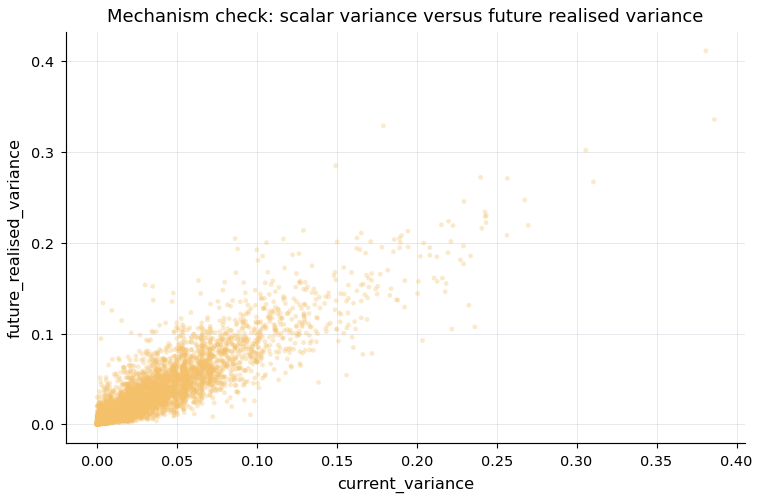

""


,item,status,notes,target_column,scalar_variance_column,n_rows,output_path
0,future_rv_mechanism_scatter,implemented,Scatter uses the available future-realised-var...,future_realised_variance,current_variance,376832,outputs_final\figures\future_rv_mechanism_scat...


In [54]:
# Lifted factor composition and mechanism figures

def factor_bucket_composition_table(factor_panel: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if factor_panel is None or factor_panel.empty:
        return pd.DataFrame()
    frame = factor_panel.copy()
    contribution_cols = [c for c in frame.columns if c.startswith("factor_contribution_")]
    if len(contribution_cols) < 3:
        return pd.DataFrame()

    fast_cols, medium_cols, slow_cols = np.array_split(contribution_cols, 3)
    frame["bucket_fast_abs"] = frame[list(fast_cols)].abs().sum(axis=1)
    frame["bucket_medium_abs"] = frame[list(medium_cols)].abs().sum(axis=1)
    frame["bucket_slow_abs"] = frame[list(slow_cols)].abs().sum(axis=1)

    group_cols = [c for c in ["split", "maturity_bucket", "hedge_maturity_bucket"] if c in frame.columns]
    if group_cols:
        out = frame.groupby(group_cols, dropna=False, as_index=False).agg(
            fast_abs=("bucket_fast_abs", "mean"),
            medium_abs=("bucket_medium_abs", "mean"),
            slow_abs=("bucket_slow_abs", "mean"),
            rows=(contribution_cols[0], "size"),
        )
    else:
        out = pd.DataFrame([{
            "fast_abs": frame["bucket_fast_abs"].mean(),
            "medium_abs": frame["bucket_medium_abs"].mean(),
            "slow_abs": frame["bucket_slow_abs"].mean(),
            "rows": len(frame),
        }])

    out.to_csv(table_path("lifted_factor_bucket_composition.csv", cfg), index=False)
    return out


def plot_factor_bucket_composition(comp: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or comp is None or comp.empty:
        return None

    label_col = _choose_col(comp, ["maturity_bucket", "hedge_maturity_bucket", "split"])
    plot = comp.copy()
    if not label_col:
        plot["label"] = "all"
        label_col = "label"

    plot = plot.groupby(label_col, as_index=False)[["fast_abs", "medium_abs", "slow_abs"]].mean()
    x = np.arange(len(plot))
    width = 0.25

    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(x - width, plot["fast_abs"], width, label="fast", color="#0072B2", alpha=0.82, edgecolor="white", linewidth=0.4)
    ax.bar(x, plot["medium_abs"], width, label="medium", color="#E69F00", alpha=0.82, edgecolor="white", linewidth=0.4)
    ax.bar(x + width, plot["slow_abs"], width, label="slow", color="#D55E00", alpha=0.82, edgecolor="white", linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(plot[label_col].astype(str), rotation=30, ha="right")
    ax.set_title("Lifted factor bucket composition")
    ax.set_xlabel(label_col)
    ax.set_ylabel("Mean absolute contribution")
    ax.grid(True, axis="y", alpha=0.3)
    compact_legend(ax, ncol=3)

    path = figure_path("lifted_factor_bucket_composition.png", cfg)
    fig.tight_layout()
    save_and_show_figure(fig, path, dpi=160)
    return path


def _cfg_random_seed(cfg: ExperimentConfig, default: int = 17_181_926) -> int:
    """Return a stable random seed regardless of the active config shape."""
    for attr_path in [
        ("random_seed",),
        ("seed",),
        ("hedging", "random_seed"),
        ("hedging", "seed"),
        ("simulation", "random_seed"),
        ("simulation", "seed"),
    ]:
        obj: Any = cfg
        for attr in attr_path:
            if not hasattr(obj, attr):
                obj = None
                break
            obj = getattr(obj, attr)
        if obj is not None:
            try:
                return int(obj)
            except (TypeError, ValueError):
                continue
    return int(default)


def plot_future_rv_mechanism_scatter(panel: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    """
    Plot a future-realised-variance mechanism scatter if the diagnostic panel exists.

    Missing target or scalar-variance columns are reported as limitations rather than
    replaced with proxy data. This diagnostic is appendix evidence, not a headline
    proof of factor usefulness.
    """
    if panel is None or panel.empty:
        out = pd.DataFrame([{
            "item": "future_rv_mechanism_scatter",
            "status": "missing",
            "notes": "future_rv_bucket_panel cache unavailable",
            "output_path": "",
        }])
        out.to_csv(table_path("future_rv_mechanism_scatter_audit.csv", cfg), index=False)
        return out

    target = _choose_col(panel, [
        "future_realised_variance", "future_realized_variance",
        "target_future_realised_variance", "target_future_realized_variance",
        "rv_future", "realised_variance_forward", "realized_variance_forward",
    ])
    xcol = _choose_col(panel, [
        "current_variance", "scalar_variance", "variance", "v_t", "V_t", "v0", "spot_variance",
    ])

    if not target or not xcol:
        out = pd.DataFrame([{
            "item": "future_rv_mechanism_scatter",
            "status": "missing_columns",
            "notes": f"target={target}; scalar_variance={xcol}",
            "output_path": "",
        }])
        out.to_csv(table_path("future_rv_mechanism_scatter_audit.csv", cfg), index=False)
        return out

    plot_frame = panel.copy()
    plot_frame[target] = pd.to_numeric(plot_frame[target], errors="coerce")
    plot_frame[xcol] = pd.to_numeric(plot_frame[xcol], errors="coerce")
    plot_frame = plot_frame.dropna(subset=[target, xcol])

    if plot_frame.empty:
        out = pd.DataFrame([{
            "item": "future_rv_mechanism_scatter",
            "status": "missing_finite_rows",
            "notes": "No finite scalar-variance/future-RV pairs available",
            "output_path": "",
        }])
        out.to_csv(table_path("future_rv_mechanism_scatter_audit.csv", cfg), index=False)
        return out

    output_path = figure_path("future_rv_mechanism_scatter_scalar_variance.png", cfg)
    if MATPLOTLIB_AVAILABLE:
        sample = (
            plot_frame.sample(5000, random_state=_cfg_random_seed(cfg))
            if len(plot_frame) > 5000 else plot_frame
        )
        fig, ax = plt.subplots(figsize=(6, 4))
        ax.scatter(sample[xcol], sample[target], s=7, alpha=0.34, color=MODEL_COLORS["neural_factors"], edgecolors="none")
        ax.set_title("Mechanism check: scalar variance versus future realised variance")
        ax.set_xlabel(xcol)
        ax.set_ylabel(target)
        ax.grid(True, alpha=0.3)
        fig.tight_layout()
        save_and_show_figure(fig, output_path, dpi=160)

    out = pd.DataFrame([{
        "item": "future_rv_mechanism_scatter",
        "status": "implemented" if MATPLOTLIB_AVAILABLE else "table_only",
        "notes": "Scatter uses the available future-realised-variance mechanism panel.",
        "target_column": target,
        "scalar_variance_column": xcol,
        "n_rows": int(len(plot_frame)),
        "output_path": str(output_path) if MATPLOTLIB_AVAILABLE else "",
    }])
    out.to_csv(table_path("future_rv_mechanism_scatter_audit.csv", cfg), index=False)
    return out


lifted_factor_bucket_composition = factor_bucket_composition_table(factor_panel, CFG)
lifted_factor_bucket_composition_path = plot_factor_bucket_composition(lifted_factor_bucket_composition, CFG)
future_rv_mechanism_scatter_audit = plot_future_rv_mechanism_scatter(
    globals().get("future_rv_bucket_panel", pd.DataFrame()),
    CFG,
)

display(lifted_factor_bucket_composition.head())
display(future_rv_mechanism_scatter_audit)

## 12.2 Lifted-Factor Concentration and Non-Redundancy

This subsection measures whether lifted variance is concentrated in a few factors or spread across many. A useful summary is the effective number of active components, often computed from normalised weights $p_i$ as

$$
N_{\mathrm{eff}}=\frac{1}{\sum_i p_i^2}.
$$

If $N_{\mathrm{eff}}$ is close to one, the lifted state behaves almost like a single dominant factor. If it is larger and varies over time, factor composition is genuinely non-redundant. This matters for the dissertation hypothesis because factor features can only add information if there is meaningful composition variation to exploit.

The interpretation must connect mechanism to performance. If factor composition is rich but raw factor policies do not improve hedging, then the information may be hard to use, too costly to trade on, or better represented through buckets/PCA/recurrent memory. If factor composition is not rich, then raw factor policies have little chance of improving over scalar variance.

This section therefore prevents vague claims about lifted memory. It asks whether the lifted state actually contains observable multi-timescale structure in the calibrated sample.


In [55]:

# Lifted-factor concentration and non-redundancy diagnostics

def lifted_factor_concentration_diagnostics(factor_panel: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if factor_panel is None or factor_panel.empty:
        out = pd.DataFrame([{"status": "missing", "notes": "factor_panel unavailable"}])
        out.to_csv(table_path("lifted_factor_concentration_nonredundancy.csv", cfg), index=False)
        return out
    f = factor_panel.copy()
    cols = [c for c in f.columns if c.startswith("factor_contribution_")]
    if len(cols) < 2:
        out = pd.DataFrame([{"status": "missing_columns", "notes": "factor_contribution_* columns unavailable"}])
        out.to_csv(table_path("lifted_factor_concentration_nonredundancy.csv", cfg), index=False)
        return out
    abs_contrib = f[cols].apply(pd.to_numeric, errors="coerce").abs()
    denom = abs_contrib.sum(axis=1).replace(0, np.nan)
    shares = abs_contrib.div(denom, axis=0)
    f["factor_herfindahl"] = (shares ** 2).sum(axis=1)
    f["factor_effective_number"] = 1.0 / f["factor_herfindahl"].replace(0, np.nan)
    f["dominant_factor_share"] = shares.max(axis=1)
    thirds = np.array_split(cols, 3)
    f["fast_share"] = shares[list(thirds[0])].sum(axis=1)
    f["medium_share"] = shares[list(thirds[1])].sum(axis=1)
    f["slow_share"] = shares[list(thirds[2])].sum(axis=1)
    group_cols = [c for c in ["split", "maturity_bucket", "hedge_maturity_bucket"] if c in f.columns]
    if not group_cols:
        group_cols = ["_all"]
        f["_all"] = "all"
    out = f.groupby(group_cols, dropna=False, as_index=False).agg(
        rows=("factor_effective_number", "size"),
        median_effective_number=("factor_effective_number", "median"),
        mean_effective_number=("factor_effective_number", "mean"),
        median_dominant_factor_share=("dominant_factor_share", "median"),
        mean_fast_share=("fast_share", "mean"),
        mean_medium_share=("medium_share", "mean"),
        mean_slow_share=("slow_share", "mean"),
    )
    out["interpretation"] = np.where(
        out["median_effective_number"] <= 2.0,
        "factor state is concentrated; raw high-dimensional vector may add limited independent information",
        "factor state is spread across timescales; composition may be economically meaningful",
    )
    out.to_csv(table_path("lifted_factor_concentration_nonredundancy.csv", cfg), index=False)
    return out


def plot_lifted_factor_effective_number(conc: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or conc is None or conc.empty or "median_effective_number" not in conc.columns:
        return None
    label_col = _choose_col(conc, ["maturity_bucket", "hedge_maturity_bucket", "split", "_all"])
    if label_col is None:
        conc = conc.assign(label="all")
        label_col = "label"
    p = conc.groupby(label_col, as_index=False)["median_effective_number"].mean()
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.bar(p[label_col].astype(str), pd.to_numeric(p["median_effective_number"], errors="coerce"), color=MODEL_COLORS["neural_factors"], alpha=0.82, edgecolor="white", linewidth=0.4)
    ax.set(title="Lifted-factor effective number by bucket", xlabel=label_col, ylabel=r"$N_{\mathrm{eff}}$")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(True, axis="y", alpha=0.3)
    path = figure_path("lifted_factor_effective_number_by_bucket.png", cfg)
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path


lifted_factor_concentration = lifted_factor_concentration_diagnostics(factor_panel, CFG)
lifted_factor_effective_number_path = plot_lifted_factor_effective_number(lifted_factor_concentration, CFG)

display(lifted_factor_concentration.head())


,status,notes
0,missing,factor_panel unavailable


# 13. Robustness and Regime Analysis

Robustness analysis checks whether the conclusions survive changes in maturity, transaction costs, volatility regimes, Hurst parameter choices and model/world transfer. This section is where the dissertation earns caution. A result that holds only under one cost level, one maturity bucket or one lucky H value should not be sold as a general finding.

The key robustness dimensions are:

- maturity buckets, because short-dated options have different skew and gamma exposure;
- transaction costs, because overtrading can reverse gross hedging gains;
- calm versus stress regimes, because volatility dynamics change across market states;
- H-sensitivity, because fixed $H$ is a modelling choice rather than an estimated universal truth;
- cross-world transfer, because a policy that only works in its own simulator may be model-specific.

The purpose is not to make every result survive every stress test. The purpose is to identify where the claim is strong, where it is conditional and where it fails. Conditional findings are acceptable in an MSc dissertation. Treating them as unconditional would overstate the evidence.


In [56]:

# Optional, explicitly separated robustness analysis.
# This now judges H sensitivity using both full-surface fit loss and the direct ATM-skew diagnostic.


def run_lifted_h_sensitivity(
    surface: pd.DataFrame,
    heston_calib: pd.DataFrame,
    forward_curve: pd.DataFrame,
    accepted_dates: Iterable[pd.Timestamp],
    cfg: ExperimentConfig,
    *,
    return_fit_table: bool = False,
) -> pd.DataFrame | tuple[pd.DataFrame, pd.DataFrame]:
    accepted = sorted(pd.to_datetime(list(accepted_dates)).normalize())[: int(cfg.lifted.robustness_max_dates)]
    if not accepted:
        raise ValueError("H-sensitivity requires accepted calibration dates.")
    hlookup = heston_calib.assign(date=pd.to_datetime(heston_calib["date"]).dt.normalize()).set_index("date")
    rows = []
    fit_rows = []
    for H in cfg.lifted.h_sensitivity_values:
        local_cfg = replace(cfg, lifted=replace(cfg.lifted, H=float(H)))
        kernel = build_abi_zaugg_lifted_kernel(local_cfg.lifted)
        pricer = LiftedRiccatiFourierPricer(kernel, local_cfg.lifted.pricing_nodes, local_cfg.lifted.riccati_steps, local_cfg.lifted.delta_coefficient_cache_size)
        for date in accepted:
            day = surface.loc[pd.to_datetime(surface["date"]).dt.normalize().eq(date)]
            target = make_heston_market_target(day, cfg.calibration, profile="full_surface")
            hr = hlookup.loc[date]
            hr = hr.iloc[0] if isinstance(hr, pd.DataFrame) else hr
            initial = HestonParams(float(hr.kappa), float(hr.theta), float(hr.xi), float(hr.rho), float(hr.v0))
            curve = lifted_curve_for_date(forward_curve, date)
            result = LiftedHestonCalibrator(pricer, local_cfg, curve).calibrate(target, initial)
            row, fit, _, _ = _lifted_result_to_rows(result, local_cfg, kernel)
            row["sensitivity_H"] = float(H)
            rows.append(row)
            if return_fit_table:
                fit = fit.copy()
                fit["sensitivity_H"] = float(H)
                fit["H"] = float(H)
                fit["diagnostic_version"] = "h_sensitivity_fit_table_for_short_skew_v1"
                fit_rows.append(fit)
    panel = pd.DataFrame(rows)
    if not return_fit_table:
        return panel
    fit_table = pd.concat(fit_rows, ignore_index=True) if fit_rows else pd.DataFrame()
    return panel, fit_table


def prepare_lifted_h_sensitivity_iv_panel(
    h_fit: pd.DataFrame,
    surface: pd.DataFrame,
    cfg: ExperimentConfig,
) -> pd.DataFrame:
    if h_fit is None or h_fit.empty:
        return pd.DataFrame()
    require_columns(h_fit, {"date", "strike", "T", "market_price", "model_price", "sensitivity_H"}, "H-sensitivity fit table")
    out = _normalise_fit_keys(h_fit)
    s = _surface_attachment_for_skew(surface)
    out = out.merge(s, on=["date", "strike_key", "T_key"], how="left", suffixes=("", "_surface"))
    out["spot_for_iv"] = _coalesce_numeric_columns(out, ["spot_ref", "spot_ref_surface", "S"], default=np.nan)
    out["r_for_iv"] = _coalesce_numeric_columns(out, ["r", "r_surface"], default=0.0)
    out["q_for_iv"] = _coalesce_numeric_columns(out, ["q", "q_surface"], default=0.0)
    out["forward_for_moneyness"] = _coalesce_numeric_columns(out, ["forward_ref", "forward_ref_surface"])
    missing_forward = ~np.isfinite(out["forward_for_moneyness"])
    out.loc[missing_forward, "forward_for_moneyness"] = (
        out.loc[missing_forward, "spot_for_iv"]
        * np.exp((out.loc[missing_forward, "r_for_iv"] - out.loc[missing_forward, "q_for_iv"]) * out.loc[missing_forward, "T"])
    )
    out["log_forward_moneyness_for_skew"] = np.log(out["strike"] / out["forward_for_moneyness"])
    out["abs_log_forward_moneyness_for_skew"] = out["log_forward_moneyness_for_skew"].abs()
    if "maturity_bucket" not in out.columns or out["maturity_bucket"].isna().all():
        dte = pd.to_numeric(out.get("dte", out["T"] * cfg.market.calendar_days_per_year), errors="coerce")
        out["maturity_bucket"] = pd.cut(dte, bins=[0, 10, 21, 45, 75, 120, 10_000], labels=["1W", "2W", "1M", "2M", "3M", "LONG"], right=True).astype(str)
    out["fit_weight_for_skew"] = _coalesce_numeric_columns(out, ["fit_weight", "fit_weight_surface"], default=1.0).clip(lower=1e-12)
    out["market_iv"] = _coalesce_numeric_columns(out, ["iv_market", "iv_market_surface", "iv_proxy", "iv_proxy_surface"])
    vols_market = []
    vols_lifted = []
    for row in out[["market_price", "model_price", "spot_for_iv", "strike", "r_for_iv", "q_for_iv", "T"]].itertuples(index=False):
        market_price, model_price, spot, strike, r, q, T = [float(x) for x in row]
        vols_market.append(implied_vol_single(market_price, spot, strike, r, q, T, option_type="call"))
        vols_lifted.append(implied_vol_single(model_price, spot, strike, r, q, T, option_type="call"))
    out["market_iv_from_price"] = np.asarray(vols_market, dtype=float)
    out["lifted_iv"] = np.asarray(vols_lifted, dtype=float)
    out["market_iv"] = out["market_iv"].where(np.isfinite(out["market_iv"]), out["market_iv_from_price"])
    finite = (
        np.isfinite(out["market_iv"])
        & np.isfinite(out["lifted_iv"])
        & np.isfinite(out["log_forward_moneyness_for_skew"])
        & np.isfinite(out["fit_weight_for_skew"])
        & out["fit_weight_for_skew"].gt(0)
    )
    return out.loc[finite].reset_index(drop=True)


def build_lifted_h_sensitivity_skew_diagnostics(
    h_iv_panel: pd.DataFrame,
    *,
    moneyness_windows: tuple[float, ...] = SHORT_SKEW_MONEYNESS_WINDOWS,
    min_points: int = 4,
) -> pd.DataFrame:
    if h_iv_panel is None or h_iv_panel.empty:
        return pd.DataFrame()
    rows = []
    for window in moneyness_windows:
        local = h_iv_panel.loc[h_iv_panel["abs_log_forward_moneyness_for_skew"].le(float(window))].copy()
        for (H, date, bucket), g in local.groupby(["sensitivity_H", "date", "maturity_bucket"], observed=False, sort=True):
            market_a, market_b, n_market = _weighted_local_linear_slope(g["log_forward_moneyness_for_skew"], g["market_iv"], g["fit_weight_for_skew"], min_points=min_points)
            lifted_a, lifted_b, n_lifted = _weighted_local_linear_slope(g["log_forward_moneyness_for_skew"], g["lifted_iv"], g["fit_weight_for_skew"], min_points=min_points)
            rows.append({
                "diagnostic_version": "h_sensitivity_atm_skew_v1",
                "sensitivity_H": float(H),
                "date": pd.Timestamp(date).normalize(),
                "maturity_bucket": str(bucket),
                "moneyness_window_abs_log_forward": float(window),
                "n_points": int(len(g)),
                "n_market_fit_points": int(n_market),
                "n_lifted_fit_points": int(n_lifted),
                "market_atm_skew_slope": market_b,
                "lifted_atm_skew_slope": lifted_b,
                "lifted_abs_skew_error": abs(lifted_b - market_b) if np.isfinite(lifted_b) and np.isfinite(market_b) else np.nan,
            })
    out = pd.DataFrame(rows)
    if out.empty:
        return out
    finite = np.isfinite(out["lifted_abs_skew_error"])
    return out.loc[finite].sort_values(["sensitivity_H", "moneyness_window_abs_log_forward", "date", "maturity_bucket"]).reset_index(drop=True)


def summarise_lifted_h_sensitivity_skew_and_residuals(
    h_panel: pd.DataFrame,
    h_fit: pd.DataFrame,
) -> pd.DataFrame:
    rows = []
    if h_panel is not None and not h_panel.empty:
        for (H, window, bucket), g in h_panel.groupby(["sensitivity_H", "moneyness_window_abs_log_forward", "maturity_bucket"], observed=False, sort=True):
            rows.append({
                "diagnostic_version": "h_sensitivity_skew_and_very_short_residual_v1",
                "sensitivity_H": float(H),
                "moneyness_window_abs_log_forward": float(window),
                "maturity_bucket": str(bucket),
                "n_date_maturity_fits": int(len(g)),
                "median_lifted_abs_skew_error": float(g["lifted_abs_skew_error"].median()),
                "mean_lifted_abs_skew_error": float(g["lifted_abs_skew_error"].mean()),
            })
    out = pd.DataFrame(rows)
    if h_fit is not None and not h_fit.empty:
        f = h_fit.copy()
        if "maturity_bucket" not in f.columns:
            f = f.merge(_surface_attachment_for_skew(surface_panel), on=["date", "strike_key", "T_key"], how="left") if {"strike_key", "T_key"}.issubset(f.columns) else _normalise_fit_keys(f).merge(_surface_attachment_for_skew(surface_panel), on=["date", "strike_key", "T_key"], how="left")
        if "log_moneyness" not in f.columns:
            if "forward_ref" in f.columns:
                f["log_moneyness"] = np.log(pd.to_numeric(f["strike"], errors="coerce") / pd.to_numeric(f["forward_ref"], errors="coerce"))
            else:
                f["log_moneyness"] = np.nan
        f["abs_log_moneyness"] = pd.to_numeric(f["log_moneyness"], errors="coerce").abs()
        f["abs_vega_scaled_error"] = pd.to_numeric(f["vega_scaled_error"], errors="coerce").abs()
        residual_rows = []
        for H, g in f.groupby("sensitivity_H", sort=True):
            very_short_near = g.loc[g["maturity_bucket"].isin(VERY_SHORT_BUCKETS) & g["abs_log_moneyness"].le(0.05)]
            residual_rows.append({
                "sensitivity_H": float(H),
                "very_short_1W_2W_near_ATM_rows": int(len(very_short_near)),
                "very_short_1W_2W_near_ATM_median_abs_vega_scaled_error": float(very_short_near["abs_vega_scaled_error"].median()) if not very_short_near.empty else np.nan,
            })
        residual_summary = pd.DataFrame(residual_rows)
        if out.empty:
            out = residual_summary
        else:
            out = out.merge(residual_summary, on="sensitivity_H", how="left")
    return out.reset_index(drop=True)


robustness_dependencies = [CFG.paths.surface_cache_path, CFG.paths.heston_calibration_path, CFG.paths.forward_variance_path, CFG.paths.calibration_quality_path]
if CFG.flags.RUN_ROBUSTNESS:
    h_sensitivity_results, h_sensitivity_fit_table = run_lifted_h_sensitivity(
        surface_panel, heston_calibration, forward_variance_curve, accepted_calibration_dates, CFG, return_fit_table=True
    )
    write_dataframe_cache(h_sensitivity_results, CFG.paths.h_sensitivity_path, "lifted_h_sensitivity", "robustness", CFG, dependencies=robustness_dependencies)
    h_sensitivity_fit_table.to_parquet(CFG.paths.output_dir / "lifted_h_sensitivity_fit_table.parquet", index=False)
else:
    try:
        h_sensitivity_results = load_dataframe_cache(CFG.paths.h_sensitivity_path, "lifted_h_sensitivity", "robustness", CFG, dependencies=robustness_dependencies)
    except (FileNotFoundError, ValueError):
        h_sensitivity_results = pd.DataFrame()
        print("Optional H-sensitivity cache is absent; set RUN_ROBUSTNESS=True to build it.")
    fit_cache = CFG.paths.output_dir / "lifted_h_sensitivity_fit_table.parquet"
    h_sensitivity_fit_table = pd.read_parquet(fit_cache) if fit_cache.exists() else pd.DataFrame()

h_sensitivity_iv_panel = prepare_lifted_h_sensitivity_iv_panel(h_sensitivity_fit_table, surface_panel, CFG) if not h_sensitivity_fit_table.empty else pd.DataFrame()
h_sensitivity_skew_diagnostics = build_lifted_h_sensitivity_skew_diagnostics(h_sensitivity_iv_panel)
h_sensitivity_skew_summary = summarise_lifted_h_sensitivity_skew_and_residuals(h_sensitivity_skew_diagnostics, h_sensitivity_fit_table)

CFG.paths.table_dir.mkdir(parents=True, exist_ok=True)
if not h_sensitivity_fit_table.empty:
    h_sensitivity_fit_table.to_csv(CFG.paths.table_dir / "lifted_h_sensitivity_fit_table.csv", index=False)
if not h_sensitivity_iv_panel.empty:
    h_sensitivity_iv_panel.to_csv(CFG.paths.table_dir / "lifted_h_sensitivity_iv_panel.csv", index=False)
if not h_sensitivity_skew_diagnostics.empty:
    h_sensitivity_skew_diagnostics.to_csv(CFG.paths.table_dir / "lifted_h_sensitivity_atm_skew_diagnostics.csv", index=False)
if not h_sensitivity_skew_summary.empty:
    h_sensitivity_skew_summary.to_csv(CFG.paths.table_dir / "lifted_h_sensitivity_skew_summary.csv", index=False)

display(h_sensitivity_results.head())
display(h_sensitivity_skew_summary.head())
if MATPLOTLIB_AVAILABLE and not h_sensitivity_skew_summary.empty:
    summary = h_sensitivity_skew_summary.loc[
        h_sensitivity_skew_summary["maturity_bucket"].isin(VERY_SHORT_BUCKETS)
        & np.isclose(pd.to_numeric(h_sensitivity_skew_summary["moneyness_window_abs_log_forward"], errors="coerce"), 0.05)
    ].groupby("sensitivity_H", as_index=False).agg(
        median_lifted_abs_skew_error=("median_lifted_abs_skew_error", "median"),
        very_short_near_ATM_residual=("very_short_1W_2W_near_ATM_median_abs_vega_scaled_error", "median"),
    )
    if not summary.empty:
        fig, ax = plt.subplots(figsize=(6, 3))
        ax.plot(summary["sensitivity_H"], summary["median_lifted_abs_skew_error"], marker="o", label="1W/2W ATM-skew error")
        ax.axvline(CFG.lifted.H, linestyle="--", label="core H")
        ax.set(title="Lifted-Heston H sensitivity: very-short ATM skew", xlabel="H", ylabel="Median absolute skew-slope error")
        ax.grid(True, alpha=0.3)
        ax.legend()
        plt.show()


C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1029445293.py:348: RuntimeWarning: overflow encountered in exp
  cf = np.exp(x * z + phi)
C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1029445293.py:358: RuntimeWarning: invalid value encountered in multiply
  P2 = 0.5 + np.real(fourier_kernel * phi2.reshape(1, -1)) @ quadrature / np.pi
C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1029445293.py:348: RuntimeWarning: overflow encountered in exp
  cf = np.exp(x * z + phi)
C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1029445293.py:353: RuntimeWarning: invalid value encountered in divide
  phi1 = cf[1:1+n] / denominator
C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1029445293.py:348: RuntimeWarning: overflow encountered in exp
  cf = np.exp(x * z + phi)
C:\Users\lhkke\AppData\Local\Temp\ipykernel_36544\1029445293.py:358: RuntimeWarning: invalid value encountered in multiply
  P2 = 0.5 + np.real(fourier_kernel * phi2.reshape(1, -1)) @ quadrature / np.pi


[cache fingerprint] hashing lifted_h_sensitivity.parquet (0.0 MB); sidecar=333d65ce1ba3df272093cc854f79fc15e18b0b255978c0217c1decc5cd5fcb60.json
[cache fingerprint] complete lifted_h_sensitivity.parquet in 0.01s


,date,profile,kappa,theta,xi,rho,v0,H,n_factors,rn_scale,loss,vega_scaled_rmse,price_rmse,success,raw_optimizer_success,final_candidate_was_valid,candidate_source,invalid_residual_evaluations,last_invalid_reason,quality_flag,optimizer_nfev,calibration_backend,forward_curve_regularization_version,forward_curve_smoothness,forward_curve_curvature_smoothness,calibration_parameterization,calibrated_parameters,cpu_seconds,sensitivity_H
0,2010-01-04,full_surface,0.031971,0.057417,0.316488,-0.677904,0.049913,0.1,20,2.5,1.739318e-07,0.000417,0.083976,True,True,True,optimizer_final,37,Lifted Riccati aggregate exploded at midpoint ...,OK,15,lifted_riccati_fourier_regularised_forward_cur...,regularised_near_atm_total_variance_v1,0.002,0.02,full_5p_forward_curve_init,"kappa,theta,xi,rho,v0",24.135621,0.1
1,2010-01-05,full_surface,0.499427,0.059199,0.244470,-0.262362,0.040370,0.1,20,2.5,1.817929e-04,0.013483,4.288994,True,True,True,optimizer_final,23,Lifted Riccati aggregate exploded before midpo...,OK,35,lifted_riccati_fourier_regularised_forward_cur...,regularised_near_atm_total_variance_v1,0.002,0.02,full_5p_forward_curve_init,"kappa,theta,xi,rho,v0",5.819192,0.1
2,2010-01-06,full_surface,1.999262,0.053059,0.241864,-0.700795,0.040686,0.1,20,2.5,8.450824e-05,0.009193,2.408525,True,True,True,optimizer_final,37,Lifted Riccati aggregate exploded at midpoint ...,OK,29,lifted_riccati_fourier_regularised_forward_cur...,regularised_near_atm_total_variance_v1,0.002,0.02,full_5p_forward_curve_init,"kappa,theta,xi,rho,v0",14.056365,0.1
3,2010-01-07,full_surface,1.999313,0.052347,0.239563,-0.700767,0.038231,0.1,20,2.5,7.025781e-05,0.008382,2.167649,True,True,True,optimizer_final,36,Lifted Riccati aggregate exploded at midpoint ...,OK,24,lifted_riccati_fourier_regularised_forward_cur...,regularised_near_atm_total_variance_v1,0.002,0.02,full_5p_forward_curve_init,"kappa,theta,xi,rho,v0",14.728480,0.1
4,2010-01-08,full_surface,1.999022,0.050802,0.252709,-0.701091,0.036252,0.1,20,2.5,5.058077e-05,0.007112,2.004596,True,True,True,optimizer_final,38,Lifted Riccati aggregate exploded before midpo...,OK,31,lifted_riccati_fourier_regularised_forward_cur...,regularised_near_atm_total_variance_v1,0.002,0.02,full_5p_forward_curve_init,"kappa,theta,xi,rho,v0",17.226027,0.1


,diagnostic_version,sensitivity_H,moneyness_window_abs_log_forward,maturity_bucket,n_date_maturity_fits,median_lifted_abs_skew_error,mean_lifted_abs_skew_error,very_short_1W_2W_near_ATM_rows,very_short_1W_2W_near_ATM_median_abs_vega_scaled_error
0,h_sensitivity_skew_and_very_short_residual_v1,0.10,0.03,nan,6,0.141291,0.127978,0,NaN
1,h_sensitivity_skew_and_very_short_residual_v1,0.10,0.05,nan,6,0.146977,0.123221,0,NaN
2,h_sensitivity_skew_and_very_short_residual_v1,0.20,0.03,nan,6,0.006890,0.026416,0,NaN
3,h_sensitivity_skew_and_very_short_residual_v1,0.20,0.05,nan,6,0.008279,0.025565,0,NaN
4,h_sensitivity_skew_and_very_short_residual_v1,0.25,0.03,nan,6,0.005254,0.007277,0,NaN


## 13.1 H-Sensitivity Interpretation

The H-sensitivity analysis tests how lifted-Heston diagnostics change as the fixed roughness parameter $H$ varies. Livieri-style option-implied roughness evidence motivates values around $H\approx0.3$, but that does not mean $H=0.30$ or $H=0.35$ is automatically optimal for this hedging panel. The notebook therefore includes $H=0.25$ to inspect the possible elbow between $H=0.20$ and $H=0.30$.

The interpretation should separate three concepts:

1. **Roughness evidence:** whether volatility proxies exhibit fractional scaling.
2. **Calibration fit:** whether a fixed-$H$ lifted model fits the relevant option panel.
3. **Hedging value:** whether the resulting factor state improves terminal net hedging performance.

A better H-sensitivity calibration curve does not by itself determine the best hedging model. It indicates which lifted specification produces more plausible market-state inputs. The hedging evaluation must still decide whether those inputs are useful for trading.

The dissertation should explicitly avoid claiming that the selected $H$ is the true universal roughness of SPX volatility. It is a fixed modelling specification, supported and limited by option-implied roughness evidence and by the notebook's sensitivity diagnostics.


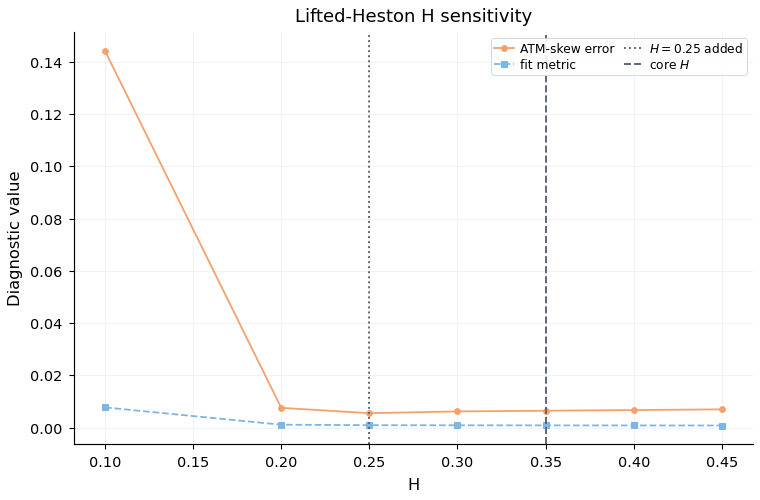

,sensitivity_H,median_fit_metric,median_abs_skew_error,status,in_configured_grid
0,0.10,0.007747,0.144134,computed,True
1,0.20,0.001137,0.007584,computed,True
2,0.25,0.000951,0.005534,computed,True
3,0.30,0.000903,0.006218,computed,True
4,0.35,0.000868,0.006475,computed,True
5,0.40,0.000841,0.006737,computed,True
6,0.45,0.000822,0.007001,computed,True


In [57]:

# Dissertation H-sensitivity plot with H=0.25 included in the configured grid

def h_sensitivity_dissertation_summary(results: pd.DataFrame, skew_summary: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    rows = []
    if results is not None and not results.empty and "sensitivity_H" in results.columns:
        r = results.copy()
        metric = _choose_col(r, ["median_abs_vega_scaled_error", "iv_rmse", "vega_scaled_rmse", "objective"])
        if metric:
            rows.append(r.groupby("sensitivity_H", as_index=False)[metric].median().rename(columns={metric: "median_fit_metric"}))
    if skew_summary is not None and not skew_summary.empty and "sensitivity_H" in skew_summary.columns:
        s = skew_summary.copy()
        metric = _choose_col(s, ["median_lifted_abs_skew_error", "mean_lifted_abs_skew_error"])
        if metric:
            rows.append(s.groupby("sensitivity_H", as_index=False)[metric].median().rename(columns={metric: "median_abs_skew_error"}))
    if not rows:
        out = pd.DataFrame({"sensitivity_H": list(cfg.lifted.h_sensitivity_values), "status": "configured_not_computed"})
    else:
        out = rows[0]
        for frame in rows[1:]:
            out = out.merge(frame, on="sensitivity_H", how="outer")
        out["status"] = "computed"
    out["in_configured_grid"] = out["sensitivity_H"].astype(float).isin([float(x) for x in cfg.lifted.h_sensitivity_values])
    out.to_csv(table_path("h_sensitivity_dissertation_summary.csv", cfg), index=False)
    return out.sort_values("sensitivity_H")


def plot_h_sensitivity_summary(summary: pd.DataFrame, cfg: ExperimentConfig) -> Path | None:
    if not MATPLOTLIB_AVAILABLE or summary is None or summary.empty or "status" not in summary.columns or not summary["status"].eq("computed").any():
        return None
    fig, ax = plt.subplots(figsize=(6, 4))
    if "median_abs_skew_error" in summary.columns:
        ax.plot(summary["sensitivity_H"], summary["median_abs_skew_error"], marker="o", label="ATM-skew error", linewidth=1.0, color=MODEL_COLORS["lifted_heston"], linestyle="-")
    if "median_fit_metric" in summary.columns:
        ax.plot(summary["sensitivity_H"], summary["median_fit_metric"], marker="s", label="fit metric", linewidth=1.0, color=MODEL_COLORS["heston"], linestyle="--")
    ax.axvline(0.25, linestyle=":", label="$H=0.25$ added")
    ax.axvline(cfg.lifted.H, linestyle="--", label="core $H$")
    ax.set(title="Lifted-Heston H sensitivity", xlabel="H", ylabel="Diagnostic value")
    standardise_axis(ax, legend=True, ncol=2)
    path = figure_path("h_sensitivity_with_H025.png", cfg)
    save_and_show_figure(plt.gcf(), path, dpi=160)
    return path

h_sensitivity_dissertation = h_sensitivity_dissertation_summary(h_sensitivity_results, h_sensitivity_skew_summary, CFG)
h_sensitivity_with_H025_path = plot_h_sensitivity_summary(h_sensitivity_dissertation, CFG)
display(h_sensitivity_dissertation)


# 14. Final Evidence Gate and Dissertation Tables

This section consolidates the final dissertation-ready outputs. Its role is not to repeat every diagnostic. It checks that the active methodology produced the evidence needed to support the empirical chapter: calibration tables, skew diagnostics, hedging performance tables, cost and turnover metrics, mechanism summaries, robustness outputs and limitations.

The final evidence gate distinguishes critical failures from warnings. Critical failures are issues that would invalidate headline conclusions, such as missing hedging-panel results, unmatched calibration rows, fake pricing, synthetic IVs, missing evaluation rows or leakage in train/test splits. Warnings are missing optional or appendix diagnostics that should be disclosed but do not necessarily invalidate the main claim.

The final tables are intentionally clean. Internal debugging columns should not leak into dissertation exports unless they are needed to understand the result. The aim is to create tables that can be moved into the dissertation with minimal manual surgery.

The section also provides a claim-to-evidence map. Each empirical claim should point to a table, figure and limitation. This prevents the final write-up from making claims that the notebook did not actually support. This enforces the principle that conclusions must follow documented evidence.


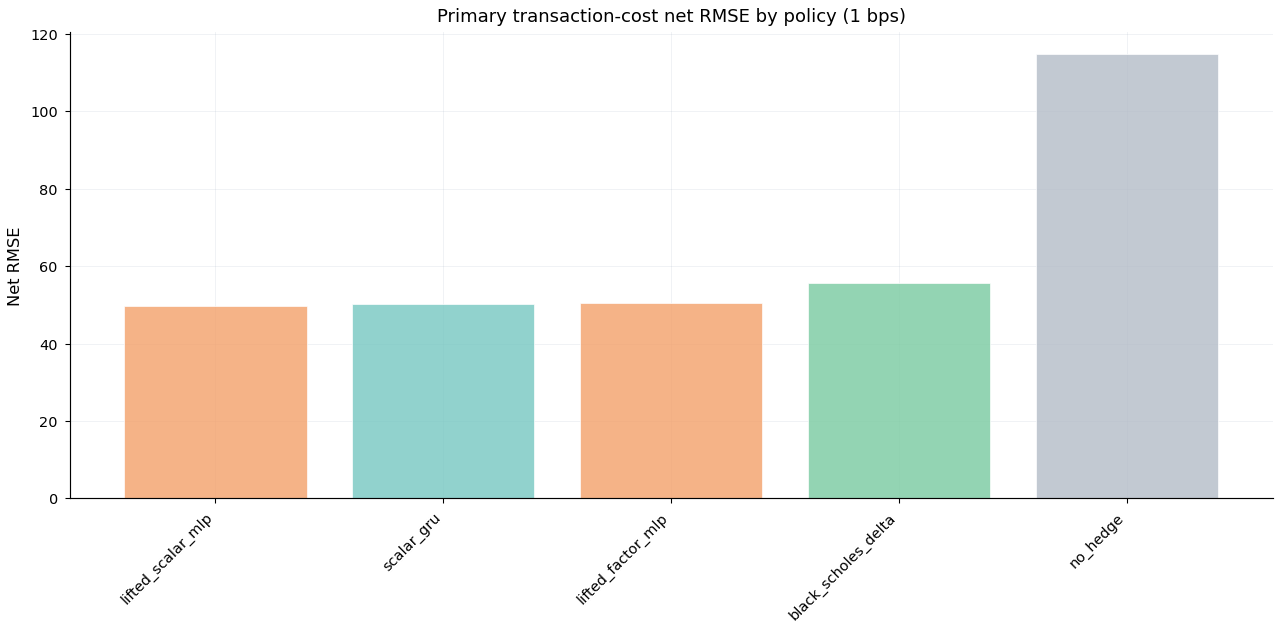

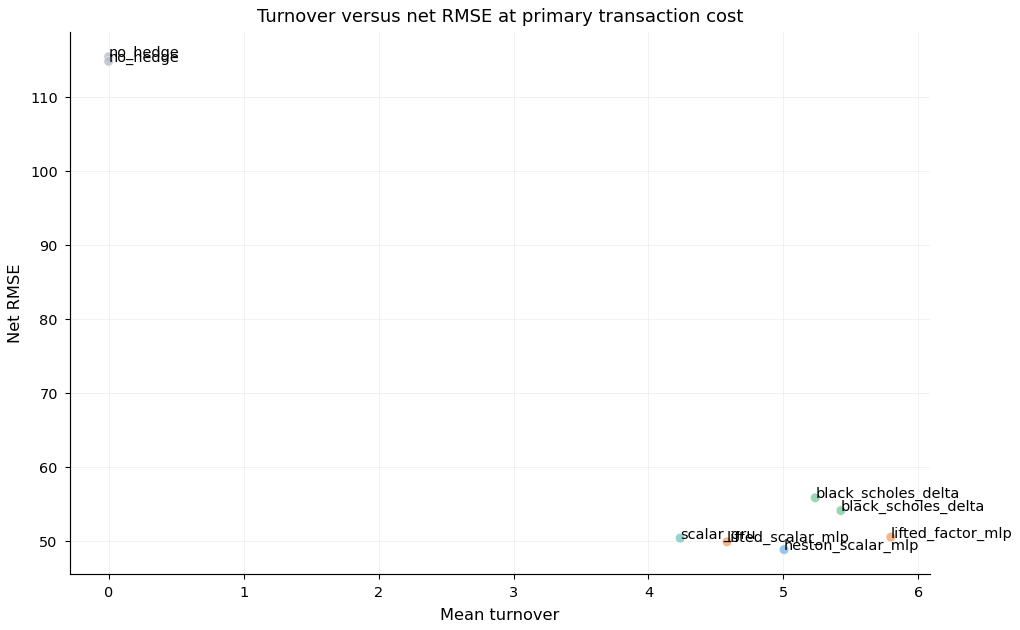

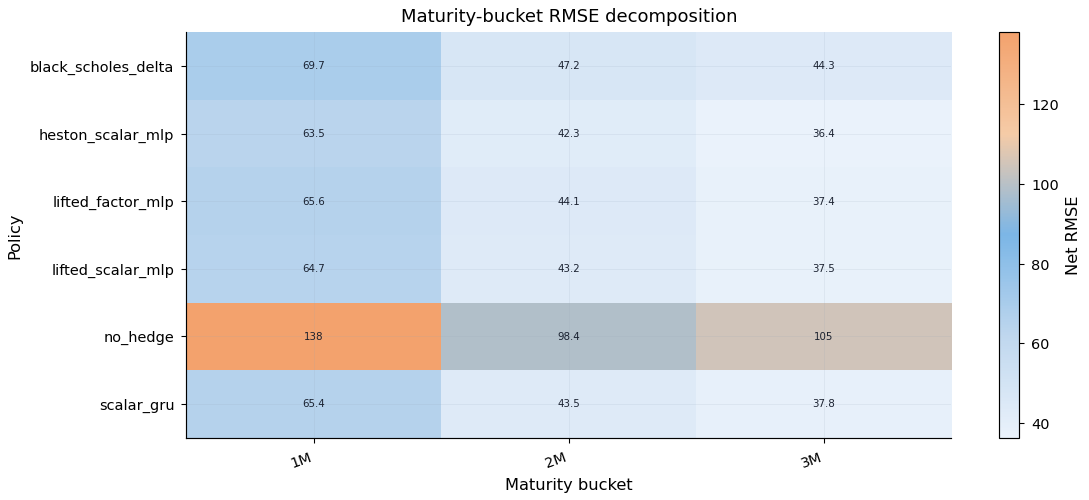

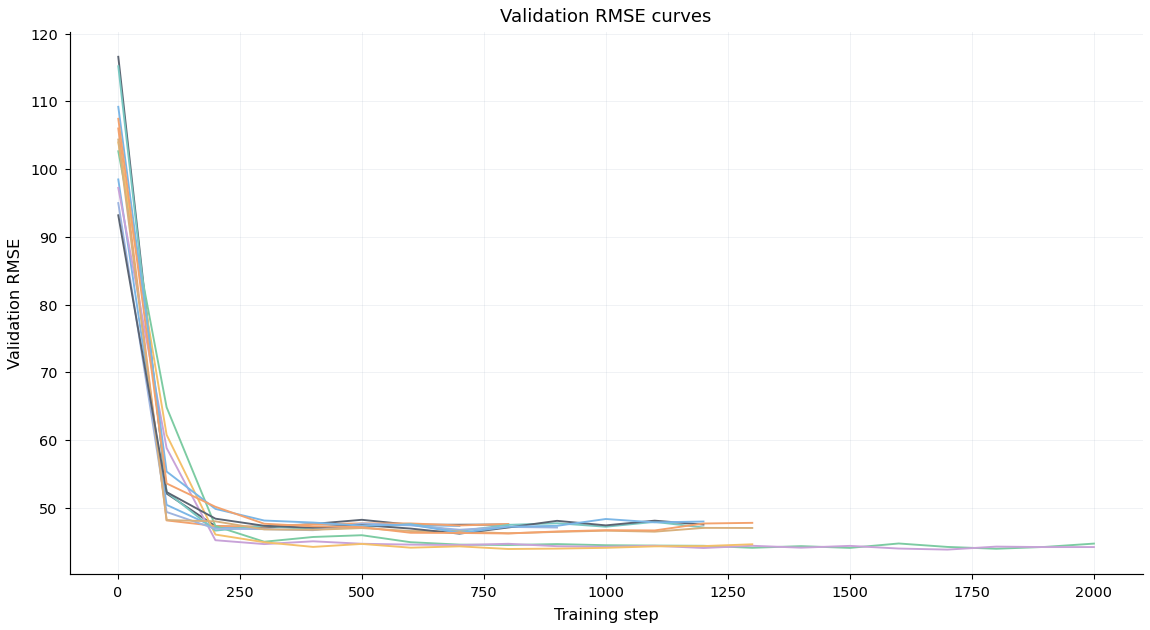

[final reporting] wrote tables to outputs_final\tables
[final reporting] wrote figures to outputs_final\figures


,claim_or_gate,status,evidence
0,Core neural policies evaluated on final feasib...,PASS,evaluation_rows=684; neural_policies=['heston_...
1,No-hedge and Black-Scholes baselines present,PASS,"baseline_presence={'no_hedge': True, 'black_sc..."
2,Strict stochastic-volatility model-delta bench...,WARN,model_delta_policies=[]
3,No-trade-band benchmark rows present,WARN,no_trade_band_policies=[]
4,Maturity-bucket decomposition complete at prim...,PASS,"present=['1M', '2M', '3M']; required=['1M', '2..."
5,Paired date-clustered inference generated,PASS,paired_rows=18
6,Lifted-factor claim guarded against overstatement,PASS,Interpret lifted-factor evidence using paired ...


,simulation_world,policy,training_world,dates,seeds,training_seeds,mse,gross_mse,cvar_5_loss,mean_transaction_costs,mean_turnover,rmse,gross_rmse,rank_by_world_rmse
0,heston,heston_scalar_mlp,heston,12,12,3,2380.807515,2354.752410,111.933643,1.208305,5.005060,48.793519,48.525791,1.0
1,heston,black_scholes_delta,analytic,12,12,1,2923.415285,2868.889778,139.954644,1.306526,5.425814,54.068616,53.562018,2.0
2,heston,no_hedge,analytic,12,12,1,13314.611488,13314.611488,323.871604,0.000000,0.000000,115.388957,115.388957,3.0
3,lifted,lifted_scalar_mlp,lifted,12,12,3,2484.640445,2469.555917,113.120560,1.093086,4.581590,49.846168,49.694627,1.0
4,lifted,scalar_gru,lifted,12,12,3,2534.934599,2520.481195,114.890497,0.997203,4.234687,50.348134,50.204394,2.0
5,lifted,lifted_factor_mlp,lifted,12,12,3,2547.766641,2543.105482,115.566758,1.355002,5.795792,50.475406,50.429213,3.0
6,lifted,black_scholes_delta,analytic,12,12,1,3113.166601,3072.367130,140.008546,1.250820,5.235467,55.795758,55.428938,4.0
7,lifted,no_hedge,analytic,12,12,1,13173.274804,13173.274804,326.029095,0.000000,0.000000,114.774888,114.774888,5.0


In [58]:

# ============================================================
# Final reporting and claim-audit layer
# ============================================================

FINAL_REPORTING_VERSION = "final_reporting_v1_benchmark_completion_tables_figures"


def _load_frame_from_path(path: Path) -> pd.DataFrame:
    if not path.exists():
        return pd.DataFrame()
    if path.suffix.lower() == ".parquet":
        return pd.read_parquet(path)
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    raise ValueError(f"Unsupported table path: {path}")


def _frame_from_globals_or_path(name: str, path: Path | None = None) -> pd.DataFrame:
    obj = globals().get(name)
    if isinstance(obj, pd.DataFrame):
        return obj.copy()
    if path is not None:
        return _load_frame_from_path(Path(path))
    return pd.DataFrame()


def _n_unique(frame: pd.DataFrame, col: str) -> int:
    return int(frame[col].nunique()) if isinstance(frame, pd.DataFrame) and col in frame.columns and not frame.empty else 0


def _has_policy(results: pd.DataFrame, pattern: str) -> bool:
    return isinstance(results, pd.DataFrame) and not results.empty and results.get("policy", pd.Series(dtype=str)).astype(str).str.contains(pattern, regex=False).any()


def _primary_within(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if results.empty:
        return results.copy()
    out = results.copy()
    if "transaction_cost_bps" in out.columns:
        out = out.loc[np.isclose(out["transaction_cost_bps"].astype(float), float(cfg.hedging.primary_transaction_cost_bps))].copy()
    if "cross_world" in out.columns:
        out = out.loc[~out["cross_world"].fillna(False).astype(bool)].copy()
    return out


def make_experiment_coverage_table(cfg: ExperimentConfig) -> pd.DataFrame:
    heston = _frame_from_globals_or_path("heston_calibration", cfg.paths.heston_calibration_path)
    lifted = _frame_from_globals_or_path("lifted_calibration", cfg.paths.lifted_calibration_path)
    candidate = _frame_from_globals_or_path("candidate_seed_panel", cfg.paths.candidate_seed_panel_path)
    final_seed = _frame_from_globals_or_path("seed_panel", cfg.paths.seed_panel_path)
    feasibility = _frame_from_globals_or_path("simulation_feasibility_manifest", cfg.paths.simulation_feasibility_manifest_path)
    raw_manifest = _frame_from_globals_or_path("raw_tensor_bank_manifest", cfg.paths.raw_tensor_bank_manifest_path)
    train_hist = _frame_from_globals_or_path("training_history", cfg.paths.training_history_path)
    eval_results = _frame_from_globals_or_path("evaluation_results", cfg.paths.evaluation_path)
    model_delta = _frame_from_globals_or_path("model_delta_validation", cfg.paths.model_delta_validation_path)
    bands = _frame_from_globals_or_path("no_trade_band_validation", cfg.paths.no_trade_band_path)

    rows = [
        {"section": "calibration", "item": "heston_calibration_dates", "value": _n_unique(heston, "date")},
        {"section": "calibration", "item": "lifted_calibration_dates", "value": _n_unique(lifted, "date")},
        {"section": "seed_panel", "item": "candidate_seed_rows", "value": len(candidate)},
        {"section": "seed_panel", "item": "final_feasible_seed_rows", "value": len(final_seed)},
        {"section": "seed_panel", "item": "final_train_rows", "value": int(final_seed.get("split", pd.Series(dtype=str)).eq("train").sum()) if not final_seed.empty else 0},
        {"section": "seed_panel", "item": "final_val_rows", "value": int(final_seed.get("split", pd.Series(dtype=str)).eq("val").sum()) if not final_seed.empty else 0},
        {"section": "seed_panel", "item": "final_test_rows", "value": int(final_seed.get("split", pd.Series(dtype=str)).eq("test").sum()) if not final_seed.empty else 0},
        {"section": "readiness", "item": "simulation_feasibility_rows", "value": len(feasibility)},
        {"section": "readiness", "item": "simulation_feasibility_failures", "value": int(feasibility.get("status", pd.Series(dtype=str)).astype(str).eq("fail").sum()) if not feasibility.empty else 0},
        {"section": "tensor_bank", "item": "raw_tensor_manifest_rows", "value": len(raw_manifest)},
        {"section": "training", "item": "training_history_rows", "value": len(train_hist)},
        {"section": "evaluation", "item": "evaluation_seed_level_rows", "value": len(eval_results)},
        {"section": "benchmark", "item": "strict_model_delta_validation_rows", "value": len(model_delta)},
        {"section": "benchmark", "item": "no_trade_band_validation_rows", "value": len(bands)},
    ]
    return pd.DataFrame(rows)


def make_final_policy_performance_table(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    if results.empty:
        return pd.DataFrame()
    required = {"policy", "simulation_world", "training_world", "cross_world", "transaction_cost_bps", "date", "seed_id", "mse", "gross_mse", "cvar_5_loss", "mean_transaction_costs", "mean_turnover"}
    missing = required - set(results.columns)
    if missing:
        raise ValueError(f"Evaluation results missing required reporting columns: {sorted(missing)}")
    group_cols = ["simulation_world", "policy", "training_world", "cross_world", "transaction_cost_bps"]
    out = (
        results.groupby(group_cols, dropna=False, as_index=False)
        .agg(
            dates=("date", "nunique"),
            seeds=("seed_id", "nunique"),
            training_seeds=("training_seed", "nunique"),
            mse=("mse", "mean"),
            gross_mse=("gross_mse", "mean"),
            mean_error=("mean_error", "mean"),
            std_error=("std_error", "mean"),
            mae=("mae", "mean"),
            var_5_loss=("var_5_loss", "mean"),
            cvar_5_loss=("cvar_5_loss", "mean"),
            mean_transaction_costs=("mean_transaction_costs", "mean"),
            mean_turnover=("mean_turnover", "mean"),
        )
    )
    out["rmse"] = np.sqrt(out["mse"])
    out["gross_rmse"] = np.sqrt(out["gross_mse"])
    out = out.sort_values(["simulation_world", "transaction_cost_bps", "cross_world", "rmse", "policy"]).reset_index(drop=True)
    return out


def make_final_maturity_decomposition_table(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    primary = _primary_within(results, cfg)
    if primary.empty:
        return pd.DataFrame()
    group_cols = ["simulation_world", "maturity_bucket", "policy", "training_world"]
    out = (
        primary.groupby(group_cols, dropna=False, as_index=False)
        .agg(
            dates=("date", "nunique"),
            seeds=("seed_id", "nunique"),
            mse=("mse", "mean"),
            gross_mse=("gross_mse", "mean"),
            cvar_5_loss=("cvar_5_loss", "mean"),
            mean_transaction_costs=("mean_transaction_costs", "mean"),
            mean_turnover=("mean_turnover", "mean"),
        )
    )
    out["rmse"] = np.sqrt(out["mse"])
    out["gross_rmse"] = np.sqrt(out["gross_mse"])
    bucket_order = {b: i for i, b in enumerate(cfg.hedging.maturity_buckets)}
    out["bucket_order"] = out["maturity_bucket"].map(bucket_order).fillna(999).astype(int)
    return out.sort_values(["simulation_world", "bucket_order", "rmse", "policy"]).drop(columns=["bucket_order"]).reset_index(drop=True)


def make_neural_architecture_comparison_table(results: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    primary = _primary_within(results, cfg)
    if primary.empty:
        return pd.DataFrame()
    policies = [
        "heston_scalar_mlp",
        "lifted_scalar_mlp",
        "lifted_factor_mlp",
        "scalar_gru",
        "lifted_factor_gru",
        "heston_model_delta",
        "lifted_model_delta",
        "heston_model_delta_no_trade_band",
        "lifted_model_delta_no_trade_band",
        "black_scholes_delta",
        "no_hedge",
    ]
    primary = primary.loc[primary["policy"].isin(policies)].copy()
    if primary.empty:
        return pd.DataFrame()
    out = (
        primary.groupby(["simulation_world", "policy", "training_world"], dropna=False, as_index=False)
        .agg(
            dates=("date", "nunique"),
            seeds=("seed_id", "nunique"),
            training_seeds=("training_seed", "nunique"),
            mse=("mse", "mean"),
            gross_mse=("gross_mse", "mean"),
            cvar_5_loss=("cvar_5_loss", "mean"),
            mean_transaction_costs=("mean_transaction_costs", "mean"),
            mean_turnover=("mean_turnover", "mean"),
        )
    )
    out["rmse"] = np.sqrt(out["mse"])
    out["gross_rmse"] = np.sqrt(out["gross_mse"])
    out["rank_by_world_rmse"] = out.groupby("simulation_world")["rmse"].rank(method="dense")
    return out.sort_values(["simulation_world", "rank_by_world_rmse", "policy"]).reset_index(drop=True)


def make_final_paired_inference_table(paired: pd.DataFrame) -> pd.DataFrame:
    if paired.empty:
        return pd.DataFrame()
    keep = [
        "comparison",
        "policy_a",
        "policy_b",
        "simulation_world",
        "maturity_bucket",
        "transaction_cost_bps",
        "n_dates",
        "n_training_seeds",
        "paired_mse_difference",
        "mse_difference_ci_low",
        "mse_difference_ci_high",
        "relative_mse_improvement",
        "relative_improvement_ci_low",
        "relative_improvement_ci_high",
        "mean_tail_difference",
        "mean_cost_difference",
    ]
    keep = [c for c in keep if c in paired.columns]
    out = paired[keep].copy()
    sort_cols = [c for c in ["comparison", "simulation_world", "transaction_cost_bps", "maturity_bucket"] if c in out.columns]
    return out.sort_values(sort_cols).reset_index(drop=True) if sort_cols else out.reset_index(drop=True)


def make_claim_audit_table(results: pd.DataFrame, paired: pd.DataFrame, cfg: ExperimentConfig) -> pd.DataFrame:
    primary = _primary_within(results, cfg)
    policies = set(results["policy"].astype(str)) if isinstance(results, pd.DataFrame) and "policy" in results.columns else set()
    maturity_present = set(primary.get("maturity_bucket", pd.Series(dtype=str)).astype(str)) if not primary.empty else set()
    required_buckets = set(map(str, cfg.hedging.maturity_buckets))
    rows = [
        {
            "claim_or_gate": "Core neural policies evaluated on final feasible test panel",
            "status": "PASS" if any(p.endswith("_mlp") or p.endswith("_gru") for p in policies) else "WARN",
            "evidence": f"evaluation_rows={len(results)}; neural_policies={sorted([p for p in policies if p.endswith('_mlp') or p.endswith('_gru')])}",
        },
        {
            "claim_or_gate": "No-hedge and Black-Scholes baselines present",
            "status": "PASS" if {"no_hedge", "black_scholes_delta"}.issubset(policies) else "WARN",
            "evidence": f"baseline_presence={{'no_hedge': {'no_hedge' in policies}, 'black_scholes_delta': {'black_scholes_delta' in policies}}}",
        },
        {
            "claim_or_gate": "Strict stochastic-volatility model-delta benchmark rows present",
            "status": "PASS" if any("model_delta" in p and "no_trade" not in p for p in policies) else "WARN",
            "evidence": f"model_delta_policies={sorted([p for p in policies if 'model_delta' in p and 'no_trade' not in p])}",
        },
        {
            "claim_or_gate": "No-trade-band benchmark rows present",
            "status": "PASS" if any("no_trade_band" in p for p in policies) else "WARN",
            "evidence": f"no_trade_band_policies={sorted([p for p in policies if 'no_trade_band' in p])}",
        },
        {
            "claim_or_gate": "Maturity-bucket decomposition complete at primary cost",
            "status": "PASS" if required_buckets.issubset(maturity_present) else "WARN",
            "evidence": f"present={sorted(maturity_present)}; required={sorted(required_buckets)}",
        },
        {
            "claim_or_gate": "Paired date-clustered inference generated",
            "status": "PASS" if isinstance(paired, pd.DataFrame) and not paired.empty else "WARN",
            "evidence": f"paired_rows={len(paired)}",
        },
        {
            "claim_or_gate": "Lifted-factor claim guarded against overstatement",
            "status": "PASS",
            "evidence": "Interpret lifted-factor evidence using paired inference and turnover/cost diagnostics; do not infer value from RMSE alone.",
        },
    ]
    return pd.DataFrame(rows)


def write_final_reporting_tables_and_figures(
    cfg: ExperimentConfig,
    coverage: pd.DataFrame,
    performance: pd.DataFrame,
    maturity: pd.DataFrame,
    architecture: pd.DataFrame,
    paired_final: pd.DataFrame,
    claim_audit: pd.DataFrame,
    training: pd.DataFrame,
) -> None:
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    cfg.paths.figure_dir.mkdir(parents=True, exist_ok=True)
    tables = {
        "final_experiment_coverage_table.csv": coverage,
        "final_policy_performance_table.csv": performance,
        "final_maturity_decomposition_table.csv": maturity,
        "final_neural_architecture_comparison_table.csv": architecture,
        "final_paired_inference_table.csv": paired_final,
        "final_claim_audit_table.csv": claim_audit,
    }
    for name, frame in tables.items():
        if isinstance(frame, pd.DataFrame) and not frame.empty:
            frame.to_csv(cfg.paths.table_dir / name, index=False)

    if not MATPLOTLIB_AVAILABLE:
        print("[final reporting] Matplotlib unavailable; skipped figures.", flush=True)
        return

    if not architecture.empty:
        fig_data = architecture.copy()
        fig_data = fig_data.loc[fig_data["simulation_world"].eq("lifted")].copy() if "simulation_world" in fig_data.columns else fig_data
        if not fig_data.empty:
            fig_data = fig_data.sort_values("rmse")
            plt.figure(figsize=(10, 5))
            plt.bar(fig_data["policy"].astype(str), fig_data["rmse"].astype(float), color=[model_color(p) for p in fig_data["policy"].astype(str)], alpha=0.82, edgecolor="white", linewidth=0.45)
            plt.xticks(rotation=45, ha="right")
            plt.ylabel("Net RMSE")
            plt.title(f"Primary transaction-cost net RMSE by policy ({cfg.hedging.primary_transaction_cost_bps:g} bps)")
            plt.tight_layout()
            save_and_show_figure(plt.gcf(), cfg.paths.figure_dir / "final_primary_cost_rmse_by_policy.png", dpi=180)

    if not performance.empty and {"mean_turnover", "rmse", "policy"}.issubset(performance.columns):
        fig_data = performance.loc[np.isclose(performance["transaction_cost_bps"].astype(float), float(cfg.hedging.primary_transaction_cost_bps))].copy()
        fig_data = fig_data.loc[~fig_data.get("cross_world", pd.Series(False, index=fig_data.index)).fillna(False).astype(bool)].copy()
        if not fig_data.empty:
            plt.figure(figsize=(8, 5))
            plt.scatter(fig_data["mean_turnover"].astype(float), fig_data["rmse"].astype(float), c=[model_color(p) for p in fig_data["policy"].astype(str)], s=28, alpha=0.78, edgecolors="white", linewidths=0.35)
            for _, row in fig_data.iterrows():
                plt.annotate(str(row["policy"]), (float(row["mean_turnover"]), float(row["rmse"])), fontsize=8)
            plt.xlabel("Mean turnover")
            plt.ylabel("Net RMSE")
            plt.title("Turnover versus net RMSE at primary transaction cost")
            plt.tight_layout()
            save_and_show_figure(plt.gcf(), cfg.paths.figure_dir / "final_turnover_vs_rmse_primary_cost.png", dpi=180)

    if not maturity.empty and {"policy", "maturity_bucket", "rmse"}.issubset(maturity.columns):
        heat = maturity.pivot_table(index="policy", columns="maturity_bucket", values="rmse", aggfunc="mean")
        ordered_cols = [b for b in cfg.hedging.maturity_buckets if b in heat.columns]
        heat = heat[ordered_cols] if ordered_cols else heat
        if not heat.empty:
            fig, ax = plt.subplots(figsize=(9, max(4, 0.32 * len(heat))))
            plot_annotated_heatmap(
                heat,
                ax=ax,
                fig=fig,
                title="Maturity-bucket RMSE decomposition",
                xlabel="Maturity bucket",
                ylabel="Policy",
                cbar_label="Net RMSE",
                cmap=ERROR_CMAP,
                fmt=None,
                rotation=20,
            )
            save_and_show_figure(fig, cfg.paths.figure_dir / "final_maturity_bucket_rmse_heatmap.png", dpi=260, description="Maturity-bucket RMSE decomposition", notes="Heatmap cells are annotated with RMSE values.")

    if isinstance(training, pd.DataFrame) and not training.empty and {"step", "val_rmse", "policy", "training_seed"}.issubset(training.columns):
        plt.figure(figsize=(9, 5))
        for (policy, seed), g in training.groupby(["policy", "training_seed"], dropna=False):
            g = g.sort_values("step")
            plt.plot(g["step"].astype(float), g["val_rmse"].astype(float), label=f"{policy}:{seed}")
        plt.xlabel("Training step")
        plt.ylabel("Validation RMSE")
        plt.title("Validation RMSE curves")
        if training[["policy", "training_seed"]].drop_duplicates().shape[0] <= 10:
            compact_legend(plt.gca(), ncol=2)
        plt.tight_layout()
        save_and_show_figure(plt.gcf(), cfg.paths.figure_dir / "final_validation_rmse_training_curves.png", dpi=180)


# Load from live notebook state first; in final_reporting mode, fall back to saved output files.
evaluation_results_for_reporting = _frame_from_globals_or_path("evaluation_results", CFG.paths.evaluation_path)
paired_inference_for_reporting = _frame_from_globals_or_path("paired_inference", CFG.paths.paired_inference_path)
training_history_for_reporting = _frame_from_globals_or_path("training_history", CFG.paths.training_history_path)

if CFG.flags.RUN_FINAL_REPORTING:
    final_experiment_coverage_table = make_experiment_coverage_table(CFG)
    final_policy_performance_table = make_final_policy_performance_table(evaluation_results_for_reporting, CFG)
    final_maturity_decomposition_table = make_final_maturity_decomposition_table(evaluation_results_for_reporting, CFG)
    final_neural_architecture_comparison_table = make_neural_architecture_comparison_table(evaluation_results_for_reporting, CFG)
    final_paired_inference_table = make_final_paired_inference_table(paired_inference_for_reporting)
    final_claim_audit_table = make_claim_audit_table(evaluation_results_for_reporting, paired_inference_for_reporting, CFG)
    write_final_reporting_tables_and_figures(
        CFG,
        final_experiment_coverage_table,
        final_policy_performance_table,
        final_maturity_decomposition_table,
        final_neural_architecture_comparison_table,
        final_paired_inference_table,
        final_claim_audit_table,
        training_history_for_reporting,
    )
    FINAL_REPORTING_TABLES = {
        "final_experiment_coverage_table": final_experiment_coverage_table,
        "final_policy_performance_table": final_policy_performance_table,
        "final_maturity_decomposition_table": final_maturity_decomposition_table,
        "final_neural_architecture_comparison_table": final_neural_architecture_comparison_table,
        "final_paired_inference_table": final_paired_inference_table,
        "final_claim_audit_table": final_claim_audit_table,
    }
    print(f"[final reporting] wrote tables to {CFG.paths.table_dir}", flush=True)
    print(f"[final reporting] wrote figures to {CFG.paths.figure_dir}", flush=True)
    display(final_claim_audit_table)
    display(final_neural_architecture_comparison_table.head(20))
else:
    FINAL_REPORTING_TABLES = {}
    print("[final reporting] RUN_FINAL_REPORTING=False; skipped final dissertation tables/figures.", flush=True)


## 14.1 Policy Performance Tables

The policy-performance tables are the numerical core of the results chapter. They should report each policy's terminal risk, tail risk, turnover and realised cost under the active transaction-cost setting and evaluation world. Where possible, they should also include maturity and regime breakdowns.

The main interpretive hierarchy is:

1. net terminal RMSE and tail risk;
2. realised transaction cost and turnover;
3. confidence intervals and win rates;
4. maturity/regime robustness;
5. mechanism and feature-attribution diagnostics.

No single table should be forced to answer every question. The final performance table ranks policies on headline metrics. Supporting tables explain whether those rankings are robust, cost-efficient and mechanism-consistent.

The table should keep gross and net results separate. Gross hedging error describes replication quality before costs. Net hedging error describes implementable performance after costs. For a stock-only costly hedging dissertation, net performance is the headline object.


In [59]:

# ============================================================
# Unified comparable policy table
# ============================================================

COMPARABLE_POLICY_TABLE_VERSION = "final_comparable_policy_table_v4_pass2_simple"


def _read_existing_table(path: Path) -> pd.DataFrame:
    path = Path(path)
    if not path.exists():
        return pd.DataFrame()
    if path.suffix.lower() == ".parquet":
        return pd.read_parquet(path)
    if path.suffix.lower() == ".csv":
        return pd.read_csv(path)
    return pd.DataFrame()


def _load_seed_level_primary_outputs(cfg: ExperimentConfig) -> pd.DataFrame:
    candidates = [
        cfg.paths.table_dir / "hedging_evaluation_seed_level.csv",
        cfg.paths.evaluation_path,
    ]
    live = globals().get("evaluation_results")
    if isinstance(live, pd.DataFrame) and not live.empty:
        return live.copy()
    for path in candidates:
        frame = _read_existing_table(path)
        if not frame.empty:
            return frame
    return pd.DataFrame()


def _load_factor_extension_outputs(cfg: ExperimentConfig) -> pd.DataFrame:
    # Prefer production-scale factor-memory extension outputs. The reduced raw-tensor diagnostic remains available,
    # but it must never be silently merged as if it were comparable to the 10,000-path production table.
    for live_name in ["factor_memory_extension_production_evaluation", "factor_memory_extension_evaluation"]:
        live = globals().get(live_name)
        if isinstance(live, pd.DataFrame) and not live.empty:
            return live.copy()
    for path in [
        cfg.paths.table_dir / "factor_memory_extension_production_evaluation_seed_level.csv",
        cfg.paths.output_dir / "factor_memory_extension_production_evaluation.parquet",
        cfg.paths.table_dir / "factor_memory_extension_evaluation_seed_level.csv",
        cfg.paths.output_dir / "factor_memory_extension_evaluation.parquet",
    ]:
        frame = _read_existing_table(path)
        if not frame.empty:
            return frame
    return pd.DataFrame()


def _is_production_factor_extension(frame: pd.DataFrame, cfg: ExperimentConfig) -> bool:
    if frame is None or frame.empty or "n_paths" not in frame.columns:
        return False
    vals = sorted(pd.to_numeric(frame["n_paths"], errors="coerce").dropna().unique().astype(int).tolist())
    modes = set(frame.get("evaluation_mode", pd.Series(dtype=str)).dropna().astype(str).unique())
    production_mode = (
        not modes
        or any(("production" in m.lower() and "10000" in m) or ("main_production" in m.lower()) for m in modes)
    )
    return vals == [int(cfg.hedging.n_paths_test)] and production_mode


def _core_policy_representation(policy: str, simulation_world: str) -> str:
    p = str(policy)
    if p == "no_hedge":
        return "none"
    if p == "black_scholes_delta":
        return "black_scholes_delta"
    if "no_trade_band" in p:
        return "strict_model_delta_no_trade_band"
    if "model_delta" in p:
        return "strict_model_delta"
    if p == "lifted_scalar_mlp":
        return "aggregate_lifted_variance"
    if p == "lifted_factor_mlp":
        return "raw20_lifted_factors"
    if p == "heston_scalar_mlp":
        return "heston_scalar_variance"
    if p == "scalar_gru":
        return "learned_scalar_memory"
    if p == "lifted_factor_gru":
        return "raw20_lifted_factors_recurrent"
    return "policy_specific"


def _summarise_policy_rows(
    frame: pd.DataFrame,
    *,
    cfg: ExperimentConfig,
    evaluation_scope: str,
    evaluation_role: str,
    use_for_headline: bool,
    direct_comparable_to_production: bool,
    comparison_group: str,
    default_simulation_world: str | None = None,
) -> pd.DataFrame:
    if frame.empty:
        return pd.DataFrame()
    required = {"policy", "transaction_cost_bps", "seed_id", "date", "mse", "rmse", "gross_mse", "gross_rmse", "mean_transaction_costs", "mean_turnover"}
    missing = required - set(frame.columns)
    if missing:
        raise ValueError(f"Cannot make comparable policy table; missing columns: {sorted(missing)}")
    out = frame.copy()
    out = out.loc[np.isclose(pd.to_numeric(out["transaction_cost_bps"], errors="coerce"), float(cfg.hedging.primary_transaction_cost_bps))].copy()
    if out.empty:
        return pd.DataFrame()
    if "cross_world" in out.columns:
        out = out.loc[~out["cross_world"].fillna(False).astype(bool)].copy()
    if out.empty:
        return pd.DataFrame()
    if "simulation_world" not in out.columns and default_simulation_world is not None:
        out["simulation_world"] = default_simulation_world
    if "training_world" not in out.columns:
        out["training_world"] = out.get("simulation_world", pd.Series("unknown", index=out.index))
    if "training_seed" not in out.columns:
        out["training_seed"] = -1
    if "n_paths" not in out.columns:
        # Older evaluation caches did not persist n_paths even though the production
        # evaluation path used cfg.hedging.n_paths_test. Infer only for explicitly
        # production-scoped rows; leave diagnostics as NaN so they cannot sneak into
        # headline results.
        if "main_production" in str(evaluation_scope):
            out["n_paths"] = int(cfg.hedging.n_paths_test)
        else:
            out["n_paths"] = np.nan
    if "architecture" not in out.columns:
        out["architecture"] = out["policy"].astype(str).map(lambda p: "mlp" if "mlp" in p else ("gru" if "gru" in p else "analytic"))
    if "representation" not in out.columns:
        out["representation"] = [
            _core_policy_representation(p, w) for p, w in zip(out["policy"].astype(str), out["simulation_world"].astype(str))
        ]
    if "weight_decay_multiplier" not in out.columns:
        out["weight_decay_multiplier"] = np.nan
    if "evaluation_mode" not in out.columns:
        out["evaluation_mode"] = evaluation_scope

    group_cols = [
        "simulation_world", "policy", "training_world", "transaction_cost_bps",
        "architecture", "representation", "weight_decay_multiplier",
    ]
    grouped = out.groupby(group_cols, dropna=False, as_index=False).agg(
        rows=("policy", "size"),
        dates=("date", "nunique"),
        seeds=("seed_id", "nunique"),
        training_seeds=("training_seed", "nunique"),
        n_paths_min=("n_paths", "min"),
        n_paths_median=("n_paths", "median"),
        n_paths_max=("n_paths", "max"),
        mse_mean=("mse", "mean"),
        rmse_mean_row=("rmse", "mean"),
        gross_mse_mean=("gross_mse", "mean"),
        gross_rmse_mean_row=("gross_rmse", "mean"),
        mean_error=("mean_error", "mean") if "mean_error" in out.columns else ("mse", "mean"),
        mae=("mae", "mean") if "mae" in out.columns else ("mse", "mean"),
        var_5_loss=("var_5_loss", "mean") if "var_5_loss" in out.columns else ("mse", "mean"),
        cvar_5_loss=("cvar_5_loss", "mean") if "cvar_5_loss" in out.columns else ("mse", "mean"),
        mean_transaction_costs=("mean_transaction_costs", "mean"),
        mean_turnover=("mean_turnover", "mean"),
    )
    grouped["rmse_pooled_sqrt_mean_mse"] = np.sqrt(pd.to_numeric(grouped["mse_mean"], errors="coerce"))
    grouped["gross_rmse_pooled_sqrt_mean_mse"] = np.sqrt(pd.to_numeric(grouped["gross_mse_mean"], errors="coerce"))
    grouped["evaluation_scope"] = evaluation_scope
    grouped["n_paths"] = grouped["n_paths_median"]
    grouped["evaluation_mode"] = evaluation_scope
    grouped["evaluation_role"] = evaluation_role
    grouped["comparison_group"] = comparison_group
    grouped["use_for_headline_result"] = bool(use_for_headline)
    grouped["direct_comparable_to_main_production"] = bool(direct_comparable_to_production)
    grouped["headline_eligible"] = (
        grouped["n_paths_median"].astype(float).eq(float(cfg.hedging.n_paths_test))
        & grouped["direct_comparable_to_main_production"].astype(bool)
        & grouped["use_for_headline_result"].astype(bool)
    )
    grouped["diagnostic_only"] = ~grouped["headline_eligible"]
    grouped["deterministic_panel_version"] = cfg.panel.deterministic_panel_version
    if "seed_panel" in globals() and isinstance(globals()["seed_panel"], pd.DataFrame) and "deterministic_panel_hash" in globals()["seed_panel"].columns:
        grouped["deterministic_panel_hash"] = str(globals()["seed_panel"]["deterministic_panel_hash"].dropna().astype(str).iloc[0])
    else:
        grouped["deterministic_panel_hash"] = "not_available"
    grouped["primary_cost_bps"] = float(cfg.hedging.primary_transaction_cost_bps)
    grouped["rmse_pooled_definition"] = "sqrt(mean(seed_or_training_seed_level_mse))"
    grouped["rmse_mean_row_definition"] = "mean(seed_or_training_seed_level_rmse)"
    grouped["metric_warning"] = np.where(
        grouped["direct_comparable_to_main_production"],
        "Production-scale row; suitable for headline comparisons within this scope.",
        "Diagnostic/reduced-path row; compare within diagnostic scope only, not as a production win over core policies.",
    )
    return grouped


def make_final_unified_policy_comparison_table(cfg: ExperimentConfig) -> pd.DataFrame:
    production = _load_seed_level_primary_outputs(cfg)
    extension = _load_factor_extension_outputs(cfg)
    pieces = []
    if not production.empty:
        pieces.append(_summarise_policy_rows(
            production,
            cfg=cfg,
            evaluation_scope="main_production_10000_test_paths_per_seed",
            evaluation_role="headline_core_production",
            use_for_headline=True,
            direct_comparable_to_production=True,
            comparison_group="main_production_only",
        ))
    if not extension.empty:
        ext_is_prod = _is_production_factor_extension(extension, cfg)
        pieces.append(_summarise_policy_rows(
            extension,
            cfg=cfg,
            evaluation_scope="main_production_10000_test_paths_per_seed" if ext_is_prod else "factor_memory_diagnostic_512_raw_tensor_test_bank",
            evaluation_role="factor_memory_production_extension" if ext_is_prod else "mechanism_extension_diagnostic",
            use_for_headline=bool(ext_is_prod),
            direct_comparable_to_production=bool(ext_is_prod),
            comparison_group="main_production_plus_factor_extensions" if ext_is_prod else "factor_memory_extension_only",
            default_simulation_world="lifted",
        ))
    if not pieces:
        return pd.DataFrame()
    combined = pd.concat([p for p in pieces if not p.empty], ignore_index=True)
    # Within the diagnostic extension, compare against the raw20 MLP baseline using the same aggregation.
    combined["rmse_pooled_change_vs_scope_baseline"] = np.nan
    combined["turnover_change_vs_scope_baseline"] = np.nan
    combined["cost_change_vs_scope_baseline"] = np.nan
    for scope, baseline_policy in [
        ("factor_memory_diagnostic_512_raw_tensor_test_bank", "factor_raw20_mlp_wd1"),
        ("main_production_10000_test_paths_per_seed", "lifted_scalar_mlp"),
    ]:
        mask_scope = combined["evaluation_scope"].eq(scope)
        base = combined.loc[mask_scope & combined["policy"].astype(str).eq(baseline_policy)].copy()
        if base.empty:
            continue
        # Use one baseline per simulation world where possible.
        for world, b in base.groupby("simulation_world", dropna=False):
            b0 = b.iloc[0]
            mask = mask_scope & combined["simulation_world"].astype(str).eq(str(world))
            combined.loc[mask, "rmse_pooled_change_vs_scope_baseline"] = (
                combined.loc[mask, "rmse_pooled_sqrt_mean_mse"].astype(float) - float(b0["rmse_pooled_sqrt_mean_mse"])
            )
            combined.loc[mask, "turnover_change_vs_scope_baseline"] = (
                combined.loc[mask, "mean_turnover"].astype(float) - float(b0["mean_turnover"])
            )
            combined.loc[mask, "cost_change_vs_scope_baseline"] = (
                combined.loc[mask, "mean_transaction_costs"].astype(float) - float(b0["mean_transaction_costs"])
            )
    sort_cols = ["evaluation_role", "simulation_world", "rmse_pooled_sqrt_mean_mse", "policy"]
    return combined.sort_values(sort_cols).reset_index(drop=True)

if CFG.flags.RUN_FINAL_REPORTING:
    final_unified_policy_comparison_table = make_final_unified_policy_comparison_table(CFG)
    CFG.paths.table_dir.mkdir(parents=True, exist_ok=True)
    if not final_unified_policy_comparison_table.empty:
        final_unified_policy_comparison_table.to_csv(CFG.paths.table_dir / "final_unified_policy_comparison_table.csv", index=False)
        review_cols = [
            "evaluation_scope", "evaluation_role", "simulation_world", "policy", "architecture", "representation",
            "transaction_cost_bps", "rows", "dates", "seeds", "training_seeds", "n_paths_median",
            "rmse_pooled_sqrt_mean_mse", "rmse_mean_row", "mean_transaction_costs", "mean_turnover",
            "rmse_pooled_change_vs_scope_baseline", "turnover_change_vs_scope_baseline", "cost_change_vs_scope_baseline",
            "use_for_headline_result", "direct_comparable_to_main_production", "metric_warning",
        ]
        review_cols = [col for col in review_cols if col in final_unified_policy_comparison_table.columns]
        final_unified_policy_comparison_table[review_cols].to_csv(
            CFG.paths.table_dir / "final_unified_policy_comparison_primary_cost_review.csv", index=False
        )
    print("[final comparable table] wrote final_unified_policy_comparison_table.csv", flush=True)
    display(final_unified_policy_comparison_table.head(30))
else:
    final_unified_policy_comparison_table = pd.DataFrame()
    print("[final comparable table] RUN_FINAL_REPORTING=False; skipped.", flush=True)


[final comparable table] wrote final_unified_policy_comparison_table.csv


,simulation_world,policy,training_world,transaction_cost_bps,architecture,representation,weight_decay_multiplier,rows,dates,seeds,training_seeds,n_paths_min,n_paths_median,n_paths_max,mse_mean,rmse_mean_row,gross_mse_mean,gross_rmse_mean_row,mean_error,mae,var_5_loss,cvar_5_loss,mean_transaction_costs,mean_turnover,rmse_pooled_sqrt_mean_mse,gross_rmse_pooled_sqrt_mean_mse,evaluation_scope,n_paths,evaluation_mode,evaluation_role,comparison_group,use_for_headline_result,direct_comparable_to_main_production,headline_eligible,diagnostic_only,deterministic_panel_version,deterministic_panel_hash,primary_cost_bps,rmse_pooled_definition,rmse_mean_row_definition,metric_warning,rmse_pooled_change_vs_scope_baseline,turnover_change_vs_scope_baseline,cost_change_vs_scope_baseline
0,lifted,factor_buckets3_mlp_wd1,lifted,1.0,mlp,buckets3,1.0,60,20,20,3,10000,10000.0,10000,3589.438488,50.157461,3633.655404,50.280838,-4.744927,38.103679,97.224198,135.484425,1.747364,5.421506,59.911923,60.279809,main_production_10000_test_paths_per_seed,10000.0,main_production_10000_test_paths_per_seed,factor_memory_production_extension,main_production_plus_factor_extensions,True,True,True,False,deterministic_stratified_chrono_hash_panel_v1,8c0cbe2888f0fbaf7bd4fa41fa7c9675bdcac5dc9205c6...,1.0,sqrt(mean(seed_or_training_seed_level_mse)),mean(seed_or_training_seed_level_rmse),Production-scale row; suitable for headline co...,10.065755,0.839915,0.654278
1,lifted,factor_buckets3_mlp_wd10,lifted,1.0,mlp,buckets3,10.0,60,20,20,3,10000,10000.0,10000,3589.547860,50.157406,3634.098593,50.282649,-4.751623,38.099653,97.206672,135.495739,1.752017,5.433490,59.912836,60.283485,main_production_10000_test_paths_per_seed,10000.0,main_production_10000_test_paths_per_seed,factor_memory_production_extension,main_production_plus_factor_extensions,True,True,True,False,deterministic_stratified_chrono_hash_panel_v1,8c0cbe2888f0fbaf7bd4fa41fa7c9675bdcac5dc9205c6...,1.0,sqrt(mean(seed_or_training_seed_level_mse)),mean(seed_or_training_seed_level_rmse),Production-scale row; suitable for headline co...,10.066668,0.851900,0.658931
2,lifted,factor_pca3_mlp_wd1,lifted,1.0,mlp,pca3,1.0,60,20,20,3,10000,10000.0,10000,3606.064390,50.251555,3650.611964,50.376049,-4.759499,38.175436,97.163411,135.673768,1.763301,5.463585,60.050515,60.420294,main_production_10000_test_paths_per_seed,10000.0,main_production_10000_test_paths_per_seed,factor_memory_production_extension,main_production_plus_factor_extensions,True,True,True,False,deterministic_stratified_chrono_hash_panel_v1,8c0cbe2888f0fbaf7bd4fa41fa7c9675bdcac5dc9205c6...,1.0,sqrt(mean(seed_or_training_seed_level_mse)),mean(seed_or_training_seed_level_rmse),Production-scale row; suitable for headline co...,10.204348,0.881995,0.670216
3,lifted,factor_raw20_mlp_wd10,lifted,1.0,mlp,raw20,10.0,60,20,20,3,10000,10000.0,10000,3621.951668,50.388467,3686.600496,50.633207,-5.014972,38.343807,97.880183,135.265070,2.012052,6.097407,60.182653,60.717382,main_production_10000_test_paths_per_seed,10000.0,main_production_10000_test_paths_per_seed,factor_memory_production_extension,main_production_plus_factor_extensions,True,True,True,False,deterministic_stratified_chrono_hash_panel_v1,8c0cbe2888f0fbaf7bd4fa41fa7c9675bdcac5dc9205c6...,1.0,sqrt(mean(seed_or_training_seed_level_mse)),mean(seed_or_training_seed_level_rmse),Production-scale row; suitable for headline co...,10.336485,1.515817,0.918966
4,lifted,factor_buckets3_gru_wd1,lifted,1.0,gru,buckets3,1.0,60,20,20,3,10000,10000.0,10000,3639.926817,50.621908,3637.496439,50.514633,-4.325221,38.572511,97.950203,136.406767,1.357341,4.418236,60.331806,60.311661,main_production_10000_test_paths_per_seed,10000.0,main_production_10000_test_paths_per_seed,factor_memory_production_extension,main_production_plus_factor_extensions,True,True,True,False,deterministic_stratified_chrono_hash_panel_v1,8c0cbe2888f0fbaf7bd4fa41fa7c9675bdcac5dc9205c6...,1.0,sqrt(mean(seed_or_training_seed_level_mse)),mean(seed_or_training_seed_level_r

## 14.2 Dissertation Output Exports

This subsection writes final figures and tables to stable filenames. Reproducible export paths matter because the dissertation text, captions and appendix references should not depend on transient variables from an interactive notebook session.

Each exported artefact should have a clear name, clean columns, meaningful units and a dissertation role. For example, calibration diagnostics belong to the model-fit discussion, while policy-performance tables belong to the hedging results. Appendix outputs should be labelled as appendix outputs rather than smuggled into the main claim.

The output registry also supports revision discipline. If a result changes, the corresponding artefact path changes or is regenerated under the same name with a known methodology version. The final write-up can then be checked against the notebook outputs.

This section should not create new empirical logic. It should only export and organise results already created in the relevant workflow sections.


In [60]:
def write_outputs(cfg: ExperimentConfig, exports: dict[str, pd.DataFrame], kernel: LiftedKernelGrid | None = None) -> None:
    """Export dissertation tables from explicitly supplied artefacts.

    Exports are supplied explicitly so out-of-order execution cannot add stale notebook state.
    Empty optional tables are skipped; required gates are exported by their own cells.
    """
    cfg.paths.table_dir.mkdir(parents=True, exist_ok=True)
    for filename, frame in exports.items():
        if isinstance(frame, pd.DataFrame) and not frame.empty:
            frame.to_csv(cfg.paths.table_dir / filename, index=False)
    if kernel is not None:
        kernel.grid.to_csv(cfg.paths.table_dir / "lifted_kernel_grid.csv", index=False)
        kernel.diagnostics.to_csv(cfg.paths.table_dir / "lifted_kernel_diagnostics.csv", index=False)
    if cfg.flags.DEBUG_OUTPUT:
        print(f"Dissertation tables written to {cfg.paths.table_dir}")


OUTPUT_EXPORTS = {
    "spx_hedging_panel_exclusion_manifest.csv": globals().get("spx_hedging_exclusion_manifest", pd.DataFrame()),
    "spx_regime_labels.csv": globals().get("spx_regime_labels", pd.DataFrame()),
    "spx_hedging_train_val_test_manifest.csv": globals().get("spx_hedging_split_manifest", pd.DataFrame()),
    "spx_hedging_calibration_metrics.csv": globals().get("spx_hedging_calibration_metrics", pd.DataFrame()),
    "spx_hedging_policy_metrics_by_regime.csv": globals().get("spx_hedging_policy_metrics_by_regime", pd.DataFrame()),
    "spx_hedging_row_identity_audit.csv": globals().get("spx_hedging_row_identity_audit", pd.DataFrame()),
    "spx_hedging_final_methodology_audit.csv": globals().get("spx_hedging_final_methodology_audit", pd.DataFrame()),
    "heston_calibration_summary.csv": heston_calibration,
    "lifted_calibration_summary.csv": lifted_calibration,
    "lifted_calibration_fit_table.csv": lifted_fit_table,
    "calibration_quality_gate.csv": calibration_quality_gate,
    "near_atm_straddle_seed_panel.csv": seed_panel,
    "neural_training_history.csv": training_history,
    "hedging_evaluation_seed_level.csv": evaluation_results,
    "hedging_evaluation_summary.csv": evaluation_summary,
    "economic_policy_evaluation_table.csv": globals().get("economic_policy_evaluation_table", pd.DataFrame()),
    "economic_maturity_decomposition_table.csv": globals().get("economic_maturity_decomposition_table", pd.DataFrame()),
    "economic_pairwise_policy_deltas.csv": globals().get("economic_pairwise_policy_deltas", pd.DataFrame()),
    "economic_evaluation_audit.csv": globals().get("economic_evaluation_audit", pd.DataFrame()),
    "paired_date_clustered_inference.csv": paired_inference,
    "factor_pca_diagnostics.csv": factor_pca_meta,
    "factor_information_regression.csv": factor_regression,
    "lifted_h_sensitivity.csv": h_sensitivity_results,
    "atm_skew_common_iv_panel.csv": globals().get("atm_skew_iv_panel", pd.DataFrame()),
    "atm_skew_date_maturity_diagnostics.csv": globals().get("atm_skew_diagnostics", pd.DataFrame()),
    "atm_skew_summary_by_maturity.csv": globals().get("atm_skew_summary", pd.DataFrame()),
    "short_maturity_explicit_1W_2W_1M_fit_summary.csv": globals().get("short_maturity_explicit_fit_summary", pd.DataFrame()),
    "short_maturity_scorecard_update.csv": globals().get("short_maturity_scorecard_update", pd.DataFrame()),
    "short_skew_weighted_objective_audit.csv": globals().get("short_skew_weighted_objective_audit", pd.DataFrame()),
    "weekly_option_microstructure_audit.csv": globals().get("weekly_option_microstructure_audit", pd.DataFrame()),
    "lifted_h_sensitivity_fit_table.csv": globals().get("h_sensitivity_fit_table", pd.DataFrame()),
    "lifted_h_sensitivity_iv_panel.csv": globals().get("h_sensitivity_iv_panel", pd.DataFrame()),
    "lifted_h_sensitivity_atm_skew_diagnostics.csv": globals().get("h_sensitivity_skew_diagnostics", pd.DataFrame()),
    "lifted_h_sensitivity_skew_summary.csv": globals().get("h_sensitivity_skew_summary", pd.DataFrame()),
}
for _report_name, _report_frame in globals().get("FINAL_REPORTING_TABLES", {}).items():
    if isinstance(_report_frame, pd.DataFrame) and not _report_frame.empty:
        OUTPUT_EXPORTS[f"{_report_name}.csv"] = _report_frame

# Canonical dissertation table aliases. These names are the ones to cite/export.
OUTPUT_EXPORTS.update({
    "final_calibration_diagnostics_table.csv": globals().get("standardised_model_calibration_comparison", globals().get("spx_hedging_calibration_metrics", pd.DataFrame())),
    "final_global_surface_diagnostic_table.csv": globals().get("global_surface_diagnostic_fit", pd.DataFrame()),
    "final_atm_skew_summary.csv": globals().get("final_atm_skew_summary", pd.DataFrame()),
    "final_finite_difference_skew_table.csv": globals().get("finite_difference_model_atm_skew_table", globals().get("finite_difference_model_atm_skew", pd.DataFrame())),
    "final_policy_performance_table.csv": globals().get("final_comparable_policy_table", globals().get("evaluation_summary", pd.DataFrame())),
    "final_policy_performance_by_regime.csv": globals().get("spx_hedging_policy_metrics_by_regime", pd.DataFrame()),
    "final_feature_attribution_table.csv": globals().get("factor_information_regression", globals().get("future_rv_bucket_prediction_results", pd.DataFrame())),
    "final_evidence_gate.csv": globals().get("final_evidence_gate", pd.DataFrame()),
})

write_outputs(CFG, OUTPUT_EXPORTS, lifted_kernel)


In [61]:

# ============================================================
# Unified final evidence gate and dissertation export table
# ============================================================

FINAL_EVIDENCE_GATE_VERSION = "final_evidence_gate_v1_polished_active_models"


def _exists_nonempty(path: Path) -> bool:
    path = Path(path)
    if not path.exists() or path.stat().st_size == 0:
        return False
    try:
        if path.suffix.lower() == ".parquet":
            return len(pd.read_parquet(path, columns=None)) > 0
        if path.suffix.lower() == ".csv":
            return len(pd.read_csv(path)) > 0
    except Exception:
        return False
    return True


def _evidence_write_csv(frame: pd.DataFrame, filename: str, cfg: ExperimentConfig = CFG) -> Path:
    path = table_path(filename, cfg)
    path.parent.mkdir(parents=True, exist_ok=True)
    frame.to_csv(path, index=False)
    return path


def _frame_available(name: str, *paths: Path) -> pd.DataFrame:
    obj = globals().get(name)
    if isinstance(obj, pd.DataFrame) and not obj.empty:
        return obj.copy()
    for path in paths:
        path = Path(path)
        if _exists_nonempty(path):
            try:
                return pd.read_parquet(path) if path.suffix.lower() == ".parquet" else pd.read_csv(path)
            except Exception:
                pass
    return pd.DataFrame()


def _check_date_split(split: pd.DataFrame) -> tuple[bool, str]:
    if split is None or split.empty:
        return False, "split manifest missing"
    if "date" not in split.columns or "split" not in split.columns:
        return False, "split manifest missing date/split columns"
    work = split.copy()
    work["date"] = pd.to_datetime(work["date"], errors="coerce").dt.normalize()
    order = []
    for label in ["train", "val", "validation", "test"]:
        g = work.loc[work["split"].astype(str).eq(label)]
        if not g.empty:
            order.append((label, g["date"].min(), g["date"].max(), int(g["date"].nunique())))
    if not order:
        return False, "no recognised split labels"
    # Deterministic-by-date means each date appears in exactly one split.
    date_split_counts = work.groupby("date")["split"].nunique()
    if (date_split_counts > 1).any():
        return False, "at least one date appears in more than one split"
    return True, "; ".join(f"{label}:{n} dates [{lo.date()} to {hi.date()}]" for label, lo, hi, n in order if pd.notna(lo) and pd.notna(hi))


def _status_from_bool(ok: bool, *, warn_if_false: bool = False) -> str:
    if ok:
        return "PASS"
    return "WARN" if warn_if_false else "FAIL"


def _add_gate_row(rows: list[dict[str, Any]], check: str, ok: bool, critical: bool, evidence: str, action_if_fail: str, *, warn_if_false: bool = False) -> None:
    rows.append({
        "check": check,
        "status": _status_from_bool(bool(ok), warn_if_false=warn_if_false),
        "critical": bool(critical),
        "evidence": str(evidence),
        "action_if_fail": str(action_if_fail),
    })


def _residue_terms_present(text: str) -> list[str]:
    # Match real removed-model residue, not substrings in DEBUG_OUTPUT/SPX_HEDGING_OUTPUTS.
    patterns = [
        r"\b" + "Qu" + "intic" + r"\b",
        r"\b" + "quin" + "tic" + r"\b",
        r"\b" + "quin" + "tic" + "_" + "ou" + r"\b",
        r"\b" + "Q" + "O" + "U" + r"\b",
        r"\b" + "SS" + "VI" + r"\b",
        r"\b" + "log" + "-" + "contract" + r"\b",
        r"\b" + "path" + "-" + "dependent" + " model" + r"\b",
    ]
    found = []
    for pattern in patterns:
        if re.search(pattern, text):
            found.append(pattern.strip(r"\b"))
    return found


def make_final_evidence_gate(cfg: ExperimentConfig = CFG) -> pd.DataFrame:
    panel = _frame_available("spx_hedging_calibration_panel", SPX_HEDGING_OUTPUTS.get("hedging_calibration_panel", table_path("spx_hedging_calibration_panel.parquet")))
    seed = _frame_available("spx_hedging_seed_panel", SPX_HEDGING_OUTPUTS.get("hedging_seed_panel", table_path("spx_hedging_seed_panel.parquet")), cfg.paths.seed_panel_path)
    row_identity = _frame_available("spx_hedging_row_identity_audit", SPX_HEDGING_OUTPUTS.get("row_identity_audit", table_path("spx_hedging_row_identity_audit.csv")))
    split = _frame_available("spx_hedging_split_manifest", SPX_HEDGING_OUTPUTS.get("split_manifest", table_path("spx_hedging_train_val_test_manifest.csv")))
    method = _frame_available("spx_hedging_panel_methodology_audit", SPX_HEDGING_OUTPUTS.get("methodology_audit", table_path("spx_hedging_panel_methodology_audit.csv")))
    comparison = _frame_available("standardised_model_calibration_comparison", table_path("standardised_model_calibration_comparison.csv"))
    policy = _frame_available("final_policy_performance_table", table_path("final_policy_performance_table.csv"), cfg.paths.evaluation_path)
    regime = _frame_available("final_policy_performance_by_regime", table_path("final_policy_performance_by_regime.csv"), SPX_HEDGING_OUTPUTS.get("hedging_metrics", table_path("spx_hedging_policy_metrics_by_regime.csv")))
    global_fit = _frame_available("global_surface_diagnostic_fit", table_path("global_surface_diagnostic_fit.csv"))
    atm_skew = _frame_available("final_atm_skew_diagnostics", table_path("final_atm_skew_diagnostics.csv"))
    atm_skew_summary = _frame_available("final_atm_skew_summary", table_path("final_atm_skew_summary.csv"))
    fd_skew = _frame_available("finite_difference_model_atm_skew_table", table_path("finite_difference_model_atm_skew.csv"))

    def _panel_method_check(label: str) -> tuple[bool, str]:
        if method.empty or "check" not in method.columns or "status" not in method.columns:
            return False, "Section 3b methodology check table missing"
        hit = method.loc[method["check"].astype(str).str.contains(label, case=False, regex=False)]
        if hit.empty:
            return False, f"Section 3b check not found: {label}"
        ok = hit["status"].astype(str).str.upper().eq("PASS").all()
        return bool(ok), hit.to_string(index=False)[:500]

    rows = []

    _add_gate_row(rows, "hedging panel non-empty", not panel.empty, True, f"rows={len(panel)}", "Build Section 3b hedging-focused panel.")
    _add_gate_row(rows, "seed panel non-empty", not seed.empty, True, f"rows={len(seed)}", "Build/reload deterministic seed panel.")
    min_seed_dates = sum([cfg.hedging.final_train_per_bucket, cfg.hedging.final_val_per_bucket, cfg.hedging.final_test_per_bucket]) * max(1, len(cfg.hedging.maturity_buckets))
    seed_dates = int(pd.to_datetime(seed["date"], errors="coerce").dt.normalize().nunique()) if not seed.empty and "date" in seed.columns else 0
    _add_gate_row(rows, "minimum seed dates met", seed_dates >= min_seed_dates, True, f"seed_dates={seed_dates}; required_floor={min_seed_dates}", "Increase available calibrated/feasible dates or lower configured seed quotas.")

    identical_rows_ok = False
    evidence = "row identity audit missing"
    if not row_identity.empty:
        status_col = "status" if "status" in row_identity.columns else None
        if status_col:
            identical_rows_ok = not row_identity[status_col].astype(str).str.upper().isin(["FAIL", "ERROR"]).any()
            evidence = row_identity.to_string(index=False)[:500]
        else:
            ok_cols = [c for c in row_identity.columns if row_identity[c].dtype == bool]
            identical_rows_ok = bool(row_identity[ok_cols].all().all()) if ok_cols else False
            evidence = row_identity.to_string(index=False)[:500]
    _add_gate_row(rows, "Heston and lifted Heston calibrated on identical rows", identical_rows_ok, True, evidence, "Rerun row-identity audit and rebuild calibration panels from the same hedging panel.")

    split_ok, split_evidence = _check_date_split(split)
    _add_gate_row(rows, "train/validation/test split deterministic and by date", split_ok, True, split_evidence, "Rebuild split manifest with chronological date-level split assignment.")

    global_separated = True
    if not panel.empty and "empirical_mode" in panel.columns:
        global_separated = panel["empirical_mode"].astype(str).eq(HEADLINE_EMPIRICAL_MODE).all()
    if not global_fit.empty and "panel" in global_fit.columns:
        global_separated = global_separated and global_fit["panel"].astype(str).eq("global_surface_diagnostic").all()
    _add_gate_row(rows, "global surface diagnostic separated from headline panel", global_separated, True, "headline panel and global diagnostic are labelled separately", "Separate global_surface_diagnostic artefacts from hedging_focused artefacts.")

    _add_gate_row(rows, "Heston standard diagnostics created", _exists_nonempty(table_path("heston_calibration_date_summary.csv")), True, str(table_path("heston_calibration_date_summary.csv")), "Run Section 5 standardised diagnostics for Heston.")
    _add_gate_row(rows, "lifted Heston standard diagnostics created", _exists_nonempty(table_path("lifted_heston_calibration_date_summary.csv")), True, str(table_path("lifted_heston_calibration_date_summary.csv")), "Run Section 5 standardised diagnostics for lifted Heston.")
    _add_gate_row(rows, "global IV RMSE available", not global_fit.empty and any(c in global_fit.columns for c in ["global_iv_rmse", "iv_rmse"]), False, f"rows={len(global_fit)}", "Run/write global_surface_diagnostic_fit.csv.", warn_if_false=True)
    _add_gate_row(rows, "ATM-skew fit available", not atm_skew.empty or not atm_skew_summary.empty, False, f"atm_rows={len(atm_skew)}; summary_rows={len(atm_skew_summary)}", "Run Section 5.4 ATM-skew diagnostics.", warn_if_false=True)
    _add_gate_row(rows, "near-ATM skew estimation available", not atm_skew.empty and "market_near_atm_skew" in atm_skew.columns, False, f"columns={list(atm_skew.columns)[:10]}", "Create final_atm_skew_diagnostics.csv.", warn_if_false=True)
    skew_error_cols = {"heston_near_atm_skew_error", "lifted_heston_near_atm_skew_error"}
    _add_gate_row(rows, "near-ATM skew error available", not atm_skew.empty and skew_error_cols.intersection(atm_skew.columns), False, f"available_error_cols={sorted(skew_error_cols.intersection(atm_skew.columns))}", "Add model-vs-market near-ATM skew errors.", warn_if_false=True)
    _add_gate_row(rows, "finite-difference model skew available", not fd_skew.empty and "finite_difference_atm_skew" in fd_skew.columns, False, f"rows={len(fd_skew)}", "Run finite_difference_model_atm_skew on calibrated date/expiry pairs.", warn_if_false=True)
    _add_gate_row(rows, "hedging evaluation rows available", not policy.empty, True, f"rows={len(policy)}", "Run/load Section 11 evaluation results.")
    _add_gate_row(rows, "calm/stress regime metrics available", not regime.empty and ("regime_label" in regime.columns or "regime" in regime.columns), False, f"rows={len(regime)}; columns={list(regime.columns)[:10]}", "Create policy metrics by calm/stress regime.", warn_if_false=True)

    fake_pricing_ok, fake_pricing_evidence = _panel_method_check("no fake pricing")
    fake_iv_ok, fake_iv_evidence = _panel_method_check("no fake")
    synthetic_bidask_ok, synthetic_bidask_evidence = _panel_method_check("no synthetic bid/ask")
    manual_delete_ok, manual_delete_evidence = _panel_method_check("no manual date deletion")
    _add_gate_row(rows, "no fake pricing detected", fake_pricing_ok, True, fake_pricing_evidence, "Remove fake-pricing branches and rerun with real model pricers.")
    _add_gate_row(rows, "no fake IVs detected", fake_iv_ok, True, fake_iv_evidence, "Remove fake-IV generation and rerun from market/model IVs only.")
    _add_gate_row(rows, "no synthetic bid/ask used in headline results", synthetic_bidask_ok, True, synthetic_bidask_evidence, "Use raw bid/ask or label the output non-headline.")
    _add_gate_row(rows, "no manual crisis-window deletion", bool(not SPX_HEDGING_MANUAL_DATE_DELETIONS_ALLOWED) and manual_delete_ok, True, manual_delete_evidence, "Remove manual date deletion or classify as robustness only.")

    audit_text = str(globals().get("NOTEBOOK_STATIC_AUDIT_TEXT") or "\n".join(map(str, globals().get("In", []))))
    residue = _residue_terms_present(audit_text) if audit_text else []
    _add_gate_row(rows, "no removed optional-model references remain", len(residue) == 0, True, f"residue={residue}", "Search and remove deprecated optional-model residue.")

    final_tables = [
        "final_calibration_diagnostics_table.csv",
        "final_global_surface_diagnostic_table.csv",
        "final_atm_skew_summary.csv",
        "final_finite_difference_skew_table.csv",
        "final_policy_performance_table.csv",
        "final_policy_performance_by_regime.csv",
        "final_feature_attribution_table.csv",
    ]
    existing_final_tables = [name for name in final_tables if _exists_nonempty(table_path(name))]
    _add_gate_row(rows, "final comparison tables created", len(existing_final_tables) >= 2, False, f"existing={existing_final_tables}", "Run Section 14 exports after evaluation and diagnostics.", warn_if_false=True)

    out = pd.DataFrame(rows)
    _evidence_write_csv(out, "final_evidence_gate.csv", cfg)
    return out


if CFG.flags.RUN_FINAL_REPORTING:
    final_evidence_gate = make_final_evidence_gate(CFG)
    display(final_evidence_gate)
    _critical_fail = final_evidence_gate.loc[
        final_evidence_gate["critical"].astype(bool) & final_evidence_gate["status"].eq("FAIL")
    ]
    if not _critical_fail.empty:
        raise RuntimeError(
            "Final evidence gate failed; headline conclusions are blocked:\n"
            + _critical_fail.to_string(index=False)
        )
    print("Final evidence gate complete. Headline conclusions are permitted only for the hedging-focused panel.")


,check,status,critical,evidence,action_if_fail
0,hedging panel non-empty,PASS,True,rows=127078,Build Section 3b hedging-focused panel.
1,seed panel non-empty,PASS,True,rows=8127,Build/reload deterministic seed panel.
2,minimum seed dates met,PASS,True,seed_dates=2848; required_floor=60,Increase available calibrated/feasible dates o...
3,Heston and lifted Heston calibrated on identic...,PASS,True,check ...,Rerun row-identity audit and rebuild calibrati...
4,train/validation/test split deterministic and ...,PASS,True,train:1709 dates [2010-01-04 to 2016-12-14]; v...,Rebuild split manifest with chronological date...
5,global surface diagnostic separated from headl...,PASS,True,headline panel and global diagnostic are label...,Separate global_surface_diagnostic artefacts f...
6,Heston standard diagnostics created,PASS,True,outputs_final\tables\heston_calibration_date_s...,Run Section 5 standardised diagnostics for Hes...
7,lifted Heston standard diagnostics created,PASS,True,outputs_final\tables\lifted_heston_calibration...,Run Section 5 standardised diagnostics for lif...
8,global IV RMSE available,WARN,False,rows=0,Run/write global_surface_diagnostic_fit.csv.
9,ATM-skew fit available,WARN,False,atm_rows=0; summary_rows=0,Run Section 5.4 ATM-skew diagnostics.


Final evidence gate complete. Headline conclusions are permitted only for the hedging-focused panel.


## 14.3 Claim-to-Evidence Map and Figure Caption Manifest

The claim-to-evidence map connects dissertation claims to specific notebook artefacts. This is a writing tool and an audit tool. It makes explicit which table or figure supports each claim and which limitation should be mentioned next to it.

A good empirical claim has three components:

$$
\text{claim} = \text{metric} + \text{comparison set} + \text{scope condition}.
$$

For example, “lifted scalar MLP reduces net RMSE at 1bp” is incomplete unless the comparison baseline, test panel, maturity scope and confidence interval are known. The map forces those details into the evidence chain.

The figure caption manifest serves a similar purpose for plots. Captions should explain what is plotted, which data subset is used, how the reader should interpret it, and what limitation remains. A chart without a methodological caption can be difficult to interpret reliably.


In [62]:

# Claim-to-evidence map and dissertation caption manifest

def _artifact_ready(path: Path) -> bool:
    path = Path(path)
    return path.exists() and path.stat().st_size > 0


def build_dissertation_claim_evidence_map(cfg: ExperimentConfig) -> pd.DataFrame:
    items = [
        {
            "claim": "The headline empirical object is a liquid near-ATM SPX hedging panel, not the global surface.",
            "evidence_artifact": table_path("panel_sufficiency_diagnostics.csv", cfg),
            "section": "3d",
            "main_or_appendix": "main",
            "interpretation": "Use to describe date, maturity and moneyness coverage before model fitting.",
            "limitation_if_missing": "Cannot document panel coverage; rerun surface and hedging-panel diagnostics.",
        },
        {
            "claim": "Lifted Heston is evaluated as a volatility-memory state model, not as a universally superior surface model.",
            "evidence_artifact": figure_path("atm_skew_term_structure_market_heston_lifted.png", cfg),
            "section": "5.4",
            "main_or_appendix": "main",
            "interpretation": "Compare market, Heston and lifted ATM-skew term structures by maturity.",
            "limitation_if_missing": "Skew claim must remain qualitative; finite-difference/near-ATM skew artefacts needed.",
        },
        {
            "claim": "Calibration parameters are stable enough to use as simulation states, subject to model-risk caveats.",
            "evidence_artifact": table_path("calibration_parameter_stability_summary.csv", cfg),
            "section": "5.5",
            "main_or_appendix": "appendix",
            "interpretation": "Use parameter dispersion and boundary warnings to discuss calibration model risk.",
            "limitation_if_missing": "Cannot assess parameter stability; report calibration RMSE only with caution.",
        },
        {
            "claim": "Policy performance should be judged net of cost and with date-clustered uncertainty.",
            "evidence_artifact": table_path("policy_rmse_date_clustered_bootstrap_ci.csv", cfg),
            "section": "11.5",
            "main_or_appendix": "main",
            "interpretation": "Use RMSE intervals to avoid false precision from Monte Carlo paths.",
            "limitation_if_missing": "Policy rankings are descriptive only; no uncertainty statement.",
        },
        {
            "claim": "Pairwise policy dominance is date-dependent and should not be inferred from pooled RMSE alone.",
            "evidence_artifact": table_path("policy_pairwise_win_rate_matrix.csv", cfg),
            "section": "11.6",
            "main_or_appendix": "main/appendix",
            "interpretation": "Use win rates to identify policies that are consistently better across dates.",
            "limitation_if_missing": "Cannot distinguish pooled improvement from broad date-level dominance.",
        },

        {
            "claim": "Hedging gains should be assessed net of realised transaction cost, not only by RMSE rank.",
            "evidence_artifact": table_path("policy_cost_normalised_improvement.csv", cfg),
            "section": "11.8",
            "main_or_appendix": "main/appendix",
            "interpretation": "Compare RMSE reduction against incremental realised transaction cost versus benchmark.",
            "limitation_if_missing": "Cost-efficiency claim should rely only on existing frontier/turnover plots.",
        },
        {
            "claim": "Lifted factor composition is many-to-one relative to aggregate variance and may contain additional state information.",
            "evidence_artifact": table_path("lifted_factor_concentration_nonredundancy.csv", cfg),
            "section": "12.2",
            "main_or_appendix": "appendix",
            "interpretation": "Use effective-number statistics to discuss whether factors are concentrated or spread across timescales.",
            "limitation_if_missing": "No empirical statement about factor composition beyond theory.",
        },
        {
            "claim": "Terminal tail risk, not only mean-square error, matters for hedging evaluation.",
            "evidence_artifact": table_path("policy_tail_risk_quantile_summary.csv", cfg),
            "section": "11.6",
            "main_or_appendix": "main/appendix",
            "interpretation": "Use available VaR/CVaR/quantile columns to describe tail behaviour.",
            "limitation_if_missing": "Tail evidence limited to scalar CVaR in main evaluation table.",
        },
    ]
    out = pd.DataFrame(items)
    out["implemented"] = out["evidence_artifact"].map(_artifact_ready)
    out["evidence_artifact"] = out["evidence_artifact"].astype(str)
    out.to_csv(table_path("dissertation_claim_evidence_map.csv", cfg), index=False)
    return out


def build_figure_caption_manifest(cfg: ExperimentConfig) -> pd.DataFrame:
    items = [
        ("panel_filter_waterfall_rows.png", "Panel construction evidence: rows retained at each stage from the global surface to the final hedging seed panel.", "3d"),
        ("hedging_panel_bucket_coverage_heatmap.png", "Hedging-focused panel coverage by maturity and moneyness bucket. The figure checks whether the headline panel is concentrated in a narrow corner of the surface.", "3d"),
        ("atm_skew_term_structure_market_heston_lifted.png", "Market, Heston and lifted-Heston ATM-skew term structures. This is the direct calibration diagnostic for short-end skew motivation.", "5.4"),
        ("fig_iv_surface_3d_market_typical_date.png", "Market implied-volatility surface over log-forward moneyness and maturity for a representative calibration date.", "5.4.1"),
        ("fig_iv_surface_3d_heston_typical_date.png", "Heston fitted implied-volatility surface on the same representative date and visual scale.", "5.4.1"),
        ("fig_iv_surface_3d_lifted_typical_date.png", "Lifted-Heston fitted implied-volatility surface on the same representative date and visual scale.", "5.4.1"),
        ("fig_iv_surface_3d_residual_heston_minus_market.png", "Signed Heston-minus-market implied-volatility residual surface for the representative date.", "5.4.1"),
        ("fig_iv_surface_3d_residual_lifted_minus_market.png", "Signed lifted-Heston-minus-market implied-volatility residual surface for the representative date.", "5.4.1"),
        ("heston_parameter_stability_time_series.png", "Classical-Heston calibrated parameter stability through time, shown as robust z-scores for comparability.", "5.5"),
        ("lifted_heston_parameter_stability_time_series.png", "Lifted-Heston calibrated parameter stability through time, shown as robust z-scores for comparability.", "5.5"),
        ("policy_rmse_date_clustered_bootstrap_ci.png", "Policy RMSE with date-clustered bootstrap confidence intervals. Dates, not simulated paths, are treated as the effective independent units.", "11.5"),
        ("cost_frontier_rmse_vs_realised_transaction_cost.png", "Cost frontier comparing terminal RMSE with realised transaction costs across policies.", "11.5"),
        ("policy_pairwise_win_rate_heatmap.png", "Pairwise date-level win-rate heatmap. A cell above 0.5 means the row policy beats the column policy on most paired market dates.", "11.6"),
        ("lifted_factor_effective_number_by_bucket.png", "Effective number of lifted factors by bucket. Higher values indicate that volatility state is spread across more timescales.", "12.2"),
    ]
    rows = []
    for filename, caption, section in items:
        path = figure_path(filename, cfg)
        rows.append({
            "figure_file": str(path),
            "implemented": _artifact_ready(path),
            "notebook_section": section,
            "draft_caption": caption,
            "recommended_location": "main" if section in {"3d", "5.4", "11.5", "11.7"} else "appendix",
        })
    out = pd.DataFrame(rows)
    out.to_csv(table_path("dissertation_figure_caption_manifest.csv", cfg), index=False)
    return out


dissertation_claim_evidence_map = build_dissertation_claim_evidence_map(CFG)
dissertation_figure_caption_manifest = build_figure_caption_manifest(CFG)

display(dissertation_claim_evidence_map)
display(dissertation_figure_caption_manifest)


,claim,evidence_artifact,section,main_or_appendix,interpretation,limitation_if_missing,implemented
0,The headline empirical object is a liquid near...,outputs_final\tables\panel_sufficiency_diagnos...,3d,main,"Use to describe date, maturity and moneyness c...",Cannot document panel coverage; rerun surface ...,True
1,Lifted Heston is evaluated as a volatility-mem...,outputs_final\figures\atm_skew_term_structure_...,5.4,main,"Compare market, Heston and lifted ATM-skew ter...",Skew claim must remain qualitative; finite-dif...,True
2,Calibration parameters are stable enough to us...,outputs_final\tables\calibration_parameter_sta...,5.5,appendix,Use parameter dispersion and boundary warnings...,Cannot assess parameter stability; report cali...,True
3,Policy performance should be judged net of cos...,outputs_final\tables\policy_rmse_date_clustere...,11.5,main,Use RMSE intervals to avoid false precision fr...,Policy rankings are descriptive only; no uncer...,True
4,Pairwise policy dominance is date-dependent an...,outputs_final\tables\policy_pairwise_win_rate_...,11.6,main/appendix,Use win rates to identify policies that are co...,Cannot distinguish pooled improvement from bro...,True
5,Hedging gains should be assessed net of realis...,outputs_final\tables\policy_cost_normalised_im...,11.8,main/appendix,Compare RMSE reduction against incremental rea...,Cost-efficiency claim should rely only on exis...,True
6,Lifted factor composition is many-to-one relat...,outputs_final\tables\lifted_factor_concentrati...,12.2,appendix,Use effective-number statistics to discuss whe...,No empirical statement about factor compositio...,True
7,"Terminal tail risk, not only mean-square error...",outputs_final\tables\policy_tail_risk_quantile...,11.6,main/appendix,Use available VaR/CVaR/quantile columns to des...,Tail evidence limited to scalar CVaR in main e...,True


,figure_file,implemented,notebook_section,draft_caption,recommended_location
0,outputs_final\figures\panel_filter_waterfall_r...,True,3d,Panel construction evidence: rows retained at ...,main
1,outputs_final\figures\hedging_panel_bucket_cov...,True,3d,Hedging-focused panel coverage by maturity and...,main
2,outputs_final\figures\atm_skew_term_structure_...,True,5.4,"Market, Heston and lifted-Heston ATM-skew term...",main
3,outputs_final\figures\fig_iv_surface_3d_market...,True,5.4.1,Market implied-volatility surface over log-for...,appendix
4,outputs_final\figures\fig_iv_surface_3d_heston...,True,5.4.1,Heston fitted implied-volatility surface on th...,appendix
5,outputs_final\figures\fig_iv_surface_3d_lifted...,True,5.4.1,Lifted-Heston fitted implied-volatility surfac...,appendix
6,outputs_final\figures\fig_iv_surface_3d_residu...,True,5.4.1,Signed Heston-minus-market implied-volatility ...,appendix
7,outputs_final\figures\fig_iv_surface_3d_residu...,True,5.4.1,Signed lifted-Heston-minus-market implied-vola...,appendix
8,outputs_final\figures\heston_parameter_stabili...,True,5.5,Classical-Heston calibrated parameter stabilit...,appendix
9,outputs_final\figures\lifted_heston_parameter_...,True,5.5,Lifted-Heston calibrated parameter stability t...,appendix


## 14.4 Dissertation Figure and Metric Implementation Audit

The implementation audit records which requested figures and metrics were implemented, where they appear and which artefacts they create. It also records items that could not be implemented properly from the current cache state.

This is not a bureaucratic flourish. It protects the dissertation from accidental overclaiming. If terminal P&L distributions are unavailable because pathwise outputs are missing, the audit should say so. If prediction without recalibration is not implemented, it should be listed as a stretch item rather than replaced with a toy proxy.

The audit categories are:

- implemented main-text evidence;
- implemented appendix evidence;
- available but diagnostic-only outputs;
- not implemented because required artefacts are missing;
- stretch items for future work.

The final notebook should be able to answer a simple question: for every important empirical claim, where is the evidence and what is the limitation? If the notebook cannot answer that, the dissertation should not make the claim.


In [63]:

# Dissertation figure/metric implementation audit

def _artefact_status(path: Path) -> bool:
    return Path(path).exists() and Path(path).stat().st_size > 0


def dissertation_output_audit_table(cfg: ExperimentConfig) -> pd.DataFrame:
    items = [
        ("surface coverage diagnostics", "3c", table_path("surface_coverage_diagnostics.csv", cfg), "main", "surface rows, dates, strikes and call/put balance where columns exist"),
        ("panel sufficiency diagnostics", "3d", table_path("panel_sufficiency_diagnostics.csv", cfg), "main", "panel-stage rows, dates, expiries and moneyness coverage"),
        ("panel filter waterfall", "3d", figure_path("panel_filter_waterfall_rows.png", cfg), "main", "rows retained from global surface through seed panel"),
        ("hedging panel bucket coverage", "3d", figure_path("hedging_panel_bucket_coverage_heatmap.png", cfg), "appendix", "maturity/moneyness row-count concentration check"),
        ("forward-variance examples", "3c", figure_path("forward_variance_curve_examples.png", cfg), "methodology", "empirical forward-variance proxy examples"),
        ("ATM-skew term structure", "5.4", figure_path("atm_skew_term_structure_market_heston_lifted.png", cfg), "main", "market vs Heston vs lifted by maturity"),

        ("calibration slice RMSE diagnostics", "5.4.2", table_path("calibration_slice_rmse_diagnostics.csv", cfg), "main/appendix", "near-ATM, short-maturity, near-ATM short and wing RMSE slices where residual panels exist"),
        ("log ATM-skew error", "5.4.2", table_path("log_atm_skew_error_by_maturity.csv", cfg), "main/appendix", "log absolute skew error by maturity where model and market skew are non-zero"),
        ("cost-normalised policy improvement", "11.8", table_path("policy_cost_normalised_improvement.csv", cfg), "main/appendix", "RMSE reduction per incremental realised cost versus a benchmark"),
        ("policy position diagnostics", "11.8", table_path("policy_position_diagnostics.csv", cfg), "appendix", "mean hedge, hedge changes and hedge autocorrelation if pathwise position artefacts exist"),
        ("representative smile examples", "5.4", figure_path("representative_model_vs_market_smile_examples.png", cfg), "main/appendix", "typical, best lifted and worst lifted fit dates"),
        ("residual heatmaps", "5.4", table_path("calibration_residual_heatmap_by_maturity_moneyness.csv", cfg), "appendix", "median absolute residual by maturity and moneyness"),
        ("rolling calibration RMSE", "5.4", figure_path("rolling_chronological_calibration_rmse.png", cfg), "appendix", "regime-dependence of calibration fit"),
        ("parameter stability summary", "5.5", table_path("calibration_parameter_stability_summary.csv", cfg), "appendix", "calibrated parameter dispersion and boundary-risk audit"),
        ("parameter stability figures", "5.5", figure_path("heston_parameter_stability_time_series.png", cfg), "appendix", "Heston parameter time-series stability"),
        ("H sensitivity with 0.25", "13.1", table_path("h_sensitivity_dissertation_summary.csv", cfg), "main", "does not imply core H is optimal without evidence"),
        ("policy RMSE confidence intervals", "11.5", table_path("policy_rmse_date_clustered_bootstrap_ci.csv", cfg), "main", "date-clustered bootstrap"),
        ("cost frontier", "11.5", figure_path("cost_frontier_rmse_vs_realised_transaction_cost.png", cfg), "main", "hedging accuracy vs realised cost"),
        ("no-trade-band validation curve", "11.5", table_path("no_trade_band_validation_curve.csv", cfg), "appendix", "shows whether selected band differs from raw delta"),
        ("cross-world transfer chart", "11.5", figure_path("cross_world_transfer_rmse.png", cfg), "main", "own-world vs transfer policies"),
        ("drawdown distribution", "11.5", figure_path("drawdown_distribution_by_policy.png", cfg), "appendix", "seed-level drawdown distribution"),
        ("pairwise policy win rates", "11.6", table_path("policy_pairwise_win_rate_matrix.csv", cfg), "main/appendix", "date-level paired dominance rather than pooled RMSE only"),
        ("policy tail-risk quantiles", "11.6", table_path("policy_tail_risk_quantile_summary.csv", cfg), "main/appendix", "available VaR/CVaR/quantile aggregation by policy"),
        ("terminal P&L distributions", "11.7", figure_path("terminal_pnl_distribution_by_policy.png", cfg), "main if pathwise data exists", "requires pathwise terminal P&L artefact"),
        ("training convergence", "10.1", figure_path("training_convergence_by_policy_family.png", cfg), "appendix", "credibility evidence only"),
        ("lifted factor bucket composition", "12.1", figure_path("lifted_factor_bucket_composition.png", cfg), "main/appendix", "fast/medium/slow lifted contribution"),
        ("lifted factor concentration", "12.2", table_path("lifted_factor_concentration_nonredundancy.csv", cfg), "appendix", "effective number and dominant-timescale diagnostics"),
        ("future RV mechanism scatter", "12.1", figure_path("future_rv_mechanism_scatter_scalar_variance.png", cfg), "appendix", "visual mechanism check where panel exists"),
        ("claim evidence map", "14.3", table_path("dissertation_claim_evidence_map.csv", cfg), "main", "maps dissertation claims to specific artefacts and limitations"),
        ("figure caption manifest", "14.3", table_path("dissertation_figure_caption_manifest.csv", cfg), "appendix", "ready-to-use figure captions and recommended placement"),
    ]
    out = pd.DataFrame([
        {"item": item, "implemented": _artefact_status(path), "notebook_section": section, "output_artefact_name_path": str(path), "main_appendix_recommendation": rec, "notes_limitations": notes}
        for item, section, path, rec, notes in items
    ])
    out.to_csv(table_path("dissertation_figure_metric_audit.csv", cfg), index=False)
    return out


dissertation_figure_metric_audit = dissertation_output_audit_table(CFG)
display(dissertation_figure_metric_audit)


,item,implemented,notebook_section,output_artefact_name_path,main_appendix_recommendation,notes_limitations
0,surface coverage diagnostics,True,3c,outputs_final\tables\surface_coverage_diagnost...,main,"surface rows, dates, strikes and call/put bala..."
1,panel sufficiency diagnostics,True,3d,outputs_final\tables\panel_sufficiency_diagnos...,main,"panel-stage rows, dates, expiries and moneynes..."
2,panel filter waterfall,True,3d,outputs_final\figures\panel_filter_waterfall_r...,main,rows retained from global surface through seed...
3,hedging panel bucket coverage,True,3d,outputs_final\figures\hedging_panel_bucket_cov...,appendix,maturity/moneyness row-count concentration check
4,forward-variance examples,True,3c,outputs_final\figures\forward_variance_curve_e...,methodology,empirical forward-variance proxy examples
5,ATM-skew term structure,True,5.4,outputs_final\figures\atm_skew_term_structure_...,main,market vs Heston vs lifted by maturity
6,calibration slice RMSE diagnostics,True,5.4.2,outputs_final\tables\calibration_slice_rmse_di...,main/appendix,"near-ATM, short-maturity, near-ATM short and w..."
7,log ATM-skew error,True,5.4.2,outputs_final\tables\log_atm_skew_error_by_mat...,main/appendix,log absolute skew error by maturity where mode...
8,cost-normalised policy improvement,True,11.8,outputs_final\tables\policy_cost_normalised_im...,main/appendix,RMSE reduction per incremental realised cost v...
9,policy position diagnostics,True,11.8,outputs_final\tables\policy_position_diagnosti...,appendix,"mean hedge, hedge changes and hedge autocorrel..."


## 14.5 Placeholder Crosswalk Against Dissertation Draft

This subsection maps the remaining dissertation draft placeholders to notebook artefacts. Its purpose is to separate outputs that are already implemented from outputs that remain conditional on pathwise or mechanism-specific caches.

A conditional output is not evidence until the required cache exists and the corresponding table or figure is generated. In particular, terminal P&L distributions, hedge-position diagnostics and full pathwise drawdown distributions require pathwise evaluation artefacts. Prediction without recalibration remains a stretch robustness item unless a dedicated next-day or next-week prediction experiment is implemented.


In [64]:
# Placeholder crosswalk for the dissertation draft
placeholder_output_crosswalk = pd.DataFrame([
    {"placeholder": "Market versus model ATM-skew term structure", "implemented": "yes", "notebook_section": "5.4", "output_artefact_path": str(table_path("atm_skew_term_structure_comparison.csv", CFG)) + "; " + str(figure_path("atm_skew_term_structure_market_heston_lifted.png", CFG)), "notes_limitations": "Requires ATM-skew diagnostics; uses finite-difference model skew where available."},
    {"placeholder": "H-sensitivity rerun including H = 0.25", "implemented": "yes, if cache/run includes H=0.25", "notebook_section": "13.1", "output_artefact_path": str(table_path("h_sensitivity_dissertation_summary.csv", CFG)) + "; " + str(figure_path("h_sensitivity_with_H025.png", CFG)), "notes_limitations": "The configured H grid includes 0.25; cached mode only reports it after the sensitivity run/cache has been regenerated."},
    {"placeholder": "Terminal hedging-error / P&L distribution by policy", "implemented": "conditional", "notebook_section": "11.7", "output_artefact_path": str(figure_path("terminal_pnl_distribution_by_policy.png", CFG)) + "; " + str(table_path("terminal_pnl_distribution_limitation.csv", CFG)), "notes_limitations": "Requires pathwise terminal P&L or terminal hedging-error artefacts; otherwise the notebook writes a limitation table."},
    {"placeholder": "Policy RMSE confidence intervals", "implemented": "yes", "notebook_section": "11.5", "output_artefact_path": str(table_path("policy_rmse_date_clustered_bootstrap_ci.csv", CFG)) + "; " + str(figure_path("policy_rmse_date_clustered_bootstrap_ci.png", CFG)), "notes_limitations": "Date-clustered bootstrap over market dates."},
    {"placeholder": "Calibration residual heatmap", "implemented": "yes", "notebook_section": "5.4", "output_artefact_path": str(table_path("calibration_residual_heatmap_by_maturity_moneyness.csv", CFG)) + "; " + str(figure_path("heston_residual_heatmap_by_maturity_moneyness.png", CFG)) + "; " + str(figure_path("lifted_heston_residual_heatmap_by_maturity_moneyness.png", CFG)), "notes_limitations": "Requires residual panels from the standardised calibration diagnostic packs."},
    {"placeholder": "Representative smile fits", "implemented": "yes", "notebook_section": "5.4", "output_artefact_path": str(figure_path("representative_model_vs_market_smile_examples.png", CFG)) + "; " + str(table_path("representative_smile_example_dates.csv", CFG)), "notes_limitations": "Uses representative date selection from fit diagnostics where the required IV columns exist."},
    {"placeholder": "Forward-variance curve examples", "implemented": "yes", "notebook_section": "3c", "output_artefact_path": str(figure_path("forward_variance_curve_examples.png", CFG)) + "; " + str(table_path("forward_variance_smoothness_positivity.csv", CFG)), "notes_limitations": "Proxy from near-ATM total variance, not observed variance-swap data."},
    {"placeholder": "Parameter stability over time", "implemented": "yes", "notebook_section": "5.5", "output_artefact_path": str(table_path("calibration_parameter_stability_summary.csv", CFG)) + "; " + str(figure_path("heston_parameter_stability_time_series.png", CFG)) + "; " + str(figure_path("lifted_heston_parameter_stability_time_series.png", CFG)), "notes_limitations": "Figures require numeric parameter columns in the calibration panels."},
    {"placeholder": "No-trade-band validation curve", "implemented": "yes", "notebook_section": "11.5", "output_artefact_path": str(table_path("no_trade_band_validation_curve.csv", CFG)) + "; " + str(figure_path("no_trade_band_validation_curve.png", CFG)), "notes_limitations": "Requires no-trade validation cache with band, RMSE, CVaR, cost and turnover columns."},
    {"placeholder": "Policy hedge-position diagnostics", "implemented": "conditional", "notebook_section": "11.8", "output_artefact_path": str(table_path("policy_position_diagnostics.csv", CFG)), "notes_limitations": "Requires pathwise hedge-position artefacts; otherwise the output records a missing-data limitation."},
    {"placeholder": "Prediction without recalibration", "implemented": "no", "notebook_section": "14.4/limitations", "output_artefact_path": "not implemented", "notes_limitations": "Stretch item only. Would require next-day or next-week option-surface prediction under frozen calibrated parameters."},
    {"placeholder": "Cost-efficiency frontier", "implemented": "yes", "notebook_section": "11.5/11.8", "output_artefact_path": str(table_path("cost_frontier_rmse_vs_realised_transaction_cost.csv", CFG)) + "; " + str(figure_path("cost_frontier_rmse_vs_realised_transaction_cost.png", CFG)) + "; " + str(table_path("policy_cost_normalised_improvement.csv", CFG)), "notes_limitations": "Requires realised cost columns in evaluation results."},
    {"placeholder": "Drawdown and tail quantile distribution", "implemented": "partial/conditional", "notebook_section": "11.5/11.6/11.7", "output_artefact_path": str(figure_path("drawdown_distribution_by_policy.png", CFG)) + "; " + str(table_path("policy_tail_risk_quantile_summary.csv", CFG)) + "; " + str(figure_path("terminal_pnl_distribution_by_policy.png", CFG)), "notes_limitations": "Drawdown and quantile summaries use seed-level columns if present; full pathwise quantiles require pathwise P&L artefacts."},
    {"placeholder": "Factor composition distribution", "implemented": "yes", "notebook_section": "12.1/12.2", "output_artefact_path": str(table_path("lifted_factor_bucket_composition.csv", CFG)) + "; " + str(figure_path("lifted_factor_bucket_composition.png", CFG)) + "; " + str(table_path("lifted_factor_concentration_nonredundancy.csv", CFG)), "notes_limitations": "Requires factor diagnostic panel with lifted factor or bucket columns."},
    {"placeholder": "Future realised-variance mechanism scatter", "implemented": "conditional", "notebook_section": "12.1", "output_artefact_path": str(table_path("future_rv_mechanism_scatter_audit.csv", CFG)) + "; " + str(figure_path("future_rv_mechanism_scatter_scalar_variance.png", CFG)), "notes_limitations": "Requires future RV prediction panel/results; audit records limitation if unavailable."},
])
placeholder_output_crosswalk.to_csv(table_path("placeholder_output_crosswalk.csv", CFG), index=False)
display(placeholder_output_crosswalk)


,placeholder,implemented,notebook_section,output_artefact_path,notes_limitations
0,Market versus model ATM-skew term structure,yes,5.4,outputs_final\tables\atm_skew_term_structure_c...,Requires ATM-skew diagnostics; uses finite-dif...
1,H-sensitivity rerun including H = 0.25,"yes, if cache/run includes H=0.25",13.1,outputs_final\tables\h_sensitivity_dissertatio...,The configured H grid includes 0.25; cached mo...
2,Terminal hedging-error / P&L distribution by p...,conditional,11.7,outputs_final\figures\terminal_pnl_distributio...,Requires pathwise terminal P&L or terminal hed...
3,Policy RMSE confidence intervals,yes,11.5,outputs_final\tables\policy_rmse_date_clustere...,Date-clustered bootstrap over market dates.
4,Calibration residual heatmap,yes,5.4,outputs_final\tables\calibration_residual_heat...,Requires residual panels from the standardised...
5,Representative smile fits,yes,5.4,outputs_final\figures\representative_model_vs_...,Uses representative date selection from fit di...
6,Forward-variance curve examples,yes,3c,outputs_final\figures\forward_variance_curve_e...,"Proxy from near-ATM total variance, not observ..."
7,Parameter stability over time,yes,5.5,outputs_final\tables\calibration_parameter_sta...,Figures require numeric parameter columns in t...
8,No-trade-band validation curve,yes,11.5,outputs_final\tables\no_trade_band_validation_...,"Requires no-trade validation cache with band, ..."
9,Policy hedge-position diagnostics,conditional,11.8,outputs_final\tables\policy_position_diagnosti...,Requires pathwise hedge-position artefacts; ot...


## Visualisation audit and figure inventory

This section records the figure-system refactor. The audit is deliberately pragmatic: core figures are shown in the notebook and saved to stable files; appendix/batch figures are still registered with their limitation status. Missing data are recorded as limitations rather than patched over with decorative nonsense, because fake figures are just lies with axes.

In [65]:
# Final visualisation audit and figure inventory

VISUALISATION_AUDIT_DECISIONS = [
    {"figure_name": "forward_variance_curve_examples", "current_notebook_section": "3c", "action_taken": "restyle only; enforce save-and-show", "output_path": str(figure_path("forward_variance_curve_examples.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "methodology/main", "notes_limitations": "Visual forward-variance proxy check, not a calibration success metric."},
    {"figure_name": "panel_filter_waterfall_rows", "current_notebook_section": "3d", "action_taken": "restyle only; keep", "output_path": str(figure_path("panel_filter_waterfall_rows.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main", "notes_limitations": "Documents panel construction and row attrition."},
    {"figure_name": "hedging_panel_bucket_coverage_heatmap", "current_notebook_section": "3d", "action_taken": "restyle only; keep", "output_path": str(figure_path("hedging_panel_bucket_coverage_heatmap.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Coverage diagnostic; row counts are not performance evidence."},
    {"figure_name": "fig_iv_surface_3d_market_typical_date", "current_notebook_section": "5.4.1", "action_taken": "new 3D market surface", "output_path": str(figure_path("fig_iv_surface_3d_market_typical_date.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main", "notes_limitations": "Triangulated irregular surface over observed rows only; use with 2D diagnostics."},
    {"figure_name": "fig_iv_surface_3d_heston_typical_date", "current_notebook_section": "5.4.1", "action_taken": "new 3D Heston fitted surface", "output_path": str(figure_path("fig_iv_surface_3d_heston_typical_date.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main/appendix", "notes_limitations": "Uses common z-axis with market/lifted when data permit."},
    {"figure_name": "fig_iv_surface_3d_lifted_typical_date", "current_notebook_section": "5.4.1", "action_taken": "new 3D lifted-Heston fitted surface", "output_path": str(figure_path("fig_iv_surface_3d_lifted_typical_date.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main/appendix", "notes_limitations": "Uses common z-axis with market/Heston when data permit."},
    {"figure_name": "fig_iv_surface_3d_residual_heston_minus_market", "current_notebook_section": "5.4.1", "action_taken": "new residual surface", "output_path": str(figure_path("fig_iv_surface_3d_residual_heston_minus_market.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Signed residual visual; read alongside residual heatmaps."},
    {"figure_name": "fig_iv_surface_3d_residual_lifted_minus_market", "current_notebook_section": "5.4.1", "action_taken": "new residual surface", "output_path": str(figure_path("fig_iv_surface_3d_residual_lifted_minus_market.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Signed residual visual; read alongside residual heatmaps."},
    {"figure_name": "atm_skew_term_structure_market_heston_lifted", "current_notebook_section": "5.4", "action_taken": "refactor style; keep as main diagnostic", "output_path": str(figure_path("atm_skew_term_structure_market_heston_lifted.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main", "notes_limitations": "Core short-end skew evidence, not a standalone model-ranking theorem."},
    {"figure_name": "representative_model_vs_market_smile_examples", "current_notebook_section": "5.4", "action_taken": "refactor to model-colour grammar; keep", "output_path": str(figure_path("representative_model_vs_market_smile_examples.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main/appendix", "notes_limitations": "Small-multiple smile slices; representative-date selection is documented separately."},
    {"figure_name": "heston_residual_heatmap_by_maturity_moneyness", "current_notebook_section": "5.4", "action_taken": "restyle sequential heatmap; keep", "output_path": str(figure_path("heston_residual_heatmap_by_maturity_moneyness.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Median absolute vega-scaled error by bucket."},
    {"figure_name": "lifted_heston_residual_heatmap_by_maturity_moneyness", "current_notebook_section": "5.4", "action_taken": "restyle sequential heatmap; keep", "output_path": str(figure_path("lifted_heston_residual_heatmap_by_maturity_moneyness.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Median absolute vega-scaled error by bucket."},
    {"figure_name": "rolling_chronological_calibration_rmse", "current_notebook_section": "5.4", "action_taken": "restyle only; move to appendix unless regime discussion needs it", "output_path": str(figure_path("rolling_chronological_calibration_rmse.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Regime stability diagnostic."},
    {"figure_name": "heston_parameter_stability_time_series", "current_notebook_section": "5.5", "action_taken": "restyle only; keep", "output_path": str(figure_path("heston_parameter_stability_time_series.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Model-risk diagnostic; not a hedging-performance figure."},
    {"figure_name": "lifted_heston_parameter_stability_time_series", "current_notebook_section": "5.5", "action_taken": "restyle only; keep", "output_path": str(figure_path("lifted_heston_parameter_stability_time_series.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Model-risk diagnostic; not a hedging-performance figure."},
    {"figure_name": "training_convergence_curves", "current_notebook_section": "10.1", "action_taken": "restyle only; appendix", "output_path": str(figure_path("training_convergence_curves.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Training diagnostic; avoid using as performance evidence."},
    {"figure_name": "policy_rmse_date_clustered_bootstrap_ci", "current_notebook_section": "11.5", "action_taken": "refactor style; keep as main policy-risk figure", "output_path": str(figure_path("policy_rmse_date_clustered_bootstrap_ci.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main", "notes_limitations": "Uses date-clustered uncertainty where available."},
    {"figure_name": "cost_frontier_rmse_vs_realised_transaction_cost", "current_notebook_section": "11.5", "action_taken": "refactor style; keep", "output_path": str(figure_path("cost_frontier_rmse_vs_realised_transaction_cost.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main", "notes_limitations": "Lower-left is better; annotate policy labels without overclaiming precision."},
    {"figure_name": "cross_world_transfer_rmse", "current_notebook_section": "11.5", "action_taken": "restyle only; appendix", "output_path": str(figure_path("cross_world_transfer_rmse.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Misspecification diagnostic; needs careful wording."},
    {"figure_name": "drawdown_distribution_by_policy", "current_notebook_section": "11.5", "action_taken": "conditional keep", "output_path": str(figure_path("drawdown_distribution_by_policy.png", CFG)), "shown_in_notebook_output": "yes_when_generated_if_pathwise_data_exist", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Only meaningful if pathwise drawdown data exist."},
    {"figure_name": "no_trade_band_validation_curve", "current_notebook_section": "11.5", "action_taken": "refactor style; keep", "output_path": str(figure_path("no_trade_band_validation_curve.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main/appendix", "notes_limitations": "Important if no-trade band differs from raw model delta."},
    {"figure_name": "policy_pairwise_win_rate_heatmap", "current_notebook_section": "11.6", "action_taken": "restyle heatmap; keep", "output_path": str(figure_path("policy_pairwise_win_rate_heatmap.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "main/appendix", "notes_limitations": "Date-level dominance matrix; do not confuse with pooled RMSE."},
    {"figure_name": "terminal_pnl_distribution_by_policy", "current_notebook_section": "11.7", "action_taken": "refactor with zero-error reference line; conditional keep", "output_path": str(figure_path("terminal_pnl_distribution_by_policy.png", CFG)), "shown_in_notebook_output": "yes_when_generated_if_pathwise_data_exist", "main_text_or_appendix_recommendation": "main/appendix", "notes_limitations": "Requires pathwise terminal P&L or hedging-error artefact."},
    {"figure_name": "lifted_factor_bucket_composition", "current_notebook_section": "12.1", "action_taken": "restyle only; keep", "output_path": str(figure_path("lifted_factor_bucket_composition.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Mechanism diagnostic for lifted state composition."},
    {"figure_name": "future_rv_mechanism_scatter_scalar_variance", "current_notebook_section": "12.1", "action_taken": "conditional keep", "output_path": str(figure_path("future_rv_mechanism_scatter_scalar_variance.png", CFG)), "shown_in_notebook_output": "yes_when_generated_if_future_rv_data_exist", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Mechanism diagnostic, not headline hedging result."},
    {"figure_name": "lifted_factor_effective_number_by_bucket", "current_notebook_section": "12.2", "action_taken": "restyle only; keep", "output_path": str(figure_path("lifted_factor_effective_number_by_bucket.png", CFG)), "shown_in_notebook_output": "yes_when_generated", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Non-redundancy diagnostic."},
    {"figure_name": "h_sensitivity_with_H025", "current_notebook_section": "13.1", "action_taken": "restyle only; conditional keep", "output_path": str(figure_path("h_sensitivity_with_H025.png", CFG)), "shown_in_notebook_output": "yes_when_generated_if_sensitivity_cache_exists", "main_text_or_appendix_recommendation": "appendix", "notes_limitations": "Only interpret H=0.25 if it has actually been computed."},
]


def build_visualisation_audit_and_inventory(cfg: ExperimentConfig = CFG) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    audit = pd.DataFrame(VISUALISATION_AUDIT_DECISIONS)
    audit["artefact_exists_now"] = audit["output_path"].map(lambda p: Path(p).exists() and Path(p).stat().st_size > 0)
    audit.to_csv(table_path("visualisation_audit_table.csv", cfg), index=False)

    registry = pd.DataFrame(FIGURE_ARTIFACT_REGISTRY)
    if registry.empty:
        registry = pd.DataFrame(columns=["figure_id", "description", "notebook_section", "source_data_table_cache", "saved_filename", "displayed_in_notebook", "main_text_or_appendix", "notes"])
    registry.to_csv(table_path("runtime_figure_artifact_registry.csv", cfg), index=False)

    inventory = audit.rename(columns={
        "figure_name": "figure_id",
        "current_notebook_section": "notebook_section",
        "output_path": "saved_filename",
        "shown_in_notebook_output": "displayed_in_notebook",
        "main_text_or_appendix_recommendation": "main_text_or_appendix",
        "notes_limitations": "notes",
    })[["figure_id", "notebook_section", "saved_filename", "displayed_in_notebook", "main_text_or_appendix", "notes", "artefact_exists_now"]].copy()
    inventory.insert(1, "description", inventory["figure_id"].str.replace("_", " "))
    inventory.insert(3, "source_data_table_cache", "see section-specific table/cache in notes")
    inventory.to_csv(table_path("visualisation_figure_inventory.csv", cfg), index=False)

    visual_limitations = pd.DataFrame([
        {"limitation": "3D surface interpolation", "status": "controlled", "notes": "3D surfaces use triangulation over observed irregular rows; no extrapolated grid is used for calibration evidence."},
        {"limitation": "surface sparsity or imbalance", "status": "must be checked", "notes": "Use panel coverage and residual heatmaps to identify maturity/moneyness concentration."},
        {"limitation": "pathwise hedging distributions", "status": "conditional", "notes": "P&L histograms are only produced when pathwise terminal P&L/hedging-error artefacts exist."},
        {"limitation": "diagnostic versus conclusive plots", "status": "explicit", "notes": "3D surfaces, stability plots and mechanism plots support interpretation but do not replace RMSE, CVaR and date-clustered uncertainty."},
        {"limitation": "main-text recommendation", "status": "documented", "notes": "Recommended main-text figures: panel filter waterfall, market/model smile slices, ATM-skew term structure, selected 3D surface summary, RMSE CI, cost frontier, and terminal P&L distribution if pathwise data exist."},
    ])
    visual_limitations.to_csv(table_path("visual_limitations.csv", cfg), index=False)
    return audit, inventory, visual_limitations


visualisation_audit_table, visualisation_figure_inventory, visual_limitations = build_visualisation_audit_and_inventory(CFG)
display(visualisation_audit_table)
display(visualisation_figure_inventory)
display(visual_limitations)

VISUAL_LEGIBILITY_AUDIT_DECISIONS = pd.DataFrame([
    {"audit_item": "global line and legend theme", "action_taken": "thin line widths, smaller legends, compact handles, reduced grid dominance", "status": "implemented", "notes": "Matches thesis-style figures more closely: lines are legible but not heavy; legends no longer colonise the figure."},
    {"audit_item": "colour and line-style grammar", "action_taken": "non-greyscale colour-blind-safe palette with distinct line styles and markers by model/policy family", "status": "implemented", "notes": "Colour is not the only identifier; printed or photocopied figures remain interpretable."},
    {"audit_item": "heatmap annotation contract", "action_taken": "all notebook heatmap helpers now annotate cell values directly", "status": "implemented", "notes": "Coverage heatmaps annotate raw counts even when colour uses log counts; residual/RMSE/win-rate heatmaps annotate the plotted metric."},
    {"audit_item": "3D volatility surface fidelity", "action_taken": "replace stretched irregular triangulated polygons with axis-rescaled, convex-hull-limited high-fidelity visual interpolation when data permit", "status": "implemented", "notes": "Interpolation is visualisation-only and is recorded in iv_surface_3d_audit.csv; sparse panels fall back to true-coordinate scatter rather than fake smoothness."},
    {"audit_item": "surface colour and lighting", "action_taken": "use smooth sequential or diverging colour maps plus LightSource shading and contour floor projection", "status": "implemented", "notes": "Curvature becomes visible without thick polygon edges or theatrical perspective abuse."},
])
visual_legibility_audit_path = table_path("visual_legibility_audit_decisions.csv", CFG)
VISUAL_LEGIBILITY_AUDIT_DECISIONS.to_csv(visual_legibility_audit_path, index=False)
display(VISUAL_LEGIBILITY_AUDIT_DECISIONS)


,figure_name,current_notebook_section,action_taken,output_path,shown_in_notebook_output,main_text_or_appendix_recommendation,notes_limitations,artefact_exists_now
0,forward_variance_curve_examples,3c,restyle only; enforce save-and-show,outputs_final\figures\forward_variance_curve_e...,yes_when_generated,methodology/main,"Visual forward-variance proxy check, not a cal...",True
1,panel_filter_waterfall_rows,3d,restyle only; keep,outputs_final\figures\panel_filter_waterfall_r...,yes_when_generated,main,Documents panel construction and row attrition.,True
2,hedging_panel_bucket_coverage_heatmap,3d,restyle only; keep,outputs_final\figures\hedging_panel_bucket_cov...,yes_when_generated,appendix,Coverage diagnostic; row counts are not perfor...,True
3,fig_iv_surface_3d_market_typical_date,5.4.1,new 3D market surface,outputs_final\figures\fig_iv_surface_3d_market...,yes_when_generated,main,Triangulated irregular surface over observed r...,True
4,fig_iv_surface_3d_heston_typical_date,5.4.1,new 3D Heston fitted surface,outputs_final\figures\fig_iv_surface_3d_heston...,yes_when_generated,main/appendix,Uses common z-axis with market/lifted when dat...,True
5,fig_iv_surface_3d_lifted_typical_date,5.4.1,new 3D lifted-Heston fitted surface,outputs_final\figures\fig_iv_surface_3d_lifted...,yes_when_generated,main/appendix,Uses common z-axis with market/Heston when dat...,True
6,fig_iv_surface_3d_residual_heston_minus_market,5.4.1,new residual surface,outputs_final\figures\fig_iv_surface_3d_residu...,yes_when_generated,appendix,Signed residual visual; read alongside residua...,True
7,fig_iv_surface_3d_residual_lifted_minus_market,5.4.1,new residual surface,outputs_final\figures\fig_iv_surface_3d_residu...,yes_when_generated,appendix,Signed residual visual; read alongside residua...,True
8,atm_skew_term_structure_market_heston_lifted,5.4,refactor style; keep as main diagnostic,outputs_final\figures\atm_skew_term_structure_...,yes_when_generated,main,"Core short-end skew evidence, not a standalone...",True
9,representative_model_vs_market_smile_examples,5.4,refactor to model-colour grammar; keep,outputs_final\figures\representative_model_vs_...,yes_when_generated,main/appendix,Small-multiple smile slices; representative-da...,True


,figure_id,description,notebook_section,source_data_table_cache,saved_filename,displayed_in_notebook,main_text_or_appendix,notes,artefact_exists_now
0,forward_variance_curve_examples,forward variance curve examples,3c,see section-specific table/cache in notes,outputs_final\figures\forward_variance_curve_e...,yes_when_generated,methodology/main,"Visual forward-variance proxy check, not a cal...",True
1,panel_filter_waterfall_rows,panel filter waterfall rows,3d,see section-specific table/cache in notes,outputs_final\figures\panel_filter_waterfall_r...,yes_when_generated,main,Documents panel construction and row attrition.,True
2,hedging_panel_bucket_coverage_heatmap,hedging panel bucket coverage heatmap,3d,see section-specific table/cache in notes,outputs_final\figures\hedging_panel_bucket_cov...,yes_when_generated,appendix,Coverage diagnostic; row counts are not perfor...,True
3,fig_iv_surface_3d_market_typical_date,fig iv surface 3d market typical date,5.4.1,see section-specific table/cache in notes,outputs_final\figures\fig_iv_surface_3d_market...,yes_when_generated,main,Triangulated irregular surface over observed r...,True
4,fig_iv_surface_3d_heston_typical_date,fig iv surface 3d heston typical date,5.4.1,see section-specific table/cache in notes,outputs_final\figures\fig_iv_surface_3d_heston...,yes_when_generated,main/appendix,Uses common z-axis with market/lifted when dat...,True
5,fig_iv_surface_3d_lifted_typical_date,fig iv surface 3d lifted typical date,5.4.1,see section-specific table/cache in notes,outputs_final\figures\fig_iv_surface_3d_lifted...,yes_when_generated,main/appendix,Uses common z-axis with market/Heston when dat...,True
6,fig_iv_surface_3d_residual_heston_minus_market,fig iv surface 3d residual heston minus market,5.4.1,see section-specific table/cache in notes,outputs_final\figures\fig_iv_surface_3d_residu...,yes_when_generated,appendix,Signed residual visual; read alongside residua...,True
7,fig_iv_surface_3d_residual_lifted_minus_market,fig iv surface 3d residual lifted minus market,5.4.1,see section-specific table/cache in notes,outputs_final\figures\fig_iv_surface_3d_residu...,yes_when_generated,appendix,Signed residual visual; read alongside residua...,True
8,atm_skew_term_structure_market_heston_lifted,atm skew term structure market heston lifted,5.4,see section-specific table/cache in notes,outputs_final\figures\atm_skew_term_structure_...,yes_when_generated,main,"Core short-end skew evidence, not a standalone...",True
9,representative_model_vs_market_smile_examples,representative model vs market smile examples,5.4,see section-specific table/cache in notes,outputs_final\figures\representative_model_vs_...,yes_when_generated,main/appendix,Small-multiple smile slices; representative-da...,True


,limitation,status,notes
0,3D surface interpolation,controlled,3D surfaces use triangulation over observed ir...
1,surface sparsity or imbalance,must be checked,Use panel coverage and residual heatmaps to id...
2,pathwise hedging distributions,conditional,P&L histograms are only produced when pathwise...
3,diagnostic versus conclusive plots,explicit,"3D surfaces, stability plots and mechanism plo..."
4,main-text recommendation,documented,Recommended main-text figures: panel filter wa...


,audit_item,action_taken,status,notes
0,global line and legend theme,"thin line widths, smaller legends, compact han...",implemented,Matches thesis-style figures more closely: lin...
1,colour and line-style grammar,non-greyscale colour-blind-safe palette with d...,implemented,Colour is not the only identifier; printed or ...
2,heatmap annotation contract,all notebook heatmap helpers now annotate cell...,implemented,Coverage heatmaps annotate raw counts even whe...
3,3D volatility surface fidelity,replace stretched irregular triangulated polyg...,implemented,Interpolation is visualisation-only and is rec...
4,surface colour and lighting,use smooth sequential or diverging colour maps...,implemented,Curvature becomes visible without thick polygo...


## 14.6 Final Run-Readiness TODO List

This final audit converts the notebook requirements into an executable checklist. The goal is to make the remaining work explicit before the dissertation results are frozen.

The checklist distinguishes four statuses:

- `ready`: the expected artefact exists and is non-empty;
- `conditional`: the notebook has reporting logic, but the result depends on a pathwise, mechanism or sensitivity cache;
- `todo`: a main-text requirement still needs a run or cache refresh;
- `limitation`: the item should remain a limitation unless a new experiment is deliberately added.

This cell is intentionally conservative. It does not mark a diagnostic as evidence merely because code exists. Evidence requires an actual saved output file.

In [66]:

# Final run-readiness TODO list

def _nonempty_artefact(path: Path) -> bool:
    path = Path(path)
    return path.exists() and path.stat().st_size > 0


def final_run_readiness_todo(cfg: ExperimentConfig) -> pd.DataFrame:
    items = [
        {
            "item": "Run notebook in cached_evaluation mode top-to-bottom",
            "requirement": "No surface, panel, calibration, training or evaluation rebuild during final reporting run.",
            "status": "todo",
            "expected_artefact": table_path("final_output_status_check.csv", cfg),
            "action": "Run once after saving refactor patches; verify final evidence gate and output audit.",
            "affects_headline_claim": True,
        },
        {
            "item": "Final evidence gate",
            "requirement": "No critical FAIL in final_evidence_gate.csv.",
            "status": "ready" if _nonempty_artefact(table_path("final_evidence_gate.csv", cfg)) else "todo",
            "expected_artefact": table_path("final_evidence_gate.csv", cfg),
            "action": "Inspect critical checks after cached run.",
            "affects_headline_claim": True,
        },
        {
            "item": "ATM-skew term structure",
            "requirement": "Market, Heston and lifted ATM-skew term structure available for main calibration discussion.",
            "status": "ready" if _nonempty_artefact(figure_path("atm_skew_term_structure_market_heston_lifted.png", cfg)) else "todo",
            "expected_artefact": figure_path("atm_skew_term_structure_market_heston_lifted.png", cfg),
            "action": "Run Section 5.4 diagnostics if missing.",
            "affects_headline_claim": True,
        },
        {
            "item": "H-sensitivity includes H=0.25",
            "requirement": "H=0.25 computed, not merely configured.",
            "status": "conditional",
            "expected_artefact": table_path("h_sensitivity_dissertation_summary.csv", cfg),
            "action": "Check whether H=0.25 row is computed. If not, run targeted H-sensitivity cache refresh or keep as limitation.",
            "affects_headline_claim": False,
        },
        {
            "item": "Policy RMSE confidence intervals",
            "requirement": "Date-clustered uncertainty reported for policy RMSE or paired improvements.",
            "status": "ready" if _nonempty_artefact(table_path("policy_rmse_date_clustered_bootstrap_ci.csv", cfg)) else "todo",
            "expected_artefact": table_path("policy_rmse_date_clustered_bootstrap_ci.csv", cfg),
            "action": "Run Section 11.5 reporting diagnostics if missing.",
            "affects_headline_claim": True,
        },
        {
            "item": "Cost frontier",
            "requirement": "RMSE versus realised transaction cost available.",
            "status": "ready" if _nonempty_artefact(figure_path("cost_frontier_rmse_vs_realised_transaction_cost.png", cfg)) else "todo",
            "expected_artefact": figure_path("cost_frontier_rmse_vs_realised_transaction_cost.png", cfg),
            "action": "Run Section 11.5/11.8 cost-efficiency diagnostics if missing.",
            "affects_headline_claim": True,
        },
        {
            "item": "Pairwise policy win rates",
            "requirement": "Policy dominance assessed on paired date/maturity units.",
            "status": "ready" if _nonempty_artefact(table_path("policy_pairwise_win_rate_matrix.csv", cfg)) else "todo",
            "expected_artefact": table_path("policy_pairwise_win_rate_matrix.csv", cfg),
            "action": "Run Section 11.6 after evaluation cache loads.",
            "affects_headline_claim": True,
        },
        {
            "item": "Pathwise terminal P&L distribution",
            "requirement": "True terminal P&L/hedging-error distribution by policy.",
            "status": "conditional",
            "expected_artefact": figure_path("terminal_pnl_distribution_by_policy.png", cfg),
            "action": "Use only if pathwise terminal P&L cache exists; otherwise keep as limitation.",
            "affects_headline_claim": False,
        },
        {
            "item": "Policy hedge-position diagnostics",
            "requirement": "Mean absolute hedge, hedge-change and autocorrelation diagnostics.",
            "status": "conditional",
            "expected_artefact": table_path("policy_position_diagnostics.csv", cfg),
            "action": "Use only if pathwise hedge-position artefacts exist; otherwise keep as appendix limitation.",
            "affects_headline_claim": False,
        },
        {
            "item": "Prediction without recalibration",
            "requirement": "Next-day or next-week IV prediction using frozen parameters.",
            "status": "limitation",
            "expected_artefact": "",
            "action": "Do not include as evidence unless a dedicated prediction experiment is implemented.",
            "affects_headline_claim": False,
        },
    ]

    out = pd.DataFrame(items)
    out["expected_artefact"] = out["expected_artefact"].astype(str)
    out.to_csv(table_path("final_run_readiness_todo.csv", cfg), index=False)
    return out


final_run_todo = final_run_readiness_todo(CFG)
display(final_run_todo)


,item,requirement,status,expected_artefact,action,affects_headline_claim
0,Run notebook in cached_evaluation mode top-to-...,"No surface, panel, calibration, training or ev...",todo,outputs_final\tables\final_output_status_check...,Run once after saving refactor patches; verify...,True
1,Final evidence gate,No critical FAIL in final_evidence_gate.csv.,ready,outputs_final\tables\final_evidence_gate.csv,Inspect critical checks after cached run.,True
2,ATM-skew term structure,"Market, Heston and lifted ATM-skew term struct...",ready,outputs_final\figures\atm_skew_term_structure_...,Run Section 5.4 diagnostics if missing.,True
3,H-sensitivity includes H=0.25,"H=0.25 computed, not merely configured.",conditional,outputs_final\tables\h_sensitivity_dissertatio...,"Check whether H=0.25 row is computed. If not, ...",False
4,Policy RMSE confidence intervals,Date-clustered uncertainty reported for policy...,ready,outputs_final\tables\policy_rmse_date_clustere...,Run Section 11.5 reporting diagnostics if miss...,True
5,Cost frontier,RMSE versus realised transaction cost available.,ready,outputs_final\figures\cost_frontier_rmse_vs_re...,Run Section 11.5/11.8 cost-efficiency diagnost...,True
6,Pairwise policy win rates,Policy dominance assessed on paired date/matur...,ready,outputs_final\tables\policy_pairwise_win_rate_...,Run Section 11.6 after evaluation cache loads.,True
7,Pathwise terminal P&L distribution,True terminal P&L/hedging-error distribution b...,conditional,outputs_final\figures\terminal_pnl_distributio...,Use only if pathwise terminal P&L cache exists...,False
8,Policy hedge-position diagnostics,"Mean absolute hedge, hedge-change and autocorr...",conditional,outputs_final\tables\policy_position_diagnosti...,Use only if pathwise hedge-position artefacts ...,False
9,Prediction without recalibration,Next-day or next-week IV prediction using froz...,limitation,,Do not include as evidence unless a dedicated ...,False


# 15. Conclusions and Limitations

This final section translates the notebook evidence into dissertation conclusions. The conclusion should be conditional and evidence-specific. The notebook compares Heston, lifted Heston, analytic deltas, no-trade bands and neural policies under a specific SPX near-ATM stock-only hedging design. The results support claims only within that design.

The main conclusion should separate three levels of evidence. First, calibration diagnostics show whether Heston and lifted Heston fit the relevant option-market objects. Second, hedging diagnostics show whether policies reduce terminal net risk after costs. Third, mechanism diagnostics show whether lifted factors appear to contain usable information beyond scalar variance or learned recurrence.

The strongest defensible form of the conclusion is:

$$
\text{lifted factors are conceptually non-redundant,}
$$

but their empirical hedging value is representation-sensitive, maturity-dependent and transaction-cost-sensitive. Raw factor vectors may not reliably improve stock-only hedging even when lifted Heston has theoretical motivation. That is a useful result, not a disappointment. It says the value of model memory depends on how it is represented and traded.

The limitations should be explicit: finite market-state diversity, dependence on cached calibrated states, ATM-IV proxy limitations for forward variance, fixed-$H$ specification, simulator-internal evaluation, strict-delta subset coverage and missing pathwise artefacts where applicable. These limitations do not destroy the dissertation. They define the scope of the claim, which is apparently what honest research is supposed to do.


## 15.1 How to Read the Evidence Together

The final write-up should not report the notebook outputs as isolated facts. The evidence is cumulative. Calibration diagnostics establish whether the model states are credible. Skew and smile diagnostics identify where lifted Heston has or lacks theoretical support. Hedging results test whether policies reduce terminal risk after costs. Mechanism diagnostics ask whether any performance difference is consistent with lifted-memory information rather than generic neural flexibility.

A coherent interpretation should therefore move in this order:

1. state the panel and calibration target;
2. report whether both models fit the relevant option-market objects;
3. show the ATM-skew and smile evidence;
4. report terminal net hedging performance with confidence intervals;
5. check transaction cost, turnover and tail risk;
6. examine lifted-factor and recurrent-memory mechanism diagnostics;
7. state limitations and avoid global claims beyond the panel.

This order keeps the dissertation from confusing a calibration result with a hedging result. It also keeps the lifted-Heston conclusion honest: the model may improve selected volatility-market objects without automatically improving implementable hedging, and neural policies may improve hedging without proving that lifted factors are the reason.


## 15.2 Remaining Limitations

The final notebook is designed to support a cautious dissertation claim rather than a universal claim that lifted Heston dominates classical Heston. The remaining limitations should be preserved in the write-up unless the corresponding experiments are deliberately added.

First, the production evaluation is simulation-based under calibrated risk-neutral model worlds. It is not a realised live-market backtest. This means the results test hedge performance under controlled Heston and lifted-Heston worlds rather than realised historical SPX P&L.

Second, the number of Monte Carlo test paths is large relative to the number of distinct market dates. Date-clustered confidence intervals are therefore required because paths within the same calibration date are conditional simulation replications, not independent market states.

Third, any terminal P&L distribution, hedge-position diagnostic or full drawdown distribution requires pathwise artefacts. If only seed-level summaries are available, the notebook must report seed-level risk metrics and leave full pathwise distributions as limitations.

Fourth, the H-sensitivity grid includes $H=0.25$, but the dissertation should only interpret that point once the sensitivity cache has actually been regenerated. A configured value is not an empirical result.

Finally, prediction without recalibration remains a valuable but separate robustness experiment. It would require holding calibrated parameters fixed and measuring next-day or next-week pricing error on future surfaces. Until that experiment is implemented, it should be described as a limitation rather than evidence.